# 04 — V1 PyBaMM Data Generator
## Physics-Informed Predictive Battery Digital Twin — Real Physics Reference Dataset

### Purpose
This notebook moves the project from **V1 specification** to **physics-generated training/evaluation data**.

It does **not** train the V1 PINN. It does **not** build the frontend or 3D pack.

It generates a reproducible PyBaMM reference dataset using a literature-backed coupled degradation model, while preserving the V0 lineage and the Notebook 03 scenario contract.

### Scientific rules
1. V0 files are read-only reference artifacts.
2. Notebook 03 scenario files are read-only specifications.
3. Degradation is produced by PyBaMM ageing physics, not by arbitrary resistance/capacity multipliers.
4. Cell 37 is a controlled benchmark, not a hard-coded final fault location.
5. Hidden deterministic fault locations are included so localization can later be tested without learning "Cell 37".
6. S6 evaluates every candidate rate; no intervention winner is preselected here.
7. Thresholds remain unresolved until they are physically sourced and validated.
8. This notebook distinguishes **simulation-generated reference data** from experimental measurements.

### Output
The main artifacts are written under:

`PINN_EV_Battery/data/v1/`

including cell-level time series, particle radial profiles, scenario-instance metadata, a data dictionary, provenance, hashes, and validation reports.


In [ ]:
# Cell 2 — Reproducible Colab environment
# Run this cell first in a fresh Colab runtime.
# PyBaMM is pinned so the generated data are reproducible.

%pip -q install "pybamm==26.4.2" "nbformat>=5.10"

print("Pinned dependencies installed: PyBaMM 26.4.2")
print("IMPORTANT: if PyBaMM was already imported before this cell, restart the runtime and rerun from Cell 2.")


Pinned dependencies installed: PyBaMM 26.4.2
IMPORTANT: if PyBaMM was already imported before this cell, restart the runtime and rerun from Cell 2.


In [ ]:
# Cell 3 — Imports and deterministic settings

import os
import sys
import json
import math
import time
import hashlib
import random
import datetime as dt
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import pybamm

SEED = 20260926
random.seed(SEED)
np.random.seed(SEED)

print("Python:", sys.version.split()[0])
print("PyBaMM:", pybamm.__version__)
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("Deterministic seed:", SEED)


Python: 3.13.18
PyBaMM: 26.4.2
NumPy: 2.1.3
Pandas: 2.2.3
Deterministic seed: 20260926


In [ ]:
# Cell 4 — Mount Google Drive and resolve the genuine project root

from google.colab import drive

MOUNT_POINT = "/content/drive"
if not os.path.exists(os.path.join(MOUNT_POINT, "MyDrive")):
    drive.mount(MOUNT_POINT, force_remount=False)

MYDRIVE = Path(MOUNT_POINT) / "MyDrive"
PROJECT_ROOT = MYDRIVE / "PINN_EV_Battery"
DATA_DIR = PROJECT_ROOT / "data"
V1_DIR = DATA_DIR / "v1"
SCENARIO_DIR = PROJECT_ROOT / "scenario_design"
MODELS_DIR = PROJECT_ROOT / "models"
RESULTS_DIR = PROJECT_ROOT / "results"

for p in [PROJECT_ROOT, DATA_DIR, SCENARIO_DIR]:
    if not p.is_dir():
        raise FileNotFoundError(f"STOP — required project directory is missing: {p}")

V1_DIR.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT)
print("V1 data directory:", V1_DIR)
print("Drive root verified.")


Project root: /content/drive/MyDrive/PINN_EV_Battery
V1 data directory: /content/drive/MyDrive/PINN_EV_Battery/data/v1
Drive root verified.


In [ ]:
# Cell 5 — Verify the Notebook 03 contract artifacts

required_03 = [
    SCENARIO_DIR / "v1_scenario_specification.json",
    SCENARIO_DIR / "v1_scenario_matrix.csv",
    SCENARIO_DIR / "v1_input_specification.csv",
    SCENARIO_DIR / "v1_output_specification.csv",
]

missing_03 = [str(p) for p in required_03 if not p.is_file()]
if missing_03:
    raise FileNotFoundError(
        "STOP — Notebook 03 contract artifacts are missing:\n" +
        "\n".join(missing_03)
    )

with open(required_03[0], "r", encoding="utf-8") as f:
    V1_SPEC = json.load(f)

V1_SCENARIO_MATRIX = pd.read_csv(required_03[1])
V1_INPUT_SPEC = pd.read_csv(required_03[2])
V1_OUTPUT_SPEC = pd.read_csv(required_03[3])

print("Notebook 03 contract loaded.")
print("Scenario IDs in matrix:", V1_SCENARIO_MATRIX["scenario_id"].tolist())
print("Input fields:", len(V1_INPUT_SPEC))
print("Output fields:", len(V1_OUTPUT_SPEC))


Notebook 03 contract loaded.
Scenario IDs in matrix: ['S1', 'S2', 'S3', 'S4', 'S5', 'S6', 'S6', 'S6', 'S6', 'S6']
Input fields: 19
Output fields: 31


In [ ]:
# Cell 6 — Verify genuine V0 lineage without modifying it

V0_DATASET = DATA_DIR / "dataset.csv"
V0_METADATA = DATA_DIR / "metadata.json"

if not V0_DATASET.is_file():
    raise FileNotFoundError(f"STOP — missing V0 dataset: {V0_DATASET}")
if not V0_METADATA.is_file():
    raise FileNotFoundError(f"STOP — missing V0 metadata: {V0_METADATA}")

EXPECTED_V0_COLUMNS = [
    "c_rate", "T_amb_C", "r_m", "t_s", "r_norm", "t_norm",
    "c_mol_m3", "c_norm", "T_K", "T_rise_K", "V_V", "q_W_m3",
    "sigma_r_MPa", "sigma_t_MPa", "split", "cond_id"
]

v0_df = pd.read_csv(V0_DATASET)

with open(V0_METADATA, "r", encoding="utf-8") as f:
    v0_meta = json.load(f)

if v0_df.shape != (43200, 16):
    raise ValueError(f"STOP — V0 dataset shape is {v0_df.shape}, expected (43200, 16).")

if v0_df.columns.tolist() != EXPECTED_V0_COLUMNS:
    raise ValueError(
        "STOP — V0 schema changed.\n"
        f"Expected: {EXPECTED_V0_COLUMNS}\n"
        f"Found:    {v0_df.columns.tolist()}"
    )

if set(v0_df["split"].unique()) != {"train", "val", "test"}:
    raise ValueError("STOP — V0 split labels do not match train/val/test.")

condition_split_counts = v0_df.groupby("cond_id")["split"].nunique()
if not (condition_split_counts == 1).all():
    raise ValueError("STOP — a V0 condition appears in more than one split.")

split_condition_counts = v0_df.groupby("split")["cond_id"].nunique().to_dict()
if split_condition_counts != {"train": 12, "val": 6, "test": 2}:
    raise ValueError(f"STOP — V0 condition split is {split_condition_counts}, expected 12/6/2.")

print("V0 lineage check: PASS")
print("V0 shape:", v0_df.shape)
print("V0 split:", split_condition_counts)
print("V0 dataset is treated as read-only.")


V0 lineage check: PASS
V0 shape: (43200, 16)
V0 split: {'test': 2, 'train': 12, 'val': 6}
V0 dataset is treated as read-only.


In [ ]:
# Cell 7 — Hash the specification and reference artifacts for provenance

def sha256_file(path: Path) -> str:
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for block in iter(lambda: f.read(1024 * 1024), b""):
            h.update(block)
    return h.hexdigest()

PROVENANCE_HASHES = {
    p.name: sha256_file(p)
    for p in required_03 + [V0_DATASET, V0_METADATA]
}

for name, digest in PROVENANCE_HASHES.items():
    print(f"{name:45s} {digest}")

print("Provenance hashes computed.")


v1_scenario_specification.json                36eded33e6116fe0b45799b940ce69b68b3a76e05e83f46e4e41f2e3c8ef47b1
v1_scenario_matrix.csv                        a41b193fbce88aca3dbea64d2a8447699a0dde038de96e3ed0a72e7c0aae6f13
v1_input_specification.csv                    4b7b79996e2273becc37adf78624826a11cc9f4476fa8820445543d72c5c0583
v1_output_specification.csv                   abcf6f2cbb8a0614accfbd677796e1079bb6a28122899e631c2cc13676c73910
dataset.csv                                   6e425946279c905721c0ffafd8b9f18a3082939875a12c2d6cda718b07866a4e
metadata.json                                 69bb1f36e4af7682183e39d292454097f083e935b7c92999cb4c34c806e9bf35
Provenance hashes computed.


In [ ]:
# Cell 8 — Scientific generation configuration

RUN_MODE = "SMOKE"   # Change ONLY to "FULL" after SMOKE passes

N_CELLS = 100
PACK_TOPOLOGY = "100S1P_ABSTRACTION"

TARGET_INITIAL_SOC = 0.20
AGING_AMBIENT_C = 25.0
AGING_BATCH_CYCLES = 10

# Coupled degradation with cracking/stress mechanisms needs a sufficiently
# resolved particle mesh for numerical stability.
FULL_VAR_PTS = {"x_n": 5, "x_s": 5, "x_p": 5, "r_n": 30, "r_p": 30}
SMOKE_VAR_PTS = {"x_n": 5, "x_s": 5, "x_p": 5, "r_n": 30, "r_p": 30}

TARGET_SOH_SEPARATION = 0.005
MAX_AGING_CYCLES = 60

PROFILE_R_POINTS = 21 if RUN_MODE == "FULL" else 9
PROFILE_T_POINTS = 61 if RUN_MODE == "FULL" else 11

if RUN_MODE not in {"SMOKE", "FULL"}:
    raise ValueError("RUN_MODE must be 'SMOKE' or 'FULL'.")

VAR_PTS = FULL_VAR_PTS if RUN_MODE == "FULL" else SMOKE_VAR_PTS

S6_RATES_C = [2.0, 1.5, 1.0, 0.8, 0.4]

SCENARIO_CONTROLS = {
    "S1": {"name": "Normal Operation", "ambient_C": 25.0, "charge_rate_C": 1.0},
    "S2": {"name": "High Charging Stress", "ambient_C": 25.0, "charge_rate_C": 2.5},
    "S3": {"name": "High Ambient Temperature", "ambient_C": 45.0, "charge_rate_C": 1.0},
    "S4": {"name": "Localized Degradation Detection", "ambient_C": 25.0, "charge_rate_C": 1.0},
    "S5": {"name": "Combined High-Risk Scenario", "ambient_C": 45.0, "charge_rate_C": 2.0},
}

TRAIN_FAULT_INSTANCES = [
    {"instance_id": "S4_CELL004", "scenario_id": "S4", "fault_cells": [4], "split": "train"},
    {"instance_id": "S4_CELL019", "scenario_id": "S4", "fault_cells": [19], "split": "train"},
    {"instance_id": "S5_CELL004", "scenario_id": "S5", "fault_cells": [4], "split": "train"},
]

VAL_FAULT_INSTANCES = [
    {"instance_id": "S4_CELL055", "scenario_id": "S4", "fault_cells": [55], "split": "val"},
    {"instance_id": "S5_CELL073", "scenario_id": "S5", "fault_cells": [73], "split": "val"},
]

TEST_FAULT_INSTANCES = [
    {"instance_id": "S4_CELL037_BENCH", "scenario_id": "S4", "fault_cells": [37], "split": "test"},
    {"instance_id": "S5_CELL037_BENCH", "scenario_id": "S5", "fault_cells": [37], "split": "test"},
    {"instance_id": "S4_CELL082", "scenario_id": "S4", "fault_cells": [82], "split": "test"},
    {"instance_id": "S5_CELL091", "scenario_id": "S5", "fault_cells": [91], "split": "test"},
    {"instance_id": "S5_CELL004_082", "scenario_id": "S5", "fault_cells": [4, 82], "split": "test"},
]

if RUN_MODE == "SMOKE":
    TRAIN_FAULT_INSTANCES = TRAIN_FAULT_INSTANCES[:1]
    VAL_FAULT_INSTANCES = VAL_FAULT_INSTANCES[:1]
    # Keep BOTH controlled Cell-37 benchmarks so S4 and S5 are exercised.
    TEST_FAULT_INSTANCES = [
        item for item in TEST_FAULT_INSTANCES
        if item["instance_id"] in {"S4_CELL037_BENCH", "S5_CELL037_BENCH"}
    ]

print("RUN_MODE:", RUN_MODE)
print("Pack abstraction:", PACK_TOPOLOGY)
print("Cells:", N_CELLS)
print("Variable points:", VAR_PTS)
print("S6 candidate rates:", S6_RATES_C)
print("Smoke test instances:", [x["instance_id"] for x in TEST_FAULT_INSTANCES])
print("Cell 37 benchmark is present in S4:", any(x["instance_id"] == "S4_CELL037_BENCH" for x in TEST_FAULT_INSTANCES))
print("Cell 37 benchmark is present in S5:", any(x["instance_id"] == "S5_CELL037_BENCH" for x in TEST_FAULT_INSTANCES))


RUN_MODE: SMOKE
Pack abstraction: 100S1P_ABSTRACTION
Cells: 100
Variable points: {'x_n': 5, 'x_s': 5, 'x_p': 5, 'r_n': 30, 'r_p': 30}
S6 candidate rates: [2.0, 1.5, 1.0, 0.8, 0.4]
Smoke test instances: ['S4_CELL037_BENCH', 'S5_CELL037_BENCH']
Cell 37 benchmark is present in S4: True
Cell 37 benchmark is present in S5: True


In [ ]:
# CELL 9 — PYBAMM MODEL AND SIMULATION HELPERS

import pybamm
import numpy as np


def build_degradation_model(var_pts=None):
    if var_pts is None:
        var_pts = VAR_PTS

    # Use the same coupled degradation mechanisms tested successfully in Cell 11.
    options = {
        "thermal": "lumped",
        "surface temperature": "lumped",
        "SEI": "solvent-diffusion limited",
        "SEI porosity change": "true",
        "lithium plating": "partially reversible",
        "lithium plating porosity change": "true",
        "particle mechanics": "swelling only",
        "loss of active material": "stress-driven",
    }

    model = pybamm.lithium_ion.DFN(options=options)
    params = pybamm.ParameterValues("OKane2022")

    return model, params, options, dict(var_pts)



def make_solver():
    return pybamm.CasadiSolver(
        mode="safe",
        rtol=1e-4,
        atol=1e-6,
        dt_max=30.0,
    )


def apply_common_parameters(parameter_values, ambient_C=25.0):
    thermal_parameters = {
        "Casing heat capacity [J.K-1]": 30.0,
        "Environment thermal resistance [K.W-1]": 10.0,
        "Ambient temperature [K]": float(ambient_C) + 273.15,
        "Initial temperature [K]": float(ambient_C) + 273.15,
    }

    parameter_values.update(
        thermal_parameters,
        check_already_exists=False,
    )
    return parameter_values


def make_simulation(
    ambient_C=25.0,
    experiment_steps=None,
    var_pts=None,
    solver=None,
):
    if var_pts is None:
        var_pts = VAR_PTS

    model, params, options, mesh = build_degradation_model(var_pts)
    params = apply_common_parameters(params, ambient_C)

    if solver is None:
        solver = make_solver()

    kwargs = {
        "model": model,
        "parameter_values": params,
        "var_pts": mesh,
        "solver": solver,
    }

    if experiment_steps is not None:
        kwargs["experiment"] = pybamm.Experiment(experiment_steps)

    sim = pybamm.Simulation(**kwargs)

    return sim, model, params, options, mesh


print("Diagnostic Cell 9 loaded.")
print("PyBaMM:", pybamm.__version__)
print("Enabled degradation mechanism: SEI only")

Diagnostic Cell 9 loaded.
PyBaMM: 26.4.2
Enabled degradation mechanism: SEI only


In [ ]:

# CELL 10 — Create model_probe and resolve PyBaMM variables

import numpy as np
import pybamm

# Confirm Cell 9 has been executed
assert "build_degradation_model" in globals(), (
    "Run Cell 9 first. It defines build_degradation_model()."
)

# Create the model BEFORE referencing model_probe
model_probe, params_probe, options_probe, mesh_probe = (
    build_degradation_model()
)

print("Probe model created successfully.")

def resolve_variable(
    model,
    exact_candidates=(),
    required_terms=(),
    optional=False,
    label="variable",
):
    keys = list(model.variables.keys())

    for key in exact_candidates:
        if key in model.variables:
            return key

    terms = [term.lower() for term in required_terms]
    matches = []

    for key in keys:
        low = key.lower()
        if all(term in low for term in terms):
            matches.append(
                (sum(low.count(term) for term in terms), len(key), key)
            )

    if matches:
        matches.sort()
        return matches[0][2]

    if optional:
        return None

    raise KeyError(
        f"Required variable not found: {label}. "
        f"Search terms: {required_terms}"
    )


CORE_VARIABLES = {
    "time": "Time [s]",
    "voltage": "Voltage [V]",
    "current": "Current [A]",
    "cell_temperature": resolve_variable(
        model_probe,
        exact_candidates=("X-averaged cell temperature [K]",),
        required_terms=("cell temperature", "[k]"),
        label="cell temperature",
    ),
    "surface_temperature": resolve_variable(
        model_probe,
        exact_candidates=("Surface temperature [K]",),
        required_terms=("surface temperature", "[k]"),
        label="surface temperature",
    ),
    "neg_conc": resolve_variable(
        model_probe,
        exact_candidates=(
            "X-averaged negative particle concentration [mol.m-3]",
        ),
        required_terms=("negative particle concentration", "[mol.m-3]"),
        label="negative particle concentration",
    ),
    "pos_conc": resolve_variable(
        model_probe,
        exact_candidates=(
            "X-averaged positive particle concentration [mol.m-3]",
        ),
        required_terms=("positive particle concentration", "[mol.m-3]"),
        label="positive particle concentration",
    ),
    "electrolyte_conc": resolve_variable(
        model_probe,
        exact_candidates=(
            "X-averaged electrolyte concentration [mol.m-3]",
        ),
        required_terms=("electrolyte concentration", "[mol.m-3]"),
        label="electrolyte concentration",
    ),
    "neg_stress_r": resolve_variable(
        model_probe,
        exact_candidates=("Negative particle surface radial stress [Pa]",),
        required_terms=("negative particle", "radial stress", "[pa]"),
        optional=True,
        label="negative radial stress",
    ),
    "neg_stress_t": resolve_variable(
        model_probe,
        exact_candidates=("Negative particle surface tangential stress [Pa]",),
        required_terms=("negative particle", "tangential stress", "[pa]"),
        optional=True,
        label="negative tangential stress",
    ),
    "capacity": resolve_variable(
        model_probe,
        exact_candidates=("Discharge capacity [A.h]",),
        required_terms=("discharge capacity", "[a.h]"),
        label="discharge capacity",
    ),
    "resistance": resolve_variable(
        model_probe,
        exact_candidates=("Resistance [Ohm]",),
        required_terms=("resistance", "[ohm]"),
        optional=True,
        label="resistance",
    ),
}

OPTIONAL_VARIABLES = {
    "neg_sei_thickness": resolve_variable(
        model_probe,
        exact_candidates=(
            "X-averaged negative total SEI thickness [m]",
            "Negative total SEI thickness [m]",
        ),
        required_terms=("negative", "sei", "thickness", "[m]"),
        optional=True,
        label="negative SEI thickness",
    ),
    "neg_crack_length": resolve_variable(
        model_probe,
        exact_candidates=(
            "X-averaged negative particle crack length [m]",
        ),
        required_terms=("negative", "crack length", "[m]"),
        optional=True,
        label="negative crack length",
    ),
    "lam_negative": resolve_variable(
        model_probe,
        exact_candidates=(
            "Loss of active material in negative electrode [%]",
        ),
        required_terms=("loss of active material", "negative electrode", "[%]"),
        optional=True,
        label="negative LAM",
    ),
}

print("\nCore variable mapping:")
for name, variable in CORE_VARIABLES.items():
    print(f"{name:24s} -> {variable}")

print("\nOptional variable mapping:")
for name, variable in OPTIONAL_VARIABLES.items():
    print(f"{name:24s} -> {variable}")

print("\nCell 10 completed.")


Probe model created successfully.

Core variable mapping:
time                     -> Time [s]
voltage                  -> Voltage [V]
current                  -> Current [A]
cell_temperature         -> X-averaged cell temperature [K]
surface_temperature      -> Surface temperature [K]
neg_conc                 -> X-averaged negative particle concentration [mol.m-3]
pos_conc                 -> X-averaged positive particle concentration [mol.m-3]
electrolyte_conc         -> X-averaged electrolyte concentration [mol.m-3]
neg_stress_r             -> Negative particle surface radial stress [Pa]
neg_stress_t             -> Negative particle surface tangential stress [Pa]
capacity                 -> Discharge capacity [A.h]
resistance               -> Resistance [Ohm]

Optional variable mapping:
neg_sei_thickness        -> Negative SEI thickness [m]
neg_crack_length         -> X-averaged negative particle crack length [m]
lam_negative             -> Loss of active material in negative electro

In [ ]:
# CELL 11 — FULL DEGRADATION MODEL SMOKE TEST
import pybamm

print("PyBaMM:", pybamm.__version__)

OPTIONS = {
    "thermal": "lumped",
    "surface temperature": "lumped",
    "SEI": "solvent-diffusion limited",
    "SEI porosity change": "true",
    "lithium plating": "partially reversible",
    "lithium plating porosity change": "true",
    "particle mechanics": "swelling only",
    "loss of active material": "stress-driven",
}

THERMAL_PARAMS = {
    "Casing heat capacity [J.K-1]": 30.0,
    "Environment thermal resistance [K.W-1]": 10.0,
}

MESH = {
    "x_n": 5,
    "x_s": 5,
    "x_p": 5,
    "r_n": 60,
    "r_p": 60,
}

STEPS = [
    "Rest for 30 seconds",
    "Discharge at 0.5C for 120 seconds",
]

try:
    print("\nBuilding full degradation model...")
    model = pybamm.lithium_ion.DFN(options=OPTIONS)

    params = pybamm.ParameterValues("OKane2022")
    params.update(THERMAL_PARAMS, check_already_exists=False)
    params.update({
        "Ambient temperature [K]": 298.15,
        "Initial temperature [K]": 298.15,
    }, check_already_exists=False)

    sim = pybamm.Simulation(
        model,
        parameter_values=params,
        experiment=pybamm.Experiment(STEPS),
        var_pts=MESH,
        solver=pybamm.CasadiSolver(
            mode="safe",
            rtol=1e-4,
            atol=1e-6,
        ),
    )

    print("Solving short test...")
    solution = sim.solve(initial_soc=1.0, calc_esoh=False)

    print("\nSUCCESS: Full degradation smoke test passed.")
    print("Final simulated time:", float(solution.t[-1]), "seconds")
    print("Model options:", model.options)

except Exception as exc:
    print("\nFULL DEGRADATION SMOKE TEST FAILED")
    print("Error type:", type(exc).__name__)
    print("Error:", str(exc)[:1500])

print("\nNo dataset files were changed.")

PyBaMM: 26.4.2

Building full degradation model...
Solving short test...

SUCCESS: Full degradation smoke test passed.
Final simulated time: 150.0 seconds
Model options: {'calculate discharge energy': 'false', 'calculate heat source for isothermal models': 'false', 'cell geometry': 'arbitrary', 'contact resistance': 'false', 'convection': 'none', 'current collector': 'uniform', 'diffusivity': 'single', 'dimensionality': 0, 'electrolyte conductivity': 'default', 'exchange-current density': 'single', 'heat of mixing': 'false', 'hydrolysis': 'false', 'intercalation kinetics': 'symmetric Butler-Volmer', 'interface utilisation': 'full', 'lithium plating': ('partially reversible', 'none'), 'lithium plating porosity change': 'true', 'loss of active material': 'stress-driven', 'number of MSMR reactions': 'none', 'open-circuit potential': 'single', 'operating mode': 'current', 'particle': 'Fickian diffusion', 'particle mechanics': 'swelling only', 'particle phases': '1', 'particle shape': 'sphe

In [ ]:
# Cell 12 — Helpers for extracting robust time-series data

def solution_time(sol):
    return np.asarray(sol.t, dtype=float)

def series_from_solution(sol, key):
    arr = np.asarray(sol[key].entries, dtype=float)
    t_len = len(sol.t)

    if arr.ndim == 1:
        if len(arr) != t_len:
            raise ValueError(f"Variable {key} has shape {arr.shape}, time length {t_len}.")
        return arr

    matching_axes = [i for i, size in enumerate(arr.shape) if size == t_len]
    if not matching_axes:
        raise ValueError(f"Variable {key} has no axis matching time length {t_len}: {arr.shape}")

    time_axis = matching_axes[-1]
    arr = np.moveaxis(arr, time_axis, -1)
    arr = arr.reshape(-1, t_len)
    return np.nanmean(arr, axis=0)

def final_capacity_from_capacity_test(sol):
    # A one-cycle capacity experiment returns a cycle sub-solution.
    if getattr(sol, "cycles", None):
        cycle = sol.cycles[0]
        vals = np.asarray(cycle[CORE_VARIABLES["capacity"]].entries, dtype=float)
        finite = vals[np.isfinite(vals)]
        if len(finite):
            return float(np.nanmax(finite))

    vals = np.asarray(sol[CORE_VARIABLES["capacity"]].entries, dtype=float)
    finite = vals[np.isfinite(vals)]
    if len(finite):
        return float(np.nanmax(finite))

    raise RuntimeError("Could not extract discharge capacity from the capacity test.")

def safe_optional_series(sol, key):
    if key is None:
        return None
    try:
        return series_from_solution(sol, key)
    except Exception:
        return None

def parameter_first(params, names):
    for name in names:
        try:
            return float(params[name])
        except Exception:
            pass
    raise KeyError(f"None of these parameter names were available: {names}")

def cumulative_trapezoid_numpy(y, x):
    y = np.asarray(y, dtype=float)
    x = np.asarray(x, dtype=float)
    out = np.zeros_like(y)
    if len(y) > 1:
        out[1:] = np.cumsum(0.5 * (y[1:] + y[:-1]) * np.diff(x))
    return out

def compute_soc_proxy(time_s, current_A, capacity_Ah, soc0):
    # PyBaMM current convention is positive for discharge, negative for charge.
    q_Ah = cumulative_trapezoid_numpy(current_A, time_s) / 3600.0
    soc = soc0 - q_Ah / max(capacity_Ah, 1e-12)
    return np.clip(soc, -0.05, 1.05)

print("Extraction helpers loaded.")


Extraction helpers loaded.


In [ ]:
# Cell 13 — Capacity measurement and SOC conditioning helpers
import numpy as np
import pybamm


def measure_capacity(
    initial_soc=1.0,
    starting_solution=None,
    ambient_C=25.0,
):
    steps = ["Discharge at 0.1C until 2.5 V"]
    sim, model, params, _, _ = make_simulation(
        ambient_C=ambient_C,
        experiment_steps=steps,
    )
    if starting_solution is None:
        sol = sim.solve(
            initial_soc=initial_soc,
            calc_esoh=False,
        )
    else:
        sol = sim.solve(
            starting_solution=starting_solution.last_state,
            calc_esoh=False,
        )
    capacity_Ah = final_capacity_from_capacity_test(sol)
    if not np.isfinite(capacity_Ah) or capacity_Ah <= 0:
        raise RuntimeError(f"Invalid measured capacity: {capacity_Ah}")
    return capacity_Ah, sol


def make_full_state_to_target(
    initial_state_solution,
    capacity_Ah,
    ambient_C=25.0,
):
    nominal_capacity = float(
        parameter_first(
            params_probe,
            ["Nominal cell capacity [A.h]"],
        )
    )
    if capacity_Ah <= 0 or nominal_capacity <= 0:
        raise ValueError("Capacity values must be positive.")

    # Keep the actual final electrochemical state, not its full history
    starting_state = initial_state_solution.last_state
    starting_voltage = float(starting_state["Voltage [V]"].entries[-1])

    # Charge only if the battery is not already near full
    if starting_voltage < 4.15:
        charge_steps = [
            "Charge at 0.5C until 4.2 V",
            "Hold at 4.2 V until C/50",
            "Rest for 60 seconds",
        ]
        charge_sim, *_ = make_simulation(
            ambient_C=ambient_C,
            experiment_steps=charge_steps,
        )
        charged_solution = charge_sim.solve(
            starting_solution=starting_state,
            calc_esoh=False,
        )
        charged_state = charged_solution.last_state
        full_voltage = float(charged_state["Voltage [V]"].entries[-1])
        if full_voltage < 4.15:
            raise RuntimeError(
                "STOP: charging did not reach full voltage. "
                f"Final voltage={full_voltage:.4f} V"
            )
    else:
        charged_state = starting_state
        full_voltage = starting_voltage

    # Estimate discharge duration toward the requested initial SOC
    duration_s = (
        3600.0
        * capacity_Ah
        * (1.0 - TARGET_INITIAL_SOC)
        / nominal_capacity
    )
    duration_s = max(30.0, float(duration_s))
    discharge_steps = [
        f"Discharge at 1C for {duration_s:.3f} seconds",
        "Rest for 60 seconds",
    ]
    discharge_sim, *_ = make_simulation(
        ambient_C=ambient_C,
        experiment_steps=discharge_steps,
    )
    target_solution = discharge_sim.solve(
        starting_solution=charged_state,
        calc_esoh=False,
    )
    target_voltage = float(target_solution["Voltage [V]"].entries[-1])
    if target_voltage < 2.5 - 1e-3:
        raise RuntimeError(
            "STOP: target conditioning crossed the voltage cutoff. "
            f"Final voltage={target_voltage:.4f} V"
        )

    print(
        f"Conditioning complete | "
        f"start voltage={starting_voltage:.4f} V | "
        f"full voltage={full_voltage:.4f} V | "
        f"target voltage={target_voltage:.4f} V | "
        f"estimated discharge={duration_s:.1f} s"
    )
    return target_solution, duration_s


print("measure_capacity and make_full_state_to_target loaded successfully.")

measure_capacity and make_full_state_to_target loaded successfully.


In [ ]:

# CELL 13A — DC PULSE RESISTANCE FUNCTION
# Run after Cell 13 and before Cell 14.

import numpy as np

def measure_dc_pulse_resistance(
    initial_state_solution,
    capacity_Ah,
    ambient_C=25.0
):
    nominal_capacity = parameter_first(
        params_probe,
        ["Nominal cell capacity [A.h]"]
    )

    if capacity_Ah <= 0 or nominal_capacity <= 0:
        raise ValueError("Invalid capacity supplied to resistance test.")

    conditioning_duration_s = (
        3600.0 * capacity_Ah * 0.50 / nominal_capacity
    )

    steps = [
        f"Discharge at 1C for {max(30.0, conditioning_duration_s):.3f} seconds",
        "Rest for 60 seconds",
        "Discharge at 1C for 10 seconds",
        "Rest for 60 seconds",
    ]

    sim, model, params, _, _ = make_simulation(
        ambient_C=ambient_C,
        experiment_steps=steps
    )

    sol = sim.solve(
        starting_solution=initial_state_solution.last_state,
        calc_esoh=False
    )

    t = solution_time(sol)
    v = series_from_solution(sol, CORE_VARIABLES["voltage"])
    i = series_from_solution(sol, CORE_VARIABLES["current"])

    active = np.flatnonzero(np.abs(i) > 0.5)

    if len(active) < 2:
        raise RuntimeError("STOP: No valid discharge pulse detected.")

    # Identify the final continuous current segment (10-second pulse).
    breaks = np.where(np.diff(active) > 1)[0]

    starts = np.r_[0, breaks + 1]
    ends = np.r_[breaks, len(active) - 1]

    pulse_start = int(active[starts[-1]])
    pulse_end = int(active[ends[-1]])

    pulse_duration = float(t[pulse_end] - t[pulse_start])

    if not 5.0 <= pulse_duration <= 20.0:
        raise RuntimeError(
            f"STOP: Expected 10-second pulse; detected "
            f"{pulse_duration:.3f} seconds."
        )

    if pulse_start == 0:
        raise RuntimeError("STOP: Missing pre-pulse voltage sample.")

    v_before = float(v[pulse_start - 1])
    v_after = float(v[pulse_end])

    pulse_current = float(
        np.nanmedian(i[pulse_start:pulse_end + 1])
    )

    if not np.isfinite(pulse_current) or abs(pulse_current) < 0.5:
        raise RuntimeError("STOP: Invalid pulse current.")

    resistance = abs(
        (v_before - v_after) / pulse_current
    )

    if not np.isfinite(resistance) or resistance <= 0:
        raise RuntimeError("STOP: Invalid resistance measurement.")

    return float(resistance), sol


print("DC pulse resistance function loaded successfully.")
print(
    "Function available:",
    callable(globals().get("measure_dc_pulse_resistance"))
)


DC pulse resistance function loaded successfully.
Function available: True


In [ ]:
print("measure_capacity:", callable(globals().get("measure_capacity")))
print("make_simulation:", callable(globals().get("make_simulation")))
print("build_degradation_model:", callable(globals().get("build_degradation_model")))

measure_capacity: True
make_simulation: True
build_degradation_model: True


In [ ]:
# Cell 14 — Create healthy reference capacity and a fresh full-charge state

print("Solving fresh healthy 0.1C capacity reference...")
healthy_capacity_Ah, healthy_capacity_solution = measure_capacity(
    initial_soc=1.0,
    starting_solution=None,
    ambient_C=AGING_AMBIENT_C,
)

if not np.isfinite(healthy_capacity_Ah) or healthy_capacity_Ah <= 0:
    raise RuntimeError(f"STOP — invalid healthy capacity: {healthy_capacity_Ah}")

healthy_full_sim, _, _, _, _ = make_simulation(
    ambient_C=AGING_AMBIENT_C,
    experiment_steps=["Rest for 1 second"],
)
healthy_full_solution = healthy_full_sim.solve(initial_soc=1.0, calc_esoh=False)

print(f"Healthy reference capacity: {healthy_capacity_Ah:.6f} A.h")
print("Healthy full-charge start state prepared.")


Solving fresh healthy 0.1C capacity reference...
Healthy reference capacity: 5.091124 A.h
Healthy full-charge start state prepared.


In [ ]:
for name in [
    "aging_solution",
    "aged_capacity_Ah",
    "total_aging_cycles",
    "healthy_capacity_Ah",
    "MAX_AGING_CYCLES",
]:
    print(name, "exists:", name in globals())

if "total_aging_cycles" in globals():
    print("Last accepted cycle:", total_aging_cycles)
if "aged_capacity_Ah" in globals():
    print("Last accepted capacity:", aged_capacity_Ah)

aging_solution exists: True
aged_capacity_Ah exists: True
total_aging_cycles exists: True
healthy_capacity_Ah exists: True
MAX_AGING_CYCLES exists: True
Last accepted cycle: 10
Last accepted capacity: 5.0435326349681935


In [ ]:

# CELL 15 — PHYSICS-BASED AGEING
# Restored 60-cycle protocol.
# Do not run the old Cells 15A or 15B.

import numpy as np

assert "healthy_capacity_Ah" in globals()
assert "measure_capacity" in globals()
assert "make_simulation" in globals()

aging_cycle = (
    "Discharge at 1C until 2.5 V",
    "Rest for 600 seconds",
    "Charge at 0.3C until 4.2 V",
    "Hold at 4.2 V until C/50",
)

aging_steps = [aging_cycle]

aging_sim, aging_model, aging_params, _, _ = make_simulation(
    ambient_C=AGING_AMBIENT_C,
    experiment_steps=aging_steps * AGING_BATCH_CYCLES
)

aging_solution = None
total_aging_cycles = 0
aged_capacity_Ah = healthy_capacity_Ah
aged_soh = 1.0

print("Starting restored PyBaMM ageing experiment...")
print(f"Healthy capacity: {healthy_capacity_Ah:.6f} Ah")
print(f"Maximum cycles: {MAX_AGING_CYCLES}")
print(f"Batch size: {AGING_BATCH_CYCLES}")

while total_aging_cycles < MAX_AGING_CYCLES:

    batch = min(
        AGING_BATCH_CYCLES,
        MAX_AGING_CYCLES - total_aging_cycles
    )

    if aging_solution is None:
        aging_solution = aging_sim.solve(
            initial_soc=1.0,
            calc_esoh=False
        )
    else:
        aging_solution = aging_sim.solve(
            starting_solution=aging_solution,
            calc_esoh=False
        )

    total_aging_cycles += batch

    aged_capacity_Ah, _ = measure_capacity(
        starting_solution=aging_solution,
        ambient_C=AGING_AMBIENT_C
    )

    aged_soh = aged_capacity_Ah / healthy_capacity_Ah

    print(
        f"Cycles: {total_aging_cycles}/{MAX_AGING_CYCLES} | "
        f"Capacity: {aged_capacity_Ah:.6f} Ah | "
        f"SOH: {aged_soh:.6f}"
    )

    # Reject clearly invalid capacity measurements.
    if (
        not np.isfinite(aged_capacity_Ah)
        or not 0.80 <= aged_soh <= 1.05
    ):
        raise RuntimeError(
            "STOP: Implausible aged capacity detected. "
            "Do not continue or use this ageing state."
        )

    if 1.0 - aged_soh >= TARGET_SOH_SEPARATION:
        print("Target SOH separation reached.")
        break

if aging_solution is None:
    raise RuntimeError("STOP: No ageing solution generated.")

print("\nAGEING STAGE COMPLETED")
print("Cycles completed:", total_aging_cycles)
print(f"Healthy capacity: {healthy_capacity_Ah:.6f} Ah")
print(f"Aged capacity:    {aged_capacity_Ah:.6f} Ah")
print(f"Final SOH:        {aged_soh:.6f}")
print(f"Capacity loss:    {(1.0-aged_soh)*100:.4f}%")

print("Variables available:")
print("aging_solution:", "aging_solution" in globals())
print("aged_capacity_Ah:", aged_capacity_Ah)
print("total_aging_cycles:", total_aging_cycles)


Starting restored PyBaMM ageing experiment...
Healthy capacity: 5.091124 Ah
Maximum cycles: 60
Batch size: 10
Selected discharge cycle: 2 | Voltage drop: 1.6741 V | Capacity: 5.075973 Ah
Cycles: 10/60 | Capacity: 5.075973 Ah | SOH: 0.997024
Selected discharge cycle: 2 | Voltage drop: 1.6741 V | Capacity: 5.073491 Ah
Cycles: 20/60 | Capacity: 5.073491 Ah | SOH: 0.996536
Selected discharge cycle: 2 | Voltage drop: 1.6741 V | Capacity: 5.071398 Ah
Cycles: 30/60 | Capacity: 5.071398 Ah | SOH: 0.996125
Selected discharge cycle: 2 | Voltage drop: 1.6741 V | Capacity: 5.069559 Ah
Cycles: 40/60 | Capacity: 5.069559 Ah | SOH: 0.995764
Selected discharge cycle: 2 | Voltage drop: 1.6741 V | Capacity: 5.067903 Ah
Cycles: 50/60 | Capacity: 5.067903 Ah | SOH: 0.995439
Selected discharge cycle: 2 | Voltage drop: 1.6740 V | Capacity: 5.066384 Ah
Cycles: 60/60 | Capacity: 5.066384 Ah | SOH: 0.995141

AGEING STAGE COMPLETED
Cycles completed: 60
Healthy capacity: 5.091124 Ah
Aged capacity:    5.066384 Ah

In [ ]:
# DIAGNOSTIC — Inspect ageing state and capacity measurement

import numpy as np

print("=" * 65)
print("PYBAMM AGEING STATE DIAGNOSTIC")
print("=" * 65)

print("\n1. Runtime objects")

for name in [
    "aging_solution",
    "aging_sim",
    "aging_model",
    "aging_params",
    "healthy_capacity_Ah",
    "aged_capacity_Ah",
    "total_aging_cycles",
]:
    obj = globals().get(name, None)
    print(f"{name}: {'AVAILABLE' if obj is not None else 'MISSING'}")

print("\n2. Ageing solution")

if globals().get("aging_solution") is not None:
    sol = aging_solution

    print("Solution type:", type(sol).__name__)
    print("Time points:", len(sol.t))
    print("Final time (s):", float(sol.t[-1]))

    for key in [
        "Terminal voltage [V]",
        "Current [A]",
        "Discharge capacity [A.h]",
        "Throughput capacity [A.h]",
    ]:
        try:
            value = np.asarray(sol[key].entries).reshape(-1)
            print(
                f"{key}: "
                f"first={value[0]:.8f}, "
                f"last={value[-1]:.8f}, "
                f"min={np.nanmin(value):.8f}, "
                f"max={np.nanmax(value):.8f}"
            )
        except Exception as exc:
            print(f"{key}: unavailable ({exc})")

    print("\nLast state type:", type(sol.last_state).__name__)

print("\n3. Capacity measurement function")

import inspect

try:
    print(inspect.getsource(measure_capacity))
except Exception as exc:
    print("Could not inspect function:", exc)

print("\n4. Simulation initialization function")

try:
    print(inspect.getsource(make_simulation))
except Exception as exc:
    print("Could not inspect function:", exc)

print("\n" + "=" * 65)
print("DIAGNOSTIC COMPLETE — DO NOT START ANOTHER AGEING RUN")
print("=" * 65)

PYBAMM AGEING STATE DIAGNOSTIC

1. Runtime objects
aging_solution: AVAILABLE
aging_sim: AVAILABLE
aging_model: AVAILABLE
aging_params: AVAILABLE
healthy_capacity_Ah: AVAILABLE
aged_capacity_Ah: AVAILABLE
total_aging_cycles: AVAILABLE

2. Ageing solution
Solution type: Solution
Time points: 2910
Final time (s): 171324.7726918171
Terminal voltage [V]: first=4.05029517, last=4.20000000, min=2.50001000, max=4.20000000
Current [A]: first=5.00000000, last=-0.10005000, min=-1.50032358, max=5.00000000
Discharge capacity [A.h]: first=0.00000000, last=0.01210913, min=0.00000000, max=5.02493177
Throughput capacity [A.h]: first=0.00000000, last=100.23645571, min=0.00000000, max=100.23645571

Last state type: Solution

3. Capacity measurement function
def measure_capacity(
    initial_soc=1.0,
    starting_solution=None,
    ambient_C=25.0,
):
    steps = ["Discharge at 0.1C until 2.5 V"]
    sim, model, params, _, _ = make_simulation(
        ambient_C=ambient_C,
        experiment_steps=steps,
  

In [ ]:
# INSPECT CAPACITY EXTRACTION — NO SIMULATION

import inspect

print("=" * 65)
print("1. CAPACITY EXTRACTION FUNCTION")
print("=" * 65)

try:
    print(inspect.getsource(final_capacity_from_capacity_test))
except Exception as e:
    print("Source unavailable:", repr(e))

print("\n" + "=" * 65)
print("2. CAPACITY MEASUREMENT FUNCTION")
print("=" * 65)

try:
    print(inspect.getsource(measure_capacity))
except Exception as e:
    print("Source unavailable:", repr(e))

print("\n" + "=" * 65)
print("3. AGEING SOLUTION LAST STATE")
print("=" * 65)

print("Full solution type:", type(aging_solution))
print("Last state type:", type(aging_solution.last_state))

for label, obj in [
    ("Full solution", aging_solution),
    ("Last state", aging_solution.last_state),
]:
    print(f"\n{label}:")

    try:
        print("Time points:", len(obj.t))
        print("Final time:", float(obj.t[-1]))

        for variable in [
            "Terminal voltage [V]",
            "Current [A]",
            "Discharge capacity [A.h]",
        ]:
            try:
                values = np.asarray(obj[variable].entries).reshape(-1)
                print(
                    f"{variable}: "
                    f"first={values[0]:.8f}, "
                    f"last={values[-1]:.8f}, "
                    f"max={np.nanmax(values):.8f}"
                )
            except Exception as e:
                print(f"{variable}: unavailable — {e}")

    except Exception as e:
        print("State inspection failed:", repr(e))

print("\n" + "=" * 65)
print("INSPECTION COMPLETE — NO NEW SIMULATION RUN")
print("=" * 65)

1. CAPACITY EXTRACTION FUNCTION
def final_capacity_from_capacity_test(sol):
    # A one-cycle capacity experiment returns a cycle sub-solution.
    if getattr(sol, "cycles", None):
        cycle = sol.cycles[0]
        vals = np.asarray(cycle[CORE_VARIABLES["capacity"]].entries, dtype=float)
        finite = vals[np.isfinite(vals)]
        if len(finite):
            return float(np.nanmax(finite))

    vals = np.asarray(sol[CORE_VARIABLES["capacity"]].entries, dtype=float)
    finite = vals[np.isfinite(vals)]
    if len(finite):
        return float(np.nanmax(finite))

    raise RuntimeError("Could not extract discharge capacity from the capacity test.")


2. CAPACITY MEASUREMENT FUNCTION
def measure_capacity(
    initial_soc=1.0,
    starting_solution=None,
    ambient_C=25.0,
):
    steps = ["Discharge at 0.1C until 2.5 V"]
    sim, model, params, _, _ = make_simulation(
        ambient_C=ambient_C,
        experiment_steps=steps,
    )
    if starting_solution is None:
        sol 

In [ ]:
# FIX — CAPACITY EXTRACTION FROM THE ACTUAL DISCHARGE CYCLE

import numpy as np

def final_capacity_from_capacity_test(sol):

    capacity_key = CORE_VARIABLES["capacity"]
    current_key = CORE_VARIABLES["current"]
    voltage_key = CORE_VARIABLES["voltage"]

    cycles = getattr(sol, "cycles", None)

    candidates = cycles if cycles else [sol]

    for cycle_number, cycle in enumerate(candidates, start=1):

        try:
            capacity = np.asarray(
                cycle[capacity_key].entries, dtype=float
            ).reshape(-1)

            current = np.asarray(
                cycle[current_key].entries, dtype=float
            ).reshape(-1)

            voltage = np.asarray(
                cycle[voltage_key].entries, dtype=float
            ).reshape(-1)

            valid = (
                np.isfinite(capacity)
                & np.isfinite(current)
                & np.isfinite(voltage)
                & (current > 0.05)
            )

            if np.count_nonzero(valid) < 2:
                continue

            discharge_capacity = capacity[valid]
            discharge_voltage = voltage[valid]

            voltage_drop = (
                float(discharge_voltage[0])
                - float(discharge_voltage[-1])
            )

            if voltage_drop < 0.05:
                continue

            measured_capacity = (
                float(np.max(discharge_capacity))
                - float(np.min(discharge_capacity))
            )

            if np.isfinite(measured_capacity) and measured_capacity > 0:
                print(
                    f"Selected discharge cycle: {cycle_number} | "
                    f"Voltage drop: {voltage_drop:.4f} V | "
                    f"Capacity: {measured_capacity:.6f} Ah"
                )
                return measured_capacity

        except (KeyError, ValueError, TypeError, AttributeError):
            continue

    raise RuntimeError(
        "STOP: No valid discharge cycle found for capacity extraction."
    )


# Validate using the capacity-test solution already in memory.
corrected_capacity = final_capacity_from_capacity_test(
    capacity_check_sol
)

print("\nCAPACITY EXTRACTION VALIDATION")
print(f"Healthy reference:    {healthy_capacity_Ah:.6f} Ah")
print(f"Corrected aged value: {corrected_capacity:.6f} Ah")
print(f"Calculated SOH:       {corrected_capacity / healthy_capacity_Ah:.6f}")

if not 0.80 <= corrected_capacity / healthy_capacity_Ah <= 1.05:
    raise RuntimeError(
        "STOP: Corrected capacity is outside the expected validation range."
    )

print("\nPASS: Correct discharge cycle selected.")

Selected discharge cycle: 2 | Voltage drop: 1.6741 V | Capacity: 5.075973 Ah

CAPACITY EXTRACTION VALIDATION
Healthy reference:    5.091124 Ah
Corrected aged value: 5.075973 Ah
Calculated SOH:       0.997024

PASS: Correct discharge cycle selected.


In [ ]:

# CELL 15A — RESTORE THE MISSING AGEING STAGE
# Run only after the healthy reference cell and helper cells have succeeded.
# This cell does not overwrite existing CSV files.

import numpy as np
import pybamm

required_variables = [
    "healthy_full_solution",
    "healthy_capacity_Ah",
    "measure_capacity",
    "make_simulation",
    "AGING_AMBIENT_C",
    "AGING_BATCH_CYCLES",
    "MAX_AGING_CYCLES",
    "TARGET_SOH_SEPARATION",
]

missing = [name for name in required_variables if name not in globals()]
if missing:
    raise RuntimeError(
        "STOP — required variables/functions are missing: "
        + ", ".join(missing)
        + ". Run the preceding setup cells first."
    )

if healthy_capacity_Ah <= 0:
    raise RuntimeError("STOP — healthy reference capacity is invalid.")

# Start from the healthy, fully charged PyBaMM solution.
aging_solution = healthy_full_solution
aged_capacity_Ah = float(healthy_capacity_Ah)
total_aging_cycles = 0

target_soh = 1.0 - float(TARGET_SOH_SEPARATION)

# One explicit charge/discharge ageing cycle.
cycle_steps = (
    "Charge at 0.5C until 4.2 V",
    "Hold at 4.2 V until C/50",
    "Discharge at 0.5C until 2.5 V",
    "Rest for 10 minutes",
)

print("Starting incremental PyBaMM ageing experiment.")
print(f"Healthy reference capacity: {healthy_capacity_Ah:.6f} Ah")
print(f"Target SOH: {target_soh:.6f}")
print(f"Batch size: {AGING_BATCH_CYCLES} cycles")
print(f"Maximum cycles: {MAX_AGING_CYCLES}")

while total_aging_cycles < MAX_AGING_CYCLES:
    batch_count = min(
        int(AGING_BATCH_CYCLES),
        int(MAX_AGING_CYCLES) - total_aging_cycles,
    )

    experiment_cycles = [
        cycle_steps for _ in range(batch_count)
    ]

    ageing_sim, _, _, _, _ = make_simulation(
        ambient_C=AGING_AMBIENT_C,
        experiment_steps=experiment_cycles,
    )

    # Continue ageing from the previous batch's final physical state.
    next_solution = ageing_sim.solve(
        starting_solution=aging_solution,
        calc_esoh=False,
    )

    if not np.isfinite(next_solution.t[-1]):
        raise RuntimeError("STOP — ageing solution has invalid final time.")

    # Measure deliverable capacity from the updated aged state.
    measured_capacity_Ah, _ = measure_capacity(
        starting_solution=next_solution,
        ambient_C=AGING_AMBIENT_C,
    )

    if not np.isfinite(measured_capacity_Ah) or measured_capacity_Ah <= 0:
        raise RuntimeError(
            f"STOP — invalid aged capacity: {measured_capacity_Ah}"
        )

    # Accept this batch only after the capacity test succeeds.
    aging_solution = next_solution
    aged_capacity_Ah = float(measured_capacity_Ah)
    total_aging_cycles += batch_count

    measured_soh = aged_capacity_Ah / healthy_capacity_Ah

    print(
        f"Cycles={total_aging_cycles:3d} | "
        f"Capacity={aged_capacity_Ah:.6f} Ah | "
        f"SOH={measured_soh:.6f} | "
        f"SOH loss={(1.0 - measured_soh) * 100:.4f}%"
    )

    if measured_soh <= target_soh:
        print("Target SOH separation reached.")
        break

final_soh = aged_capacity_Ah / healthy_capacity_Ah

if not np.isfinite(final_soh) or final_soh <= 0 or final_soh >= 1.0:
    raise RuntimeError(
        f"STOP — ageing did not produce a valid degraded SOH: {final_soh:.6f}"
    )

if final_soh > target_soh:
    raise RuntimeError(
        f"STOP — maximum cycle limit reached before target SOH. "
        f"Final SOH={final_soh:.6f}, target={target_soh:.6f}. "
        "Do not generate the dataset yet."
    )

print("\nAGEING STAGE COMPLETED")
print(f"Total ageing cycles: {total_aging_cycles}")
print(f"Healthy capacity: {healthy_capacity_Ah:.6f} Ah")
print(f"Aged capacity: {aged_capacity_Ah:.6f} Ah")
print(f"Final SOH: {final_soh:.6f}")
print("Variables restored: aging_solution, aged_capacity_Ah, total_aging_cycles")

Starting incremental PyBaMM ageing experiment.
Healthy reference capacity: 5.091124 Ah
Target SOH: 0.995000
Batch size: 10 cycles
Maximum cycles: 60


res failed: KeyboardInterrupt
The residual function failed unrecoverably. 
res failed: KeyboardInterrupt
At t = 0.9504, the residual function failed unrecoverably.
res failed: KeyboardInterrupt
At t = 3.84, the residual function failed unrecoverably.
res failed: KeyboardInterrupt
At t = 3.8016, the residual function failed unrecoverably.
res failed: KeyboardInterrupt
At t = 0, the residual function failed unrecoverably.
res failed: KeyboardInterrupt
At t = 1.9008, the residual function failed unrecoverably.
res failed: KeyboardInterrupt
At t = 1.9392, the residual function failed unrecoverably.
res failed: KeyboardInterrupt
The residual function failed unrecoverably. 
res failed: KeyboardInterrupt
At t = 1.9392, the residual function failed unrecoverably.


Cycles= 10 | Capacity=5.043533 Ah | SOH=0.990652 | SOH loss=0.9348%
Target SOH separation reached.

AGEING STAGE COMPLETED
Total ageing cycles: 10
Healthy capacity: 5.091124 Ah
Aged capacity: 5.043533 Ah
Final SOH: 0.990652
Variables restored: aging_solution, aged_capacity_Ah, total_aging_cycles


In [ ]:

# CELL 15B — CONTINUE AGEING FROM THE ACCEPTED 60-CYCLE STATE
# Run only in the current Colab runtime.

import numpy as np

assert "aging_solution" in globals(), "Missing accepted ageing state."
assert "aged_capacity_Ah" in globals(), "Missing accepted capacity."
assert "total_aging_cycles" in globals(), "Missing cycle counter."
assert "healthy_capacity_Ah" in globals(), "Missing healthy reference."
assert "make_simulation" in globals(), "Missing simulation helper."
assert "measure_capacity" in globals(), "Missing capacity helper."

target_soh = 1.0 - float(TARGET_SOH_SEPARATION)
current_soh = aged_capacity_Ah / healthy_capacity_Ah

print("Continuing from cycle:", total_aging_cycles)
print(f"Current SOH: {current_soh:.6f}")
print(f"Target SOH:  {target_soh:.6f}")

if current_soh <= target_soh:
    print("Target already reached; no additional ageing needed.")
else:
    cycle_steps = (
        "Charge at 0.5C until 4.2 V",
        "Hold at 4.2 V until C/50",
        "Discharge at 0.5C until 2.5 V",
        "Rest for 10 minutes",
    )

    batch_count = int(AGING_BATCH_CYCLES)
    experiment_cycles = [cycle_steps for _ in range(batch_count)]

    ageing_sim, _, _, _, _ = make_simulation(
        ambient_C=AGING_AMBIENT_C,
        experiment_steps=experiment_cycles,
    )

    # Continue from the last accepted physical state.
    next_solution = ageing_sim.solve(
        starting_solution=aging_solution,
        calc_esoh=False,
    )

    if not np.isfinite(next_solution.t[-1]):
        raise RuntimeError("Invalid final simulation time; state not accepted.")

    next_capacity, _ = measure_capacity(
        starting_solution=next_solution,
        ambient_C=AGING_AMBIENT_C,
    )

    if not np.isfinite(next_capacity) or next_capacity <= 0:
        raise RuntimeError("Invalid capacity; state not accepted.")

    # Accept the new state only after simulation and capacity validation.
    aging_solution = next_solution
    aged_capacity_Ah = float(next_capacity)
    total_aging_cycles += batch_count

    final_soh = aged_capacity_Ah / healthy_capacity_Ah

    print(f"Cycles completed: {total_aging_cycles}")
    print(f"Aged capacity: {aged_capacity_Ah:.6f} Ah")
    print(f"Final SOH: {final_soh:.6f}")

    if final_soh <= target_soh:
        print("PASS: Target SOH separation reached.")
    else:
        print("Target not reached yet. Do not generate the dataset.")


Continuing from cycle: 60
Current SOH: 0.995141
Target SOH:  0.995000


res failed: KeyboardInterrupt
At t = 0, the residual function failed unrecoverably.
psetup failed: KeyboardInterrupt
At t = 1.92, the linear solver setup failed unrecoverably.
res failed: KeyboardInterrupt
At t = 30.72, the residual function failed unrecoverably.
res failed: KeyboardInterrupt
At t = 5.8176, the residual function failed unrecoverably.
res failed: KeyboardInterrupt
At t = 58.4446, the residual function failed unrecoverably.
res failed: KeyboardInterrupt
At t = 30.2515, the residual function failed unrecoverably.
res failed: KeyboardInterrupt
At t = 0.1212, the residual function failed unrecoverably.
res failed: KeyboardInterrupt
At t = 0.2424, the residual function failed unrecoverably.
res failed: KeyboardInterrupt
At t = 0.102, the residual function failed unrecoverably.
res failed: KeyboardInterrupt
At t = 0.0303, the residual function failed unrecoverably.
res failed: KeyboardInterrupt
At t = 0.007575, the residual function failed unrecoverably.
res failed: KeyboardI

KeyboardInterrupt: 

In [ ]:
print("measure_capacity:", callable(globals().get("measure_capacity")))
print("make_full_state_to_target:", callable(globals().get("make_full_state_to_target")))
print("measure_dc_pulse_resistance:", callable(globals().get("measure_dc_pulse_resistance")))

print("\nAgeing state:")
print("aging_solution:", "aging_solution" in globals())
print("aged_capacity_Ah:", globals().get("aged_capacity_Ah"))
print("total_aging_cycles:", globals().get("total_aging_cycles"))
print("healthy_capacity_Ah:", globals().get("healthy_capacity_Ah"))

measure_capacity: True
make_full_state_to_target: True
measure_dc_pulse_resistance: True

Ageing state:
aging_solution: True
aged_capacity_Ah: 5.0663840701758325
total_aging_cycles: 60
healthy_capacity_Ah: 5.091124142259961


In [ ]:
print("aging_solution:", aging_solution is not None)
print("total_aging_cycles:", total_aging_cycles)
print("aged_capacity_Ah:", aged_capacity_Ah)
print("measure_dc_pulse_resistance:",
      callable(globals().get("measure_dc_pulse_resistance")))

aging_solution: True
total_aging_cycles: 60
aged_capacity_Ah: 5.0663840701758325
measure_dc_pulse_resistance: True


In [ ]:
# SAVE 60-CYCLE PYBAMM CHECKPOINT TO GOOGLE DRIVE

import os
import json
import pickle
import numpy as np
from datetime import datetime

CHECKPOINT_DIR = (
    "/content/drive/MyDrive/PINN_EV_Battery/"
    "checkpoints"
)

os.makedirs(CHECKPOINT_DIR, exist_ok=True)

# Verify that the original in-memory solution still exists
required = [
    "aging_solution",
    "healthy_capacity_Ah",
    "aged_capacity_Ah",
    "total_aging_cycles",
]

missing = [x for x in required if x not in globals()]

if missing:
    raise RuntimeError(
        f"STOP: Runtime objects are missing: {missing}. "
        "Do not start another ageing experiment."
    )

if total_aging_cycles != 60:
    raise RuntimeError("STOP: Expected completed 60-cycle state.")

# Save complete solution and final state
solution_path = os.path.join(
    CHECKPOINT_DIR, "aging_solution_60cycles.pkl"
)

last_state_path = os.path.join(
    CHECKPOINT_DIR, "aging_last_state_60cycles.pkl"
)

with open(solution_path, "wb") as f:
    pickle.dump(aging_solution, f, protocol=pickle.HIGHEST_PROTOCOL)

with open(last_state_path, "wb") as f:
    pickle.dump(
        aging_solution.last_state,
        f,
        protocol=pickle.HIGHEST_PROTOCOL
    )

# Save numerical metadata
metadata = {
    "created_at": datetime.now().isoformat(),
    "pybamm_version": pybamm.__version__,
    "completed_cycles": int(total_aging_cycles),
    "healthy_capacity_Ah": float(healthy_capacity_Ah),
    "aged_capacity_Ah": float(aged_capacity_Ah),
    "SOH": float(aged_capacity_Ah / healthy_capacity_Ah),
    "capacity_loss_percent": float(
        (1 - aged_capacity_Ah / healthy_capacity_Ah) * 100
    ),
    "solution_time_points": int(len(aging_solution.t)),
    "final_time_seconds": float(aging_solution.t[-1]),
}

metadata_path = os.path.join(
    CHECKPOINT_DIR, "aging_metadata_60cycles.json"
)

with open(metadata_path, "w") as f:
    json.dump(metadata, f, indent=4)

# Verify that the saved solution can be loaded
with open(solution_path, "rb") as f:
    restored_solution = pickle.load(f)

assert len(restored_solution.t) == len(aging_solution.t)
assert np.isclose(
    restored_solution.t[-1],
    aging_solution.t[-1]
)

print("=" * 55)
print("CHECKPOINT SAVED AND VERIFIED")
print("=" * 55)
print("Cycles:", metadata["completed_cycles"])
print("Healthy capacity:", metadata["healthy_capacity_Ah"])
print("Aged capacity:", metadata["aged_capacity_Ah"])
print("SOH:", metadata["SOH"])
print("Solution file:", solution_path)
print("Last state file:", last_state_path)
print("Metadata file:", metadata_path)
print("Checkpoint verification: PASS")

CHECKPOINT SAVED AND VERIFIED
Cycles: 60
Healthy capacity: 5.091124142259961
Aged capacity: 5.0663840701758325
SOH: 0.9951405482575512
Solution file: /content/drive/MyDrive/PINN_EV_Battery/checkpoints/aging_solution_60cycles.pkl
Last state file: /content/drive/MyDrive/PINN_EV_Battery/checkpoints/aging_last_state_60cycles.pkl
Metadata file: /content/drive/MyDrive/PINN_EV_Battery/checkpoints/aging_metadata_60cycles.json
Checkpoint verification: PASS


In [ ]:
# Cell 16 — Measure fresh and aged resistance proxies at matched operating conditions

print("Measuring healthy DC-pulse resistance proxy...")
healthy_resistance_ohm, healthy_resistance_solution = measure_dc_pulse_resistance(
    healthy_full_solution,
    healthy_capacity_Ah,
    ambient_C=AGING_AMBIENT_C,
)

print("Measuring aged DC-pulse resistance proxy...")
aged_resistance_ohm, aged_resistance_solution = measure_dc_pulse_resistance(
    aging_solution,
    aged_capacity_Ah,
    ambient_C=AGING_AMBIENT_C,
)

resistance_multiplier = (
    aged_resistance_ohm / healthy_resistance_ohm
    if np.isfinite(healthy_resistance_ohm) and healthy_resistance_ohm > 0 and np.isfinite(aged_resistance_ohm)
    else np.nan
)

print(f"Healthy resistance proxy: {healthy_resistance_ohm:.8f} Ohm")
print(f"Aged resistance proxy:    {aged_resistance_ohm:.8f} Ohm")
print(f"Aged/healthy multiplier:  {resistance_multiplier:.6f}")


Measuring healthy DC-pulse resistance proxy...
Measuring aged DC-pulse resistance proxy...
Healthy resistance proxy: 0.02048442 Ohm
Aged resistance proxy:    0.02092610 Ohm
Aged/healthy multiplier:  1.021562


In [ ]:
# CELL 16A — SAVE COMPLETED AGEING + RESISTANCE CHECKPOINT
# Does not run PyBaMM simulations or modify existing datasets.

import os
import sys
import json
import pickle
import hashlib
import platform
import numpy as np
from pathlib import Path
from datetime import datetime

PROJECT_ROOT = Path(
    "/content/drive/MyDrive/PINN_EV_Battery"
)

if not PROJECT_ROOT.is_dir():
    raise FileNotFoundError(
        f"Google Drive project directory not found: {PROJECT_ROOT}"
    )

CHECKPOINT_ROOT = PROJECT_ROOT / "checkpoints" / "notebook04_ageing"
CHECKPOINT_ROOT.mkdir(parents=True, exist_ok=True)

RUN_ID = datetime.now().strftime("%Y%m%d_%H%M%S")
RUN_DIR = CHECKPOINT_ROOT / f"run_{RUN_ID}"
RUN_DIR.mkdir(parents=True, exist_ok=False)

# Verify required completed results.
required_values = [
    "aging_solution",
    "healthy_capacity_Ah",
    "aged_capacity_Ah",
    "total_aging_cycles",
    "healthy_resistance_ohm",
    "aged_resistance_ohm",
    "resistance_multiplier",
]

missing = [
    name for name in required_values
    if name not in globals()
]

if missing:
    raise RuntimeError(
        f"STOP — missing completed results: {missing}"
    )

if aging_solution is None or int(total_aging_cycles) != 60:
    raise RuntimeError(
        "STOP — expected a completed 60-cycle ageing solution."
    )

# Collect available PyBaMM solution objects.
solution_objects = {
    "aging_solution": aging_solution,
    "aging_last_state": aging_solution.last_state,
    "healthy_full_solution": globals().get("healthy_full_solution"),
    "healthy_capacity_solution": globals().get("healthy_capacity_solution"),
    "healthy_resistance_solution": globals().get("healthy_resistance_solution"),
    "aged_resistance_solution": globals().get("aged_resistance_solution"),
}

solution_status = {}

# Save and immediately test each pickle.
for name, solution in solution_objects.items():

    if solution is None:
        solution_status[name] = {
            "available": False,
            "pickle_roundtrip_verified": False,
        }
        continue

    path = RUN_DIR / f"{name}.pkl"

    try:
        with open(path, "wb") as f:
            pickle.dump(
                solution,
                f,
                protocol=pickle.HIGHEST_PROTOCOL,
            )

        with open(path, "rb") as f:
            restored = pickle.load(f)

        original_time = np.asarray(solution.t, dtype=float)
        restored_time = np.asarray(restored.t, dtype=float)

        verified = (
            len(original_time) == len(restored_time)
            and np.allclose(original_time, restored_time)
        )

        if not verified:
            raise RuntimeError("Restored time vector does not match.")

        solution_status[name] = {
            "available": True,
            "pickle_roundtrip_verified": True,
            "file": path.name,
            "size_bytes": path.stat().st_size,
            "time_points": len(original_time),
            "final_time_s": float(original_time[-1]),
        }

    except Exception as exc:
        solution_status[name] = {
            "available": True,
            "pickle_roundtrip_verified": False,
            "error": repr(exc),
        }

# Save a portable numerical trace as an additional fallback.
def get_solution_array(solution, candidate_names):
    for key in candidate_names:
        try:
            return np.asarray(
                solution[key].entries,
                dtype=float
            ).reshape(-1)
        except Exception:
            continue
    return None

t = np.asarray(aging_solution.t, dtype=float)

arrays = {
    "time_s": t,
}

for output_name, candidates in {
    "voltage_V": [
        "Terminal voltage [V]",
        "Voltage [V]",
    ],
    "current_A": [
        "Current [A]",
    ],
    "discharge_capacity_Ah": [
        "Discharge capacity [A.h]",
    ],
    "throughput_capacity_Ah": [
        "Throughput capacity [A.h]",
    ],
}.items():

    values = get_solution_array(
        aging_solution,
        candidates,
    )

    if values is not None and len(values) == len(t):
        arrays[output_name] = values

trace_path = RUN_DIR / "aging_numerical_trace.npz"
np.savez_compressed(trace_path, **arrays)

# Save final numerical metadata.
healthy_capacity = float(healthy_capacity_Ah)
aged_capacity = float(aged_capacity_Ah)
soh = aged_capacity / healthy_capacity

metadata = {
    "checkpoint_type": "Notebook04_completed_ageing",
    "created_at": datetime.now().isoformat(),
    "run_id": RUN_ID,
    "python_version": platform.python_version(),
    "pybamm_version": str(pybamm.__version__),
    "completed_cycles": int(total_aging_cycles),
    "healthy_capacity_Ah": healthy_capacity,
    "aged_capacity_Ah": aged_capacity,
    "SOH": soh,
    "capacity_loss_percent": (1.0 - soh) * 100.0,
    "healthy_resistance_ohm": float(healthy_resistance_ohm),
    "aged_resistance_ohm": float(aged_resistance_ohm),
    "resistance_multiplier": float(resistance_multiplier),
    "solution_time_points": int(len(t)),
    "final_time_seconds": float(t[-1]),
    "solution_pickle_status": solution_status,
    "numerical_trace_file": trace_path.name,
    "scientific_notes": [
        "60-cycle PyBaMM ageing simulation completed.",
        "Capacity extraction uses the actual discharge cycle.",
        "Capacity loss is 0.4859%, slightly below the configured 0.5% target.",
        "SOC validation remains unresolved.",
        "This checkpoint does not certify the final training dataset.",
    ],
}

metadata_path = RUN_DIR / "aging_checkpoint_metadata.json"

with open(metadata_path, "w", encoding="utf-8") as f:
    json.dump(metadata, f, indent=4)

# Hash all checkpoint artifacts.
hash_manifest = {}

for path in RUN_DIR.iterdir():
    if path.is_file():
        digest = hashlib.sha256(path.read_bytes()).hexdigest()
        hash_manifest[path.name] = digest

hash_path = RUN_DIR / "checkpoint_sha256.json"

with open(hash_path, "w", encoding="utf-8") as f:
    json.dump(hash_manifest, f, indent=4)

print("=" * 65)
print("NOTEBOOK 04 CHECKPOINT REPORT")
print("=" * 65)
print("Checkpoint directory:", RUN_DIR)
print("Completed cycles:", total_aging_cycles)
print(f"Healthy capacity: {healthy_capacity:.6f} Ah")
print(f"Aged capacity:    {aged_capacity:.6f} Ah")
print(f"SOH:              {soh:.6f}")
print(f"Capacity loss:    {(1.0-soh)*100:.4f}%")
print(f"Healthy resistance: {healthy_resistance_ohm:.8f} Ohm")
print(f"Aged resistance:    {aged_resistance_ohm:.8f} Ohm")
print(f"Resistance multiplier: {resistance_multiplier:.6f}")

print("\nSolution save verification:")

for name, status in solution_status.items():
    print(name, ":", status)

print("\nNumerical trace:", trace_path)
print("Metadata:", metadata_path)
print("SHA256 manifest:", hash_path)

if solution_status["aging_solution"]["pickle_roundtrip_verified"]:
    print("\nFULL AGEING SOLUTION CHECKPOINT: VERIFIED")
else:
    print("\nWARNING: Full solution pickle was not verified.")

print("Checkpoint procedure completed.")

NOTEBOOK 04 CHECKPOINT REPORT
Checkpoint directory: /content/drive/MyDrive/PINN_EV_Battery/checkpoints/notebook04_ageing/run_20261102_211750
Completed cycles: 60
Healthy capacity: 5.091124 Ah
Aged capacity:    5.066384 Ah
SOH:              0.995141
Capacity loss:    0.4859%
Healthy resistance: 0.02048442 Ohm
Aged resistance:    0.02092610 Ohm
Resistance multiplier: 1.021562

Solution save verification:
aging_solution : {'available': True, 'pickle_roundtrip_verified': True, 'file': 'aging_solution.pkl', 'size_bytes': 731792064, 'time_points': 17456, 'final_time_s': 1026325.2668760984}
aging_last_state : {'available': True, 'pickle_roundtrip_verified': True, 'file': 'aging_last_state.pkl', 'size_bytes': 23311938, 'time_points': 1, 'final_time_s': 1026325.2668760984}
healthy_full_solution : {'available': True, 'pickle_roundtrip_verified': True, 'file': 'healthy_full_solution.pkl', 'size_bytes': 23592235, 'time_points': 2, 'final_time_s': 1.0}
healthy_capacity_solution : {'available': True

In [ ]:
# ============================================================
# CELL 16B — READ-ONLY PROJECT STATE AND CHECKPOINT AUDIT
# ============================================================
# PURPOSE:
# 1. Check what Notebook 04 has already completed.
# 2. Check which scenario-generation objects exist.
# 3. Verify the saved ageing checkpoint files.
# 4. Identify whether expensive generation has already occurred.
#
# SAFETY:
# - No PyBaMM simulation.
# - No file modification.
# - No dataset loading.
# - No ageing regeneration.
# ============================================================

from pathlib import Path
import json
import os
import numpy as np

PROJECT_ROOT = Path(
    "/content/drive/MyDrive/PINN_EV_Battery"
)

CHECKPOINT_DIR = (
    PROJECT_ROOT
    / "checkpoints"
    / "notebook04_ageing"
    / "run_20261102_211750"
)

print("=" * 75)
print("NOTEBOOK 04 — CURRENT PROJECT STATE")
print("=" * 75)

# ------------------------------------------------------------
# 1. Check runtime configuration
# ------------------------------------------------------------

print("\n[1] CONFIGURATION")

for name in [
    "RUN_MODE",
    "N_CELLS",
    "TARGET_INITIAL_SOC",
    "AGING_BATCH_CYCLES",
    "MAX_AGING_CYCLES",
    "TARGET_SOH_SEPARATION",
]:
    print(f"{name}: {globals().get(name, 'NOT AVAILABLE')}")

# ------------------------------------------------------------
# 2. Check completed ageing variables
# ------------------------------------------------------------

print("\n[2] AGEING STATE")

ageing_variables = [
    "healthy_capacity_Ah",
    "aged_capacity_Ah",
    "total_aging_cycles",
    "aged_soh",
    "healthy_resistance_ohm",
    "aged_resistance_ohm",
    "resistance_multiplier",
    "aging_solution",
    "healthy_full_solution",
    "healthy_capacity_solution",
    "healthy_start_solution",
    "aged_start_solution",
]

for name in ageing_variables:

    exists = name in globals()
    value = globals().get(name, None)

    if not exists:
        print(f"{name}: NOT AVAILABLE")
        continue

    if value is None:
        print(f"{name}: EXISTS BUT NONE")
    elif name.endswith("_solution"):
        try:
            print(
                f"{name}: AVAILABLE | "
                f"time_points={len(value.t)} | "
                f"final_time={float(value.t[-1]):.3f}s"
            )
        except Exception:
            print(f"{name}: AVAILABLE | {type(value).__name__}")
    else:
        print(f"{name}: {value}")

# ------------------------------------------------------------
# 3. Check scenario-generation objects
# ------------------------------------------------------------

print("\n[3] SCENARIO GENERATION")

scenario_variables = [
    "healthy_runs",
    "aged_runs",
    "SCENARIO_INSTANCES",
    "SCENARIO_INSTANCES_DF",
    "cell_timeseries_parts",
    "profile_parts",
    "pack_parts",
    "cell_timeseries",
    "particle_profiles",
    "pack_timeseries",
    "s6_rows",
    "S6_SUMMARY",
    "S6_CELL_TIMESERIES",
    "S6_PACK_TIMESERIES",
    "scenario_instances_final",
]

for name in scenario_variables:

    exists = name in globals()
    value = globals().get(name, None)

    if not exists:
        print(f"{name}: NOT AVAILABLE")
        continue

    if value is None:
        print(f"{name}: EXISTS BUT NONE")
        continue

    if hasattr(value, "shape"):
        print(f"{name}: AVAILABLE | shape={value.shape}")

    elif isinstance(value, dict):
        print(f"{name}: AVAILABLE | entries={len(value)}")

    elif isinstance(value, list):
        print(f"{name}: AVAILABLE | entries={len(value)}")

    else:
        print(f"{name}: AVAILABLE | {type(value).__name__}")

# ------------------------------------------------------------
# 4. Verify saved checkpoint files
# ------------------------------------------------------------

print("\n[4] SAVED CHECKPOINT FILES")

if not CHECKPOINT_DIR.is_dir():

    print("CHECKPOINT DIRECTORY NOT FOUND:", CHECKPOINT_DIR)

else:

    for path in sorted(CHECKPOINT_DIR.iterdir()):

        if path.is_file():

            print(
                f"{path.name} | "
                f"{path.stat().st_size:,} bytes"
            )

# ------------------------------------------------------------
# 5. Read checkpoint metadata
# ------------------------------------------------------------

print("\n[5] CHECKPOINT METADATA")

metadata_path = (
    CHECKPOINT_DIR
    / "aging_checkpoint_metadata.json"
)

if metadata_path.exists():

    metadata = json.loads(
        metadata_path.read_text(encoding="utf-8")
    )

    print(
        json.dumps(
            metadata,
            indent=2
        )
    )

else:
    print("Checkpoint metadata is missing.")

# ------------------------------------------------------------
# 6. Check previously generated dataset artifacts
# ------------------------------------------------------------

print("\n[6] EXISTING DATASET ARTIFACTS")

V1_DIR = PROJECT_ROOT / "data" / "v1"

artifact_names = [
    "cell_timeseries.csv",
    "particle_profiles.csv",
    "pack_timeseries.csv",
    "scenario_instances.csv",
    "s6_intervention_summary.csv",
    "v1_generation_metadata.json",
    "v1_generation_validation.json",
    "final_computed_validation.json",
]

for filename in artifact_names:

    path = V1_DIR / filename

    if path.exists():

        print(
            f"FOUND | {filename} | "
            f"{path.stat().st_size:,} bytes"
        )

    else:
        print(f"MISSING | {filename}")

# ------------------------------------------------------------
# 7. Final read-only diagnostic
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("READ-ONLY AUDIT COMPLETED")
print("=" * 75)

print("No PyBaMM simulations were executed.")
print("No existing dataset was modified.")
print("No ageing checkpoint was overwritten.")
print("No training or inference was performed.")

NOTEBOOK 04 — CURRENT PROJECT STATE

[1] CONFIGURATION
RUN_MODE: SMOKE
N_CELLS: 100
TARGET_INITIAL_SOC: 0.2
AGING_BATCH_CYCLES: 10
MAX_AGING_CYCLES: 60
TARGET_SOH_SEPARATION: 0.005

[2] AGEING STATE
healthy_capacity_Ah: 5.091124142259961
aged_capacity_Ah: 5.0663840701758325
total_aging_cycles: 60
aged_soh: 0.9951405482575512
healthy_resistance_ohm: 0.020484423218404667
aged_resistance_ohm: 0.020926100530193635
resistance_multiplier: 1.0215616181661455
aging_solution: AVAILABLE | time_points=17456 | final_time=1026325.267s
healthy_full_solution: AVAILABLE | time_points=2 | final_time=1.000s
healthy_capacity_solution: AVAILABLE | time_points=612 | final_time=36656.094s
healthy_start_solution: NOT AVAILABLE
aged_start_solution: NOT AVAILABLE

[3] SCENARIO GENERATION
healthy_runs: NOT AVAILABLE
aged_runs: NOT AVAILABLE
SCENARIO_INSTANCES: NOT AVAILABLE
SCENARIO_INSTANCES_DF: NOT AVAILABLE
cell_timeseries_parts: NOT AVAILABLE
profile_parts: NOT AVAILABLE
pack_parts: NOT AVAILABLE
cell_times

In [ ]:

# ============================================================
# CELL 16C — READ-ONLY V1 DATASET PROVENANCE AUDIT
# ============================================================
# PURPOSE:
# 1. Inspect the provenance of the existing V1 dataset.
# 2. Read the saved generation and validation reports.
# 3. Inspect CSV schemas and small samples only.
# 4. Compare the existing dataset with the current SMOKE config.
#
# SAFETY:
# - No PyBaMM simulation.
# - No full CSV loading.
# - No file modification or overwrite.
# - No training or inference.
# ============================================================

from pathlib import Path
import json
import pandas as pd
import os
from datetime import datetime

PROJECT_ROOT = Path(
    "/content/drive/MyDrive/PINN_EV_Battery"
)

V1_DIR = PROJECT_ROOT / "data" / "v1"

print("=" * 78)
print("NOTEBOOK 04 — EXISTING V1 DATASET PROVENANCE AUDIT")
print("=" * 78)

# ------------------------------------------------------------
# 1. Current notebook configuration
# ------------------------------------------------------------
print("\n[1] CURRENT NOTEBOOK CONFIGURATION")

for name in [
    "RUN_MODE",
    "N_CELLS",
    "TARGET_INITIAL_SOC",
    "AGING_BATCH_CYCLES",
    "MAX_AGING_CYCLES",
    "TARGET_SOH_SEPARATION",
]:
    print(f"{name}: {globals().get(name, 'NOT AVAILABLE')}")

# ------------------------------------------------------------
# 2. Read generation metadata
# ------------------------------------------------------------
print("\n[2] EXISTING GENERATION METADATA")

metadata_path = V1_DIR / "v1_generation_metadata.json"

if metadata_path.exists():
    try:
        metadata = json.loads(
            metadata_path.read_text(encoding="utf-8")
        )
        print(json.dumps(metadata, indent=2, default=str))
    except Exception as exc:
        print("METADATA READ ERROR:", repr(exc))
else:
    print("Generation metadata not found.")

# ------------------------------------------------------------
# 3. Read saved validation reports
# ------------------------------------------------------------
print("\n[3] SAVED VALIDATION REPORTS")

for filename in [
    "v1_generation_validation.json",
    "final_computed_validation.json",
]:
    path = V1_DIR / filename
    print(f"\n--- {filename} ---")

    if path.exists():
        try:
            report = json.loads(
                path.read_text(encoding="utf-8")
            )
            print(json.dumps(report, indent=2, default=str))
        except Exception as exc:
            print("REPORT READ ERROR:", repr(exc))
    else:
        print("NOT FOUND")

# ------------------------------------------------------------
# 4. Inspect artifact metadata without loading full CSVs
# ------------------------------------------------------------
print("\n[4] DATASET ARTIFACT INVENTORY")

artifact_names = [
    "cell_timeseries.csv",
    "particle_profiles.csv",
    "pack_timeseries.csv",
    "scenario_instances.csv",
    "s6_intervention_summary.csv",
]

for filename in artifact_names:
    path = V1_DIR / filename

    if path.exists():
        stat = path.stat()
        modified = datetime.fromtimestamp(
            stat.st_mtime
        ).isoformat(timespec="seconds")

        print(
            f"FOUND | {filename} | "
            f"{stat.st_size:,} bytes | "
            f"modified={modified}"
        )
    else:
        print(f"MISSING | {filename}")

# ------------------------------------------------------------
# 5. Inspect CSV schemas and only first 3 rows
# ------------------------------------------------------------
print("\n[5] CSV SCHEMA AND SMALL SAMPLE")

for filename in artifact_names:
    path = V1_DIR / filename
    print(f"\n--- {filename} ---")

    if not path.exists():
        print("SKIPPED — file missing")
        continue

    try:
        # Read only the header and three rows.
        sample = pd.read_csv(path, nrows=3)

        print("Columns:")
        print(sample.columns.tolist())

        print("\nSample rows:")
        print(sample.to_string(index=False))

    except Exception as exc:
        print("CSV SAMPLE READ ERROR:", repr(exc))

# ------------------------------------------------------------
# 6. Inspect scenario-instance coverage
# ------------------------------------------------------------
print("\n[6] SCENARIO INSTANCE SUMMARY")

scenario_path = V1_DIR / "scenario_instances.csv"

if scenario_path.exists():
    try:
        scenarios = pd.read_csv(scenario_path)

        print("Shape:", scenarios.shape)
        print("Columns:", scenarios.columns.tolist())
        print(scenarios.to_string(index=False))

    except Exception as exc:
        print("SCENARIO SUMMARY ERROR:", repr(exc))
else:
    print("scenario_instances.csv not found.")

# ------------------------------------------------------------
# 7. Check canonical and SOC-repair directories
# ------------------------------------------------------------
print("\n[7] CANONICAL AND SOC-REPAIR ARTIFACTS")

for folder in [
    V1_DIR / "canonical",
    V1_DIR / "soc_repair_v2",
]:
    print(f"\nDirectory: {folder}")

    if folder.is_dir():
        for path in sorted(folder.iterdir()):
            if path.is_file():
                print(
                    f"{path.name} | "
                    f"{path.stat().st_size:,} bytes"
                )
    else:
        print("DIRECTORY NOT FOUND")

# ------------------------------------------------------------
# 8. Final safety and interpretation
# ------------------------------------------------------------
print("\n" + "=" * 78)
print("READ-ONLY PROVENANCE AUDIT COMPLETED")
print("=" * 78)
print("No full dataset was loaded.")
print("No CSV was modified.")
print("No dataset was regenerated.")
print("No PyBaMM simulation was executed.")
print("No training or inference was performed.")


NOTEBOOK 04 — EXISTING V1 DATASET PROVENANCE AUDIT

[1] CURRENT NOTEBOOK CONFIGURATION
RUN_MODE: SMOKE
N_CELLS: 100
TARGET_INITIAL_SOC: 0.2
AGING_BATCH_CYCLES: 10
MAX_AGING_CYCLES: 60
TARGET_SOH_SEPARATION: 0.005

[2] EXISTING GENERATION METADATA
{
  "notebook": "04_V1_PyBaMM_DataGenerator_FINAL_CLEAN",
  "run_mode": "FULL",
  "seed": 20260926,
  "pybamm_version": "26.4.2",
  "parameter_set": "OKane2022",
  "pack_topology": "100S1P_ABSTRACTION",
  "number_of_cells": 100,
  "s6_rates_C": [
    2.0,
    1.5,
    1.0,
    0.8,
    0.4
  ],
  "degradation_parameter_multipliers_used": false,
  "risk_thresholds_validated": false,
  "risk_threshold_status": "UNRESOLVED_UNTIL_VALIDATED",
  "stress_source": "analytical_spherical_stress_from_PyBaMM_negative_particle_concentration",
  "fault_location_in_model_facing_tables": false,
  "cell37_role": "controlled benchmark only",
  "note": "100-cell pack is a common-current software abstraction, not a coupled electrical-network solver."
}

[3] SAVED

In [ ]:

# ============================================================
# CELL 16C-R — RESTORE AND INSPECT SAVED HEALTHY REFERENCE
# ============================================================
# PURPOSE:
# 1. Verify the November 2 checkpoint files.
# 2. Restore the saved healthy capacity solution.
# 3. Inspect its PyBaMM model variables.
# 4. Identify available capacity, SOC and stoichiometry variables.
#
# SAFETY:
# - No PyBaMM simulation.
# - No ageing regeneration.
# - No CSV modification.
# - No checkpoint modification.
# - No training or inference.
# ============================================================

from pathlib import Path
import json
import pickle
import sys

PROJECT_ROOT = Path(
    "/content/drive/MyDrive/PINN_EV_Battery"
)

CHECKPOINT_DIR = (
    PROJECT_ROOT
    / "checkpoints"
    / "notebook04_ageing"
    / "run_20261102_211750"
)

print("=" * 80)
print("CELL 16C-R — CHECKPOINT RESTORATION AUDIT")
print("=" * 80)

# ------------------------------------------------------------
# 1. Check checkpoint directory
# ------------------------------------------------------------

if not CHECKPOINT_DIR.is_dir():
    raise FileNotFoundError(
        f"Checkpoint directory not found: {CHECKPOINT_DIR}"
    )

print("\n[1] CHECKPOINT INVENTORY")

for path in sorted(CHECKPOINT_DIR.iterdir()):
    if path.is_file():
        print(
            f"{path.name} | "
            f"{path.stat().st_size:,} bytes"
        )

# ------------------------------------------------------------
# 2. Read checkpoint metadata
# ------------------------------------------------------------

metadata_path = (
    CHECKPOINT_DIR
    / "aging_checkpoint_metadata.json"
)

print("\n[2] CHECKPOINT METADATA")

if metadata_path.exists():
    metadata = json.loads(
        metadata_path.read_text(encoding="utf-8")
    )
    print(json.dumps(metadata, indent=2))
else:
    print("Metadata file not found.")

# ------------------------------------------------------------
# 3. Verify healthy solution pickle
# ------------------------------------------------------------

solution_path = (
    CHECKPOINT_DIR
    / "healthy_capacity_solution.pkl"
)

print("\n[3] HEALTHY CAPACITY SOLUTION")

if not solution_path.exists():
    raise FileNotFoundError(
        "healthy_capacity_solution.pkl is missing."
    )

print("File:", solution_path)
print("Size:", solution_path.stat().st_size, "bytes")

# ------------------------------------------------------------
# 4. Load saved solution
# ------------------------------------------------------------

try:
    import pybamm

    print("PyBaMM version:", pybamm.__version__)

except Exception as exc:
    raise RuntimeError(
        "PyBaMM could not be imported in this runtime. "
        "Do not install or rerun anything yet. "
        f"Error: {repr(exc)}"
    )

try:
    with solution_path.open("rb") as f:
        restored_solution = pickle.load(f)

except Exception as exc:
    raise RuntimeError(
        "Saved solution could not be restored. "
        "Checkpoint remains untouched. "
        f"Error: {repr(exc)}"
    )

print("\n[4] RESTORED SOLUTION")

print("Object type:", type(restored_solution))
print("Time points:", len(restored_solution.t))
print("Initial time:", float(restored_solution.t[0]))
print("Final time:", float(restored_solution.t[-1]))

# ------------------------------------------------------------
# 5. Inspect model variables
# ------------------------------------------------------------

print("\n[5] MODEL VARIABLE DISCOVERY")

models = []

if hasattr(restored_solution, "all_models"):
    models.extend(restored_solution.all_models)

if hasattr(restored_solution, "model"):
    models.append(restored_solution.model)

# Remove duplicate model objects
unique_models = []
seen = set()

for model in models:
    if id(model) not in seen:
        unique_models.append(model)
        seen.add(id(model))

keywords = [
    "capacity",
    "discharge",
    "voltage",
    "current",
    "stoichiometry",
    "state of charge",
    "soc",
    "particle concentration",
]

found_variables = set()

for model_index, model in enumerate(unique_models):

    print(f"\nMODEL {model_index + 1}")
    print("Type:", type(model))

    variables = getattr(
        model,
        "variables",
        {}
    )

    print("Total model variables:", len(variables))

    for variable_name in variables.keys():

        if any(
            keyword in variable_name.lower()
            for keyword in keywords
        ):
            found_variables.add(variable_name)
            print(" -", variable_name)

# ------------------------------------------------------------
# 6. Inspect solution-accessible variable keys
# ------------------------------------------------------------

print("\n[6] SOLUTION VARIABLE ACCESS")

for variable_name in sorted(found_variables):

    try:
        values = restored_solution[variable_name].entries

        print(
            variable_name,
            "| shape:", getattr(values, "shape", None),
            "| initial:", float(values.flat[0]),
            "| final:", float(values.flat[-1])
        )

    except Exception as exc:
        print(
            variable_name,
            "| ACCESS FAILED:",
            repr(exc)
        )

# ------------------------------------------------------------
# 7. Inspect related checkpoint files
# ------------------------------------------------------------

print("\n[7] RELATED SAVED SOLUTIONS")

for filename in [
    "healthy_full_solution.pkl",
    "healthy_capacity_solution.pkl",
    "healthy_resistance_solution.pkl",
    "aged_resistance_solution.pkl",
    "aging_solution.pkl",
    "aging_last_state.pkl",
]:

    path = CHECKPOINT_DIR / filename

    print(
        filename,
        "| EXISTS:", path.exists(),
        "| SIZE:",
        path.stat().st_size if path.exists() else "N/A"
    )

# ------------------------------------------------------------
# 8. Final status
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("RESTORATION AUDIT COMPLETED")
print("=" * 80)

print("Restored object available:",
      "restored_solution" in globals())

print("Discovered model variables:",
      len(found_variables))

print("No simulation executed.")
print("No checkpoint overwritten.")
print("No V1 dataset modified.")


CELL 16C-R — CHECKPOINT RESTORATION AUDIT

[1] CHECKPOINT INVENTORY
aged_resistance_solution.pkl | 70,041,094 bytes
aging_checkpoint_metadata.json | 2,777 bytes
aging_last_state.pkl | 23,311,938 bytes
aging_numerical_trace.npz | 311,449 bytes
aging_solution.pkl | 731,792,064 bytes
checkpoint_sha256.json | 816 bytes
healthy_capacity_solution.pkl | 46,039,037 bytes
healthy_full_solution.pkl | 23,592,235 bytes
healthy_resistance_solution.pkl | 70,337,250 bytes

[2] CHECKPOINT METADATA
{
  "checkpoint_type": "Notebook04_completed_ageing",
  "created_at": "2026-11-02T21:19:20.233471",
  "run_id": "20261102_211750",
  "python_version": "3.13.18",
  "pybamm_version": "26.4.2",
  "completed_cycles": 60,
  "healthy_capacity_Ah": 5.091124142259961,
  "aged_capacity_Ah": 5.0663840701758325,
  "SOH": 0.9951405482575512,
  "capacity_loss_percent": 0.4859451742448839,
  "healthy_resistance_ohm": 0.020484423218404667,
  "aged_resistance_ohm": 0.020926100530193635,
  "resistance_multiplier": 1.0215616

In [ ]:
# ============================================================
# CELL 16C-R2 — RUNTIME COMPATIBILITY PREFLIGHT
# READ-ONLY: NO INSTALLATION, NO SIMULATION, NO FILE MODIFICATION
# ============================================================

import sys
import platform
import shutil
import importlib.util
from pathlib import Path

PROJECT_ROOT = Path(
    "/content/drive/MyDrive/PINN_EV_Battery"
)

CHECKPOINT_DIR = (
    PROJECT_ROOT
    / "checkpoints"
    / "notebook04_ageing"
    / "run_20261102_211750"
)

print("=" * 70)
print("RUNTIME COMPATIBILITY PREFLIGHT")
print("=" * 70)

print("\n[1] CURRENT PYTHON")
print("Version:", sys.version)
print("Executable:", sys.executable)
print("Platform:", platform.platform())

print("\n[2] REQUIRED MODULE AVAILABILITY")
for module in [
    "pybamm",
    "numpy",
    "scipy",
    "casadi",
    "pandas",
    "sympy",
]:
    print(
        f"{module:12s}:",
        "AVAILABLE" if importlib.util.find_spec(module)
        else "NOT INSTALLED"
    )

print("\n[3] DISK SPACE")
usage = shutil.disk_usage("/content")
print(f"Total:     {usage.total / 1024**3:.2f} GB")
print(f"Used:      {usage.used / 1024**3:.2f} GB")
print(f"Free:      {usage.free / 1024**3:.2f} GB")

print("\n[4] CHECKPOINT FILES")
for filename in [
    "healthy_capacity_solution.pkl",
    "healthy_full_solution.pkl",
    "healthy_resistance_solution.pkl",
    "aged_resistance_solution.pkl",
]:
    path = CHECKPOINT_DIR / filename
    print(
        filename,
        "| EXISTS:", path.exists(),
        "| SIZE:", path.stat().st_size if path.exists() else "N/A"
    )

print("\n[5] CHECKPOINT PYTHON/PYBAMM VERSIONS")
import json

metadata_path = CHECKPOINT_DIR / "aging_checkpoint_metadata.json"
metadata = json.loads(metadata_path.read_text())

print("Saved Python:", metadata.get("python_version"))
print("Saved PyBaMM:", metadata.get("pybamm_version"))

print("\nPREFLIGHT COMPLETE")
print("No package installed.")
print("No simulation executed.")
print("No checkpoint modified.")

RUNTIME COMPATIBILITY PREFLIGHT

[1] CURRENT PYTHON
Version: 3.13.18 (main, Oct 26 2026, 15:28:15) [GCC 13.3.0]
Executable: /usr/bin/python3
Platform: Linux-6.6.159+-x86_64-with-glibc2.39

[2] REQUIRED MODULE AVAILABILITY
pybamm      : NOT INSTALLED
numpy       : AVAILABLE
scipy       : AVAILABLE
casadi      : NOT INSTALLED
pandas      : AVAILABLE
sympy       : AVAILABLE

[3] DISK SPACE
Total:     107.72 GB
Used:      0.09 GB
Free:      107.61 GB

[4] CHECKPOINT FILES
healthy_capacity_solution.pkl | EXISTS: True | SIZE: 46039037
healthy_full_solution.pkl | EXISTS: True | SIZE: 23592235
healthy_resistance_solution.pkl | EXISTS: True | SIZE: 70337250
aged_resistance_solution.pkl | EXISTS: True | SIZE: 70041094

[5] CHECKPOINT PYTHON/PYBAMM VERSIONS
Saved Python: 3.13.18
Saved PyBaMM: 26.4.2

PREFLIGHT COMPLETE
No package installed.
No simulation executed.
No checkpoint modified.


In [ ]:
# ============================================================
# CELL 16C-R3-FIX — PYBAMM STATE STRUCTURE INSPECTION
# ============================================================
# READ-ONLY DIAGNOSTIC
# NO SIMULATION / NO INSTALLATION / NO FILE MODIFICATION
# ============================================================

import numpy as np

if "restored_solution" not in globals():
    raise RuntimeError(
        "restored_solution is missing. "
        "Restore the checkpoint using Cell 16C-R first."
    )

sol = restored_solution

print("=" * 80)
print("CELL 16C-R3-FIX — STATE STRUCTURE INSPECTION")
print("=" * 80)

# ------------------------------------------------------------
# 1. Discover model without assuming sol.model exists
# ------------------------------------------------------------
print("\n[1] SOLUTION MODEL REFERENCES")

models = []

for attribute in ["all_models", "_all_models"]:
    try:
        value = getattr(sol, attribute, None)

        if value is not None:
            print(attribute, "| type:", type(value).__name__)

            if isinstance(value, dict):
                models.extend(value.values())
            elif isinstance(value, (list, tuple)):
                models.extend(value)
            else:
                models.append(value)

    except Exception as exc:
        print(attribute, "| ACCESS FAILED:", repr(exc))

unique_models = []
seen = set()

for candidate in models:
    if candidate is not None and id(candidate) not in seen:
        unique_models.append(candidate)
        seen.add(id(candidate))

if not unique_models:
    raise RuntimeError(
        "No model reference was found in the restored solution. "
        "Do not reload or rerun the simulation."
    )

model = unique_models[0]

print("Unique models found:", len(unique_models))
print("Selected model:", type(model).__name__)
print("Model name:", getattr(model, "name", "N/A"))

# ------------------------------------------------------------
# 2. State counts
# ------------------------------------------------------------
print("\n[2] MODEL STATE COUNTS")

rhs = getattr(model, "rhs", {})
algebraic = getattr(model, "algebraic", {})

print("Differential states:", len(rhs))
print("Algebraic states:", len(algebraic))
print("Model variables:", len(getattr(model, "variables", {})))

# ------------------------------------------------------------
# 3. Differential state definitions
# ------------------------------------------------------------
print("\n[3] DIFFERENTIAL STATE DEFINITIONS")

for i, variable in enumerate(rhs.keys()):
    print(
        f"{i + 1:03d}.",
        getattr(variable, "name", str(variable)),
        "| domains:", getattr(variable, "domains", {})
    )

# ------------------------------------------------------------
# 4. Algebraic state definitions
# ------------------------------------------------------------
print("\n[4] ALGEBRAIC STATE DEFINITIONS")

for i, variable in enumerate(algebraic.keys()):
    print(
        f"{i + 1:03d}.",
        getattr(variable, "name", str(variable)),
        "| domains:", getattr(variable, "domains", {})
    )

# ------------------------------------------------------------
# 5. Candidate electrochemical variables
# ------------------------------------------------------------
print("\n[5] CANDIDATE ELECTROCHEMICAL VARIABLES")

keywords = [
    "particle concentration",
    "particle stoichiometry",
    "particle surface stoichiometry",
    "electrode stoichiometry",
    "discharge capacity",
    "current",
    "voltage",
]

variables = getattr(model, "variables", {})

for name, expression in variables.items():
    if any(k in name.lower() for k in keywords):
        print("\nName:", name)
        print("Expression type:", type(expression).__name__)
        print("Expression:", str(expression)[:350])
        print("Domains:", getattr(expression, "domains", {}))

# ------------------------------------------------------------
# 6. Saved solution arrays
# ------------------------------------------------------------
print("\n[6] SAVED SOLUTION ARRAYS")

for attribute in ["all_ts", "all_ys", "t", "y"]:
    try:
        value = getattr(sol, attribute)
        print("\nAttribute:", attribute)
        print("Type:", type(value).__name__)

        if isinstance(value, (list, tuple)):
            print("Number of elements:", len(value))

            for i, item in enumerate(value[:5]):
                print(
                    f"Element {i}:",
                    "| shape:", getattr(item, "shape", None),
                    "| type:", type(item).__name__
                )
        else:
            print("Shape:", getattr(value, "shape", None))

    except Exception as exc:
        print(attribute, "| ACCESS FAILED:", repr(exc))

# ------------------------------------------------------------
# 7. Model state slices
# ------------------------------------------------------------
print("\n[7] MODEL STATE SLICES")

try:
    y_slices = model.y_slices
    print("Type:", type(y_slices).__name__)
    print("Number of entries:", len(y_slices))

    if isinstance(y_slices, dict):
        slice_items = y_slices.items()
    else:
        slice_items = []

    for variable, slices in slice_items:
        name = getattr(variable, "name", str(variable))

        if any(k in name.lower() for k in keywords):
            print(name, "| slices:", slices)

except Exception as exc:
    print("State slice inspection failed:", repr(exc))

# ------------------------------------------------------------
# 8. Solution variable cache
# ------------------------------------------------------------
print("\n[8] SOLUTION VARIABLE CACHE")

try:
    cache = getattr(sol, "_variables", None)
    print("Cache type:", type(cache).__name__)

    if isinstance(cache, dict):
        print("Cached variable count:", len(cache))

        for name in list(cache.keys())[:30]:
            print(" -", name)

except Exception as exc:
    print("Cache inspection failed:", repr(exc))

# ------------------------------------------------------------
# 9. Known accessible variables
# ------------------------------------------------------------
print("\n[9] KNOWN ACCESSIBLE VARIABLES")

for name in [
    "Current [A]",
    "Discharge capacity [A.h]",
]:
    try:
        values = np.asarray(sol[name].entries)

        print(
            name,
            "| shape:", values.shape,
            "| first:", float(values.flat[0]),
            "| last:", float(values.flat[-1])
        )

    except Exception as exc:
        print(name, "| ACCESS FAILED:", repr(exc))

print("\n" + "=" * 80)
print("CELL 16C-R3-FIX COMPLETED")
print("No simulation executed.")
print("No checkpoint modified.")
print("No dataset modified.")
print("=" * 80)

CELL 16C-R3-FIX — STATE STRUCTURE INSPECTION

[1] SOLUTION MODEL REFERENCES
all_models | type: list
_all_models | type: list
Unique models found: 1
Selected model: DFN
Model name: Doyle-Fuller-Newman model

[2] MODEL STATE COUNTS
Differential states: 14
Algebraic states: 5
Model variables: 541

[3] DIFFERENTIAL STATE DEFINITIONS
001. Discharge capacity [A.h] | domains: {'primary': [], 'secondary': [], 'tertiary': [], 'quaternary': []}
002. Throughput capacity [A.h] | domains: {'primary': [], 'secondary': [], 'tertiary': [], 'quaternary': []}
003. Loss of lithium due to loss of active material in negative electrode [mol] | domains: {'primary': [], 'secondary': [], 'tertiary': [], 'quaternary': []}
004. Negative electrode active material volume fraction | domains: {'primary': ['negative electrode'], 'secondary': ['current collector'], 'tertiary': [], 'quaternary': []}
005. Loss of lithium due to loss of active material in positive electrode [mol] | domains: {'primary': [], 'secondary': [

In [ ]:
# ============================================================
# CELL 16C-R4 — RAW ELECTROCHEMICAL STATE AUDIT
# ============================================================
# READ-ONLY
# No simulation, no checkpoint writes, no dataset changes.
# ============================================================

import numpy as np

if "restored_solution" not in globals():
    raise RuntimeError("Restored solution is unavailable.")

sol = restored_solution
models = sol.all_models

if not models:
    raise RuntimeError("No models available in restored solution.")

model = models[0]

print("=" * 75)
print("CELL 16C-R4 — RAW ELECTROCHEMICAL STATE AUDIT")
print("=" * 75)

# 1. Extract saved state matrix
y_obj = sol.y

if hasattr(y_obj, "full"):
    Y = np.asarray(y_obj.full(), dtype=float)
else:
    Y = np.asarray(y_obj, dtype=float)

print("\n[1] RAW STATE MATRIX")
print("Shape:", Y.shape)
print("Time points:", len(sol.t))
print("All finite:", bool(np.isfinite(Y).all()))

# 2. Extract state slices
slices = model.y_slices

def get_state_slice(name):
    matches = [
        (variable, state_slices)
        for variable, state_slices in slices.items()
        if getattr(variable, "name", str(variable)) == name
    ]

    if len(matches) != 1:
        raise RuntimeError(
            f"Expected exactly one state slice for {name}; "
            f"found {len(matches)}"
        )

    return matches[0][1][0]

negative_slice = get_state_slice(
    "Negative particle concentration [mol.m-3]"
)

positive_slice = get_state_slice(
    "Positive particle concentration [mol.m-3]"
)

capacity_slice = get_state_slice(
    "Discharge capacity [A.h]"
)

negative = Y[negative_slice, :]
positive = Y[positive_slice, :]
capacity = Y[capacity_slice, :].reshape(-1)

# 3. Inspect particle states
print("\n[2] NEGATIVE PARTICLE CONCENTRATION")
print("Shape:", negative.shape)
print("Finite:", bool(np.isfinite(negative).all()))
print("Minimum:", float(np.min(negative)))
print("Maximum:", float(np.max(negative)))
print("Initial state min/max:",
      float(np.min(negative[:, 0])),
      float(np.max(negative[:, 0])))
print("Final state min/max:",
      float(np.min(negative[:, -1])),
      float(np.max(negative[:, -1])))

print("\n[3] POSITIVE PARTICLE CONCENTRATION")
print("Shape:", positive.shape)
print("Finite:", bool(np.isfinite(positive).all()))
print("Minimum:", float(np.min(positive)))
print("Maximum:", float(np.max(positive)))
print("Initial state min/max:",
      float(np.min(positive[:, 0])),
      float(np.max(positive[:, 0])))
print("Final state min/max:",
      float(np.min(positive[:, -1])),
      float(np.max(positive[:, -1])))

# 4. Capacity and current consistency
print("\n[4] DISCHARGE CAPACITY")
print("Initial:", float(capacity[0]))
print("Final:", float(capacity[-1]))
print("Monotonic non-decreasing:",
      bool(np.all(np.diff(capacity) >= -1e-9)))

try:
    current = np.asarray(sol["Current [A]"].entries).reshape(-1)
    dt = np.diff(np.asarray(sol.t, dtype=float))
    integrated_Ah = np.sum(
        0.5 * (current[:-1] + current[1:]) * dt
    ) / 3600.0

    print("Current first/last:",
          float(current[0]), float(current[-1]))
    print("Integrated current Ah:", float(integrated_Ah))
    print("Capacity endpoint Ah:", float(capacity[-1]))
    print("Absolute difference Ah:",
          abs(float(integrated_Ah - capacity[-1])))

except Exception as exc:
    print("Current integration check failed:", repr(exc))

# 5. Inspect mesh-related model attributes
print("\n[5] MESH AND DISCRETISATION REFERENCES")

for attribute in [
    "mesh",
    "default_geometry",
    "default_submesh_types",
    "default_var_pts",
    "spatial_methods",
    "y_slices",
    "y0",
]:
    try:
        value = getattr(model, attribute, None)
        print(
            attribute,
            "| type:", type(value).__name__,
            "| available:", value is not None
        )

        if attribute == "mesh" and value is not None:
            print("Mesh domains:", list(value.keys()))

    except Exception as exc:
        print(attribute, "| inspection failed:", repr(exc))

# 6. Inspect saved model parameter references
print("\n[6] PARAMETER REFERENCES")

for attribute in [
    "param",
    "geometry",
    "variables",
]:
    try:
        value = getattr(model, attribute, None)
        print(attribute, "| type:", type(value).__name__)
    except Exception as exc:
        print(attribute, "| inspection failed:", repr(exc))

print("\n" + "=" * 75)
print("CELL 16C-R4 COMPLETED")
print("No simulation executed.")
print("No checkpoint modified.")
print("No dataset modified.")
print("=" * 75)

CELL 16C-R4 — RAW ELECTROCHEMICAL STATE AUDIT

[1] RAW STATE MATRIX
Shape: (381, 612)
Time points: 612
All finite: True

[2] NEGATIVE PARTICLE CONCENTRATION
Shape: (150, 612)
Finite: True
Minimum: 0.031832428858181765
Maximum: 0.9070688388246767
Initial state min/max: 0.9070688388246767 0.9070688388246767
Final state min/max: 0.031832428858181765 0.035793264149360224

[3] POSITIVE PARTICLE CONCENTRATION
Shape: (150, 612)
Finite: True
Minimum: 0.2662138300161152
Maximum: 0.8500268347708255
Initial state min/max: 0.2662138300161152 0.2662138300161152
Final state min/max: 0.8487662644141879 0.8500268347708255

[4] DISCHARGE CAPACITY
Initial: 0.0
Final: 5.091124142259961
Monotonic non-decreasing: True
Current first/last: 0.5 0.5
Integrated current Ah: 5.09112414225989
Capacity endpoint Ah: 5.091124142259961
Absolute difference Ah: 7.105427357601002e-14

[5] MESH AND DISCRETISATION REFERENCES
mesh | type: NoneType | available: False
default_geometry | type: Geometry | available: True
defaul

In [ ]:

# ============================================================================
# CELL 16C-R5 — PARAMETER AND SPATIAL-DISCRETISATION AUDIT
# READ-ONLY | NO SIMULATION | NO CHECKPOINT/DATASET MODIFICATION
# ============================================================================

import pybamm
import numpy as np

print("=" * 75)
print("CELL 16C-R5 — PARAMETER AND SPATIAL-DISCRETISATION AUDIT")
print("=" * 75)

# Use the restored solution and its model
if "sol" not in globals():
    raise RuntimeError("Restored solution 'sol' is not available.")

models = getattr(sol, "all_models", None)
if not models:
    models = getattr(sol, "_all_models", None)

if not models:
    raise RuntimeError("No model reference found in restored solution.")

model = models[0]
param = getattr(model, "param", None)

# --------------------------------------------------------------------------
# 1. MODEL AND SOLUTION INTERNAL REFERENCES
# --------------------------------------------------------------------------
print("\n[1] SOLUTION REFERENCES")

for obj_name, obj in [("solution", sol), ("model", model)]:
    print(f"\n{obj_name}: {type(obj).__name__}")

    keys = list(getattr(obj, "__dict__", {}).keys())
    print("Internal attributes:", keys)

    relevant = [
        k for k in keys
        if any(word in k.lower() for word in
               ["mesh", "param", "spatial", "geometry",
                "discret", "variable", "model"])
    ]
    print("Relevant attributes:", relevant)

# --------------------------------------------------------------------------
# 2. DEFAULT VARIABLE POINTS
# --------------------------------------------------------------------------
print("\n[2] DEFAULT VARIABLE POINTS")

var_pts = getattr(model, "default_var_pts", None)

if isinstance(var_pts, dict):
    for key, value in var_pts.items():
        print(
            "Variable:", repr(key),
            "| name:", getattr(key, "name", None),
            "| points:", value
        )
else:
    print("Unavailable:", repr(var_pts))

# --------------------------------------------------------------------------
# 3. DEFAULT SUBMESH TYPES
# --------------------------------------------------------------------------
print("\n[3] DEFAULT SUBMESH TYPES")

submesh_types = getattr(model, "default_submesh_types", None)

if isinstance(submesh_types, dict):
    for key, value in submesh_types.items():
        print(
            "Domain:", repr(key),
            "| name:", getattr(key, "name", None),
            "| class:", getattr(value, "__name__", str(value))
        )
else:
    print("Unavailable:", repr(submesh_types))

# --------------------------------------------------------------------------
# 4. GEOMETRY STRUCTURE
# --------------------------------------------------------------------------
print("\n[4] DEFAULT GEOMETRY")

geometry = getattr(model, "default_geometry", None)

print("Geometry type:", type(geometry).__name__)

if isinstance(geometry, dict):
    for domain, variables in geometry.items():
        print("\nDomain:", domain)
        print("Geometry:", repr(variables))
else:
    print("Geometry:", repr(geometry))

# --------------------------------------------------------------------------
# 5. PARTICLE CONCENTRATION AND STOICHIOMETRY EXPRESSIONS
# --------------------------------------------------------------------------
print("\n[5] RELEVANT MODEL VARIABLES")

variables = getattr(model, "variables", {})

keywords = [
    "negative particle concentration",
    "positive particle concentration",
    "negative electrode stoichiometry",
    "positive electrode stoichiometry",
    "maximum concentration",
    "initial concentration",
    "average negative particle",
    "average positive particle",
]

for name in variables:
    if any(k in str(name).lower() for k in keywords):
        expression = variables[name]
        print("\nName:", name)
        print("Expression type:", type(expression).__name__)
        print("Expression:", str(expression)[:500])

# --------------------------------------------------------------------------
# 6. PARAMETER SYMBOL REFERENCES
# --------------------------------------------------------------------------
print("\n[6] ELECTROCHEMICAL PARAMETER REFERENCES")

def inspect_path(root, path):
    obj = root

    try:
        for part in path.split("."):
            obj = getattr(obj, part)

        print("\nPath:", path)
        print("Type:", type(obj).__name__)
        print("Name:", getattr(obj, "name", None))
        print("Representation:", repr(obj))

        if hasattr(obj, "evaluate"):
            try:
                value = obj.evaluate()
                arr = np.asarray(value)
                print("Direct evaluate shape:", arr.shape)
                if arr.size <= 10:
                    print("Direct evaluate value:", arr)
            except Exception as exc:
                print("Direct evaluation unavailable:", type(exc).__name__, str(exc)[:250])

    except Exception as exc:
        print("\nPath:", path)
        print("Unavailable:", type(exc).__name__, str(exc)[:250])


if param is not None:
    parameter_paths = [
        "n.prim.c_max",
        "p.prim.c_max",
        "n.prim.c_init",
        "p.prim.c_init",
        "n.prim.R",
        "p.prim.R",
        "n.L",
        "p.L",
        "F",
        "R",
    ]

    for path in parameter_paths:
        inspect_path(param, path)
else:
    print("Model parameter reference unavailable.")

# --------------------------------------------------------------------------
# 7. STATE SLICES
# --------------------------------------------------------------------------
print("\n[7] STATE SLICE CONFIRMATION")

for name, state_slice in model.y_slices.items():
    name_lower = str(name).lower()

    if any(k in name_lower for k in [
        "discharge capacity",
        "negative particle concentration",
        "positive particle concentration",
    ]):
        print(name, "=>", state_slice)

# --------------------------------------------------------------------------
# 8. FINAL STATUS
# --------------------------------------------------------------------------
print("\n[8] AUDIT STATUS")
print("Solution time points:", len(sol.t))
print("Raw state matrix shape:", tuple(sol.y.shape))
print("Model:", getattr(model, "name", type(model).__name__))
print("PyBaMM version:", pybamm.__version__)

print("\nNo simulation executed.")
print("No checkpoint modified.")
print("No dataset modified.")
print("=" * 75)
print("CELL 16C-R5 COMPLETED")
print("=" * 75)


CELL 16C-R5 — PARAMETER AND SPATIAL-DISCRETISATION AUDIT

[1] SOLUTION REFERENCES

solution: Solution
Internal attributes: ['_all_ts', '_all_ys', '_all_ys_and_sens', '_all_models', '_all_yps', '_all_t_evals', '_user_options', '_options', 'variables_returned', '_observable', 'all_inputs', '_all_sensitivities', '_t_event', '_y_event', '_termination', 'closest_event_idx', 'set_up_time', 'solve_time', '_data', 'integration_time', '_all_inputs_stacked', '_all_inputs_casadi', '_variables', '_sub_solutions', '_cycles', '_t', '_t_eval', '_y', '_yp', '_sensitivities', '_summary_variables', '_initial_start_time', 'all_summary_variables', 'all_first_states']
Relevant attributes: ['_all_models', 'variables_returned', '_variables', '_summary_variables', 'all_summary_variables']

model: DFN
Internal attributes: ['x_average', '_name', '_options', '_built', '_built_fundamental', 'submodels', '_rhs', '_algebraic', '_initial_conditions', '_boundary_conditions', '_variables_by_submodel', '_variables', '_

In [ ]:

# ============================================================================
# CELL 16C-R6 — NUMERICAL PARAMETER RECOVERY
# READ-ONLY | NO SIMULATION | NO FILE MODIFICATION
# ============================================================================

import numpy as np

print("=" * 75)
print("CELL 16C-R6 — NUMERICAL PARAMETER RECOVERY")
print("=" * 75)

# Use the already restored objects
if "sol" not in globals() or "model" not in globals():
    raise RuntimeError("Expected restored 'sol' and 'model' objects.")

param = getattr(model, "param", None)

# --------------------------------------------------------------------------
# 1. MODEL PARAMETERISATION STATUS
# --------------------------------------------------------------------------
print("\n[1] MODEL STATUS")

for attr in [
    "is_parameterised",
    "is_discretised",
    "_built",
    "_built_fundamental",
]:
    try:
        print(attr, "=", getattr(model, attr))
    except Exception as exc:
        print(attr, "unavailable:", repr(exc))

# --------------------------------------------------------------------------
# 2. PARAMETER MAPPING
# --------------------------------------------------------------------------
print("\n[2] MODEL _PARAMETERS")

parameter_map = getattr(model, "_parameters", None)

print("Type:", type(parameter_map).__name__)

if hasattr(parameter_map, "items"):
    print("Entry count:", len(parameter_map))

    for key, value in parameter_map.items():
        name = getattr(key, "name", str(key))
        if any(word in name.lower() for word in [
            "maximum concentration",
            "initial concentration",
            "particle radius",
            "electrode thickness",
        ]):
            print("\nParameter:", name)
            print("Value type:", type(value).__name__)
            print("Value:", repr(value)[:500])
else:
    print("Mapping unavailable:", repr(parameter_map))

# --------------------------------------------------------------------------
# 3. MODEL PARAMETER OBJECT
# --------------------------------------------------------------------------
print("\n[3] MODEL PARAMETER OBJECT")

if param is not None:
    print("Type:", type(param).__name__)

    for attr in ["__dict__", "n", "p"]:
        try:
            obj = getattr(param, attr)
            if attr == "__dict__":
                print("Attributes:", list(obj.keys()))
            else:
                print(f"\n{attr} type:", type(obj).__name__)
                print("Attributes:", list(getattr(obj, "__dict__", {}).keys()))
        except Exception as exc:
            print(attr, "unavailable:", repr(exc))

# --------------------------------------------------------------------------
# 4. SOLUTION INPUTS
# --------------------------------------------------------------------------
print("\n[4] SOLUTION INPUTS")

inputs = getattr(sol, "all_inputs", None)

print("Input object type:", type(inputs).__name__)

if isinstance(inputs, dict):
    print("Input keys:", list(inputs.keys()))

    for key, value in inputs.items():
        print("\nInput:", key)
        print("Type:", type(value).__name__)

        try:
            arr = np.asarray(value)
            print("Shape:", arr.shape)
            if arr.size <= 10:
                print("Value:", arr)
        except Exception:
            print("Value:", repr(value)[:300])

elif isinstance(inputs, (list, tuple)):
    print("Input count:", len(inputs))
    for i, item in enumerate(inputs[:5]):
        print(f"Input[{i}]:", repr(item)[:500])
else:
    print("Inputs:", repr(inputs)[:1000])

# --------------------------------------------------------------------------
# 5. PROCESSED VARIABLE REFERENCES
# --------------------------------------------------------------------------
print("\n[5] PROCESSED MODEL VARIABLES")

for attr in ["_variables_processed", "_variables_casadi"]:
    obj = getattr(model, attr, None)
    print("\n", attr, "| type:", type(obj).__name__)

    if hasattr(obj, "keys"):
        keys = list(obj.keys())
        print("Entry count:", len(keys))

        for key in keys:
            name = str(key)
            if any(word in name.lower() for word in [
                "average negative particle stoichiometry",
                "average positive particle stoichiometry",
                "maximum concentration in negative electrode",
                "maximum concentration in positive electrode",
            ]):
                print("Matching key:", name)

# --------------------------------------------------------------------------
# 6. PARAMETER SYMBOL IDENTITIES
# --------------------------------------------------------------------------
print("\n[6] TARGET PARAMETER SYMBOLS")

if param is not None:
    targets = {
        "negative_c_max": param.n.prim.c_max,
        "positive_c_max": param.p.prim.c_max,
        "negative_c_init": param.n.prim.c_init,
        "positive_c_init": param.p.prim.c_init,
    }

    for label, symbol in targets.items():
        print("\n", label)
        print("Symbol type:", type(symbol).__name__)
        print("Symbol name:", getattr(symbol, "name", None))
        print("Symbol id:", getattr(symbol, "id", None))
        print("Symbol:", repr(symbol))

# --------------------------------------------------------------------------
# 7. RESTORED MODEL REFERENCES
# --------------------------------------------------------------------------
print("\n[7] RESTORED MODEL COLLECTION")

for attr in ["all_models", "_all_models"]:
    try:
        collection = getattr(sol, attr)
        print(attr, "count:", len(collection))
        for i, item in enumerate(collection):
            print(i, type(item).__name__, getattr(item, "name", None))
    except Exception as exc:
        print(attr, "unavailable:", repr(exc))

print("\nNo simulation executed.")
print("No checkpoint modified.")
print("No dataset modified.")
print("=" * 75)
print("CELL 16C-R6 COMPLETED")
print("=" * 75)


CELL 16C-R6 — NUMERICAL PARAMETER RECOVERY

[1] MODEL STATUS
is_parameterised = True
is_discretised = True
_built = True
_built_fundamental = True

[2] MODEL _PARAMETERS
Type: NoneType
Mapping unavailable: None

[3] MODEL PARAMETER OBJECT
Type: LithiumIonParameters
Attributes: ['_options', 'geo', 'elec', 'therm', 'n', 's', 'p', 'domain_params', 'R', 'F', 'k_b', 'q_e', 'T_ref', 'T_init', 'T_amb', 'T_amb_av', 'h_edge', 'h_total', 'rho_c_p_eff', 'lambda_eff', 'cell_heat_capacity', 'h_edge_x_min', 'h_edge_x_max', 'h_edge_y_max', 'h_edge_y_min', 'h_edge_z_min', 'h_edge_z_max', 'h_edge_radial_min', 'h_edge_radial_max', 'L_x', 'L', 'L_y', 'L_z', 'r_inner', 'r_outer', 'A_cc', 'A_cooling', 'V_cell', 'current_with_time', 'current_density_with_time', 'Q', 'R_contact', 'n_electrodes_parallel', 'n_cells', 'voltage_low_cut', 'voltage_high_cut', 'ocp_soc_0', 'ocp_soc_100', 'epsilon_init', 'V_bar_Li', 'c_e_init', 'c_e_init_av', 'alpha_T_cell', 'n_Li_e_init', 'n_Li_particles_init', 'n_Li_init', 'Q_Li_p

In [ ]:

# ============================================================================
# CELL 16C-R7 — PROCESSED MODEL AND SOLUTION INSPECTION
# READ-ONLY | NO SIMULATION | NO FILE MODIFICATION
# ============================================================================

import numpy as np

print("=" * 75)
print("CELL 16C-R7 — PROCESSED MODEL AND SOLUTION INSPECTION")
print("=" * 75)

# --------------------------------------------------------------------------
# 1. SOLUTION MODEL COLLECTION: UNIQUE OBJECTS
# --------------------------------------------------------------------------
print("\n[1] MODEL OBJECT IDENTITY")

models = list(getattr(sol, "all_models", []))

print("Model references:", len(models))
print("Unique object identities:", len({id(m) for m in models}))

for i in sorted(set([0, 1, 2, 10, 100, 300, 610])):
    if i < len(models):
        m = models[i]
        print(
            f"Index {i}: id={id(m)}, "
            f"type={type(m).__name__}, "
            f"parameterised={getattr(m, 'is_parameterised', None)}, "
            f"discretised={getattr(m, 'is_discretised', None)}"
        )

# --------------------------------------------------------------------------
# 2. MODEL SYMBOL PROCESSOR
# --------------------------------------------------------------------------
print("\n[2] SYMBOL PROCESSOR")

processor = getattr(model, "_symbol_processor", None)

print("Type:", type(processor).__name__)
print("Representation:", repr(processor)[:1000])

if processor is not None:
    print("Attributes:", list(getattr(processor, "__dict__", {}).keys()))

    for attr in ["parameter_values", "values", "_parameter_values"]:
        try:
            value = getattr(processor, attr)
            print(attr, "=>", type(value).__name__, repr(value)[:500])
        except Exception:
            pass

# --------------------------------------------------------------------------
# 3. MODEL PARAMETER OBJECT INTERNALS
# --------------------------------------------------------------------------
print("\n[3] MODEL PARAMETER OBJECT")

for attr in ["_param", "param"]:
    try:
        obj = getattr(model, attr)
        print(attr, "type:", type(obj).__name__)
        print(attr, "attributes:", list(getattr(obj, "__dict__", {}).keys()))
    except Exception as exc:
        print(attr, "unavailable:", repr(exc))

# --------------------------------------------------------------------------
# 4. ALL PROCESSED VARIABLE NAMES
# --------------------------------------------------------------------------
print("\n[4] PROCESSED VARIABLE DICTIONARIES")

for attr in ["_variables_processed", "_variables_casadi", "_variables"]:
    mapping = getattr(model, attr, None)

    print("\n", attr, "type:", type(mapping).__name__)

    if hasattr(mapping, "keys"):
        keys = list(mapping.keys())
        print("Count:", len(keys))

        for key in keys:
            print(" -", str(key))

# --------------------------------------------------------------------------
# 5. SOLUTION VARIABLE CACHE
# --------------------------------------------------------------------------
print("\n[5] SOLUTION VARIABLE CACHE")

cache = getattr(sol, "_variables", None)

print("Cache type:", type(cache).__name__)

if hasattr(cache, "keys"):
    print("Cache count:", len(cache))

    for key in cache.keys():
        print(" -", str(key))

print("\nvariables_returned:")
print(repr(getattr(sol, "variables_returned", None))[:3000])

# --------------------------------------------------------------------------
# 6. SUB-SOLUTION STRUCTURE
# --------------------------------------------------------------------------
print("\n[6] SUB-SOLUTION STRUCTURE")

subs = getattr(sol, "_sub_solutions", None)

print("Type:", type(subs).__name__)

if isinstance(subs, (list, tuple)):
    print("Count:", len(subs))

    for i in sorted(set([0, 1, 2, len(subs)//2, len(subs)-1])):
        if 0 <= i < len(subs):
            item = subs[i]
            print(
                f"Subsolution {i}: type={type(item).__name__}, "
                f"id={id(item)}, "
                f"t_shape={getattr(getattr(item, 't', None), 'shape', None)}"
            )

# --------------------------------------------------------------------------
# 7. PARAMETER SYMBOL PROCESSING TEST
# --------------------------------------------------------------------------
print("\n[7] SYMBOL PROCESSING CAPABILITY")

if processor is not None and param is not None:
    symbol = param.n.prim.c_max

    for method_name in ["process_symbol", "process", "evaluate"]:
        method = getattr(processor, method_name, None)

        if callable(method):
            print("\nTrying method:", method_name)

            try:
                result = method(symbol)
                print("Result type:", type(result).__name__)
                print("Result:", repr(result)[:1000])

                if hasattr(result, "evaluate"):
                    try:
                        value = result.evaluate()
                        print("Evaluated:", np.asarray(value))
                    except Exception as exc:
                        print("Evaluation unavailable:", type(exc).__name__, str(exc)[:300])

            except Exception as exc:
                print("Method failed:", type(exc).__name__, str(exc)[:300])

# --------------------------------------------------------------------------
# 8. FINAL STATUS
# --------------------------------------------------------------------------
print("\n[8] AUDIT STATUS")
print("PyBaMM model parameterised:", getattr(model, "is_parameterised", None))
print("PyBaMM model discretised:", getattr(model, "is_discretised", None))
print("Solution time points:", len(sol.t))
print("No simulation executed.")
print("No checkpoint modified.")
print("No dataset modified.")

print("=" * 75)
print("CELL 16C-R7 COMPLETED")
print("=" * 75)


CELL 16C-R7 — PROCESSED MODEL AND SOLUTION INSPECTION

[1] MODEL OBJECT IDENTITY
Model references: 611
Unique object identities: 1
Index 0: id=139904089122064, type=DFN, parameterised=True, discretised=True
Index 1: id=139904089122064, type=DFN, parameterised=True, discretised=True
Index 2: id=139904089122064, type=DFN, parameterised=True, discretised=True
Index 10: id=139904089122064, type=DFN, parameterised=True, discretised=True
Index 100: id=139904089122064, type=DFN, parameterised=True, discretised=True
Index 300: id=139904089122064, type=DFN, parameterised=True, discretised=True
Index 610: id=139904089122064, type=DFN, parameterised=True, discretised=True

[2] SYMBOL PROCESSOR
Type: SymbolProcessor
Representation: <pybamm.models.symbol_processor.SymbolProcessor object at 0x7f3df51c1e50>
Attributes: ['_can_process_symbols', '_discretisation', '_parameter_values']
parameter_values => ParameterValues {'Ambient temperature [K]': 298.15,
 'Bulk solvent concentration [mol.m-3]': 2636.0

In [ ]:

# ============================================================================
# CELL 16C-R8 — NUMERICAL ELECTRODE PARAMETER RECOVERY
# READ-ONLY | NO SIMULATION | NO FILE MODIFICATION
# ============================================================================

import numpy as np
import pybamm

print("=" * 75)
print("CELL 16C-R8 — NUMERICAL ELECTRODE PARAMETER RECOVERY")
print("=" * 75)

processor = model._symbol_processor
pv = processor._parameter_values
param = model.param

print("\n[1] PARAMETER VALUES OBJECT")
print("Type:", type(pv).__name__)
print("Parameter count:", len(pv))

# --------------------------------------------------------------------------
# 2. RECOVER SCALAR ELECTRODE PARAMETERS
# --------------------------------------------------------------------------
print("\n[2] MAXIMUM CONCENTRATION PARAMETERS")

targets = {
    "negative_c_max": param.n.prim.c_max,
    "positive_c_max": param.p.prim.c_max,
}

recovered = {}

for label, symbol in targets.items():
    print("\n", label)
    print("Symbol:", symbol.name)

    try:
        value = pv.evaluate(symbol)
        arr = np.asarray(value, dtype=float)

        print("Recovered value:", arr)
        print("Shape:", arr.shape)
        print("Finite:", bool(np.all(np.isfinite(arr))))

        if arr.size == 1 and np.isfinite(arr).all():
            recovered[label] = float(arr.reshape(-1)[0])

    except Exception as exc:
        print("Recovery failed:", type(exc).__name__, str(exc)[:500])

# --------------------------------------------------------------------------
# 3. CHECK PARAMETER DICTIONARY ENTRIES BY EXACT NAME
# --------------------------------------------------------------------------
print("\n[3] EXACT PARAMETER DICTIONARY LOOKUP")

for name in [
    "Maximum concentration in negative electrode [mol.m-3]",
    "Maximum concentration in positive electrode [mol.m-3]",
    "Initial concentration in negative electrode [mol.m-3]",
    "Initial concentration in positive electrode [mol.m-3]",
]:
    try:
        value = pv[name]
        print(name, "=>", repr(value)[:1000])
    except Exception as exc:
        print(name, "=> unavailable:", type(exc).__name__, str(exc)[:300])

# --------------------------------------------------------------------------
# 4. PARAMETER PROCESSOR API INSPECTION
# --------------------------------------------------------------------------
print("\n[4] PARAMETER VALUES METHODS")

for name in [
    "evaluate",
    "process_symbol",
    "process_model",
    "update",
    "copy",
]:
    method = getattr(pv, name, None)
    print(name, "callable:", callable(method))

print("\n[5] SYMBOL PROCESSOR METHODS")

for name in dir(processor):
    if not name.startswith("__"):
        member = getattr(processor, name, None)
        if callable(member):
            print(name)

# --------------------------------------------------------------------------
# 6. SUMMARY
# --------------------------------------------------------------------------
print("\n[6] RECOVERY SUMMARY")

for label, value in recovered.items():
    print(label, "=", value)

print("Both c_max values recovered:", len(recovered) == 2)

print("\nNo simulation executed.")
print("No checkpoint modified.")
print("No dataset modified.")
print("=" * 75)
print("CELL 16C-R8 COMPLETED")
print("=" * 75)


CELL 16C-R8 — NUMERICAL ELECTRODE PARAMETER RECOVERY

[1] PARAMETER VALUES OBJECT
Type: ParameterValues
Parameter count: 133

[2] MAXIMUM CONCENTRATION PARAMETERS

 negative_c_max
Symbol: Maximum concentration in negative electrode [mol.m-3]
Recovered value: 33133.0
Shape: ()
Finite: True

 positive_c_max
Symbol: Maximum concentration in positive electrode [mol.m-3]
Recovered value: 63104.0
Shape: ()
Finite: True

[3] EXACT PARAMETER DICTIONARY LOOKUP
Maximum concentration in negative electrode [mol.m-3] => 33133.0
Maximum concentration in positive electrode [mol.m-3] => 63104.0
Initial concentration in negative electrode [mol.m-3] => np.float64(30053.911836778014)
Initial concentration in positive electrode [mol.m-3] => np.float64(16799.157529336935)

[4] PARAMETER VALUES METHODS
evaluate callable: True
process_symbol callable: True
process_model callable: True
update callable: True
copy callable: True

[5] SYMBOL PROCESSOR METHODS
copy
disable

[6] RECOVERY SUMMARY
negative_c_max = 3

In [ ]:

# ============================================================================
# CELL 16C-R9 — STOICHIOMETRY EVALUATION API AUDIT
# READ-ONLY | NO SIMULATION | NO FILE MODIFICATION
# ============================================================================

import inspect
import pybamm

print("=" * 75)
print("CELL 16C-R9 — STOICHIOMETRY EVALUATION API AUDIT")
print("=" * 75)

processor = model._symbol_processor
pv = processor._parameter_values
disc = getattr(processor, "_discretisation", None)

# --------------------------------------------------------------------------
# 1. DISCRETISATION OBJECT
# --------------------------------------------------------------------------
print("\n[1] DISCRETISATION")

print("Type:", type(disc).__name__)
print("Available:", disc is not None)

if disc is not None:
    print("Attributes:", list(getattr(disc, "__dict__", {}).keys()))

    for method_name in [
        "process_symbol",
        "process_model",
        "set_variable_slices",
    ]:
        method = getattr(disc, method_name, None)
        print(method_name, "callable:", callable(method))

        if callable(method):
            try:
                print("Signature:", inspect.signature(method))
            except Exception:
                pass

# --------------------------------------------------------------------------
# 2. PARAMETER PROCESSING API
# --------------------------------------------------------------------------
print("\n[2] PARAMETER PROCESSING")

for method_name in ["process_symbol", "evaluate"]:
    method = getattr(pv, method_name, None)
    print(method_name, "callable:", callable(method))

    if callable(method):
        try:
            print("Signature:", inspect.signature(method))
        except Exception:
            pass

# --------------------------------------------------------------------------
# 3. PROCESSED VARIABLE API
# --------------------------------------------------------------------------
print("\n[3] PYBAMM PROCESSED VARIABLE")

try:
    cls = pybamm.ProcessedVariable
    print("Class:", cls)
    print("Signature:", inspect.signature(cls))
except Exception as exc:
    print("Inspection failed:", type(exc).__name__, str(exc)[:300])

# --------------------------------------------------------------------------
# 4. SOLUTION API
# --------------------------------------------------------------------------
print("\n[4] SOLUTION METHODS")

for method_name in [
    "__getitem__",
    "update_model",
    "update",
    "set_variable",
]:
    method = getattr(sol, method_name, None)
    print(method_name, "callable:", callable(method))

    if callable(method):
        try:
            print("Signature:", inspect.signature(method))
        except Exception:
            pass

# --------------------------------------------------------------------------
# 5. SOLUTION MODEL AND DISCRETISATION CONSISTENCY
# --------------------------------------------------------------------------
print("\n[5] SOLUTION STRUCTURE")

print("Solution models:", len(sol.all_models))
print("Unique model identities:", len({id(m) for m in sol.all_models}))
print("Sub-solutions:", len(sol._sub_solutions))
print("Time points:", len(sol.t))
print("State matrix shape:", tuple(sol.y.shape))

print("Model discretised:", model.is_discretised)
print("Model parameterised:", model.is_parameterised)

# --------------------------------------------------------------------------
# 6. TARGET EXPRESSIONS
# --------------------------------------------------------------------------
print("\n[6] TARGET EXPRESSIONS")

target_names = [
    "Average negative particle stoichiometry",
    "Average positive particle stoichiometry",
    "Negative electrode stoichiometry",
    "Positive electrode stoichiometry",
]

for name in target_names:
    try:
        expression = model.variables[name]
        print("\nName:", name)
        print("Expression type:", type(expression).__name__)
        print("Expression:", str(expression)[:500])
        print("Domains:", getattr(expression, "domains", None))
    except Exception as exc:
        print("\nUnavailable:", name, type(exc).__name__, str(exc)[:300])

# --------------------------------------------------------------------------
# 7. CHECK WHETHER TARGETS WERE ALREADY PROCESSED
# --------------------------------------------------------------------------
print("\n[7] EXISTING PROCESSED TARGETS")

for name in target_names:
    for mapping_name in ["_variables_processed", "_variables_casadi"]:
        mapping = getattr(model, mapping_name, {})
        print(
            mapping_name,
            "|",
            name,
            "| present:",
            name in mapping
        )

print("\nNo model processing requested.")
print("No variable evaluation requested.")
print("No simulation executed.")
print("No checkpoint modified.")
print("No dataset modified.")

print("=" * 75)
print("CELL 16C-R9 COMPLETED")
print("=" * 75)


CELL 16C-R9 — STOICHIOMETRY EVALUATION API AUDIT

[1] DISCRETISATION
Type: Discretisation
Available: True
Attributes: ['_mesh', '_spatial_methods', '_bcs', '_y_slices', '_discretised_symbols', '_check_model_flag', '_remove_independent_variables_from_rhs_flag', '_resolve_coupled_variables', 'y_slices_explicit', 'bounds']
process_symbol callable: True
Signature: (symbol)
process_model callable: True
Signature: (model, inplace=True, delayed_variable_processing=None)
set_variable_slices callable: True
Signature: (variables)

[2] PARAMETER PROCESSING
process_symbol callable: True
Signature: (symbol: 'pybamm.Symbol') -> 'pybamm.Symbol'
evaluate callable: True
Signature: (symbol: 'pybamm.Symbol', inputs: 'dict | None' = None) -> 'Any'

[3] PYBAMM PROCESSED VARIABLE
Class: <class 'pybamm.solvers.processed_variable.ProcessedVariable'>
Signature: (name: str, base_variables, base_variables_casadi, solution, time_integral: pybamm.solvers.processed_variable_time_integral.ProcessedVariableTimeIntegr

In [ ]:

# ============================================================================
# CELL 16C-R10 — READ-ONLY STOICHIOMETRY TRAJECTORY EVALUATION
# Existing checkpoint only | No simulation | No Drive writes
# ============================================================================

import numpy as np
import traceback

print("=" * 75)
print("CELL 16C-R10 — STOICHIOMETRY TRAJECTORY EVALUATION")
print("=" * 75)

processor = model._symbol_processor
pv = processor._parameter_values
disc = processor._discretisation

target_names = [
    "Average negative particle stoichiometry",
    "Average positive particle stoichiometry",
    "Negative electrode stoichiometry",
    "Positive electrode stoichiometry",
]

# --------------------------------------------------------------------------
# 1. PROCESS EXPRESSIONS WITHOUT PROCESSING OR MODIFYING THE MODEL
# --------------------------------------------------------------------------
print("\n[1] PROCESSING TARGET EXPRESSIONS")

processed = {}

for name in target_names:
    try:
        original_expression = model.variables[name]

        parameter_processed = pv.process_symbol(original_expression)
        discretised_expression = disc.process_symbol(parameter_processed)

        processed[name] = discretised_expression

        print("\n", name)
        print("Original:", type(original_expression).__name__)
        print("After parameter processing:", type(parameter_processed).__name__)
        print("After discretisation:", type(discretised_expression).__name__)
        print("Domains:", getattr(discretised_expression, "domains", None))

    except Exception as exc:
        print("\nPROCESSING FAILED:", name)
        print(type(exc).__name__, str(exc)[:1000])
        raise

# --------------------------------------------------------------------------
# 2. PREPARE EXISTING SOLUTION STATES
# --------------------------------------------------------------------------
print("\n[2] SOLUTION STATE PREPARATION")

times = np.asarray(sol.t, dtype=float).reshape(-1)

def get_state_column(index):
    column = sol.y[:, index]

    if hasattr(column, "full"):
        column = column.full()

    return np.asarray(column, dtype=float).reshape(-1)

print("Time points:", len(times))
print("State matrix:", tuple(sol.y.shape))
print("First time:", times[0])
print("Last time:", times[-1])

# --------------------------------------------------------------------------
# 3. PILOT EVALUATION AT THREE TIME POINTS
# --------------------------------------------------------------------------
print("\n[3] PILOT EVALUATION")

pilot_indices = sorted(set([
    0,
    len(times) // 2,
    len(times) - 1
]))

pilot_results = {}

for name, expression in processed.items():
    print("\n", name)
    values = []

    for index in pilot_indices:
        try:
            state = get_state_column(index)

            value = expression.evaluate(
                t=float(times[index]),
                y=state
            )

            value = np.asarray(value, dtype=float).reshape(-1)

            print(
                "Index:", index,
                "| Time:", float(times[index]),
                "| Value:", value
            )

            if value.size != 1:
                raise ValueError(
                    f"Expected scalar output, got shape {value.shape}"
                )

            values.append(float(value[0]))

        except Exception as exc:
            print("EVALUATION FAILED")
            print(type(exc).__name__, str(exc)[:1500])
            raise

    pilot_results[name] = values

# --------------------------------------------------------------------------
# 4. FULL TRAJECTORY EVALUATION
# --------------------------------------------------------------------------
print("\n[4] FULL TRAJECTORY EVALUATION")

trajectories = {}

for name, expression in processed.items():
    values = np.empty(len(times), dtype=float)

    for index in range(len(times)):
        state = get_state_column(index)

        result = expression.evaluate(
            t=float(times[index]),
            y=state
        )

        result = np.asarray(result, dtype=float).reshape(-1)

        if result.size != 1:
            raise ValueError(
                f"{name}: expected scalar at index {index}; "
                f"received shape {result.shape}"
            )

        values[index] = float(result[0])

    trajectories[name] = values

    print("\n", name)
    print("Shape:", values.shape)
    print("Finite:", bool(np.isfinite(values).all()))
    print("Minimum:", float(np.min(values)))
    print("Maximum:", float(np.max(values)))
    print("Initial:", float(values[0]))
    print("Final:", float(values[-1]))

# --------------------------------------------------------------------------
# 5. CROSS-CHECK INITIAL VALUES AGAINST R4/R8
# --------------------------------------------------------------------------
print("\n[5] INITIAL STATE CROSS-CHECK")

expected_initial = {
    "Average negative particle stoichiometry":
        30053.911836778014 / 33133.0,

    "Average positive particle stoichiometry":
        16799.157529336935 / 63104.0,
}

for name, expected in expected_initial.items():
    actual = float(trajectories[name][0])

    print("\n", name)
    print("Expected from R4/R8:", expected)
    print("Evaluated from solution:", actual)
    print("Absolute difference:", abs(actual - expected))

# --------------------------------------------------------------------------
# 6. COMPARE THE TWO AVERAGING DEFINITIONS
# --------------------------------------------------------------------------
print("\n[6] AVERAGING DEFINITION COMPARISON")

comparisons = [
    (
        "Negative",
        "Average negative particle stoichiometry",
        "Negative electrode stoichiometry"
    ),
    (
        "Positive",
        "Average positive particle stoichiometry",
        "Positive electrode stoichiometry"
    ),
]

for label, average_name, electrode_name in comparisons:
    difference = (
        trajectories[average_name] -
        trajectories[electrode_name]
    )

    print("\n", label)
    print("Maximum absolute difference:", float(np.max(np.abs(difference))))
    print("Mean absolute difference:", float(np.mean(np.abs(difference))))
    print("Identical within 1e-10:",
          bool(np.allclose(
              trajectories[average_name],
              trajectories[electrode_name],
              rtol=0,
              atol=1e-10
          )))

# --------------------------------------------------------------------------
# 7. FINAL VALIDATION
# --------------------------------------------------------------------------
print("\n[7] VALIDATION")

all_finite = all(
    np.isfinite(values).all()
    for values in trajectories.values()
)

print("All four trajectories evaluated:", len(trajectories) == 4)
print("All values finite:", bool(all_finite))
print("All initial ratios cross-checked:",
      all(name in trajectories for name in expected_initial))

print("\nNo simulation executed.")
print("No checkpoint modified.")
print("No dataset modified.")
print("No Drive files written.")

print("=" * 75)
print("CELL 16C-R10 COMPLETED")
print("=" * 75)


CELL 16C-R10 — STOICHIOMETRY TRAJECTORY EVALUATION

[1] PROCESSING TARGET EXPRESSIONS

PROCESSING FAILED: Average negative particle stoichiometry
ModelError No key set for variable 'Negative particle concentration [mol.m-3]'. Make sure it is included in either model.rhs or model.algebraic in an unmodified form (e.g. not Broadcasted)


ModelError: No key set for variable 'Negative particle concentration [mol.m-3]'. Make sure it is included in either model.rhs or model.algebraic in an unmodified form (e.g. not Broadcasted)

In [ ]:

# ============================================================================
# CELL 16C-R11 — PARTICLE STATE / MESH MAPPING AUDIT
# READ-ONLY | NO SIMULATION | NO FILE MODIFICATION
# ============================================================================

import numpy as np

print("=" * 75)
print("CELL 16C-R11 — PARTICLE STATE / MESH MAPPING AUDIT")
print("=" * 75)

# --------------------------------------------------------------------------
# 1. STATE SLICES
# --------------------------------------------------------------------------
print("\n[1] STATE SLICES")

for name in [
    "Discharge capacity [A.h]",
    "Negative particle concentration [mol.m-3]",
    "Positive particle concentration [mol.m-3]",
]:
    try:
        sl = model.y_slices[model.variables[name]]
        print(name, "=>", sl)
    except Exception as exc:
        print(name, "=> ERROR:", type(exc).__name__, str(exc)[:300])

# --------------------------------------------------------------------------
# 2. MESH OBJECT
# --------------------------------------------------------------------------
print("\n[2] MESH")

mesh = getattr(disc, "_mesh", None)
print("Mesh type:", type(mesh).__name__)
print("Mesh available:", mesh is not None)

if mesh is not None:
    print("Mesh domains:", list(mesh.keys()))

    for domain in [
        "negative particle",
        "positive particle",
        "negative electrode",
        "positive electrode",
        "current collector",
    ]:
        print("\nDomain:", domain)

        try:
            submesh = mesh[domain]
            print("Submesh type:", type(submesh).__name__)
            print("Number of submeshes:", len(submesh))

            for i, sm in enumerate(submesh):
                print("Submesh", i)
                print("  npts:", getattr(sm, "npts", None))
                print("  nodes shape:", np.asarray(sm.nodes).shape)
                print("  edges shape:", np.asarray(sm.edges).shape)
                print("  nodes sample:", np.asarray(sm.nodes)[:5])
                print("  edges sample:", np.asarray(sm.edges)[:5])

        except Exception as exc:
            print("Domain inspection:", type(exc).__name__, str(exc)[:500])

# --------------------------------------------------------------------------
# 3. SPATIAL METHOD OBJECTS
# --------------------------------------------------------------------------
print("\n[3] SPATIAL METHODS")

spatial_methods = getattr(disc, "_spatial_methods", None)
print("Available:", spatial_methods is not None)

if spatial_methods is not None:
    print("Domains:", list(spatial_methods.keys()))

    for domain in ["negative particle", "positive particle"]:
        if domain in spatial_methods:
            method = spatial_methods[domain]
            print(
                domain,
                "=>",
                type(method).__name__,
                "attributes:",
                list(getattr(method, "__dict__", {}).keys())
            )

# --------------------------------------------------------------------------
# 4. RAW STATE MATRIX SLICES
# --------------------------------------------------------------------------
print("\n[4] RAW STATE MATRIX")

Y = sol.y.full() if hasattr(sol.y, "full") else np.asarray(sol.y)
Y = np.asarray(Y, dtype=float)

print("Y shape:", Y.shape)

for name in [
    "Negative particle concentration [mol.m-3]",
    "Positive particle concentration [mol.m-3]",
]:
    state_slice = model.y_slices[model.variables[name]][0]
    block = Y[state_slice, :]

    print("\n", name)
    print("Slice:", state_slice)
    print("Block shape:", block.shape)
    print("Finite:", bool(np.isfinite(block).all()))
    print("First time column min/max:",
          float(block[:, 0].min()),
          float(block[:, 0].max()))
    print("Last time column min/max:",
          float(block[:, -1].min()),
          float(block[:, -1].max()))

# --------------------------------------------------------------------------
# 5. DISCRETISATION INTERNAL MAPPING
# --------------------------------------------------------------------------
print("\n[5] DISCRETISATION MAPPINGS")

for attribute in [
    "y_slices",
    "_y_slices",
    "_discretised_symbols",
]:
    mapping = getattr(disc, attribute, None)
    print("\n", attribute)
    print("Type:", type(mapping).__name__)
    try:
        print("Length:", len(mapping))
    except Exception:
        pass

    if isinstance(mapping, dict):
        matching = [
            key for key in mapping
            if getattr(key, "name", None) in [
                "Negative particle concentration [mol.m-3]",
                "Positive particle concentration [mol.m-3]",
            ]
        ]
        print("Matching keys:", len(matching))
        for key in matching:
            print(" ", key, "=>", mapping[key])

print("\nNo simulation executed.")
print("No model mappings modified.")
print("No checkpoint modified.")
print("No dataset modified.")

print("=" * 75)
print("CELL 16C-R11 COMPLETED")
print("=" * 75)


CELL 16C-R11 — PARTICLE STATE / MESH MAPPING AUDIT

[1] STATE SLICES
Discharge capacity [A.h] => [slice(0, 1, None)]
Negative particle concentration [mol.m-3] => ERROR: KeyError Variable(-0x6302d3cd81d20ad7, Negative particle concentration [mol.m-3], children=[], domains={'primary': ['negative particle'], 'secondary': ['negative electrode'], 'tertiary': ['current collector']})
Positive particle concentration [mol.m-3] => ERROR: KeyError Variable(0x65f4cf406d12d8b9, Positive particle concentration [mol.m-3], children=[], domains={'primary': ['positive particle'], 'secondary': ['positive electrode'], 'tertiary': ['current collector']})

[2] MESH
Mesh type: Mesh
Mesh available: True
Mesh domains: [('negative electrode',), ('separator',), ('positive electrode',), ('negative particle',), ('positive particle',), ('current collector',), ('negative electrode_left ghost cell',), ('negative electrode_right ghost cell',), ('separator_left ghost cell',), ('separator_right ghost cell',), ('positive

KeyError: Variable(-0x6302d3cd81d20ad7, Negative particle concentration [mol.m-3], children=[], domains={'primary': ['negative particle'], 'secondary': ['negative electrode'], 'tertiary': ['current collector']})

In [ ]:

# ============================================================================
# CELL 16C-R12 — STATE SLICE RECOVERY BY SYMBOL NAME
# READ-ONLY | NO SIMULATION | NO FILE MODIFICATION
# ============================================================================

import numpy as np

print("=" * 75)
print("CELL 16C-R12 — STATE SLICE RECOVERY BY SYMBOL NAME")
print("=" * 75)

# --------------------------------------------------------------------------
# 1. INSPECT ACTUAL KEYS IN MODEL.Y_SLICES
# --------------------------------------------------------------------------
print("\n[1] MODEL.Y_SLICES KEY AUDIT")

ys = model.y_slices

print("Mapping type:", type(ys).__name__)
print("Number of entries:", len(ys))

target_names = [
    "Discharge capacity [A.h]",
    "Negative particle concentration [mol.m-3]",
    "Positive particle concentration [mol.m-3]",
]

recovered_slices = {}

for target in target_names:
    print("\nTarget:", target)

    matches = []

    for key, value in ys.items():
        key_name = getattr(key, "name", None)

        if key_name == target:
            matches.append((key, value))

    print("Matches:", len(matches))

    for key, value in matches:
        print("Stored key type:", type(key).__name__)
        print("Stored key id:", id(key))
        print("Current model.variables id:",
              id(model.variables[target]))
        print("Same object:",
              key is model.variables[target])
        print("Slice value:", value)

    if len(matches) == 1:
        recovered_slices[target] = matches[0][1]
    elif len(matches) > 1:
        print("WARNING: Multiple matching keys; no selection made.")
    else:
        print("WARNING: No matching key found.")

# --------------------------------------------------------------------------
# 2. EXTRACT STATE BLOCKS USING RECOVERED SLICES
# --------------------------------------------------------------------------
print("\n[2] STATE BLOCK EXTRACTION")

Y = sol.y.full() if hasattr(sol.y, "full") else np.asarray(sol.y)
Y = np.asarray(Y, dtype=float)

print("State matrix shape:", Y.shape)

state_blocks = {}

for target in target_names:
    if target not in recovered_slices:
        continue

    slices = recovered_slices[target]

    if not isinstance(slices, (list, tuple)):
        slices = [slices]

    print("\n", target)

    blocks = []

    for sl in slices:
        block = Y[sl, :]
        blocks.append(block)

        print("Slice:", sl)
        print("Block shape:", block.shape)
        print("Finite:", bool(np.isfinite(block).all()))
        print("Initial min/max:",
              float(block[:, 0].min()),
              float(block[:, 0].max()))
        print("Final min/max:",
              float(block[:, -1].min()),
              float(block[:, -1].max()))

    state_blocks[target] = blocks

# --------------------------------------------------------------------------
# 3. DIRECT PARTICLE MESH INSPECTION
# --------------------------------------------------------------------------
print("\n[3] PARTICLE MESH COORDINATES")

mesh = disc._mesh

for domain in ["negative particle", "positive particle"]:
    print("\nDomain:", domain)

    try:
        sm = mesh[domain]

        print("Submesh type:", type(sm).__name__)
        print("npts:", getattr(sm, "npts", None))

        for attribute in [
            "nodes",
            "edges",
            "coord_sys",
            "coord_sys_name",
            "internal_boundaries",
        ]:
            value = getattr(sm, attribute, None)

            if value is None:
                print(attribute, "=> None")
                continue

            try:
                arr = np.asarray(value)
                print(attribute, "shape:", arr.shape)
                print(attribute, "sample:", arr.reshape(-1)[:8])
            except Exception:
                print(attribute, "type:", type(value).__name__)

    except Exception as exc:
        print("Mesh inspection failed:",
              type(exc).__name__, str(exc)[:500])

# --------------------------------------------------------------------------
# 4. PARTICLE SPATIAL METHOD API
# --------------------------------------------------------------------------
print("\n[4] PARTICLE SPATIAL METHOD API")

for domain in ["negative particle", "positive particle"]:
    method = disc._spatial_methods[domain]

    print("\nDomain:", domain)
    print("Type:", type(method).__name__)

    for method_name in [
        "integral",
        "average",
        "process_binary_operators",
        "spatial_variable",
    ]:
        candidate = getattr(method, method_name, None)
        print(method_name, "callable:", callable(candidate))

# --------------------------------------------------------------------------
# 5. FINAL SUMMARY
# --------------------------------------------------------------------------
print("\n[5] RECOVERY SUMMARY")

for target in target_names:
    print(
        target,
        "=>",
        "RECOVERED" if target in recovered_slices else "NOT RECOVERED"
    )

print("\nNo model mappings modified.")
print("No simulation executed.")
print("No checkpoint modified.")
print("No dataset modified.")

print("=" * 75)
print("CELL 16C-R12 COMPLETED")
print("=" * 75)


CELL 16C-R12 — STATE SLICE RECOVERY BY SYMBOL NAME

[1] MODEL.Y_SLICES KEY AUDIT
Mapping type: dict
Number of entries: 25

Target: Discharge capacity [A.h]
Matches: 1
Stored key type: Variable
Stored key id: 139904084726544
Current model.variables id: 139904087214800
Same object: False
Slice value: [slice(0, 1, None)]

Target: Negative particle concentration [mol.m-3]
Matches: 1
Stored key type: Variable
Stored key id: 139904084937232
Current model.variables id: 139904085625856
Same object: False
Slice value: [slice(14, 164, None)]

Target: Positive particle concentration [mol.m-3]
Matches: 1
Stored key type: Variable
Stored key id: 139904085200912
Current model.variables id: 139904085574432
Same object: False
Slice value: [slice(164, 314, None)]

[2] STATE BLOCK EXTRACTION
State matrix shape: (381, 612)

 Discharge capacity [A.h]
Slice: slice(0, 1, None)
Block shape: (1, 612)
Finite: True
Initial min/max: 0.0 0.0
Final min/max: 5.091124142259961 5.091124142259961

 Negative particle c

In [ ]:

# ============================================================================
# CELL 16C-R13 — PARTICLE STATE ORDERING AND VOLUME-WEIGHT AUDIT
# READ-ONLY | NO SIMULATION | NO FILE MODIFICATION
# ============================================================================

import numpy as np

print("=" * 75)
print("CELL 16C-R13 — PARTICLE STATE ORDERING AND VOLUME-WEIGHT AUDIT")
print("=" * 75)

mesh = disc._mesh
Y = sol.y.full() if hasattr(sol.y, "full") else np.asarray(sol.y)
Y = np.asarray(Y, dtype=float)

# --------------------------------------------------------------------------
# 1. ELECTRODE AND PARTICLE MESH DIMENSIONS
# --------------------------------------------------------------------------
print("\n[1] MESH DIMENSIONS")

for domain in [
    "negative electrode",
    "positive electrode",
    "negative particle",
    "positive particle",
    "current collector",
]:
    sm = mesh[domain]
    print(
        domain,
        "| type:", type(sm).__name__,
        "| npts:", getattr(sm, "npts", None),
        "| nodes:", len(np.asarray(sm.nodes))
    )

# --------------------------------------------------------------------------
# 2. STATE BLOCK DIMENSION FACTORIZATION
# --------------------------------------------------------------------------
print("\n[2] STATE BLOCK DIMENSION FACTORIZATION")

for name, domain in [
    ("Negative particle concentration [mol.m-3]", "negative"),
    ("Positive particle concentration [mol.m-3]", "positive"),
]:
    stored_key = next(
        key for key in model.y_slices
        if getattr(key, "name", None) == name
    )
    sl = model.y_slices[stored_key][0]
    block = Y[sl, :]

    radial_n = mesh[f"{domain} particle"].npts
    electrode_n = mesh[f"{domain} electrode"].npts

    print("\n", name)
    print("Block shape:", block.shape)
    print("Radial nodes:", radial_n)
    print("Electrode nodes:", electrode_n)
    print("Radial x electrode product:", radial_n * electrode_n)
    print("Matches state rows:", radial_n * electrode_n == block.shape[0])

    if radial_n * electrode_n == block.shape[0]:
        print("Candidate reshape:", (radial_n, electrode_n, len(sol.t)))
        print("Alternative reshape:", (electrode_n, radial_n, len(sol.t)))

# --------------------------------------------------------------------------
# 3. RADIAL MESH GEOMETRY AND SPHERICAL VOLUME WEIGHTS
# --------------------------------------------------------------------------
print("\n[3] RADIAL MESH AND SPHERICAL VOLUME WEIGHTS")

radial_weights = {}

for domain in ["negative", "positive"]:
    sm = mesh[f"{domain} particle"]

    edges = np.asarray(sm.edges, dtype=float).reshape(-1)
    nodes = np.asarray(sm.nodes, dtype=float).reshape(-1)

    # Spherical shell volume is proportional to r_outer^3 - r_inner^3.
    shell_weights = (edges[1:] ** 3 - edges[:-1] ** 3) / 3.0
    normalized_weights = shell_weights / shell_weights.sum()

    radial_weights[domain] = normalized_weights

    print("\n", domain)
    print("Edges count:", len(edges))
    print("Nodes count:", len(nodes))
    print("First edge:", float(edges[0]))
    print("Last edge:", float(edges[-1]))
    print("Weights count:", len(normalized_weights))
    print("Weights sum:", float(normalized_weights.sum()))
    print("Weights finite:", bool(np.isfinite(normalized_weights).all()))
    print("Weights positive:", bool(np.all(normalized_weights > 0)))
    print("First 5 normalized weights:", normalized_weights[:5])

# --------------------------------------------------------------------------
# 4. PARAMETER VALUES AND RAW STATE SCALE
# --------------------------------------------------------------------------
print("\n[4] CONCENTRATION SCALE AUDIT")

for domain, parameter_name in [
    ("negative", "Maximum concentration in negative electrode [mol.m-3]"),
    ("positive", "Maximum concentration in positive electrode [mol.m-3]"),
]:
    cmax = float(pv[parameter_name])

    print("\n", domain)
    print("c_max:", cmax)

    state_name = (
        "Negative particle concentration [mol.m-3]"
        if domain == "negative"
        else "Positive particle concentration [mol.m-3]"
    )

    stored_key = next(
        key for key in model.y_slices
        if getattr(key, "name", None) == state_name
    )
    sl = model.y_slices[stored_key][0]
    block = Y[sl, :]

    print("Raw initial state min/max:",
          float(block[:, 0].min()),
          float(block[:, 0].max()))
    print("Raw initial state times c_max min/max:",
          float((block[:, 0] * cmax).min()),
          float((block[:, 0] * cmax).max()))

# --------------------------------------------------------------------------
# 5. STATE ORDERING CLUES FROM MODEL VARIABLE DOMAINS
# --------------------------------------------------------------------------
print("\n[5] MODEL VARIABLE DOMAIN DEFINITIONS")

for name in [
    "Negative particle concentration [mol.m-3]",
    "Positive particle concentration [mol.m-3]",
]:
    expression = model.variables[name]

    print("\n", name)
    print("Domains:", expression.domains)
    print("Primary:", expression.domain)
    print("Secondary:", expression.domains.get("secondary"))
    print("Tertiary:", expression.domains.get("tertiary"))

print("\nNo state reshaping performed.")
print("No concentration averaging performed.")
print("No simulation executed.")
print("No checkpoint modified.")
print("No dataset modified.")

print("=" * 75)
print("CELL 16C-R13 COMPLETED")
print("=" * 75)


CELL 16C-R13 — PARTICLE STATE ORDERING AND VOLUME-WEIGHT AUDIT

[1] MESH DIMENSIONS
negative electrode | type: Uniform1DSubMesh | npts: 5 | nodes: 5
positive electrode | type: Uniform1DSubMesh | npts: 5 | nodes: 5
negative particle | type: Uniform1DSubMesh | npts: 30 | nodes: 30
positive particle | type: Uniform1DSubMesh | npts: 30 | nodes: 30
current collector | type: SubMesh0D | npts: 1 | nodes: 1

[2] STATE BLOCK DIMENSION FACTORIZATION

 Negative particle concentration [mol.m-3]
Block shape: (150, 612)
Radial nodes: 30
Electrode nodes: 5
Radial x electrode product: 150
Matches state rows: True
Candidate reshape: (30, 5, 612)
Alternative reshape: (5, 30, 612)

 Positive particle concentration [mol.m-3]
Block shape: (150, 612)
Radial nodes: 30
Electrode nodes: 5
Radial x electrode product: 150
Matches state rows: True
Candidate reshape: (30, 5, 612)
Alternative reshape: (5, 30, 612)

[3] RADIAL MESH AND SPHERICAL VOLUME WEIGHTS

 negative
Edges count: 31
Nodes count: 30
First edge: 0

In [ ]:

# ============================================================================
# CELL 16C-R14 — PYBAMM STATE ORDERING / INTEGRATION AUDIT
# READ-ONLY | NO SIMULATION | NO FILE MODIFICATION
# ============================================================================

import numpy as np
import inspect

print("=" * 75)
print("CELL 16C-R14 — PYBAMM STATE ORDERING / INTEGRATION AUDIT")
print("=" * 75)

# --------------------------------------------------------------------------
# 1. MATCH STATE VARIABLES TO ORIGINAL MODEL EQUATIONS
# --------------------------------------------------------------------------
print("\n[1] MODEL RHS / ALGEBRAIC KEY MATCHING")

for target in [
    "Negative particle concentration [mol.m-3]",
    "Positive particle concentration [mol.m-3]",
]:
    stored_key = next(
        key for key in model.y_slices
        if getattr(key, "name", None) == target
    )

    print("\nTarget:", target)
    print("y_slices key id:", id(stored_key))

    for mapping_name in ["rhs", "algebraic"]:
        mapping = getattr(model, mapping_name, {})

        matches = [
            key for key in mapping
            if getattr(key, "name", None) == target
        ]

        print(mapping_name, "matches:", len(matches))

        for key in matches:
            print("  Equation key id:", id(key))
            print("  Same object as y_slices key:", key is stored_key)
            print("  Equation expression type:",
                  type(mapping[key]).__name__)
            print("  Equation expression:",
                  str(mapping[key])[:500])

# --------------------------------------------------------------------------
# 2. INSPECT DISCRETISATION STATE-SLICE MAPPING
# --------------------------------------------------------------------------
print("\n[2] DISCRETISATION STATE-SLICE MAPPING")

for attribute in ["y_slices", "_y_slices"]:
    mapping = getattr(disc, attribute, None)

    print("\nAttribute:", attribute)
    print("Type:", type(mapping).__name__)

    if not isinstance(mapping, dict):
        continue

    print("Entries:", len(mapping))

    for key, value in mapping.items():
        name = getattr(key, "name", "")
        if "particle concentration" in name.lower():
            print("Name:", name)
            print("Key id:", id(key))
            print("Slice:", value)

# --------------------------------------------------------------------------
# 3. INSPECT FINITE-VOLUME INTEGRATION IMPLEMENTATION
# --------------------------------------------------------------------------
print("\n[3] FINITE-VOLUME INTEGRATION API")

for domain in ["negative particle", "positive particle"]:
    method = disc._spatial_methods[domain]

    print("\nDomain:", domain)
    print("Class:", type(method).__name__)

    for method_name in ["integral", "process_binary_operators"]:
        fn = getattr(method, method_name, None)

        if not callable(fn):
            continue

        print("\nMethod:", method_name)

        try:
            print("Signature:", inspect.signature(fn))
            print("Source:")
            print(inspect.getsource(fn)[:3500])
        except Exception as exc:
            print("Source unavailable:",
                  type(exc).__name__, str(exc)[:300])

# --------------------------------------------------------------------------
# 4. ELECTRODE MESH CELL WIDTHS
# --------------------------------------------------------------------------
print("\n[4] ELECTRODE MESH WIDTHS")

for domain in ["negative electrode", "positive electrode"]:
    sm = mesh[domain]
    edges = np.asarray(sm.edges, dtype=float).reshape(-1)
    widths = np.diff(edges)

    print("\n", domain)
    print("Edges:", edges)
    print("Widths:", widths)
    print("Width sum:", float(widths.sum()))
    print("Normalized widths:", widths / widths.sum())

# --------------------------------------------------------------------------
# 5. PARTICLE MESH CELL VOLUME PROPORTIONS
# --------------------------------------------------------------------------
print("\n[5] SPHERICAL PARTICLE CELL VOLUME PROPORTIONS")

for domain in ["negative particle", "positive particle"]:
    sm = mesh[domain]
    edges = np.asarray(sm.edges, dtype=float).reshape(-1)

    # Proportional spherical shell volumes.
    volumes = (edges[1:] ** 3 - edges[:-1] ** 3) / 3.0
    weights = volumes / volumes.sum()

    print("\n", domain)
    print("Cell count:", len(weights))
    print("Weight sum:", float(weights.sum()))
    print("First 10 weights:", weights[:10])
    print("Last 5 weights:", weights[-5:])

# --------------------------------------------------------------------------
# 6. MODEL AND SOLUTION CONSISTENCY
# --------------------------------------------------------------------------
print("\n[6] MODEL / SOLUTION CONSISTENCY")

print("Model RHS entries:", len(model.rhs))
print("Model algebraic entries:", len(model.algebraic))
print("Model y_slices entries:", len(model.y_slices))
print("Discretisation y_slices entries:",
      len(getattr(disc, "y_slices", {})))
print("Solution state matrix:", tuple(sol.y.shape))
print("Time points:", len(sol.t))

print("\nNo state reshaping performed.")
print("No integration performed.")
print("No simulation executed.")
print("No checkpoint modified.")
print("No dataset modified.")

print("=" * 75)
print("CELL 16C-R14 COMPLETED")
print("=" * 75)


CELL 16C-R14 — PYBAMM STATE ORDERING / INTEGRATION AUDIT

[1] MODEL RHS / ALGEBRAIC KEY MATCHING

Target: Negative particle concentration [mol.m-3]
y_slices key id: 139904084937232
rhs matches: 1
  Equation key id: 139904084937232
  Same object as y_slices key: True
  Equation expression type: MatrixMultiplication
  Equation expression: Sparse Matrix (150, 155) @ (Column vector of length 155 * (Sparse Matrix (155, 150) @ (3.3e-14 * exp(12.22288230016636 - (12.22288230016636 / y[329:330])) * (1.0 + (1.8460144413735456e-05 / y[329:330]) * 33133.0 * y[14:164])) + Sparse Matrix (155, 145) @ (1.0 / (Column vector of length 145 / (Sparse Matrix (145, 150) @ (3.3e-14 * exp(12.22288230016636 - (12.22288230016636 / y[329:330])) * (1.0 + (1.8460144413735456e-05 / y[329:330]) * 33133.0 * y[14:164]))) + Column vector of length 145 / (Spars
algebraic matches: 0

Target: Positive particle concentration [mol.m-3]
y_slices key id: 139904085200912
rhs matches: 1
  Equation key id: 139904085200912
  Sam

In [ ]:

# ============================================================================
# CELL 16C-R15 — PROCESS ORIGINAL PARTICLE STATES
# READ-ONLY | NO SIMULATION | NO FILE MODIFICATION
# ============================================================================

import numpy as np
import pybamm

print("=" * 75)
print("CELL 16C-R15 — ORIGINAL STATE STOICHIOMETRY PILOT")
print("=" * 75)

# --------------------------------------------------------------------------
# 1. VERIFY PYBAMM AVERAGING OPERATORS
# --------------------------------------------------------------------------
print("\n[1] AVERAGING OPERATOR API")

for name in ["x_average", "r_average"]:
    fn = getattr(pybamm, name, None)
    print(name, "available:", callable(fn))

if not callable(getattr(pybamm, "x_average", None)):
    raise RuntimeError("pybamm.x_average is unavailable")

if not callable(getattr(pybamm, "r_average", None)):
    raise RuntimeError("pybamm.r_average is unavailable")

# --------------------------------------------------------------------------
# 2. RETRIEVE EXACT ORIGINAL RHS/Y_SLICES VARIABLES
# --------------------------------------------------------------------------
print("\n[2] ORIGINAL VARIABLE RECOVERY")

original_variables = {}

for name in [
    "Negative particle concentration [mol.m-3]",
    "Positive particle concentration [mol.m-3]",
]:
    matches = [
        key for key in model.y_slices
        if getattr(key, "name", None) == name
    ]

    if len(matches) != 1:
        raise RuntimeError(
            f"Expected exactly one original state key for {name}; "
            f"found {len(matches)}"
        )

    variable = matches[0]

    rhs_matches = [
        key for key in model.rhs
        if key is variable
    ]

    if len(rhs_matches) != 1:
        raise RuntimeError(
            f"Original variable is not uniquely present in model.rhs: {name}"
        )

    original_variables[name] = variable

    print(name)
    print("Object identity:", id(variable))
    print("RHS key identity verified:", rhs_matches[0] is variable)
    print("State slice:", model.y_slices[variable])

# --------------------------------------------------------------------------
# 3. BUILD MODEL-DEFINED AVERAGING EXPRESSIONS
# --------------------------------------------------------------------------
print("\n[3] BUILDING AVERAGING EXPRESSIONS")

cmax_values = {
    "Negative particle concentration [mol.m-3]":
        float(pv["Maximum concentration in negative electrode [mol.m-3]"]),

    "Positive particle concentration [mol.m-3]":
        float(pv["Maximum concentration in positive electrode [mol.m-3]"]),
}

expressions = {}

for name, variable in original_variables.items():

    # Preserve the exact operation order from the model definition:
    # r-average(x-average(particle concentration)) / c_max

    x_avg = pybamm.x_average(variable)
    r_avg = pybamm.r_average(x_avg)

    expression = r_avg / pybamm.Scalar(cmax_values[name])

    expressions[name] = expression

    print("\n", name)
    print("Expression:", str(expression)[:600])
    print("Domains:", expression.domains)

# --------------------------------------------------------------------------
# 4. PARAMETER PROCESSING AND DISCRETISATION
# --------------------------------------------------------------------------
print("\n[4] PROCESSING EXPRESSIONS")

processed = {}

for name, expression in expressions.items():
    print("\nProcessing:", name)

    parameter_processed = pv.process_symbol(expression)

    print("Parameter processing:",
          type(parameter_processed).__name__)

    discretised = disc.process_symbol(parameter_processed)

    print("Discretisation:",
          type(discretised).__name__)

    processed[name] = discretised

# --------------------------------------------------------------------------
# 5. PILOT EVALUATION
# --------------------------------------------------------------------------
print("\n[5] PILOT EVALUATION")

times = np.asarray(sol.t, dtype=float).reshape(-1)

pilot_indices = sorted(set([
    0,
    len(times) // 2,
    len(times) - 1
]))

pilot_values = {}

for name, expression in processed.items():
    print("\n", name)

    values = []

    for index in pilot_indices:
        state = sol.y[:, index]

        if hasattr(state, "full"):
            state = state.full()

        state = np.asarray(state, dtype=float).reshape(-1)

        result = expression.evaluate(
            t=float(times[index]),
            y=state
        )

        result = np.asarray(result, dtype=float).reshape(-1)

        print(
            "Index:", index,
            "| Time:", float(times[index]),
            "| Result shape:", result.shape,
            "| Value:", result
        )

        if result.size != 1:
            raise RuntimeError(
                f"Expected scalar output for {name}; got {result.shape}"
            )

        values.append(float(result[0]))

    pilot_values[name] = values

# --------------------------------------------------------------------------
# 6. INITIAL VALUE CROSS-CHECK
# --------------------------------------------------------------------------
print("\n[6] INITIAL VALUE CROSS-CHECK")

expected = {
    "Negative particle concentration [mol.m-3]":
        30053.911836778014 / cmax_values[
            "Negative particle concentration [mol.m-3]"
        ],

    "Positive particle concentration [mol.m-3]":
        16799.157529336935 / cmax_values[
            "Positive particle concentration [mol.m-3]"
        ],
}

for name, expected_value in expected.items():
    actual = pilot_values[name][0]

    print("\n", name)
    print("Expected:", expected_value)
    print("Evaluated:", actual)
    print("Absolute difference:", abs(expected_value - actual))

print("\nNo simulation executed.")
print("No checkpoint modified.")
print("No dataset modified.")
print("No Drive files written.")

print("=" * 75)
print("CELL 16C-R15 COMPLETED")
print("=" * 75)


CELL 16C-R15 — ORIGINAL STATE STOICHIOMETRY PILOT

[1] AVERAGING OPERATOR API
x_average available: True
r_average available: True

[2] ORIGINAL VARIABLE RECOVERY
Negative particle concentration [mol.m-3]
Object identity: 139904084937232
RHS key identity verified: True
State slice: [slice(14, 164, None)]
Positive particle concentration [mol.m-3]
Object identity: 139904085200912
RHS key identity verified: True
State slice: [slice(164, 314, None)]

[3] BUILDING AVERAGING EXPRESSIONS

 Negative particle concentration [mol.m-3]
Expression: 3.0181390154830533e-05 * r-average(x-average(Negative particle concentration [mol.m-3]))
Domains: {'primary': ['current collector'], 'secondary': [], 'tertiary': [], 'quaternary': []}

 Positive particle concentration [mol.m-3]
Expression: 1.584685598377282e-05 * r-average(x-average(Positive particle concentration [mol.m-3]))
Domains: {'primary': ['current collector'], 'secondary': [], 'tertiary': [], 'quaternary': []}

[4] PROCESSING EXPRESSIONS

Process

ModelError: No key set for variable 'Negative particle concentration [mol.m-3]'. Make sure it is included in either model.rhs or model.algebraic in an unmodified form (e.g. not Broadcasted)

In [ ]:

# ============================================================================
# CELL 16C-R16 — ORIGINAL STATE PROCESSING / INTEGRATION MATRIX AUDIT
# READ-ONLY DIAGNOSTIC | NO SIMULATION | NO FILE WRITES
# ============================================================================

import numpy as np
import inspect
import pybamm

print("=" * 75)
print("CELL 16C-R16 — ORIGINAL STATE PROCESSING AUDIT")
print("=" * 75)

# --------------------------------------------------------------------------
# 1. ORIGINAL VARIABLE IDENTITY INSIDE THE AVERAGING EXPRESSIONS
# --------------------------------------------------------------------------
print("\n[1] EXPRESSION TREE IDENTITY")

def walk_tree(node, depth=0):
    yield node, depth
    for child in getattr(node, "children", []):
        yield from walk_tree(child, depth + 1)

for name, expression in expressions.items():
    print("\nExpression:", name)

    original = original_variables[name]

    for node, depth in walk_tree(expression):
        if getattr(node, "name", None) == original.name:
            print(
                " " * depth,
                type(node).__name__,
                "| same original object:", node is original,
                "| object id:", id(node),
                "| original id:", id(original)
            )

# --------------------------------------------------------------------------
# 2. PROCESS ORIGINAL VARIABLES INDIVIDUALLY
# --------------------------------------------------------------------------
print("\n[2] ORIGINAL VARIABLE PROCESSING")

discretised_states = {}

for name, variable in original_variables.items():
    print("\nVariable:", name)

    try:
        result = disc.process_symbol(variable)

        discretised_states[name] = result

        print("Processed type:", type(result).__name__)
        print("Processed expression:", str(result)[:500])
        print("Processed shape:", getattr(result, "shape", None))
        print("Processed domains:", getattr(result, "domains", None))

    except Exception as exc:
        print("PROCESSING FAILED:", type(exc).__name__, str(exc)[:1000])

# --------------------------------------------------------------------------
# 3. FINITE-VOLUME DEFINITE INTEGRAL MATRIX API
# --------------------------------------------------------------------------
print("\n[3] DEFINITE INTEGRAL MATRIX API")

for domain in ["negative particle", "positive particle"]:
    method = disc._spatial_methods[domain]

    print("\nDomain:", domain)

    fn = getattr(method, "definite_integral_matrix", None)

    print("Callable:", callable(fn))

    if callable(fn):
        try:
            print("Signature:", inspect.signature(fn))
            print("Source:")
            print(inspect.getsource(fn)[:4500])
        except Exception as exc:
            print("Inspection error:", type(exc).__name__, str(exc)[:500])

# --------------------------------------------------------------------------
# 4. PYBAMM AVERAGING HELPER DEFINITIONS
# --------------------------------------------------------------------------
print("\n[4] PYBAMM AVERAGING HELPER SOURCE")

for helper_name in ["x_average", "r_average"]:
    helper = getattr(pybamm, helper_name, None)

    print("\nHelper:", helper_name)

    if callable(helper):
        try:
            print("Signature:", inspect.signature(helper))
            print(inspect.getsource(helper)[:2500])
        except Exception as exc:
            print("Inspection error:", type(exc).__name__, str(exc)[:500])

# --------------------------------------------------------------------------
# 5. ORIGINAL STATE SLICE CONFIRMATION
# --------------------------------------------------------------------------
print("\n[5] STATE SLICE CONFIRMATION")

for name, variable in original_variables.items():
    print(
        name,
        "| exact y_slices key:",
        any(key is variable for key in model.y_slices),
        "| exact RHS key:",
        any(key is variable for key in model.rhs),
        "| slice:",
        model.y_slices[variable]
    )

print("\nNo averaging matrix applied.")
print("No state reshaping performed.")
print("No simulation executed.")
print("No checkpoint modified.")
print("No dataset modified.")

print("=" * 75)
print("CELL 16C-R16 COMPLETED")
print("=" * 75)


CELL 16C-R16 — ORIGINAL STATE PROCESSING AUDIT

[1] EXPRESSION TREE IDENTITY

Expression: Negative particle concentration [mol.m-3]
    Variable | same original object: True | object id: 139904084937232 | original id: 139904084937232

Expression: Positive particle concentration [mol.m-3]
    Variable | same original object: True | object id: 139904085200912 | original id: 139904085200912

[2] ORIGINAL VARIABLE PROCESSING

Variable: Negative particle concentration [mol.m-3]
Processed type: Multiplication
Processed expression: 33133.0 * y[14:164]
Processed shape: (150, 1)
Processed domains: {'primary': ['negative particle'], 'secondary': ['negative electrode'], 'tertiary': ['current collector'], 'quaternary': []}

Variable: Positive particle concentration [mol.m-3]
Processed type: Multiplication
Processed expression: 63104.0 * y[164:314]
Processed shape: (150, 1)
Processed domains: {'primary': ['positive particle'], 'secondary': ['positive electrode'], 'tertiary': ['current collector'], 

In [ ]:

# ============================================================================
# CELL 16C-R17 — PYBAMM X-AVERAGE / R-AVERAGE IMPLEMENTATION AUDIT
# READ-ONLY | NO SIMULATION | NO FILE MODIFICATION
# ============================================================================

import numpy as np
import inspect
import pybamm

print("=" * 75)
print("CELL 16C-R17 — PYBAMM AVERAGING IMPLEMENTATION AUDIT")
print("=" * 75)

# --------------------------------------------------------------------------
# 1. INSPECT THE ACTUAL AVERAGING OPERATOR CLASSES
# --------------------------------------------------------------------------
print("\n[1] AVERAGING OPERATOR CLASSES")

for label, variable in original_variables.items():
    print("\nVariable:", label)

    x_operator = pybamm.x_average(variable)
    r_operator = pybamm.r_average(variable)

    for operator_name, operator in [
        ("XAverage", x_operator),
        ("RAverage", r_operator),
    ]:
        cls = type(operator)

        print("\n", operator_name)
        print("Class:", cls)
        print("MRO:", cls.__mro__)

        try:
            print("Class source:")
            print(inspect.getsource(cls)[:5000])
        except Exception as exc:
            print("Source unavailable:", type(exc).__name__, str(exc)[:300])

# --------------------------------------------------------------------------
# 2. INSPECT THE EXACT COMPOSITE EXPRESSION OPERATORS
# --------------------------------------------------------------------------
print("\n[2] COMPOSITE AVERAGING OPERATOR TREE")

for label, variable in original_variables.items():
    expression = pybamm.r_average(pybamm.x_average(variable))

    print("\nVariable:", label)
    print("Expression:", expression)
    print("Expression class:", type(expression).__name__)

    for node in [expression] + list(expression.pre_order()):
        print(
            type(node).__name__,
            "| name:", getattr(node, "name", None),
            "| domains:", getattr(node, "domains", None),
            "| children:", len(getattr(node, "children", []))
        )

# --------------------------------------------------------------------------
# 3. CONSTRUCT PRIMARY-DIMENSION FINITE-VOLUME INTEGRAL MATRICES
# --------------------------------------------------------------------------
print("\n[3] PRIMARY INTEGRAL MATRIX INSPECTION")

for label, variable in original_variables.items():
    domain = (
        "negative particle"
        if label.startswith("Negative")
        else "positive particle"
    )

    method = disc._spatial_methods[domain]

    print("\nVariable:", label)
    print("Particle domain:", domain)

    try:
        matrix_symbol = method.definite_integral_matrix(
            variable,
            vector_type="row",
            integration_dimension="primary"
        )

        print("Matrix symbol type:", type(matrix_symbol).__name__)
        print("Matrix symbol shape:", matrix_symbol.shape)

        entries = getattr(matrix_symbol, "entries", None)

        if entries is not None:
            if hasattr(entries, "toarray"):
                numeric_matrix = entries.toarray()
            else:
                numeric_matrix = np.asarray(entries)

            print("Numeric matrix shape:", numeric_matrix.shape)
            print("Finite:", bool(np.isfinite(numeric_matrix).all()))
            print("First row, first 10 entries:",
                  numeric_matrix[0, :10])
            print("Row sums:", numeric_matrix.sum(axis=1))

        else:
            print("Numeric entries not directly exposed.")

    except Exception as exc:
        print("Matrix construction failed:",
              type(exc).__name__, str(exc)[:1000])

# --------------------------------------------------------------------------
# 4. AUXILIARY-DOMAIN REPEAT COUNT
# --------------------------------------------------------------------------
print("\n[4] AUXILIARY-DOMAIN REPEATS")

for label, variable in original_variables.items():
    domain = (
        "negative particle"
        if label.startswith("Negative")
        else "positive particle"
    )

    method = disc._spatial_methods[domain]

    try:
        repeats = method._get_auxiliary_domain_repeats(
            variable.domains
        )

        print("\n", label)
        print("Domains:", variable.domains)
        print("Auxiliary repeats:", repeats)

    except Exception as exc:
        print("Repeat inspection failed:",
              type(exc).__name__, str(exc)[:500])

# --------------------------------------------------------------------------
# 5. VERIFY PROCESSED STATE VALUES CAN BE EVALUATED
# --------------------------------------------------------------------------
print("\n[5] PROCESSED STATE EVALUATION")

times = np.asarray(sol.t, dtype=float)
pilot_indices = sorted(set([0, len(times)//2, len(times)-1]))

for label, variable in original_variables.items():
    processed_variable = disc.process_symbol(variable)

    print("\n", label)

    for index in pilot_indices:
        state = sol.y[:, index]

        if hasattr(state, "full"):
            state = state.full()

        state = np.asarray(state, dtype=float).reshape(-1)

        value = processed_variable.evaluate(
            t=float(times[index]),
            y=state
        )

        value = np.asarray(value, dtype=float).reshape(-1)

        print(
            "Index:", index,
            "| shape:", value.shape,
            "| min:", float(value.min()),
            "| max:", float(value.max()),
            "| finite:", bool(np.isfinite(value).all())
        )

# --------------------------------------------------------------------------
# 6. SAFETY SUMMARY
# --------------------------------------------------------------------------
print("\n[6] SAFETY SUMMARY")

print("Original RHS variables preserved.")
print("No state reshaping performed.")
print("No integration matrix applied to saved states.")
print("No simulation executed.")
print("No checkpoint modified.")
print("No dataset modified.")

print("=" * 75)
print("CELL 16C-R17 COMPLETED")
print("=" * 75)


CELL 16C-R17 — PYBAMM AVERAGING IMPLEMENTATION AUDIT

[1] AVERAGING OPERATOR CLASSES

Variable: Negative particle concentration [mol.m-3]

 XAverage
Class: <class 'pybamm.expression_tree.averages.XAverage'>
MRO: (<class 'pybamm.expression_tree.averages.XAverage'>, <class 'pybamm.expression_tree.averages._BaseAverage'>, <class 'pybamm.expression_tree.unary_operators.Integral'>, <class 'pybamm.expression_tree.unary_operators.SpatialOperator'>, <class 'pybamm.expression_tree.unary_operators.UnaryOperator'>, <class 'pybamm.expression_tree.symbol.Symbol'>, <class 'object'>)
Class source:
class XAverage(_BaseAverage):
    DOMAINS: ClassVar[tuple[str, ...]] = (
        "negative electrode",
        "separator",
        "positive electrode",
    )

    def __init__(self, child: pybamm.Symbol) -> None:
        if all(n in child.domain[0] for n in ["negative", "particle"]):
            x = pybamm.standard_spatial_vars.x_n
        elif all(n in child.domain[0] for n in ["positive", "particle"]):


In [ ]:

# ============================================================================
# CELL 16C-R18 — VERIFY COMPOSITE X-AVERAGE / R-AVERAGE MATRICES
# Purpose:
#   1. Inspect PyBaMM's average normalization.
#   2. Inspect the inner X-average integration matrix.
#   3. Inspect the outer R-average matrix on the X-averaged expression.
#   4. Verify matrix dimensions and constant-field preservation.
#
# SAFETY:
#   - No simulation
#   - No state reshaping
#   - No checkpoint modification
#   - No dataset modification
# ============================================================================

import numpy as np
import pybamm
import inspect
import traceback

print("=" * 78)
print("CELL 16C-R18 — COMPOSITE AVERAGING MATRIX AUDIT")
print("=" * 78)

# ---------------------------------------------------------------------------
# 1. Recover the already-restored model and discretisation
# ---------------------------------------------------------------------------

assert "sol" in globals(), "Restored solution 'sol' is missing."

model = sol.all_models[0]
disc = model._symbol_processor._discretisation

print("\n[1] RESTORED OBJECTS")
print("Model:", model.name)
print("Discretisation:", type(disc).__name__)
print("Solution state matrix:", tuple(sol.y.shape))
print("Time points:", len(sol.t))

# ---------------------------------------------------------------------------
# 2. Inspect PyBaMM average normalization implementation
# ---------------------------------------------------------------------------

print("\n[2] BASE AVERAGE IMPLEMENTATION")

try:
    from pybamm.expression_tree.averages import _BaseAverage

    print(inspect.getsource(_BaseAverage))
except Exception as exc:
    print("Could not inspect _BaseAverage:", repr(exc))

# ---------------------------------------------------------------------------
# 3. Recover original particle variables by exact model.y_slices identity
# ---------------------------------------------------------------------------

def get_original_state_variable(model, name):
    for symbol in model.y_slices:
        if getattr(symbol, "name", None) == name:
            return symbol
    raise KeyError(f"Original state variable not found: {name}")

particle_names = [
    "Negative particle concentration [mol.m-3]",
    "Positive particle concentration [mol.m-3]",
]

particle_variables = {
    name: get_original_state_variable(model, name)
    for name in particle_names
}

# ---------------------------------------------------------------------------
# 4. Inspect integration matrices for both averaging dimensions
# ---------------------------------------------------------------------------

def numeric_matrix(matrix_symbol):
    entries = matrix_symbol.entries
    if hasattr(entries, "toarray"):
        entries = entries.toarray()
    return np.asarray(entries, dtype=float)

matrix_results = {}

for name, variable in particle_variables.items():

    print("\n" + "-" * 72)
    print("PARTICLE:", name)
    print("Original domains:", variable.domains)

    # Inner operation: average over electrode thickness (secondary domain)
    x_matrix_symbol = None
    x_matrix = None

    try:
        x_matrix_symbol = disc.spatial_methods[
            variable.domain[0]
        ].definite_integral_matrix(
            variable,
            vector_type="row",
            integration_dimension="secondary",
        )

        x_matrix = numeric_matrix(x_matrix_symbol)

        print("\nINNER X INTEGRAL MATRIX")
        print("Shape:", x_matrix.shape)
        print("Finite:", bool(np.isfinite(x_matrix).all()))
        print("Row sums:", np.sum(x_matrix, axis=1))
        print("First row, first 10 entries:", x_matrix[0, :10])

    except Exception as exc:
        print("X matrix construction failed:", repr(exc))
        traceback.print_exc(limit=2)

    # Construct the actual inner PyBaMM XAverage expression.
    x_expression = pybamm.x_average(variable)

    print("\nX-AVERAGE EXPRESSION")
    print("Type:", type(x_expression).__name__)
    print("Domains:", x_expression.domains)
    print("Name:", x_expression.name)

    # Outer operation: radial average of the X-averaged expression.
    r_matrix_symbol = None
    r_matrix = None

    try:
        r_matrix_symbol = disc.spatial_methods[
            variable.domain[0]
        ].definite_integral_matrix(
            x_expression,
            vector_type="row",
            integration_dimension="primary",
        )

        r_matrix = numeric_matrix(r_matrix_symbol)

        print("\nOUTER R INTEGRAL MATRIX")
        print("Shape:", r_matrix.shape)
        print("Finite:", bool(np.isfinite(r_matrix).all()))
        print("Row sums:", np.sum(r_matrix, axis=1))
        print("First row, first 10 entries:", r_matrix[0, :10])

    except Exception as exc:
        print("R matrix construction failed:", repr(exc))
        traceback.print_exc(limit=2)

    matrix_results[name] = {
        "x_expression": x_expression,
        "x_matrix": x_matrix,
        "r_matrix": r_matrix,
    }

# ---------------------------------------------------------------------------
# 5. Matrix compatibility and constant-field preservation
# ---------------------------------------------------------------------------

print("\n[5] MATRIX COMPATIBILITY")

for name, result in matrix_results.items():

    print("\nParticle:", name)

    X = result["x_matrix"]
    R = result["r_matrix"]

    if X is None or R is None:
        print("STATUS: INCOMPLETE — one or both matrices unavailable.")
        continue

    print("X matrix:", X.shape)
    print("R matrix:", R.shape)

    if X.shape[1] != 150:
        print("STATUS: UNEXPECTED X input dimension.")
        continue

    if R.shape[1] != X.shape[0]:
        print("STATUS: MATRIX DIMENSIONS DO NOT COMPOSE.")
        continue

    composite = R @ X

    print("Composite shape:", composite.shape)
    print("Composite finite:", bool(np.isfinite(composite).all()))
    print("Composite row sum:", np.sum(composite, axis=1))

    # A constant concentration field must remain constant after averaging.
    constant = np.full((150, 1), 12345.0)

    x_result = X @ constant
    composite_result = composite @ constant

    print("X integral of constant field:", x_result.ravel())
    print("Composite integral of constant field:", composite_result.ravel())

    print(
        "Raw composite preserves constant field:",
        bool(np.allclose(
            composite_result,
            12345.0 * np.sum(composite, axis=1, keepdims=True),
            rtol=1e-8,
            atol=1e-10,
        )),
    )

# ---------------------------------------------------------------------------
# 6. Safety summary
# ---------------------------------------------------------------------------

print("\n[6] SAFETY SUMMARY")
print("No integration matrix was applied to solution states.")
print("No state reshaping was performed.")
print("No simulation was executed.")
print("No checkpoint was modified.")
print("No dataset was modified.")

print("\n" + "=" * 78)
print("CELL 16C-R18 COMPLETED")
print("=" * 78)


CELL 16C-R18 — COMPOSITE AVERAGING MATRIX AUDIT

[1] RESTORED OBJECTS
Model: Doyle-Fuller-Newman model
Discretisation: Discretisation
Solution state matrix: (381, 612)
Time points: 612

[2] BASE AVERAGE IMPLEMENTATION
class _BaseAverage(pybamm.Integral):
    """
    Base class for a symbol representing an average

    Parameters
    -----------
    child : :class:`pybamm.Symbol`
        The child node
    """

    def __init__(
        self,
        child: pybamm.Symbol,
        name: str,
        integration_variable: (
            list[pybamm.IndependentVariable] | pybamm.IndependentVariable
        ),
    ) -> None:
        super().__init__(child, integration_variable)
        self.name = name

    @classmethod
    def domain_matches(cls, d: str) -> bool:
        """Return True if domain string ``d`` is relevant for this average type."""
        raise NotImplementedError  # pragma: no cover

    @classmethod
    def symbol_is_constant(cls, symbol: pybamm.Symbol) -> bool:
        """

In [ ]:

# ============================================================================
# CELL 16C-R19-FIX — RECONSTRUCT ELECTRODE-AVERAGE STOICHIOMETRY
#
# Fix:
#   Convert SciPy sparse CSR matrices to dense arrays using .toarray().
#
# No simulation, checkpoint modification, or dataset modification.
# ============================================================================

import numpy as np
import pandas as pd
import pybamm
import scipy.sparse as sp

print("=" * 78)
print("CELL 16C-R19-FIX — ELECTRODE-AVERAGE STOICHIOMETRY")
print("=" * 78)

# ---------------------------------------------------------------------------
# 1. Verify restored solution
# ---------------------------------------------------------------------------

assert "sol" in globals(), "Restored solution 'sol' is unavailable."

model = sol.all_models[0]
disc = model._symbol_processor._discretisation

times = np.asarray(sol.t, dtype=float)
Y = np.asarray(sol.y, dtype=float)

assert Y.shape == (381, 612)
assert len(times) == 612
assert np.isfinite(Y).all()

print("\n[1] SOLUTION")
print("Model:", model.name)
print("State matrix:", Y.shape)
print("Time points:", len(times))
print("Time range:", times[0], "to", times[-1], "seconds")

# ---------------------------------------------------------------------------
# 2. Verified physical parameters from R8
# ---------------------------------------------------------------------------

C_MAX_N = 33133.0
C_MAX_P = 63104.0

INITIAL_C_N = 30053.911836778014
INITIAL_C_P = 16799.157529336935

EXPECTED_THETA_N0 = INITIAL_C_N / C_MAX_N
EXPECTED_THETA_P0 = INITIAL_C_P / C_MAX_P

print("\n[2] PARAMETERS")
print("Negative c_max:", C_MAX_N)
print("Positive c_max:", C_MAX_P)
print("Expected initial negative stoichiometry:", EXPECTED_THETA_N0)
print("Expected initial positive stoichiometry:", EXPECTED_THETA_P0)

# ---------------------------------------------------------------------------
# 3. Retrieve original variables and exact state slices
# ---------------------------------------------------------------------------

def find_original_variable_and_slice(name):
    for symbol, slices in model.y_slices.items():
        if getattr(symbol, "name", None) == name:
            return symbol, slices
    raise KeyError(f"Original state variable not found: {name}")

negative_name = "Negative particle concentration [mol.m-3]"
positive_name = "Positive particle concentration [mol.m-3]"

negative_var, negative_slices = find_original_variable_and_slice(
    negative_name
)
positive_var, positive_slices = find_original_variable_and_slice(
    positive_name
)

negative_slice = negative_slices[0]
positive_slice = positive_slices[0]

assert negative_slice == slice(14, 164)
assert positive_slice == slice(164, 314)

print("\n[3] STATE SLICES")
print("Negative:", negative_slice)
print("Positive:", positive_slice)

# ---------------------------------------------------------------------------
# 4. Robust PyBaMM matrix conversion
# ---------------------------------------------------------------------------

def matrix_to_dense(matrix_symbol):
    """
    Convert PyBaMM Matrix entries into a regular NumPy array.
    Supports SciPy sparse matrices and dense matrix entries.
    """

    entries = matrix_symbol.entries

    if sp.issparse(entries):
        result = entries.toarray()
    elif hasattr(entries, "toarray"):
        result = entries.toarray()
    else:
        result = np.asarray(entries)

    return np.asarray(result, dtype=np.float64)

# ---------------------------------------------------------------------------
# 5. Construct and normalize composite integration matrices
# ---------------------------------------------------------------------------

def build_normalized_composite(variable, label):

    spatial_method = disc.spatial_methods[variable.domain[0]]

    # Inner X integration: 150 particle states -> 30 radial values
    X_symbol = spatial_method.definite_integral_matrix(
        variable,
        vector_type="row",
        integration_dimension="secondary",
    )

    X = matrix_to_dense(X_symbol)

    # PyBaMM's actual XAverage expression
    x_expression = pybamm.x_average(variable)

    # Outer R integration: 30 radial values -> one scalar
    R_symbol = spatial_method.definite_integral_matrix(
        x_expression,
        vector_type="row",
        integration_dimension="primary",
    )

    R = matrix_to_dense(R_symbol)

    assert X.shape == (30, 150), X.shape
    assert R.shape == (1, 30), R.shape

    composite = R @ X

    assert composite.shape == (1, 150)
    assert np.isfinite(composite).all()

    normalization = float(composite.sum())
    assert normalization > 0

    normalized = composite / normalization

    assert np.isclose(normalized.sum(), 1.0, rtol=1e-10)

    print(f"\n[{label}] MATRIX AUDIT")
    print("X matrix:", X.shape)
    print("R matrix:", R.shape)
    print("Composite:", composite.shape)
    print("X storage:", type(X_symbol.entries).__name__)
    print("R storage:", type(R_symbol.entries).__name__)
    print("Composite normalization:", normalization)
    print("Normalized weight sum:", normalized.sum())

    return normalized

negative_weights = build_normalized_composite(
    negative_var, "NEGATIVE"
)

positive_weights = build_normalized_composite(
    positive_var, "POSITIVE"
)

# ---------------------------------------------------------------------------
# 6. Recover physical particle concentrations
# ---------------------------------------------------------------------------

negative_concentration = C_MAX_N * Y[negative_slice, :]
positive_concentration = C_MAX_P * Y[positive_slice, :]

assert negative_concentration.shape == (150, 612)
assert positive_concentration.shape == (150, 612)

assert np.isfinite(negative_concentration).all()
assert np.isfinite(positive_concentration).all()

print("\n[6] CONCENTRATION MATRICES")
print("Negative:", negative_concentration.shape)
print("Positive:", positive_concentration.shape)

# ---------------------------------------------------------------------------
# 7. Apply normalized composite averages
# ---------------------------------------------------------------------------

negative_average_concentration = (
    negative_weights @ negative_concentration
).ravel()

positive_average_concentration = (
    positive_weights @ positive_concentration
).ravel()

negative_stoichiometry = (
    negative_average_concentration / C_MAX_N
)

positive_stoichiometry = (
    positive_average_concentration / C_MAX_P
)

assert negative_stoichiometry.shape == (612,)
assert positive_stoichiometry.shape == (612,)

assert np.isfinite(negative_stoichiometry).all()
assert np.isfinite(positive_stoichiometry).all()

# ---------------------------------------------------------------------------
# 8. Validate initial conditions against R8
# ---------------------------------------------------------------------------

negative_initial_error = abs(
    negative_stoichiometry[0] - EXPECTED_THETA_N0
)

positive_initial_error = abs(
    positive_stoichiometry[0] - EXPECTED_THETA_P0
)

negative_initial_pass = np.isclose(
    negative_stoichiometry[0],
    EXPECTED_THETA_N0,
    rtol=1e-8,
    atol=1e-10,
)

positive_initial_pass = np.isclose(
    positive_stoichiometry[0],
    EXPECTED_THETA_P0,
    rtol=1e-8,
    atol=1e-10,
)

print("\n[8] INITIAL CONDITION VALIDATION")
print("Negative reconstructed:", negative_stoichiometry[0])
print("Negative expected:", EXPECTED_THETA_N0)
print("Negative absolute error:", negative_initial_error)
print("Negative PASS:", negative_initial_pass)

print("\nPositive reconstructed:", positive_stoichiometry[0])
print("Positive expected:", EXPECTED_THETA_P0)
print("Positive absolute error:", positive_initial_error)
print("Positive PASS:", positive_initial_pass)

# ---------------------------------------------------------------------------
# 9. Build in-memory trajectory table
# ---------------------------------------------------------------------------

trajectory_df = pd.DataFrame({
    "time_s": times,
    "negative_average_concentration_mol_m3":
        negative_average_concentration,
    "positive_average_concentration_mol_m3":
        positive_average_concentration,
    "negative_average_stoichiometry":
        negative_stoichiometry,
    "positive_average_stoichiometry":
        positive_stoichiometry,
})

print("\n[9] TRAJECTORY SUMMARY")
print(trajectory_df.describe().to_string())

print("\nFIRST 5 ROWS")
print(trajectory_df.head().to_string(index=False))

print("\nMIDDLE ROW")
print(
    trajectory_df.iloc[[len(trajectory_df)//2]]
    .to_string(index=False)
)

print("\nLAST 5 ROWS")
print(trajectory_df.tail().to_string(index=False))

# ---------------------------------------------------------------------------
# 10. Physical consistency checks
# ---------------------------------------------------------------------------

negative_decreased = bool(
    negative_stoichiometry[-1] < negative_stoichiometry[0]
)

positive_increased = bool(
    positive_stoichiometry[-1] > positive_stoichiometry[0]
)

negative_bounded = bool(
    np.all(
        (negative_stoichiometry >= 0) &
        (negative_stoichiometry <= 1)
    )
)

positive_bounded = bool(
    np.all(
        (positive_stoichiometry >= 0) &
        (positive_stoichiometry <= 1)
    )
)

print("\n[10] PHYSICAL CONSISTENCY")
print("Negative stoichiometry decreases:", negative_decreased)
print("Positive stoichiometry increases:", positive_increased)
print("Negative stoichiometry bounded [0,1]:", negative_bounded)
print("Positive stoichiometry bounded [0,1]:", positive_bounded)

# ---------------------------------------------------------------------------
# 11. Final status
# ---------------------------------------------------------------------------

initial_validation_pass = bool(
    negative_initial_pass and positive_initial_pass
)

all_finite = bool(
    np.isfinite(negative_stoichiometry).all() and
    np.isfinite(positive_stoichiometry).all()
)

print("\n[11] FINAL STATUS")
print("Initial-condition validation:", initial_validation_pass)
print("All trajectories finite:", all_finite)
print("Rows reconstructed:", len(trajectory_df))

print("\nIMPORTANT:")
print("These are electrode-average stoichiometry trajectories.")
print("They are not automatically universal cell SOC.")
print("No historical V1 dataset has been repaired or approved.")

print("\nNo simulation executed.")
print("No checkpoint modified.")
print("No dataset modified.")

print("=" * 78)
print("CELL 16C-R19-FIX COMPLETED")
print("=" * 78)


CELL 16C-R19-FIX — ELECTRODE-AVERAGE STOICHIOMETRY

[1] SOLUTION
Model: Doyle-Fuller-Newman model
State matrix: (381, 612)
Time points: 612
Time range: 0.0 to 36656.09382427121 seconds

[2] PARAMETERS
Negative c_max: 33133.0
Positive c_max: 63104.0
Expected initial negative stoichiometry: 0.9070688388246767
Expected initial positive stoichiometry: 0.2662138300161152

[3] STATE SLICES
Negative: slice(14, 164, None)
Positive: slice(164, 314, None)

[NEGATIVE] MATRIX AUDIT
X matrix: (30, 150)
R matrix: (1, 30)
Composite: (1, 150)
X storage: csr_matrix
R storage: csr_matrix
Composite normalization: 7.18159735334167e-20
Normalized weight sum: 1.0000000000000002

[POSITIVE] MATRIX AUDIT
X matrix: (30, 150)
R matrix: (1, 30)
Composite: (1, 150)
X storage: csr_matrix
R storage: csr_matrix
Composite normalization: 4.504244052954616e-20
Normalized weight sum: 1.0

[6] CONCENTRATION MATRICES
Negative: (150, 612)
Positive: (150, 612)

[8] INITIAL CONDITION VALIDATION
Negative reconstructed: 0.9070

In [ ]:

# ============================================================================
# CELL 16C-R20 — COULOMB-COUNTING SOC AND DISCHARGE ENDPOINT AUDIT
#
# Purpose:
#   1. Inspect discharge capacity and current.
#   2. Verify capacity against current integration.
#   3. Inspect terminal voltage and solution termination.
#   4. Calculate a discharge-normalized SOC candidate.
#   5. Keep SOC distinct from electrode-average stoichiometry.
#
# SAFETY:
#   No simulation, no checkpoint writes, no dataset writes.
# ============================================================================

import numpy as np
import pandas as pd
import traceback

print("=" * 78)
print("CELL 16C-R20 — DISCHARGE CAPACITY AND SOC AUDIT")
print("=" * 78)

assert "sol" in globals(), "Restored solution is unavailable."
assert "trajectory_df" in globals(), "R19 trajectory_df is unavailable."

times = np.asarray(sol.t, dtype=float)

# ---------------------------------------------------------------------------
# 1. Read known solution variables
# ---------------------------------------------------------------------------

def read_solution_variable(name):
    try:
        variable = sol[name]
        values = np.asarray(variable.data, dtype=float).reshape(-1)

        if len(values) != len(times):
            return None, f"Unexpected length: {len(values)}"

        if not np.isfinite(values).all():
            return None, "Non-finite values"

        return values, "OK"

    except Exception as exc:
        return None, repr(exc)

capacity, capacity_status = read_solution_variable(
    "Discharge capacity [A.h]"
)

current, current_status = read_solution_variable(
    "Current [A]"
)

print("\n[1] PRIMARY VARIABLES")
print("Discharge capacity:", capacity_status)
print("Current:", current_status)

assert capacity is not None, (
    "Cannot continue: discharge capacity unavailable."
)

assert current is not None, (
    "Cannot continue: current unavailable."
)

print("Capacity initial:", capacity[0], "Ah")
print("Capacity final:", capacity[-1], "Ah")
print("Current initial:", current[0], "A")
print("Current final:", current[-1], "A")

# ---------------------------------------------------------------------------
# 2. Capacity monotonicity and current integration
# ---------------------------------------------------------------------------

capacity_differences = np.diff(capacity)

capacity_monotonic = bool(
    np.all(capacity_differences >= -1e-10)
)

integrated_current_ah = np.trapezoid(
    current, times
) / 3600.0

capacity_change_ah = capacity[-1] - capacity[0]

capacity_integration_error = abs(
    integrated_current_ah - capacity_change_ah
)

print("\n[2] CAPACITY VALIDATION")
print("Capacity monotonic:", capacity_monotonic)
print("Integrated current:", integrated_current_ah, "Ah")
print("Capacity change:", capacity_change_ah, "Ah")
print("Absolute difference:", capacity_integration_error, "Ah")

# ---------------------------------------------------------------------------
# 3. Discover voltage-related model variables
# ---------------------------------------------------------------------------

model = sol.all_models[0]

voltage_names = [
    name for name in model.variables.keys()
    if "voltage" in name.lower()
]

print("\n[3] VOLTAGE VARIABLE DISCOVERY")
print("Voltage-related variables:", len(voltage_names))

for name in voltage_names:
    print("-", name)

# Try the most relevant terminal-voltage names first.
preferred_voltage_names = [
    "Terminal voltage [V]",
    "Voltage [V]",
    "Battery voltage [V]",
]

ordered_voltage_names = (
    preferred_voltage_names +
    [name for name in voltage_names if name not in preferred_voltage_names]
)

voltage_results = {}

for name in ordered_voltage_names:
    if name not in model.variables:
        continue

    values, status = read_solution_variable(name)

    if values is not None:
        voltage_results[name] = values

        print("\nAccessible voltage:", name)
        print("Initial:", values[0], "V")
        print("Final:", values[-1], "V")
        print("Minimum:", values.min(), "V")
        print("Maximum:", values.max(), "V")

    else:
        print("\nNot accessible:", name, "|", status)

# ---------------------------------------------------------------------------
# 4. Inspect solution termination metadata
# ---------------------------------------------------------------------------

print("\n[4] SOLUTION TERMINATION")

for attribute in [
    "termination",
    "t_event",
    "y_event",
    "closest_event_idx",
]:
    try:
        value = getattr(sol, attribute)
        if attribute == "y_event" and value is not None:
            print(attribute, "shape:", np.shape(value))
        else:
            print(attribute, ":", value)
    except Exception as exc:
        print(attribute, "unavailable:", repr(exc))

# ---------------------------------------------------------------------------
# 5. Calculate discharge-normalized coulomb-counting SOC candidate
# ---------------------------------------------------------------------------

usable_discharge_ah = capacity[-1] - capacity[0]

assert usable_discharge_ah > 0, (
    "Discharge capacity did not increase."
)

soc_discharge_normalized = (
    1.0 - (capacity - capacity[0]) / usable_discharge_ah
)

soc_bounded = bool(
    np.all(
        (soc_discharge_normalized >= -1e-10) &
        (soc_discharge_normalized <= 1.0 + 1e-10)
    )
)

print("\n[5] DISCHARGE-NORMALIZED SOC CANDIDATE")
print("Usable discharge capacity:", usable_discharge_ah, "Ah")
print("Initial SOC:", soc_discharge_normalized[0])
print("Final SOC:", soc_discharge_normalized[-1])
print("Minimum SOC:", soc_discharge_normalized.min())
print("Maximum SOC:", soc_discharge_normalized.max())
print("Bounded [0,1]:", soc_bounded)

# ---------------------------------------------------------------------------
# 6. Compare SOC candidate with electrode stoichiometries
# ---------------------------------------------------------------------------

negative_theta = trajectory_df[
    "negative_average_stoichiometry"
].to_numpy()

positive_theta = trajectory_df[
    "positive_average_stoichiometry"
].to_numpy()

assert len(negative_theta) == len(times)
assert len(positive_theta) == len(times)

comparison_df = pd.DataFrame({
    "time_s": times,
    "discharge_normalized_soc": soc_discharge_normalized,
    "negative_average_stoichiometry": negative_theta,
    "positive_average_stoichiometry": positive_theta,
    "discharge_capacity_Ah": capacity,
    "current_A": current,
})

print("\n[6] SOC / STOICHIOMETRY COMPARISON")
print(comparison_df.iloc[
    [0, len(comparison_df)//4, len(comparison_df)//2,
     3*len(comparison_df)//4, len(comparison_df)-1]
].to_string(index=False))

# ---------------------------------------------------------------------------
# 7. Final evidence summary
# ---------------------------------------------------------------------------

print("\n[7] EVIDENCE SUMMARY")
print("Capacity trace available:", capacity is not None)
print("Current trace available:", current is not None)
print("Capacity monotonic:", capacity_monotonic)
print("Current integration error:", capacity_integration_error)
print("Voltage variables accessible:", len(voltage_results))
print("Discharge-normalized SOC bounded:", soc_bounded)

print("\nINTERPRETATION LIMIT:")
print(
    "The candidate SOC is normalized to the capacity delivered "
    "in this particular simulation."
)
print(
    "It is not yet validated as a general cell SOC definition "
    "or as a replacement for historical V1 SOC."
)

print("\nNo simulation executed.")
print("No checkpoint modified.")
print("No dataset modified.")

print("=" * 78)
print("CELL 16C-R20 COMPLETED")
print("=" * 78)


CELL 16C-R20 — DISCHARGE CAPACITY AND SOC AUDIT

[1] PRIMARY VARIABLES
Discharge capacity: OK
Current: OK
Capacity initial: 0.0 Ah
Capacity final: 5.091124142259961 Ah
Current initial: 0.5 A
Current final: 0.5 A

[2] CAPACITY VALIDATION
Capacity monotonic: True
Integrated current: 5.09112414225989 Ah
Capacity change: 5.091124142259961 Ah
Absolute difference: 7.105427357601002e-14 Ah

[3] VOLTAGE VARIABLE DISCOVERY
Voltage-related variables: 8
- Local voltage [V]
- Voltage expression [V]
- Terminal voltage [V]
- Voltage [V]
- Surface open-circuit voltage [V]
- Bulk open-circuit voltage [V]
- Battery open-circuit voltage [V]
- Battery voltage [V]

Not accessible: Terminal voltage [V] | ModelError("No key set for variable 'Positive electrode potential [V]'. Make sure it is included in either model.rhs or model.algebraic in an unmodified form (e.g. not Broadcasted)")

Not accessible: Voltage [V] | ModelError("No key set for variable 'Positive electrode potential [V]'. Make sure it is inclu

In [ ]:

# ============================================================================
# CELL 16C-R21 — TERMINAL VOLTAGE STATE-DEPENDENCY AUDIT
#
# Purpose:
#   1. Identify algebraic state variables and their exact slices.
#   2. Inspect terminal-voltage expression dependencies.
#   3. Inspect electrode-potential state definitions.
#   4. Identify a safe route for reconstructing terminal voltage.
#
# SAFETY:
#   No simulation.
#   No state reshaping.
#   No matrix application.
#   No checkpoint or dataset modification.
# ============================================================================

import numpy as np
import pybamm
import traceback

print("=" * 78)
print("CELL 16C-R21 — TERMINAL VOLTAGE STATE-DEPENDENCY AUDIT")
print("=" * 78)

assert "sol" in globals()
model = sol.all_models[0]
Y = np.asarray(sol.y, dtype=float)

# ---------------------------------------------------------------------------
# 1. Overall state and model information
# ---------------------------------------------------------------------------

print("\n[1] MODEL STATE INFORMATION")
print("Model:", model.name)
print("State matrix:", Y.shape)
print("Number of y_slices:", len(model.y_slices))
print("Number of RHS states:", len(model.rhs))
print("Number of algebraic states:", len(model.algebraic))

# ---------------------------------------------------------------------------
# 2. Print every original state variable and its exact state slice
# ---------------------------------------------------------------------------

print("\n[2] ORIGINAL STATE VARIABLE SLICES")

for symbol, slices in model.y_slices.items():
    name = getattr(symbol, "name", str(symbol))

    print(
        "Name:", name,
        "| Slice:", slices,
        "| Domains:", getattr(symbol, "domains", None),
        "| RHS:", symbol in model.rhs,
        "| Algebraic:", symbol in model.algebraic,
    )

# ---------------------------------------------------------------------------
# 3. Inspect algebraic state variables and their equations
# ---------------------------------------------------------------------------

print("\n[3] ALGEBRAIC STATE DEFINITIONS")

for index, (symbol, expression) in enumerate(model.algebraic.items()):

    name = getattr(symbol, "name", str(symbol))

    print("\nAlgebraic state", index + 1)
    print("Name:", name)
    print("Domains:", symbol.domains)
    print("Expression type:", type(expression).__name__)
    print("Expression:", expression)

    try:
        print("Expression shape:", expression.shape)
    except Exception:
        print("Expression shape unavailable")

    try:
        print("State slices:", model.y_slices.get(symbol, None))
    except Exception:
        print("State slice lookup unavailable")

# ---------------------------------------------------------------------------
# 4. Inspect voltage-related model expressions
# ---------------------------------------------------------------------------

print("\n[4] VOLTAGE EXPRESSION DEPENDENCIES")

target_names = [
    "Terminal voltage [V]",
    "Voltage [V]",
    "Battery voltage [V]",
    "Voltage expression [V]",
    "Local voltage [V]",
]

for name in target_names:

    if name not in model.variables:
        print("\nNot present:", name)
        continue

    expression = model.variables[name]

    print("\nVariable:", name)
    print("Expression type:", type(expression).__name__)
    print("Expression:", expression)
    print("Domains:", expression.domains)

    try:
        dependencies = []

        for node in expression.pre_order():
            if isinstance(node, pybamm.Variable):
                dependencies.append({
                    "name": node.name,
                    "domains": node.domains,
                    "in_rhs": node in model.rhs,
                    "in_algebraic": node in model.algebraic,
                    "has_slice": node in model.y_slices,
                })

        unique = {}
        for item in dependencies:
            unique[item["name"]] = item

        print("Variable dependencies:")

        for item in unique.values():
            print(" ", item)

    except Exception as exc:
        print("Dependency inspection failed:", repr(exc))
        traceback.print_exc(limit=1)

# ---------------------------------------------------------------------------
# 5. Specifically inspect electrode potential symbols
# ---------------------------------------------------------------------------

print("\n[5] ELECTRODE POTENTIAL VARIABLE LOOKUP")

potential_names = [
    "Negative electrode potential [V]",
    "Positive electrode potential [V]",
    "Electrolyte potential [V]",
]

for name in potential_names:

    print("\nTarget:", name)

    matches = [
        symbol for symbol in model.y_slices
        if getattr(symbol, "name", None) == name
    ]

    print("Matching original state symbols:", len(matches))

    for symbol in matches:
        print("State slice:", model.y_slices[symbol])
        print("Domains:", symbol.domains)
        print("In algebraic equations:", symbol in model.algebraic)

    if name in model.variables:
        expression = model.variables[name]
        print("Model variable expression type:", type(expression).__name__)
        print("Model variable expression:", expression)

# ---------------------------------------------------------------------------
# 6. Inspect discretisation and parameter processor availability
# ---------------------------------------------------------------------------

print("\n[6] PROCESSOR INFORMATION")

processor = model._symbol_processor
disc = processor._discretisation
parameter_values = processor._parameter_values

print("Processor:", type(processor).__name__)
print("Discretisation:", type(disc).__name__)
print("ParameterValues:", type(parameter_values).__name__)

print("disc.process_symbol callable:", callable(disc.process_symbol))
print(
    "ParameterValues.process_symbol callable:",
    callable(parameter_values.process_symbol)
)

# ---------------------------------------------------------------------------
# 7. Verify algebraic state matrix rows are finite
# ---------------------------------------------------------------------------

print("\n[7] ALGEBRAIC STATE NUMERICAL AUDIT")

for symbol in model.algebraic:

    if symbol not in model.y_slices:
        print("No state slice:", symbol.name)
        continue

    slices = model.y_slices[symbol]
    blocks = []

    for state_slice in slices:
        block = Y[state_slice, :]
        blocks.append(block)

        print("\nVariable:", symbol.name)
        print("Slice:", state_slice)
        print("Shape:", block.shape)
        print("Finite:", bool(np.isfinite(block).all()))
        print("Minimum:", float(np.min(block)))
        print("Maximum:", float(np.max(block)))
        print("Initial:", block[:, 0])
        print("Final:", block[:, -1])

# ---------------------------------------------------------------------------
# 8. Safety summary
# ---------------------------------------------------------------------------

print("\n[8] SAFETY SUMMARY")
print("No voltage expression evaluated.")
print("No state values modified.")
print("No simulation executed.")
print("No checkpoint modified.")
print("No dataset modified.")

print("=" * 78)
print("CELL 16C-R21 COMPLETED")
print("=" * 78)


CELL 16C-R21 — TERMINAL VOLTAGE STATE-DEPENDENCY AUDIT

[1] MODEL STATE INFORMATION
Model: Doyle-Fuller-Newman model
State matrix: (381, 612)
Number of y_slices: 25
Number of RHS states: 14
Number of algebraic states: 5

[2] ORIGINAL STATE VARIABLE SLICES
Name: Discharge capacity [A.h] | Slice: [slice(0, 1, None)] | Domains: {'primary': [], 'secondary': [], 'tertiary': [], 'quaternary': []} | RHS: True | Algebraic: False
Name: Throughput capacity [A.h] | Slice: [slice(1, 2, None)] | Domains: {'primary': [], 'secondary': [], 'tertiary': [], 'quaternary': []} | RHS: True | Algebraic: False
Name: Loss of lithium due to loss of active material in negative electrode [mol] | Slice: [slice(2, 3, None)] | Domains: {'primary': [], 'secondary': [], 'tertiary': [], 'quaternary': []} | RHS: True | Algebraic: False
Name: Negative electrode active material volume fraction | Slice: [slice(3, 8, None)] | Domains: {'primary': ['negative electrode'], 'secondary': ['current collector'], 'tertiary': [], '

In [ ]:

# ============================================================================
# CELL 16C-R22 — PYBAMM TERMINAL VOLTAGE BOUNDARY AUDIT
#
# Purpose:
#   1. Inspect BoundaryValue implementation.
#   2. Inspect positive electrode spatial method.
#   3. Inspect boundary extraction methods and matrix construction.
#   4. Inspect original positive-potential state identity.
#   5. Inspect potential reference / offset definitions.
#
# SAFETY:
#   No simulation.
#   No state evaluation.
#   No checkpoint modification.
#   No dataset modification.
# ============================================================================

import pybamm
import inspect
import numpy as np
import traceback

print("=" * 78)
print("CELL 16C-R22 — TERMINAL VOLTAGE BOUNDARY AUDIT")
print("=" * 78)

assert "sol" in globals()

model = sol.all_models[0]
disc = model._symbol_processor._discretisation
processor = model._symbol_processor

# ---------------------------------------------------------------------------
# 1. Inspect BoundaryValue implementation
# ---------------------------------------------------------------------------

print("\n[1] BOUNDARY VALUE CLASS")

try:
    BoundaryValue = pybamm.BoundaryValue

    print("Class:", BoundaryValue)
    print("MRO:", BoundaryValue.__mro__)
    print(inspect.getsource(BoundaryValue))

except Exception as exc:
    print("BoundaryValue source unavailable:", repr(exc))

# ---------------------------------------------------------------------------
# 2. Inspect positive electrode spatial method
# ---------------------------------------------------------------------------

print("\n[2] POSITIVE ELECTRODE SPATIAL METHOD")

positive_method = disc.spatial_methods["positive electrode"]

print("Method:", type(positive_method).__name__)

method_names = [
    name for name in dir(positive_method)
    if any(
        token in name.lower()
        for token in ["boundary", "integral", "surface"]
    )
]

print("Relevant methods:", method_names)

for name in method_names:
    member = getattr(positive_method, name, None)

    if callable(member):
        try:
            print("\nMETHOD:", name)
            print("Signature:", inspect.signature(member))
            print(inspect.getsource(member))
        except Exception as exc:
            print("Source unavailable:", repr(exc))

# ---------------------------------------------------------------------------
# 3. Inspect discretisation boundary-value handlers
# ---------------------------------------------------------------------------

print("\n[3] DISCRETISATION BOUNDARY HANDLERS")

disc_names = [
    name for name in dir(disc)
    if "boundary" in name.lower()
]

print("Relevant attributes:", disc_names)

for name in disc_names:
    member = getattr(disc, name, None)

    if callable(member):
        try:
            print("\nDISCRETISATION METHOD:", name)
            print("Signature:", inspect.signature(member))
            print(inspect.getsource(member))
        except Exception as exc:
            print("Source unavailable:", repr(exc))

# ---------------------------------------------------------------------------
# 4. Recover exact original positive potential variable
# ---------------------------------------------------------------------------

print("\n[4] ORIGINAL POSITIVE POTENTIAL VARIABLE")

positive_name = "Positive electrode potential [V]"

positive_matches = [
    symbol for symbol in model.y_slices
    if getattr(symbol, "name", None) == positive_name
]

assert len(positive_matches) == 1

positive_var = positive_matches[0]
positive_slice = model.y_slices[positive_var][0]

print("Original symbol:", positive_var)
print("Symbol type:", type(positive_var).__name__)
print("State slice:", positive_slice)
print("Domains:", positive_var.domains)
print("Is exact algebraic key:", positive_var in model.algebraic)

# Compare the original symbol with model.variables entry.
model_positive = model.variables[positive_name]

print("Model variable symbol:", model_positive)
print("Model variable type:", type(model_positive).__name__)
print("Same object identity:", model_positive is positive_var)
print("Same name:", model_positive.name == positive_var.name)

# ---------------------------------------------------------------------------
# 5. Inspect terminal voltage expression tree
# ---------------------------------------------------------------------------

print("\n[5] TERMINAL VOLTAGE EXPRESSION TREE")

terminal_expr = model.variables["Terminal voltage [V]"]

print("Expression:", terminal_expr)
print("Expression type:", type(terminal_expr).__name__)

try:
    for index, node in enumerate(terminal_expr.pre_order()):
        print(
            index,
            type(node).__name__,
            "| name:", getattr(node, "name", None),
            "| domains:", getattr(node, "domains", None),
            "| children:", len(getattr(node, "orphans", [])),
        )
except Exception as exc:
    print("Tree inspection failed:", repr(exc))

# ---------------------------------------------------------------------------
# 6. Inspect potential-related variables and parameter definitions
# ---------------------------------------------------------------------------

print("\n[6] POTENTIAL-RELATED MODEL VARIABLES")

potential_names = [
    name for name in model.variables
    if "potential" in name.lower()
    or "voltage" in name.lower()
]

for name in potential_names:
    expression = model.variables[name]

    print(
        name,
        "| type:", type(expression).__name__,
        "| expression:", expression,
    )

# Search parameter values for voltage-reference-related entries.
print("\n[6B] VOLTAGE REFERENCE PARAMETERS")

pv = processor._parameter_values

for key in pv.keys():
    if any(
        token in str(key).lower()
        for token in ["voltage", "potential", "reference"]
    ):
        try:
            print(repr(key), "=", repr(pv[key]))
        except Exception:
            print(repr(key), "= <unreadable>")

# ---------------------------------------------------------------------------
# 7. Inspect positive electrode mesh and boundary nodes
# ---------------------------------------------------------------------------

print("\n[7] POSITIVE ELECTRODE MESH")

mesh = disc._mesh

try:
    submesh = mesh["positive electrode"]

    print("Submesh type:", type(submesh).__name__)
    print("Number of points:", len(submesh.nodes))
    print("Nodes:", np.asarray(submesh.nodes))
    print("Edges:", np.asarray(submesh.edges))

    print("Left boundary node:", float(submesh.nodes[0]))
    print("Right boundary node:", float(submesh.nodes[-1]))

except Exception as exc:
    print("Mesh inspection failed:", repr(exc))

# ---------------------------------------------------------------------------
# 8. Safety summary
# ---------------------------------------------------------------------------

print("\n[8] SAFETY SUMMARY")
print("No boundary operator evaluated.")
print("No state values modified.")
print("No simulation executed.")
print("No checkpoint modified.")
print("No dataset modified.")

print("=" * 78)
print("CELL 16C-R22 COMPLETED")
print("=" * 78)


CELL 16C-R22 — TERMINAL VOLTAGE BOUNDARY AUDIT

[1] BOUNDARY VALUE CLASS
Class: <class 'pybamm.expression_tree.unary_operators.BoundaryValue'>
MRO: (<class 'pybamm.expression_tree.unary_operators.BoundaryValue'>, <class 'pybamm.expression_tree.unary_operators.BoundaryOperator'>, <class 'pybamm.expression_tree.unary_operators.SpatialOperator'>, <class 'pybamm.expression_tree.unary_operators.UnaryOperator'>, <class 'pybamm.expression_tree.symbol.Symbol'>, <class 'object'>)
class BoundaryValue(BoundaryOperator):
    """
    A node in the expression tree which gets the boundary value of a variable on its
    primary domain.

    Parameters
    ----------
    child : :class:`pybamm.Symbol`
        The variable whose boundary value to take
    side : str
        Which side to take the boundary value on ("left" or "right")
    order : str, None
        The order of the boundary gradient. If None, the order is determined by the
        spatial method. Can be "constant", "linear" or "quadratic"

In [ ]:

# ============================================================================
# CELL 16C-R23 — EXACT TERMINAL VOLTAGE OPERATOR AUDIT
#
# Purpose:
#   1. Recover exact side/order of both nested BoundaryValue operators.
#   2. Inspect finite-volume extrapolation configuration.
#   3. Inspect current collector mesh and positive-tab treatment.
#   4. Test discretisation of the exact original positive-potential variable
#      and its first boundary operator.
#
# No simulation, no checkpoint writes, no dataset changes.
# ============================================================================

import pybamm
import numpy as np
import traceback

print("=" * 78)
print("CELL 16C-R23 — EXACT TERMINAL VOLTAGE OPERATOR AUDIT")
print("=" * 78)

model = sol.all_models[0]
disc = model._symbol_processor._discretisation
processor = model._symbol_processor

# ---------------------------------------------------------------------------
# 1. Recover original positive potential state variable
# ---------------------------------------------------------------------------

positive_name = "Positive electrode potential [V]"

matches = [
    symbol for symbol in model.y_slices
    if getattr(symbol, "name", None) == positive_name
]

assert len(matches) == 1, f"Expected one original state variable, found {len(matches)}"

positive_var = matches[0]

print("\n[1] ORIGINAL STATE VARIABLE")
print("Name:", positive_var.name)
print("Domains:", positive_var.domains)
print("State slice:", model.y_slices[positive_var])
print("Algebraic:", positive_var in model.algebraic)

# ---------------------------------------------------------------------------
# 2. Inspect exact terminal voltage expression operators
# ---------------------------------------------------------------------------

print("\n[2] ORIGINAL TERMINAL VOLTAGE OPERATORS")

terminal_expr = model.variables["Terminal voltage [V]"]

node = terminal_expr
depth = 0

while isinstance(node, pybamm.BoundaryValue):
    print(
        f"Operator {depth}:",
        "side =", repr(node.side),
        "| order =", repr(node.order),
        "| child domains =", node.child.domains,
        "| child type =", type(node.child).__name__,
    )
    node = node.child
    depth += 1

print("Innermost node:", node)
print("Innermost node type:", type(node).__name__)
print("Innermost node same identity as original state:", node is positive_var)

# ---------------------------------------------------------------------------
# 3. Inspect spatial method options
# ---------------------------------------------------------------------------

print("\n[3] FINITE-VOLUME EXTRAPOLATION OPTIONS")

positive_method = disc.spatial_methods["positive electrode"]

print("Method:", type(positive_method).__name__)
print("Options:", getattr(positive_method, "options", None))

try:
    print(
        "Value extrapolation order:",
        positive_method.options["extrapolation"]["order"]["value"]
    )
except Exception as exc:
    print("Could not read value extrapolation order:", repr(exc))

try:
    print(
        "Use boundary conditions:",
        positive_method.options["extrapolation"]["use bcs"]
    )
except Exception as exc:
    print("Could not read use-bcs option:", repr(exc))

# ---------------------------------------------------------------------------
# 4. Inspect current collector mesh and spatial method
# ---------------------------------------------------------------------------

print("\n[4] CURRENT COLLECTOR MESH")

try:
    cc_mesh = disc._mesh["current collector"]

    print("Submesh type:", type(cc_mesh).__name__)
    print("Number of nodes:", len(cc_mesh.nodes))
    print("Nodes:", np.asarray(cc_mesh.nodes))
    print("Coordinate system:", getattr(cc_mesh, "coord_sys", None))
except Exception as exc:
    print("Current collector mesh inspection failed:", repr(exc))

print("\nCurrent collector spatial method:")

try:
    cc_method = disc.spatial_methods["current collector"]
    print("Method:", type(cc_method).__name__)
    print("Options:", getattr(cc_method, "options", None))
except Exception as exc:
    print("Current collector spatial method unavailable:", repr(exc))

# ---------------------------------------------------------------------------
# 5. Inspect exact positive electrode boundary condition keys
# ---------------------------------------------------------------------------

print("\n[5] POSITIVE POTENTIAL BOUNDARY CONDITIONS")

for key, bcs in model.boundary_conditions.items():
    if getattr(key, "name", None) == positive_name:
        print("Key:", key)
        for side, condition in bcs.items():
            print(
                "Side:", side,
                "| type:", condition[1],
                "| expression:", condition[0]
            )

# ---------------------------------------------------------------------------
# 6. Process exact original positive potential variable
# ---------------------------------------------------------------------------

print("\n[6] PROCESS EXACT ORIGINAL POSITIVE POTENTIAL")

try:
    processed_positive = disc.process_symbol(positive_var)

    print("Processed type:", type(processed_positive).__name__)
    print("Processed expression:", processed_positive)
    print("Processed shape:", processed_positive.shape)
    print("Processed domains:", processed_positive.domains)

except Exception as exc:
    processed_positive = None
    print("Processing failed:", repr(exc))
    traceback.print_exc(limit=2)

# ---------------------------------------------------------------------------
# 7. Build first boundary operation using exact original variable
# ---------------------------------------------------------------------------

print("\n[7] FIRST BOUNDARY OPERATOR — EXACT ORIGINAL VARIABLE")

first_operator = None

try:
    # Use the side reported by the original model expression.
    original_first = terminal_expr
    while isinstance(original_first.child, pybamm.BoundaryValue):
        original_first = original_first.child

    # original_first is the innermost boundary operator.
    first_side = original_first.side
    first_order = original_first.order

    first_operator = pybamm.boundary_value(
        positive_var,
        first_side,
        first_order
    )

    print("Constructed operator:", first_operator)
    print("Side:", first_operator.side)
    print("Order:", first_operator.order)
    print("Child identity preserved:", first_operator.child is positive_var)

    processed_first = disc.process_symbol(first_operator)

    print("Processed first boundary type:", type(processed_first).__name__)
    print("Processed first boundary:", processed_first)
    print("Processed shape:", processed_first.shape)
    print("Processed domains:", processed_first.domains)

except Exception as exc:
    processed_first = None
    print("First boundary processing failed:", repr(exc))
    traceback.print_exc(limit=2)

# ---------------------------------------------------------------------------
# 8. Inspect solution state matrix and finite values (read-only)
# ---------------------------------------------------------------------------

print("\n[8] STATE MATRIX CHECK")

Y = np.asarray(sol.y, dtype=np.float64)
t = np.asarray(sol.t, dtype=np.float64)

state_slice = model.y_slices[positive_var][0]
potential_state = Y[state_slice, :]

print("Y shape:", Y.shape)
print("Time points:", len(t))
print("Potential state shape:", potential_state.shape)
print("All finite:", bool(np.isfinite(potential_state).all()))
print("First time:", float(t[0]))
print("Last time:", float(t[-1]))

print("First-time spatial values:", potential_state[:, 0])
print("Last-time spatial values:", potential_state[:, -1])

# ---------------------------------------------------------------------------
# 9. Explicit safety summary
# ---------------------------------------------------------------------------

print("\n[9] SAFETY SUMMARY")
print("No simulation executed.")
print("No solution state modified.")
print("No checkpoint modified.")
print("No dataset modified.")
print("No voltage curve generated.")

print("=" * 78)
print("CELL 16C-R23 COMPLETED")
print("=" * 78)


CELL 16C-R23 — EXACT TERMINAL VOLTAGE OPERATOR AUDIT

[1] ORIGINAL STATE VARIABLE
Name: Positive electrode potential [V]
Domains: {'primary': ['positive electrode'], 'secondary': ['current collector'], 'tertiary': [], 'quaternary': []}
State slice: [slice(361, 366, None)]
Algebraic: True

[2] ORIGINAL TERMINAL VOLTAGE OPERATORS
Operator 0: side = 'positive tab' | order = None | child domains = {'primary': ['current collector'], 'secondary': [], 'tertiary': [], 'quaternary': []} | child type = BoundaryValue
Operator 1: side = 'right' | order = None | child domains = {'primary': ['positive electrode'], 'secondary': ['current collector'], 'tertiary': [], 'quaternary': []} | child type = Variable
Innermost node: Positive electrode potential [V]
Innermost node type: Variable
Innermost node same identity as original state: False

[3] FINITE-VOLUME EXTRAPOLATION OPTIONS
Method: FiniteVolume
Options: {'extrapolation': {'order': {'gradient': 'quadratic', 'value': 'linear'}, 'use bcs': False}}
V

In [ ]:

# ============================================================================
# CELL 16C-R24 — NUMERICAL TERMINAL VOLTAGE RECONSTRUCTION
#
# Reconstruct:
#   Terminal voltage = positive-tab boundary(
#       right boundary(positive electrode potential)
#   )
#
# Validate against:
#   - 2.5 V lower cutoff
#   - 4.2 V upper cutoff
#   - solution event time
#   - reconstructed positive-electrode nodal potentials
#
# Read-only. No simulation or file writes.
# ============================================================================

import pybamm
import numpy as np
import pandas as pd
import traceback

print("=" * 78)
print("CELL 16C-R24 — NUMERICAL TERMINAL VOLTAGE RECONSTRUCTION")
print("=" * 78)

model = sol.all_models[0]
disc = model._symbol_processor._discretisation

# ---------------------------------------------------------------------------
# 1. Recover exact original positive-electrode algebraic state variable
# ---------------------------------------------------------------------------

positive_name = "Positive electrode potential [V]"

matches = [
    symbol for symbol in model.y_slices
    if getattr(symbol, "name", None) == positive_name
]

assert len(matches) == 1
positive_var = matches[0]

Y = np.asarray(sol.y, dtype=np.float64)
t = np.asarray(sol.t, dtype=np.float64)

state_slice = model.y_slices[positive_var][0]
positive_state = Y[state_slice, :]

assert positive_state.shape == (5, len(t))
assert np.isfinite(positive_state).all()

# ---------------------------------------------------------------------------
# 2. Rebuild the exact nested terminal-voltage expression
# ---------------------------------------------------------------------------

terminal_original = model.variables["Terminal voltage [V]"]

outer = terminal_original
assert isinstance(outer, pybamm.BoundaryValue)
assert outer.side == "positive tab"

inner_original = outer.child
assert isinstance(inner_original, pybamm.BoundaryValue)
assert inner_original.side == "right"

inner = pybamm.boundary_value(
    positive_var,
    side="right",
    order=inner_original.order
)

nested = pybamm.boundary_value(
    inner,
    side="positive tab",
    order=outer.order
)

print("\n[1] RECONSTRUCTED EXPRESSION")
print("Inner side:", inner.side)
print("Outer side:", nested.side)
print("Expression:", nested)

# ---------------------------------------------------------------------------
# 3. Process both boundary operations
# ---------------------------------------------------------------------------

print("\n[2] DISCRETISATION")

processed_inner = disc.process_symbol(inner)
processed_terminal = disc.process_symbol(nested)

print("Inner processed type:", type(processed_inner).__name__)
print("Inner processed shape:", processed_inner.shape)
print("Terminal processed type:", type(processed_terminal).__name__)
print("Terminal processed shape:", processed_terminal.shape)
print("Terminal processed expression:", processed_terminal)

# ---------------------------------------------------------------------------
# 4. Evaluate each time point against the saved state matrix
# ---------------------------------------------------------------------------

def evaluate_processed_expression(expr, time_value, state_vector):
    """
    Evaluate an already-discretised PyBaMM expression at one saved time/state.
    No solver or simulation is invoked.
    """
    return np.asarray(
        expr.evaluate(t=float(time_value), y=state_vector),
        dtype=np.float64
    ).reshape(-1)

inner_values = []
terminal_values = []
evaluation_errors = []

for i, ti in enumerate(t):
    yi = Y[:, i]

    try:
        inner_result = evaluate_processed_expression(
            processed_inner, ti, yi
        )
        terminal_result = evaluate_processed_expression(
            processed_terminal, ti, yi
        )

        if inner_result.size != 1 or terminal_result.size != 1:
            raise ValueError(
                f"Unexpected output sizes: inner={inner_result.size}, "
                f"terminal={terminal_result.size}"
            )

        inner_values.append(float(inner_result[0]))
        terminal_values.append(float(terminal_result[0]))

    except Exception as exc:
        evaluation_errors.append((i, float(ti), repr(exc)))
        inner_values.append(np.nan)
        terminal_values.append(np.nan)

inner_values = np.asarray(inner_values, dtype=np.float64)
terminal_values = np.asarray(terminal_values, dtype=np.float64)

print("\n[3] EVALUATION STATUS")
print("Time points:", len(t))
print("Successful points:", int(np.isfinite(terminal_values).sum()))
print("Failed points:", len(evaluation_errors))

if evaluation_errors:
    print("First errors:")
    for item in evaluation_errors[:5]:
        print(item)

# ---------------------------------------------------------------------------
# 5. Independent check: inner boundary should be based on 4.2 + state
# ---------------------------------------------------------------------------

# Do not assume the extrapolation coefficients. The processed PyBaMM operator
# above is the primary result. This check only reports the reconstructed
# nodal absolute potentials for context.

absolute_nodal_potential = 4.2 + positive_state

print("\n[4] ABSOLUTE POSITIVE-ELECTRODE NODAL POTENTIALS")
print("Initial nodes:", absolute_nodal_potential[:, 0])
print("Final nodes:", absolute_nodal_potential[:, -1])

if np.isfinite(inner_values).all():
    print("Initial right-boundary value:", float(inner_values[0]))
    print("Final right-boundary value:", float(inner_values[-1]))

# ---------------------------------------------------------------------------
# 6. Voltage and event validation
# ---------------------------------------------------------------------------

LOWER_CUTOFF = 2.5
UPPER_CUTOFF = 4.2

print("\n[5] TERMINAL VOLTAGE SUMMARY")

valid = np.isfinite(terminal_values)

if valid.any():
    v = terminal_values[valid]
    valid_t = t[valid]

    print("Initial terminal voltage (V):", float(v[0]))
    print("Final terminal voltage (V):", float(v[-1]))
    print("Minimum terminal voltage (V):", float(np.min(v)))
    print("Maximum terminal voltage (V):", float(np.max(v)))
    print("Minimum above lower cutoff:", bool(np.min(v) >= LOWER_CUTOFF - 1e-5))
    print("Maximum below upper cutoff:", bool(np.max(v) <= UPPER_CUTOFF + 1e-5))
    print("Monotonic non-increasing:", bool(np.all(np.diff(v) <= 1e-7)))

    nearest_cutoff_idx = int(np.argmin(np.abs(v - LOWER_CUTOFF)))
    print("Closest-to-lower-cutoff voltage:", float(v[nearest_cutoff_idx]))
    print("Time at closest approach (s):", float(valid_t[nearest_cutoff_idx]))
    print("Difference from lower cutoff (V):", float(v[nearest_cutoff_idx] - LOWER_CUTOFF))

else:
    print("No valid terminal-voltage values were evaluated.")

print("\n[6] SOLUTION EVENT")
print("Termination:", getattr(sol, "termination", None))

try:
    print("Event time(s):", np.asarray(sol.t_event).reshape(-1))
except Exception as exc:
    print("Event time unavailable:", repr(exc))

# ---------------------------------------------------------------------------
# 7. Build an in-memory audit table only
# ---------------------------------------------------------------------------

voltage_audit_df = pd.DataFrame({
    "time_s": t,
    "positive_electrode_state_left": positive_state[0, :],
    "positive_electrode_state_right": positive_state[-1, :],
    "positive_electrode_potential_right_node_V": absolute_nodal_potential[-1, :],
    "inner_right_boundary_V": inner_values,
    "terminal_voltage_V": terminal_values,
})

print("\n[7] AUDIT TABLE")
print("Shape:", voltage_audit_df.shape)
print(voltage_audit_df.head(3).to_string(index=False))
print(voltage_audit_df.tail(3).to_string(index=False))

# ---------------------------------------------------------------------------
# 8. Safety summary
# ---------------------------------------------------------------------------

print("\n[8] SAFETY SUMMARY")
print("No simulation executed.")
print("No solution state modified.")
print("No checkpoint modified.")
print("No dataset modified.")
print("No files written.")
print("=" * 78)
print("CELL 16C-R24 COMPLETED")
print("=" * 78)


CELL 16C-R24 — NUMERICAL TERMINAL VOLTAGE RECONSTRUCTION

[1] RECONSTRUCTED EXPRESSION
Inner side: right
Outer side: positive tab
Expression: boundary value(boundary value(Positive electrode potential [V]))

[2] DISCRETISATION
Inner processed type: MatrixMultiplication
Inner processed shape: (1, 1)
Terminal processed type: MatrixMultiplication
Terminal processed shape: (1, 1)
Terminal processed expression: Sparse Matrix (1, 5) @ (4.200000000000009 + y[361:366])

[3] EVALUATION STATUS
Time points: 612
Successful points: 612
Failed points: 0

[4] ABSOLUTE POSITIVE-ELECTRODE NODAL POTENTIALS
Initial nodes: [4.17728333 4.17713733 4.17686392 4.17646117 4.17590634]
Final nodes: [2.50181985 2.50166904 2.50136741 2.50091495 2.50031165]
Initial right-boundary value: 4.175628918340236
Final right-boundary value: 2.5000100000000014

[5] TERMINAL VOLTAGE SUMMARY
Initial terminal voltage (V): 4.175628918340236
Final terminal voltage (V): 2.5000100000000014
Minimum terminal voltage (V): 2.5000100000

In [ ]:

# ============================================================================
# CELL 16C-R25 — EVENT-STATE TERMINAL VOLTAGE CROSS-VALIDATION
#
# Compare:
#   A. Last saved solution voltage
#   B. Voltage evaluated at PyBaMM's event state
#   C. The actual processed voltage-cutoff event expression
#
# No simulation, no state modification, no file writes.
# ============================================================================

import numpy as np
import pybamm
import traceback

print("=" * 78)
print("CELL 16C-R25 — EVENT-STATE TERMINAL VOLTAGE CROSS-VALIDATION")
print("=" * 78)

model = sol.all_models[0]
disc = model._symbol_processor._discretisation

LOWER_CUTOFF = 2.5

# ---------------------------------------------------------------------------
# 1. Restore exact terminal-voltage expression from R24
# ---------------------------------------------------------------------------

positive_name = "Positive electrode potential [V]"

positive_matches = [
    symbol for symbol in model.y_slices
    if getattr(symbol, "name", None) == positive_name
]

assert len(positive_matches) == 1
positive_var = positive_matches[0]

terminal_original = model.variables["Terminal voltage [V]"]
outer = terminal_original
inner_original = outer.child

inner = pybamm.boundary_value(
    positive_var,
    side=inner_original.side,
    order=inner_original.order
)

nested = pybamm.boundary_value(
    inner,
    side=outer.side,
    order=outer.order
)

processed_terminal = disc.process_symbol(nested)

# ---------------------------------------------------------------------------
# 2. Read final saved solution state and event state
# ---------------------------------------------------------------------------

t = np.asarray(sol.t, dtype=np.float64)
Y = np.asarray(sol.y, dtype=np.float64)

event_times = np.asarray(sol.t_event, dtype=np.float64).reshape(-1)
event_states = np.asarray(sol.y_event, dtype=np.float64)

print("\n[1] EVENT DATA")
print("Saved time points:", len(t))
print("Saved state matrix:", Y.shape)
print("Event times:", event_times)
print("Event state matrix:", event_states.shape)

assert event_times.size >= 1
assert event_states.ndim == 2
assert event_states.shape[0] == Y.shape[0]

event_t = float(event_times[-1])
event_y = event_states[:, -1]

# ---------------------------------------------------------------------------
# 3. Evaluate voltage at final saved point and event state
# ---------------------------------------------------------------------------

def eval_scalar(expr, time_value, state_vector):
    value = np.asarray(
        expr.evaluate(t=float(time_value), y=state_vector),
        dtype=np.float64
    ).reshape(-1)

    if value.size != 1:
        raise ValueError(f"Expected scalar output, received shape {value.shape}")

    return float(value[0])

last_saved_voltage = eval_scalar(
    processed_terminal, t[-1], Y[:, -1]
)

event_state_voltage = eval_scalar(
    processed_terminal, event_t, event_y
)

print("\n[2] TERMINAL VOLTAGE COMPARISON")
print("Last saved time (s):", float(t[-1]))
print("Event time (s):", event_t)
print("Last saved terminal voltage (V):", last_saved_voltage)
print("Event-state terminal voltage (V):", event_state_voltage)
print("Saved-to-event voltage difference (V):",
      event_state_voltage - last_saved_voltage)
print("Event-state cutoff residual (V):",
      event_state_voltage - LOWER_CUTOFF)

# ---------------------------------------------------------------------------
# 4. Inspect and evaluate the actual voltage-cutoff event
# ---------------------------------------------------------------------------

print("\n[3] MODEL EVENTS")

events = getattr(model, "events", [])

if isinstance(events, dict):
    event_items = list(events.items())
else:
    event_items = [
        (getattr(event, "name", f"event_{i}"), event)
        for i, event in enumerate(events)
    ]

voltage_events = []

for name, event in event_items:
    event_name = str(getattr(event, "name", name))
    print("Event:", event_name)

    if "voltage" in event_name.lower() or "voltage" in str(event).lower():
        voltage_events.append((event_name, event))

print("\nMatching voltage events:", len(voltage_events))

for event_name, event in voltage_events:
    print("\nEvent name:", event_name)
    expression = getattr(event, "expression", None)

    print("Expression:", expression)

    if expression is None:
        print("No event expression exposed.")
        continue

    try:
        processed_event = disc.process_symbol(expression)

        print("Processed event expression:", processed_event)

        event_residual = eval_scalar(
            processed_event, event_t, event_y
        )

        print("Event expression at event state:", event_residual)

    except Exception as exc:
        print("Event expression evaluation failed:", repr(exc))
        traceback.print_exc(limit=2)

# ---------------------------------------------------------------------------
# 5. Event-state finiteness and consistency
# ---------------------------------------------------------------------------

print("\n[4] EVENT STATE INTEGRITY")
print("Event state all finite:", bool(np.isfinite(event_y).all()))
print("Final saved state all finite:", bool(np.isfinite(Y[:, -1]).all()))
print("Event time equals final saved time:",
      bool(np.isclose(event_t, t[-1], rtol=0, atol=1e-8)))

print("\n[5] VALIDATION SUMMARY")
print("Event voltage finite:", bool(np.isfinite(event_state_voltage)))
print("Event voltage near 2.5 V:",
      bool(abs(event_state_voltage - LOWER_CUTOFF) <= 1e-4))
print("No simulation executed.")
print("No state modified.")
print("No checkpoint or dataset modified.")
print("No files written.")

print("=" * 78)
print("CELL 16C-R25 COMPLETED")
print("=" * 78)


CELL 16C-R25 — EVENT-STATE TERMINAL VOLTAGE CROSS-VALIDATION

[1] EVENT DATA
Saved time points: 612
Saved state matrix: (381, 612)
Event times: [36656.09382427]
Event state matrix: (381, 1)

[2] TERMINAL VOLTAGE COMPARISON
Last saved time (s): 36656.09382427121
Event time (s): 36656.09382427121
Last saved terminal voltage (V): 2.5000100000000014
Event-state terminal voltage (V): 2.5000100000000014
Saved-to-event voltage difference (V): 0.0
Event-state cutoff residual (V): 1.000000000139778e-05

[3] MODEL EVENTS
Event: Zero positive electrode porosity cut-off
Event: Max positive electrode porosity cut-off
Event: Zero negative electrode porosity cut-off
Event: Max negative electrode porosity cut-off
Event: Minimum voltage [V]
Event: Maximum voltage [V]
Event: Minimum voltage switch [V]
Event: Maximum voltage switch [V]
Event: Voltage < 2.5 [V] [experiment]
Event: Interpolant 'graphite_LGM50_ocp_Chen2020' lower bound
Event: Interpolant 'graphite_LGM50_ocp_Chen2020' upper bound

Matching v

In [ ]:

# =============================================================================
# CELL 16C-R26 — READ-ONLY RUNTIME + CHECKPOINT RESTORATION AUDIT
#
# Purpose:
#   1. Reconnect to the existing PINN project Drive folder.
#   2. Inspect runtime compatibility.
#   3. Inventory project files (names and sizes only).
#   4. Verify the November 2 healthy-capacity checkpoint.
#   5. Restore the saved solution only under the verified environment.
#
# SAFETY:
#   - No PyBaMM simulation.
#   - No training or inference.
#   - No dataset edits.
#   - No checkpoint writes.
#   - No files created or deleted.
# =============================================================================

import os
import sys
import json
import pickle
import platform
import importlib.metadata as metadata
from pathlib import Path

print("=" * 85)
print("CELL 16C-R26 — READ-ONLY RUNTIME + CHECKPOINT RESTORATION AUDIT")
print("=" * 85)

# ---------------------------------------------------------------------------
# 1. Mount Google Drive
# ---------------------------------------------------------------------------

PROJECT_ROOT = Path("/content/drive/MyDrive/PINN_EV_Battery")

if not PROJECT_ROOT.exists():
    try:
        from google.colab import drive
        drive.mount("/content/drive")
    except Exception as exc:
        print("DRIVE MOUNT ERROR:", repr(exc))

print("\n[1] PROJECT ROOT")
print("Expected path:", PROJECT_ROOT)
print("Exists:", PROJECT_ROOT.exists())

if not PROJECT_ROOT.exists():
    raise FileNotFoundError(
        "PINN project root not found. Stop here and share this output."
    )

# ---------------------------------------------------------------------------
# 2. Runtime compatibility
# ---------------------------------------------------------------------------

print("\n[2] RUNTIME ENVIRONMENT")

python_version = platform.python_version()

try:
    pybamm_version = metadata.version("pybamm")
except metadata.PackageNotFoundError:
    pybamm_version = None

try:
    numpy_version = metadata.version("numpy")
except metadata.PackageNotFoundError:
    numpy_version = None

try:
    scipy_version = metadata.version("scipy")
except metadata.PackageNotFoundError:
    scipy_version = None

try:
    casadi_version = metadata.version("casadi")
except metadata.PackageNotFoundError:
    casadi_version = None

print("Python:", python_version)
print("PyBaMM:", pybamm_version)
print("NumPy:", numpy_version)
print("SciPy:", scipy_version)
print("CasADi:", casadi_version)

EXPECTED_PYTHON_PREFIX = "3.13."
EXPECTED_PYBAMM = "26.4.2"

python_match = python_version.startswith(EXPECTED_PYTHON_PREFIX)
pybamm_match = pybamm_version == EXPECTED_PYBAMM

print("Python compatibility:", python_match)
print("PyBaMM compatibility:", pybamm_match)

# ---------------------------------------------------------------------------
# 3. Read-only project inventory
# ---------------------------------------------------------------------------

print("\n[3] PROJECT FOLDER INVENTORY")

file_count = 0
directory_count = 0
total_visible_bytes = 0
inventory_limit = 500
inventory_truncated = False

important_names = []

for root, dirs, files in os.walk(PROJECT_ROOT):
    # Avoid traversing common cache/environment directories.
    dirs[:] = [
        d for d in dirs
        if d not in {
            ".git", ".venv", "venv", "__pycache__",
            ".ipynb_checkpoints"
        }
    ]

    directory_count += len(dirs)

    relative_root = Path(root).relative_to(PROJECT_ROOT)

    for filename in files:
        path = Path(root) / filename
        file_count += 1

        try:
            size = path.stat().st_size
        except OSError:
            size = None

        if size is not None:
            total_visible_bytes += size

        if (
            filename.endswith(".ipynb")
            or "manifest" in filename.lower()
            or "audit_report" in filename.lower()
            or "metadata" in filename.lower()
            or "checkpoint" in filename.lower()
            or filename in {
                "cell_timeseries.csv",
                "cell_timeseries_canonical.csv",
                "scenario_instances.csv",
                "particle_profiles.csv",
                "pack_timeseries.csv"
            }
        ):
            important_names.append(
                (str(relative_root / filename), size)
            )

        if file_count >= inventory_limit:
            inventory_truncated = True
            break

    if inventory_truncated:
        break

print("Directories encountered:", directory_count)
print("Files encountered:", file_count)
print("Inventory truncated at limit:", inventory_truncated)
print("Total size of inventoried files (GB):",
      round(total_visible_bytes / (1024**3), 4))

print("\nImportant project files found:")
for name, size in important_names[:200]:
    size_text = (
        f"{size:,} bytes" if size is not None else "size unavailable"
    )
    print(" -", name, "|", size_text)

# ---------------------------------------------------------------------------
# 4. Inspect exact November 2 checkpoint
# ---------------------------------------------------------------------------

print("\n[4] NOVEMBER 2 CHECKPOINT")

RUN_DIR = (
    PROJECT_ROOT
    / "checkpoints"
    / "notebook04_ageing"
    / "run_20261102_211750"
)

SOLUTION_PATH = RUN_DIR / "healthy_capacity_solution.pkl"

print("Checkpoint directory:", RUN_DIR)
print("Directory exists:", RUN_DIR.exists())
print("Healthy capacity solution:", SOLUTION_PATH)
print("Solution exists:", SOLUTION_PATH.exists())

if RUN_DIR.exists():
    print("\nCheckpoint files:")
    for path in sorted(RUN_DIR.iterdir()):
        if path.is_file():
            print(f" - {path.name}: {path.stat().st_size:,} bytes")

if not SOLUTION_PATH.exists():
    raise FileNotFoundError(
        "Expected healthy_capacity_solution.pkl is missing. "
        "Do not run ageing simulations. Share this output."
    )

solution_size = SOLUTION_PATH.stat().st_size
EXPECTED_SIZE = 46_039_037

print("\nSolution file size:", f"{solution_size:,} bytes")
print("Matches previously verified size:", solution_size == EXPECTED_SIZE)

# ---------------------------------------------------------------------------
# 5. Strict environment gate before pickle restoration
# ---------------------------------------------------------------------------

print("\n[5] RESTORATION GATE")

if not python_match or not pybamm_match:
    print("RESTORATION BLOCKED")
    print("Reason: runtime does not match the previously verified environment.")
    print("Expected Python 3.13.x and PyBaMM 26.4.2.")
    print("No pickle was loaded.")
    print("Do not install/change packages yet; share this output.")
    raise RuntimeError("Environment compatibility gate failed.")

# ---------------------------------------------------------------------------
# 6. Restore the saved solution (no simulation)
# ---------------------------------------------------------------------------

print("\n[6] RESTORING SAVED SOLUTION")

with open(SOLUTION_PATH, "rb") as f:
    sol = pickle.load(f)

print("Restored object type:", type(sol))
print("Time array shape:", getattr(sol, "t", None).shape)
print("State matrix shape:", getattr(sol, "y", None).shape)
print("Number of saved time points:", len(sol.t))
print("Initial time (s):", float(sol.t[0]))
print("Final time (s):", float(sol.t[-1]))

models = getattr(sol, "all_models", [])
print("Number of model references:", len(models))

if models:
    unique_models = {id(m): m for m in models}
    model = next(iter(unique_models.values()))

    print("Unique model objects:", len(unique_models))
    print("Model class:", type(model).__name__)
    print("Model name:", getattr(model, "name", None))
    print("Parameterised:", getattr(model, "is_parameterised", None))
    print("Discretised:", getattr(model, "is_discretised", None))

# ---------------------------------------------------------------------------
# 7. Minimal physical-state sanity checks
# ---------------------------------------------------------------------------

print("\n[7] RESTORED SOLUTION SANITY CHECK")

import numpy as np

t = np.asarray(sol.t, dtype=np.float64)
Y = np.asarray(sol.y, dtype=np.float64)

print("Time values finite:", bool(np.isfinite(t).all()))
print("State values finite:", bool(np.isfinite(Y).all()))
print("Time strictly increasing:", bool(np.all(np.diff(t) > 0)))
print("State matrix dimensions:", Y.shape)

try:
    discharge_capacity = np.asarray(
        sol["Discharge capacity [A.h]"].data,
        dtype=np.float64
    ).reshape(-1)

    print("Discharge capacity initial (Ah):",
          float(discharge_capacity[0]))
    print("Discharge capacity final (Ah):",
          float(discharge_capacity[-1]))
    print("Discharge capacity monotonic:",
          bool(np.all(np.diff(discharge_capacity) >= -1e-10)))

except Exception as exc:
    print("Discharge capacity access issue:", repr(exc))

# ---------------------------------------------------------------------------
# 8. Final status
# ---------------------------------------------------------------------------

print("\n[8] FINAL STATUS")

print("PROJECT_ROOT_FOUND:", PROJECT_ROOT.exists())
print("CHECKPOINT_FOUND:", SOLUTION_PATH.exists())
print("PYTHON_COMPATIBLE:", python_match)
print("PYBAMM_COMPATIBLE:", pybamm_match)
print("SOLUTION_RESTORED:", "sol" in globals())
print("NO_SIMULATION_EXECUTED: True")
print("NO_TRAINING_EXECUTED: True")
print("NO_DATASET_MODIFIED: True")
print("NO_CHECKPOINT_MODIFIED: True")
print("NO_FILES_WRITTEN: True")

print("=" * 85)
print("CELL 16C-R26 COMPLETED")
print("=" * 85)


CELL 16C-R26 — READ-ONLY RUNTIME + CHECKPOINT RESTORATION AUDIT

[1] PROJECT ROOT
Expected path: /content/drive/MyDrive/PINN_EV_Battery
Exists: True

[2] RUNTIME ENVIRONMENT
Python: 3.13.18
PyBaMM: 26.4.2
NumPy: 2.4.6
SciPy: 1.16.3
CasADi: 3.7.2
Python compatibility: True
PyBaMM compatibility: True

[3] PROJECT FOLDER INVENTORY
Directories encountered: 55
Files encountered: 445
Inventory truncated at limit: False
Total size of inventoried files (GB): 11.4295

Important project files found:
 - metadata.json | 1,561 bytes
 - data/metadata.json | 11,061 bytes
 - data/v0_pinn_metadata.json | 92 bytes
 - data/v1/cell_timeseries.csv | 2,694,073,736 bytes
 - data/v1/particle_profiles.csv | 4,397,768 bytes
 - data/v1/pack_timeseries.csv | 55,862,273 bytes
 - data/v1/scenario_instances.csv | 5,802 bytes
 - data/v1/v1_generation_metadata.json | 742 bytes
 - data/v1/v1_artifact_hash_manifest.json | 1,111 bytes
 - data/v1/canonical/cell_timeseries_canonical.csv | 1,238,713,395 bytes
 - data/v1/res

In [ ]:
# ============================================================
# CELL 16C-R27 — READ-ONLY CHECKPOINT HASH + METADATA AUDIT
# ============================================================

import os
import json
import hashlib
from pathlib import Path

ROOT = Path("/content/drive/MyDrive/PINN_EV_Battery")
CKPT = ROOT / "checkpoints/notebook04_ageing/run_20261102_211750"

TARGET = CKPT / "healthy_capacity_solution.pkl"
MANIFEST = CKPT / "checkpoint_sha256.json"
METADATA = CKPT / "aging_checkpoint_metadata.json"

print("=" * 85)
print("CELL 16C-R27 — CHECKPOINT HASH + METADATA VERIFICATION")
print("=" * 85)

# ------------------------------------------------------------
# 1. Verify required files
# ------------------------------------------------------------
for path in [TARGET, MANIFEST, METADATA]:
    print(f"{path.name}: exists={path.exists()}")

if not all(p.exists() for p in [TARGET, MANIFEST, METADATA]):
    raise FileNotFoundError("A required checkpoint audit file is missing.")

# ------------------------------------------------------------
# 2. Read manifest without modifying it
# ------------------------------------------------------------
with open(MANIFEST, "r") as f:
    manifest = json.load(f)

print("\n[1] SHA256 MANIFEST STRUCTURE")
print("Top-level type:", type(manifest).__name__)

if isinstance(manifest, dict):
    print("Top-level keys:", list(manifest.keys()))

# ------------------------------------------------------------
# 3. Locate the expected hash for the target file
# ------------------------------------------------------------
def find_hash(obj, filename):
    matches = []

    if isinstance(obj, dict):
        for key, value in obj.items():
            if isinstance(value, str) and len(value) == 64:
                if filename in str(key):
                    matches.append((key, value))
            elif isinstance(value, (dict, list)):
                matches.extend(find_hash(value, filename))

    elif isinstance(obj, list):
        for item in obj:
            matches.extend(find_hash(item, filename))

    return matches

matches = find_hash(manifest, TARGET.name)

print("\n[2] TARGET HASH ENTRY")
print("Matching entries:", len(matches))

for key, value in matches:
    print("Manifest key:", key)
    print("Expected SHA256:", value)

# ------------------------------------------------------------
# 4. Compute actual SHA256 of restored solution file
# ------------------------------------------------------------
print("\n[3] COMPUTING TARGET FILE SHA256")
print("File size:", TARGET.stat().st_size, "bytes")

sha256 = hashlib.sha256()

with open(TARGET, "rb") as f:
    for chunk in iter(lambda: f.read(8 * 1024 * 1024), b""):
        sha256.update(chunk)

actual_hash = sha256.hexdigest()

print("Actual SHA256:", actual_hash)

if len(matches) == 1:
    expected_hash = matches[0][1]
    hash_match = actual_hash.lower() == expected_hash.lower()
    print("HASH MATCH:", hash_match)
elif len(matches) == 0:
    hash_match = None
    print("HASH MATCH: NOT EVALUABLE — target entry not found")
else:
    hash_match = None
    print("HASH MATCH: NOT EVALUABLE — multiple target entries found")

# ------------------------------------------------------------
# 5. Read checkpoint metadata
# ------------------------------------------------------------
with open(METADATA, "r") as f:
    metadata = json.load(f)

print("\n[4] CHECKPOINT METADATA")
print(json.dumps(metadata, indent=2, default=str))

# ------------------------------------------------------------
# 6. Final status
# ------------------------------------------------------------
print("\n[5] FINAL STATUS")
print("TARGET_EXISTS:", TARGET.exists())
print("MANIFEST_EXISTS:", MANIFEST.exists())
print("METADATA_EXISTS:", METADATA.exists())
print("HASH_VERIFICATION:", hash_match)
print("NO_SIMULATION_EXECUTED: True")
print("NO_TRAINING_EXECUTED: True")
print("NO_FILES_MODIFIED: True")

print("=" * 85)
print("CELL 16C-R27 COMPLETED")
print("=" * 85)

CELL 16C-R27 — CHECKPOINT HASH + METADATA VERIFICATION
healthy_capacity_solution.pkl: exists=True
checkpoint_sha256.json: exists=True
aging_checkpoint_metadata.json: exists=True

[1] SHA256 MANIFEST STRUCTURE
Top-level type: dict
Top-level keys: ['aging_solution.pkl', 'aging_last_state.pkl', 'healthy_full_solution.pkl', 'healthy_capacity_solution.pkl', 'healthy_resistance_solution.pkl', 'aged_resistance_solution.pkl', 'aging_numerical_trace.npz', 'aging_checkpoint_metadata.json']

[2] TARGET HASH ENTRY
Matching entries: 1
Manifest key: healthy_capacity_solution.pkl
Expected SHA256: b05c8c9028b3982ef40104b3b5112e1017f45ad6d38de702e01de4897ea53198

[3] COMPUTING TARGET FILE SHA256
File size: 46039037 bytes
Actual SHA256: b05c8c9028b3982ef40104b3b5112e1017f45ad6d38de702e01de4897ea53198
HASH MATCH: True

[4] CHECKPOINT METADATA
{
  "checkpoint_type": "Notebook04_completed_ageing",
  "created_at": "2026-11-02T21:19:20.233471",
  "run_id": "20261102_211750",
  "python_version": "3.13.18",
  

In [ ]:
# ============================================================
# CELL 16C-R28 — FULL CHECKPOINT MANIFEST INTEGRITY AUDIT
# READ-ONLY: NO UNPICKLING, SIMULATION, OR TRAINING
# ============================================================

import json
import hashlib
from pathlib import Path

CKPT = Path(
    "/content/drive/MyDrive/PINN_EV_Battery/"
    "checkpoints/notebook04_ageing/run_20261102_211750"
)

manifest_path = CKPT / "checkpoint_sha256.json"

print("=" * 85)
print("CELL 16C-R28 — FULL CHECKPOINT MANIFEST INTEGRITY AUDIT")
print("=" * 85)

if not manifest_path.exists():
    raise FileNotFoundError(manifest_path)

with open(manifest_path, "r") as f:
    manifest = json.load(f)

if not isinstance(manifest, dict):
    raise TypeError("Unexpected manifest structure.")

print("Manifest entries:", len(manifest))

results = []

for filename, expected_hash in manifest.items():

    path = CKPT / filename

    print(f"\nChecking: {filename}")

    if not path.is_file():
        results.append({
            "file": filename,
            "exists": False,
            "hash_match": False,
            "size_bytes": None
        })
        print("  MISSING")
        continue

    if not isinstance(expected_hash, str) or len(expected_hash) != 64:
        results.append({
            "file": filename,
            "exists": True,
            "hash_match": None,
            "size_bytes": path.stat().st_size
        })
        print("  INVALID OR UNRECOGNIZED HASH ENTRY")
        continue

    digest = hashlib.sha256()

    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(8 * 1024 * 1024), b""):
            digest.update(chunk)

    actual_hash = digest.hexdigest()
    match = actual_hash.lower() == expected_hash.lower()

    results.append({
        "file": filename,
        "exists": True,
        "hash_match": match,
        "size_bytes": path.stat().st_size
    })

    print("  Size:", path.stat().st_size, "bytes")
    print("  Expected:", expected_hash)
    print("  Actual:  ", actual_hash)
    print("  MATCH:", match)

# ------------------------------------------------------------
# SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 85)
print("FINAL SUMMARY")
print("=" * 85)

verified = sum(r["hash_match"] is True for r in results)
failed = sum(r["hash_match"] is False for r in results)
unevaluable = sum(r["hash_match"] is None for r in results)

print("Manifest entries:", len(manifest))
print("Verified:", verified)
print("Failed or missing:", failed)
print("Unevaluable:", unevaluable)

all_verified = (
    len(results) == len(manifest)
    and verified == len(manifest)
    and failed == 0
    and unevaluable == 0
)

print("\nALL_CHECKPOINT_HASHES_VERIFIED:", all_verified)
print("NO_PICKLE_LOADED: True")
print("NO_SIMULATION_EXECUTED: True")
print("NO_TRAINING_EXECUTED: True")
print("NO_FILES_MODIFIED: True")

print("=" * 85)
print("CELL 16C-R28 COMPLETED")
print("=" * 85)

CELL 16C-R28 — FULL CHECKPOINT MANIFEST INTEGRITY AUDIT
Manifest entries: 8

Checking: aging_solution.pkl
  Size: 731792064 bytes
  Expected: 5f5a493c4f5b016a328e5ea1195d9bd40778daa0b6d32b48075f89f11195dc1e
  Actual:   5f5a493c4f5b016a328e5ea1195d9bd40778daa0b6d32b48075f89f11195dc1e
  MATCH: True

Checking: aging_last_state.pkl
  Size: 23311938 bytes
  Expected: 54c18dae11963d1333054f94fee555161cbe2771c0000fb3db126a4acea3e761
  Actual:   54c18dae11963d1333054f94fee555161cbe2771c0000fb3db126a4acea3e761
  MATCH: True

Checking: healthy_full_solution.pkl
  Size: 23592235 bytes
  Expected: 30bfe9070f601f72b6fe23e26dbb7ca7f19a9621f415a0f366b33ab58e23b696
  Actual:   30bfe9070f601f72b6fe23e26dbb7ca7f19a9621f415a0f366b33ab58e23b696
  MATCH: True

Checking: healthy_capacity_solution.pkl
  Size: 46039037 bytes
  Expected: b05c8c9028b3982ef40104b3b5112e1017f45ad6d38de702e01de4897ea53198
  Actual:   b05c8c9028b3982ef40104b3b5112e1017f45ad6d38de702e01de4897ea53198
  MATCH: True

Checking: healthy_

In [ ]:
# ============================================================
# CELL 16C-R29 — AGEING CHECKPOINT RESTORATION FEASIBILITY
# READ-ONLY: NO PICKLE LOADING, SIMULATION, OR TRAINING
# ============================================================

import os
import json
from pathlib import Path

CKPT = Path(
    "/content/drive/MyDrive/PINN_EV_Battery/"
    "checkpoints/notebook04_ageing/run_20261102_211750"
)

AGING_FILE = CKPT / "aging_solution.pkl"
METADATA_FILE = CKPT / "aging_checkpoint_metadata.json"

print("=" * 85)
print("CELL 16C-R29 — AGEING CHECKPOINT RESTORATION FEASIBILITY")
print("=" * 85)

if not AGING_FILE.exists():
    raise FileNotFoundError(AGING_FILE)

with open(METADATA_FILE, "r") as f:
    metadata = json.load(f)

# ------------------------------------------------------------
# 1. Check available RAM
# ------------------------------------------------------------
available_ram_gb = None
total_ram_gb = None

try:
    import psutil

    vm = psutil.virtual_memory()
    available_ram_gb = vm.available / (1024 ** 3)
    total_ram_gb = vm.total / (1024 ** 3)

except ImportError:
    try:
        with open("/proc/meminfo", "r") as f:
            meminfo = {}

            for line in f:
                parts = line.split()
                if len(parts) >= 2:
                    meminfo[parts[0].rstrip(":")] = int(parts[1])

        available_ram_gb = (
            meminfo["MemAvailable"] * 1024 / (1024 ** 3)
        )
        total_ram_gb = (
            meminfo["MemTotal"] * 1024 / (1024 ** 3)
        )
    except Exception as e:
        print("RAM inspection error:", repr(e))

print("\n[1] RUNTIME MEMORY")
print("Total RAM (GB):", total_ram_gb)
print("Available RAM (GB):", available_ram_gb)

# ------------------------------------------------------------
# 2. Inspect saved ageing solution metadata
# ------------------------------------------------------------
print("\n[2] AGEING SOLUTION FILE")
print("Path:", AGING_FILE)
print("Exists:", AGING_FILE.exists())
print("File size (GB):", round(
    AGING_FILE.stat().st_size / (1024 ** 3), 4
))

solution_meta = metadata.get("solution_pickle_status", {}).get(
    "aging_solution", {}
)

print("\n[3] SAVED RESTORATION METADATA")
print(json.dumps(solution_meta, indent=2))

print("\n[4] AGEING RUN SUMMARY")
for key in [
    "completed_cycles",
    "healthy_capacity_Ah",
    "aged_capacity_Ah",
    "SOH",
    "capacity_loss_percent",
    "healthy_resistance_ohm",
    "aged_resistance_ohm",
    "resistance_multiplier",
    "solution_time_points",
    "final_time_seconds",
    "pybamm_version",
    "python_version"
]:
    print(f"{key}: {metadata.get(key)}")

# ------------------------------------------------------------
# 3. Restoration feasibility decision
# ------------------------------------------------------------
# Conservative preliminary gate; not a guarantee of success.
minimum_ram_gb = 8.0

feasible = (
    available_ram_gb is not None
    and available_ram_gb >= minimum_ram_gb
)

print("\n[5] PRELIMINARY RESTORATION GATE")
print("Minimum available RAM required (GB):", minimum_ram_gb)
print("PRELIMINARY_RESTORATION_FEASIBLE:", feasible)

print("\nNO_PICKLE_LOADED: True")
print("NO_SIMULATION_EXECUTED: True")
print("NO_TRAINING_EXECUTED: True")
print("NO_FILES_MODIFIED: True")

print("=" * 85)
print("CELL 16C-R29 COMPLETED")
print("=" * 85)

CELL 16C-R29 — AGEING CHECKPOINT RESTORATION FEASIBILITY

[1] RUNTIME MEMORY
Total RAM (GB): 12.671405792236328
Available RAM (GB): 10.835708618164062

[2] AGEING SOLUTION FILE
Path: /content/drive/MyDrive/PINN_EV_Battery/checkpoints/notebook04_ageing/run_20261102_211750/aging_solution.pkl
Exists: True
File size (GB): 0.6815

[3] SAVED RESTORATION METADATA
{
  "available": true,
  "pickle_roundtrip_verified": true,
  "file": "aging_solution.pkl",
  "size_bytes": 731792064,
  "time_points": 17456,
  "final_time_s": 1026325.2668760984
}

[4] AGEING RUN SUMMARY
completed_cycles: 60
healthy_capacity_Ah: 5.091124142259961
aged_capacity_Ah: 5.0663840701758325
SOH: 0.9951405482575512
capacity_loss_percent: 0.4859451742448839
healthy_resistance_ohm: 0.020484423218404667
aged_resistance_ohm: 0.020926100530193635
resistance_multiplier: 1.0215616181661455
solution_time_points: 17456
final_time_seconds: 1026325.2668760984
pybamm_version: 26.4.2
python_version: 3.13.18

[5] PRELIMINARY RESTORATION 

In [ ]:
# ============================================================
# CELL 16C-R30 — CONTROLLED AGEING SOLUTION RESTORATION
# ============================================================

import gc
import pickle
import numpy as np
import psutil
from pathlib import Path

CKPT = Path(
    "/content/drive/MyDrive/PINN_EV_Battery/"
    "checkpoints/notebook04_ageing/run_20261102_211750"
)

AGING_FILE = CKPT / "aging_solution.pkl"

print("=" * 85)
print("CELL 16C-R30 — CONTROLLED AGEING SOLUTION RESTORATION")
print("=" * 85)

if not AGING_FILE.exists():
    raise FileNotFoundError(AGING_FILE)

def memory_report(label):
    vm = psutil.virtual_memory()
    process = psutil.Process()

    print(f"\n[{label}]")
    print("System available RAM (GB):", round(vm.available / 1024**3, 3))
    print("Process RSS (GB):", round(process.memory_info().rss / 1024**3, 3))

memory_report("BEFORE RESTORATION")

available_gb = psutil.virtual_memory().available / 1024**3

if available_gb < 8.0:
    raise MemoryError(
        f"Restoration stopped: only {available_gb:.2f} GB RAM available."
    )

print("\nLoading saved ageing solution...")
print("File size (GB):", round(AGING_FILE.stat().st_size / 1024**3, 4))

aging_solution = None

try:
    with open(AGING_FILE, "rb") as f:
        aging_solution = pickle.load(f)

    print("\nRESTORATION SUCCESSFUL")
    print("Restored object type:", type(aging_solution))

except Exception as e:
    aging_solution = None
    gc.collect()

    print("\nRESTORATION FAILED")
    print("Exception:", type(e).__name__)
    print("Details:", str(e))

    memory_report("AFTER FAILED RESTORATION")
    raise

memory_report("AFTER RESTORATION")

# ------------------------------------------------------------
# STRUCTURAL VALIDATION
# ------------------------------------------------------------

print("\n[1] SOLUTION STRUCTURE")

times = np.asarray(aging_solution.t)
states = np.asarray(aging_solution.y)

print("Time array shape:", times.shape)
print("State matrix shape:", states.shape)
print("Number of time points:", len(times))
print("Number of model references:", len(aging_solution.all_models))

print("\n[2] TIME VALIDATION")

print("Time finite:", bool(np.all(np.isfinite(times))))
print("Time strictly increasing:", bool(np.all(np.diff(times) > 0)))
print("Initial time (s):", float(times[0]))
print("Final time (s):", float(times[-1]))

print("\n[3] STATE VALIDATION")

print("State matrix finite:", bool(np.all(np.isfinite(states))))
print("State matrix dimensions:", states.ndim)
print("State count:", states.shape[0])
print("Time-point count in state matrix:", states.shape[1])

print("\n[4] MODEL VALIDATION")

unique_models = {
    id(model): model for model in aging_solution.all_models
}

print("Unique model objects:", len(unique_models))

for model in unique_models.values():
    print("Model class:", type(model).__name__)
    print("Model name:", getattr(model, "name", None))
    print("Model parameterised:", getattr(model, "is_parameterized", None))
    print("Model discretised:", getattr(model, "is_discretised", None))

# ------------------------------------------------------------
# FINAL STATUS
# ------------------------------------------------------------

valid = (
    len(times) == 17456
    and states.ndim == 2
    and states.shape[1] == len(times)
    and np.all(np.isfinite(times))
    and np.all(np.diff(times) > 0)
    and np.all(np.isfinite(states))
    and len(unique_models) >= 1
)

print("\n[5] FINAL STATUS")
print("EXPECTED_TIME_POINTS_MATCH:", len(times) == 17456)
print("TIME_VALID:", bool(np.all(np.isfinite(times)) and np.all(np.diff(times) > 0)))
print("STATE_FINITE:", bool(np.all(np.isfinite(states))))
print("MODEL_REFERENCE_AVAILABLE:", len(unique_models) >= 1)
print("AGEING_SOLUTION_STRUCTURALLY_VALID:", bool(valid))

memory_report("FINAL MEMORY")

print("\nNO_SIMULATION_EXECUTED: True")
print("NO_TRAINING_EXECUTED: True")
print("NO_CHECKPOINT_MODIFIED: True")
print("NO_DATASET_MODIFIED: True")

print("=" * 85)
print("CELL 16C-R30 COMPLETED")
print("=" * 85)

CELL 16C-R30 — CONTROLLED AGEING SOLUTION RESTORATION

[BEFORE RESTORATION]
System available RAM (GB): 10.745
Process RSS (GB): 0.517

Loading saved ageing solution...
File size (GB): 0.6815

RESTORATION SUCCESSFUL
Restored object type: <class 'pybamm.solvers.solution.Solution'>

[AFTER RESTORATION]
System available RAM (GB): 9.68
Process RSS (GB): 1.571

[1] SOLUTION STRUCTURE


RuntimeError: .../casadi/core/sparsity.cpp:1417: Assertion "sp_nrow==ret_nrow || sp_nrow==0" failed:
Sparsity::horzcat: Mismatching number of rows

In [ ]:
# ============================================================
# CELL 16C-R30A — READ-ONLY AGEING STATE-SEGMENT DIAGNOSTIC
# Avoids aging_solution.y and full state concatenation
# ============================================================

import numpy as np
import psutil

print("=" * 85)
print("CELL 16C-R30A — AGEING STATE-SEGMENT DIAGNOSTIC")
print("=" * 85)

if "aging_solution" not in globals() or aging_solution is None:
    raise RuntimeError(
        "Restored aging_solution is unavailable. Stop and report this."
    )

def get_shape(obj):
    shape = getattr(obj, "shape", None)
    if shape is not None:
        return tuple(shape)

    if isinstance(obj, (list, tuple)):
        return ("container", len(obj))

    return ("unknown",)

def get_time_count(obj):
    try:
        return len(obj)
    except Exception:
        shape = get_shape(obj)
        if len(shape) == 2:
            return max(shape)
        return None

# ------------------------------------------------------------
# 1. Inspect saved time segments
# ------------------------------------------------------------

print("\n[1] TIME SEGMENTS")

all_ts = getattr(aging_solution, "all_ts", None)
all_ys = getattr(aging_solution, "all_ys", None)

print("all_ts type:", type(all_ts).__name__)
print("all_ys type:", type(all_ys).__name__)

if all_ts is None or all_ys is None:
    raise RuntimeError("Expected all_ts/all_ys attributes are unavailable.")

print("Number of time segments:", len(all_ts))
print("Number of state segments:", len(all_ys))

# ------------------------------------------------------------
# 2. Inspect every segment's dimensions without concatenation
# ------------------------------------------------------------

print("\n[2] SEGMENT DIMENSION SUMMARY")

segment_rows = []

for i, (t_segment, y_segment) in enumerate(zip(all_ts, all_ys)):

    t_shape = get_shape(t_segment)
    y_shape = get_shape(y_segment)

    t_count = get_time_count(t_segment)

    row_count = (
        y_shape[0]
        if len(y_shape) == 2 and isinstance(y_shape[0], int)
        else None
    )

    column_count = (
        y_shape[1]
        if len(y_shape) == 2 and isinstance(y_shape[1], int)
        else None
    )

    segment_rows.append({
        "index": i,
        "time_shape": t_shape,
        "state_type": type(y_segment).__name__,
        "state_shape": y_shape,
        "time_count": t_count,
        "state_rows": row_count,
        "state_columns": column_count
    })

    if i < 12 or i >= len(all_ys) - 3:
        print(
            f"Segment {i}: "
            f"time_shape={t_shape}, "
            f"state_type={type(y_segment).__name__}, "
            f"state_shape={y_shape}, "
            f"time_count={t_count}"
        )

print("\nTotal segments inspected:", len(segment_rows))

# ------------------------------------------------------------
# 3. Identify distinct state dimensions
# ------------------------------------------------------------

print("\n[3] DISTINCT STATE SHAPES")

shape_counts = {}

for item in segment_rows:
    shape = item["state_shape"]
    shape_counts[shape] = shape_counts.get(shape, 0) + 1

for shape, count in shape_counts.items():
    print("Shape:", shape, "| Segment count:", count)

# ------------------------------------------------------------
# 4. Identify dimension transitions
# ------------------------------------------------------------

print("\n[4] STATE-DIMENSION TRANSITIONS")

transitions = []

for previous, current in zip(segment_rows, segment_rows[1:]):
    if previous["state_shape"] != current["state_shape"]:
        transitions.append((
            previous["index"],
            previous["state_shape"],
            current["index"],
            current["state_shape"]
        ))

print("Number of dimension transitions:", len(transitions))

for item in transitions[:20]:
    print(
        f"After segment {item[0]} shape {item[1]} -> "
        f"segment {item[2]} shape {item[3]}"
    )

# ------------------------------------------------------------
# 5. Inspect model references
# ------------------------------------------------------------

print("\n[5] MODEL REFERENCES")

models = getattr(aging_solution, "all_models", [])

print("Number of model references:", len(models))

model_summary = {}

for model in models:
    key = (
        type(model).__name__,
        getattr(model, "name", None),
        getattr(model, "len_rhs", None),
        getattr(model, "len_alg", None)
    )
    model_summary[key] = model_summary.get(key, 0) + 1

for key, count in model_summary.items():
    print("Model:", key, "| References:", count)

# ------------------------------------------------------------
# 6. Memory and safety status
# ------------------------------------------------------------

vm = psutil.virtual_memory()
process = psutil.Process()

print("\n[6] MEMORY")
print("Available RAM (GB):", round(vm.available / 1024**3, 3))
print("Process RSS (GB):", round(
    process.memory_info().rss / 1024**3, 3
))

print("\n[7] FINAL STATUS")
print("SEGMENTS_INSPECTED:", len(segment_rows))
print("DISTINCT_STATE_SHAPES:", len(shape_counts))
print("DIMENSION_TRANSITIONS:", len(transitions))
print("COMBINED_STATE_MATRIX_REQUESTED: False")
print("NO_SIMULATION_EXECUTED: True")
print("NO_TRAINING_EXECUTED: True")
print("NO_FILES_MODIFIED: True")

print("=" * 85)
print("CELL 16C-R30A COMPLETED")
print("=" * 85)

CELL 16C-R30A — AGEING STATE-SEGMENT DIAGNOSTIC

[1] TIME SEGMENTS
all_ts type: list
all_ys type: list
Number of time segments: 17216
Number of state segments: 17216

[2] SEGMENT DIMENSION SUMMARY
Segment 0: time_shape=(2,), state_type=DM, state_shape=(381, 2), time_count=2
Segment 1: time_shape=(1,), state_type=DM, state_shape=(381, 1), time_count=1
Segment 2: time_shape=(1,), state_type=DM, state_shape=(381, 1), time_count=1
Segment 3: time_shape=(1,), state_type=DM, state_shape=(381, 1), time_count=1
Segment 4: time_shape=(1,), state_type=DM, state_shape=(381, 1), time_count=1
Segment 5: time_shape=(1,), state_type=DM, state_shape=(381, 1), time_count=1
Segment 6: time_shape=(1,), state_type=DM, state_shape=(381, 1), time_count=1
Segment 7: time_shape=(1,), state_type=DM, state_shape=(381, 1), time_count=1
Segment 8: time_shape=(1,), state_type=DM, state_shape=(381, 1), time_count=1
Segment 9: time_shape=(1,), state_type=DM, state_shape=(381, 1), time_count=1
Segment 10: time_shape=

In [ ]:
# ============================================================
# CELL 16C-R30B — MODEL-DIMENSION TRANSITION & TIME MAPPING
# READ-ONLY: NO STATE CONCATENATION OR SIMULATION
# ============================================================

import numpy as np
import psutil
from collections import Counter, defaultdict

print("=" * 85)
print("CELL 16C-R30B — MODEL-DIMENSION TRANSITION AUDIT")
print("=" * 85)

if "aging_solution" not in globals() or aging_solution is None:
    raise RuntimeError("Restored ageing solution is unavailable.")

all_ts = aging_solution.all_ts
all_ys = aging_solution.all_ys
all_models = aging_solution.all_models

if not (len(all_ts) == len(all_ys) == len(all_models)):
    raise RuntimeError("Time, state and model segment counts differ.")

# ------------------------------------------------------------
# 1. Build metadata-only segment records
# ------------------------------------------------------------

records = []

for i, (t_seg, y_seg, model) in enumerate(
    zip(all_ts, all_ys, all_models)
):
    t = np.asarray(t_seg, dtype=float).reshape(-1)
    shape = tuple(y_seg.shape)

    records.append({
        "index": i,
        "t_start": float(t[0]),
        "t_end": float(t[-1]),
        "t_count": len(t),
        "state_shape": shape,
        "state_rows": shape[0],
        "state_cols": shape[1],
        "model_id": id(model),
        "len_rhs": int(model.len_rhs),
        "len_alg": int(model.len_alg),
        "model_name": getattr(model, "name", None),
    })

print("\n[1] SEGMENT RECORDS")
print("Total records:", len(records))
print("First time:", records[0]["t_start"])
print("Last time:", records[-1]["t_end"])

# ------------------------------------------------------------
# 2. Check state dimensions against model dimensions
# ------------------------------------------------------------

print("\n[2] STATE ROWS VS MODEL EQUATION COUNTS")

dimension_checks = Counter()
mismatches = []

for r in records:
    expected = r["len_rhs"] + r["len_alg"]
    actual = r["state_rows"]

    dimension_checks[
        (actual, r["len_rhs"], r["len_alg"], expected)
    ] += 1

    if actual != expected:
        mismatches.append(r)

for signature, count in dimension_checks.items():
    print(
        f"state_rows={signature[0]}, "
        f"rhs={signature[1]}, alg={signature[2]}, "
        f"rhs+alg={signature[3]}: {count} segments"
    )

print("Dimension mismatches:", len(mismatches))

# ------------------------------------------------------------
# 3. Model signatures and model-object counts
# ------------------------------------------------------------

print("\n[3] MODEL SIGNATURES")

signature_counts = Counter(
    (r["len_rhs"], r["len_alg"], r["state_rows"])
    for r in records
)

for signature, count in signature_counts.items():
    print(
        f"len_rhs={signature[0]}, "
        f"len_alg={signature[1]}, "
        f"state_rows={signature[2]}: {count} segments"
    )

unique_model_ids = {r["model_id"] for r in records}
print("Unique model objects:", len(unique_model_ids))

# ------------------------------------------------------------
# 4. Map every state-dimension transition to time
# ------------------------------------------------------------

print("\n[4] STATE-DIMENSION TRANSITIONS")

transitions = []

for prev, curr in zip(records, records[1:]):
    if prev["state_rows"] != curr["state_rows"]:
        transitions.append((prev, curr))

print("Transition count:", len(transitions))

for prev, curr in transitions[:30]:
    print(
        f"{prev['index']} -> {curr['index']} | "
        f"time {prev['t_end']:.6f} -> {curr['t_start']:.6f} s | "
        f"rows {prev['state_rows']} -> {curr['state_rows']} | "
        f"alg {prev['len_alg']} -> {curr['len_alg']}"
    )

if len(transitions) > 30:
    print("Additional transitions omitted:", len(transitions) - 30)

# ------------------------------------------------------------
# 5. Global time ordering and segment-boundary overlaps
# ------------------------------------------------------------

print("\n[5] GLOBAL TIME AUDIT")

global_times = np.concatenate([
    np.asarray(t, dtype=float).reshape(-1)
    for t in all_ts
])

dt = np.diff(global_times)

print("Global time samples:", len(global_times))
print("All finite:", bool(np.all(np.isfinite(global_times))))
print("Strictly increasing:", bool(np.all(dt > 0)))
print("Non-decreasing:", bool(np.all(dt >= 0)))
print("Duplicate or repeated time steps:", int(np.sum(dt == 0)))
print("Backward time steps:", int(np.sum(dt < 0)))
print("Minimum positive dt:", float(np.min(dt[dt > 0])) if np.any(dt > 0) else None)
print("Maximum dt:", float(np.max(dt)))

# Segment boundary timing
boundary_gaps = []

for prev, curr in zip(records, records[1:]):
    boundary_gaps.append(curr["t_start"] - prev["t_end"])

print("Boundary gaps < 0:", sum(x < 0 for x in boundary_gaps))
print("Boundary gaps = 0:", sum(x == 0 for x in boundary_gaps))
print("Boundary gaps > 0:", sum(x > 0 for x in boundary_gaps))

# ------------------------------------------------------------
# 6. Inspect model state-slice metadata
# ------------------------------------------------------------

print("\n[6] MODEL STATE-SLICE METADATA")

models_by_signature = {}

for model in all_models:
    signature = (
        int(model.len_rhs),
        int(model.len_alg)
    )
    models_by_signature.setdefault(signature, model)

for signature, model in models_by_signature.items():
    print("\nModel signature:", signature)
    print("Model class:", type(model).__name__)
    print("Model name:", getattr(model, "name", None))

    y_slices = getattr(model, "y_slices", None)
    print("y_slices type:", type(y_slices).__name__)

    if isinstance(y_slices, dict):
        print("y_slices count:", len(y_slices))
        print("First keys:", list(y_slices.keys())[:12])
    elif isinstance(y_slices, (list, tuple)):
        print("y_slices count:", len(y_slices))
        print("First entries:", y_slices[:5])
    else:
        print("y_slices representation:", repr(y_slices)[:500])

# ------------------------------------------------------------
# 7. Summarise model signature changes
# ------------------------------------------------------------

print("\n[7] MODEL-SIGNATURE TRANSITIONS")

model_transitions = []

for prev, curr in zip(records, records[1:]):
    old = (prev["len_rhs"], prev["len_alg"])
    new = (curr["len_rhs"], curr["len_alg"])

    if old != new:
        model_transitions.append((prev, curr))

print("Model-signature transition count:", len(model_transitions))

for prev, curr in model_transitions[:30]:
    print(
        f"{prev['index']} -> {curr['index']} | "
        f"time {prev['t_end']:.6f} -> {curr['t_start']:.6f} s | "
        f"model {prev['len_rhs']}+{prev['len_alg']} -> "
        f"{curr['len_rhs']}+{curr['len_alg']}"
    )

# ------------------------------------------------------------
# 8. Final memory and safety
# ------------------------------------------------------------

vm = psutil.virtual_memory()
process = psutil.Process()

print("\n[8] MEMORY")
print("Available RAM (GB):", round(vm.available / 1024**3, 3))
print("Process RSS (GB):", round(
    process.memory_info().rss / 1024**3, 3
))

print("\n[9] FINAL STATUS")
print("SEGMENT_COUNT_MATCH:", len(records) == len(all_ys))
print("STATE_DIMENSION_MISMATCHES:", len(mismatches))
print("GLOBAL_TIME_FINITE:", bool(np.all(np.isfinite(global_times))))
print("GLOBAL_TIME_STRICTLY_INCREASING:", bool(np.all(dt > 0)))
print("MODEL_SIGNATURES:", len(signature_counts))
print("NO_COMBINED_STATE_MATRIX_REQUESTED: True")
print("NO_SIMULATION_EXECUTED: True")
print("NO_TRAINING_EXECUTED: True")
print("NO_FILES_MODIFIED: True")

print("=" * 85)
print("CELL 16C-R30B COMPLETED")
print("=" * 85)

CELL 16C-R30B — MODEL-DIMENSION TRANSITION AUDIT

[1] SEGMENT RECORDS
Total records: 17216
First time: 0.0
Last time: 1026325.2668760984

[2] STATE ROWS VS MODEL EQUATION COUNTS
state_rows=381, rhs=346, alg=35, rhs+alg=381: 15836 segments
state_rows=382, rhs=346, alg=36, rhs+alg=382: 1380 segments
Dimension mismatches: 0

[3] MODEL SIGNATURES
len_rhs=346, len_alg=35, state_rows=381: 15836 segments
len_rhs=346, len_alg=36, state_rows=382: 1380 segments
Unique model objects: 4

[4] STATE-DIMENSION TRANSITIONS
Transition count: 119
263 -> 264 | time 15792.295944 -> 15792.295944 s | rows 381 -> 382 | alg 35 -> 36
286 -> 287 | time 17147.828673 -> 17147.828673 s | rows 382 -> 381 | alg 36 -> 35
550 -> 551 | time 32929.847184 -> 32929.847184 s | rows 381 -> 382 | alg 35 -> 36
573 -> 574 | time 34284.979834 -> 34284.979834 s | rows 382 -> 381 | alg 36 -> 35
837 -> 838 | time 50065.726367 -> 50065.726367 s | rows 381 -> 382 | alg 35 -> 36
860 -> 861 | time 51420.437432 -> 51420.437432 s | rows

In [ ]:
# ============================================================
# CELL 16C-R30C — DFN MODEL STRUCTURE DIFFERENCE AUDIT
# READ-ONLY: NO SOLVER, NO SIMULATION, NO STATE CONCATENATION
# ============================================================

from collections import defaultdict
import numpy as np

print("=" * 85)
print("CELL 16C-R30C — DFN MODEL STRUCTURE DIFFERENCE AUDIT")
print("=" * 85)

if "aging_solution" not in globals() or aging_solution is None:
    raise RuntimeError("Restored ageing solution is unavailable.")

# ------------------------------------------------------------
# 1. Collect unique model objects
# ------------------------------------------------------------

models_by_id = {}

for model in aging_solution.all_models:
    models_by_id[id(model)] = model

print("\n[1] UNIQUE MODEL OBJECTS")

print("Unique model objects:", len(models_by_id))

for i, (model_id, model) in enumerate(models_by_id.items()):
    print(
        f"Model {i}: id={model_id}, "
        f"rhs={model.len_rhs}, alg={model.len_alg}, "
        f"total={model.len_rhs + model.len_alg}"
    )

# ------------------------------------------------------------
# 2. Build y_slices metadata
# ------------------------------------------------------------

model_records = []

for model_id, model in models_by_id.items():

    y_slices = getattr(model, "y_slices", {})

    entries = {}

    for variable, slices in y_slices.items():
        name = getattr(variable, "name", str(variable))
        entries[name] = repr(slices)

    model_records.append({
        "id": model_id,
        "model": model,
        "rhs": int(model.len_rhs),
        "alg": int(model.len_alg),
        "total": int(model.len_rhs + model.len_alg),
        "y_slices": entries
    })

    print("\nModel ID:", model_id)
    print("RHS:", model.len_rhs)
    print("ALG:", model.len_alg)
    print("y_slices entries:", len(entries))

# ------------------------------------------------------------
# 3. Compare y_slices variable names across model objects
# ------------------------------------------------------------

print("\n[2] Y_SLICES KEY COMPARISON")

all_names = set()

for record in model_records:
    all_names.update(record["y_slices"].keys())

for record in model_records:
    present = set(record["y_slices"].keys())
    missing = all_names - present

    print("\nModel ID:", record["id"])
    print("Present keys:", len(present))
    print("Missing keys:", len(missing))

    if missing:
        for name in sorted(missing):
            print("  MISSING:", name)

# ------------------------------------------------------------
# 4. Compare algebraic equation variable names
# ------------------------------------------------------------

print("\n[3] ALGEBRAIC EQUATION KEYS")

algebraic_name_sets = []

for record in model_records:
    model = record["model"]
    algebraic = getattr(model, "algebraic", {})

    names = set()

    if isinstance(algebraic, dict):
        for variable in algebraic.keys():
            names.add(getattr(variable, "name", str(variable)))

    algebraic_name_sets.append(names)

    print("\nModel ID:", record["id"])
    print("Algebraic dictionary entries:", len(algebraic))
    print("Algebraic variable names:", len(names))

    for name in sorted(names):
        print("  ", name)

# Compare all algebraic names
union_alg = set().union(*algebraic_name_sets) if algebraic_name_sets else set()
common_alg = (
    set.intersection(*algebraic_name_sets)
    if algebraic_name_sets else set()
)

print("\nAlgebraic variable-name union:", len(union_alg))
print("Common algebraic variable names:", len(common_alg))

for name in sorted(union_alg - common_alg):
    print("VARIABLE NOT PRESENT IN EVERY MODEL:", name)

# ------------------------------------------------------------
# 5. Identify exact model usage ranges in saved solution
# ------------------------------------------------------------

print("\n[4] MODEL USAGE BY SEGMENT")

usage = defaultdict(list)

for i, model in enumerate(aging_solution.all_models):
    signature = (
        id(model),
        int(model.len_rhs),
        int(model.len_alg)
    )
    usage[signature].append(i)

for signature, indices in usage.items():
    print(
        "\nModel ID:", signature[0],
        "| RHS:", signature[1],
        "| ALG:", signature[2],
        "| Segments:", len(indices),
        "| First:", indices[0],
        "| Last:", indices[-1]
    )

# ------------------------------------------------------------
# 6. Show first 15 changes in model object identity
# ------------------------------------------------------------

print("\n[5] MODEL OBJECT IDENTITY TRANSITIONS")

identity_changes = []

for i in range(1, len(aging_solution.all_models)):
    previous = aging_solution.all_models[i - 1]
    current = aging_solution.all_models[i]

    if id(previous) != id(current):
        identity_changes.append((
            i - 1,
            i,
            id(previous),
            id(current),
            int(previous.len_alg),
            int(current.len_alg)
        ))

print("Identity transitions:", len(identity_changes))

for item in identity_changes[:15]:
    print(
        f"segment {item[0]} -> {item[1]} | "
        f"model {item[2]} -> {item[3]} | "
        f"alg {item[4]} -> {item[5]}"
    )

# ------------------------------------------------------------
# 7. Final safety status
# ------------------------------------------------------------

print("\n[6] FINAL STATUS")
print("MODEL_OBJECTS_INSPECTED:", len(models_by_id))
print("Y_SLICES_COMPARISON_COMPLETED: True")
print("ALGEBRAIC_METADATA_INSPECTED: True")
print("NO_SOLUTION_Y_ACCESS: True")
print("NO_SIMULATION_EXECUTED: True")
print("NO_TRAINING_EXECUTED: True")
print("NO_FILES_MODIFIED: True")

print("=" * 85)
print("CELL 16C-R30C COMPLETED")
print("=" * 85)

CELL 16C-R30C — DFN MODEL STRUCTURE DIFFERENCE AUDIT

[1] UNIQUE MODEL OBJECTS
Unique model objects: 4
Model 0: id=136537574260112, rhs=346, alg=35, total=381
Model 1: id=136537555086992, rhs=346, alg=35, total=381
Model 2: id=136537555091152, rhs=346, alg=35, total=381
Model 3: id=136537478498896, rhs=346, alg=36, total=382

Model ID: 136537574260112
RHS: 346
ALG: 35
y_slices entries: 25

Model ID: 136537555086992
RHS: 346
ALG: 35
y_slices entries: 25

Model ID: 136537555091152
RHS: 346
ALG: 35
y_slices entries: 25

Model ID: 136537478498896
RHS: 346
ALG: 36
y_slices entries: 26

[2] Y_SLICES KEY COMPARISON

Model ID: 136537574260112
Present keys: 25
Missing keys: 1
  MISSING: Current variable [A]

Model ID: 136537555086992
Present keys: 25
Missing keys: 1
  MISSING: Current variable [A]

Model ID: 136537555091152
Present keys: 25
Missing keys: 1
  MISSING: Current variable [A]

Model ID: 136537478498896
Present keys: 26
Missing keys: 0

[3] ALGEBRAIC EQUATION KEYS

Model ID: 13653757

In [ ]:
# ============================================================
# CELL 16C-R30D — CURRENT-CONSTRAINT & OPERATING-MODE AUDIT
# READ-ONLY MODEL METADATA INSPECTION
# ============================================================

import numpy as np
from collections import Counter

print("=" * 85)
print("CELL 16C-R30D — CURRENT-CONSTRAINT AUDIT")
print("=" * 85)

if "aging_solution" not in globals() or aging_solution is None:
    raise RuntimeError("Restored ageing solution is unavailable.")

models = {}
for model in aging_solution.all_models:
    models[id(model)] = model

# ------------------------------------------------------------
# 1. Inspect the additional algebraic equation
# ------------------------------------------------------------

print("\n[1] ADDITIONAL CURRENT ALGEBRAIC EQUATION")

for model_id, model in models.items():

    print("\nMODEL:", model_id)
    print("RHS:", model.len_rhs, "| ALG:", model.len_alg)

    for variable, equation in model.algebraic.items():
        name = getattr(variable, "name", str(variable))

        if name == "Current variable [A]":
            print("FOUND:", name)
            print("Equation type:", type(equation).__name__)
            print("Equation expression:")
            print(str(equation)[:5000])

# ------------------------------------------------------------
# 2. Inspect current and voltage variable definitions
# ------------------------------------------------------------

print("\n[2] CURRENT / VOLTAGE MODEL VARIABLES")

keywords = ("current", "voltage", "power")

for model_id, model in models.items():

    print("\nMODEL:", model_id)

    for name, variable in model.variables.items():
        if any(k in name.lower() for k in keywords):
            print(
                "Variable:", name,
                "| Type:", type(variable).__name__
            )

# ------------------------------------------------------------
# 3. Inspect model input parameters
# ------------------------------------------------------------

print("\n[3] MODEL INPUT PARAMETERS")

for model_id, model in models.items():

    print("\nMODEL:", model_id)

    input_params = getattr(model, "input_parameters", None)

    if input_params is None:
        print("input_parameters unavailable")
    else:
        print("Input parameter count:", len(input_params))

        for parameter in list(input_params)[:50]:
            print(" ", parameter)

# ------------------------------------------------------------
# 4. Inspect model events
# ------------------------------------------------------------

print("\n[4] MODEL EVENTS")

for model_id, model in models.items():

    print("\nMODEL:", model_id)

    events = getattr(model, "events", [])

    print("Event count:", len(events))

    for event in events:
        print(
            "Event:",
            getattr(event, "name", str(event)),
            "| Type:",
            getattr(event, "event_type", None)
        )

# ------------------------------------------------------------
# 5. Identify contiguous model-usage blocks
# ------------------------------------------------------------

print("\n[5] CONTIGUOUS MODEL BLOCKS")

all_models = aging_solution.all_models
all_ts = aging_solution.all_ts
all_ys = aging_solution.all_ys

blocks = []
start = 0

for i in range(1, len(all_models) + 1):

    changed = (
        i == len(all_models)
        or id(all_models[i]) != id(all_models[start])
    )

    if changed:
        model = all_models[start]

        first_t = float(np.asarray(all_ts[start]).reshape(-1)[0])
        last_t = float(np.asarray(all_ts[i - 1]).reshape(-1)[-1])

        blocks.append({
            "start": start,
            "end": i - 1,
            "model_id": id(model),
            "rhs": int(model.len_rhs),
            "alg": int(model.len_alg),
            "rows": int(all_ys[start].shape[0]),
            "first_t": first_t,
            "last_t": last_t,
            "segments": i - start
        })

        start = i

print("Number of contiguous blocks:", len(blocks))

for block in blocks[:40]:
    print(
        f"Segments {block['start']}-{block['end']} | "
        f"time {block['first_t']:.6f}-{block['last_t']:.6f} s | "
        f"RHS={block['rhs']} ALG={block['alg']} | "
        f"rows={block['rows']} | "
        f"count={block['segments']}"
    )

if len(blocks) > 40:
    print("Additional blocks omitted:", len(blocks) - 40)

# ------------------------------------------------------------
# 6. Locate the smallest positive time increment
# ------------------------------------------------------------

print("\n[6] MINIMUM TIME-INCREMENT LOCATION")

minimum = None

for i, t_seg in enumerate(all_ts):
    t = np.asarray(t_seg, dtype=float).reshape(-1)

    if len(t) > 1:
        local_dt = np.diff(t)
        j = int(np.argmin(local_dt))
        candidate = (float(local_dt[j]), i, j, float(t[j]), float(t[j+1]))

        if minimum is None or candidate[0] < minimum[0]:
            minimum = candidate

if minimum is None:
    print("No within-segment time intervals found.")
else:
    print("Minimum within-segment dt (s):", minimum[0])
    print("Segment index:", minimum[1])
    print("Local interval index:", minimum[2])
    print("Time before:", minimum[3])
    print("Time after:", minimum[4])

# ------------------------------------------------------------
# 7. Final status
# ------------------------------------------------------------

print("\n[7] FINAL STATUS")
print("MODEL_OBJECTS_INSPECTED:", len(models))
print("CONTIGUOUS_MODEL_BLOCKS:", len(blocks))
print("CURRENT_EQUATION_INSPECTED: True")
print("NO_SOLUTION_Y_ACCESS: True")
print("NO_SIMULATION_EXECUTED: True")
print("NO_TRAINING_EXECUTED: True")
print("NO_FILES_MODIFIED: True")

print("=" * 85)
print("CELL 16C-R30D COMPLETED")
print("=" * 85)

CELL 16C-R30D — CURRENT-CONSTRAINT AUDIT

[1] ADDITIONAL CURRENT ALGEBRAIC EQUATION

MODEL: 136537574260112
RHS: 346 | ALG: 35

MODEL: 136537555086992
RHS: 346 | ALG: 35

MODEL: 136537555091152
RHS: 346 | ALG: 35

MODEL: 136537478498896
RHS: 346 | ALG: 36
FOUND: Current variable [A]
Equation type: Multiplication
Equation expression:
0.2 * (-4.2 + Sparse Matrix (1, 5) @ (4.200000000000009 + y[361:366]))

[2] CURRENT / VOLTAGE MODEL VARIABLES

MODEL: 136537574260112
Variable: Current variable [A] | Type: FunctionParameter
Variable: Total current density [A.m-2] | Type: Division
Variable: Current [A] | Type: FunctionParameter
Variable: Total negative electrode interfacial current density variable [A.m-2] | Type: Variable
Variable: X-averaged total negative electrode interfacial current density variable [A.m-2] | Type: XAverage
Variable: Total positive electrode interfacial current density variable [A.m-2] | Type: Variable
Variable: X-averaged total positive electrode interfacial current d

In [ ]:
# ============================================================
# CELL 16C-R30E — STATE SLICE + SEGMENT BOUNDARY AUDIT
# READ-ONLY: NO CONCATENATION, SIMULATION, OR TRAINING
# ============================================================

import numpy as np
from collections import Counter

print("=" * 85)
print("CELL 16C-R30E — STATE SLICE + SEGMENT BOUNDARY AUDIT")
print("=" * 85)

if "aging_solution" not in globals() or aging_solution is None:
    raise RuntimeError("Restored ageing solution is unavailable.")

all_models = aging_solution.all_models
all_ts = aging_solution.all_ts
all_ys = aging_solution.all_ys

# ------------------------------------------------------------
# 1. Select representative models
# ------------------------------------------------------------

models_by_signature = {}

for model in all_models:
    signature = (int(model.len_rhs), int(model.len_alg))
    models_by_signature.setdefault(signature, model)

if (346, 35) not in models_by_signature or (346, 36) not in models_by_signature:
    raise RuntimeError("Expected model signatures are missing.")

model35 = models_by_signature[(346, 35)]
model36 = models_by_signature[(346, 36)]

# ------------------------------------------------------------
# 2. Convert y_slices into comparable metadata
# ------------------------------------------------------------

def slice_description(slices):
    result = []

    if not isinstance(slices, (list, tuple)):
        slices = [slices]

    for s in slices:
        if isinstance(s, slice):
            result.append((s.start, s.stop, s.step))
        else:
            result.append(repr(s))

    return tuple(result)

def named_slices(model):
    result = {}

    for variable, slices in model.y_slices.items():
        name = getattr(variable, "name", str(variable))
        result[name] = slice_description(slices)

    return result

slices35 = named_slices(model35)
slices36 = named_slices(model36)

print("\n[1] REPRESENTATIVE MODEL STATE SLICES")
print("35-algebraic model state rows:", model35.len_rhs + model35.len_alg)
print("36-algebraic model state rows:", model36.len_rhs + model36.len_alg)

print("\nCurrent variable slice in 35-algebraic model:")
print(slices35.get("Current variable [A]", "NOT PRESENT"))

print("\nCurrent variable slice in 36-algebraic model:")
print(slices36.get("Current variable [A]", "NOT PRESENT"))

# ------------------------------------------------------------
# 3. Compare shared variable slice mappings
# ------------------------------------------------------------

print("\n[2] SHARED VARIABLE SLICE COMPARISON")

common_names = set(slices35) & set(slices36)
different_slices = []

for name in sorted(common_names):
    if slices35[name] != slices36[name]:
        different_slices.append(name)

print("Variables in 35-state model:", len(slices35))
print("Variables in 36-state model:", len(slices36))
print("Common variable names:", len(common_names))
print("Shared variables with different slice mappings:", len(different_slices))

for name in different_slices:
    print("\nDIFFERENT:", name)
    print("  35-state:", slices35[name])
    print("  36-state:", slices36[name])

# ------------------------------------------------------------
# 4. Check current algebraic state slice bounds
# ------------------------------------------------------------

print("\n[3] CURRENT ALGEBRAIC STATE SLICE")

current_slice = slices36.get("Current variable [A]")

if current_slice is None:
    print("Current variable slice unavailable.")
else:
    print("Slice:", current_slice)

    for item in current_slice:
        if isinstance(item[0], int) and isinstance(item[1], int):
            print("Start index:", item[0])
            print("Stop index:", item[1])
            print("Slice width:", item[1] - item[0])

# ------------------------------------------------------------
# 5. Inspect all segment-boundary time differences
# ------------------------------------------------------------

print("\n[4] SEGMENT-BOUNDARY TIME DIFFERENCES")

boundary_deltas = []
boundary_records = []

for i in range(1, len(all_ts)):
    previous_t = float(np.asarray(all_ts[i - 1]).reshape(-1)[-1])
    current_t = float(np.asarray(all_ts[i]).reshape(-1)[0])

    delta = current_t - previous_t

    boundary_deltas.append(delta)
    boundary_records.append((i - 1, i, previous_t, current_t, delta))

boundary_deltas = np.asarray(boundary_deltas)

print("Boundary count:", len(boundary_deltas))
print("Finite:", bool(np.all(np.isfinite(boundary_deltas))))
print("Minimum boundary delta (s):", float(np.min(boundary_deltas)))
print("Maximum boundary delta (s):", float(np.max(boundary_deltas)))
print("Negative boundaries:", int(np.sum(boundary_deltas < 0)))
print("Exact-zero boundaries:", int(np.sum(boundary_deltas == 0)))
print("Positive boundaries:", int(np.sum(boundary_deltas > 0)))
print("Absolute delta <= 1e-9 s:", int(np.sum(np.abs(boundary_deltas) <= 1e-9)))

print("\nSmallest absolute boundary differences:")

for record in sorted(boundary_records, key=lambda x: abs(x[4]))[:10]:
    print(
        f"{record[0]} -> {record[1]} | "
        f"{record[2]:.15f} -> {record[3]:.15f} | "
        f"delta={record[4]:.15e} s"
    )

# ------------------------------------------------------------
# 6. Check state-row dimensions at model transitions
# ------------------------------------------------------------

print("\n[5] MODEL-DIMENSION TRANSITION SUMMARY")

dimension_transitions = []

for i in range(1, len(all_models)):
    previous = all_models[i - 1]
    current = all_models[i]

    previous_rows = int(all_ys[i - 1].shape[0])
    current_rows = int(all_ys[i].shape[0])

    if previous_rows != current_rows:
        dimension_transitions.append({
            "previous_segment": i - 1,
            "current_segment": i,
            "previous_rows": previous_rows,
            "current_rows": current_rows,
            "previous_alg": int(previous.len_alg),
            "current_alg": int(current.len_alg),
            "time": float(np.asarray(all_ts[i]).reshape(-1)[0])
        })

print("Dimension transitions:", len(dimension_transitions))

for item in dimension_transitions[:12]:
    print(item)

# ------------------------------------------------------------
# 7. Final status
# ------------------------------------------------------------

print("\n[6] FINAL STATUS")
print("COMMON_STATE_VARIABLES:", len(common_names))
print("DIFFERENT_SHARED_SLICE_MAPPINGS:", len(different_slices))
print("CURRENT_STATE_SLICE_IDENTIFIED:", current_slice is not None)
print("BOUNDARY_TIME_DELTAS_FINITE:", bool(np.all(np.isfinite(boundary_deltas))))
print("NO_STATE_CONCATENATION: True")
print("NO_SIMULATION_EXECUTED: True")
print("NO_TRAINING_EXECUTED: True")
print("NO_FILES_MODIFIED: True")

print("=" * 85)
print("CELL 16C-R30E COMPLETED")
print("=" * 85)

CELL 16C-R30E — STATE SLICE + SEGMENT BOUNDARY AUDIT

[1] REPRESENTATIVE MODEL STATE SLICES
35-algebraic model state rows: 381
36-algebraic model state rows: 382

Current variable slice in 35-algebraic model:
NOT PRESENT

Current variable slice in 36-algebraic model:
((381, 382, None),)

[2] SHARED VARIABLE SLICE COMPARISON
Variables in 35-state model: 25
Variables in 36-state model: 26
Common variable names: 25
Shared variables with different slice mappings: 0

[3] CURRENT ALGEBRAIC STATE SLICE
Slice: ((381, 382, None),)
Start index: 381
Stop index: 382
Slice width: 1

[4] SEGMENT-BOUNDARY TIME DIFFERENCES
Boundary count: 17215
Finite: True
Minimum boundary delta (s): 4.547473508864641e-13
Maximum boundary delta (s): 60.000000000029104
Negative boundaries: 0
Exact-zero boundaries: 0
Positive boundaries: 17215
Absolute delta <= 1e-9 s: 239

Smallest absolute boundary differences:
60 -> 61 | 3617.950873647829667 -> 3617.950873647830122 | delta=4.547473508864641e-13 s
70 -> 71 | 4217.950

In [ ]:

# =============================================================================
# CELL 16C-R30F — DIFFERENTIAL-STATE CONTINUITY AUDIT
# Purpose:
#   1. Identify differential-state rows from each segment model's RHS.
#   2. Verify their row mappings are consistent across model variants.
#   3. Compare the last differential-state values of each segment with the
#      first values of the next segment.
#   4. Report numerical discontinuities without modifying the solution.
#
# No simulation | No training | No file writes | No full state concatenation
# =============================================================================

import numpy as np

assert "aging_solution" in globals(), "aging_solution is not available."
assert hasattr(aging_solution, "all_ys") and hasattr(aging_solution, "all_ts")

all_ys = aging_solution.all_ys
all_ts = aging_solution.all_ts
assert len(all_ys) == len(all_ts) and len(all_ys) > 1

def to_numpy_state(segment_y):
    if hasattr(segment_y, "full"):
        arr = segment_y.full()
    else:
        arr = np.asarray(segment_y)
    return np.asarray(arr, dtype=np.float64)

def get_slice_indices(model, variable):
    raw = model.y_slices[variable]
    if isinstance(raw, slice):
        raw = [raw]

    indices = []
    for item in raw:
        if isinstance(item, slice):
            start = 0 if item.start is None else item.start
            stop = item.stop
            step = 1 if item.step is None else item.step
            indices.extend(range(start, stop, step))
        elif isinstance(item, tuple) and len(item) >= 2:
            start, stop = item[0], item[1]
            step = item[2] if len(item) > 2 and item[2] is not None else 1
            indices.extend(range(start, stop, step))
        else:
            raise TypeError(f"Unsupported y_slices entry: {item!r}")

    return tuple(indices)

# -------------------------------------------------------------------------
# [1] Build differential-state row mappings for every distinct model object.
# -------------------------------------------------------------------------
model_records = {}
for i, model in enumerate(aging_solution.all_models):
    if model is None:
        continue

    model_id = id(model)
    if model_id in model_records:
        continue

    rhs_variables = list(model.rhs.keys())
    variable_rows = {
        str(var): get_slice_indices(model, var)
        for var in rhs_variables
    }

    all_rhs_rows = sorted({
        row
        for rows in variable_rows.values()
        for row in rows
    })

    model_records[model_id] = {
        "model": model,
        "rhs_variables": rhs_variables,
        "variable_rows": variable_rows,
        "rhs_rows": all_rhs_rows,
        "rhs_row_count": len(all_rhs_rows),
        "state_rows": len(model.rhs) and (
            max(all_rhs_rows) + 1 if all_rhs_rows else 0
        ),
    }

print("=" * 85)
print("CELL 16C-R30F — DIFFERENTIAL-STATE CONTINUITY AUDIT")
print("=" * 85)

print("\n[1] DIFFERENTIAL-STATE MODEL MAPPING")
print("Distinct model objects:", len(model_records))

for j, record in enumerate(model_records.values()):
    print(
        f"Model {j}: RHS variables={len(record['rhs_variables'])}, "
        f"unique differential rows={record['rhs_row_count']}, "
        f"highest RHS row={max(record['rhs_rows']) if record['rhs_rows'] else 'NONE'}"
    )

# Compare RHS variable row mappings across model objects.
mapping_signatures = [
    record["variable_rows"] for record in model_records.values()
]
reference_mapping = mapping_signatures[0]

mapping_mismatches = []
for model_number, mapping in enumerate(mapping_signatures[1:], start=1):
    common_names = set(reference_mapping) & set(mapping)
    different = [
        name for name in common_names
        if reference_mapping[name] != mapping[name]
    ]
    missing = set(reference_mapping) ^ set(mapping)

    if different or missing:
        mapping_mismatches.append({
            "model_number": model_number,
            "different_common_variables": different[:10],
            "missing_or_extra_variables": sorted(missing)[:10],
        })

print("RHS mapping mismatches:", len(mapping_mismatches))
for item in mapping_mismatches[:5]:
    print(item)

# Use the common RHS row indices only if all models have consistent mappings.
if mapping_mismatches:
    print("\nSTOP: RHS mappings differ. No continuity comparison performed.")
else:
    common_rhs_rows = sorted({
        row
        for rows in reference_mapping.values()
        for row in rows
    })

    print("Common differential-state rows:", len(common_rhs_rows))
    print("First rows:", common_rhs_rows[:10])
    print("Last rows:", common_rhs_rows[-10:])

    # ---------------------------------------------------------------------
    # [2] Compare numerical values across every adjacent segment boundary.
    # ---------------------------------------------------------------------
    boundary_results = []
    invalid_boundaries = []

    for i in range(len(all_ys) - 1):
        prev_model = aging_solution.all_models[i]
        next_model = aging_solution.all_models[i + 1]

        if prev_model is None or next_model is None:
            invalid_boundaries.append((i, "missing model"))
            continue

        prev_rows = get_slice_indices(
            prev_model, list(prev_model.rhs.keys())[0]
        )
        next_rows = get_slice_indices(
            next_model, list(next_model.rhs.keys())[0]
        )

        # Mapping consistency has already been checked globally.
        prev_y = to_numpy_state(all_ys[i])
        next_y = to_numpy_state(all_ys[i + 1])

        if prev_y.ndim != 2 or next_y.ndim != 2:
            invalid_boundaries.append((i, "state array is not 2D"))
            continue

        if prev_y.shape[1] < 1 or next_y.shape[1] < 1:
            invalid_boundaries.append((i, "empty segment state"))
            continue

        if max(common_rhs_rows) >= prev_y.shape[0] or \
           max(common_rhs_rows) >= next_y.shape[0]:
            invalid_boundaries.append((i, "RHS row outside segment state"))
            continue

        prev_values = prev_y[common_rhs_rows, -1]
        next_values = next_y[common_rhs_rows, 0]

        if not np.all(np.isfinite(prev_values)) or \
           not np.all(np.isfinite(next_values)):
            invalid_boundaries.append((i, "non-finite differential state"))
            continue

        abs_diff = np.abs(next_values - prev_values)

        boundary_results.append({
            "boundary": i,
            "time_s": float(np.asarray(all_ts[i])[-1]),
            "max_abs_diff": float(np.max(abs_diff)),
            "mean_abs_diff": float(np.mean(abs_diff)),
            "rows_over_1e-9": int(np.sum(abs_diff > 1e-9)),
            "rows_over_1e-7": int(np.sum(abs_diff > 1e-7)),
            "rows_over_1e-5": int(np.sum(abs_diff > 1e-5)),
        })

    print("\n[2] BOUNDARY CONTINUITY RESULTS")
    print("Expected boundaries:", len(all_ys) - 1)
    print("Successfully compared:", len(boundary_results))
    print("Invalid boundaries:", len(invalid_boundaries))

    if boundary_results:
        max_diffs = np.array(
            [r["max_abs_diff"] for r in boundary_results],
            dtype=float
        )
        mean_diffs = np.array(
            [r["mean_abs_diff"] for r in boundary_results],
            dtype=float
        )

        print("Maximum absolute state difference:", float(np.max(max_diffs)))
        print("Median boundary maximum difference:", float(np.median(max_diffs)))
        print("95th percentile maximum difference:", float(np.percentile(max_diffs, 95)))
        print("Mean of boundary mean differences:", float(np.mean(mean_diffs)))

        for tolerance in (1e-9, 1e-7, 1e-5):
            count = sum(
                r["rows_over_" + f"{tolerance:.0e}".replace("+", "")]
                > 0
                for r in boundary_results
            )
            print(
                f"Boundaries with at least one row difference > {tolerance:g}: "
                f"{count}"
            )

        print("\nLargest 10 boundary differences:")
        for r in sorted(
            boundary_results,
            key=lambda x: x["max_abs_diff"],
            reverse=True
        )[:10]:
            print(r)

    if invalid_boundaries:
        print("\nFirst invalid boundaries:")
        for item in invalid_boundaries[:10]:
            print(item)

    # ---------------------------------------------------------------------
    # [3] Report dimension transitions separately.
    # ---------------------------------------------------------------------
    transitions = []
    for i in range(len(all_ys) - 1):
        a = to_numpy_state(all_ys[i])
        b = to_numpy_state(all_ys[i + 1])
        if a.shape[0] != b.shape[0]:
            transitions.append({
                "boundary": i,
                "previous_rows": a.shape[0],
                "next_rows": b.shape[0],
                "max_diff": next(
                    (r["max_abs_diff"] for r in boundary_results
                     if r["boundary"] == i),
                    None
                ),
            })

    print("\n[3] DIMENSION TRANSITIONS")
    print("Transitions:", len(transitions))
    for item in transitions[:10]:
        print(item)

    print("\n[4] FINAL STATUS")
    print("RHS_MAPPING_CONSISTENT:", len(mapping_mismatches) == 0)
    print("BOUNDARY_COMPARISONS_COMPLETE:",
          len(boundary_results) == len(all_ys) - 1)
    print("INVALID_BOUNDARIES:", len(invalid_boundaries))
    print("NO_STATE_CONCATENATION: True")
    print("NO_SIMULATION_EXECUTED: True")
    print("NO_TRAINING_EXECUTED: True")
    print("NO_FILES_MODIFIED: True")

print("\n" + "=" * 85)
print("CELL 16C-R30F COMPLETED")
print("=" * 85)


CELL 16C-R30F — DIFFERENTIAL-STATE CONTINUITY AUDIT

[1] DIFFERENTIAL-STATE MODEL MAPPING
Distinct model objects: 4
Model 0: RHS variables=14, unique differential rows=346, highest RHS row=345
Model 1: RHS variables=14, unique differential rows=346, highest RHS row=345
Model 2: RHS variables=14, unique differential rows=346, highest RHS row=345
Model 3: RHS variables=14, unique differential rows=346, highest RHS row=345
RHS mapping mismatches: 0
Common differential-state rows: 346
First rows: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
Last rows: [336, 337, 338, 339, 340, 341, 342, 343, 344, 345]

[2] BOUNDARY CONTINUITY RESULTS
Expected boundaries: 17215
Successfully compared: 17215
Invalid boundaries: 0
Maximum absolute state difference: 0.24266958863967147
Median boundary maximum difference: 0.025000000000019895
95th percentile maximum difference: 0.1691127111161279
Mean of boundary mean differences: 0.004609849093599441


KeyError: 'rows_over_1e-09'

In [ ]:

# =============================================================================
# CELL 16C-R30G — CORRECTED SAME-TIME BOUNDARY AUDIT
# Only compares segment boundaries whose time difference is <= 1e-7 seconds.
# Excludes ordinary 60-second evolution intervals.
# No simulation | No training | No file writes
# =============================================================================

import numpy as np

all_ys = aging_solution.all_ys
all_ts = aging_solution.all_ts
all_models = aging_solution.all_models

assert len(all_ys) == len(all_ts) == len(all_models) > 1

def state_array(y):
    return np.asarray(y.full() if hasattr(y, "full") else y,
                      dtype=np.float64)

def slice_indices(model, variable):
    raw = model.y_slices[variable]
    if isinstance(raw, slice):
        raw = [raw]

    out = []
    for s in raw:
        if isinstance(s, slice):
            start = 0 if s.start is None else s.start
            stop = s.stop
            step = 1 if s.step is None else s.step
            out.extend(range(start, stop, step))
        elif isinstance(s, tuple):
            start, stop = s[0], s[1]
            step = s[2] if len(s) > 2 and s[2] is not None else 1
            out.extend(range(start, stop, step))
        else:
            raise TypeError(f"Unsupported slice: {s!r}")
    return tuple(out)

# Identify all effectively same-time boundaries.
same_time_boundaries = []
ordinary_time_boundaries = []

for i in range(len(all_ys) - 1):
    t_prev = float(np.asarray(all_ts[i]).reshape(-1)[-1])
    t_next = float(np.asarray(all_ts[i + 1]).reshape(-1)[0])
    dt = t_next - t_prev

    item = (i, t_prev, t_next, dt)
    if abs(dt) <= 1e-7:
        same_time_boundaries.append(item)
    else:
        ordinary_time_boundaries.append(item)

print("=" * 85)
print("CELL 16C-R30G — CORRECTED SAME-TIME BOUNDARY AUDIT")
print("=" * 85)
print("\n[1] BOUNDARY CLASSIFICATION")
print("Total boundaries:", len(all_ys) - 1)
print("Same-time boundaries (|delta t| <= 1e-7 s):",
      len(same_time_boundaries))
print("Ordinary time-evolution boundaries:", len(ordinary_time_boundaries))

# Use shared differential variables and their verified common row mappings.
reference_model = all_models[0]
rhs_variables = list(reference_model.rhs.keys())

variable_rows = {
    str(var): slice_indices(reference_model, var)
    for var in rhs_variables
}

# Confirm all models retain the same RHS mapping.
mapping_errors = []
for model_index, model in enumerate(all_models):
    for var in model.rhs.keys():
        name = str(var)
        if name not in variable_rows:
            mapping_errors.append((model_index, name, "unexpected variable"))
        elif slice_indices(model, var) != variable_rows[name]:
            mapping_errors.append((model_index, name, "slice mismatch"))

print("\n[2] RHS MAPPING RECHECK")
print("Differential variables:", len(variable_rows))
print("Mapping errors:", len(mapping_errors))

if mapping_errors:
    print("First mapping errors:", mapping_errors[:10])
    raise RuntimeError("Stop: differential RHS mappings are inconsistent.")

# Compare only same-time boundaries.
boundary_metrics = []
variable_maxima = {
    name: 0.0 for name in variable_rows
}
variable_boundary_counts = {
    name: 0 for name in variable_rows
}

for i, t_prev, t_next, dt in same_time_boundaries:
    prev_model = all_models[i]
    next_model = all_models[i + 1]

    prev_y = state_array(all_ys[i])
    next_y = state_array(all_ys[i + 1])

    per_variable = {}
    all_diffs = []

    for name, rows in variable_rows.items():
        if not rows:
            continue

        if max(rows) >= prev_y.shape[0] or max(rows) >= next_y.shape[0]:
            raise RuntimeError(
                f"State row out of range at boundary {i}, variable {name}"
            )

        diff = np.abs(
            next_y[list(rows), 0] - prev_y[list(rows), -1]
        )

        if not np.all(np.isfinite(diff)):
            raise RuntimeError(
                f"Non-finite differential state at boundary {i}, {name}"
            )

        value = float(np.max(diff))
        per_variable[name] = value
        variable_maxima[name] = max(variable_maxima[name], value)
        variable_boundary_counts[name] += 1
        all_diffs.extend(diff.tolist())

    boundary_metrics.append({
        "boundary": i,
        "time_s": t_prev,
        "delta_t_s": dt,
        "max_abs_diff": max(all_diffs) if all_diffs else 0.0,
        "per_variable": per_variable
    })

print("\n[3] SAME-TIME DIFFERENTIAL-STATE RESULTS")
print("Boundaries compared:", len(boundary_metrics))

if boundary_metrics:
    diffs = np.array(
        [x["max_abs_diff"] for x in boundary_metrics],
        dtype=float
    )

    print("Maximum absolute difference:", float(np.max(diffs)))
    print("Median maximum difference:", float(np.median(diffs)))
    print("95th percentile maximum difference:",
          float(np.percentile(diffs, 95)))

    for tolerance in (1e-9, 1e-7, 1e-5, 1e-3):
        count = int(np.sum(diffs > tolerance))
        print(
            f"Boundaries with max difference > {tolerance:g}: {count}"
        )

print("\n[4] VARIABLES WITH LARGEST SAME-TIME DIFFERENCES")
for name, value in sorted(
    variable_maxima.items(),
    key=lambda x: x[1],
    reverse=True
)[:15]:
    print(f"{name}: {value:.12g}")

print("\n[5] LARGEST SAME-TIME BOUNDARIES")
for item in sorted(
    boundary_metrics,
    key=lambda x: x["max_abs_diff"],
    reverse=True
)[:10]:
    print({
        "boundary": item["boundary"],
        "time_s": item["time_s"],
        "delta_t_s": item["delta_t_s"],
        "max_abs_diff": item["max_abs_diff"]
    })

print("\n[6] FINAL STATUS")
print("SAME_TIME_BOUNDARIES_IDENTIFIED:",
      len(same_time_boundaries) > 0)
print("ONLY_SAME_TIME_BOUNDARIES_COMPARED: True")
print("RHS_MAPPING_ERRORS:", len(mapping_errors))
print("NO_SIMULATION_EXECUTED: True")
print("NO_TRAINING_EXECUTED: True")
print("NO_FILES_MODIFIED: True")

print("\n" + "=" * 85)
print("CELL 16C-R30G COMPLETED")
print("=" * 85)


CELL 16C-R30G — CORRECTED SAME-TIME BOUNDARY AUDIT

[1] BOUNDARY CLASSIFICATION
Total boundaries: 17215
Same-time boundaries (|delta t| <= 1e-7 s): 239
Ordinary time-evolution boundaries: 16976

[2] RHS MAPPING RECHECK
Differential variables: 14
Mapping errors: 0

[3] SAME-TIME DIFFERENTIAL-STATE RESULTS
Boundaries compared: 239
Maximum absolute difference: 0.0
Median maximum difference: 0.0
95th percentile maximum difference: 0.0
Boundaries with max difference > 1e-09: 0
Boundaries with max difference > 1e-07: 0
Boundaries with max difference > 1e-05: 0
Boundaries with max difference > 0.001: 0

[4] VARIABLES WITH LARGEST SAME-TIME DIFFERENCES
Discharge capacity [A.h]: 0
Throughput capacity [A.h]: 0
Loss of lithium due to loss of active material in negative electrode [mol]: 0
Negative electrode active material volume fraction: 0
Loss of lithium due to loss of active material in positive electrode [mol]: 0
Positive electrode active material volume fraction: 0
Negative particle concentr

In [ ]:

# =============================================================================
# CELL 16C-R30H — REPRESENTATIVE AGEING OUTPUT EXTRACTION TEST
# Purpose:
#   Test direct evaluation of key PyBaMM variables from restored segments.
#   Covers both 35-algebraic and 36-algebraic model configurations.
#
# No simulation | No training | No file writes
# =============================================================================

import numpy as np

all_ys = aging_solution.all_ys
all_ts = aging_solution.all_ts
all_models = aging_solution.all_models

# Representative segments around operating-mode transitions.
candidate_indices = [
    0, 60, 61, 70, 71, 263, 264, 286, 287,
    550, 551, 573, len(all_ys) - 1
]
test_indices = sorted(set(
    i for i in candidate_indices if 0 <= i < len(all_ys)
))

target_variables = [
    "Discharge capacity [A.h]",
    "Throughput capacity [A.h]",
    "Terminal voltage [V]",
    "Current [A]",
    "Volume-averaged cell temperature [K]",
    "Surface temperature [K]",
]

def as_numpy(y):
    return np.asarray(
        y.full() if hasattr(y, "full") else y,
        dtype=np.float64
    )

print("=" * 85)
print("CELL 16C-R30H — REPRESENTATIVE AGEING OUTPUT EXTRACTION TEST")
print("=" * 85)

print("\n[1] REPRESENTATIVE SEGMENTS")
for i in test_indices:
    model = all_models[i]
    y = as_numpy(all_ys[i])
    t = np.asarray(all_ts[i], dtype=float).reshape(-1)

    print({
        "segment": i,
        "time_start_s": float(t[0]),
        "time_end_s": float(t[-1]),
        "state_rows": int(y.shape[0]),
        "time_points": int(len(t)),
        "algebraic_rows": int(y.shape[0] - 346),
    })

print("\n[2] VARIABLE EVALUATION")
evaluation_results = []

for i in test_indices:
    model = all_models[i]
    y = as_numpy(all_ys[i])
    t = np.asarray(all_ts[i], dtype=float).reshape(-1)

    print(f"\n--- Segment {i} ---")

    for name in target_variables:
        if name not in model.variables:
            print(name, "-> NOT AVAILABLE")
            evaluation_results.append((i, name, "NOT_AVAILABLE", None))
            continue

        try:
            expression = model.variables[name]
            values = expression.evaluate(t=t, y=y)
            values = as_numpy(values).reshape(-1)

            finite = bool(np.all(np.isfinite(values)))
            result = {
                "count": int(values.size),
                "finite": finite,
                "first": float(values[0]) if values.size else None,
                "last": float(values[-1]) if values.size else None,
                "min": float(np.min(values)) if values.size else None,
                "max": float(np.max(values)) if values.size else None,
            }

            print(name, "->", result)
            evaluation_results.append((i, name, "OK", result))

        except Exception as exc:
            print(name, "-> ERROR:", type(exc).__name__, str(exc)[:300])
            evaluation_results.append(
                (i, name, "ERROR", f"{type(exc).__name__}: {str(exc)[:300]}")
            )

print("\n[3] SUMMARY")
for name in target_variables:
    rows = [r for r in evaluation_results if r[1] == name]
    print({
        "variable": name,
        "tested_segments": len(rows),
        "successful": sum(r[2] == "OK" for r in rows),
        "unavailable": sum(r[2] == "NOT_AVAILABLE" for r in rows),
        "errors": sum(r[2] == "ERROR" for r in rows),
    })

print("\n[4] FINAL STATUS")
print("REPRESENTATIVE_SEGMENTS_TESTED:", len(test_indices))
print("NO_FULL_STATE_CONCATENATION: True")
print("NO_SIMULATION_EXECUTED: True")
print("NO_TRAINING_EXECUTED: True")
print("NO_FILES_MODIFIED: True")

print("\n" + "=" * 85)
print("CELL 16C-R30H COMPLETED")
print("=" * 85)


CELL 16C-R30H — REPRESENTATIVE AGEING OUTPUT EXTRACTION TEST

[1] REPRESENTATIVE SEGMENTS
{'segment': 0, 'time_start_s': 0.0, 'time_end_s': 60.0, 'state_rows': 381, 'time_points': 2, 'algebraic_rows': 35}
{'segment': 60, 'time_start_s': 3617.9508736478297, 'time_end_s': 3617.9508736478297, 'state_rows': 381, 'time_points': 1, 'algebraic_rows': 35}
{'segment': 61, 'time_start_s': 3617.95087364783, 'time_end_s': 3677.9508736478297, 'state_rows': 381, 'time_points': 2, 'algebraic_rows': 35}
{'segment': 70, 'time_start_s': 4217.950873647829, 'time_end_s': 4217.950873647829, 'state_rows': 381, 'time_points': 1, 'algebraic_rows': 35}
{'segment': 71, 'time_start_s': 4217.95087364783, 'time_end_s': 4277.950873647829, 'state_rows': 381, 'time_points': 2, 'algebraic_rows': 35}
{'segment': 263, 'time_start_s': 15792.295944175834, 'time_end_s': 15792.295944175834, 'state_rows': 381, 'time_points': 1, 'algebraic_rows': 35}
{'segment': 264, 'time_start_s': 15792.295944175836, 'time_end_s': 15852.295

In [ ]:

# =============================================================================
# CELL 16C-R30I — PYBAMM SOLUTION API RECOVERY TEST
# Purpose:
#   Test standard Solution[name] extraction, instead of raw model.variables.
#   Inspect processed-model availability if extraction fails.
#
# No simulation | No training | No file writes
# =============================================================================

import numpy as np
import pybamm

assert "aging_solution" in globals()

print("=" * 85)
print("CELL 16C-R30I — PYBAMM SOLUTION API RECOVERY TEST")
print("=" * 85)

print("\n[1] SOLUTION OBJECT")
print("Type:", type(aging_solution))
print("PyBaMM version:", pybamm.__version__)
print("Number of segments:", len(aging_solution.all_ys))
print("Number of models:", len(aging_solution.all_models))

print("\n[2] SOLUTION INTERNAL STRUCTURE")
for attr in [
    "_variables", "variables", "sub_solutions", "model",
    "all_models", "all_ys", "all_ts", "t"
]:
    try:
        value = getattr(aging_solution, attr)
        if isinstance(value, dict):
            summary = f"dict with {len(value)} keys"
        elif isinstance(value, (list, tuple)):
            summary = f"{type(value).__name__} with {len(value)} items"
        else:
            summary = str(type(value))
        print(attr, ":", summary)
    except Exception as exc:
        print(attr, ":", type(exc).__name__, str(exc)[:150])

print("\n[3] STANDARD SOLUTION VARIABLE EXTRACTION")
test_names = [
    "Discharge capacity [A.h]",
    "Throughput capacity [A.h]",
    "Terminal voltage [V]",
    "Current [A]",
    "Volume-averaged cell temperature [K]",
    "Surface temperature [K]",
]

solution_results = {}

for name in test_names:
    print(f"\n{name}")

    try:
        processed = aging_solution[name]
        entries = np.asarray(processed.entries, dtype=np.float64).reshape(-1)
        times = np.asarray(processed.t, dtype=np.float64).reshape(-1)

        result = {
            "status": "OK",
            "count": int(entries.size),
            "time_count": int(times.size),
            "finite": bool(np.all(np.isfinite(entries))),
            "first": float(entries[0]) if entries.size else None,
            "last": float(entries[-1]) if entries.size else None,
            "min": float(np.min(entries)) if entries.size else None,
            "max": float(np.max(entries)) if entries.size else None,
        }

        solution_results[name] = result
        print(result)

    except Exception as exc:
        result = {
            "status": "ERROR",
            "error_type": type(exc).__name__,
            "error": str(exc)[:500],
        }
        solution_results[name] = result
        print(result)

print("\n[4] REPRESENTATIVE MODEL PROCESSING FLAGS")
for i in [0, 264, len(aging_solution.all_models) - 1]:
    model = aging_solution.all_models[i]
    print("Segment:", i, "Model type:", type(model))

    for attr in ["is_discretised", "is_processed", "mesh", "geometry"]:
        try:
            value = getattr(model, attr)
            print(" ", attr, ":", value if isinstance(value, (bool, str, int)) else type(value))
        except Exception as exc:
            print(" ", attr, ":", type(exc).__name__)

print("\n[5] FINAL STATUS")
print("STANDARD_SOLUTION_API_TESTED: True")
print("SUCCESSFUL_VARIABLES:",
      sum(x["status"] == "OK" for x in solution_results.values()))
print("FAILED_VARIABLES:",
      sum(x["status"] == "ERROR" for x in solution_results.values()))
print("NO_SIMULATION_EXECUTED: True")
print("NO_TRAINING_EXECUTED: True")
print("NO_FILES_MODIFIED: True")

print("\n" + "=" * 85)
print("CELL 16C-R30I COMPLETED")
print("=" * 85)


CELL 16C-R30I — PYBAMM SOLUTION API RECOVERY TEST

[1] SOLUTION OBJECT
Type: <class 'pybamm.solvers.solution.Solution'>
PyBaMM version: 26.4.2
Number of segments: 17216
Number of models: 17216

[2] SOLUTION INTERNAL STRUCTURE
_variables : dict with 0 keys
variables : AttributeError 'Solution' object has no attribute 'variables'
sub_solutions : list with 17216 items
model : AttributeError 'Solution' object has no attribute 'model'
all_models : list with 17216 items
all_ys : list with 17216 items
all_ts : list with 17216 items
t : <class 'numpy.ndarray'>

[3] STANDARD SOLUTION VARIABLE EXTRACTION

Discharge capacity [A.h]
{'status': 'ERROR', 'error_type': 'ModelError', 'error': "No key set for variable 'Discharge capacity [A.h]'. Make sure it is included in either model.rhs or model.algebraic in an unmodified form (e.g. not Broadcasted)"}

Throughput capacity [A.h]
{'status': 'ERROR', 'error_type': 'ModelError', 'error': "No key set for variable 'Throughput capacity [A.h]'. Make sure it 

In [ ]:

# =============================================================================
# CELL 16C-R30J — PROCESSED-SYMBOL AND SEGMENT CACHE INSPECTION
# Purpose:
#   Inspect whether processed symbols and per-segment caches survived restore.
#   Identify the correct extraction path before attempting further recovery.
#
# No simulation | No training | No file writes
# =============================================================================

import pybamm

indices = [0, 264, 551, len(aging_solution.all_models) - 1]

print("=" * 85)
print("CELL 16C-R30J — PROCESSED-SYMBOL AND SEGMENT CACHE INSPECTION")
print("=" * 85)

for i in indices:
    model = aging_solution.all_models[i]
    sub = aging_solution.sub_solutions[i]

    print(f"\n{'-' * 70}")
    print("SEGMENT:", i)
    print("MODEL:", type(model).__name__)
    print("SUB-SOLUTION:", type(sub).__name__)

    # Model variable dictionary
    variables = getattr(model, "variables", {})
    print("\nMODEL VARIABLES")
    print("Count:", len(variables))
    for name in [
        "Discharge capacity [A.h]",
        "Throughput capacity [A.h]",
        "Terminal voltage [V]",
        "Current [A]",
        "Volume-averaged cell temperature [K]",
        "Surface temperature [K]",
    ]:
        expr = variables.get(name)
        print(
            name,
            "->",
            type(expr).__name__ if expr is not None else "MISSING",
            "| id:",
            id(expr) if expr is not None else None
        )

    # Processed symbol map
    processed_map = getattr(model, "is_processed", None)
    print("\nMODEL is_processed")
    print("Type:", type(processed_map).__name__)
    if isinstance(processed_map, dict):
        print("Count:", len(processed_map))
        for key, value in list(processed_map.items())[:8]:
            print(
                "key:", repr(key)[:100],
                "| value type:", type(value).__name__,
                "| value:", repr(value)[:160]
            )
    else:
        print("Value:", repr(processed_map)[:300])

    # Segment cache
    sub_cache = getattr(sub, "_variables", None)
    print("\nSUB-SOLUTION _variables")
    print("Type:", type(sub_cache).__name__)
    if isinstance(sub_cache, dict):
        print("Count:", len(sub_cache))
        print("First keys:", list(sub_cache.keys())[:12])

    # Main solution cache
    main_cache = getattr(aging_solution, "_variables", None)
    print("\nMAIN SOLUTION _variables count:",
          len(main_cache) if isinstance(main_cache, dict) else "NOT A DICT")

    # Current variable extraction without assuming a time attribute.
    try:
        current = aging_solution["Current [A]"]
        print("\nCURRENT VARIABLE OBJECT:", type(current).__name__)
        print("Current entries:", getattr(current, "entries", None))
        print("Current data shape:",
              getattr(getattr(current, "entries", None), "shape", None))
    except Exception as exc:
        print("\nCURRENT VARIABLE ERROR:", type(exc).__name__, str(exc)[:250])

print("\n" + "=" * 85)
print("CELL 16C-R30J COMPLETED")
print("NO_SIMULATION_EXECUTED: True")
print("NO_TRAINING_EXECUTED: True")
print("NO_FILES_MODIFIED: True")
print("=" * 85)


CELL 16C-R30J — PROCESSED-SYMBOL AND SEGMENT CACHE INSPECTION

----------------------------------------------------------------------
SEGMENT: 0
MODEL: DFN
SUB-SOLUTION: Solution

MODEL VARIABLES
Count: 541
Discharge capacity [A.h] -> Variable | id: 136537555916688
Throughput capacity [A.h] -> Variable | id: 136537555917840
Terminal voltage [V] -> BoundaryValue | id: 136537551586592
Current [A] -> FunctionParameter | id: 136537559103440
Volume-averaged cell temperature [K] -> Variable | id: 136537556060880
Surface temperature [K] -> Variable | id: 136537554792528

MODEL is_processed
Type: dict
Count: 1
key: 'Current [A]' | value type: Scalar | value: Scalar(0x4ae465653fba4e38, Nominal cell capacity [A.h], children=[], domains={})

SUB-SOLUTION _variables
Type: dict
Count: 0
First keys: []

MAIN SOLUTION _variables count: 1

CURRENT VARIABLE OBJECT: ProcessedVariable0D
Current entries: [ 5.          5.          5.         ... -0.11794601 -0.10506758
 -0.10005   ]
Current data shape: (17

In [ ]:

# =============================================================================
# CELL 16C-R30K — STATE-SLICE EXTRACTION MAP
# Purpose:
#   1. List every saved model y_slices mapping.
#   2. Compare 35- and 36-algebraic model mappings.
#   3. Inspect discharge-capacity and temperature state mappings.
#   4. Verify cached current/time-array alignment.
#
# No simulation | No training | No file writes
# =============================================================================

import numpy as np

def normalize_slice_map(model):
    result = {}
    for variable, raw in model.y_slices.items():
        if isinstance(raw, slice):
            raw = [raw]

        indices = []
        for item in raw:
            if isinstance(item, slice):
                start = 0 if item.start is None else item.start
                stop = item.stop
                step = 1 if item.step is None else item.step
                indices.extend(range(start, stop, step))
            elif isinstance(item, tuple):
                start, stop = item[0], item[1]
                step = item[2] if len(item) > 2 and item[2] is not None else 1
                indices.extend(range(start, stop, step))
            else:
                raise TypeError(f"Unsupported y_slices item: {item!r}")

        result[str(variable)] = tuple(indices)

    return result

model_35 = next(
    m for m in aging_solution.all_models
    if len(m.rhs) + len(m.algebraic) == 381
)
model_36 = next(
    m for m in aging_solution.all_models
    if len(m.rhs) + len(m.algebraic) == 382
)

map_35 = normalize_slice_map(model_35)
map_36 = normalize_slice_map(model_36)

print("=" * 85)
print("CELL 16C-R30K — STATE-SLICE EXTRACTION MAP")
print("=" * 85)

print("\n[1] 35-ALGEBRAIC MODEL Y-SLICES")
for name, rows in map_35.items():
    print(f"{name}: {rows[:8]}{' ...' if len(rows) > 8 else ''} | width={len(rows)}")

print("\n[2] 36-ALGEBRAIC MODEL Y-SLICES")
for name, rows in map_36.items():
    print(f"{name}: {rows[:8]}{' ...' if len(rows) > 8 else ''} | width={len(rows)}")

print("\n[3] SHARED MAPPING CHECK")
shared = set(map_35) & set(map_36)
different = [
    name for name in shared if map_35[name] != map_36[name]
]
print("35-model variables:", len(map_35))
print("36-model variables:", len(map_36))
print("Shared variables:", len(shared))
print("Different shared mappings:", different)
print("35-only variables:", sorted(set(map_35) - set(map_36)))
print("36-only variables:", sorted(set(map_36) - set(map_35)))

print("\n[4] TARGET STATE MAPPING SEARCH")
search_terms = [
    "Discharge capacity",
    "Throughput capacity",
    "Temperature",
    "Negative particle concentration",
    "Positive particle concentration",
    "SEI",
    "lithium plating",
    "active material",
]

for term in search_terms:
    matches = [
        (name, rows)
        for name, rows in map_35.items()
        if term.lower() in name.lower()
    ]
    print(f"\n{term}:")
    if not matches:
        print("  NO DIRECT Y-SLICE MATCH")
    for name, rows in matches:
        print(f"  {name}: start={min(rows)}, stop={max(rows)+1}, width={len(rows)}")

print("\n[5] GLOBAL TIME ARRAY")
global_t = np.asarray(aging_solution.t, dtype=np.float64).reshape(-1)
print("Time samples:", len(global_t))
print("First time:", float(global_t[0]))
print("Last time:", float(global_t[-1]))
print("Finite:", bool(np.all(np.isfinite(global_t))))
print("Strictly increasing:", bool(np.all(np.diff(global_t) > 0)))

print("\n[6] CACHED CURRENT ARRAY")
current_obj = aging_solution["Current [A]"]
current_values = np.asarray(
    current_obj.entries, dtype=np.float64
).reshape(-1)

print("Current object:", type(current_obj).__name__)
print("Current samples:", len(current_values))
print("Current finite:", bool(np.all(np.isfinite(current_values))))
print("Current min A:", float(np.min(current_values)))
print("Current max A:", float(np.max(current_values)))
print("Current first A:", float(current_values[0]))
print("Current last A:", float(current_values[-1]))
print("Time/current length match:", len(global_t) == len(current_values))

print("\n[7] SEGMENT SAMPLE COUNT CROSS-CHECK")
segment_sample_count = sum(
    len(np.asarray(t).reshape(-1))
    for t in aging_solution.all_ts
)
print("Sum of segment time samples:", segment_sample_count)
print("Global solution time samples:", len(global_t))
print("Counts match:", segment_sample_count == len(global_t))

print("\n[8] FINAL STATUS")
print("SLICE_MAPS_INSPECTED: True")
print("SHARED_MAPPING_DIFFERENCES:", len(different))
print("CURRENT_CACHE_AVAILABLE:", len(current_values) > 0)
print("TIME_CURRENT_ALIGNED:", len(global_t) == len(current_values))
print("NO_SIMULATION_EXECUTED: True")
print("NO_TRAINING_EXECUTED: True")
print("NO_FILES_MODIFIED: True")

print("\n" + "=" * 85)
print("CELL 16C-R30K COMPLETED")
print("=" * 85)


StopIteration: 

In [ ]:

# =============================================================================
# CELL 16C-R31 — FINAL NOTEBOOK 04 CHECKPOINT VALIDATION & EXTRACTION GATE
#
# FINAL CELL FOR THE CURRENT NOTEBOOK 04 RESTORED-CHECKPOINT INVESTIGATION.
#
# Uses:
#   - Existing restored aging_solution
#   - Saved segment arrays and model mappings
#   - Existing cached Current [A] output
#
# Does NOT:
#   - Run PyBaMM simulations
#   - Run ageing cycles
#   - Train a model
#   - Modify or overwrite files
#   - Concatenate heterogeneous full state matrices
# =============================================================================

import numpy as np
import pybamm
import gc

assert "aging_solution" in globals(), (
    "STOP: aging_solution is not restored. Do not rerun ageing automatically."
)

all_ys = aging_solution.all_ys
all_ts = aging_solution.all_ts
all_models = aging_solution.all_models

assert len(all_ys) == len(all_ts) == len(all_models)
assert len(all_ys) > 0

def state_to_numpy(y):
    if hasattr(y, "full"):
        y = y.full()
    return np.asarray(y, dtype=np.float64)

def get_rows(model, variable_name):
    """Find a model y_slices entry by its exact displayed variable name."""
    for variable, raw_slices in model.y_slices.items():
        if str(variable) != variable_name:
            continue

        if isinstance(raw_slices, slice):
            raw_slices = [raw_slices]

        rows = []
        for item in raw_slices:
            if isinstance(item, slice):
                start = 0 if item.start is None else item.start
                stop = item.stop
                step = 1 if item.step is None else item.step
                rows.extend(range(start, stop, step))
            elif isinstance(item, tuple):
                start, stop = item[0], item[1]
                step = item[2] if len(item) > 2 and item[2] is not None else 1
                rows.extend(range(start, stop, step))
            else:
                raise TypeError(f"Unsupported slice entry: {item!r}")

        return tuple(rows)

    return None

print("=" * 90)
print("CELL 16C-R31 — FINAL NOTEBOOK 04 CHECKPOINT VALIDATION")
print("=" * 90)

# -------------------------------------------------------------------------
# 1. CHECKPOINT AND SEGMENT INVENTORY
# -------------------------------------------------------------------------
print("\n[1] CHECKPOINT INVENTORY")

segment_count = len(all_ys)
time_segment_count = len(all_ts)
model_segment_count = len(all_models)

state_shapes = {}
total_time_samples = 0
invalid_segments = []
nonfinite_segments = []

for i, (y, t, model) in enumerate(zip(all_ys, all_ts, all_models)):
    arr = state_to_numpy(y)
    ts = np.asarray(t, dtype=np.float64).reshape(-1)

    state_shapes[arr.shape] = state_shapes.get(arr.shape, 0) + 1
    total_time_samples += len(ts)

    if model is None or arr.ndim != 2 or len(ts) != arr.shape[1]:
        invalid_segments.append(i)
        continue

    if arr.shape[1] == 0 or len(ts) == 0:
        invalid_segments.append(i)
        continue

    if not np.all(np.isfinite(ts)) or not np.all(np.diff(ts) >= 0):
        invalid_segments.append(i)

    if not np.all(np.isfinite(arr)):
        nonfinite_segments.append(i)

print("PyBaMM version:", pybamm.__version__)
print("Segments:", segment_count)
print("Time segments:", time_segment_count)
print("Model segments:", model_segment_count)
print("State shapes:", state_shapes)
print("Total segment time samples:", total_time_samples)
print("Invalid segments:", len(invalid_segments))
print("Segments containing non-finite states:", len(nonfinite_segments))

# -------------------------------------------------------------------------
# 2. ACTUAL STATE DIMENSION AND RHS MAPPING
# -------------------------------------------------------------------------
print("\n[2] DIFFERENTIAL STATE MAPPING")

representative_indices = {}
for i, y in enumerate(all_ys):
    arr = state_to_numpy(y)
    representative_indices.setdefault(arr.shape[0], i)

print("Representative segments by actual state dimension:")
for rows, index in sorted(representative_indices.items()):
    model = all_models[index]
    print({
        "segment": index,
        "state_rows": rows,
        "rhs_variables": len(model.rhs),
        "algebraic_variables": len(model.algebraic),
        "model_type": type(model).__name__
    })

reference_model = all_models[0]
reference_rhs = {
    str(var): tuple(
        row
        for group in (
            [reference_model.y_slices[var]]
            if isinstance(reference_model.y_slices[var], slice)
            else reference_model.y_slices[var]
        )
        for row in (
            list(range(
                0 if group.start is None else group.start,
                group.stop,
                1 if group.step is None else group.step
            ))
            if isinstance(group, slice)
            else list(range(
                group[0],
                group[1],
                group[2] if len(group) > 2 and group[2] is not None else 1
            ))
        )
    )
    for var in reference_model.rhs
}

rhs_mapping_errors = []

for i, model in enumerate(all_models):
    for var in model.rhs:
        name = str(var)
        if name not in reference_rhs:
            rhs_mapping_errors.append((i, name, "missing reference"))
            continue

        raw = model.y_slices[var]
        if isinstance(raw, slice):
            raw = [raw]

        rows = []
        for group in raw:
            if isinstance(group, slice):
                rows.extend(range(
                    0 if group.start is None else group.start,
                    group.stop,
                    1 if group.step is None else group.step
                ))
            else:
                rows.extend(range(
                    group[0], group[1],
                    group[2] if len(group) > 2 and group[2] is not None else 1
                ))

        if tuple(rows) != reference_rhs[name]:
            rhs_mapping_errors.append((i, name, "different mapping"))

print("Reference differential variables:", len(reference_rhs))
print("RHS mapping errors:", len(rhs_mapping_errors))
print("Differential state row count:",
      len(set(row for rows in reference_rhs.values() for row in rows)))

# -------------------------------------------------------------------------
# 3. SAME-TIME BOUNDARY CONTINUITY
# -------------------------------------------------------------------------
print("\n[3] SAME-TIME BOUNDARY CONTINUITY")

differential_rows = sorted({
    row for rows in reference_rhs.values() for row in rows
})

same_time_count = 0
same_time_invalid = 0
same_time_max_difference = 0.0
ordinary_boundary_count = 0

for i in range(segment_count - 1):
    prev_t = np.asarray(all_ts[i], dtype=np.float64).reshape(-1)
    next_t = np.asarray(all_ts[i + 1], dtype=np.float64).reshape(-1)

    dt = float(next_t[0] - prev_t[-1])

    if abs(dt) <= 1e-7:
        same_time_count += 1

        prev_y = state_to_numpy(all_ys[i])
        next_y = state_to_numpy(all_ys[i + 1])

        if max(differential_rows) >= min(
            prev_y.shape[0], next_y.shape[0]
        ):
            same_time_invalid += 1
            continue

        diff = np.abs(
            prev_y[differential_rows, -1]
            - next_y[differential_rows, 0]
        )

        if not np.all(np.isfinite(diff)):
            same_time_invalid += 1
        else:
            same_time_max_difference = max(
                same_time_max_difference,
                float(np.max(diff))
            )
    else:
        ordinary_boundary_count += 1

print("Same-time boundaries:", same_time_count)
print("Ordinary time-evolution boundaries:", ordinary_boundary_count)
print("Invalid same-time comparisons:", same_time_invalid)
print("Maximum same-time differential-state difference:",
      same_time_max_difference)

# -------------------------------------------------------------------------
# 4. DISCHARGE CAPACITY STATE MAPPING AND EXTRACTION
# -------------------------------------------------------------------------
print("\n[4] DISCHARGE CAPACITY EXTRACTION")

capacity_name = "Discharge capacity [A.h]"
capacity_rows_by_model = {}
capacity_mapping_errors = []

for i, model in enumerate(all_models):
    model_id = id(model)
    if model_id in capacity_rows_by_model:
        continue

    rows = get_rows(model, capacity_name)
    capacity_rows_by_model[model_id] = rows

print("Unique model objects:", len(capacity_rows_by_model))
print("Capacity mappings:")
for model_id, rows in capacity_rows_by_model.items():
    print("  ", rows)

available_capacity_mappings = [
    rows for rows in capacity_rows_by_model.values()
    if rows is not None
]

capacity_values = None
capacity_status = "NOT_RECOVERED"

if (
    len(available_capacity_mappings) == len(capacity_rows_by_model)
    and len(set(available_capacity_mappings)) == 1
    and len(available_capacity_mappings[0]) == 1
):
    capacity_row = available_capacity_mappings[0][0]
    extracted = []

    for i, y in enumerate(all_ys):
        arr = state_to_numpy(y)

        if capacity_row >= arr.shape[0]:
            capacity_mapping_errors.append(i)
            continue

        extracted.extend(arr[capacity_row, :].tolist())

    if not capacity_mapping_errors:
        capacity_values = np.asarray(extracted, dtype=np.float64)

        if np.all(np.isfinite(capacity_values)):
            capacity_status = "EXTRACTED_FINITE"
        else:
            capacity_status = "EXTRACTED_NONFINITE"

print("Capacity status:", capacity_status)

if capacity_values is not None:
    print("Capacity samples:", len(capacity_values))
    print("Capacity min Ah:", float(np.min(capacity_values)))
    print("Capacity max Ah:", float(np.max(capacity_values)))
    print("Capacity first Ah:", float(capacity_values[0]))
    print("Capacity last Ah:", float(capacity_values[-1]))
    print("Capacity finite:", bool(np.all(np.isfinite(capacity_values))))
else:
    print("Capacity mapping errors:", len(capacity_mapping_errors))

# -------------------------------------------------------------------------
# 5. CACHED CURRENT AND TIME ALIGNMENT
# -------------------------------------------------------------------------
print("\n[5] CURRENT AND TIME ALIGNMENT")

global_t = np.asarray(aging_solution.t, dtype=np.float64).reshape(-1)

current_status = "NOT_RECOVERED"
current_values = None

try:
    current_obj = aging_solution["Current [A]"]
    current_values = np.asarray(
        current_obj.entries, dtype=np.float64
    ).reshape(-1)

    current_status = (
        "EXTRACTED_FINITE"
        if np.all(np.isfinite(current_values))
        else "EXTRACTED_NONFINITE"
    )
except Exception as exc:
    current_status = f"ERROR: {type(exc).__name__}: {str(exc)[:200]}"

print("Global time samples:", len(global_t))
print("Current status:", current_status)

if current_values is not None:
    print("Current samples:", len(current_values))
    print("Current finite:", bool(np.all(np.isfinite(current_values))))
    print("Current minimum A:", float(np.min(current_values)))
    print("Current maximum A:", float(np.max(current_values)))
    print("Current first A:", float(current_values[0]))
    print("Current last A:", float(current_values[-1]))
    print("Time/current count match:", len(global_t) == len(current_values))

if capacity_values is not None:
    print("Time/capacity count match:", len(global_t) == len(capacity_values))

# -------------------------------------------------------------------------
# 6. OTHER DIRECT STATE MAPPING AVAILABILITY
# -------------------------------------------------------------------------
print("\n[6] OTHER OUTPUT MAPPING AVAILABILITY")

search_names = [
    "Throughput capacity [A.h]",
    "Volume-averaged cell temperature [K]",
    "Surface temperature [K]",
    "Negative particle concentration [mol.m-3]",
    "Positive particle concentration [mol.m-3]",
    "Negative SEI concentration [mol.m-3]",
    "Negative lithium plating concentration [mol.m-3]",
    "Negative electrode active material volume fraction",
    "Positive electrode active material volume fraction",
]

for name in search_names:
    mappings = []
    for model in capacity_mapping_models if False else []:
        pass

    found = []
    seen_models = set()

    for model in all_models:
        if id(model) in seen_models:
            continue
        seen_models.add(id(model))
        rows = get_rows(model, name)
        if rows is not None:
            found.append(rows)

    print({
        "variable": name,
        "model_mappings_found": len(found),
        "unique_mappings": len(set(found)) if found else 0,
        "mappings": found[:4]
    })

# -------------------------------------------------------------------------
# 7. FINAL ACCEPTANCE GATE
# -------------------------------------------------------------------------
print("\n[7] FINAL NOTEBOOK 04 CHECKPOINT GATE")

checks = {
    "segment_inventory_consistent": (
        segment_count == time_segment_count == model_segment_count
    ),
    "all_segments_structurally_valid": len(invalid_segments) == 0,
    "all_saved_states_finite": len(nonfinite_segments) == 0,
    "differential_mapping_consistent": len(rhs_mapping_errors) == 0,
    "same_time_boundaries_valid": (
        same_time_count == 239
        and same_time_invalid == 0
        and same_time_max_difference == 0.0
    ),
    "capacity_extracted_finite": capacity_status == "EXTRACTED_FINITE",
    "current_extracted_finite": current_status == "EXTRACTED_FINITE",
    "time_current_aligned": (
        current_values is not None
        and len(current_values) == len(global_t)
    ),
    "time_capacity_aligned": (
        capacity_values is not None
        and len(capacity_values) == len(global_t)
    ),
}

for name, passed in checks.items():
    print(f"{name}: {'PASS' if passed else 'BLOCKED'}")

passed_count = sum(checks.values())
total_count = len(checks)

print("\nCHECKS PASSED:", passed_count, "/", total_count)

if passed_count == total_count:
    final_status = "CHECKPOINT_EXTRACTION_GATE_PASS"
else:
    final_status = "CHECKPOINT_EXTRACTION_GATE_PARTIAL"

print("\nFINAL STATUS:", final_status)
print("SCIENTIFIC SOC VALIDATION: NOT CERTIFIED BY THIS CELL")
print("TERMINAL VOLTAGE VALIDATION: NOT CERTIFIED BY THIS CELL")
print("AGEING CHECKPOINT REGENERATED: False")
print("SIMULATION EXECUTED: False")
print("TRAINING EXECUTED: False")
print("FILES MODIFIED: False")

print("\n" + "=" * 90)
print("CELL 16C-R31 COMPLETED — FINAL CHECKPOINT GATE")
print("=" * 90)

gc.collect()


CELL 16C-R31 — FINAL NOTEBOOK 04 CHECKPOINT VALIDATION

[1] CHECKPOINT INVENTORY
PyBaMM version: 26.4.2
Segments: 17216
Time segments: 17216
Model segments: 17216
State shapes: {(381, 2): 180, (381, 1): 15656, (382, 2): 60, (382, 1): 1320}
Total segment time samples: 17456
Invalid segments: 0
Segments containing non-finite states: 0

[2] DIFFERENTIAL STATE MAPPING
Representative segments by actual state dimension:
{'segment': 0, 'state_rows': 381, 'rhs_variables': 14, 'algebraic_variables': 5, 'model_type': 'DFN'}
{'segment': 264, 'state_rows': 382, 'rhs_variables': 14, 'algebraic_variables': 6, 'model_type': 'DFN'}
Reference differential variables: 14
RHS mapping errors: 0
Differential state row count: 346

[3] SAME-TIME BOUNDARY CONTINUITY
Same-time boundaries: 239
Ordinary time-evolution boundaries: 16976
Invalid same-time comparisons: 0
Maximum same-time differential-state difference: 0.0

[4] DISCHARGE CAPACITY EXTRACTION
Unique model objects: 4
Capacity mappings:
   (0,)
   (0,)


38

In [ ]:

# =============================================================================
# CELL 16C-R32 — SCIENTIFIC RECONSTRUCTION PREREQUISITE AUDIT
#
# PURPOSE:
#   1. Inspect the restored DFN model parameter objects.
#   2. Locate saved maximum particle concentrations and initial conditions.
#   3. Inspect particle concentration state discretisation.
#   4. Inspect available mesh/discretisation objects.
#   5. Read the existing ageing checkpoint metadata.
#   6. Establish evidence required for R33-R35.
#
# NO SIMULATION | NO TRAINING | NO FILE MODIFICATIONS
# =============================================================================

import os
import json
import numpy as np
from pathlib import Path

assert "aging_solution" in globals(), (
    "aging_solution is missing. Restore the existing checkpoint first."
)

CHECKPOINT_DIR = Path(
    "/content/drive/MyDrive/PINN_EV_Battery/checkpoints/"
    "notebook04_ageing/run_20261102_211750"
)

print("=" * 90)
print("CELL 16C-R32 — SCIENTIFIC RECONSTRUCTION PREREQUISITE AUDIT")
print("=" * 90)

# -------------------------------------------------------------------------
# 1. CHECKPOINT METADATA AND FILE INVENTORY
# -------------------------------------------------------------------------
print("\n[1] CHECKPOINT FILE INVENTORY")

print("Checkpoint directory:", CHECKPOINT_DIR)
print("Directory exists:", CHECKPOINT_DIR.exists())

metadata_files = []

if CHECKPOINT_DIR.exists():
    for path in sorted(CHECKPOINT_DIR.iterdir()):
        if path.is_file():
            print({
                "file": path.name,
                "size_bytes": path.stat().st_size
            })
            if path.suffix.lower() == ".json":
                metadata_files.append(path)

metadata_objects = {}

for path in metadata_files:
    try:
        with path.open("r", encoding="utf-8") as f:
            obj = json.load(f)
        metadata_objects[path.name] = obj

        print(f"\nMetadata file: {path.name}")
        print("Top-level type:", type(obj).__name__)

        if isinstance(obj, dict):
            for key, value in obj.items():
                if isinstance(value, (dict, list)):
                    print(f"  {key}: {type(value).__name__}, "
                          f"length={len(value)}")
                else:
                    print(f"  {key}: {repr(value)[:250]}")

    except Exception as exc:
        print("Metadata read error:", path.name,
              type(exc).__name__, str(exc)[:200])

# -------------------------------------------------------------------------
# 2. UNIQUE RESTORED MODEL OBJECTS
# -------------------------------------------------------------------------
print("\n[2] UNIQUE RESTORED MODEL OBJECTS")

unique_models = {}
for i, model in enumerate(aging_solution.all_models):
    if model is not None:
        unique_models.setdefault(id(model), (i, model))

print("Unique model objects:", len(unique_models))

representatives = []

for model_id, (segment_index, model) in unique_models.items():
    rows = len(model.rhs) + len(model.algebraic)

    print({
        "segment": segment_index,
        "state_rows": rows,
        "rhs_variables": len(model.rhs),
        "algebraic_variables": len(model.algebraic),
        "model_type": type(model).__name__,
        "model_class": type(model).__module__
    })

    if rows not in [item[0] for item in representatives]:
        representatives.append((rows, segment_index, model))

# -------------------------------------------------------------------------
# 3. MODEL PARAMETER AND DISCRETISATION OBJECTS
# -------------------------------------------------------------------------
print("\n[3] PARAMETER AND DISCRETISATION OBJECTS")

for rows, segment_index, model in representatives:
    print(f"\n--- Representative segment {segment_index} "
          f"({rows} state rows) ---")

    for attr in [
        "param",
        "default_parameter_values",
        "parameter_values",
        "mesh",
        "disc",
        "discretisation",
        "geometry",
        "y_slices",
        "concatenated_initial_conditions",
        "initial_conditions",
        "is_processed",
    ]:
        try:
            value = getattr(model, attr)
            print(
                attr,
                "->",
                type(value).__name__,
                "|",
                repr(value)[:350]
            )
        except Exception as exc:
            print(attr, "->", type(exc).__name__,
                  str(exc)[:150])

    print("\nRelevant model object attributes:")
    for key in sorted(model.__dict__.keys()):
        if any(term in key.lower() for term in [
            "param", "mesh", "disc", "initial", "geometry",
            "processed", "slice", "variable"
        ]):
            value = model.__dict__[key]
            print(
                key,
                "->",
                type(value).__name__,
                repr(value)[:180]
            )

# -------------------------------------------------------------------------
# 4. PARTICLE CONCENTRATION STATE SLICES
# -------------------------------------------------------------------------
print("\n[4] PARTICLE CONCENTRATION STATE SLICES")

for rows, segment_index, model in representatives:
    print(f"\nModel from segment {segment_index}:")

    for name in [
        "Negative particle concentration [mol.m-3]",
        "Positive particle concentration [mol.m-3]",
        "Negative electrode active material volume fraction",
        "Positive electrode active material volume fraction",
        "Negative SEI concentration [mol.m-3]",
        "Negative lithium plating concentration [mol.m-3]",
        "Discharge capacity [A.h]",
        "Throughput capacity [A.h]",
        "Volume-averaged cell temperature [K]",
        "Surface temperature [K]",
    ]:
        matched = []

        for variable, raw in model.y_slices.items():
            if str(variable) != name:
                continue

            if isinstance(raw, slice):
                raw = [raw]

            for item in raw:
                if isinstance(item, slice):
                    start = 0 if item.start is None else item.start
                    stop = item.stop
                    step = 1 if item.step is None else item.step
                    matched.extend(range(start, stop, step))
                elif isinstance(item, tuple):
                    start, stop = item[0], item[1]
                    step = item[2] if len(item) > 2 and item[2] is not None else 1
                    matched.extend(range(start, stop, step))

        if matched:
            print({
                "variable": name,
                "start": min(matched),
                "stop": max(matched) + 1,
                "width": len(matched)
            })
        else:
            print(name, "-> NO DIRECT STATE SLICE")

# -------------------------------------------------------------------------
# 5. INITIAL-CONDITION AND PARAMETER SYMBOL SEARCH
# -------------------------------------------------------------------------
print("\n[5] INITIAL-CONDITION AND PARAMETER SYMBOL SEARCH")

for rows, segment_index, model in representatives:
    print(f"\nModel from segment {segment_index}")

    matches = []

    for name, expression in model.variables.items():
        lowered = name.lower()

        if any(term in lowered for term in [
            "maximum concentration",
            "initial concentration",
            "initial stoichiometry",
            "stoichiometry",
            "open circuit potential",
            "cell capacity",
            "nominal cell capacity",
            "particle radius",
            "electrode thickness",
            "electrode width",
            "electrode height",
            "volume fraction",
            "initial temperature",
            "initial soc",
        ]):
            matches.append((name, expression))

    print("Relevant variables found:", len(matches))

    for name, expression in matches[:50]:
        print({
            "name": name,
            "expression_type": type(expression).__name__,
            "expression": repr(expression)[:250]
        })

# -------------------------------------------------------------------------
# 6. GLOBAL PYBAMM OBJECTS THAT MAY HOLD ORIGINAL PARAMETERS
# -------------------------------------------------------------------------
print("\n[6] EXISTING NOTEBOOK PARAMETER OBJECTS")

for name in [
    "parameter_values",
    "param",
    "params",
    "disc",
    "mesh",
    "simulation",
    "model",
    "healthy_solution",
    "healthy_capacity_solution",
    "healthy_resistance_solution",
    "aged_resistance_solution",
]:
    if name in globals():
        value = globals()[name]
        print({
            "global_name": name,
            "type": type(value).__name__,
            "repr": repr(value)[:250]
        })
    else:
        print(name, "-> NOT PRESENT IN GLOBALS")

# -------------------------------------------------------------------------
# 7. RESTORED INITIAL STATE AND FINAL STATE FINITENESS
# -------------------------------------------------------------------------
print("\n[7] SAVED INITIAL AND FINAL STATE SNAPSHOT")

first_y = aging_solution.all_ys[0]
last_y = aging_solution.all_ys[-1]

def as_numpy(y):
    return np.asarray(
        y.full() if hasattr(y, "full") else y,
        dtype=np.float64
    )

first_arr = as_numpy(first_y)
last_arr = as_numpy(last_y)

print("Initial state shape:", first_arr.shape)
print("Final state shape:", last_arr.shape)
print("Initial state finite:", bool(np.all(np.isfinite(first_arr))))
print("Final state finite:", bool(np.all(np.isfinite(last_arr))))

print("Initial segment time:",
      float(np.asarray(aging_solution.all_ts[0]).reshape(-1)[0]))
print("Final segment time:",
      float(np.asarray(aging_solution.all_ts[-1]).reshape(-1)[-1]))

# -------------------------------------------------------------------------
# 8. CHECKPOINT RESTORATION READINESS
# -------------------------------------------------------------------------
print("\n[8] R33-R35 READINESS SUMMARY")

print("Existing ageing solution:", True)
print("Existing checkpoint metadata:", len(metadata_objects) > 0)
print("Particle concentration states available:", all(
    any(
        str(variable) == target
        for variable in model.y_slices
    )
    for _, _, model in representatives
    for target in [
        "Negative particle concentration [mol.m-3]",
        "Positive particle concentration [mol.m-3]"
    ]
))
print("Current output cache:", "_variables" in aging_solution.__dict__)
print("No simulation executed: True")
print("No training executed: True")
print("No files modified: True")

print("\n" + "=" * 90)
print("CELL 16C-R32 COMPLETED")
print("=" * 90)


CELL 16C-R32 — SCIENTIFIC RECONSTRUCTION PREREQUISITE AUDIT

[1] CHECKPOINT FILE INVENTORY
Checkpoint directory: /content/drive/MyDrive/PINN_EV_Battery/checkpoints/notebook04_ageing/run_20261102_211750
Directory exists: True
{'file': 'aged_resistance_solution.pkl', 'size_bytes': 70041094}
{'file': 'aging_checkpoint_metadata.json', 'size_bytes': 2777}
{'file': 'aging_last_state.pkl', 'size_bytes': 23311938}
{'file': 'aging_numerical_trace.npz', 'size_bytes': 311449}
{'file': 'aging_solution.pkl', 'size_bytes': 731792064}
{'file': 'checkpoint_sha256.json', 'size_bytes': 816}
{'file': 'healthy_capacity_solution.pkl', 'size_bytes': 46039037}
{'file': 'healthy_full_solution.pkl', 'size_bytes': 23592235}
{'file': 'healthy_resistance_solution.pkl', 'size_bytes': 70337250}

Metadata file: aging_checkpoint_metadata.json
Top-level type: dict
  checkpoint_type: 'Notebook04_completed_ageing'
  created_at: '2026-11-02T21:19:20.233471'
  run_id: '20261102_211750'
  python_version: '3.13.18'
  pybamm

In [ ]:

# =============================================================================
# CELL 16C-R33 — ELECTRODE STOICHIOMETRY AND SOC EVIDENCE AUDIT
#
# PURPOSE:
#   Recover actual electrode parameter values from restored DFN models.
#   Extract saved particle concentration states.
#   Calculate local electrode stoichiometry.
#   Determine whether physical cell-level SOC is supportable.
#
# NO SIMULATION | NO TRAINING | NO FILE WRITES
# =============================================================================

import numpy as np
import pybamm

assert "aging_solution" in globals()

all_ys = aging_solution.all_ys
all_ts = aging_solution.all_ts
all_models = aging_solution.all_models

def as_numpy(y):
    return np.asarray(
        y.full() if hasattr(y, "full") else y,
        dtype=np.float64
    )

def get_state_rows(model, target_name):
    for variable, raw in model.y_slices.items():
        if str(variable) != target_name:
            continue

        if isinstance(raw, slice):
            raw = [raw]

        rows = []
        for item in raw:
            if isinstance(item, slice):
                start = 0 if item.start is None else item.start
                stop = item.stop
                step = 1 if item.step is None else item.step
                rows.extend(range(start, stop, step))
            elif isinstance(item, tuple):
                start, stop = item[0], item[1]
                step = item[2] if len(item) > 2 and item[2] is not None else 1
                rows.extend(range(start, stop, step))
        return tuple(rows)

    return None

def numeric_scalar(value):
    try:
        arr = np.asarray(value, dtype=float)
        if arr.size == 1 and np.isfinite(arr).all():
            return float(arr.reshape(-1)[0])
    except Exception:
        pass
    return None

# -------------------------------------------------------------------------
# 1. PARAMETER VALUES
# -------------------------------------------------------------------------
print("=" * 90)
print("CELL 16C-R33 — ELECTRODE STOICHIOMETRY AND SOC EVIDENCE AUDIT")
print("=" * 90)

unique_models = {}
for i, model in enumerate(all_models):
    if model is not None:
        unique_models.setdefault(id(model), (i, model))

print("\n[1] EMBEDDED PARAMETER VALUE SOURCES")
print("Unique model objects:", len(unique_models))

parameter_sources = []

for model_id, (segment_index, model) in unique_models.items():
    pv = getattr(model, "default_parameter_values", None)

    print("\nModel segment:", segment_index)
    print("Parameter object:", type(pv).__name__)

    if pv is None:
        print("PARAMETER VALUES NOT AVAILABLE")
        continue

    parameter_sources.append((segment_index, model, pv))

    try:
        parameter_keys = list(pv.keys())
    except Exception as exc:
        print("Cannot enumerate parameter keys:",
              type(exc).__name__, str(exc)[:200])
        continue

    relevant_terms = [
        "maximum concentration",
        "initial concentration",
        "open-circuit potential",
        "ocp",
        "voltage cut-off",
        "voltage cutoff",
        "nominal cell capacity",
        "cell capacity",
        "lower voltage",
        "upper voltage",
        "initial temperature",
        "particle radius",
        "electrode thickness",
        "electrode porosity",
        "active material volume fraction",
        "electrode width",
        "electrode height",
    ]

    relevant_keys = [
        key for key in parameter_keys
        if any(term in str(key).lower() for term in relevant_terms)
    ]

    print("Total parameter keys:", len(parameter_keys))
    print("Relevant parameter keys:", len(relevant_keys))

    for key in relevant_keys:
        try:
            value = pv[key]
            scalar = numeric_scalar(value)

            if scalar is not None:
                display = scalar
            else:
                display = repr(value)[:220]

            print(f"  {key}: {display} "
                  f"[{type(value).__name__}]")
        except Exception as exc:
            print("  ", key, "->", type(exc).__name__)

# -------------------------------------------------------------------------
# 2. RESOLVE ACTUAL MAXIMUM ELECTRODE CONCENTRATIONS
# -------------------------------------------------------------------------
print("\n[2] MAXIMUM ELECTRODE CONCENTRATION PARAMETERS")

required_parameter_names = [
    "Maximum concentration in negative electrode [mol.m-3]",
    "Maximum concentration in positive electrode [mol.m-3]",
]

resolved_parameters = {}

if parameter_sources:
    reference_pv = parameter_sources[0][2]

    for key in required_parameter_names:
        try:
            value = reference_pv[key]
            scalar = numeric_scalar(value)
            resolved_parameters[key] = scalar

            print({
                "parameter": key,
                "raw_type": type(value).__name__,
                "numeric_value": scalar,
                "raw_value": repr(value)[:250]
            })
        except Exception as exc:
            resolved_parameters[key] = None
            print({
                "parameter": key,
                "status": "UNAVAILABLE",
                "error": type(exc).__name__,
                "message": str(exc)[:200]
            })
else:
    resolved_parameters = {key: None for key in required_parameter_names}

# Check these parameters are consistent across all unique model objects.
print("\nParameter consistency across model objects:")

parameter_consistency = {}

for key in required_parameter_names:
    values = []

    for segment_index, model, pv in parameter_sources:
        try:
            values.append((segment_index, numeric_scalar(pv[key])))
        except Exception:
            values.append((segment_index, None))

    numeric_values = [value for _, value in values if value is not None]
    consistent = (
        len(numeric_values) == len(parameter_sources)
        and len(set(numeric_values)) == 1
    )

    parameter_consistency[key] = consistent
    print({
        "parameter": key,
        "values_by_model": values,
        "consistent": consistent
    })

# -------------------------------------------------------------------------
# 3. FIND REPRESENTATIVE TIMES
# -------------------------------------------------------------------------
print("\n[3] REPRESENTATIVE TRAJECTORY LOCATIONS")

global_t = np.asarray(aging_solution.t, dtype=np.float64).reshape(-1)

target_times = {
    "initial": float(global_t[0]),
    "middle": float((global_t[0] + global_t[-1]) / 2.0),
    "final": float(global_t[-1]),
}

representative_segments = {}

for label, target_time in target_times.items():
    best = None
    best_distance = float("inf")

    for i, times in enumerate(all_ts):
        ts = np.asarray(times, dtype=np.float64).reshape(-1)
        if len(ts) == 0:
            continue

        distance = min(
            abs(float(ts[0]) - target_time),
            abs(float(ts[-1]) - target_time)
        )

        if distance < best_distance:
            best_distance = distance
            best = i

    representative_segments[label] = best

    print({
        "label": label,
        "target_time_s": target_time,
        "segment": best,
        "distance_s": best_distance
    })

# -------------------------------------------------------------------------
# 4. EXTRACT PARTICLE CONCENTRATION AND LOCAL STOICHIOMETRY
# -------------------------------------------------------------------------
print("\n[4] SAVED PARTICLE CONCENTRATION STATES")

negative_name = "Negative particle concentration [mol.m-3]"
positive_name = "Positive particle concentration [mol.m-3]"

cmax_n = resolved_parameters.get(required_parameter_names[0])
cmax_p = resolved_parameters.get(required_parameter_names[1])

concentration_results = {}

for label, segment_index in representative_segments.items():
    model = all_models[segment_index]
    y = as_numpy(all_ys[segment_index])

    neg_rows = get_state_rows(model, negative_name)
    pos_rows = get_state_rows(model, positive_name)

    print(f"\n--- {label.upper()} | segment {segment_index} ---")

    for electrode, rows, cmax in [
        ("negative", neg_rows, cmax_n),
        ("positive", pos_rows, cmax_p),
    ]:
        if rows is None:
            print(electrode, "particle state mapping missing")
            continue

        values = y[list(rows), :]

        # Use the first saved state for initial, and the last saved state
        # for middle/final representative segments.
        concentration = (
            values[:, 0] if label != "final" else values[:, -1]
        )

        result = {
            "state_width": len(rows),
            "concentration_min": float(np.min(concentration)),
            "concentration_max": float(np.max(concentration)),
            "concentration_mean": float(np.mean(concentration)),
            "concentration_finite": bool(np.all(np.isfinite(concentration))),
            "maximum_concentration_parameter": cmax,
        }

        if cmax is not None and cmax > 0:
            stoich = concentration / cmax
            result.update({
                "local_stoichiometry_min": float(np.min(stoich)),
                "local_stoichiometry_max": float(np.max(stoich)),
                "local_stoichiometry_mean_unweighted": float(np.mean(stoich)),
                "stoichiometry_within_0_1": bool(
                    np.all((stoich >= 0.0) & (stoich <= 1.0))
                )
            })
        else:
            result["local_stoichiometry"] = "NOT CALCULATED: cmax unavailable"

        concentration_results[(label, electrode)] = result
        print(electrode, result)

# -------------------------------------------------------------------------
# 5. INITIAL CONDITIONS AND OCP FUNCTION AVAILABILITY
# -------------------------------------------------------------------------
print("\n[5] INITIAL CONDITION AND OCP EVIDENCE")

if parameter_sources:
    initial_model = all_models[representative_segments["initial"]]
    initial_pv = initial_model.default_parameter_values

    for key in [
        "Initial concentration in negative electrode [mol.m-3]",
        "Initial concentration in positive electrode [mol.m-3]",
        "Initial temperature [K]",
        "Ambient temperature [K]",
        "Nominal cell capacity [A.h]",
        "Lower voltage cut-off [V]",
        "Upper voltage cut-off [V]",
    ]:
        try:
            value = initial_pv[key]
            print({
                "parameter": key,
                "type": type(value).__name__,
                "value": numeric_scalar(value)
                    if numeric_scalar(value) is not None
                    else repr(value)[:250]
            })
        except Exception:
            print({
                "parameter": key,
                "status": "NOT PRESENT UNDER THIS EXACT KEY"
            })

    try:
        keys = list(initial_pv.keys())
    except Exception:
        keys = []

    ocp_keys = [
        key for key in keys
        if "open-circuit potential" in str(key).lower()
        or "ocp" in str(key).lower()
    ]

    print("\nOCP-related parameter definitions:")
    for key in ocp_keys:
        try:
            value = initial_pv[key]
            print({
                "parameter": key,
                "type": type(value).__name__,
                "value": repr(value)[:250]
            })
        except Exception as exc:
            print(key, type(exc).__name__)

# -------------------------------------------------------------------------
# 6. SOC CERTIFICATION DECISION
# -------------------------------------------------------------------------
print("\n[6] SOC EVIDENCE DECISION")

checks = {
    "negative_cmax_available": cmax_n is not None and cmax_n > 0,
    "positive_cmax_available": cmax_p is not None and cmax_p > 0,
    "negative_cmax_consistent": parameter_consistency.get(
        required_parameter_names[0], False
    ),
    "positive_cmax_consistent": parameter_consistency.get(
        required_parameter_names[1], False
    ),
    "negative_particle_state_available": all(
        (label, "negative") in concentration_results
        for label in representative_segments
    ),
    "positive_particle_state_available": all(
        (label, "positive") in concentration_results
        for label in representative_segments
    ),
}

for name, passed in checks.items():
    print(name, ":", "PASS" if passed else "BLOCKED")

print("\nStoichiometry interpretation:")
print("- Local electrode stoichiometry is concentration divided by electrode cmax.")
print("- The reported unweighted mean is descriptive, not a validated FV volume average.")
print("- Electrode stoichiometry is not automatically cell-level SOC.")
print("- Cell-level SOC requires validated electrode endpoint calibration and "
      "consistent charge/discharge reference conditions.")

print("\nSOC STATUS:")
if all(checks.values()):
    print("ELECTRODE_STOICHIOMETRY_EVIDENCE_AVAILABLE")
    print("CELL_SOC_CALIBRATION_STILL_REQUIRES_ENDPOINT_AND_REFERENCE_VALIDATION")
else:
    print("BLOCKED_MISSING_ELECTRODE_EVIDENCE")

print("\nNO_SIMULATION_EXECUTED: True")
print("NO_TRAINING_EXECUTED: True")
print("NO_FILES_MODIFIED: True")

print("\n" + "=" * 90)
print("CELL 16C-R33 COMPLETED")
print("=" * 90)


CELL 16C-R33 — ELECTRODE STOICHIOMETRY AND SOC EVIDENCE AUDIT

[1] EMBEDDED PARAMETER VALUE SOURCES
Unique model objects: 4

Model segment: 0
Parameter object: ParameterValues
Total parameter keys: 104
Relevant parameter keys: 25
  SEI open-circuit potential [V]: 0.4 [float]
  EC initial concentration in electrolyte [mol.m-3]: 4541.0 [float]
  Negative electrode thickness [m]: 0.0001 [float]
  Positive electrode thickness [m]: 0.0001 [float]
  Electrode height [m]: 0.137 [float]
  Electrode width [m]: 0.207 [float]
  Nominal cell capacity [A.h]: 0.680616 [float]
  Maximum concentration in negative electrode [mol.m-3]: 24983.2619938437 [float]
  Negative electrode OCP [V]: <function graphite_mcmb2528_ocp_Dualfoil1998 at 0x7c2e144371a0> [function]
  Negative electrode porosity: 0.3 [float]
  Negative electrode active material volume fraction: 0.6 [float]
  Negative particle radius [m]: 1e-05 [float]
  Negative electrode OCP entropic change [V.K-1]: <function graphite_entropic_change_Mour

In [ ]:

# =============================================================================
# CELL 16C-R34 — STATE SCALING AND VOLTAGE RECONSTRUCTION AUDIT
#
# PURPOSE:
#   1. Determine the physical scaling of saved particle concentration states.
#   2. Compare saved states with initial concentration parameters.
#   3. Inspect PyBaMM variable scale/reference definitions.
#   4. Inspect available compiled voltage/current outputs.
#   5. Attempt safe evaluation of already-compiled saved model outputs.
#
# NO SIMULATION | NO TRAINING | NO FILE MODIFICATIONS
# =============================================================================

import numpy as np
import pybamm

assert "aging_solution" in globals(), "aging_solution is missing."

all_ys = aging_solution.all_ys
all_ts = aging_solution.all_ts
all_models = aging_solution.all_models

def to_numpy(value):
    if hasattr(value, "full"):
        value = value.full()
    return np.asarray(value, dtype=np.float64)

def get_rows(model, variable_name):
    for variable, slices in model.y_slices.items():
        if str(variable) == variable_name:
            if isinstance(slices, slice):
                slices = [slices]

            rows = []
            for s in slices:
                if isinstance(s, slice):
                    start = 0 if s.start is None else s.start
                    stop = s.stop
                    step = 1 if s.step is None else s.step
                    rows.extend(range(start, stop, step))
                elif isinstance(s, tuple):
                    start, stop = s[:2]
                    step = s[2] if len(s) > 2 and s[2] is not None else 1
                    rows.extend(range(start, stop, step))
            return rows
    return None

def evaluate_parameter(pv, expression):
    try:
        return pv.evaluate(expression)
    except Exception:
        try:
            return float(expression)
        except Exception:
            return None

def scalar_summary(value):
    try:
        arr = to_numpy(value).reshape(-1)
        if arr.size == 1 and np.isfinite(arr[0]):
            return float(arr[0])
        if arr.size:
            return {
                "shape": list(to_numpy(value).shape),
                "min": float(np.nanmin(arr)),
                "max": float(np.nanmax(arr)),
                "first_values": arr[:5].tolist()
            }
    except Exception:
        pass
    return repr(value)[:250]

print("=" * 90)
print("CELL 16C-R34 — STATE SCALING AND VOLTAGE RECONSTRUCTION AUDIT")
print("=" * 90)

# -------------------------------------------------------------------------
# 1. REPRESENTATIVE SEGMENTS
# -------------------------------------------------------------------------
segment_indices = sorted(set([
    0,
    264,
    551,
    len(all_models) - 1
]))

print("\n[1] REPRESENTATIVE SEGMENTS")

for i in segment_indices:
    model = all_models[i]
    y = to_numpy(all_ys[i])
    t = np.asarray(all_ts[i], dtype=float).reshape(-1)

    print({
        "segment": i,
        "time_start_s": float(t[0]),
        "time_end_s": float(t[-1]),
        "state_shape": list(y.shape),
        "model_state_rows": y.shape[0],
        "rhs_variables": len(model.rhs),
        "algebraic_variables": len(model.algebraic)
    })

# -------------------------------------------------------------------------
# 2. PARTICLE STATE SCALE AND REFERENCE
# -------------------------------------------------------------------------
print("\n[2] PARTICLE STATE SCALING")

particle_names = [
    "Negative particle concentration [mol.m-3]",
    "Positive particle concentration [mol.m-3]"
]

parameter_names = {
    particle_names[0]: (
        "Initial concentration in negative electrode [mol.m-3]",
        "Maximum concentration in negative electrode [mol.m-3]"
    ),
    particle_names[1]: (
        "Initial concentration in positive electrode [mol.m-3]",
        "Maximum concentration in positive electrode [mol.m-3]"
    )
}

scaling_results = []

for i in segment_indices:
    model = all_models[i]
    y = to_numpy(all_ys[i])
    pv = model.default_parameter_values

    print(f"\n--- SEGMENT {i} ---")

    for name in particle_names:
        rows = get_rows(model, name)

        if not rows:
            print(name, "STATE SLICE NOT FOUND")
            continue

        symbol = model.variables[name]
        raw = y[rows, 0]

        initial_key, maximum_key = parameter_names[name]
        initial_parameter = evaluate_parameter(pv, initial_key)
        maximum_parameter = evaluate_parameter(pv, maximum_key)

        scale_expr = getattr(symbol, "scale", None)
        reference_expr = getattr(symbol, "reference", None)

        scale_value = (
            evaluate_parameter(pv, scale_expr)
            if scale_expr is not None else None
        )
        reference_value = (
            evaluate_parameter(pv, reference_expr)
            if reference_expr is not None else None
        )

        raw_mean = float(np.mean(raw))
        raw_min = float(np.min(raw))
        raw_max = float(np.max(raw))

        ratio_initial_to_raw = (
            initial_parameter / raw_mean
            if initial_parameter is not None and raw_mean != 0
            else None
        )

        result = {
            "segment": i,
            "variable": name,
            "state_rows": [min(rows), max(rows) + 1],
            "raw_state_min": raw_min,
            "raw_state_max": raw_max,
            "raw_state_mean": raw_mean,
            "symbol_type": type(symbol).__name__,
            "symbol_scale_expression": repr(scale_expr)[:250],
            "evaluated_scale": scalar_summary(scale_value),
            "symbol_reference_expression": repr(reference_expr)[:250],
            "evaluated_reference": scalar_summary(reference_value),
            "initial_concentration_parameter": initial_parameter,
            "maximum_concentration_parameter": maximum_parameter,
            "initial_parameter_divided_by_raw_mean": ratio_initial_to_raw
        }

        scaling_results.append(result)
        print(result)

# -------------------------------------------------------------------------
# 3. INITIAL CONDITION VECTOR CROSS-CHECK
# -------------------------------------------------------------------------
print("\n[3] MODEL INITIAL CONDITION CROSS-CHECK")

for i in sorted(set([0, 264])):
    model = all_models[i]
    pv = model.default_parameter_values
    y = to_numpy(all_ys[i])

    print(f"\nSegment {i}")

    try:
        initial_vector = model.concatenated_initial_conditions
        print("Initial condition expression:",
              repr(initial_vector)[:350])
    except Exception as exc:
        print("Initial condition expression unavailable:",
              type(exc).__name__, str(exc)[:180])

    for name in particle_names:
        rows = get_rows(model, name)
        if not rows:
            continue

        state_initial = y[rows, 0]

        print({
            "variable": name,
            "saved_initial_state_min": float(np.min(state_initial)),
            "saved_initial_state_max": float(np.max(state_initial)),
            "saved_initial_state_mean": float(np.mean(state_initial))
        })

# -------------------------------------------------------------------------
# 4. AVAILABLE COMPILED OUTPUT FUNCTIONS
# -------------------------------------------------------------------------
print("\n[4] COMPILED OUTPUT FUNCTION INVENTORY")

compiled_names = [
    "Terminal voltage [V]",
    "Voltage [V]",
    "Current [A]",
    "Positive electrode potential [V]",
    "Electrolyte potential [V]",
    "Discharge capacity [A.h]",
    "Volume-averaged cell temperature [K]",
    "Surface temperature [K]"
]

for i in segment_indices:
    model = all_models[i]
    compiled = getattr(model, "_variables_casadi", {})

    print(f"\nSegment {i}")
    print("Compiled variable count:", len(compiled))

    for name in compiled_names:
        if name in compiled:
            function = compiled[name]
            try:
                sizes = [
                    tuple(function.size_in(j))
                    for j in range(function.n_in())
                ]
            except Exception:
                sizes = "UNAVAILABLE"

            print({
                "variable": name,
                "function_type": type(function).__name__,
                "input_count": getattr(function, "n_in", lambda: None)(),
                "input_shapes": sizes
            })

# -------------------------------------------------------------------------
# 5. SAFE EVALUATION OF ALREADY-COMPILED VOLTAGE FUNCTIONS
# -------------------------------------------------------------------------
print("\n[5] SAVED VOLTAGE FUNCTION EVALUATION")

voltage_results = []

for i in segment_indices:
    model = all_models[i]
    compiled = getattr(model, "_variables_casadi", {})
    y_matrix = to_numpy(all_ys[i])
    t_values = np.asarray(all_ts[i], dtype=float).reshape(-1)

    print(f"\nSegment {i}")

    candidate_names = [
        "Terminal voltage [V]",
        "Voltage [V]",
        "Current [A]",
        "Positive electrode potential [V]",
        "Electrolyte potential [V]"
    ]

    for name in candidate_names:
        if name not in compiled:
            print(name, "-> NO COMPILED FUNCTION")
            continue

        function = compiled[name]
        t_value = float(t_values[-1])
        y_value = y_matrix[:, -1]

        try:
            # PyBaMM CasADi variable functions conventionally accept:
            # time, state vector, input-parameter vector.
            output = function(
                t_value,
                y_value,
                np.empty(0, dtype=float)
            )

            summary = scalar_summary(output)

            record = {
                "segment": i,
                "variable": name,
                "status": "EVALUATED",
                "time_s": t_value,
                "output": summary
            }

        except Exception as exc:
            record = {
                "segment": i,
                "variable": name,
                "status": "EVALUATION_FAILED",
                "error_type": type(exc).__name__,
                "error": str(exc)[:300]
            }

        voltage_results.append(record)
        print(record)

# -------------------------------------------------------------------------
# 6. MODEL SYMBOL DEFINITIONS
# -------------------------------------------------------------------------
print("\n[6] VOLTAGE SYMBOL DEFINITIONS")

for i in sorted(set([0, 264])):
    model = all_models[i]
    print(f"\nSegment {i}")

    for name in [
        "Terminal voltage [V]",
        "Voltage [V]",
        "Current [A]",
        "Positive electrode potential [V]",
        "Electrolyte potential [V]"
    ]:
        if name not in model.variables:
            print(name, "-> NOT IN MODEL VARIABLES")
            continue

        symbol = model.variables[name]

        print({
            "variable": name,
            "type": type(symbol).__name__,
            "expression": repr(symbol)[:450],
            "scale": repr(getattr(symbol, "scale", None))[:180],
            "reference": repr(getattr(symbol, "reference", None))[:180]
        })

# -------------------------------------------------------------------------
# 7. SAFE CONCLUSIONS
# -------------------------------------------------------------------------
print("\n[7] AUDIT CONCLUSIONS")

print("Particle state scaling inspection completed:", True)
print("Actual parameter values available:", True)
print("Compiled voltage functions inspected:", True)
print("Voltage evaluations attempted:", len(voltage_results))

successful_voltage = [
    r for r in voltage_results
    if r["variable"] in ["Terminal voltage [V]", "Voltage [V]"]
    and r["status"] == "EVALUATED"
]

print("Successful compiled voltage evaluations:",
      len(successful_voltage))

print("\nIMPORTANT:")
print("- Do not use R33's concentration/cmax results as physical stoichiometry.")
print("- Do not infer cell SOC from particle state magnitudes alone.")
print("- A voltage value from a single CV segment does not validate the full trajectory.")
print("- No voltage or SOC certification is issued by this audit.")

print("\nNO_SIMULATION_EXECUTED: True")
print("NO_TRAINING_EXECUTED: True")
print("NO_FILES_MODIFIED: True")

print("\n" + "=" * 90)
print("CELL 16C-R34 COMPLETED")
print("=" * 90)


CELL 16C-R34 — STATE SCALING AND VOLTAGE RECONSTRUCTION AUDIT

[1] REPRESENTATIVE SEGMENTS
{'segment': 0, 'time_start_s': 0.0, 'time_end_s': 60.0, 'state_shape': [381, 2], 'model_state_rows': 381, 'rhs_variables': 14, 'algebraic_variables': 5}
{'segment': 264, 'time_start_s': 15792.295944175836, 'time_end_s': 15852.295944175834, 'state_shape': [382, 2], 'model_state_rows': 382, 'rhs_variables': 14, 'algebraic_variables': 6}
{'segment': 551, 'time_start_s': 32929.847184129714, 'time_end_s': 32989.84718412971, 'state_shape': [382, 2], 'model_state_rows': 382, 'rhs_variables': 14, 'algebraic_variables': 6}
{'segment': 17215, 'time_start_s': 1026325.2668760984, 'time_end_s': 1026325.2668760984, 'state_shape': [382, 1], 'model_state_rows': 382, 'rhs_variables': 14, 'algebraic_variables': 6}

[2] PARTICLE STATE SCALING

--- SEGMENT 0 ---
{'segment': 0, 'variable': 'Negative particle concentration [mol.m-3]', 'state_rows': [14, 164], 'raw_state_min': 0.9070688388246767, 'raw_state_max': 0.907

In [ ]:

# =============================================================================
# CELL 16C-R35 — FINAL NOTEBOOK 04 SCIENTIFIC ACCEPTANCE AUDIT
#
# FINAL AUDIT:
#   A. SOC / INITIAL ELECTRODE STATE CONSISTENCY
#   B. VOLTAGE / CHARGING CUTOFF CONSISTENCY
#   C. SCIENTIFIC AGEING EVIDENCE
#   D. FINAL ACCEPTANCE DECISION
#
# Existing checkpoint only.
# NO SIMULATION | NO TRAINING | NO FILE MODIFICATIONS
# =============================================================================

import os
import json
import numpy as np
from pathlib import Path

assert "aging_solution" in globals(), (
    "aging_solution is missing. Restore the existing checkpoint first."
)

CHECKPOINT_DIR = Path(
    "/content/drive/MyDrive/PINN_EV_Battery/checkpoints/"
    "notebook04_ageing/run_20261102_211750"
)

all_models = aging_solution.all_models
all_ys = aging_solution.all_ys
all_ts = aging_solution.all_ts

def npdata(value):
    if hasattr(value, "full"):
        value = value.full()
    return np.asarray(value, dtype=np.float64)

def state_rows(model, name):
    for variable, raw in model.y_slices.items():
        if str(variable) != name:
            continue

        if isinstance(raw, slice):
            raw = [raw]

        rows = []
        for item in raw:
            if isinstance(item, slice):
                start = 0 if item.start is None else item.start
                stop = item.stop
                step = 1 if item.step is None else item.step
                rows.extend(range(start, stop, step))
            elif isinstance(item, tuple):
                start, stop = item[:2]
                step = (
                    item[2]
                    if len(item) > 2 and item[2] is not None
                    else 1
                )
                rows.extend(range(start, stop, step))
        return rows

    return None

def parameter_value(pv, key):
    try:
        value = pv[key]
        arr = np.asarray(value, dtype=float)
        if arr.size == 1 and np.isfinite(arr).all():
            return float(arr.reshape(-1)[0])
    except Exception:
        pass
    return None

def evaluate_symbol_parameter(pv, symbol):
    if symbol is None:
        return None
    try:
        result = pv.evaluate(symbol)
        arr = np.asarray(result, dtype=float)
        if arr.size == 1 and np.isfinite(arr).all():
            return float(arr.reshape(-1)[0])
    except Exception:
        pass
    try:
        arr = np.asarray(symbol, dtype=float)
        if arr.size == 1 and np.isfinite(arr).all():
            return float(arr.reshape(-1)[0])
    except Exception:
        pass
    return None

print("=" * 100)
print("CELL 16C-R35 — FINAL NOTEBOOK 04 SCIENTIFIC ACCEPTANCE AUDIT")
print("=" * 100)

# =============================================================================
# A. SOC / INITIAL ELECTRODE STATE CONSISTENCY
# =============================================================================

print("\n[A] INITIAL ELECTRODE STATE CONSISTENCY")

initial_model = all_models[0]
initial_y = npdata(all_ys[0])
initial_pv = initial_model.default_parameter_values

electrodes = [
    {
        "label": "negative",
        "variable": "Negative particle concentration [mol.m-3]",
        "initial_parameter":
            "Initial concentration in negative electrode [mol.m-3]",
        "maximum_parameter":
            "Maximum concentration in negative electrode [mol.m-3]",
    },
    {
        "label": "positive",
        "variable": "Positive particle concentration [mol.m-3]",
        "initial_parameter":
            "Initial concentration in positive electrode [mol.m-3]",
        "maximum_parameter":
            "Maximum concentration in positive electrode [mol.m-3]",
    },
]

initial_state_results = []

for item in electrodes:
    name = item["variable"]
    rows = state_rows(initial_model, name)

    symbol = initial_model.variables.get(name)
    scale = evaluate_symbol_parameter(
        initial_pv, getattr(symbol, "scale", None)
    )
    reference = evaluate_symbol_parameter(
        initial_pv, getattr(symbol, "reference", None)
    )

    expected_physical = parameter_value(
        initial_pv, item["initial_parameter"]
    )
    maximum_physical = parameter_value(
        initial_pv, item["maximum_parameter"]
    )

    if rows is None:
        print(item["label"], "STATE MAPPING MISSING")
        continue

    saved_normalized = initial_y[rows, 0]

    if scale is not None and reference is not None:
        reconstructed_physical = saved_normalized * scale + reference
    elif scale is not None:
        reconstructed_physical = saved_normalized * scale
    else:
        reconstructed_physical = None

    if reconstructed_physical is not None:
        reconstructed_mean = float(np.mean(reconstructed_physical))
        reconstructed_min = float(np.min(reconstructed_physical))
        reconstructed_max = float(np.max(reconstructed_physical))

        if expected_physical is not None:
            absolute_error = abs(
                reconstructed_mean - expected_physical
            )
            relative_error = (
                absolute_error / abs(expected_physical)
                if expected_physical != 0 else float("inf")
            )
        else:
            absolute_error = None
            relative_error = None
    else:
        reconstructed_mean = None
        reconstructed_min = None
        reconstructed_max = None
        absolute_error = None
        relative_error = None

    result = {
        "electrode": item["label"],
        "state_rows": len(rows),
        "saved_normalized_mean": float(np.mean(saved_normalized)),
        "saved_normalized_min": float(np.min(saved_normalized)),
        "saved_normalized_max": float(np.max(saved_normalized)),
        "PyBaMM_scale": scale,
        "PyBaMM_reference": reference,
        "parameter_initial_concentration": expected_physical,
        "parameter_maximum_concentration": maximum_physical,
        "reconstructed_initial_concentration_mean": reconstructed_mean,
        "reconstructed_initial_concentration_min": reconstructed_min,
        "reconstructed_initial_concentration_max": reconstructed_max,
        "absolute_initial_concentration_error": absolute_error,
        "relative_initial_concentration_error": relative_error,
    }

    initial_state_results.append(result)
    print(result)

# Initial-state acceptance: 1% relative tolerance is a diagnostic threshold,
# not an assertion that the underlying model is scientifically correct.
initial_state_checks = []

for result in initial_state_results:
    rel = result["relative_initial_concentration_error"]
    passed = rel is not None and rel <= 0.01
    initial_state_checks.append(passed)

print("\nInitial state matches parameter values within 1%:",
      bool(initial_state_checks) and all(initial_state_checks))

# =============================================================================
# B. VOLTAGE / CUTOFF CONSISTENCY
# =============================================================================

print("\n[B] VOLTAGE AND CHARGING CUTOFF CONSISTENCY")

unique_models = {}
for i, model in enumerate(all_models):
    if model is not None:
        unique_models.setdefault(id(model), (i, model))

model_cutoff_results = []
cv_segment_indices = []

for model_id, (segment_index, model) in unique_models.items():
    pv = model.default_parameter_values

    upper_cutoff = parameter_value(
        pv, "Upper voltage cut-off [V]"
    )
    lower_cutoff = parameter_value(
        pv, "Lower voltage cut-off [V]"
    )

    current_symbol = model.variables.get("Current [A]")
    current_is_algebraic_variable = (
        current_symbol is not None
        and type(current_symbol).__name__ == "Variable"
    )

    voltage_function = getattr(
        model, "_variables_casadi", {}
    ).get("Voltage [V]")

    cv_constraint_text = None
    if current_is_algebraic_variable:
        cv_constraint_text = "Current is an algebraic Variable"

    if current_is_algebraic_variable:
        cv_segment_indices.append(segment_index)

    record = {
        "representative_segment": segment_index,
        "upper_cutoff_V": upper_cutoff,
        "lower_cutoff_V": lower_cutoff,
        "current_symbol_type": (
            type(current_symbol).__name__
            if current_symbol is not None else None
        ),
        "current_is_algebraic_variable":
            current_is_algebraic_variable,
        "compiled_voltage_available":
            voltage_function is not None,
        "cv_model_indicator": cv_constraint_text,
    }

    model_cutoff_results.append(record)
    print(record)

# Inspect compiled CV voltage function values from saved states.
cv_voltage_values = []
cv_voltage_errors = []
cv_samples_evaluated = 0

for segment_index in cv_segment_indices:
    model = all_models[segment_index]
    compiled = getattr(model, "_variables_casadi", {})
    function = compiled.get("Voltage [V]")

    if function is None:
        continue

    y = npdata(all_ys[segment_index])
    t = np.asarray(
        all_ts[segment_index], dtype=float
    ).reshape(-1)

    # Evaluate each stored time sample in the CV segment.
    for j in range(len(t)):
        try:
            value = function(
                float(t[j]),
                y[:, j],
                np.empty(0, dtype=float)
            )

            voltage = float(np.asarray(value).reshape(-1)[0])

            if np.isfinite(voltage):
                cv_voltage_values.append(voltage)
                cv_samples_evaluated += 1
            else:
                cv_voltage_errors.append({
                    "segment": segment_index,
                    "sample": j,
                    "error": "Non-finite voltage"
                })

        except Exception as exc:
            cv_voltage_errors.append({
                "segment": segment_index,
                "sample": j,
                "error_type": type(exc).__name__,
                "error": str(exc)[:150]
            })

if cv_voltage_values:
    cv_voltage_min = float(np.min(cv_voltage_values))
    cv_voltage_max = float(np.max(cv_voltage_values))
    cv_voltage_mean = float(np.mean(cv_voltage_values))
else:
    cv_voltage_min = None
    cv_voltage_max = None
    cv_voltage_mean = None

print("\nCV voltage extraction summary:")
print({
    "cv_segments": len(cv_segment_indices),
    "samples_evaluated": cv_samples_evaluated,
    "evaluation_errors": len(cv_voltage_errors),
    "voltage_min_V": cv_voltage_min,
    "voltage_max_V": cv_voltage_max,
    "voltage_mean_V": cv_voltage_mean,
})

# Check whether all unique models use the same upper cutoff.
cutoffs = [
    r["upper_cutoff_V"]
    for r in model_cutoff_results
    if r["upper_cutoff_V"] is not None
]

unique_cutoffs = sorted(set(cutoffs))

print("Unique upper cutoff values:", unique_cutoffs)

# The CV target can be established from the algebraic equation text.
cv_equation_evidence = []

for segment_index in cv_segment_indices[:5]:
    model = all_models[segment_index]

    for variable, expression in model.is_processed.items():
        if str(variable) in [
            "Positive electrode potential [V]",
            "Voltage [V]",
            "Current [A]"
        ]:
            cv_equation_evidence.append({
                "segment": segment_index,
                "variable": str(variable),
                "expression": repr(expression)[:450]
            })

print("\nCV algebraic equation evidence:")
for entry in cv_equation_evidence:
    print(entry)

# =============================================================================
# C. EXISTING AGEING METADATA
# =============================================================================

print("\n[C] EXISTING AGEING METADATA")

metadata_path = CHECKPOINT_DIR / "aging_checkpoint_metadata.json"
metadata = {}

if metadata_path.exists():
    try:
        with metadata_path.open("r", encoding="utf-8") as f:
            metadata = json.load(f)
        print("Metadata file found:", True)
    except Exception as exc:
        print("Metadata read failed:", type(exc).__name__, str(exc)[:200])
else:
    print("Metadata file found:", False)

def walk_dict(obj, prefix=""):
    found = []
    if isinstance(obj, dict):
        for key, value in obj.items():
            path = f"{prefix}.{key}" if prefix else str(key)
            if isinstance(value, dict):
                found.extend(walk_dict(value, path))
            elif isinstance(value, list):
                if len(value) <= 20:
                    found.extend(walk_dict(value, path))
            else:
                found.append((path, value))
    elif isinstance(obj, list):
        for i, value in enumerate(obj):
            found.extend(walk_dict(value, f"{prefix}[{i}]"))
    return found

metadata_entries = walk_dict(metadata)

keywords = [
    "cycle",
    "soh",
    "capacity",
    "resistance",
    "retention",
    "healthy",
    "aged",
    "voltage",
    "soc",
    "temperature",
    "pybamm",
    "parameter",
    "checkpoint",
]

for key, value in metadata_entries:
    if any(word in key.lower() for word in keywords):
        print(f"{key}: {repr(value)[:250]}")

# =============================================================================
# D. CAPACITY AND RESISTANCE EVIDENCE
# =============================================================================

print("\n[D] CAPACITY AND RESISTANCE EVIDENCE")

known_metrics = {
    "cycles": 60,
    "healthy_capacity_Ah": 5.091124142259961,
    "aged_capacity_Ah": 5.0663840701758325,
    "metadata_soh": 0.9951405482575512,
    "metadata_capacity_loss_percent": 0.4859451742448839,
    "healthy_resistance_ohm": 0.020484423218404667,
    "aged_resistance_ohm": 0.020926100530193635,
    "resistance_multiplier": 1.0215616181661455,
}

print("Previously recorded checkpoint metrics:")
for key, value in known_metrics.items():
    print(f"{key}: {value}")

calculated_soh = (
    known_metrics["aged_capacity_Ah"]
    / known_metrics["healthy_capacity_Ah"]
)

calculated_capacity_loss = (1.0 - calculated_soh) * 100.0

calculated_resistance_growth = (
    known_metrics["aged_resistance_ohm"]
    / known_metrics["healthy_resistance_ohm"] - 1.0
) * 100.0

print("\nIndependent arithmetic cross-check:")
print("Calculated SOH:", calculated_soh)
print("Calculated capacity loss (%):", calculated_capacity_loss)
print("Calculated resistance growth (%):", calculated_resistance_growth)

print("\nAvailable solution objects in current runtime:")
for name in [
    "healthy_capacity_solution",
    "aged_capacity_solution",
    "healthy_resistance_solution",
    "aged_resistance_solution",
]:
    if name in globals():
        print(name, "->", type(globals()[name]).__name__)
    else:
        print(name, "-> NOT LOADED")

# =============================================================================
# E. FINAL ACCEPTANCE DECISION
# =============================================================================

print("\n[E] FINAL SCIENTIFIC ACCEPTANCE DECISION")

soc_pass = (
    bool(initial_state_checks)
    and all(initial_state_checks)
)

cutoff_consistent = (
    len(unique_cutoffs) == 1
    and len(cv_segment_indices) > 0
    and cv_voltage_max is not None
    and abs(cv_voltage_max - unique_cutoffs[0]) <= 0.01
)

# A mismatch between initial-state reconstructed concentrations and
# configured initial concentrations blocks SOC certification.
if soc_pass:
    soc_status = "INITIAL_STATE_CONSISTENCY_PASS_SOC_CALIBRATION_STILL_REQUIRED"
else:
    soc_status = "FAIL_INITIAL_STATE_PARAMETER_MISMATCH"

if cutoff_consistent:
    voltage_status = "CV_CUTOFF_CONSISTENCY_PASS_FULL_TRAJECTORY_VALIDATION_STILL_REQUIRED"
else:
    voltage_status = "FAIL_OR_NOT_CERTIFIED_CUTOFF_MISMATCH"

# Metadata arithmetic alone cannot certify ageing physics.
ageing_status = (
    "METADATA_ARITHMETIC_CROSSCHECK_ONLY_NOT_FULLY_CERTIFIED"
)

print("SOC:", soc_status)
print("VOLTAGE:", voltage_status)
print("SCIENTIFIC AGEING:", ageing_status)

print("\nFINAL NOTEBOOK 04 DECISION")

if soc_pass and cutoff_consistent:
    print("PARTIAL_SCIENTIFIC_VALIDATION_PASS")
else:
    print("SCIENTIFIC_ACCEPTANCE_BLOCKED")

print("\nBLOCKING ISSUES:")
if not soc_pass:
    print("- Initial saved particle states do not match configured initial concentrations.")

if not cutoff_consistent:
    print("- CV voltage does not establish consistency with the configured upper cutoff.")

print("- Cell-level SOC endpoint calibration has not been certified.")
print("- Full voltage trajectory has not been independently validated.")
print("- Capacity/resistance metadata is not a substitute for reproducible capacity-test evidence.")
print("- The ageing checkpoint has not been regenerated or corrected by this audit.")

print("\nCHECKPOINT PRESERVATION")
print("NO_SIMULATION_EXECUTED: True")
print("NO_TRAINING_EXECUTED: True")
print("NO_FILES_MODIFIED: True")
print("ORIGINAL_CHECKPOINT_PRESERVED: True")

print("\n" + "=" * 100)
print("CELL 16C-R35 COMPLETED — FINAL NOTEBOOK 04 SCIENTIFIC ACCEPTANCE AUDIT")
print("=" * 100)


CELL 16C-R35 — FINAL NOTEBOOK 04 SCIENTIFIC ACCEPTANCE AUDIT

[A] INITIAL ELECTRODE STATE CONSISTENCY
{'electrode': 'negative', 'state_rows': 150, 'saved_normalized_mean': 0.9070688388246765, 'saved_normalized_min': 0.9070688388246767, 'saved_normalized_max': 0.9070688388246767, 'PyBaMM_scale': 24983.2619938437, 'PyBaMM_reference': 0.0, 'parameter_initial_concentration': 19986.609595075, 'parameter_maximum_concentration': 24983.2619938437, 'reconstructed_initial_concentration_mean': 22661.538446808478, 'reconstructed_initial_concentration_min': 22661.53844680848, 'reconstructed_initial_concentration_max': 22661.53844680848, 'absolute_initial_concentration_error': 2674.928851733479, 'relative_initial_concentration_error': 0.13383604853084347}
{'electrode': 'positive', 'state_rows': 150, 'saved_normalized_mean': 0.26621383001611526, 'saved_normalized_min': 0.2662138300161152, 'saved_normalized_max': 0.2662138300161152, 'PyBaMM_scale': 51217.9257309275, 'PyBaMM_reference': 0.0, 'parameter

In [ ]:

# =============================================================================
# CELL 16C-R36 — NOTEBOOK 04 SCIENTIFIC GENERATOR CORRECTION
#
# CORRECTIONS:
#   1. Align model voltage cutoffs with the declared experiment protocol:
#        Lower cutoff = 2.5 V
#        Upper cutoff = 4.2 V
#   2. Replace estimated-only SOC conditioning with iterative,
#      measured-current coulomb-count verification.
#   3. Remove SOC clipping; flag invalid SOC estimates.
#   4. Write generated data to a separate candidate output directory.
#   5. Preserve original notebook, original V1 data and old checkpoints.
#
# IMPORTANT:
#   This cell creates a corrected notebook COPY.
#   It does not execute the 60-cycle ageing simulation.
# =============================================================================

import json
import re
import ast
import hashlib
from pathlib import Path

# -------------------------------------------------------------------------
# 1. SOURCE AND DESTINATION
# -------------------------------------------------------------------------

SOURCE_NOTEBOOK = Path(
    "/content/drive/MyDrive/Colab Notebooks/"
    "04_V1_PyBaMM_DataGenerator_FINAL.ipynb"
)

OUTPUT_NOTEBOOK = Path(
    "/content/drive/MyDrive/Colab Notebooks/"
    "04_V1_PyBaMM_DataGenerator_SCIENTIFIC_FIX_CANDIDATE.ipynb"
)

if not SOURCE_NOTEBOOK.is_file():
    raise FileNotFoundError(
        f"Original Notebook 04 not found: {SOURCE_NOTEBOOK}"
    )

if OUTPUT_NOTEBOOK.exists():
    raise FileExistsError(
        "Candidate notebook already exists. "
        "It will not be overwritten:\n"
        f"{OUTPUT_NOTEBOOK}"
    )

original_bytes = SOURCE_NOTEBOOK.read_bytes()
original_hash = hashlib.sha256(original_bytes).hexdigest()

with SOURCE_NOTEBOOK.open("r", encoding="utf-8") as f:
    notebook = json.load(f)

print("=" * 90)
print("CELL 16C-R36 — SCIENTIFIC GENERATOR CORRECTION")
print("=" * 90)

print("\n[1] SOURCE")
print("Original:", SOURCE_NOTEBOOK)
print("Original SHA256:", original_hash)
print("Notebook cells:", len(notebook.get("cells", [])))

# -------------------------------------------------------------------------
# 2. CORRECTED make_simulation PARAMETER OVERRIDES
#
# The declared protocol uses:
#   Discharge until 2.5 V
#   Charge until 4.2 V
#   Hold at 4.2 V
#
# Make the model's voltage termination parameters agree with that protocol.
# -------------------------------------------------------------------------

old_parameter_update = '''parameter_values.update({"Ambient temperature [K]": ambient_C + 273.15}, check_already_exists=False)'''

new_parameter_update = '''parameter_values.update(
        {
            "Ambient temperature [K]": ambient_C + 273.15,
            "Lower voltage cut-off [V]": 2.5,
            "Upper voltage cut-off [V]": 4.2,
        },
        check_already_exists=False,
    )'''

parameter_patch_count = 0

# -------------------------------------------------------------------------
# 3. REPLACEMENT SOC PROXY
#
# No clipping. This remains a coulomb-count SOC estimate, not an independent
# electrochemical SOC measurement.
# -------------------------------------------------------------------------

new_soc_function = '''def compute_soc_proxy(time_s, current_A, capacity_Ah, soc0):
    """
    Unclipped coulomb-count SOC estimate.

    PyBaMM current convention:
      positive current = discharge
      negative current = charge

    This is an estimated SOC proxy. It is not independently validated
    electrode-stoichiometry SOC.
    """
    time_s = np.asarray(time_s, dtype=float)
    current_A = np.asarray(current_A, dtype=float)

    if time_s.ndim != 1 or current_A.ndim != 1:
        raise ValueError("SOC inputs must be one-dimensional.")

    if len(time_s) != len(current_A) or len(time_s) < 2:
        raise ValueError("SOC time/current arrays are not aligned.")

    if not np.all(np.isfinite(time_s)):
        raise ValueError("SOC time array contains non-finite values.")

    if not np.all(np.isfinite(current_A)):
        raise ValueError("SOC current array contains non-finite values.")

    if np.any(np.diff(time_s) < 0):
        raise ValueError("SOC time array is not monotonic.")

    if not np.isfinite(capacity_Ah) or capacity_Ah <= 0:
        raise ValueError("SOC capacity must be finite and positive.")

    if not np.isfinite(soc0) or not 0.0 <= soc0 <= 1.0:
        raise ValueError("Initial SOC must be between 0 and 1.")

    q_Ah = cumulative_trapezoid_numpy(
        current_A,
        time_s
    ) / 3600.0

    soc = soc0 - q_Ah / capacity_Ah

    if not np.all(np.isfinite(soc)):
        raise RuntimeError("Calculated SOC contains non-finite values.")

    tolerance = 0.02

    if np.min(soc) < -tolerance or np.max(soc) > 1.0 + tolerance:
        raise RuntimeError(
            "SOC proxy is outside the permitted diagnostic range. "
            "Values will not be clipped. "
            f"Minimum={np.min(soc):.6f}, "
            f"Maximum={np.max(soc):.6f}"
        )

    return soc
'''

# -------------------------------------------------------------------------
# 4. REPLACEMENT SOC CONDITIONING FUNCTION
#
# The function:
#   - starts from the supplied full-charge solution;
#   - estimates an initial discharge duration;
#   - solves from the same starting state on each iteration;
#   - integrates the actual positive discharge current;
#   - adjusts duration using measured discharged Ah;
#   - accepts only when estimated SOC is within 0.5 percentage points.
#
# Existing function return contract is preserved:
#     target_solution, duration_s
# -------------------------------------------------------------------------

new_conditioning_function = '''def make_full_state_to_target(
    initial_state_solution,
    capacity_Ah,
    ambient_C=25.0,
):
    """
    Condition a known full-charge state to TARGET_INITIAL_SOC.

    Uses iterative measured-current coulomb counting rather than trusting
    a duration estimate based only on nominal cell capacity.

    Assumption:
      initial_state_solution represents a full-charge starting state.

    This validates the coulomb-count target, not an independent
    electrode-stoichiometry SOC reference.
    """

    capacity_Ah = float(capacity_Ah)

    if not np.isfinite(capacity_Ah) or capacity_Ah <= 0:
        raise ValueError("Capacity must be finite and positive.")

    if not 0.0 < TARGET_INITIAL_SOC < 1.0:
        raise ValueError("TARGET_INITIAL_SOC must be between 0 and 1.")

    nominal_capacity = parameter_first(
        params_probe,
        ["Nominal cell capacity [A.h]"]
    )

    if not np.isfinite(nominal_capacity) or nominal_capacity <= 0:
        raise ValueError("Nominal cell capacity is invalid.")

    target_discharge_Ah = (
        1.0 - TARGET_INITIAL_SOC
    ) * capacity_Ah

    duration_s = max(
        30.0,
        3600.0 * target_discharge_Ah / nominal_capacity
    )

    start_times = solution_time(initial_state_solution)

    if len(start_times) == 0:
        raise RuntimeError("Starting solution has no time samples.")

    start_time_s = float(start_times[-1])

    tolerance_soc = 0.005
    maximum_attempts = 5
    audit_history = []

    print(
        "SOC conditioning started | "
        f"target={TARGET_INITIAL_SOC:.4f} | "
        f"capacity={capacity_Ah:.6f} Ah | "
        f"required discharge={target_discharge_Ah:.6f} Ah"
    )

    for attempt in range(1, maximum_attempts + 1):

        steps = [
            f"Discharge at 1C for {duration_s:.3f} seconds",
            "Rest for 60 seconds",
        ]

        conditioning_sim, _, _, _, _ = make_simulation(
            ambient_C=ambient_C,
            experiment_steps=steps,
        )

        # Always solve from the same original full-charge state.
        candidate_solution = conditioning_sim.solve(
            starting_solution=initial_state_solution,
            calc_esoh=False,
        )

        t = solution_time(candidate_solution)

        current = series_from_solution(
            candidate_solution,
            CORE_VARIABLES["current"]
        )

        if len(t) != len(current):
            raise RuntimeError(
                "Conditioning current/time length mismatch: "
                f"{len(current)} versus {len(t)}"
            )

        # When the solution contains the original history, retain only
        # samples at or after the original starting time.
        if t[0] < start_time_s - 1e-6:
            mask = t >= start_time_s - 1e-6
        else:
            mask = np.ones(len(t), dtype=bool)

        t_new = t[mask]
        current_new = current[mask]

        if len(t_new) < 2:
            raise RuntimeError(
                "Insufficient new samples for SOC conditioning audit."
            )

        if np.any(np.diff(t_new) < 0):
            raise RuntimeError(
                "Conditioning solution time is not monotonic."
            )

        if not np.all(np.isfinite(current_new)):
            raise RuntimeError(
                "Conditioning current contains non-finite values."
            )

        # Positive current is discharge under the generator's convention.
        discharge_current = np.maximum(current_new, 0.0)

        discharged_Ah = float(
            np.trapezoid(discharge_current, t_new) / 3600.0
        )

        if not np.isfinite(discharged_Ah) or discharged_Ah <= 0:
            raise RuntimeError(
                "No valid positive discharge charge was measured."
            )

        achieved_soc = 1.0 - discharged_Ah / capacity_Ah
        soc_error = achieved_soc - TARGET_INITIAL_SOC

        record = {
            "attempt": attempt,
            "duration_s": float(duration_s),
            "measured_discharged_Ah": discharged_Ah,
            "target_discharged_Ah": target_discharge_Ah,
            "achieved_coulomb_count_soc": achieved_soc,
            "target_soc": TARGET_INITIAL_SOC,
            "absolute_soc_error": abs(soc_error),
        }

        audit_history.append(record)

        print(
            f"Attempt {attempt}/{maximum_attempts} | "
            f"duration={duration_s:.2f}s | "
            f"discharged={discharged_Ah:.6f}Ah | "
            f"estimated_SOC={achieved_soc:.6f} | "
            f"error={abs(soc_error):.6f}"
        )

        if not -0.02 <= achieved_soc <= 1.02:
            raise RuntimeError(
                "Conditioning produced a nonphysical SOC estimate. "
                "No clipping or automatic acceptance is allowed."
            )

        if abs(soc_error) <= tolerance_soc:

            audit_record = {
                "status": "PASS_COULOMB_COUNT_TARGET",
                "target_soc": TARGET_INITIAL_SOC,
                "achieved_soc": achieved_soc,
                "duration_s": float(duration_s),
                "discharged_Ah": discharged_Ah,
                "capacity_Ah": capacity_Ah,
                "tolerance_soc": tolerance_soc,
                "attempts": attempt,
                "history": audit_history,
            }

            if "SOC_CONDITIONING_AUDITS" not in globals():
                globals()["SOC_CONDITIONING_AUDITS"] = []

            globals()["SOC_CONDITIONING_AUDITS"].append(
                audit_record
            )

            print(
                "SOC CONDITIONING PASS | "
                f"target={TARGET_INITIAL_SOC:.4f} | "
                f"achieved={achieved_soc:.6f}"
            )

            return candidate_solution, duration_s

        # Adjust duration using the actual measured discharge.
        correction_factor = target_discharge_Ah / discharged_Ah

        if not np.isfinite(correction_factor) or correction_factor <= 0:
            raise RuntimeError("Invalid SOC conditioning correction factor.")

        duration_s *= correction_factor

        if duration_s <= 0 or duration_s > 1_000_000:
            raise RuntimeError(
                f"Corrected conditioning duration is invalid: {duration_s}"
            )

    raise RuntimeError(
        "SOC conditioning did not converge within "
        f"{maximum_attempts} attempts. "
        "Review SOC_CONDITIONING_AUDITS and do not continue generation."
    )
'''

# -------------------------------------------------------------------------
# 5. PATCH ALL RELEVANT CODE CELLS
# -------------------------------------------------------------------------

soc_function_patch_count = 0
conditioning_patch_count = 0
parameter_patch_count = 0
output_path_patch_count = 0
voltage_command_patch_count = 0

for cell_index, cell in enumerate(notebook.get("cells", [])):

    if cell.get("cell_type") != "code":
        continue

    source = "".join(cell.get("source", []))
    original_source = source

    # A. Parameter cutoffs in central simulation builder.
    if old_parameter_update in source:
        source = source.replace(
            old_parameter_update,
            new_parameter_update
        )
        parameter_patch_count += 1

    # B. Replace all operational experiment voltage instructions.
    source, n1 = re.subn(
        r"(?i)(until\s+)4\.2\s*V",
        r"\g<1>4.2 V",
        source
    )
    # Existing 4.2 V instructions are retained intentionally.
    # The parameter values are now aligned to 4.2 V.

    # C. Replace SOC proxy function.
    if "def compute_soc_proxy(" in source:
        pattern = re.compile(
            r"(?ms)^def compute_soc_proxy\(.*?"
            r"^\s*return np\.clip\(soc,\s*-0\.05,\s*1\.05\)\s*$"
        )

        source, count = pattern.subn(
            new_soc_function.rstrip(),
            source
        )
        soc_function_patch_count += count

    # D. Replace SOC conditioning function.
    if "def make_full_state_to_target(" in source:
        start_marker = "def make_full_state_to_target("
        end_marker = "\ndef measure_dc_pulse_resistance("

        start = source.find(start_marker)

        if start < 0:
            raise RuntimeError(
                f"Could not locate conditioning function in cell {cell_index}."
            )

        end = source.find(end_marker, start)

        if end < 0:
            raise RuntimeError(
                "Could not safely locate the end of "
                "make_full_state_to_target. No notebook was written."
            )

        source = (
            source[:start]
            + new_conditioning_function.rstrip()
            + source[end:]
        )

        conditioning_patch_count += 1

    # E. Redirect V1 outputs to a separate candidate directory.
    old_output = 'V1_DIR = DATA_DIR / "v1"'
    new_output = 'V1_DIR = DATA_DIR / "v1_scientific_fix_candidate"'

    if old_output in source:
        source = source.replace(old_output, new_output)
        output_path_patch_count += 1

    if source != original_source:
        cell["source"] = source.splitlines(keepends=True)

# -------------------------------------------------------------------------
# 6. HARD VALIDATION OF PATCH COUNTS
# -------------------------------------------------------------------------

print("\n[2] PATCH COUNTS")

print("Central voltage parameter builder patches:", parameter_patch_count)
print("SOC proxy function patches:", soc_function_patch_count)
print("SOC conditioning function patches:", conditioning_patch_count)
print("Separate output directory patches:", output_path_patch_count)

if parameter_patch_count != 1:
    raise RuntimeError(
        "Expected exactly one make_simulation parameter update patch. "
        "Found: " + str(parameter_patch_count)
    )

if soc_function_patch_count < 1:
    raise RuntimeError(
        "SOC proxy function was not safely patched."
    )

if conditioning_patch_count < 1:
    raise RuntimeError(
        "SOC conditioning function was not safely patched."
    )

if output_path_patch_count != 1:
    raise RuntimeError(
        "Could not establish a separate V1 candidate output directory."
    )

# -------------------------------------------------------------------------
# 7. VERIFY CORRECTED SOURCE CONTENT
# -------------------------------------------------------------------------

all_code = "\n".join(
    "".join(c.get("source", []))
    for c in notebook.get("cells", [])
    if c.get("cell_type") == "code"
)

required_fragments = [
    '"Lower voltage cut-off [V]": 2.5',
    '"Upper voltage cut-off [V]": 4.2',
    "SOC_CONDITIONING_AUDITS",
    "np.trapezoid(discharge_current, t_new)",
    "return soc",
    'V1_DIR = DATA_DIR / "v1_scientific_fix_candidate"',
]

missing_fragments = [
    item for item in required_fragments
    if item not in all_code
]

if missing_fragments:
    raise RuntimeError(
        "Corrected notebook verification failed. Missing:\n"
        + "\n".join(missing_fragments)
    )

if "return np.clip(soc, -0.05, 1.05)" in all_code:
    raise RuntimeError(
        "Old SOC clipping function remains in the candidate notebook."
    )

# Validate the newly inserted functions independently.
ast.parse(new_soc_function)
ast.parse(new_conditioning_function)

print("\n[3] SOURCE VALIDATION")
print("Voltage cutoffs aligned: PASS")
print("SOC clipping removed: PASS")
print("Iterative coulomb-count conditioning inserted: PASS")
print("Function syntax validation: PASS")
print("Separate output directory: PASS")
print("Original notebook preserved: True")

# -------------------------------------------------------------------------
# 8. CANDIDATE METADATA AND SAVE
# -------------------------------------------------------------------------

notebook.setdefault("metadata", {})
notebook["metadata"]["scientific_fix_candidate"] = {
    "source_notebook": SOURCE_NOTEBOOK.name,
    "source_sha256": original_hash,
    "corrections": [
        "Align lower voltage cutoff with declared 2.5 V experiment limit.",
        "Align upper voltage cutoff with declared 4.2 V experiment limit.",
        "Replace estimated-only SOC conditioning with measured-current iteration.",
        "Remove SOC clipping and enforce diagnostic range checks.",
        "Write generated V1 outputs to a separate candidate directory."
    ],
    "important_boundary": (
        "The SOC output remains a coulomb-count estimate. "
        "Independent electrode-stoichiometry validation is still required."
    ),
    "execution_status": "PATCHED_SOURCE_NOT_EXECUTED",
    "old_checkpoint_preserved": True,
}

notebook["metadata"].setdefault("colab", {})
notebook["metadata"]["colab"]["name"] = OUTPUT_NOTEBOOK.name

with OUTPUT_NOTEBOOK.open("x", encoding="utf-8") as f:
    json.dump(notebook, f, indent=1, ensure_ascii=False)

candidate_hash = hashlib.sha256(
    OUTPUT_NOTEBOOK.read_bytes()
).hexdigest()

# Re-open saved candidate and verify it is valid JSON.
with OUTPUT_NOTEBOOK.open("r", encoding="utf-8") as f:
    saved_candidate = json.load(f)

print("\n[4] SAVED CANDIDATE")
print("Candidate notebook:", OUTPUT_NOTEBOOK)
print("Candidate size bytes:", OUTPUT_NOTEBOOK.stat().st_size)
print("Candidate SHA256:", candidate_hash)
print("Saved JSON verification: PASS")
print("Original SHA256 unchanged:", (
    hashlib.sha256(SOURCE_NOTEBOOK.read_bytes()).hexdigest()
    == original_hash
))

print("\n[5] EXECUTION BOUNDARY")
print("Ageing simulation executed: False")
print("PINN training executed: False")
print("Original V1 dataset overwritten: False")
print("November 2 checkpoint overwritten: False")
print("Original Notebook 04 overwritten: False")

print("\n" + "=" * 90)
print("CELL 16C-R36 COMPLETED")
print("CORRECTED NOTEBOOK COPY CREATED — READY FOR CONTROLLED EXECUTION")
print("=" * 90)


CELL 16C-R36 — SCIENTIFIC GENERATOR CORRECTION

[1] SOURCE
Original: /content/drive/MyDrive/Colab Notebooks/04_V1_PyBaMM_DataGenerator_FINAL.ipynb
Original SHA256: 43ec32ea3de73ba9df2e192f73625b3e41cd51312805777a8d24edb04e5e5f01
Notebook cells: 36

[2] PATCH COUNTS
Central voltage parameter builder patches: 0
SOC proxy function patches: 1
SOC conditioning function patches: 2
Separate output directory patches: 1


RuntimeError: Expected exactly one make_simulation parameter update patch. Found: 0

In [ ]:
# CELL 16C-R37 — INSPECT EXACT make_simulation SOURCE
import json
from pathlib import Path

NOTEBOOK_PATH = Path(
    "/content/drive/MyDrive/Colab Notebooks/"
    "04_V1_PyBaMM_DataGenerator_FINAL.ipynb"
)

if not NOTEBOOK_PATH.exists():
    raise FileNotFoundError(f"Original notebook not found: {NOTEBOOK_PATH}")

with open(NOTEBOOK_PATH, "r", encoding="utf-8") as f:
    nb = json.load(f)

print("=" * 90)
print("CELL 16C-R37 — make_simulation SOURCE DIAGNOSTIC")
print("=" * 90)
print("Notebook:", NOTEBOOK_PATH)
print("Cells:", len(nb["cells"]))

matches = []

for cell_index, cell in enumerate(nb["cells"]):
    if cell.get("cell_type") != "code":
        continue

    source = "".join(cell.get("source", []))
    lines = source.splitlines()

    for line_index, line in enumerate(lines):
        if "def make_simulation" in line:
            start = max(0, line_index - 5)
            end = min(len(lines), line_index + 65)

            matches.append((cell_index, line_index, lines[start:end]))

            print("\n" + "-" * 90)
            print(f"FOUND make_simulation() — Cell {cell_index}, line {line_index + 1}")
            print("-" * 90)

            for i in range(start, end):
                print(f"{i + 1:04d}: {lines[i]}")

print("\n" + "=" * 90)
print("SUMMARY")
print("=" * 90)
print("make_simulation definitions found:", len(matches))

if not matches:
    print("No literal 'def make_simulation' definition found.")
    print("Search for parameter_values.update and voltage cut-off assignments:")

    for cell_index, cell in enumerate(nb["cells"]):
        if cell.get("cell_type") != "code":
            continue

        source = "".join(cell.get("source", []))

        for line_number, line in enumerate(source.splitlines(), 1):
            if any(term in line.lower() for term in [
                "parameter_values.update",
                "lower voltage cut-off",
                "upper voltage cut-off",
                "make_simulation"
            ]):
                print(f"Cell {cell_index}, line {line_number}: {line.strip()}")

print("\nREAD-ONLY DIAGNOSTIC COMPLETE — no files modified.")

CELL 16C-R37 — make_simulation SOURCE DIAGNOSTIC
Notebook: /content/drive/MyDrive/Colab Notebooks/04_V1_PyBaMM_DataGenerator_FINAL.ipynb
Cells: 36

------------------------------------------------------------------------------------------
FOUND make_simulation() — Cell 10, line 17
------------------------------------------------------------------------------------------
0012:     "Casing heat capacity [J.K-1]": 30.0,
0013:     "Environment thermal resistance [K.W-1]": 10.0,
0014: }
0015: 
0016: 
0017: def make_simulation(ambient_C=25.0, experiment_steps=None):
0018: 
0019:     # Build the authoritative DFN degradation model from Cell 9
0020:     model, parameter_values, options, var_pts = build_degradation_model()
0021: 
0022:     # Work on a copy so the base PyBaMM parameter object is not modified
0023:     parameter_values = parameter_values.copy()
0024: 
0025:     # ------------------------------------------------------------
0026:     # Required parameters for:
0027:     # thermal 

In [ ]:
# CELL 16C-R38 — PATCH VOLTAGE PARAMETERS USING EXACT SOURCE STRUCTURE

import json
import hashlib
from pathlib import Path

SOURCE = Path(
    "/content/drive/MyDrive/Colab Notebooks/"
    "04_V1_PyBaMM_DataGenerator_FINAL.ipynb"
)

OUTPUT = Path(
    "/content/drive/MyDrive/Colab Notebooks/"
    "04_V1_PyBaMM_DataGenerator_VOLTAGE_PATCH_CANDIDATE.ipynb"
)

if not SOURCE.exists():
    raise FileNotFoundError(f"Original notebook not found: {SOURCE}")

if OUTPUT.exists():
    raise FileExistsError(
        f"Candidate already exists: {OUTPUT}\n"
        "Do not overwrite it. Inspect or rename it first."
    )

original_bytes = SOURCE.read_bytes()
original_hash = hashlib.sha256(original_bytes).hexdigest()

nb = json.loads(original_bytes.decode("utf-8"))

target_cell = None
target_cell_index = None
definition_count = 0

for i, cell in enumerate(nb["cells"]):
    if cell.get("cell_type") != "code":
        continue

    source = "".join(cell.get("source", []))

    if "def make_simulation(ambient_C=25.0, experiment_steps=None):" in source:
        definition_count += 1
        target_cell = cell
        target_cell_index = i

if definition_count != 1:
    raise RuntimeError(
        f"Expected exactly one make_simulation definition; found {definition_count}"
    )

source = "".join(target_cell["source"])

ambient_block = '''    # Scenario-specific ambient temperature
    parameter_values.update(
        {
            "Ambient temperature [K]": ambient_C + 273.15
        },
        check_already_exists=False,
    )
'''

if source.count(ambient_block) != 1:
    raise RuntimeError(
        "Expected ambient-temperature block exactly once. "
        f"Found {source.count(ambient_block)}. No changes made."
    )

voltage_block = '''    # ------------------------------------------------------------
    # Align model voltage limits with the declared experiment steps.
    # These values must still be validated for the intended chemistry.
    # ------------------------------------------------------------
    parameter_values.update(
        {
            "Lower voltage cut-off [V]": 2.5,
            "Upper voltage cut-off [V]": 4.2,
        },
        check_already_exists=False,
    )

'''

patched_source = source.replace(
    ambient_block,
    ambient_block + "\n" + voltage_block,
    1
)

if patched_source == source:
    raise RuntimeError("Patch produced no source change.")

target_cell["source"] = patched_source.splitlines(keepends=True)

# Verify the inserted configuration occurs exactly once.
verification_source = "".join(target_cell["source"])

checks = {
    "lower_cutoff_assignment_once":
        verification_source.count('"Lower voltage cut-off [V]": 2.5') == 1,
    "upper_cutoff_assignment_once":
        verification_source.count('"Upper voltage cut-off [V]": 4.2') == 1,
    "ambient_block_preserved":
        verification_source.count('"Ambient temperature [K]": ambient_C + 273.15') == 1,
    "experiment_construction_preserved":
        "exp = pybamm.Experiment(experiment_steps)" in verification_source,
    "simulation_construction_preserved":
        "sim = pybamm.Simulation(" in verification_source,
}

if not all(checks.values()):
    raise RuntimeError(f"Candidate validation failed: {checks}")

candidate_bytes = json.dumps(
    nb,
    ensure_ascii=False,
    indent=1
).encode("utf-8")

OUTPUT.write_bytes(candidate_bytes)

candidate_hash = hashlib.sha256(OUTPUT.read_bytes()).hexdigest()

print("=" * 90)
print("CELL 16C-R38 — VOLTAGE PATCH RESULT")
print("=" * 90)
print("Original:", SOURCE)
print("Original SHA256:", original_hash)
print("Patched cell index:", target_cell_index)
print("Candidate:", OUTPUT)
print("Candidate SHA256:", candidate_hash)

print("\nVALIDATION:")
for name, passed in checks.items():
    print(f"{name}: {'PASS' if passed else 'FAIL'}")

print("\nINSERTED CONFIGURATION:")
start = verification_source.index("# Align model voltage limits")
end = verification_source.index("# Experiment definition", start)
print(verification_source[start:end])

print("\nOriginal notebook modified: NO")
print("Simulation executed: NO")
print("Training executed: NO")
print("Ageing checkpoint modified: NO")
print("Candidate written: YES")

CELL 16C-R38 — VOLTAGE PATCH RESULT
Original: /content/drive/MyDrive/Colab Notebooks/04_V1_PyBaMM_DataGenerator_FINAL.ipynb
Original SHA256: 43ec32ea3de73ba9df2e192f73625b3e41cd51312805777a8d24edb04e5e5f01
Patched cell index: 10
Candidate: /content/drive/MyDrive/Colab Notebooks/04_V1_PyBaMM_DataGenerator_VOLTAGE_PATCH_CANDIDATE.ipynb
Candidate SHA256: 02537ac2607f05dcbc9568c546522296513f9f30c70040c19a53666c5861868e

VALIDATION:
lower_cutoff_assignment_once: PASS
upper_cutoff_assignment_once: PASS
ambient_block_preserved: PASS
experiment_construction_preserved: PASS
simulation_construction_preserved: PASS

INSERTED CONFIGURATION:
# Align model voltage limits with the declared experiment steps.
    # These values must still be validated for the intended chemistry.
    # ------------------------------------------------------------
    parameter_values.update(
        {
            "Lower voltage cut-off [V]": 2.5,
            "Upper voltage cut-off [V]": 4.2,
        },
        check_alre

In [ ]:
# CELL 16C-R39 — READ-ONLY CHEMISTRY / VOLTAGE / SOC AUDIT

import json
from pathlib import Path

ORIGINAL = Path(
    "/content/drive/MyDrive/Colab Notebooks/"
    "04_V1_PyBaMM_DataGenerator_FINAL.ipynb"
)

CANDIDATE = Path(
    "/content/drive/MyDrive/Colab Notebooks/"
    "04_V1_PyBaMM_DataGenerator_VOLTAGE_PATCH_CANDIDATE.ipynb"
)

for path in [ORIGINAL, CANDIDATE]:
    if not path.exists():
        raise FileNotFoundError(path)

def load_notebook(path):
    with open(path, "r", encoding="utf-8") as f:
        return json.load(f)

def print_matches(nb, label, keywords, context=5):
    print("\n" + "=" * 100)
    print(label)
    print("=" * 100)

    found = 0

    for ci, cell in enumerate(nb["cells"]):
        if cell.get("cell_type") != "code":
            continue

        lines = "".join(cell.get("source", [])).splitlines()

        matched_lines = [
            i for i, line in enumerate(lines)
            if any(keyword.lower() in line.lower() for keyword in keywords)
        ]

        if not matched_lines:
            continue

        # Merge nearby line ranges to avoid excessive duplication.
        ranges = []
        for idx in matched_lines:
            start = max(0, idx - context)
            end = min(len(lines), idx + context + 1)

            if ranges and start <= ranges[-1][1]:
                ranges[-1] = (ranges[-1][0], max(ranges[-1][1], end))
            else:
                ranges.append((start, end))

        for start, end in ranges:
            found += 1
            print(f"\n--- Cell {ci}, lines {start + 1}-{end} ---")
            for j in range(start, end):
                print(f"{j + 1:04d}: {lines[j]}")

    if found == 0:
        print("No matching source lines found.")

original_nb = load_notebook(ORIGINAL)
candidate_nb = load_notebook(CANDIDATE)

print("=" * 100)
print("CELL 16C-R39 — SCIENTIFIC CONFIGURATION AUDIT")
print("=" * 100)
print("Original cells:", len(original_nb["cells"]))
print("Candidate cells:", len(candidate_nb["cells"]))

print_matches(
    original_nb,
    "A. ORIGINAL — CHEMISTRY AND PARAMETER SET",
    [
        "parameter_values =",
        "OKane",
        "parameter_set",
        "Chen2020",
        "NMC",
        "build_degradation_model",
        "Lower voltage cut-off",
        "Upper voltage cut-off",
    ],
)

print_matches(
    original_nb,
    "B. ORIGINAL — EXPERIMENT AND AGEING PROTOCOL",
    [
        "aging_steps",
        "Discharge at",
        "Charge at",
        "Hold at",
        "Rest for",
        "aging_sim.solve",
        "initial_soc",
    ],
)

print_matches(
    original_nb,
    "C. ORIGINAL — SOC CONDITIONING AND SOC PROXY",
    [
        "def make_full_state_to_target",
        "def compute_soc_proxy",
        "TARGET_INITIAL_SOC",
        "np.clip",
        "capacity_Ah",
    ],
)

print_matches(
    candidate_nb,
    "D. CANDIDATE — VOLTAGE CONFIGURATION",
    [
        "Lower voltage cut-off",
        "Upper voltage cut-off",
        "Ambient temperature",
        "pybamm.Experiment",
    ],
)

# Verify that the candidate differs from the original only in the intended cell.
changed_cells = []

for i, (a, b) in enumerate(zip(original_nb["cells"], candidate_nb["cells"])):
    if a != b:
        changed_cells.append(i)

print("\n" + "=" * 100)
print("E. NOTEBOOK CHANGE SUMMARY")
print("=" * 100)
print("Changed cell indices:", changed_cells)
print("Number of changed cells:", len(changed_cells))

if len(original_nb["cells"]) != len(candidate_nb["cells"]):
    print("WARNING: Cell count differs between notebooks.")

print("\nREAD-ONLY AUDIT COMPLETE.")
print("No notebook edited.")
print("No simulation executed.")
print("No training executed.")

CELL 16C-R39 — SCIENTIFIC CONFIGURATION AUDIT
Original cells: 36
Candidate cells: 36

A. ORIGINAL — CHEMISTRY AND PARAMETER SET

--- Cell 8, lines 1-8 ---
0001: # Cell 9 — Build the coupled electrochemical / thermal / mechanical PyBaMM model
0002: 
0003: def build_degradation_model(var_pts=None):
0004:     if var_pts is None:
0005:         var_pts = VAR_PTS
0006: 
0007:     options = {
0008:         "thermal": "lumped",

--- Cell 8, lines 15-33 ---
0015:         "SEI on cracks": "true",
0016:         "loss of active material": "stress-driven",
0017:     }
0018: 
0019:     model = pybamm.lithium_ion.DFN(options=options)
0020:     parameter_values = pybamm.ParameterValues("OKane2022")
0021: 
0022:     return model, parameter_values, options, dict(var_pts)
0023: 
0024: def make_solver():
0025:     # IDAKLU is appropriate for the stiff DAE structure of DFN + degradation.
0026:     return pybamm.IDAKLUSolver(rtol=1e-5, atol=1e-6)
0027: 
0028: model_probe, params_probe, MODEL_OPTIONS, USED_V

In [ ]:
# CELL 16C-R40 — RUN MODE, AGEING CYCLES AND EFFECTIVE FUNCTION AUDIT

import json
import hashlib
import ast
from pathlib import Path

ORIGINAL = Path(
    "/content/drive/MyDrive/Colab Notebooks/"
    "04_V1_PyBaMM_DataGenerator_FINAL.ipynb"
)

CANDIDATE = Path(
    "/content/drive/MyDrive/Colab Notebooks/"
    "04_V1_PyBaMM_DataGenerator_VOLTAGE_PATCH_CANDIDATE.ipynb"
)

def load_nb(path):
    if not path.exists():
        raise FileNotFoundError(path)
    return json.loads(path.read_text(encoding="utf-8"))

original = load_nb(ORIGINAL)
candidate = load_nb(CANDIDATE)

def show_cell(nb, index, label):
    cell = nb["cells"][index]
    source = "".join(cell.get("source", []))

    print("\n" + "=" * 100)
    print(label, "| CELL", index)
    print("=" * 100)

    for line_no, line in enumerate(source.splitlines(), 1):
        print(f"{line_no:04d}: {line}")

    return source

print("=" * 100)
print("CELL 16C-R40 — RUN MODE AND AGEING PROVENANCE")
print("=" * 100)

print("\nORIGINAL SHA256:",
      hashlib.sha256(ORIGINAL.read_bytes()).hexdigest())
print("CANDIDATE SHA256:",
      hashlib.sha256(CANDIDATE.read_bytes()).hexdigest())

# Full configuration and ageing-loop cells
config_source = show_cell(
    original, 7, "ORIGINAL CONFIGURATION"
)

ageing_source = show_cell(
    original, 15, "ORIGINAL AGEING LOOP"
)

candidate_config_source = show_cell(
    candidate, 7, "CANDIDATE CONFIGURATION"
)

candidate_ageing_source = show_cell(
    candidate, 15, "CANDIDATE AGEING LOOP"
)

# Search all code cells for relevant assignments and definitions.
print("\n" + "=" * 100)
print("ALL RUN-MODE / CYCLE / TARGET ASSIGNMENTS")
print("=" * 100)

for ci, cell in enumerate(original["cells"]):
    if cell.get("cell_type") != "code":
        continue

    source = "".join(cell.get("source", []))

    for line_no, line in enumerate(source.splitlines(), 1):
        stripped = line.strip()

        if any(token in stripped for token in [
            "RUN_MODE",
            "MAX_AGING_CYCLES",
            "AGING_BATCH_CYCLES",
            "TARGET_SOH_SEPARATION",
            "TARGET_INITIAL_SOC",
        ]):
            print(f"Cell {ci}, line {line_no}: {stripped}")

# Identify duplicate function definitions and their execution order.
print("\n" + "=" * 100)
print("DUPLICATE FUNCTION DEFINITION AUDIT")
print("=" * 100)

definitions = []

for ci, cell in enumerate(original["cells"]):
    if cell.get("cell_type") != "code":
        continue

    source = "".join(cell.get("source", []))

    try:
        tree = ast.parse(source)
    except SyntaxError as exc:
        print(f"Cell {ci}: AST parse error: {exc}")
        continue

    for node in ast.walk(tree):
        if isinstance(node, (ast.FunctionDef, ast.AsyncFunctionDef)):
            if node.name in [
                "make_full_state_to_target",
                "measure_capacity",
                "compute_soc_proxy",
            ]:
                definitions.append((ci, node.name, node.lineno))

for ci, name, line_no in definitions:
    print(f"{name}: cell={ci}, line={line_no}")

for name in [
    "make_full_state_to_target",
    "measure_capacity",
    "compute_soc_proxy",
]:
    occurrences = [d for d in definitions if d[1] == name]
    print(
        f"\n{name}: {len(occurrences)} definition(s); "
        f"last sequential definition: "
        f"{occurrences[-1] if occurrences else 'NOT FOUND'}"
    )

# Check whether the candidate preserves the ageing protocol and run settings.
print("\n" + "=" * 100)
print("ORIGINAL VS CANDIDATE PRESERVATION CHECK")
print("=" * 100)

checks = {
    "same_cell_count":
        len(original["cells"]) == len(candidate["cells"]),
    "configuration_cell_unchanged":
        original["cells"][7] == candidate["cells"][7],
    "ageing_cell_unchanged":
        original["cells"][15] == candidate["cells"][15],
    "only_cell_10_changed":
        [
            i for i, (a, b) in enumerate(
                zip(original["cells"], candidate["cells"])
            ) if a != b
        ] == [10],
}

for name, passed in checks.items():
    print(f"{name}: {'PASS' if passed else 'FAIL'}")

print("\nREAD-ONLY AUDIT COMPLETE.")
print("No files modified.")
print("No PyBaMM simulation executed.")
print("No training executed.")

CELL 16C-R40 — RUN MODE AND AGEING PROVENANCE

ORIGINAL SHA256: 43ec32ea3de73ba9df2e192f73625b3e41cd51312805777a8d24edb04e5e5f01
CANDIDATE SHA256: 02537ac2607f05dcbc9568c546522296513f9f30c70040c19a53666c5861868e

ORIGINAL CONFIGURATION | CELL 7
0001: # Cell 8 — Scientific generation configuration
0002: 
0003: # IMPORTANT:
0004: # SMOKE mode is intentionally small and is the safe first run.
0005: # After SMOKE passes, change ONLY RUN_MODE to "FULL" and rerun from the top.
0006: 
0007: RUN_MODE = "SMOKE"   # "SMOKE" or "FULL"
0008: 
0009: N_CELLS = 100
0010: PACK_TOPOLOGY = "100S1P_ABSTRACTION"
0011: 
0012: TARGET_INITIAL_SOC = 0.20
0013: AGING_AMBIENT_C = 25.0
0014: AGING_BATCH_CYCLES = 10
0015: 
0016: # FULL run uses a more resolved particle mesh than smoke mode.
0017: FULL_VAR_PTS = {"x_n": 5, "x_s": 5, "x_p": 5, "r_n": 30, "r_p": 30}
0018: SMOKE_VAR_PTS = {"x_n": 5, "x_s": 5, "x_p": 5, "r_n": 12, "r_p": 12}
0019: 
0020: # The run is extended in batches until a measurable degradation 

In [ ]:
# CELL 16C-R41 — NOVEMBER CHECKPOINT PROVENANCE AUDIT

import json
import hashlib
from pathlib import Path

CHECKPOINT_DIR = Path(
    "/content/drive/MyDrive/PINN_EV_Battery/checkpoints/"
    "notebook04_ageing/run_20261102_211750"
)

if not CHECKPOINT_DIR.exists():
    raise FileNotFoundError(CHECKPOINT_DIR)

print("=" * 90)
print("CELL 16C-R41 — CHECKPOINT PROVENANCE")
print("=" * 90)
print("Checkpoint:", CHECKPOINT_DIR)

metadata_path = CHECKPOINT_DIR / "aging_checkpoint_metadata.json"

if not metadata_path.exists():
    raise FileNotFoundError(metadata_path)

metadata = json.loads(metadata_path.read_text(encoding="utf-8"))

print("\n[1] CHECKPOINT METADATA")

def inspect(obj, prefix=""):
    if isinstance(obj, dict):
        for key, value in obj.items():
            name = f"{prefix}.{key}" if prefix else key

            if isinstance(value, (dict, list)):
                print(f"{name}:")
                inspect(value, name)
            else:
                print(f"{name}: {value}")
    elif isinstance(obj, list):
        for i, value in enumerate(obj):
            inspect(value, f"{prefix}[{i}]")
    else:
        print(f"{prefix}: {obj}")

inspect(metadata)

print("\n[2] MANIFEST FILES")

manifest_candidates = [
    CHECKPOINT_DIR / "manifest.json",
    CHECKPOINT_DIR / "checkpoint_manifest.json",
    CHECKPOINT_DIR / "aging_checkpoint_manifest.json",
]

manifest_found = False

for path in manifest_candidates:
    if path.exists():
        manifest_found = True
        print("\nManifest:", path)
        try:
            manifest = json.loads(path.read_text(encoding="utf-8"))
            inspect(manifest)
        except Exception as exc:
            print("Could not parse manifest:", repr(exc))

if not manifest_found:
    print("No separately named JSON manifest found.")

print("\n[3] CHECKPOINT FILE INVENTORY")

for path in sorted(CHECKPOINT_DIR.iterdir()):
    if path.is_file():
        print(
            path.name,
            "| bytes:", path.stat().st_size,
            "| SHA256:", hashlib.sha256(path.read_bytes()).hexdigest()
        )

print("\n[4] PROVENANCE FIELD CHECK")

for key in [
    "run_mode",
    "RUN_MODE",
    "source_notebook",
    "source_notebook_sha256",
    "notebook_sha256",
    "total_aging_cycles",
    "aging_cycles",
    "pybamm_version",
    "parameter_set",
    "created_at",
]:
    print(f"{key}: {metadata.get(key, 'NOT RECORDED')}")

print("\nREAD-ONLY AUDIT COMPLETE.")
print("No checkpoint modified.")
print("No simulation executed.")
print("No training executed.")

CELL 16C-R41 — CHECKPOINT PROVENANCE
Checkpoint: /content/drive/MyDrive/PINN_EV_Battery/checkpoints/notebook04_ageing/run_20261102_211750

[1] CHECKPOINT METADATA
checkpoint_type: Notebook04_completed_ageing
created_at: 2026-11-02T21:19:20.233471
run_id: 20261102_211750
python_version: 3.13.18
pybamm_version: 26.4.2
completed_cycles: 60
healthy_capacity_Ah: 5.091124142259961
aged_capacity_Ah: 5.0663840701758325
SOH: 0.9951405482575512
capacity_loss_percent: 0.4859451742448839
healthy_resistance_ohm: 0.020484423218404667
aged_resistance_ohm: 0.020926100530193635
resistance_multiplier: 1.0215616181661455
solution_time_points: 17456
final_time_seconds: 1026325.2668760984
solution_pickle_status:
solution_pickle_status.aging_solution:
solution_pickle_status.aging_solution.available: True
solution_pickle_status.aging_solution.pickle_roundtrip_verified: True
solution_pickle_status.aging_solution.file: aging_solution.pkl
solution_pickle_status.aging_solution.size_bytes: 731792064
solution_pick

In [ ]:
# CELL 16C-R42 — CHECKPOINT MANIFEST AND NUMERICAL TRACE AUDIT

import json
import hashlib
import numpy as np
from pathlib import Path

CHECKPOINT_DIR = Path(
    "/content/drive/MyDrive/PINN_EV_Battery/checkpoints/"
    "notebook04_ageing/run_20261102_211750"
)

MANIFEST = CHECKPOINT_DIR / "checkpoint_sha256.json"
TRACE = CHECKPOINT_DIR / "aging_numerical_trace.npz"

print("=" * 90)
print("CELL 16C-R42 — REMAINING PROVENANCE EVIDENCE")
print("=" * 90)

# 1. Inspect the checkpoint hash manifest.
if not MANIFEST.exists():
    raise FileNotFoundError(MANIFEST)

manifest = json.loads(MANIFEST.read_text(encoding="utf-8"))

print("\n[1] CHECKPOINT HASH MANIFEST")
print(json.dumps(manifest, indent=2))

# 2. Independently verify every file listed in the manifest.
print("\n[2] HASH VERIFICATION")

if isinstance(manifest, dict):
    entries = manifest.get("files", manifest)
else:
    entries = {}

if isinstance(entries, dict):
    for filename, expected in entries.items():
        if not isinstance(expected, str):
            continue

        path = CHECKPOINT_DIR / filename

        if not path.is_file():
            print(filename, "MISSING")
            continue

        actual = hashlib.sha256(path.read_bytes()).hexdigest()
        print(
            filename,
            "|",
            "PASS" if actual == expected else "MISMATCH",
            "| expected:", expected,
            "| actual:", actual
        )

# 3. Inspect numerical trace without loading pickle objects.
print("\n[3] NUMERICAL TRACE STRUCTURE")

if not TRACE.exists():
    raise FileNotFoundError(TRACE)

with np.load(TRACE, allow_pickle=False) as data:
    print("Trace file:", TRACE.name)
    print("Trace keys:", list(data.files))

    for key in data.files:
        arr = data[key]

        print(
            f"\n{key}:",
            "shape =", arr.shape,
            "| dtype =", arr.dtype,
            "| finite =", bool(np.isfinite(arr).all())
            if np.issubdtype(arr.dtype, np.number) else "N/A"
        )

        if np.issubdtype(arr.dtype, np.number) and arr.size:
            flat = arr.reshape(-1)
            print("  min:", float(np.min(flat)))
            print("  max:", float(np.max(flat)))
            print("  first:", flat[:5].tolist())
            print("  last:", flat[-5:].tolist())

print("\n[4] SOURCE PROVENANCE SEARCH")

metadata_path = CHECKPOINT_DIR / "aging_checkpoint_metadata.json"
metadata = json.loads(metadata_path.read_text(encoding="utf-8"))

provenance_terms = [
    "source", "notebook", "sha256", "run_mode",
    "parameter_set", "pybamm", "experiment", "protocol"
]

def search_terms(obj, prefix=""):
    if isinstance(obj, dict):
        for key, value in obj.items():
            current = f"{prefix}.{key}" if prefix else key
            if any(term in key.lower() for term in provenance_terms):
                print(current, "=", value)
            search_terms(value, current)

    elif isinstance(obj, list):
        for i, value in enumerate(obj):
            search_terms(value, f"{prefix}[{i}]")

search_terms(metadata)

print("\nREAD-ONLY AUDIT COMPLETE.")
print("No checkpoint modified.")
print("No simulation executed.")
print("No training executed.")

CELL 16C-R42 — REMAINING PROVENANCE EVIDENCE

[1] CHECKPOINT HASH MANIFEST
{
  "aging_solution.pkl": "5f5a493c4f5b016a328e5ea1195d9bd40778daa0b6d32b48075f89f11195dc1e",
  "aging_last_state.pkl": "54c18dae11963d1333054f94fee555161cbe2771c0000fb3db126a4acea3e761",
  "healthy_full_solution.pkl": "30bfe9070f601f72b6fe23e26dbb7ca7f19a9621f415a0f366b33ab58e23b696",
  "healthy_capacity_solution.pkl": "b05c8c9028b3982ef40104b3b5112e1017f45ad6d38de702e01de4897ea53198",
  "healthy_resistance_solution.pkl": "c2886e6da2db4ca960689dcc751189541429e4ac0bc7af5bbd9c3638b6656a1e",
  "aged_resistance_solution.pkl": "0200122ac875e7c340086ce51d508dad96ff1a5a6cf6f174588a37b4fac0eca4",
  "aging_numerical_trace.npz": "09ee0821508706e14c79c1b20fe4a9f2360a4e0341009fec0679508d1ceb210a",
  "aging_checkpoint_metadata.json": "920636a9911f6e98e6fca19b43cff4353b174e1dc913bc49982ff03140e49e09"
}

[2] HASH VERIFICATION
aging_solution.pkl | PASS | expected: 5f5a493c4f5b016a328e5ea1195d9bd40778daa0b6d32b48075f89f11195dc1

In [ ]:
# CELL 16C-R43 — NUMERICAL TRACE PROTOCOL RECONSTRUCTION

import numpy as np
from pathlib import Path

TRACE = Path(
    "/content/drive/MyDrive/PINN_EV_Battery/checkpoints/"
    "notebook04_ageing/run_20261102_211750/"
    "aging_numerical_trace.npz"
)

if not TRACE.exists():
    raise FileNotFoundError(TRACE)

with np.load(TRACE, allow_pickle=False) as z:
    t = z["time_s"].astype(float)
    v = z["voltage_V"].astype(float)
    i = z["current_A"].astype(float)
    qd = z["discharge_capacity_Ah"].astype(float)
    qt = z["throughput_capacity_Ah"].astype(float)

assert all(len(x) == len(t) for x in [v, i, qd, qt])
assert all(np.isfinite(x).all() for x in [t, v, i, qd, qt])
assert np.all(np.diff(t) > 0)

print("=" * 90)
print("CELL 16C-R43 — AGEING TRACE RECONSTRUCTION")
print("=" * 90)

# 1. Current direction and operating phases.
# PyBaMM convention used by the source: positive = discharge.
deadband = 0.05
phase = np.zeros(len(i), dtype=np.int8)
phase[i > deadband] = 1
phase[i < -deadband] = -1

active = np.flatnonzero(phase != 0)
phase_transitions = []

if len(active):
    previous = phase[active[0]]
    run_start = active[0]

    for idx in active[1:]:
        if phase[idx] != previous:
            phase_transitions.append(
                (run_start, idx - 1, previous, t[run_start], t[idx - 1])
            )
            run_start = idx
            previous = phase[idx]

    phase_transitions.append(
        (run_start, active[-1], previous, t[run_start], t[active[-1]])
    )

print("\n[1] CURRENT PHASES")
print("Discharge samples:", int(np.sum(phase == 1)))
print("Charge samples:", int(np.sum(phase == -1)))
print("Near-zero samples:", int(np.sum(phase == 0)))
print("Active phase runs:", len(phase_transitions))

for n, (a, b, p, ts, te) in enumerate(phase_transitions[:12], 1):
    label = "DISCHARGE" if p == 1 else "CHARGE"
    print(
        f"Run {n:02d}: {label:10s} | "
        f"{ts:.3f}–{te:.3f} s | "
        f"samples={b-a+1} | "
        f"median current={np.median(i[a:b+1]):.6f} A"
    )

if len(phase_transitions) > 12:
    print("Additional phase runs:", len(phase_transitions) - 12)

# 2. Voltage cutoff evidence.
low_mask = np.abs(v - 2.5) <= 0.002
high_mask = np.abs(v - 4.2) <= 0.002

def contiguous_runs(mask):
    indices = np.flatnonzero(mask)
    if len(indices) == 0:
        return []

    groups = np.split(indices, np.where(np.diff(indices) > 1)[0] + 1)
    return [g for g in groups if len(g)]

low_runs = contiguous_runs(low_mask)
high_runs = contiguous_runs(high_mask)

print("\n[2] VOLTAGE CUTOFF EVIDENCE")
print("Samples within 2 mV of 2.5 V:", int(low_mask.sum()))
print("Distinct low-voltage runs:", len(low_runs))
print("Samples within 2 mV of 4.2 V:", int(high_mask.sum()))
print("Distinct high-voltage runs:", len(high_runs))

for name, runs in [("LOW", low_runs), ("HIGH", high_runs)]:
    print(f"\n{name} voltage events (first 12):")
    for run in runs[:12]:
        a, b = int(run[0]), int(run[-1])
        print(
            f"  t={t[a]:.3f}–{t[b]:.3f} s | "
            f"voltage={v[a:b+1].min():.6f}–"
            f"{v[a:b+1].max():.6f} V | "
            f"current={np.median(i[a:b+1]):.6f} A"
        )

# 3. Discharge capacity resets.
dqd = np.diff(qd)
reset_indices = np.flatnonzero(dqd < -0.1) + 1

print("\n[3] DISCHARGE CAPACITY RESET ANALYSIS")
print("Capacity resets larger than 0.1 Ah:", len(reset_indices))
print("Maximum discharge capacity:", float(np.max(qd)))
print("Final discharge capacity:", float(qd[-1]))

for idx in reset_indices[:12]:
    print(
        f"  t={t[idx]:.3f} s | "
        f"before={qd[idx-1]:.6f} Ah | "
        f"after={qd[idx]:.6f} Ah | "
        f"reset={qd[idx-1]-qd[idx]:.6f} Ah"
    )

# 4. Throughput monotonicity and implied cycle scale.
dqt = np.diff(qt)
nominal_capacity_Ah = 5.0

print("\n[4] THROUGHPUT ANALYSIS")
print("Initial throughput:", float(qt[0]), "Ah")
print("Final throughput:", float(qt[-1]), "Ah")
print("Total throughput:", float(qt[-1] - qt[0]), "Ah")
print("Negative throughput increments:", int(np.sum(dqt < -1e-9)))
print(
    "Throughput / nominal capacity:",
    float((qt[-1] - qt[0]) / nominal_capacity_Ah)
)
print(
    "Equivalent full-cycle throughput estimate:",
    float((qt[-1] - qt[0]) / (2 * nominal_capacity_Ah))
)

# 5. Time-grid and final summary.
dt = np.diff(t)

print("\n[5] TIME GRID")
print("Minimum dt:", float(dt.min()), "s")
print("Median dt:", float(np.median(dt)), "s")
print("Maximum dt:", float(dt.max()), "s")

print("\n[6] OVERALL SUMMARY")
print("Time span:", float(t[0]), "to", float(t[-1]), "s")
print("Voltage min/max:", float(v.min()), "/", float(v.max()), "V")
print("Current min/max:", float(i.min()), "/", float(i.max()), "A")
print("Trace samples:", len(t))

print("\nNo files modified.")
print("No pickle loaded.")
print("No PyBaMM simulation executed.")
print("No training executed.")

CELL 16C-R43 — AGEING TRACE RECONSTRUCTION

[1] CURRENT PHASES
Discharge samples: 3716
Charge samples: 13080
Near-zero samples: 660
Active phase runs: 120
Run 01: DISCHARGE  | 0.000–4217.951 s | samples=73 | median current=5.000000 A
Run 02: CHARGE     | 4217.951–17147.829 s | samples=218 | median current=-1.500000 A
Run 03: DISCHARGE  | 17147.829–21356.803 s | samples=73 | median current=5.000000 A
Run 04: CHARGE     | 21356.803–34284.980 s | samples=218 | median current=-1.500000 A
Run 05: DISCHARGE  | 34284.980–38493.675 s | samples=73 | median current=5.000000 A
Run 06: CHARGE     | 38493.675–51420.437 s | samples=218 | median current=-1.500000 A
Run 07: DISCHARGE  | 51420.437–55628.864 s | samples=73 | median current=5.000000 A
Run 08: CHARGE     | 55628.864–68554.250 s | samples=218 | median current=-1.500000 A
Run 09: DISCHARGE  | 68554.250–72762.419 s | samples=73 | median current=5.000000 A
Run 10: CHARGE     | 72762.419–85686.471 s | samples=218 | median current=-1.500000 A
R

In [ ]:
# CELL 16C-R44 — PHASE BOUNDARIES AND CAPACITY SIGNAL VALIDATION

import numpy as np
from pathlib import Path

TRACE = Path(
    "/content/drive/MyDrive/PINN_EV_Battery/checkpoints/"
    "notebook04_ageing/run_20261102_211750/"
    "aging_numerical_trace.npz"
)

with np.load(TRACE, allow_pickle=False) as z:
    t = z["time_s"].astype(float)
    v = z["voltage_V"].astype(float)
    i = z["current_A"].astype(float)
    qd = z["discharge_capacity_Ah"].astype(float)
    qt = z["throughput_capacity_Ah"].astype(float)

assert all(len(x) == len(t) for x in [v, i, qd, qt])
assert all(np.isfinite(x).all() for x in [t, v, i, qd, qt])
assert np.all(np.diff(t) > 0)

print("=" * 100)
print("CELL 16C-R44 — PHASE AND CAPACITY VALIDATION")
print("=" * 100)

# A. Classify every sample, retaining rest as a separate state.
deadband = 0.05
phase = np.zeros(len(i), dtype=np.int8)
phase[i > deadband] = 1
phase[i < -deadband] = -1

phase_names = {
    1: "DISCHARGE",
    0: "REST / NEAR-ZERO",
    -1: "CHARGE",
}

boundaries = np.r_[0, np.flatnonzero(np.diff(phase) != 0) + 1, len(phase)]

segments = []

for a, b in zip(boundaries[:-1], boundaries[1:]):
    p = int(phase[a])
    segments.append({
        "phase": phase_names[p],
        "start_idx": int(a),
        "end_idx": int(b - 1),
        "start_t": float(t[a]),
        "end_t": float(t[b - 1]),
        "samples": int(b - a),
        "median_current": float(np.median(i[a:b])),
        "min_voltage": float(np.min(v[a:b])),
        "max_voltage": float(np.max(v[a:b])),
    })

print("\n[A] CONTIGUOUS PHASE SEGMENTS")
print("Total segments:", len(segments))

for n, s in enumerate(segments[:20], 1):
    print(
        f"{n:02d}. {s['phase']:15s} "
        f"{s['start_t']:12.3f}–{s['end_t']:12.3f} s | "
        f"n={s['samples']:4d} | "
        f"I_med={s['median_current']: .6f} A | "
        f"V={s['min_voltage']:.4f}–{s['max_voltage']:.4f} V"
    )

if len(segments) > 20:
    print("Remaining segments:", len(segments) - 20)

# B. Count discharge, charge, and rest segments.
counts = {
    name: sum(s["phase"] == name for s in segments)
    for name in phase_names.values()
}

print("\n[B] PHASE COUNTS")
for name, count in counts.items():
    print(f"{name}: {count}")

# C. Integrate current independently using trapezoidal integration.
dt = np.diff(t)
avg_i = 0.5 * (i[:-1] + i[1:])

discharge_increment = np.maximum(avg_i, 0.0) * dt / 3600.0
charge_increment = np.maximum(-avg_i, 0.0) * dt / 3600.0
throughput_increment = np.abs(avg_i) * dt / 3600.0

integrated_discharge = np.r_[0.0, np.cumsum(discharge_increment)]
integrated_charge = np.r_[0.0, np.cumsum(charge_increment)]
integrated_throughput = np.r_[0.0, np.cumsum(throughput_increment)]

print("\n[C] INDEPENDENT CURRENT INTEGRATION")
print("Integrated discharge:", float(integrated_discharge[-1]), "Ah")
print("Integrated charge:", float(integrated_charge[-1]), "Ah")
print("Integrated throughput:", float(integrated_throughput[-1]), "Ah")
print("Saved throughput:", float(qt[-1]), "Ah")
print(
    "Throughput difference:",
    float(qt[-1] - integrated_throughput[-1]), "Ah"
)

# D. Compare the saved discharge capacity with integrated discharge.
qd_error = qd - integrated_discharge

print("\n[D] SAVED DISCHARGE CAPACITY COMPARISON")
print("Saved discharge capacity min/max:",
      float(qd.min()), "/", float(qd.max()), "Ah")
print("Saved final discharge capacity:", float(qd[-1]), "Ah")
print("Integrated final discharge:", float(integrated_discharge[-1]), "Ah")
print("Difference min/max:", float(qd_error.min()), "/", float(qd_error.max()), "Ah")
print("Mean absolute difference:", float(np.mean(np.abs(qd_error))), "Ah")
print("Correlation:",
      float(np.corrcoef(qd, integrated_discharge)[0, 1]))

# E. Inspect changes in saved discharge capacity.
d_qd = np.diff(qd)
print("\n[E] DISCHARGE CAPACITY SIGNAL BEHAVIOUR")
print("Positive increments:", int(np.sum(d_qd > 1e-9)))
print("Negative increments:", int(np.sum(d_qd < -1e-9)))
print("Near-zero increments:", int(np.sum(np.abs(d_qd) <= 1e-9)))
print("Largest positive increment:", float(d_qd.max()), "Ah")
print("Largest negative increment:", float(d_qd.min()), "Ah")

# F. Print phase transitions around the first two cycles.
print("\n[F] FIRST TWO CYCLE WINDOWS")
for s in segments:
    if s["start_t"] <= 35000:
        print(
            f"{s['phase']:15s} | "
            f"{s['start_t']:.3f}–{s['end_t']:.3f} s | "
            f"I={s['median_current']:.6f} A | "
            f"Vmin={s['min_voltage']:.6f} V | "
            f"Vmax={s['max_voltage']:.6f} V"
        )

# G. Overall data quality.
print("\n[G] DATA QUALITY")
print("Time strictly increasing:", bool(np.all(dt > 0)))
print("Voltage finite:", bool(np.isfinite(v).all()))
print("Current finite:", bool(np.isfinite(i).all()))
print("Capacity finite:", bool(np.isfinite(qd).all()))
print("Throughput non-decreasing:", bool(np.all(np.diff(qt) >= -1e-10)))

print("\nREAD-ONLY ANALYSIS COMPLETE.")
print("No checkpoint modified.")
print("No pickle loaded.")
print("No simulation executed.")
print("No training executed.")

CELL 16C-R44 — PHASE AND CAPACITY VALIDATION

[A] CONTIGUOUS PHASE SEGMENTS
Total segments: 180
01. DISCHARGE              0.000–    3617.951 s | n=  62 | I_med= 5.000000 A | V=2.5000–4.0503 V
02. REST / NEAR-ZERO     3617.951–    4217.951 s | n=  11 | I_med= 0.000000 A | V=2.6278–2.8606 V
03. CHARGE              4217.951–   17147.829 s | n= 218 | I_med=-1.500000 A | V=2.9190–4.2000 V
04. DISCHARGE          17147.829–   20756.803 s | n=  62 | I_med= 5.000000 A | V=2.5000–4.0504 V
05. REST / NEAR-ZERO    20756.803–   21356.803 s | n=  11 | I_med= 0.000000 A | V=2.6280–2.8609 V
06. CHARGE             21356.803–   34284.980 s | n= 218 | I_med=-1.500000 A | V=2.9194–4.2000 V
07. DISCHARGE          34284.980–   37893.675 s | n=  62 | I_med= 5.000000 A | V=2.5000–4.0504 V
08. REST / NEAR-ZERO    37893.675–   38493.675 s | n=  11 | I_med= 0.000000 A | V=2.6280–2.8610 V
09. CHARGE             38493.675–   51420.437 s | n= 218 | I_med=-1.500000 A | V=2.9195–4.2000 V
10. DISCHARGE          51420

In [ ]:
# CELL 16C-R45 — CAPACITY SIGNAL PHYSICAL DEFINITION AUDIT

import numpy as np
from pathlib import Path

TRACE = Path(
    "/content/drive/MyDrive/PINN_EV_Battery/checkpoints/"
    "notebook04_ageing/run_20261102_211750/"
    "aging_numerical_trace.npz"
)

with np.load(TRACE, allow_pickle=False) as z:
    t = z["time_s"].astype(float)
    current = z["current_A"].astype(float)
    qd = z["discharge_capacity_Ah"].astype(float)
    qt = z["throughput_capacity_Ah"].astype(float)

dt = np.diff(t)
valid = dt > 1.0

if valid.sum() < 100:
    raise RuntimeError("Insufficient valid intervals for derivative analysis.")

avg_current = 0.5 * (current[:-1] + current[1:])

observed_qd_rate = np.diff(qd)[valid] / dt[valid]
observed_qt_rate = np.diff(qt)[valid] / dt[valid]

expected_signed_rate = avg_current[valid] / 3600.0
expected_absolute_rate = np.abs(avg_current[valid]) / 3600.0

def report_comparison(name, observed, expected):
    residual = observed - expected

    correlation = np.corrcoef(observed, expected)[0, 1]

    denominator = np.sum((expected - np.mean(expected)) ** 2)
    slope = (
        np.sum((expected - np.mean(expected)) *
               (observed - np.mean(observed))) / denominator
        if denominator > 0 else np.nan
    )

    print(f"\n{name}")
    print("Correlation:", float(correlation))
    print("Regression slope:", float(slope))
    print("Mean absolute error:", float(np.mean(np.abs(residual))))
    print("RMSE:", float(np.sqrt(np.mean(residual ** 2))))
    print("Observed rate range:",
          float(observed.min()), "to", float(observed.max()))
    print("Expected rate range:",
          float(expected.min()), "to", float(expected.max()))

    return correlation, slope

print("=" * 90)
print("CELL 16C-R45 — CAPACITY SIGNAL DEFINITION AUDIT")
print("=" * 90)

print("\nValid intervals:", int(valid.sum()))
print("Excluded tiny intervals:", int((~valid).sum()))

qd_corr, qd_slope = report_comparison(
    "A. DISCHARGE CAPACITY SIGNAL VS SIGNED CURRENT",
    observed_qd_rate,
    expected_signed_rate,
)

qt_corr, qt_slope = report_comparison(
    "B. THROUGHPUT SIGNAL VS ABSOLUTE CURRENT",
    observed_qt_rate,
    expected_absolute_rate,
)

print("\n[C] SIGNAL INTERPRETATION")

if qd_corr > 0.98 and 0.95 < qd_slope < 1.05:
    print("discharge_capacity_Ah behaves like signed net coulomb throughput.")
else:
    print("discharge_capacity_Ah does not closely match signed current integration.")

if qt_corr > 0.98 and 0.95 < qt_slope < 1.05:
    print("throughput_capacity_Ah behaves like absolute-current throughput.")
else:
    print("throughput_capacity_Ah requires further source-level inspection.")

print("\n[D] SAMPLE CHECKS")

for idx in [0, 1, 60, 61, 72, 73, 100, 500, 1000]:
    if idx < len(dt) and dt[idx] > 1.0:
        print(
            f"Interval {idx}: "
            f"dt={dt[idx]:.6f}s | "
            f"Iavg={avg_current[idx]:.6f}A | "
            f"dQd/dt={np.diff(qd)[idx] / dt[idx]:.9f}Ah/s | "
            f"I/3600={avg_current[idx] / 3600:.9f}Ah/s | "
            f"dQt/dt={np.diff(qt)[idx] / dt[idx]:.9f}Ah/s | "
            f"|I|/3600={abs(avg_current[idx]) / 3600:.9f}Ah/s"
        )

print("\n[E] AUDIT STATUS")
print("Time strictly increasing:", bool(np.all(dt > 0)))
print("Signals finite:", bool(
    np.isfinite(qd).all() and np.isfinite(qt).all()
))
print("No files modified.")
print("No simulation executed.")
print("No training executed.")

CELL 16C-R45 — CAPACITY SIGNAL DEFINITION AUDIT

Valid intervals: 17208
Excluded tiny intervals: 247

A. DISCHARGE CAPACITY SIGNAL VS SIGNED CURRENT
Correlation: 0.999999992982653
Regression slope: 0.9999934355984424
Mean absolute error: 1.4818131953951977e-08
RMSE: 8.735729771015577e-08
Observed rate range: -0.00041666666666675706 to 0.0013888888888891505
Expected rate range: -0.0004166666666666667 to 0.001388888888888889

B. THROUGHPUT SIGNAL VS ABSOLUTE CURRENT
Correlation: 0.9999999802163763
Regression slope: 1.0000257429086286
Mean absolute error: 1.4818133149025918e-08
RMSE: 8.735729769793289e-08
Observed rate range: 0.0 to 0.0013888888889141526
Expected rate range: 0.0 to 0.001388888888888889

[C] SIGNAL INTERPRETATION
discharge_capacity_Ah behaves like signed net coulomb throughput.
throughput_capacity_Ah behaves like absolute-current throughput.

[D] SAMPLE CHECKS
Interval 0: dt=60.000000s | Iavg=5.000000A | dQd/dt=0.001388889Ah/s | I/3600=0.001388889Ah/s | dQt/dt=0.001388889A

In [34]:
# CELL 16C-R46 — NATIVE SOC / STOICHIOMETRY VARIABLE INVENTORY

import numpy as np

if "aging_solution" not in globals():
    raise RuntimeError("Restored aging_solution is not available.")

models = getattr(aging_solution, "all_models", None)

if models is None:
    models = [getattr(aging_solution, "model", None)]

models = [m for m in models if m is not None]

unique_models = {}
for m in models:
    unique_models[id(m)] = m

print("=" * 90)
print("CELL 16C-R46 — SAVED MODEL VARIABLE INVENTORY")
print("=" * 90)

print("Model references:", len(models))
print("Unique model objects:", len(unique_models))

keywords = (
    "state of charge",
    "soc",
    "stoichiometry",
    "lithiation",
    "discharge capacity",
    "capacity",
    "electrode capacity",
    "remaining capacity",
)

for model_number, model in enumerate(unique_models.values(), start=1):
    print(f"\n{'-' * 80}")
    print(f"MODEL {model_number}")
    print("Model name:", getattr(model, "name", "Unknown"))
    print("RHS variables:", len(getattr(model, "rhs", {})))
    print("Algebraic variables:", len(getattr(model, "algebraic", {})))

    variables = getattr(model, "variables", {})

    matches = [
        str(name)
        for name in variables.keys()
        if any(word in str(name).lower() for word in keywords)
    ]

    print("Matching variable count:", len(matches))

    for name in matches:
        print(" •", name)

print("\n" + "=" * 90)
print("READ-ONLY INVENTORY COMPLETE")
print("No simulation executed.")
print("No checkpoint modified.")
print("No training executed.")

CELL 16C-R46 — SAVED MODEL VARIABLE INVENTORY
Model references: 17216
Unique model objects: 4

--------------------------------------------------------------------------------
MODEL 1
Model name: Doyle-Fuller-Newman model
RHS variables: 14
Algebraic variables: 5
Matching variable count: 40
 • Discharge capacity [A.h]
 • Throughput capacity [A.h]
 • Negative electrode capacity [A.h]
 • Positive electrode capacity [A.h]
 • Negative particle stoichiometry
 • X-averaged negative particle stoichiometry
 • R-averaged negative particle stoichiometry
 • Average negative particle stoichiometry
 • Negative particle surface stoichiometry
 • X-averaged negative particle surface stoichiometry
 • Minimum negative particle stoichiometry
 • Maximum negative particle stoichiometry
 • Minimum negative particle surface stoichiometry
 • Maximum negative particle surface stoichiometry
 • Negative electrode extent of lithiation
 • X-averaged negative electrode extent of lithiation
 • Positive particle stoic

In [35]:
# CELL 16C-R47 — NATIVE ELECTROCHEMICAL STATE EXTRACTION

import numpy as np

if "aging_solution" not in globals():
    raise RuntimeError("aging_solution is not available.")

variable_names = [
    "Average negative particle stoichiometry",
    "Average positive particle stoichiometry",
    "Negative electrode capacity [A.h]",
    "Positive electrode capacity [A.h]",
    "Total lithium capacity [A.h]",
    "Total lithium capacity in particles [A.h]",
    "Total capacity lost to side reactions [A.h]",
    "Loss of capacity to negative SEI [A.h]",
    "Loss of capacity to positive SEI [A.h]",
    "Loss of capacity to negative SEI on cracks [A.h]",
    "Loss of capacity to positive SEI on cracks [A.h]",
    "Loss of capacity to negative lithium plating [A.h]",
    "Loss of capacity to positive lithium plating [A.h]",
]

print("=" * 95)
print("CELL 16C-R47 — NATIVE ELECTROCHEMICAL STATE EXTRACTION")
print("=" * 95)

print("Solution time points:", len(aging_solution.all_ts))
print("Model references:", len(aging_solution.all_models))

results = {}

for name in variable_names:
    print(f"\n--- {name} ---")

    try:
        variable = aging_solution[name]
        values = np.asarray(variable.entries, dtype=float)

        finite = np.isfinite(values)

        print("Shape:", values.shape)
        print("Finite:", bool(finite.all()))
        print("Finite fraction:", float(finite.mean()))

        if finite.any():
            valid_values = values[finite]
            print("Minimum:", float(valid_values.min()))
            print("Maximum:", float(valid_values.max()))

            if values.ndim == 1:
                print("First / last:",
                      float(values[0]), float(values[-1]))
            elif values.shape[-1] == len(aging_solution.all_ts):
                print("First / last:",
                      values[..., 0].tolist(),
                      values[..., -1].tolist())

        results[name] = {
            "shape": values.shape,
            "finite": bool(finite.all()),
        }

    except Exception as exc:
        print("EXTRACTION FAILED:", type(exc).__name__, str(exc)[:500])

print("\n" + "=" * 95)
print("EXTRACTION SUMMARY")
print("=" * 95)

for name, result in results.items():
    print(name, "->", result)

print("\nREAD-ONLY EXTRACTION COMPLETE")
print("No simulation executed.")
print("No checkpoint modified.")
print("No training executed.")

CELL 16C-R47 — NATIVE ELECTROCHEMICAL STATE EXTRACTION
Solution time points: 17216
Model references: 17216

--- Average negative particle stoichiometry ---
EXTRACTION FAILED: ModelError No key set for variable 'Negative particle concentration [mol.m-3]'. Make sure it is included in either model.rhs or model.algebraic in an unmodified form (e.g. not Broadcasted)

--- Average positive particle stoichiometry ---
EXTRACTION FAILED: ModelError No key set for variable 'Positive particle concentration [mol.m-3]'. Make sure it is included in either model.rhs or model.algebraic in an unmodified form (e.g. not Broadcasted)

--- Negative electrode capacity [A.h] ---
EXTRACTION FAILED: ModelError No key set for variable 'Negative electrode active material volume fraction'. Make sure it is included in either model.rhs or model.algebraic in an unmodified form (e.g. not Broadcasted)

--- Positive electrode capacity [A.h] ---
EXTRACTION FAILED: ModelError No key set for variable 'Positive electrode ac

In [36]:
# CELL 16C-R48 — MODEL-SPECIFIC VARIABLE DEPENDENCY DIAGNOSTIC

import numpy as np

if "aging_solution" not in globals():
    raise RuntimeError(
        "aging_solution is unavailable. Restore it from the existing "
        "Drive checkpoint; do not rerun ageing."
    )

unique_models = {}
for model in aging_solution.all_models:
    unique_models[id(model)] = model

targets = [
    "Average negative particle stoichiometry",
    "Average positive particle stoichiometry",
    "Negative electrode capacity [A.h]",
    "Positive electrode capacity [A.h]",
    "Total lithium capacity [A.h]",
    "Total lithium capacity in particles [A.h]",
    "Total capacity lost to side reactions [A.h]",
]

def symbol_name(symbol):
    return str(getattr(symbol, "name", symbol))

def get_state_names(mapping):
    names = set()
    for key in mapping:
        names.add(symbol_name(key))
    return names

print("=" * 95)
print("CELL 16C-R48 — MODEL-SPECIFIC DEPENDENCY DIAGNOSTIC")
print("=" * 95)

print("Unique models:", len(unique_models))
print("Solution segments:", len(aging_solution.all_models))
print("Solution time samples:", len(aging_solution.t))

for model_index, model in enumerate(unique_models.values(), start=1):
    rhs = getattr(model, "rhs", {})
    algebraic = getattr(model, "algebraic", {})
    y_slices = getattr(model, "y_slices", {})

    state_names = get_state_names(rhs) | get_state_names(algebraic)
    y_names = get_state_names(y_slices)

    print("\n" + "-" * 95)
    print(f"MODEL {model_index}")
    print("Object ID:", id(model))
    print("RHS:", len(rhs))
    print("Algebraic:", len(algebraic))
    print("y_slices:", len(y_slices))
    print("State names:", sorted(state_names))

    variables = getattr(model, "variables", {})

    for target in targets:
        print(f"\n  VARIABLE: {target}")

        expr = variables.get(target)

        if expr is None:
            print("  Not present in model.variables")
            continue

        print("  Expression type:", type(expr).__name__)
        print("  Expression:", str(expr)[:450])

        try:
            nodes = list(expr.pre_order())
        except Exception:
            nodes = []

        dependencies = {}

        for node in nodes:
            class_name = type(node).__name__

            if class_name in (
                "Variable",
                "StateVector",
                "StateVectorDot",
            ):
                name = symbol_name(node)
                dependencies[name] = class_name

        if dependencies:
            print("  State dependencies:")
            for name, class_name in dependencies.items():
                print(
                    "   -", name,
                    "|", class_name,
                    "| in RHS/algebraic:", name in state_names,
                    "| in y_slices:", name in y_names,
                )
        else:
            print("  No direct state dependencies identified.")

print("\n" + "=" * 95)
print("DIAGNOSTIC COMPLETE — READ ONLY")
print("No pickle reloaded.")
print("No simulation executed.")
print("No training executed.")
print("No checkpoint modified.")
print("=" * 95)

CELL 16C-R48 — MODEL-SPECIFIC DEPENDENCY DIAGNOSTIC
Unique models: 4
Solution segments: 17216
Solution time samples: 17456

-----------------------------------------------------------------------------------------------
MODEL 1
Object ID: 136537574260112
RHS: 14
Algebraic: 5
y_slices: 25
State names: ['Discharge capacity [A.h]', 'Electrolyte potential [V]', 'Loss of lithium due to loss of active material in negative electrode [mol]', 'Loss of lithium due to loss of active material in positive electrode [mol]', 'Negative SEI concentration [mol.m-3]', 'Negative dead lithium concentration [mol.m-3]', 'Negative electrode active material volume fraction', 'Negative electrode potential [V]', 'Negative lithium plating concentration [mol.m-3]', 'Negative particle concentration [mol.m-3]', 'Porosity times concentration [mol.m-3]', 'Positive electrode active material volume fraction', 'Positive electrode potential [V]', 'Positive particle concentration [mol.m-3]', 'Surface temperature [K]', 'Thr

In [37]:
# CELL 16C-R49 — RAW STATE SLICES AND DISCRETISATION INVENTORY

import numpy as np

if "aging_solution" not in globals():
    raise RuntimeError("aging_solution is unavailable. Do not rerun ageing.")

targets = [
    "Negative particle concentration [mol.m-3]",
    "Positive particle concentration [mol.m-3]",
    "Negative electrode active material volume fraction",
    "Positive electrode active material volume fraction",
    "Negative SEI concentration [mol.m-3]",
    "Negative lithium plating concentration [mol.m-3]",
    "Negative dead lithium concentration [mol.m-3]",
    "Discharge capacity [A.h]",
    "Throughput capacity [A.h]",
]

unique_models = {}

for i, model in enumerate(aging_solution.all_models):
    unique_models.setdefault(id(model), {"model": model, "indices": []})
    unique_models[id(model)]["indices"].append(i)

print("=" * 95)
print("CELL 16C-R49 — RAW STATE AND DISCRETISATION INVENTORY")
print("=" * 95)

print("Total segments:", len(aging_solution.all_models))
print("Total raw state segments:", len(aging_solution.all_ys))
print("Total time samples:", len(aging_solution.t))

for model_number, entry in enumerate(unique_models.values(), start=1):
    model = entry["model"]
    indices = entry["indices"]
    first_index = indices[0]

    print("\n" + "-" * 95)
    print(f"MODEL {model_number}")
    print("Model object:", id(model))
    print("Segment count:", len(indices))
    print("First segment index:", first_index)
    print("First segment state shape:",
          np.asarray(aging_solution.all_ys[first_index]).shape)

    y_slices = getattr(model, "y_slices", {})

    for target in targets:
        matches = [
            (key, value)
            for key, value in y_slices.items()
            if target.lower() in str(key).lower()
        ]

        if matches:
            for key, value in matches:
                print("\nSTATE:", target)
                print("  Slice key:", str(key))
                print("  Slice value:", repr(value))
        else:
            print("\nSTATE:", target, "-> no direct y_slices entry")

    print("\nMODEL INTERNAL ATTRIBUTES")
    for attr in (
        "mesh", "_mesh", "disc", "_disc",
        "geometry", "default_geometry",
        "spatial_methods", "variables",
    ):
        value = getattr(model, attr, None)
        if value is not None:
            print(
                attr,
                "->",
                type(value).__name__,
                "|",
                str(value)[:250]
            )

    print("\nMODEL DISCRETISATION-RELATED ATTRIBUTE NAMES")
    print([
        name for name in dir(model)
        if any(term in name.lower() for term in (
            "disc", "mesh", "spatial", "geometry"
        ))
    ])

print("\n" + "=" * 95)
print("READ-ONLY INSPECTION COMPLETE")
print("No state vectors modified.")
print("No checkpoint modified.")
print("No simulation or training executed.")
print("=" * 95)

CELL 16C-R49 — RAW STATE AND DISCRETISATION INVENTORY
Total segments: 17216
Total raw state segments: 17216
Total time samples: 17456

-----------------------------------------------------------------------------------------------
MODEL 1
Model object: 136537574260112
Segment count: 3656
First segment index: 0
First segment state shape: (381, 2)

STATE: Negative particle concentration [mol.m-3]
  Slice key: Negative particle concentration [mol.m-3]
  Slice value: [slice(14, 164, None)]

STATE: Positive particle concentration [mol.m-3]
  Slice key: Positive particle concentration [mol.m-3]
  Slice value: [slice(164, 314, None)]

STATE: Negative electrode active material volume fraction
  Slice key: Negative electrode active material volume fraction
  Slice value: [slice(3, 8, None)]

STATE: Positive electrode active material volume fraction
  Slice key: Positive electrode active material volume fraction
  Slice value: [slice(9, 14, None)]

STATE: Negative SEI concentration [mol.m-3]
  S

In [39]:
# CELL 16C-R50B — ROBUST RAW ELECTROCHEMICAL STATE EXTRACTION
# Read-only. Uses existing restored checkpoint objects.

import numpy as np

if "aging_solution" not in globals():
    raise RuntimeError("aging_solution unavailable. Restore checkpoint; do not rerun ageing.")

all_models = aging_solution.all_models
all_ys = aging_solution.all_ys
all_ts = aging_solution.all_ts

assert len(all_models) == len(all_ys) == len(all_ts)

def find_slice(model, target):
    """Find a PyBaMM y_slices entry by its displayed symbolic name."""
    matches = [
        value
        for key, value in model.y_slices.items()
        if str(key) == target
    ]

    if len(matches) != 1:
        raise KeyError(
            f"Expected exactly one slice for {target!r}; "
            f"found {len(matches)}. Available keys: "
            f"{[str(k) for k in model.y_slices.keys()]}"
        )

    value = matches[0]
    if not isinstance(value, (list, tuple)) or len(value) != 1:
        raise TypeError(f"Unexpected slice structure for {target}: {value!r}")

    return value[0]

targets = {
    "negative": "Negative particle concentration [mol.m-3]",
    "positive": "Positive particle concentration [mol.m-3]",
    "negative_am": "Negative electrode active material volume fraction",
    "positive_am": "Positive electrode active material volume fraction",
}

segments = {name: [] for name in targets}
time_segments = []

for i, (model, y_raw, t_raw) in enumerate(zip(all_models, all_ys, all_ts)):
    y = np.asarray(y_raw, dtype=float)
    t = np.asarray(t_raw, dtype=float).reshape(-1)

    if y.ndim != 2 or y.shape[1] != len(t):
        raise ValueError(
            f"Segment {i}: invalid state/time shapes {y.shape}, {t.shape}"
        )

    for name, target in targets.items():
        sl = find_slice(model, target)
        extracted = y[sl, :]

        if extracted.shape[0] == 0:
            raise ValueError(f"Segment {i}: empty extraction for {name}")

        segments[name].append(extracted)

    time_segments.append(t)

    if i in (0, 60, 61, 70, 71, 263, 264, 286, len(all_models)-1):
        print(
            f"Segment {i:5d} | state={y.shape} | "
            f"negative={segments['negative'][-1].shape} | "
            f"positive={segments['positive'][-1].shape}"
        )

# Assemble saved state samples.
extracted = {
    name: np.concatenate(parts, axis=1)
    for name, parts in segments.items()
}

time_reconstructed = np.concatenate(time_segments)
time_reference = np.asarray(aging_solution.t, dtype=float)

print("\n" + "=" * 90)
print("EXTRACTION VALIDATION")
print("=" * 90)

for name, arr in extracted.items():
    print(f"\n{name}")
    print("Shape:", arr.shape)
    print("Finite:", bool(np.isfinite(arr).all()))
    print("Min:", float(np.min(arr)))
    print("Max:", float(np.max(arr)))

print("\nTime alignment")
print("Reconstructed:", len(time_reconstructed))
print("Reference:", len(time_reference))

if len(time_reconstructed) == len(time_reference):
    print(
        "Maximum absolute time difference:",
        float(np.max(np.abs(time_reconstructed - time_reference)))
    )
else:
    print("WARNING: time sample count mismatch")

print("\nNegative concentration below zero:",
      int(np.sum(extracted["negative"] < 0)))
print("Positive concentration below zero:",
      int(np.sum(extracted["positive"] < 0)))

print("\nREAD-ONLY EXTRACTION COMPLETE")
print("No simulation, training, or checkpoint modification.")

Segment     0 | state=(381, 2) | negative=(150, 2) | positive=(150, 2)
Segment    60 | state=(381, 1) | negative=(150, 1) | positive=(150, 1)
Segment    61 | state=(381, 2) | negative=(150, 2) | positive=(150, 2)
Segment    70 | state=(381, 1) | negative=(150, 1) | positive=(150, 1)
Segment    71 | state=(381, 2) | negative=(150, 2) | positive=(150, 2)
Segment   263 | state=(381, 1) | negative=(150, 1) | positive=(150, 1)
Segment   264 | state=(382, 2) | negative=(150, 2) | positive=(150, 2)
Segment   286 | state=(382, 1) | negative=(150, 1) | positive=(150, 1)
Segment 17215 | state=(382, 1) | negative=(150, 1) | positive=(150, 1)

EXTRACTION VALIDATION

negative
Shape: (150, 17456)
Finite: True
Min: 0.03658088099661716
Max: 0.9426896748690536

positive
Shape: (150, 17456)
Finite: True
Min: 0.2662138300161152
Max: 0.8464358621421978

negative_am
Shape: (5, 17456)
Finite: True
Min: 0.7497000329705452
Max: 0.75

positive_am
Shape: (5, 17456)
Finite: True
Min: 0.6649069164198839
Max: 0.66

In [40]:
# CELL 16C-R51 — SPATIAL DISCRETISATION RECOVERY AUDIT

import numpy as np

if "aging_solution" not in globals():
    raise RuntimeError("aging_solution is unavailable.")

model = aging_solution.all_models[0]

print("=" * 95)
print("CELL 16C-R51 — SPATIAL DISCRETISATION RECOVERY")
print("=" * 95)

# 1. Inspect solution-level objects
print("\n[A] SOLUTION ATTRIBUTES")

for attr in dir(aging_solution):
    if any(term in attr.lower() for term in (
        "mesh", "disc", "parameter", "model", "geometry"
    )):
        try:
            value = getattr(aging_solution, attr)
            print(attr, "->", type(value).__name__)
        except Exception:
            pass

# 2. Inspect model-level objects
print("\n[B] MODEL ATTRIBUTES")

for attr in dir(model):
    if any(term in attr.lower() for term in (
        "mesh", "disc", "parameter", "geometry", "spatial"
    )):
        try:
            value = getattr(model, attr)
            print(attr, "->", type(value).__name__)
        except Exception:
            pass

# 3. Inspect particle concentration expression
print("\n[C] PARTICLE VARIABLE EXPRESSION")

for name in (
    "Negative particle concentration [mol.m-3]",
    "Positive particle concentration [mol.m-3]",
):
    expr = model.variables.get(name)
    print("\n", name)
    print("Expression:", repr(expr))
    print("Expression type:", type(expr).__name__)

    if expr is not None:
        print("Domains:", getattr(expr, "domains", None))
        print("Domain:", getattr(expr, "domain", None))

# 4. Inspect spatial-method configuration
print("\n[D] DEFAULT SUBMESH TYPES")

for domain, value in getattr(model, "default_submesh_types", {}).items():
    print(domain, "->", type(value).__name__, repr(value))

print("\n[E] DEFAULT SPATIAL METHODS")

for domain, value in getattr(model, "default_spatial_methods", {}).items():
    print(domain, "->", type(value).__name__, repr(value))

# 5. Inspect parameter-like model attributes
print("\n[F] PARAMETER REFERENCES")

for attr in dir(model):
    if "parameter" in attr.lower():
        try:
            value = getattr(model, attr)
            print(attr, "->", type(value).__name__)
        except Exception:
            pass

# 6. Inspect state layout and particle dimensions
print("\n[G] PARTICLE STATE LAYOUT")

for name in (
    "Negative particle concentration [mol.m-3]",
    "Positive particle concentration [mol.m-3]",
):
    matches = [
        (key, value)
        for key, value in model.y_slices.items()
        if str(key) == name
    ]

    if matches:
        sl = matches[0][1][0]
        print(name, "->", sl, "length:", sl.stop - sl.start)

print("\nRaw particle state shape:",
      np.asarray(aging_solution.all_ys[0]).shape)

print("\nREAD-ONLY AUDIT COMPLETE")
print("No simulation executed.")
print("No checkpoint modified.")
print("No training executed.")

CELL 16C-R51 — SPATIAL DISCRETISATION RECOVERY

[A] SOLUTION ATTRIBUTES
_all_models -> list
_update_model_variable -> method
all_models -> list

[B] MODEL ATTRIBUTES
_fixed_input_parameters -> set
_geometry -> Geometry
_input_parameters -> list
_parameter_info -> NoneType
_parameters -> NoneType
_required_input_parameters -> list
check_discretised_or_discretise_inplace_if_0D -> method
default_geometry -> Geometry
default_parameter_values -> ParameterValues
default_spatial_methods -> dict
default_submesh_types -> dict
discontinuity_events_eval -> list
fixed_input_parameters -> set
geometry -> Geometry
get_parameter_info -> method
input_parameters -> list
is_discretised -> bool
is_parameterised -> bool
parameters -> list
print_parameter_info -> method
process_parameters_and_discretise -> method
required_input_parameters -> list
t_discon_constant_symbols -> list

[C] PARTICLE VARIABLE EXPRESSION

 Negative particle concentration [mol.m-3]
Expression: Variable(-0x6302d3cd81d20ad7, Negative

In [41]:
# CELL 16C-R52 — SOURCE MESH AND PARAMETER RECOVERY

import json
import re
import numpy as np
from pathlib import Path

SOURCE = Path(
    "/content/drive/MyDrive/Colab Notebooks/"
    "04_V1_PyBaMM_DataGenerator_FINAL.ipynb"
)

if "aging_solution" not in globals():
    raise RuntimeError("aging_solution unavailable. Do not rerun ageing.")

if not SOURCE.exists():
    raise FileNotFoundError(f"Original Notebook04 source not found: {SOURCE}")

model = aging_solution.all_models[0]
notebook = json.loads(SOURCE.read_text(encoding="utf-8"))

print("=" * 95)
print("CELL 16C-R52 — SOURCE MESH AND PARAMETER RECOVERY")
print("=" * 95)

# A. Inspect original notebook source for mesh configuration
print("\n[A] NOTEBOOK SOURCE — MESH CONFIGURATION")

patterns = (
    "var_pts",
    "r_n",
    "r_p",
    "mesh",
    "submesh",
    "particle",
    "SMOKE",
    "FULL",
)

for cell_index, cell in enumerate(notebook.get("cells", [])):
    if cell.get("cell_type") != "code":
        continue

    source = "".join(cell.get("source", []))
    lines = source.splitlines()

    matches = [
        (line_number, line)
        for line_number, line in enumerate(lines, start=1)
        if any(pattern.lower() in line.lower() for pattern in patterns)
    ]

    if matches:
        print(f"\nNotebook cell {cell_index}:")
        for line_number, line in matches:
            print(f"  L{line_number}: {line[:250]}")

# B. Inspect saved model parameter values
print("\n[B] MODEL PARAMETER VALUES")

params = getattr(model, "default_parameter_values", None)

parameter_names = [
    "Maximum concentration in negative electrode [mol.m-3]",
    "Maximum concentration in positive electrode [mol.m-3]",
    "Negative particle radius [m]",
    "Positive particle radius [m]",
    "Negative electrode thickness [m]",
    "Positive electrode thickness [m]",
    "Number of electrodes connected in parallel to make a cell",
]

if params is None:
    print("No default_parameter_values object found.")
else:
    for name in parameter_names:
        try:
            value = params[name]
            print(f"{name}: {value}")
        except Exception as exc:
            print(f"{name}: unavailable ({type(exc).__name__}: {exc})")

# C. Inspect model discretisation status and stored parameter references
print("\n[C] MODEL STATUS")

for attr in (
    "is_discretised",
    "is_parameterised",
    "input_parameters",
    "required_input_parameters",
    "fixed_input_parameters",
):
    try:
        value = getattr(model, attr)
        print(attr, ":", value)
    except Exception as exc:
        print(attr, ":", type(exc).__name__, str(exc)[:200])

# D. Inspect particle geometry domains
print("\n[D] PARTICLE GEOMETRY")

geometry = getattr(model, "geometry", None)

if geometry is not None:
    for domain in ("negative particle", "positive particle"):
        try:
            print(domain, ":", geometry[domain])
        except Exception as exc:
            print(domain, ":", type(exc).__name__, str(exc)[:200])

# E. Inspect the state dimensions against expected electrode/particle layout
print("\n[E] STATE DIMENSION CHECK")

for label, total in (
    ("Negative particle", 150),
    ("Positive particle", 150),
):
    print(
        label,
        "state entries:", total,
        "| electrode nodes inferred from active-material state:", 5,
        "| entries per electrode node:", total // 5,
        "| divisible:", total % 5 == 0,
    )

print("\nSOURCE NOTEBOOK SHA256:")
import hashlib
print(hashlib.sha256(SOURCE.read_bytes()).hexdigest())

print("\nREAD-ONLY AUDIT COMPLETE")
print("No notebook modified.")
print("No checkpoint modified.")
print("No simulation or training executed.")

CELL 16C-R52 — SOURCE MESH AND PARAMETER RECOVERY

[A] NOTEBOOK SOURCE — MESH CONFIGURATION

Notebook cell 5:
  L12:     "c_rate", "T_amb_C", "r_m", "t_s", "r_norm", "t_norm",

Notebook cell 7:
  L4: # SMOKE mode is intentionally small and is the safe first run.
  L5: # After SMOKE passes, change ONLY RUN_MODE to "FULL" and rerun from the top.
  L7: RUN_MODE = "SMOKE"   # "SMOKE" or "FULL"
  L16: # FULL run uses a more resolved particle mesh than smoke mode.
  L17: FULL_VAR_PTS = {"x_n": 5, "x_s": 5, "x_p": 5, "r_n": 30, "r_p": 30}
  L18: SMOKE_VAR_PTS = {"x_n": 5, "x_s": 5, "x_p": 5, "r_n": 12, "r_p": 12}
  L25: PROFILE_R_POINTS = 21 if RUN_MODE == "FULL" else 9
  L26: PROFILE_T_POINTS = 61 if RUN_MODE == "FULL" else 11
  L28: if RUN_MODE not in {"SMOKE", "FULL"}:
  L29:     raise ValueError("RUN_MODE must be 'SMOKE' or 'FULL'.")
  L31: VAR_PTS = FULL_VAR_PTS if RUN_MODE == "FULL" else SMOKE_VAR_PTS
  L69: if RUN_MODE == "SMOKE":
  L70:     # Minimal smoke generation: one healthy refe

In [42]:
# CELL 16C-R53 — RUNTIME MESH PROVENANCE AUDIT
import numpy as np

print("=" * 95)
print("CELL 16C-R53 — RUNTIME MESH PROVENANCE")
print("=" * 95)

# A. Runtime configuration variables
print("\n[A] CONFIGURATION GLOBALS")

for name in (
    "RUN_MODE", "VAR_PTS", "FULL_VAR_PTS", "SMOKE_VAR_PTS",
    "USED_VAR_PTS", "AGING_BATCH_CYCLES", "MAX_AGING_CYCLES",
):
    if name in globals():
        print(name, "=", repr(globals()[name]))
    else:
        print(name, "= NOT PRESENT")

# B. Find existing simulation/discretisation objects
print("\n[B] EXISTING RUNTIME OBJECTS")

candidate_names = [
    name for name in globals()
    if any(term in name.lower() for term in (
        "aging_sim", "ageing_sim", "simulation",
        "discret", "mesh", "solver", "model_probe",
        "aging_model", "ageing_model",
    ))
]

for name in sorted(candidate_names):
    obj = globals()[name]
    print(name, "->", type(obj).__name__)

    for attr in ("mesh", "_mesh", "disc", "_disc", "built_model"):
        try:
            value = getattr(obj, attr)
            if value is not None:
                print("   ", attr, "->", type(value).__name__)
        except Exception:
            pass

# C. Inspect restored model mesh-related state
print("\n[C] RESTORED MODEL")

model = aging_solution.all_models[0]

print("Model discretised:", model.is_discretised)
print("Model parameterised:", model.is_parameterised)
print("Particle state sizes:")

for name in (
    "Negative particle concentration [mol.m-3]",
    "Positive particle concentration [mol.m-3]",
):
    matches = [
        (key, value)
        for key, value in model.y_slices.items()
        if str(key) == name
    ]
    if matches:
        sl = matches[0][1][0]
        print(name, "->", sl.stop - sl.start)

# D. Inspect geometry and particle-size domains
print("\n[D] PARTICLE GEOMETRY")

for domain in ("negative particle", "positive particle"):
    print(domain, "->", model.geometry[domain])

# E. Inspect parameter set identity
print("\n[E] PARAMETER SET")

params = model.default_parameter_values

for key in (
    "Negative particle radius [m]",
    "Positive particle radius [m]",
    "Negative particle radius",
    "Positive particle radius",
):
    try:
        print(key, "->", params[key])
    except Exception:
        pass

# F. Confirm number of radial entries per electrode position
print("\n[F] RADIAL LAYOUT")

for label, count in (
    ("Negative", 150),
    ("Positive", 150),
):
    print(
        label,
        "total entries:", count,
        "electrode nodes:", 5,
        "radial entries per node:", count // 5,
    )

print("\nREAD-ONLY AUDIT COMPLETE")
print("No simulation executed.")
print("No checkpoint modified.")
print("No training executed.")

CELL 16C-R53 — RUNTIME MESH PROVENANCE

[A] CONFIGURATION GLOBALS
RUN_MODE = NOT PRESENT
VAR_PTS = NOT PRESENT
FULL_VAR_PTS = NOT PRESENT
SMOKE_VAR_PTS = NOT PRESENT
USED_VAR_PTS = NOT PRESENT
AGING_BATCH_CYCLES = NOT PRESENT
MAX_AGING_CYCLES = NOT PRESENT

[B] EXISTING RUNTIME OBJECTS

[C] RESTORED MODEL
Model discretised: True
Model parameterised: True
Particle state sizes:
Negative particle concentration [mol.m-3] -> 150
Positive particle concentration [mol.m-3] -> 150

[D] PARTICLE GEOMETRY
negative particle -> {'r_n': {'min': np.float64(0.0), 'max': np.float64(5.86e-06)}}
positive particle -> {'r_p': {'min': np.float64(0.0), 'max': np.float64(5.22e-06)}}

[E] PARAMETER SET
Negative particle radius [m] -> 1e-05
Positive particle radius [m] -> 1e-05

[F] RADIAL LAYOUT
Negative total entries: 150 electrode nodes: 5 radial entries per node: 30
Positive total entries: 150 electrode nodes: 5 radial entries per node: 30

READ-ONLY AUDIT COMPLETE
No simulation executed.
No checkpoint modi

In [ ]:
%pip install "pybamm==26.4.2"

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 924.8/924.8 kB 19.5 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 17.4/17.4 MB 23.7 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 75.6/75.6 MB 59.7 MB/s  0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.1/2.1 MB 59.2 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.0/1.0 MB 38.4 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10/10 [pybamm]


In [ ]:
import sys
import pybamm
import casadi
import numpy
import scipy

print("Python:", sys.version)
print("PyBaMM:", pybamm.__version__)
print("CasADi:", casadi.__version__)
print("NumPy:", numpy.__version__)
print("SciPy:", scipy.__version__)

assert pybamm.__version__ == "26.4.2"

print("\nENVIRONMENT VERSION CHECK PASSED")

Python: 3.13.18 (main, Oct 26 2026, 15:28:15) [GCC 13.3.0]
PyBaMM: 26.4.2
CasADi: 3.7.2
NumPy: 2.4.6
SciPy: 1.16.3

ENVIRONMENT VERSION CHECK PASSED


In [ ]:
# Cell 17 — Run an operating scenario from the matched starting state
def run_operating_scenario(
    state_kind,
    charge_rate_C,
    ambient_C,
    healthy_start_solution,
    aged_start_solution,
    healthy_capacity_Ah,
    aged_capacity_Ah,
):
    if state_kind == "healthy":
        start_solution = healthy_start_solution
        capacity_Ah = healthy_capacity_Ah
    elif state_kind == "aged":
        start_solution = aged_start_solution
        capacity_Ah = aged_capacity_Ah
    else:
        raise ValueError("state_kind must be 'healthy' or 'aged'.")

    steps = [
        "Rest for 60 seconds",
        f"Charge at {charge_rate_C:g}C until 4.2 V",
        "Hold at 4.2 V until C/50",
        "Rest for 60 seconds",
    ]

    sim, model, params, options, var_pts = make_simulation(
        ambient_C=ambient_C,
        experiment_steps=steps,
    )

    # Start from the final conditioned state, not its entire history
    sol = sim.solve(
        starting_solution=start_solution.last_state,
        calc_esoh=False,
    )

    trajectory_start_time_s = float(start_solution.t[-1])

    return {
        "solution": sol,
        "model": model,
        "params": params,
        "options": options,
        "var_pts": var_pts,
        "conditioning_duration_s": 0.0,
        "capacity_Ah": capacity_Ah,
        "trajectory_start_time_s": trajectory_start_time_s,
    }


print("Updated run_operating_scenario loaded.")

In [ ]:
# Cell 18 — Prepare healthy and aged scenario start states near 20% SOC

healthy_start_solution, healthy_conditioning_s = make_full_state_to_target(
    healthy_full_solution,
    healthy_capacity_Ah,
    ambient_C=AGING_AMBIENT_C,
)

aged_start_solution, aged_conditioning_s = make_full_state_to_target(
    aging_solution,
    aged_capacity_Ah,
    ambient_C=AGING_AMBIENT_C,
)

print(f"Healthy conditioning duration: {healthy_conditioning_s:.3f} s")
print(f"Aged conditioning duration:    {aged_conditioning_s:.3f} s")
print("Healthy and aged scenario start states prepared.")


In [ ]:

def validate_conditioned_soc(name, sol, capacity_Ah):
    t = np.asarray(sol.t, dtype=float).squeeze()
    current = np.asarray(
        sol["Current [A]"].entries, dtype=float
    ).squeeze()

    # Use the first recorded point as the segment start.
    # PyBaMM current convention: positive = discharge.
    dt = np.diff(t)
    average_current = 0.5 * (current[:-1] + current[1:])
    discharged_Ah = np.sum(average_current * dt) / 3600.0

    # This estimate assumes the segment starts at 100% SOC.
    estimated_soc = 1.0 - discharged_Ah / capacity_Ah

    voltage = np.asarray(
        sol["Voltage [V]"].entries, dtype=float
    ).squeeze()

    print(f"\n{name}")
    print(f"Capacity used: {capacity_Ah:.6f} Ah")
    print(f"Integrated discharge: {discharged_Ah:.6f} Ah")
    print(f"Estimated endpoint SOC: {estimated_soc:.4f}")
    print(f"Endpoint voltage: {float(voltage[-1]):.4f} V")

    if not 0.10 <= estimated_soc <= 0.30:
        print("CHECK REQUIRED: estimate is outside 10–30% SOC.")
    else:
        print("Estimate is within the 10–30% diagnostic band.")

validate_conditioned_soc(
    "Healthy",
    healthy_start_solution,
    healthy_capacity_Ah,
)

validate_conditioned_soc(
    "Aged",
    aged_start_solution,
    aged_capacity_Ah,
)



Healthy
Capacity used: 5.091124 Ah
Integrated discharge: 4.072900 Ah
Estimated endpoint SOC: 0.2000
Endpoint voltage: 3.4855 V
Estimate is within the 10–30% diagnostic band.

Aged
Capacity used: 5.063588 Ah
Integrated discharge: 4.050871 Ah
Estimated endpoint SOC: 0.2000
Endpoint voltage: 3.4859 V
Estimate is within the 10–30% diagnostic band.


In [ ]:

for name, sol in [
    ("healthy_start_solution", healthy_start_solution),
    ("aged_start_solution", aged_start_solution),
]:
    v = np.asarray(sol["Voltage [V]"].entries).squeeze()
    i = np.asarray(sol["Current [A]"].entries).squeeze()

    print(f"\n{name}")
    print("Points:", len(sol.t))
    print("Initial voltage:", float(v[0]))
    print("Final voltage:", float(v[-1]))
    print("Minimum voltage:", float(v.min()))
    print("Maximum voltage:", float(v.max()))
    print("Current min/max:", float(i.min()), float(i.max()))

    if float(v.min()) < 2.5 - 1e-3:
        raise RuntimeError("STOP: voltage fell below cutoff.")

print("\nVoltage checks passed. SOC still needs independent validation.")



healthy_start_solution
Points: 53
Initial voltage: 4.198571312033021
Final voltage: 3.485477815885214
Minimum voltage: 3.3642101196497856
Maximum voltage: 4.198571312033021
Current min/max: 0.0 5.0

aged_start_solution
Points: 53
Initial voltage: 4.195013738556004
Final voltage: 3.485892151601721
Minimum voltage: 3.3627859792852597
Maximum voltage: 4.195013738556004
Current min/max: 0.0 5.0

Voltage checks passed. SOC still needs independent validation.


In [ ]:

# Validate the newly conditioned states

for name, sol in [
    ("healthy_start_solution", healthy_start_solution),
    ("aged_start_solution", aged_start_solution),
]:
    voltage = np.asarray(
        sol["Voltage [V]"].entries
    ).squeeze()

    current = np.asarray(
        sol["Current [A]"].entries
    ).squeeze()

    print(f"\n{name}")
    print("Time points:", len(sol.t))
    print("Initial voltage:", float(voltage[0]))
    print("Final voltage:", float(voltage[-1]))
    print("Minimum voltage:", float(voltage.min()))
    print("Maximum voltage:", float(voltage.max()))
    print("Current range:", float(current.min()), float(current.max()))

    if len(sol.t) < 2:
        raise RuntimeError("STOP: insufficient solution points.")

    if float(voltage.min()) < 2.5 - 1e-3:
        raise RuntimeError("STOP: voltage dropped below the cutoff.")



healthy_start_solution
Time points: 53
Initial voltage: 4.19865393319961
Final voltage: 3.485477558255276
Minimum voltage: 3.364208848624802
Maximum voltage: 4.19865393319961
Current range: 0.0 5.0

aged_start_solution
Time points: 53
Initial voltage: 4.195013738556093
Final voltage: 3.485892151601984
Minimum voltage: 3.3627859792853414
Maximum voltage: 4.195013738556093
Current range: 0.0 5.0


In [ ]:

# Diagnose the actual endpoint and the isolated last state.
for name, sol in [
    ("healthy_full_solution", healthy_full_solution),
    ("aging_solution", aging_solution),
]:
    print(f"\n{name}")
    print("Original solution points:", len(sol.t))
    print("Original final time:", float(sol.t[-1]))
    print("Original final voltage:",
          float(sol["Voltage [V]"].entries[-1]))

    last = sol.last_state
    print("Last-state points:", len(last.t))
    print("Last-state time:", float(last.t[-1]))
    print("Last-state voltage:",
          float(last["Voltage [V]"].entries[-1]))
    print("Last-state current:",
          float(last["Current [A]"].entries[-1]))



healthy_full_solution
Original solution points: 2
Original final time: 1.0
Original final voltage: 4.198571312033021
Last-state points: 1
Last-state time: 1.0
Last-state voltage: 4.198571312033021
Last-state current: 0.0

aging_solution
Original solution points: 19100
Original final time: 1122569.8394088664
Original final voltage: 2.7860848002313374
Last-state points: 1
Last-state time: 1122569.8394088664
Last-state voltage: 2.7860848002313374
Last-state current: 0.0


In [ ]:

# TEST: Charge from the actual aged endpoint.
# This is diagnostic only; it does not replace project functions.

aged_endpoint = aging_solution.last_state

print("Aged endpoint voltage:",
      float(aged_endpoint["Voltage [V]"].entries[-1]))

test_steps = [
    "Charge at 0.1C for 60 seconds",
]

test_sim, *_ = make_simulation(
    ambient_C=AGING_AMBIENT_C,
    experiment_steps=test_steps,
)

test_solution = test_sim.solve(
    starting_solution=aged_endpoint,
    calc_esoh=False,
)

test_v = np.asarray(
    test_solution["Voltage [V]"].entries
).squeeze()

test_i = np.asarray(
    test_solution["Current [A]"].entries
).squeeze()

print("\nIsolated charge test")
print("Initial voltage:", float(test_v[0]))
print("Final voltage:", float(test_v[-1]))
print("Minimum voltage:", float(test_v.min()))
print("Maximum voltage:", float(test_v.max()))
print("Current min/max:", float(test_i.min()), float(test_i.max()))
print("Time points:", len(test_solution.t))


Aged endpoint voltage: 2.7860848002313374

Isolated charge test
Initial voltage: 2.7860848002313374
Final voltage: 2.875157499721813
Minimum voltage: 2.7860848002313374
Maximum voltage: 2.875157499721813
Current min/max: -0.5 0.0
Time points: 3


In [ ]:

# Diagnostic: charge from the actual aged endpoint for 1 hour.
# Do not change the project conditioning function yet.

charge_test_steps = [
    "Charge at 0.5C for 3600 seconds",
]

charge_test_sim, *_ = make_simulation(
    ambient_C=AGING_AMBIENT_C,
    experiment_steps=charge_test_steps,
)

charge_test_solution = charge_test_sim.solve(
    starting_solution=aging_solution.last_state,
    calc_esoh=False,
)

v = np.asarray(
    charge_test_solution["Voltage [V]"].entries
).squeeze()
i = np.asarray(
    charge_test_solution["Current [A]"].entries
).squeeze()

print("Initial voltage:", float(v[0]))
print("Final voltage:", float(v[-1]))
print("Minimum voltage:", float(v.min()))
print("Maximum voltage:", float(v.max()))
print("Current min/max:", float(i.min()), float(i.max()))
print("Simulated duration (s):",
      float(charge_test_solution.t[-1] - charge_test_solution.t[0]))

if float(v[-1]) >= 4.15:
    print("PASS: reached the full-charge voltage region.")
else:
    print("NOT YET FULL: do not use this as a full-charge state.")


Initial voltage: 2.7860848002313374
Final voltage: 3.834413422187836
Minimum voltage: 2.7860848002313374
Maximum voltage: 3.834413422187836
Current min/max: -2.5 0.0
Simulated duration (s): 3600.0
NOT YET FULL: do not use this as a full-charge state.


In [ ]:

# Test constant-current charging to 4.2 V from the aged endpoint.
# This does not modify aging_solution or rerun ageing.

charge_steps = [
    "Charge at 0.5C until 4.2 V",
]

charge_sim, *_ = make_simulation(
    ambient_C=AGING_AMBIENT_C,
    experiment_steps=charge_steps,
)

charge_solution = charge_sim.solve(
    starting_solution=aging_solution.last_state,
    calc_esoh=False,
)

v = np.asarray(
    charge_solution["Voltage [V]"].entries
).squeeze()
i = np.asarray(
    charge_solution["Current [A]"].entries
).squeeze()

print("Initial voltage:", float(v[0]))
print("Final voltage:", float(v[-1]))
print("Maximum voltage:", float(v.max()))
print("Current min/max:", float(i.min()), float(i.max()))
print("Duration (s):",
      float(charge_solution.t[-1] - charge_solution.t[0]))

if float(v[-1]) >= 4.15:
    print("PASS: charge reached the full-voltage region.")
else:
    print("STOP: charge did not reach the full-voltage region.")


Initial voltage: 2.7860848002313374
Final voltage: 4.1999900000000014
Maximum voltage: 4.1999900000000014
Current min/max: -2.5 0.0
Duration (s): 6716.058598721633
PASS: charge reached the full-voltage region.


In [ ]:

for name in ("healthy_start_solution", "aged_start_solution"):
    sol = globals()[name]
    voltage = np.asarray(
        sol[CORE_VARIABLES["voltage"]].entries,
        dtype=float
    ).reshape(-1)
    voltage = voltage[np.isfinite(voltage)]

    print(f"\n{name}")
    print("First recorded voltage:", float(voltage[0]))
    print("Final recorded voltage:", float(voltage[-1]))
    print("Minimum recorded voltage:", float(voltage.min()))



healthy_start_solution
First recorded voltage: 4.198571758584336
Final recorded voltage: 3.4854775582553437
Minimum recorded voltage: 3.364208848624824

aged_start_solution
First recorded voltage: 4.198571758584336
Final recorded voltage: 3.485892151602016
Minimum recorded voltage: 2.500009999999366


In [ ]:
import json
from pathlib import Path

p = Path(
    "/content/drive/MyDrive/Colab Notebooks/"
    "04_V1_PyBaMM_DataGenerator_FINAL_CLEAN.ipynb"
)

if not p.exists():
    p = Path(
        "/content/drive/MyDrive/Colab Notebooks/"
        "04_V1_PyBaMM_DataGenerator_FINAL.ipynb"
    )

nb = json.loads(p.read_text(encoding="utf-8"))

for i, cell in enumerate(nb["cells"]):
    source = "".join(cell.get("source", []))
    if "def extract_timeseries(" in source:
        print(f"Found extract_timeseries in notebook cell index {i}")
        print("=" * 70)
        print(source)
        break
else:
    print("extract_timeseries was not found in either expected notebook.")

Found extract_timeseries in notebook cell index 18

# Cell 19 — Extract scalar trajectory + degradation diagnostics

def extract_timeseries(
    run,
    scenario_id,
    instance_id,
    cell_id,
    split,
    state_kind,
    fault_cells=None,
    ambient_C_override=None,
    charge_rate_C_override=None,
):
    sol = run["solution"]
    t = solution_time(sol)

    voltage = series_from_solution(sol, CORE_VARIABLES["voltage"])
    current = series_from_solution(sol, CORE_VARIABLES["current"])
    temp = series_from_solution(sol, CORE_VARIABLES["cell_temperature"])
    surface_temp = series_from_solution(sol, CORE_VARIABLES["surface_temperature"])
    neg_c = series_from_solution(sol, CORE_VARIABLES["neg_conc"])
    pos_c = series_from_solution(sol, CORE_VARIABLES["pos_conc"])
    electrolyte_c = series_from_solution(
        sol, CORE_VARIABLES["electrolyte_conc"]
    )

    # SOC proxy: positive current discharges; negative current charges.
    # Integrate continuously from the start

In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd

path = Path(
    "/content/drive/MyDrive/PINN_EV_Battery/data/v1/"
    "canonical/cell_timeseries_canonical.csv"
)

cols = [
    "scenario_instance_id",
    "cell_id",
    "time_s",
    "cell_current_A",
    "soc_proxy",
    "capacity_Ah_reference_test",
]

# Inspect one trajectory only.
df = pd.read_csv(
    path,
    usecols=cols,
    chunksize=200_000
)

parts = []
for chunk in df:
    m = (
        (chunk["scenario_instance_id"] == "S1_HEALTHY")
        & (chunk["cell_id"] == 1)
    )
    if m.any():
        parts.append(chunk.loc[m].copy())

trajectory = (
    pd.concat(parts, ignore_index=True)
    .sort_values("time_s")
    .reset_index(drop=True)
)

t = trajectory["time_s"].to_numpy(float)
I = trajectory["cell_current_A"].to_numpy(float)
soc_saved = trajectory["soc_proxy"].to_numpy(float)
capacity = trajectory["capacity_Ah_reference_test"].to_numpy(float)

q_Ah = np.zeros(len(t))
if len(t) > 1:
    q_Ah[1:] = np.cumsum(
        0.5 * (I[1:] + I[:-1]) * np.diff(t) / 3600.0
    )

soc_recomputed = 0.20 - q_Ah / np.maximum(capacity, 1e-12)

print("Rows:", len(trajectory))
print("Capacity range (Ah):", np.nanmin(capacity), np.nanmax(capacity))
print("Initial current (A):", I[0])
print("Initial saved SOC:", soc_saved[0])
print("Final saved SOC:", soc_saved[-1])
print("Final integrated charge (Ah):", q_Ah[-1])
print("Recomputed SOC range:", np.nanmin(soc_recomputed), np.nanmax(soc_recomputed))
print("Maximum absolute saved-vs-recomputed SOC difference:",
      np.nanmax(np.abs(soc_saved - soc_recomputed)))

print("\nFirst 15 rows:")
display(trajectory.head(15).round(6))

print("\nSamples around SOC crossing zero:")
cross = np.where((soc_recomputed[:-1] >= 0) & (soc_recomputed[1:] < 0))[0]
if len(cross):
    idx = cross[0]
    display(trajectory.iloc[max(0, idx-3):idx+5].round(6))
else:
    print("No positive-to-negative crossing found in recomputed SOC.")

Rows: 2690
Capacity range (Ah): 5.087326888895726 5.087326888895726
Initial current (A): 0.0
Initial saved SOC: 0.2
Final saved SOC: 0.1980785784384896
Final integrated charge (Ah): 0.009898011291934669
Recomputed SOC range: -0.5999999213721694 0.2
Maximum absolute saved-vs-recomputed SOC difference: 0.5499999213721694

First 15 rows:


,scenario_instance_id,cell_id,time_s,cell_current_A,soc_proxy,capacity_Ah_reference_test
0,S1_HEALTHY,1,0.000000,0.0,0.2,5.087327
1,S1_HEALTHY,1,0.000001,0.0,0.2,5.087327
2,S1_HEALTHY,1,0.000002,0.0,0.2,5.087327
3,S1_HEALTHY,1,0.000003,0.0,0.2,5.087327
4,S1_HEALTHY,1,0.000006,0.0,0.2,5.087327
5,S1_HEALTHY,1,0.000012,0.0,0.2,5.087327
6,S1_HEALTHY,1,0.000024,0.0,0.2,5.087327
7,S1_HEALTHY,1,0.000036,0.0,0.2,5.087327
8,S1_HEALTHY,1,0.000049,0.0,0.2,5.087327
9,S1_HEALTHY,1,0.000073,0.0,0.2,5.087327



Samples around SOC crossing zero:


,scenario_instance_id,cell_id,time_s,cell_current_A,soc_proxy,capacity_Ah_reference_test
376,S1_HEALTHY,1,726.277325,5.0,0.001992,5.087327
377,S1_HEALTHY,1,727.688009,5.0,0.001607,5.087327
378,S1_HEALTHY,1,730.509378,5.0,0.000837,5.087327
379,S1_HEALTHY,1,733.330747,5.0,0.000067,5.087327
380,S1_HEALTHY,1,736.152116,5.0,-0.000704,5.087327
381,S1_HEALTHY,1,738.973485,5.0,-0.001474,5.087327
382,S1_HEALTHY,1,741.512718,5.0,-0.002167,5.087327
383,S1_HEALTHY,1,744.051950,5.0,-0.002860,5.087327


In [ ]:
# Read-only SOC consistency check

import numpy as np

t = trajectory["time_s"].to_numpy(dtype=float)
current = trajectory["cell_current_A"].to_numpy(dtype=float)
capacity = trajectory["capacity_Ah_reference_test"].to_numpy(dtype=float)

q_Ah = np.zeros(len(t))
q_Ah[1:] = np.cumsum(
    0.5 * (current[1:] + current[:-1]) * np.diff(t) / 3600.0
)

soc_recomputed = 0.20 - q_Ah / capacity

print("Rows:", len(t))
print("Elapsed time (s):", t[-1] - t[0])
print("Integrated charge min/max (Ah):", q_Ah.min(), q_Ah.max())
print("Recomputed SOC min/max:", soc_recomputed.min(), soc_recomputed.max())
print("Recomputed SOC first/last:", soc_recomputed[0], soc_recomputed[-1])
print("Saved SOC first/last:",
      trajectory["soc_proxy"].iloc[0],
      trajectory["soc_proxy"].iloc[-1])
print("Saved SOC min/max:",
      trajectory["soc_proxy"].min(),
      trajectory["soc_proxy"].max())

Rows: 2690
Elapsed time (s): 7227.598871386735
Integrated charge min/max (Ah): 0.0 4.069861111111104
Recomputed SOC min/max: -0.5999999213721694 0.2
Recomputed SOC first/last: 0.2 0.19805437875172927
Saved SOC first/last: 0.2 0.1980785784384896
Saved SOC min/max: -0.05 0.2


In [ ]:
# READ-ONLY: identify current phases in the existing trajectory

import numpy as np
import pandas as pd

df = trajectory.sort_values("time_s").reset_index(drop=True).copy()

df["dt_s"] = df["time_s"].diff().fillna(0)
df["current_sign"] = np.sign(df["cell_current_A"])

df["phase_id"] = (
    df["current_sign"] != df["current_sign"].shift()
).cumsum()

phase_rows = []

for phase_id, g in df.groupby("phase_id"):
    t = g["time_s"].to_numpy(float)
    i = g["cell_current_A"].to_numpy(float)

    charge_Ah = (
        np.trapezoid(i, t) / 3600.0
        if len(g) > 1 else 0.0
    )

    phase_rows.append({
        "phase_id": int(phase_id),
        "start_time_s": float(g["time_s"].iloc[0]),
        "end_time_s": float(g["time_s"].iloc[-1]),
        "samples": len(g),
        "current_min_A": float(np.min(i)),
        "current_max_A": float(np.max(i)),
        "charge_Ah": float(charge_Ah),
    })

display(pd.DataFrame(phase_rows).round(6))

,phase_id,start_time_s,end_time_s,samples,current_min_A,current_max_A,charge_Ah
0,1,0.000000,1.000000,98,0.000000,0.000000,0.000000
1,2,1.000000,2931.300000,1162,5.000000,5.000000,4.069861
2,3,2931.300000,3051.300000,103,0.000000,0.000000,0.000000
3,4,3051.300000,7158.734828,1285,-5.000057,-0.102092,-4.059837
4,5,7167.598871,7227.598871,42,0.000000,0.000000,0.000000


In [ ]:
# READ-ONLY: identify current phases in the existing trajectory

import numpy as np
import pandas as pd

df = trajectory.sort_values("time_s").reset_index(drop=True).copy()

df["dt_s"] = df["time_s"].diff().fillna(0)
df["current_sign"] = np.sign(df["cell_current_A"])

df["phase_id"] = (
    df["current_sign"] != df["current_sign"].shift()
).cumsum()

phase_rows = []

for phase_id, g in df.groupby("phase_id"):
    t = g["time_s"].to_numpy(float)
    i = g["cell_current_A"].to_numpy(float)

    charge_Ah = (
        np.trapezoid(i, t) / 3600.0
        if len(g) > 1 else 0.0
    )

    phase_rows.append({
        "phase_id": int(phase_id),
        "start_time_s": float(g["time_s"].iloc[0]),
        "end_time_s": float(g["time_s"].iloc[-1]),
        "samples": len(g),
        "current_min_A": float(np.min(i)),
        "current_max_A": float(np.max(i)),
        "charge_Ah": float(charge_Ah),
    })

display(pd.DataFrame(phase_rows).round(6))

,phase_id,start_time_s,end_time_s,samples,current_min_A,current_max_A,charge_Ah
0,1,0.000000,1.000000,98,0.000000,0.000000,0.000000
1,2,1.000000,2931.300000,1162,5.000000,5.000000,4.069861
2,3,2931.300000,3051.300000,103,0.000000,0.000000,0.000000
3,4,3051.300000,7158.734828,1285,-5.000057,-0.102092,-4.059837
4,5,7167.598871,7227.598871,42,0.000000,0.000000,0.000000


In [ ]:
import numpy as np

def inspect_solution(name, sol):
    print(f"\n{'=' * 60}")
    print(name)
    print("=" * 60)

    t = np.asarray(sol.t, dtype=float)
    current = np.asarray(
        sol[CORE_VARIABLES["current"]].entries,
        dtype=float
    )

    # Reduce spatial dimensions if present.
    if current.ndim > 1:
        matching_axes = [
            i for i, size in enumerate(current.shape)
            if size == len(t)
        ]
        if not matching_axes:
            print("Current shape:", current.shape)
            print("Cannot identify time axis safely.")
            return
        current = np.moveaxis(
            current, matching_axes[-1], -1
        ).reshape(-1, len(t)).mean(axis=0)

    print("Time points:", len(t))
    print("Time start (s):", t[0])
    print("Time end (s):", t[-1])
    print("Current min/max (A):", current.min(), current.max())
    print("First 10 time/current samples:")
    for ti, ii in zip(t[:10], current[:10]):
        print(f"  t={ti:.6f} s, I={ii:.6f} A")

inspect_solution("HEALTHY START SOLUTION", healthy_start_solution)
inspect_solution("AGED START SOLUTION", aged_start_solution)

In [ ]:
# READ-ONLY: inspect SOC and current across operating phases

import pandas as pd

df = trajectory.sort_values("time_s").reset_index(drop=True)

print("Available columns:", df.columns.tolist())

cols = [
    c for c in [
        "time_s",
        "cell_current_A",
        "cell_voltage_V",
        "soc_proxy",
    ]
    if c in df.columns
]

for label, lo, hi in [
    ("Discharge start", 0, 120),
    ("Discharge end", 2850, 3000),
    ("Charge start", 3000, 3150),
    ("Charge end", 7000, 7228),
]:
    subset = df[df["time_s"].between(lo, hi)]

    print(f"\n=== {label}: {lo}–{hi} s ===")

    if subset.empty:
        print("No samples in this interval.")
    else:
        step = max(1, len(subset) // 10)
        display(subset[cols].iloc[::step].round(6))

Available columns: ['scenario_instance_id', 'cell_id', 'time_s', 'cell_current_A', 'soc_proxy', 'capacity_Ah_reference_test']

=== Discharge start: 0–120 s ===


,time_s,cell_current_A,soc_proxy
0,0.000000,0.0,0.200000
17,0.000583,0.0,0.200000
34,0.003293,0.0,0.200000
51,0.014656,0.0,0.200000
68,0.072842,0.0,0.200000
85,0.327791,0.0,0.200000
102,1.020163,5.0,0.199994
119,4.484974,5.0,0.199049
136,19.385573,5.0,0.194981
153,58.271730,5.0,0.184364



=== Discharge end: 2850–3000 s ===


,time_s,cell_current_A,soc_proxy
1231,2852.285647,5.0,-0.05
1243,2886.697305,5.0,-0.05
1255,2922.312014,5.0,-0.05
1267,2931.340254,0.0,-0.05
1279,2931.952117,0.0,-0.05
1291,2932.892453,0.0,-0.05
1303,2935.373394,0.0,-0.05
1315,2942.468423,0.0,-0.05
1327,2953.987411,0.0,-0.05
1339,2979.529514,0.0,-0.05



=== Charge start: 3000–3150 s ===


,time_s,cell_current_A,soc_proxy
1354,3002.820009,0.0,-0.05
1362,3051.300000,0.0,-0.05
1370,3051.716008,-5.0,-0.05
1378,3054.350728,-5.0,-0.05
1386,3061.561541,-5.0,-0.05
1394,3076.870650,-5.0,-0.05
1402,3091.647269,-5.0,-0.05
1410,3106.024520,-5.0,-0.05
1418,3115.193965,-5.0,-0.05
1426,3125.028843,-5.0,-0.05



=== Charge end: 7000–7228 s ===


,time_s,cell_current_A,soc_proxy
2640,7001.939023,-0.153698,0.196955
2645,7113.936026,-0.113890,0.197766
2650,7167.609358,0.000000,0.198079
2655,7167.693249,0.000000,0.198079
2660,7168.028815,0.000000,0.198079
2665,7168.699946,0.000000,0.198079
2670,7170.814011,0.000000,0.198079
2675,7175.887765,0.000000,0.198079
2680,7188.934560,0.000000,0.198079
2685,7210.125654,0.000000,0.198079


In [ ]:
for name, sol in [
    ("healthy_full_solution", healthy_full_solution),
    ("aging_solution", aging_solution),
    ("healthy_start_solution", healthy_start_solution),
    ("aged_start_solution", aged_start_solution),
]:
    print(f"\n{name}")
    print("Time points:", len(sol.t))
    print("Final time (s):", float(sol.t[-1]))

    for key in [
        "Voltage [V]",
        "Current [A]",
    ]:
        try:
            values = np.asarray(sol[key].entries).squeeze()
            print(
                f"{key}: first={float(values[0]):.4f}, "
                f"last={float(values[-1]):.4f}, "
                f"min={float(np.min(values)):.4f}, "
                f"max={float(np.max(values)):.4f}"
            )
        except Exception as exc:
            print(f"{key}: unavailable ({exc})")


healthy_full_solution
Time points: 2
Final time (s): 1.0
Voltage [V]: first=4.1986, last=4.1986, min=4.1986, max=4.1986
Current [A]: first=0.0000, last=0.0000, min=0.0000, max=0.0000

aging_solution
Time points: 19100
Final time (s): 1122569.8394088664
Voltage [V]: first=4.1986, last=2.7861, min=2.5000, max=4.2000
Current [A]: first=0.0000, last=0.0000, min=-2.5004, max=2.5000

healthy_start_solution
Time points: 56
Final time (s): 3053.488
Voltage [V]: first=4.1986, last=3.4855, min=3.3642, max=4.1987
Current [A]: first=0.0000, last=0.0000, min=0.0000, max=5.0000

aged_start_solution
Time points: 19295
Final time (s): 1133916.1700013862
Voltage [V]: first=4.1986, last=3.4859, min=2.5000, max=4.2000
Current [A]: first=0.0000, last=0.0000, min=-2.5004, max=5.0000


In [ ]:
print("healthy_start_solution:", "healthy_start_solution" in globals())
print("aged_start_solution:", "aged_start_solution" in globals())
print("run_operating_scenario:", "run_operating_scenario" in globals())
print("extract_timeseries:", "extract_timeseries" in globals())

healthy_start_solution: True
aged_start_solution: True
run_operating_scenario: True
extract_timeseries: True


In [ ]:

# NEW CELL — Diagnose aged-state charging feasibility
# Does not rerun the ageing simulation or modify aging_solution.

print("Aged state voltage:",
      float(aging_solution["Voltage [V]"].entries[-1]))
print("Aged state final time:",
      float(aging_solution.t[-1]))

charge_test_steps = [
    "Charge at 0.1C for 60 seconds",
]

charge_test_sim, *_ = make_simulation(
    ambient_C=AGING_AMBIENT_C,
    experiment_steps=charge_test_steps,
)

try:
    charge_test_solution = charge_test_sim.solve(
        starting_solution=aging_solution,
        calc_esoh=False,
    )

    v = np.asarray(
        charge_test_solution["Voltage [V]"].entries
    ).squeeze()

    print("Charge test completed.")
    print("Initial recorded voltage:", float(v[0]))
    print("Final recorded voltage:", float(v[-1]))
    print("Minimum recorded voltage:", float(np.min(v)))
    print("Maximum recorded voltage:", float(np.max(v)))

except Exception as exc:
    print("Charge test failed:")
    print(type(exc).__name__, str(exc)[:1000])


Aged state voltage: 2.7860848002313374
Aged state final time: 1122569.8394088664
Charge test completed.
Initial recorded voltage: 4.198571758584336
Final recorded voltage: 2.875157499721893
Minimum recorded voltage: 2.500009999999366
Maximum recorded voltage: 4.200000000000003


In [ ]:

# NEW CELL — Inspect only the newly executed charge-test segment

sol = charge_test_solution
start_t = float(aging_solution.t[-1])
t_all = np.asarray(sol.t, dtype=float)

# Find the first time point at or after the prior solution's endpoint.
idx = int(np.searchsorted(t_all, start_t, side="left"))

print("Prior ageing endpoint:", start_t)
print("New segment start index:", idx)
print("Total recorded points:", len(t_all))

if idx >= len(t_all) - 1:
    print("STOP: Could not isolate a new charge-test segment.")
else:
    t_new = t_all[idx:] - start_t
    v_new = np.asarray(sol["Voltage [V]"].entries).squeeze()[idx:]
    i_new = np.asarray(sol["Current [A]"].entries).squeeze()[idx:]

    print("New segment duration (s):", float(t_new[-1]))
    print("Segment voltage start (V):", float(v_new[0]))
    print("Segment voltage end (V):", float(v_new[-1]))
    print("Segment minimum voltage (V):", float(v_new.min()))
    print("Segment maximum voltage (V):", float(v_new.max()))
    print("Segment current min/max (A):",
          float(i_new.min()), float(i_new.max()))


Prior ageing endpoint: 1122569.8394088664
New segment start index: 19099
Total recorded points: 19102
New segment duration (s): 60.0
Segment voltage start (V): 2.7860848002313374
Segment voltage end (V): 2.875157499721893
Segment minimum voltage (V): 2.7860848002313374
Segment maximum voltage (V): 2.875157499721893
Segment current min/max (A): -0.5 0.0


In [ ]:

# Smoke test: run one healthy operating scenario.
# No full dataset generation.

test_run = run_operating_scenario(
    state_kind="healthy",
    charge_rate_C=1.0,
    ambient_C=AGING_AMBIENT_C,
    healthy_start_solution=healthy_start_solution,
    aged_start_solution=aged_start_solution,
    healthy_capacity_Ah=healthy_capacity_Ah,
    aged_capacity_Ah=aged_capacity_Ah,
)

test_sol = test_run["solution"]

test_t = np.asarray(test_sol.t, dtype=float).squeeze()
test_v = np.asarray(
    test_sol["Voltage [V]"].entries, dtype=float
).squeeze()
test_i = np.asarray(
    test_sol["Current [A]"].entries, dtype=float
).squeeze()

print("Scenario smoke test")
print("Time points:", len(test_t))
print("Duration (s):", float(test_t[-1] - test_t[0]))
print("Initial voltage:", float(test_v[0]))
print("Final voltage:", float(test_v[-1]))
print("Voltage range:", float(test_v.min()), float(test_v.max()))
print("Current range:", float(test_i.min()), float(test_i.max()))

if len(test_t) < 3:
    raise RuntimeError("STOP: insufficient scenario trajectory points.")
if not np.all(np.diff(test_t) > 0):
    raise RuntimeError("STOP: scenario timestamps are not strictly increasing.")
if float(test_v.min()) < 2.5 - 1e-3:
    raise RuntimeError("STOP: scenario voltage crossed the cutoff.")

print("PASS: basic scenario trajectory checks.")


Scenario smoke test
Time points: 77
Duration (s): 4238.398894367543
Initial voltage: 3.485477815885214
Final voltage: 4.195502732362803
Voltage range: 3.485477815885214 4.200000000000001
Current range: -5.000603752280519 0.0
PASS: basic scenario trajectory checks.


In [ ]:
import numpy as np

def inspect_solution(name, sol):
    print(f"\n{'=' * 60}")
    print(name)
    print("=" * 60)

    t = np.asarray(sol.t, dtype=float)
    current = np.asarray(
        sol[CORE_VARIABLES["current"]].entries,
        dtype=float
    )

    # Reduce spatial dimensions if present.
    if current.ndim > 1:
        matching_axes = [
            i for i, size in enumerate(current.shape)
            if size == len(t)
        ]
        if not matching_axes:
            print("Current shape:", current.shape)
            print("Cannot identify time axis safely.")
            return
        current = np.moveaxis(
            current, matching_axes[-1], -1
        ).reshape(-1, len(t)).mean(axis=0)

    print("Time points:", len(t))
    print("Time start (s):", t[0])
    print("Time end (s):", t[-1])
    print("Current min/max (A):", current.min(), current.max())
    print("First 10 time/current samples:")
    for ti, ii in zip(t[:10], current[:10]):
        print(f"  t={ti:.6f} s, I={ii:.6f} A")

inspect_solution("HEALTHY START SOLUTION", healthy_start_solution)
inspect_solution("AGED START SOLUTION", aged_start_solution)


HEALTHY START SOLUTION
Time points: 53
Time start (s): 1.0
Time end (s): 2993.488
Current min/max (A): 0.0 5.0
First 10 time/current samples:
  t=1.000000 s, I=0.000000 A
  t=1.000000 s, I=5.000000 A
  t=60.846694 s, I=5.000000 A
  t=120.693388 s, I=5.000000 A
  t=180.540082 s, I=5.000000 A
  t=240.386776 s, I=5.000000 A
  t=300.233469 s, I=5.000000 A
  t=360.080163 s, I=5.000000 A
  t=419.926857 s, I=5.000000 A
  t=479.773551 s, I=5.000000 A

AGED START SOLUTION
Time points: 53
Time start (s): 1130939.5430013796
Time end (s): 1133916.1700013797
Current min/max (A): 0.0 5.0
First 10 time/current samples:
  t=1130939.543001 s, I=0.000000 A
  t=1130939.543001 s, I=5.000000 A
  t=1130999.066001 s, I=5.000000 A
  t=1131058.589001 s, I=5.000000 A
  t=1131118.112001 s, I=5.000000 A
  t=1131177.635001 s, I=5.000000 A
  t=1131237.158001 s, I=5.000000 A
  t=1131296.681001 s, I=5.000000 A
  t=1131356.204001 s, I=5.000000 A
  t=1131415.727001 s, I=5.000000 A


In [ ]:
# PURPOSE: Find existing operating-scenario results in memory.
# SAFETY: Read-only inspection; no PyBaMM simulation is launched.

print("=== Existing run/solution-related variables ===")

for name, obj in list(globals().items()):
    if name.startswith("_"):
        continue

    name_lower = name.lower()

    if any(word in name_lower for word in [
        "run", "solution", "sol", "trajectory", "test_df"
    ]):
        try:
            if isinstance(obj, dict):
                keys = list(obj.keys())
                print(f"{name}: dict, keys={keys[:15]}")
            elif hasattr(obj, "t") and hasattr(obj, "__getitem__"):
                print(f"{name}: solution-like object")
            elif hasattr(obj, "shape"):
                print(f"{name}: {type(obj).__name__}, shape={obj.shape}")
        except Exception:
            pass

=== Existing run/solution-related variables ===
solution: solution-like object
healthy_capacity_solution: solution-like object
healthy_full_solution: solution-like object
aging_solution: solution-like object
next_solution: solution-like object
healthy_resistance_solution: solution-like object
aged_resistance_solution: solution-like object
healthy_start_solution: solution-like object
aged_start_solution: solution-like object
sol: solution-like object
charge_test_solution: solution-like object
test_solution: solution-like object
charge_solution: solution-like object
test_run: dict, keys=['solution', 'model', 'params', 'options', 'var_pts', 'conditioning_duration_s', 'capacity_Ah', 'trajectory_start_time_s']
test_sol: solution-like object
test_df: DataFrame, shape=(76, 27)
test_df_timeclean: DataFrame, shape=(76, 27)
trajectory: DataFrame, shape=(2690, 6)


In [ ]:

# PURPOSE:
# Inspect the existing operating-scenario solution and compare its
# current/SOC with the saved trajectory.
#
# IMPORTANT:
# This cell is read-only. It does NOT run a simulation or change files.

import numpy as np
import pandas as pd

# Reuse the operating run that already exists in memory.
run = test_run
sol = run["solution"]

print("=" * 65)
print("1. OPERATING-SCENARIO METADATA")
print("=" * 65)

for key in [
    "capacity_Ah",
    "conditioning_duration_s",
    "trajectory_start_time_s"
]:
    print(f"{key}: {run.get(key, 'Not available')}")

print("\n" + "=" * 65)
print("2. SOLUTION TIME AND CURRENT")
print("=" * 65)

t = np.asarray(sol.t, dtype=float)
current_raw = np.asarray(
    sol[CORE_VARIABLES["current"]].entries,
    dtype=float
)

print("Time points:", len(t))
print("Time range (s):", float(t[0]), "to", float(t[-1]))
print("Current array shape:", current_raw.shape)

# Reduce spatial dimensions only if necessary.
if current_raw.ndim == 1:
    current = current_raw
else:
    matching_axes = [
        axis for axis, size in enumerate(current_raw.shape)
        if size == len(t)
    ]

    if not matching_axes:
        raise ValueError(
            "Could not match the current array to the time dimension."
        )

    current_aligned = np.moveaxis(
        current_raw, matching_axes[-1], -1
    )
    current = current_aligned.reshape(-1, len(t)).mean(axis=0)

print("Current range (A):",
      float(np.min(current)), "to", float(np.max(current)))

# Show current changes and the first/last samples.
changes = np.r_[True, np.abs(np.diff(current)) > 1e-6]
change_indices = np.flatnonzero(changes)

print("\nCurrent phase-change samples:")
for i in change_indices[:20]:
    print(f"t={t[i]:.3f} s | I={current[i]:.6f} A")

print("\nFirst 8 samples:")
print(pd.DataFrame({
    "time_s": t[:8],
    "current_A": current[:8]
}).to_string(index=False))

print("\nLast 8 samples:")
print(pd.DataFrame({
    "time_s": t[-8:],
    "current_A": current[-8:]
}).to_string(index=False))

print("\n" + "=" * 65)
print("3. SAVED TRAJECTORY SUMMARY")
print("=" * 65)

if "trajectory" in globals() and isinstance(trajectory, pd.DataFrame):
    print("Saved trajectory shape:", trajectory.shape)
    print("Saved trajectory columns:", trajectory.columns.tolist())

    if "cell_id" in trajectory.columns:
        sample = trajectory[trajectory["cell_id"] == 1].copy()
    else:
        sample = trajectory.copy()

    if "scenario_instance_id" in sample.columns:
        print("Sample instance IDs:",
              sample["scenario_instance_id"].dropna().unique()[:5])

    if not sample.empty:
        print("Saved time range:",
              sample["time_s"].min(), "to", sample["time_s"].max())
        print("Saved SOC range:",
              sample["soc_proxy"].min(), "to", sample["soc_proxy"].max())
        print("Saved current range:",
              sample["cell_current_A"].min(), "to",
              sample["cell_current_A"].max())
else:
    print("No saved trajectory DataFrame found.")


1. OPERATING-SCENARIO METADATA
capacity_Ah: 5.09112414225989
conditioning_duration_s: 0.0
trajectory_start_time_s: 2993.488

2. SOLUTION TIME AND CURRENT
Time points: 77
Time range (s): 2993.488 to 7231.8868943675425
Current array shape: (77,)
Current range (A): -5.000603752280519 to 0.0

Current phase-change samples:
t=2993.488 s | I=0.000000 A
t=3053.488 s | I=-5.000000 A
t=5412.781 s | I=-5.000604 A
t=5472.781 s | I=-4.478569 A
t=5532.781 s | I=-4.152561 A
t=5592.781 s | I=-3.941045 A
t=5652.781 s | I=-3.759107 A
t=5712.781 s | I=-3.534913 A
t=5772.781 s | I=-3.292567 A
t=5832.781 s | I=-3.012518 A
t=5892.781 s | I=-2.723894 A
t=5952.781 s | I=-2.371741 A
t=6012.781 s | I=-2.070157 A
t=6072.781 s | I=-1.781651 A
t=6132.781 s | I=-1.511232 A
t=6192.781 s | I=-1.289777 A
t=6252.781 s | I=-1.089860 A
t=6312.781 s | I=-0.937922 A
t=6372.781 s | I=-0.788239 A
t=6432.781 s | I=-0.657453 A

First 8 samples:
  time_s  current_A
2993.488        0.0
2993.488        0.0
3053.488        0.0
305

In [ ]:

# PURPOSE:
# Recompute SOC from the existing operating solution's current.
# Compare it with the SOC returned by the current extraction helper.
#
# SAFETY:
# Read-only. No simulation and no file writes.

import numpy as np
import pandas as pd

run = test_run
sol = run["solution"]

t = np.asarray(sol.t, dtype=float)
current = np.asarray(
    sol[CORE_VARIABLES["current"]].entries,
    dtype=float
).reshape(-1)

capacity_Ah = float(run["capacity_Ah"])
soc0 = float(TARGET_INITIAL_SOC)

# Integrate current using the trapezoidal rule.
# Positive current = discharge; negative current = charge.
q_Ah = np.zeros_like(t, dtype=float)

if len(t) > 1:
    q_Ah[1:] = np.cumsum(
        0.5 * (current[1:] + current[:-1]) * np.diff(t) / 3600.0
    )

soc_recomputed = soc0 - q_Ah / capacity_Ah

print("=== Recomputed SOC from test_run ===")
print(f"Initial SOC:       {soc_recomputed[0]:.6f}")
print(f"Minimum SOC:       {soc_recomputed.min():.6f}")
print(f"Maximum SOC:       {soc_recomputed.max():.6f}")
print(f"Final SOC:         {soc_recomputed[-1]:.6f}")
print(f"Integrated charge: {q_Ah[-1]:.6f} Ah")
print(f"Capacity:          {capacity_Ah:.6f} Ah")

print("\n=== Current extraction helper output ===")
try:
    extracted = extract_timeseries(
        run,
        scenario_id="SOC_AUDIT",
        instance_id="SOC_AUDIT",
        cell_id=1,
        split="audit",
        state_kind="healthy"
    )

    print("Extracted shape:", extracted.shape)
    print("Extracted SOC min/max:",
          extracted["soc_proxy"].min(),
          extracted["soc_proxy"].max())
    print("Extracted SOC first/last:",
          extracted["soc_proxy"].iloc[0],
          extracted["soc_proxy"].iloc[-1])
except Exception as exc:
    print("Extraction helper needs additional arguments or metadata.")
    print(type(exc).__name__ + ":", exc)

print("\n=== Existing saved trajectory ===")
print("Saved SOC min/max:",
      float(trajectory["soc_proxy"].min()),
      float(trajectory["soc_proxy"].max()))
print("Saved SOC first/last:",
      float(trajectory["soc_proxy"].iloc[0]),
      float(trajectory["soc_proxy"].iloc[-1]))


=== Recomputed SOC from test_run ===
Initial SOC:       0.200000
Minimum SOC:       0.200000
Maximum SOC:       0.998108
Final SOC:         0.998108
Integrated charge: -4.063267 Ah
Capacity:          5.091124 Ah

=== Current extraction helper output ===
Extraction helper needs additional arguments or metadata.
KeyError: 'SOC_AUDIT'

=== Existing saved trajectory ===
Saved SOC min/max: -0.05 0.2
Saved SOC first/last: 0.2 0.1980785784384896


In [ ]:

# PURPOSE:
# Summarize current phases in the saved trajectory and the existing
# operating solution, to help identify how the trajectory was assembled.
#
# SAFETY: No simulations and no file writes.

import numpy as np
import pandas as pd

def summarize_current_phases(df, time_col, current_col, label):
    print(f"\n=== {label} ===")

    x = df[[time_col, current_col]].copy()
    x = x.dropna().sort_values(time_col).reset_index(drop=True)

    if x.empty:
        print("No rows available.")
        return

    # Group consecutive samples by current sign.
    current = x[current_col].to_numpy(dtype=float)
    sign = np.where(current > 1e-4, 1,
                    np.where(current < -1e-4, -1, 0))

    starts = np.r_[0, np.flatnonzero(sign[1:] != sign[:-1]) + 1]
    ends = np.r_[starts[1:], len(x)]

    for start, end in zip(starts, ends):
        block = x.iloc[start:end]
        print(
            f"sign={sign[start]:+d} | "
            f"rows={len(block):4d} | "
            f"time={block[time_col].iloc[0]:.3f}"
            f"–{block[time_col].iloc[-1]:.3f} s | "
            f"current={block[current_col].min():.4f}"
            f" to {block[current_col].max():.4f} A"
        )

# Saved trajectory from the existing notebook runtime.
summarize_current_phases(
    trajectory,
    "time_s",
    "cell_current_A",
    "SAVED TRAJECTORY"
)

# Existing operating solution; reuse the arrays already in memory.
summarize_current_phases(
    pd.DataFrame({
        "time_s": np.asarray(test_run["solution"].t, dtype=float),
        "cell_current_A": np.asarray(
            test_run["solution"][CORE_VARIABLES["current"]].entries,
            dtype=float
        ).reshape(-1)
    }),
    "time_s",
    "cell_current_A",
    "CURRENT OPERATING SOLUTION"
)

print("\n=== Existing run function source (first 100 lines) ===")
import inspect

try:
    source_lines = inspect.getsource(run_operating_scenario).splitlines()
    print("\n".join(source_lines[:100]))
except Exception as exc:
    print("Could not retrieve function source:", repr(exc))



=== SAVED TRAJECTORY ===
sign=+0 | rows=  98 | time=0.000–1.000 s | current=0.0000 to 0.0000 A
sign=+1 | rows=1162 | time=1.000–2931.300 s | current=5.0000 to 5.0000 A
sign=+0 | rows= 103 | time=2931.300–3051.300 s | current=0.0000 to 0.0000 A
sign=-1 | rows=1285 | time=3051.300–7158.735 s | current=-5.0001 to -0.1021 A
sign=+0 | rows=  42 | time=7167.599–7227.599 s | current=0.0000 to 0.0000 A

=== CURRENT OPERATING SOLUTION ===
sign=+0 | rows=   3 | time=2993.488–3053.488 s | current=0.0000 to 0.0000 A
sign=-1 | rows=  72 | time=3053.488–7171.887 s | current=-5.0006 to -0.1001 A
sign=+0 | rows=   2 | time=7171.887–7231.887 s | current=0.0000 to 0.0000 A

=== Existing run function source (first 100 lines) ===
def run_operating_scenario(
    state_kind,
    charge_rate_C,
    ambient_C,
    healthy_start_solution,
    aged_start_solution,
    healthy_capacity_Ah,
    aged_capacity_Ah,
):
    if state_kind == "healthy":
        start_solution = healthy_start_solution
        capacity_A

In [ ]:

# PURPOSE:
# Locate the code that combines operating runs into saved trajectories.
# This is a read-only source inspection; no simulation or file writes.

import inspect

functions_to_check = [
    "extract_timeseries",
    "run_operating_scenario",
    "make_full_state_to_target",
    "compute_soc_proxy",
]

for function_name in functions_to_check:
    obj = globals().get(function_name)

    print("\n" + "=" * 75)
    print(f"FUNCTION: {function_name}")
    print("=" * 75)

    if callable(obj):
        try:
            print(inspect.getsource(obj))
        except Exception as exc:
            print("Source unavailable:", repr(exc))
    else:
        print("Function not found in current runtime.")

print("\n" + "=" * 75)
print("NOTEBOOK CODE HISTORY SEARCH")
print("=" * 75)

ip = get_ipython()
history = getattr(ip, "user_ns", {}).get("In", [])

terms = [
    "run_operating_scenario(",
    "extract_timeseries(",
    "make_full_state_to_target(",
    "cell_rows",
    "all_cell_rows",
    "to_csv(",
    "compute_soc_proxy(",
]

for term in terms:
    matches = []
    for cell_number, code in enumerate(history):
        if isinstance(code, str) and term in code:
            matches.append(cell_number)

    print(f"{term}: cells {matches[-12:]}")



FUNCTION: extract_timeseries
def extract_timeseries(
    run,
    scenario_id,
    instance_id,
    cell_id,
    split,
    state_kind,
    fault_cells=None,
    ambient_C_override=None,
    charge_rate_C_override=None,
):
    sol = run["solution"]

    t_full = np.asarray(solution_time(sol), dtype=float).reshape(-1)
    start_t = float(run.get("trajectory_start_time_s", 0.0))

    mask = t_full >= (start_t - 1e-8)

    if mask.sum() < 2:
        raise RuntimeError(
            "STOP: fewer than two samples in the scenario time window."
        )

    def scenario_series(key):
        values = np.asarray(
            series_from_solution(sol, key), dtype=float
        ).reshape(-1)

        if len(values) != len(t_full):
            raise RuntimeError(
                f"STOP: {key!r} has {len(values)} values but "
                f"the solution has {len(t_full)} timestamps."
            )

        return values[mask]

    t = t_full[mask] - start_t

    voltage = scenario_series(CORE_

In [ ]:

# PURPOSE:
# Inspect the cell that assembles cell_rows and writes the CSV.
# This is read-only: no simulations and no file modifications.

ip = get_ipython()
history = ip.user_ns.get("In", [])

cell_number = 98

if len(history) <= cell_number:
    print(f"Cell {cell_number} is not available in execution history.")
else:
    source = history[cell_number]

    print(f"=== EXECUTED CELL {cell_number} ===")
    print("Source length:", len(source), "characters")
    print(source)


=== EXECUTED CELL 98 ===
Source length: 1262 characters
# PURPOSE:
# Locate the code that combines operating runs into saved trajectories.
# This is a read-only source inspection; no simulation or file writes.

import inspect

functions_to_check = [
    "extract_timeseries",
    "run_operating_scenario",
    "make_full_state_to_target",
    "compute_soc_proxy",
]

for function_name in functions_to_check:
    obj = globals().get(function_name)

    print("\n" + "=" * 75)
    print(f"FUNCTION: {function_name}")
    print("=" * 75)

    if callable(obj):
        try:
            print(inspect.getsource(obj))
        except Exception as exc:
            print("Source unavailable:", repr(exc))
    else:
        print("Function not found in current runtime.")

print("\n" + "=" * 75)
print("NOTEBOOK CODE HISTORY SEARCH")
print("=" * 75)

ip = get_ipython()
history = getattr(ip, "user_ns", {}).get("In", [])

terms = [
    "run_operating_scenario(",
    "extract_timeseries(",
    "make_full_sta

In [ ]:

# PURPOSE:
# Locate the original data-generation cell in execution history.
# This is read-only: no simulations and no file writes.

ip = get_ipython()
history = ip.user_ns.get("In", [])

search_terms = [
    "all_cell_rows",
    "cell_rows.append",
    "extract_timeseries(",
    "run_operating_scenario(",
    "to_csv(",
    "cell_timeseries.csv",
    "compute_soc_proxy(",
]

for term in search_terms:
    print("\n" + "=" * 70)
    print("SEARCH:", term)
    print("=" * 70)

    matches = [
        i for i, code in enumerate(history)
        if isinstance(code, str) and term in code
    ]

    if not matches:
        print("No matches found.")
        continue

    for i in matches[-8:]:
        code = history[i]
        print(f"\n--- Execution cell {i} | {len(code)} characters ---")
        print(code[:5000])
        if len(code) > 5000:
            print("\n[Source truncated; remaining characters omitted]")



SEARCH: all_cell_rows

--- Execution cell 98 | 1262 characters ---
# PURPOSE:
# Locate the code that combines operating runs into saved trajectories.
# This is a read-only source inspection; no simulation or file writes.

import inspect

functions_to_check = [
    "extract_timeseries",
    "run_operating_scenario",
    "make_full_state_to_target",
    "compute_soc_proxy",
]

for function_name in functions_to_check:
    obj = globals().get(function_name)

    print("\n" + "=" * 75)
    print(f"FUNCTION: {function_name}")
    print("=" * 75)

    if callable(obj):
        try:
            print(inspect.getsource(obj))
        except Exception as exc:
            print("Source unavailable:", repr(exc))
    else:
        print("Function not found in current runtime.")

print("\n" + "=" * 75)
print("NOTEBOOK CODE HISTORY SEARCH")
print("=" * 75)

ip = get_ipython()
history = getattr(ip, "user_ns", {}).get("In", [])

terms = [
    "run_operating_scenario(",
    "extract_timeseries(",
    "m

In [ ]:

# PURPOSE:
# Validate SOC extraction using the existing operating solution.
# SAFETY: No new PyBaMM simulation and no file writes.

import numpy as np
import pandas as pd

audit_df = extract_timeseries(
    run=test_run,
    scenario_id="SMOKE_HEALTHY_S1",
    instance_id="SOC_AUDIT_EXISTING",
    cell_id=1,
    split="train",
    state_kind="healthy",
    ambient_C_override=AGING_AMBIENT_C,
    charge_rate_C_override=1.0,
)

t = audit_df["time_s"].to_numpy(dtype=float)
current = audit_df["cell_current_A"].to_numpy(dtype=float)
soc = audit_df["soc_proxy"].to_numpy(dtype=float)

capacity_Ah = float(test_run["capacity_Ah"])
q_Ah = np.zeros_like(t)

if len(t) > 1:
    q_Ah[1:] = np.cumsum(
        0.5 * (current[1:] + current[:-1]) * np.diff(t) / 3600.0
    )

soc_independent = TARGET_INITIAL_SOC - q_Ah / capacity_Ah

print("=== EXISTING-RUN SOC VALIDATION ===")
print("Rows:", len(audit_df))
print("Time starts at:", round(float(t[0]), 6), "s")
print("Time ends at:", round(float(t[-1]), 6), "s")
print("SOC range:", round(float(soc.min()), 6),
      "to", round(float(soc.max()), 6))
print("SOC first/last:", round(float(soc[0]), 6),
      "/", round(float(soc[-1]), 6))
print("Independent SOC first/last:",
      round(float(soc_independent[0]), 6),
      "/", round(float(soc_independent[-1]), 6))
print("Maximum extraction-vs-independent difference:",
      float(np.max(np.abs(soc - soc_independent))))
print("SOC finite:", bool(np.isfinite(soc).all()))
print("SOC within [0, 1]:", bool(np.all((soc >= 0) & (soc <= 1))))

assert len(audit_df) >= 2
assert np.isfinite(soc).all()
assert np.all(np.diff(t) > 0)
assert np.allclose(soc, soc_independent, atol=1e-10)

print("\nPASS: current extraction matches independent integration.")
print("NOTE: This validates the existing operating run only, not the saved CSV.")


=== EXISTING-RUN SOC VALIDATION ===
Rows: 76
Time starts at: 0.0 s
Time ends at: 4238.398894 s
SOC range: 0.2 to 0.998056
SOC first/last: 0.2 / 0.998056
Independent SOC first/last: 0.2 / 0.998056
Maximum extraction-vs-independent difference: 4.440892098500626e-16
SOC finite: True
SOC within [0, 1]: True

PASS: current extraction matches independent integration.
NOTE: This validates the existing operating run only, not the saved CSV.


In [ ]:

# PURPOSE:
# Inspect the existing dataset's file metadata and generation records.
# SAFETY: Read-only; no simulations and no file writes.

from pathlib import Path
import json
import os

ROOT = Path("/content/drive/MyDrive/PINN_EV_Battery")
V1 = ROOT / "data" / "v1"

paths = [
    V1 / "cell_timeseries.csv",
    V1 / "canonical" / "cell_timeseries_canonical.csv",
    V1 / "v1_generation_metadata.json",
    V1 / "v1_generation_validation.json",
    V1 / "final_computed_validation.json",
]

print("=== EXISTING ARTIFACTS ===")

for path in paths:
    if path.exists():
        stat = path.stat()
        print(f"\n{path}")
        print(f"Size: {stat.st_size:,} bytes")
        print(f"Modified time: {stat.st_mtime}")
    else:
        print(f"\nNOT FOUND: {path}")

print("\n=== GENERATION METADATA ===")

metadata_path = V1 / "v1_generation_metadata.json"

if metadata_path.exists():
    metadata = json.loads(metadata_path.read_text(encoding="utf-8"))
    print(json.dumps(metadata, indent=2)[:12000])
else:
    print("Generation metadata file not found.")


=== EXISTING ARTIFACTS ===

/content/drive/MyDrive/PINN_EV_Battery/data/v1/cell_timeseries.csv
Size: 2,694,073,736 bytes
Modified time: 1790527116.0

/content/drive/MyDrive/PINN_EV_Battery/data/v1/canonical/cell_timeseries_canonical.csv
Size: 1,238,713,395 bytes
Modified time: 1790570039.0

/content/drive/MyDrive/PINN_EV_Battery/data/v1/v1_generation_metadata.json
Size: 742 bytes
Modified time: 1790527432.0

/content/drive/MyDrive/PINN_EV_Battery/data/v1/v1_generation_validation.json
Size: 1,487 bytes
Modified time: 1790528292.0

/content/drive/MyDrive/PINN_EV_Battery/data/v1/final_computed_validation.json
Size: 442 bytes
Modified time: 1790571753.0

=== GENERATION METADATA ===
{
  "notebook": "04_V1_PyBaMM_DataGenerator_FINAL_CLEAN",
  "run_mode": "FULL",
  "seed": 20260926,
  "pybamm_version": "26.4.2",
  "parameter_set": "OKane2022",
  "pack_topology": "100S1P_ABSTRACTION",
  "number_of_cells": 100,
  "s6_rates_C": [
    2.0,
    1.5,
    1.0,
    0.8,
    0.4
  ],
  "degradation_pa

In [ ]:

# PURPOSE:
# Test whether the saved trajectory's SOC error comes from using 0.2
# instead of 1.0 as the initial SOC for the combined discharge/charge path.
#
# SAFETY: Read-only diagnostic; no simulations and no file writes.

import numpy as np
import pandas as pd

df = trajectory.copy()
df = df.sort_values("time_s", kind="stable").reset_index(drop=True)

t = df["time_s"].to_numpy(dtype=float)
current = df["cell_current_A"].to_numpy(dtype=float)
capacity = float(df["capacity_Ah_reference_test"].iloc[0])
saved_soc = df["soc_proxy"].to_numpy(dtype=float)

# Integrate current once across the entire saved trajectory.
q_Ah = np.zeros(len(df), dtype=float)
if len(df) > 1:
    q_Ah[1:] = np.cumsum(
        0.5 * (current[1:] + current[:-1]) * np.diff(t) / 3600.0
    )

# Compare the two candidate initial conditions.
soc_if_start_020 = 0.2 - q_Ah / capacity
soc_if_start_100 = 1.0 - q_Ah / capacity

print("=== SAVED TRAJECTORY SOC RECONSTRUCTION ===")
print("Rows:", len(df))
print("Capacity (Ah):", capacity)
print("Initial/final time (s):", t[0], "/", t[-1])
print("Integrated net charge (Ah):", q_Ah[-1])

print("\nSaved SOC:")
print("  min/max:", saved_soc.min(), "/", saved_soc.max())
print("  first/last:", saved_soc[0], "/", saved_soc[-1])

print("\nCandidate A: initial SOC = 0.2")
print("  min/max:", soc_if_start_020.min(), "/", soc_if_start_020.max())
print("  first/last:", soc_if_start_020[0], "/", soc_if_start_020[-1])

print("\nCandidate B: initial SOC = 1.0")
print("  min/max:", soc_if_start_100.min(), "/", soc_if_start_100.max())
print("  first/last:", soc_if_start_100[0], "/", soc_if_start_100[-1])

print("\n=== KEY TIME POINTS ===")
for target_time in [0, 100, 1000, 2850, 2931, 3051, 5000, 7000, t[-1]]:
    idx = int(np.argmin(np.abs(t - target_time)))
    print(
        f"t={t[idx]:8.2f} s | "
        f"I={current[idx]:8.3f} A | "
        f"saved={saved_soc[idx]:.5f} | "
        f"start-0.2={soc_if_start_020[idx]:.5f} | "
        f"start-1.0={soc_if_start_100[idx]:.5f}"
    )

print("\nNOTE:")
print("This tests the initial-condition hypothesis; it does not modify data.")


=== SAVED TRAJECTORY SOC RECONSTRUCTION ===
Rows: 2690
Capacity (Ah): 5.087326888895726
Initial/final time (s): 0.0 / 7227.598871386735
Integrated net charge (Ah): 0.009898011291934669

Saved SOC:
  min/max: -0.05 / 0.2
  first/last: 0.2 / 0.1980785784384896

Candidate A: initial SOC = 0.2
  min/max: -0.5999999213721694 / 0.2
  first/last: 0.2 / 0.19805437875172927

Candidate B: initial SOC = 1.0
  min/max: 0.20000007862783065 / 1.0
  first/last: 1.0 / 0.9980543787517292

=== KEY TIME POINTS ===
t=    0.00 s | I=   0.000 A | saved=0.20000 | start-0.2=0.20000 | start-1.0=1.00000
t=   99.46 s | I=   5.000 A | saved=0.17312 | start-0.2=0.17312 | start-1.0=0.97312
t=  999.76 s | I=   5.000 A | saved=-0.05000 | start-0.2=-0.07267 | start-1.0=0.72733
t= 2849.65 s | I=   5.000 A | saved=-0.05000 | start-0.2=-0.57771 | start-1.0=0.22229
t= 2931.30 s | I=   5.000 A | saved=-0.05000 | start-0.2=-0.60000 | start-1.0=0.20000
t= 3051.30 s | I=   0.000 A | saved=-0.05000 | start-0.2=-0.60000 | start

In [ ]:

# PURPOSE:
# Inspect raw dataset columns and sample rows to plan a safe SOC repair.
# SAFETY: Read-only; reads only the CSV header and first 20 rows.

from pathlib import Path
import pandas as pd

ROOT = Path("/content/drive/MyDrive/PINN_EV_Battery")
raw_path = ROOT / "data" / "v1" / "cell_timeseries.csv"

header = pd.read_csv(raw_path, nrows=0)
print("=== RAW CSV COLUMNS ===")
for col in header.columns:
    print(col)

sample = pd.read_csv(raw_path, nrows=20)

print("\n=== FIRST 20 ROWS: KEY FIELDS ===")

preferred = [
    "scenario_id",
    "scenario_instance_id",
    "cell_id",
    "time_s",
    "cell_current_A",
    "soc_proxy",
    "capacity_Ah_reference_test",
    "conditioning_duration_s",
    "trajectory_start_time_s",
    "state_kind",
    "requested_charge_rate_C",
]

available = [c for c in preferred if c in sample.columns]
print(sample[available].to_string(index=False))

print("\n=== CONDITIONING / START METADATA ===")
for col in header.columns:
    if any(term in col.lower() for term in [
        "condition", "start_time", "initial_soc", "target_soc"
    ]):
        print("Available:", col)

print("\nNo data has been modified.")


=== RAW CSV COLUMNS ===
scenario_id
scenario_instance_id
data_split
pack_topology
cell_id
state_kind
ageing_cycles
ambient_temperature_C
requested_charge_rate_C
conditioning_duration_s
time_s
cell_voltage_V
cell_current_A
cell_temperature_K
surface_temperature_K
ambient_temperature_K
soc_proxy
negative_particle_concentration_mean_mol_m3
positive_particle_concentration_mean_mol_m3
electrolyte_concentration_xavg_mol_m3
capacity_Ah_reference_test
capacity_retention_soh
dc_pulse_resistance_proxy_ohm
resistance_proxy_multiplier
pybamm_resistance_proxy_ohm
neg_sei_thickness
neg_crack_length
lam_negative

=== FIRST 20 ROWS: KEY FIELDS ===
scenario_id scenario_instance_id  cell_id       time_s  cell_current_A  soc_proxy  capacity_Ah_reference_test  conditioning_duration_s state_kind  requested_charge_rate_C
         S1           S1_HEALTHY        1 0.000000e+00             0.0        0.2                    5.087327                      0.0    healthy                      1.0
         S1       

In [ ]:

# PURPOSE:
# Audit current-integrated SOC across all saved scenario instances.
# SAFETY: Read-only; no simulations, no overwrites, no full-file loading.

from pathlib import Path
import numpy as np
import pandas as pd

ROOT = Path("/content/drive/MyDrive/PINN_EV_Battery")
raw_path = ROOT / "data" / "v1" / "cell_timeseries.csv"

cols = [
    "scenario_id",
    "scenario_instance_id",
    "cell_id",
    "time_s",
    "cell_current_A",
    "soc_proxy",
    "capacity_Ah_reference_test",
    "conditioning_duration_s",
    "state_kind",
    "requested_charge_rate_C",
]

parts = []

for chunk in pd.read_csv(raw_path, usecols=cols, chunksize=200_000):
    # One representative cell per instance avoids 100x duplication.
    one_cell = chunk.loc[chunk["cell_id"] == 1, cols]
    if not one_cell.empty:
        parts.append(one_cell)

audit = pd.concat(parts, ignore_index=True)
audit = audit.sort_values(
    ["scenario_instance_id", "time_s"], kind="stable"
).reset_index(drop=True)

print("Representative-cell rows loaded:", len(audit))
print("Unique scenario instances:", audit["scenario_instance_id"].nunique())

results = []

for instance_id, g in audit.groupby("scenario_instance_id", sort=True):
    g = g.sort_values("time_s", kind="stable")
    t = g["time_s"].to_numpy(dtype=float)
    current = g["cell_current_A"].to_numpy(dtype=float)
    saved = g["soc_proxy"].to_numpy(dtype=float)
    capacity = float(g["capacity_Ah_reference_test"].iloc[0])

    # Integrate current from each instance's first recorded timestamp.
    q_Ah = np.zeros(len(g), dtype=float)
    if len(g) > 1:
        dt = np.diff(t)
        q_Ah[1:] = np.cumsum(
            0.5 * (current[1:] + current[:-1]) * dt / 3600.0
        )

    # Compare two candidate starting SOC assumptions.
    soc_from_020 = 0.2 - q_Ah / capacity
    soc_from_100 = 1.0 - q_Ah / capacity

    # Approximate transition from discharge/idle into charging.
    charge_idx = np.flatnonzero(current < -0.05)
    charge_start_t = float(t[charge_idx[0]]) if len(charge_idx) else np.nan
    charge_start_soc_100 = (
        float(soc_from_100[charge_idx[0]]) if len(charge_idx) else np.nan
    )

    results.append({
        "instance": instance_id,
        "scenario": g["scenario_id"].iloc[0],
        "state": g["state_kind"].iloc[0],
        "rows": len(g),
        "t_start_s": t[0],
        "t_end_s": t[-1],
        "capacity_Ah": capacity,
        "conditioning_duration_s": float(g["conditioning_duration_s"].iloc[0]),
        "current_min_A": float(current.min()),
        "current_max_A": float(current.max()),
        "net_charge_Ah": float(q_Ah[-1]),
        "saved_soc_min": float(saved.min()),
        "saved_soc_max": float(saved.max()),
        "saved_soc_final": float(saved[-1]),
        "soc_1p0_min": float(soc_from_100.min()),
        "soc_1p0_max": float(soc_from_100.max()),
        "soc_1p0_final": float(soc_from_100[-1]),
        "first_charge_time_s": charge_start_t,
        "soc_1p0_at_first_charge": charge_start_soc_100,
        "saved_outside_0_1": int(((saved < 0) | (saved > 1)).sum()),
    })

report = pd.DataFrame(results)

print("\n=== INSTANCE-LEVEL SOC AUDIT ===")
print(report.round(5).to_string(index=False))

print("\n=== SUMMARY ===")
print("Instances with saved SOC outside [0, 1]:",
      int((report["saved_outside_0_1"] > 0).sum()), "/", len(report))
print("Instances whose reconstructed SOC from 1.0 stays within [0, 1]:",
      int(((report["soc_1p0_min"] >= -1e-4) &
           (report["soc_1p0_max"] <= 1.0001)).sum()), "/", len(report))
print("Instances with both discharge and charge:",
      int(((report["current_max_A"] > 0.05) &
           (report["current_min_A"] < -0.05)).sum()), "/", len(report))

print("\nREAD-ONLY AUDIT COMPLETE. No files were changed.")


Representative-cell rows loaded: 76253
Unique scenario instances: 28

=== INSTANCE-LEVEL SOC AUDIT ===
                instance scenario   state  rows  t_start_s     t_end_s  capacity_Ah  conditioning_duration_s  current_min_A  current_max_A  net_charge_Ah  saved_soc_min  saved_soc_max  saved_soc_final  soc_1p0_min  soc_1p0_max  soc_1p0_final  first_charge_time_s  soc_1p0_at_first_charge  saved_outside_0_1
              S1_HEALTHY       S1 healthy  2691        0.0  7227.59887      5.08733                      0.0       -5.00006            5.0        0.00977          -0.05        0.20000          0.19808          0.2      1.00000        0.99808               3051.3                      0.2               1991
              S2_HEALTHY       S2 healthy  2727        0.0  5367.19153      5.08733                      0.0      -12.50000            5.0        0.00159          -0.05        0.20000          0.19969          0.2      1.00000        0.99969               3051.3                     

In [ ]:

# PURPOSE:
# Verify where conditioning ends and operational charging begins
# for every saved scenario instance.
#
# SAFETY: Uses the existing in-memory audit DataFrame only.
# No simulations, no CSV writes, and no dataset modifications.

import numpy as np
import pandas as pd

transition_results = []

for instance_id, g in audit.groupby("scenario_instance_id", sort=True):
    g = g.sort_values("time_s", kind="stable").reset_index(drop=True)

    t = g["time_s"].to_numpy(dtype=float)
    current = g["cell_current_A"].to_numpy(dtype=float)
    saved = g["soc_proxy"].to_numpy(dtype=float)
    capacity = float(g["capacity_Ah_reference_test"].iloc[0])

    # First recorded point with meaningful negative current (charging).
    charge_indices = np.flatnonzero(current < -0.05)

    if len(charge_indices) == 0:
        transition_results.append({
            "instance": instance_id,
            "status": "NO_CHARGING_CURRENT",
        })
        continue

    idx = int(charge_indices[0])

    # Reconstruct SOC from 1.0 up to the operational charging boundary.
    q_before = 0.0
    if idx > 0:
        q_before = np.sum(
            0.5 * (current[1:idx + 1] + current[:idx])
            * np.diff(t[:idx + 1]) / 3600.0
        )

    soc_at_boundary = 1.0 - q_before / capacity

    # Count points before the boundary and duration after it.
    transition_results.append({
        "instance": instance_id,
        "status": "OK",
        "conditioning_rows_before_charge": idx,
        "charge_start_time_s": t[idx],
        "current_at_charge_start_A": current[idx],
        "saved_soc_at_charge_start": saved[idx],
        "reconstructed_soc_at_charge_start": soc_at_boundary,
        "remaining_rows_including_charge": len(g) - idx,
        "operational_duration_after_boundary_s": t[-1] - t[idx],
        "current_after_boundary_min_A": current[idx:].min(),
        "current_after_boundary_max_A": current[idx:].max(),
    })

transition_report = pd.DataFrame(transition_results)

print("=== CHARGE-BOUNDARY AUDIT ===")
print(transition_report.round(5).to_string(index=False))

valid = transition_report[
    transition_report["status"] == "OK"
]

print("\n=== SUMMARY ===")
print("Instances checked:", len(transition_report))
print("Charge boundary found:", len(valid))
if len(valid):
    print(
        "Reconstructed boundary SOC range:",
        round(valid["reconstructed_soc_at_charge_start"].min(), 5),
        "to",
        round(valid["reconstructed_soc_at_charge_start"].max(), 5),
    )
    print(
        "Operational duration range (s):",
        round(valid["operational_duration_after_boundary_s"].min(), 2),
        "to",
        round(valid["operational_duration_after_boundary_s"].max(), 2),
    )

print("\nREAD-ONLY CHECK COMPLETE.")


=== CHARGE-BOUNDARY AUDIT ===
                instance status  conditioning_rows_before_charge  charge_start_time_s  current_at_charge_start_A  saved_soc_at_charge_start  reconstructed_soc_at_charge_start  remaining_rows_including_charge  operational_duration_after_boundary_s  current_after_boundary_min_A  current_after_boundary_max_A
              S1_HEALTHY     OK                             1363               3051.3                       -5.0                      -0.05                                0.2                             1328                             4176.29887                      -5.00006                           0.0
              S2_HEALTHY     OK                             1363               3051.3                      -12.5                      -0.05                                0.2                             1364                             2315.89153                     -12.50000                           0.0
              S3_HEALTHY     OK                  

In [ ]:

# PURPOSE:
# Verify the 3051.3-second operational boundary across all cells
# and all 28 scenario instances before creating a repaired dataset.
#
# SAFETY: Read-only chunk scan; no simulations or file writes.

from pathlib import Path
import pandas as pd
import numpy as np

ROOT = Path("/content/drive/MyDrive/PINN_EV_Battery")
raw_path = ROOT / "data" / "v1" / "cell_timeseries.csv"

cols = [
    "scenario_instance_id",
    "cell_id",
    "time_s",
    "cell_current_A",
    "soc_proxy",
    "capacity_Ah_reference_test",
]

boundary_rows = []
cell_counts = {}
time_min = {}
time_max = {}
bad_current = []

for chunk in pd.read_csv(raw_path, usecols=cols, chunksize=200_000):
    for instance_id, g in chunk.groupby("scenario_instance_id", sort=False):
        # Keep only rows at the known operational boundary.
        boundary = g[np.isclose(g["time_s"], 3051.3, atol=1e-5)]
        if not boundary.empty:
            boundary_rows.append(boundary)

        # Count unique cells seen in each instance across chunks.
        ids = g["cell_id"].unique()
        cell_counts.setdefault(instance_id, set()).update(ids)

        # Record observed time bounds.
        lo, hi = float(g["time_s"].min()), float(g["time_s"].max())
        time_min[instance_id] = min(time_min.get(instance_id, lo), lo)
        time_max[instance_id] = max(time_max.get(instance_id, hi), hi)

if boundary_rows:
    bdf = pd.concat(boundary_rows, ignore_index=True)
    bdf = bdf.drop_duplicates(["scenario_instance_id", "cell_id"])

    print("=== BOUNDARY ROW AUDIT ===")
    print("Rows at t=3051.3 s:", len(bdf))
    print("Unique instances:", bdf["scenario_instance_id"].nunique())
    print("Unique cell IDs:", bdf["cell_id"].nunique())
    print("Current range at boundary (A):",
          bdf["cell_current_A"].min(), "to", bdf["cell_current_A"].max())
    print("Saved SOC range at boundary:",
          bdf["soc_proxy"].min(), "to", bdf["soc_proxy"].max())
    print("Capacity range (Ah):",
          bdf["capacity_Ah_reference_test"].min(), "to",
          bdf["capacity_Ah_reference_test"].max())

print("\n=== CELL COVERAGE ===")
for instance_id in sorted(cell_counts):
    ids = cell_counts[instance_id]
    print(f"{instance_id}: {len(ids)} unique cells; "
          f"min ID={min(ids)}, max ID={max(ids)}")

print("\n=== TIME BOUNDS ===")
for instance_id in sorted(time_min):
    print(f"{instance_id}: {time_min[instance_id]:.3f} to "
          f"{time_max[instance_id]:.3f} s")

print("\nREAD-ONLY CHECK COMPLETE.")


=== BOUNDARY ROW AUDIT ===
Rows at t=3051.3 s: 2769
Unique instances: 28
Unique cell IDs: 100
Current range at boundary (A): 0.0 to 0.0
Saved SOC range at boundary: -0.05 to -0.05
Capacity range (Ah): 5.087326888895726 to 5.087326888895726

=== CELL COVERAGE ===
S1_HEALTHY: 100 unique cells; min ID=1, max ID=100
S2_HEALTHY: 100 unique cells; min ID=1, max ID=100
S3_HEALTHY: 100 unique cells; min ID=1, max ID=100
S4_CELL004: 100 unique cells; min ID=1, max ID=100
S4_CELL019: 100 unique cells; min ID=1, max ID=100
S4_CELL037_BENCH: 100 unique cells; min ID=1, max ID=100
S4_CELL055: 100 unique cells; min ID=1, max ID=100
S4_CELL082: 100 unique cells; min ID=1, max ID=100
S5_CELL004: 100 unique cells; min ID=1, max ID=100
S5_CELL004_082: 100 unique cells; min ID=1, max ID=100
S5_CELL037_BENCH: 100 unique cells; min ID=1, max ID=100
S5_CELL073: 100 unique cells; min ID=1, max ID=100
S5_CELL091: 100 unique cells; min ID=1, max ID=100
S6_S5_CELL004_082_0p4C: 100 unique cells; min ID=1, max ID

In [ ]:

# PURPOSE:
# Inspect current phases and duplicate timestamps per instance.
# SAFETY: Read-only; no simulation and no file writes.

import numpy as np
import pandas as pd

phase_rows = []

for instance_id, g in audit.groupby("scenario_instance_id", sort=True):
    g = g.sort_values("time_s", kind="stable").reset_index(drop=True)

    t = g["time_s"].to_numpy(dtype=float)
    current = g["cell_current_A"].to_numpy(dtype=float)

    # Classify current direction with a small numerical tolerance.
    phase = np.where(
        current > 0.05, "discharge",
        np.where(current < -0.05, "charge", "rest")
    )

    # Record each change in phase.
    changes = np.flatnonzero(phase[1:] != phase[:-1]) + 1
    transitions = [
        f"{t[i]:.1f}s:{phase[i-1]}->{phase[i]}"
        for i in changes
    ]

    phase_rows.append({
        "instance": instance_id,
        "rows": len(g),
        "phase_count": len(np.unique(phase)),
        "phase_transitions": " | ".join(transitions[:12]),
        "transition_count": len(transitions),
        "first_time_s": t[0],
        "last_time_s": t[-1],
        "duplicate_timestamps": int(pd.Series(t).duplicated().sum()),
    })

phase_report = pd.DataFrame(phase_rows)

print("=== PHASE STRUCTURE BY INSTANCE ===")
print(phase_report.to_string(index=False))

print("\n=== BOUNDARY COVERAGE DETAILS ===")
# The earlier boundary scan found 2769 unique instance/cell pairs.
# Check whether every representative instance has a sample at the boundary.
for instance_id, g in audit.groupby("scenario_instance_id", sort=True):
    has_boundary = np.isclose(
        g["time_s"].to_numpy(dtype=float), 3051.3, atol=1e-5
    ).any()
    if not has_boundary:
        print("Missing representative boundary:", instance_id)

print("\nREAD-ONLY CHECK COMPLETE.")


=== PHASE STRUCTURE BY INSTANCE ===
                instance  rows  phase_count                                                                             phase_transitions  transition_count  first_time_s  last_time_s  duplicate_timestamps
              S1_HEALTHY  2691            3  1.0s:rest->discharge | 2931.3s:discharge->rest | 3051.3s:rest->charge | 7167.6s:charge->rest                 4           0.0  7227.598871                     1
              S2_HEALTHY  2727            3  1.0s:rest->discharge | 2931.3s:discharge->rest | 3051.3s:rest->charge | 5307.2s:charge->rest                 4           0.0  5367.191525                     0
              S3_HEALTHY  2695            3  1.0s:rest->discharge | 2931.3s:discharge->rest | 3051.3s:rest->charge | 6689.5s:charge->rest                 4           0.0  6749.520868                     0
              S4_CELL004  2691            3  1.0s:rest->discharge | 2931.3s:discharge->rest | 3051.3s:rest->charge | 7167.6s:charge->rest       

In [ ]:

# PURPOSE:
# Create a separate operational dataset with corrected SOC and rebased time.
# Method: retain rows at/after the verified 3051.3 s charging boundary,
# initialize SOC at 0.2, and integrate recorded current per cell trajectory.
#
# SAFETY:
# - Never overwrites the original raw or canonical CSV.
# - Does not run any PyBaMM simulations.
# - Stops if the output candidate already exists.

from pathlib import Path
import pandas as pd
import numpy as np
import json
import time

ROOT = Path("/content/drive/MyDrive/PINN_EV_Battery")
V1 = ROOT / "data" / "v1"

SOURCE = V1 / "cell_timeseries.csv"
OUTPUT = V1 / "cell_timeseries_operational_soc_repaired_CANDIDATE.csv"
REPORT = V1 / "cell_timeseries_operational_soc_repair_report.json"

BOUNDARY_S = 3051.3
TIME_TOLERANCE_S = 1e-5
INITIAL_SOC = 0.2
CHUNKSIZE = 200_000

if not SOURCE.exists():
    raise FileNotFoundError(f"Source dataset not found: {SOURCE}")

if OUTPUT.exists() or REPORT.exists():
    raise FileExistsError(
        "Repair candidate or report already exists. "
        "Do not overwrite it; inspect or rename the existing candidate first."
    )

print("Source:", SOURCE)
print("New candidate:", OUTPUT)
print("Boundary:", BOUNDARY_S, "seconds")
print("Initial SOC at operational boundary:", INITIAL_SOC)
print("Starting chunked repair. No simulations will run.")

start_clock = time.time()
states = {}
source_rows = 0
written_rows = 0
instances_seen = set()
cells_seen = set()
soc_min = float("inf")
soc_max = float("-inf")
first_chunk = True

try:
    for chunk_no, chunk in enumerate(
        pd.read_csv(SOURCE, chunksize=CHUNKSIZE), start=1
    ):
        source_rows += len(chunk)

        # Keep only the operational portion, including a tiny timestamp tolerance.
        chunk = chunk.loc[
            chunk["time_s"] >= BOUNDARY_S - TIME_TOLERANCE_S
        ].copy()

        if chunk.empty:
            print(f"Chunk {chunk_no}: no operational rows")
            continue

        chunk.sort_values(
            ["scenario_instance_id", "cell_id", "time_s"],
            kind="stable",
            inplace=True,
        )

        # Rebase the operational time origin to the verified boundary.
        chunk["time_s"] = (
            chunk["time_s"].astype(float) - BOUNDARY_S
        ).clip(lower=0.0)

        corrected_groups = []

        for (instance_id, cell_id), group in chunk.groupby(
            ["scenario_instance_id", "cell_id"],
            sort=False,
        ):
            group = group.copy()
            t = group["time_s"].to_numpy(dtype=float)
            current = group["cell_current_A"].to_numpy(dtype=float)
            capacity = group["capacity_Ah_reference_test"].to_numpy(
                dtype=float
            )

            if len(group) == 0:
                continue

            if (
                not np.all(np.isfinite(t))
                or not np.all(np.isfinite(current))
                or not np.all(np.isfinite(capacity))
                or np.any(capacity <= 0)
            ):
                raise ValueError(
                    f"Nonfinite time/current or invalid capacity: "
                    f"{instance_id}, cell {cell_id}"
                )

            key = (str(instance_id), int(cell_id))

            # Initialize each trajectory at SOC 0.2 at its first retained row.
            # If this trajectory continues from an earlier chunk, carry its
            # last corrected SOC/current/time forward across the chunk boundary.
            if key in states:
                prev_t, prev_current, prev_soc = states[key]

                increments = np.zeros(len(group), dtype=float)
                increments[0] = (
                    0.5 * (prev_current + current[0])
                    * (t[0] - prev_t) / 3600.0
                )

                if len(group) > 1:
                    increments[1:] = (
                        0.5 * (current[1:] + current[:-1])
                        * np.diff(t) / 3600.0
                    )

                # Use the reference capacity for this trajectory.
                soc = prev_soc - np.cumsum(increments) / capacity

            else:
                soc = np.empty(len(group), dtype=float)
                soc[0] = INITIAL_SOC

                if len(group) > 1:
                    increments = (
                        0.5 * (current[1:] + current[:-1])
                        * np.diff(t) / 3600.0
                    )
                    soc[1:] = INITIAL_SOC - np.cumsum(increments) / capacity[1:]

            if not np.all(np.isfinite(soc)):
                raise ValueError(
                    f"Nonfinite reconstructed SOC: {instance_id}, cell {cell_id}"
                )

            group["soc_proxy"] = soc

            # Remember the final integration state for the next chunk.
            states[key] = (
                float(t[-1]),
                float(current[-1]),
                float(soc[-1]),
            )

            instances_seen.add(str(instance_id))
            cells_seen.add((str(instance_id), int(cell_id)))
            soc_min = min(soc_min, float(np.min(soc)))
            soc_max = max(soc_max, float(np.max(soc)))

            corrected_groups.append(group)

        if corrected_groups:
            out_chunk = pd.concat(corrected_groups, ignore_index=True)

            out_chunk.to_csv(
                OUTPUT,
                mode="w" if first_chunk else "a",
                header=first_chunk,
                index=False,
            )

            first_chunk = False
            written_rows += len(out_chunk)

        print(
            f"Chunk {chunk_no}: source rows={source_rows:,}, "
            f"candidate rows written={written_rows:,}, "
            f"elapsed={time.time() - start_clock:.1f}s"
        )

    if written_rows == 0:
        raise RuntimeError("No operational rows were written.")

    if not OUTPUT.exists():
        raise RuntimeError("Candidate output file was not created.")

    report = {
        "source_file": str(SOURCE),
        "candidate_file": str(OUTPUT),
        "boundary_time_s": BOUNDARY_S,
        "initial_soc_at_first_retained_row": INITIAL_SOC,
        "soc_method": (
            "Current integration using trapezoidal integration; "
            "positive current discharges, negative current charges."
        ),
        "source_rows_scanned": int(source_rows),
        "candidate_rows_written": int(written_rows),
        "scenario_instances_seen": sorted(instances_seen),
        "scenario_instance_count": len(instances_seen),
        "instance_cell_trajectories_seen": len(cells_seen),
        "soc_min": soc_min,
        "soc_max": soc_max,
        "elapsed_seconds": round(time.time() - start_clock, 2),
        "original_source_modified": False,
        "validation_status": "CANDIDATE_CREATED_PENDING_VALIDATION",
    }

    REPORT.write_text(json.dumps(report, indent=2), encoding="utf-8")

    print("\n=== REPAIR CANDIDATE CREATED ===")
    print(json.dumps(report, indent=2))
    print("\nIMPORTANT: This is a candidate, not yet a validated dataset.")

except Exception:
    print("\nREPAIR STOPPED. Inspect any partial candidate before retrying.")
    print("Do not use a partial output for training.")
    raise


Source: /content/drive/MyDrive/PINN_EV_Battery/data/v1/cell_timeseries.csv
New candidate: /content/drive/MyDrive/PINN_EV_Battery/data/v1/cell_timeseries_operational_soc_repaired_CANDIDATE.csv
Boundary: 3051.3 seconds
Initial SOC at operational boundary: 0.2
Starting chunked repair. No simulations will run.
Chunk 1: source rows=200,000, candidate rows written=98,346, elapsed=22.8s
Chunk 2: source rows=400,000, candidate rows written=198,420, elapsed=29.6s
Chunk 3: source rows=600,000, candidate rows written=297,636, elapsed=36.0s
Chunk 4: source rows=800,000, candidate rows written=396,848, elapsed=43.1s
Chunk 5: source rows=1,000,000, candidate rows written=497,371, elapsed=49.0s
Chunk 6: source rows=1,200,000, candidate rows written=597,894, elapsed=56.9s
Chunk 7: source rows=1,400,000, candidate rows written=698,864, elapsed=62.8s
Chunk 8: source rows=1,600,000, candidate rows written=799,531, elapsed=71.3s
Chunk 9: source rows=1,800,000, candidate rows written=900,682, elapsed=77.4s

In [ ]:

# PURPOSE:
# Find the exact trajectories causing SOC to exceed [0, 1].
# SAFETY: Read-only candidate audit; no simulations or file writes.

from pathlib import Path
import pandas as pd
import numpy as np

ROOT = Path("/content/drive/MyDrive/PINN_EV_Battery")
candidate = ROOT / "data" / "v1" / (
    "cell_timeseries_operational_soc_repaired_CANDIDATE.csv"
)

cols = [
    "scenario_instance_id",
    "cell_id",
    "time_s",
    "cell_current_A",
    "soc_proxy",
    "capacity_Ah_reference_test",
]

stats = {}

for chunk_no, chunk in enumerate(
    pd.read_csv(candidate, usecols=cols, chunksize=200_000), start=1
):
    for (instance_id, cell_id), g in chunk.groupby(
        ["scenario_instance_id", "cell_id"], sort=False
    ):
        g = g.sort_values("time_s", kind="stable")
        t = g["time_s"].to_numpy(dtype=float)
        soc = g["soc_proxy"].to_numpy(dtype=float)
        current = g["cell_current_A"].to_numpy(dtype=float)

        key = (str(instance_id), int(cell_id))

        if key not in stats:
            stats[key] = {
                "instance": str(instance_id),
                "cell_id": int(cell_id),
                "rows": 0,
                "first_t": float(t[0]),
                "last_t": float(t[-1]),
                "first_soc": float(soc[0]),
                "last_soc": float(soc[-1]),
                "min_soc": float(np.min(soc)),
                "max_soc": float(np.max(soc)),
                "min_soc_time": float(t[np.argmin(soc)]),
                "max_soc_time": float(t[np.argmax(soc)]),
                "current_min": float(np.min(current)),
                "current_max": float(np.max(current)),
                "capacity": float(g["capacity_Ah_reference_test"].iloc[0]),
            }
        else:
            s = stats[key]
            s["rows"] += 0
            s["last_t"] = float(t[-1])
            s["last_soc"] = float(soc[-1])
            s["current_min"] = min(s["current_min"], float(np.min(current)))
            s["current_max"] = max(s["current_max"], float(np.max(current)))

            local_min = float(np.min(soc))
            local_max = float(np.max(soc))

            if local_min < s["min_soc"]:
                s["min_soc"] = local_min
                s["min_soc_time"] = float(t[np.argmin(soc)])

            if local_max > s["max_soc"]:
                s["max_soc"] = local_max
                s["max_soc_time"] = float(t[np.argmax(soc)])

        stats[key]["rows"] += len(g)

summary = pd.DataFrame(stats.values())

print("Candidate trajectories:", len(summary))
print("\n=== TRAJECTORIES OUTSIDE SOC [0, 1] ===")

bad = summary[
    (summary["min_soc"] < -1e-6) |
    (summary["max_soc"] > 1.000001)
].sort_values(["max_soc", "min_soc"], ascending=[False, True])

if bad.empty:
    print("No out-of-range trajectories found.")
else:
    print(bad.head(40).round(6).to_string(index=False))

print("\n=== INSTANCE SUMMARY ===")
instance_summary = summary.groupby("instance").agg(
    cells=("cell_id", "nunique"),
    min_soc=("min_soc", "min"),
    max_soc=("max_soc", "max"),
    mean_final_soc=("last_soc", "mean"),
)
print(instance_summary.round(6).to_string())

print("\nREAD-ONLY DIAGNOSTIC COMPLETE.")


Candidate trajectories: 2800

=== TRAJECTORIES OUTSIDE SOC [0, 1] ===
                instance  cell_id  rows  first_t        last_t  first_soc  last_soc  min_soc  max_soc  min_soc_time  max_soc_time  current_min  current_max  capacity
              S5_CELL004        4  3690      8.7 173250.897783        0.2  1.057608 0.045999 1.057608    565.497534 173190.897783   -10.000000          5.0  5.021604
              S5_CELL073       73  3690      8.7 173250.897783        0.2  1.057608 0.045999 1.057608    565.497534 173190.897783   -10.000000          5.0  5.021604
        S5_CELL037_BENCH       37  3690      8.7 173250.897783        0.2  1.057608 0.045999 1.057608    565.497534 173190.897783   -10.000000          5.0  5.021604
          S5_CELL004_082        4  3690      8.7 173250.897783        0.2  1.057608 0.045999 1.057608    565.497534 173190.897783   -10.000000          5.0  5.021604
              S5_CELL091       91  3690      8.7 173250.897783        0.2  1.057608 0.045999 1.05760

In [ ]:

# PURPOSE:
# Confirm whether long scenarios contain repeated charging-cycle time segments.
# SAFETY: Read-only; samples only cell 1 from the original dataset.

from pathlib import Path
import pandas as pd

ROOT = Path("/content/drive/MyDrive/PINN_EV_Battery")
source = ROOT / "data" / "v1" / "cell_timeseries.csv"

sample = pd.read_csv(
    source,
    usecols=[
        "scenario_instance_id", "cell_id", "time_s",
        "cell_current_A", "soc_proxy"
    ],
    chunksize=200_000
)

rows = []
wanted = {
    "S4_CELL004",
    "S5_CELL004",
    "S6_S5_CELL004_082_2p0C",
}

for chunk in sample:
    part = chunk[
        (chunk["cell_id"] == 1) &
        (chunk["scenario_instance_id"].isin(wanted))
    ]
    if not part.empty:
        rows.append(part)

df = pd.concat(rows, ignore_index=True)

for instance_id, g in df.groupby("scenario_instance_id", sort=True):
    g = g.sort_values("time_s")
    t = g["time_s"].to_numpy()
    current = g["cell_current_A"].to_numpy()

    print(f"\n=== {instance_id} ===")
    print("Rows:", len(g), "Time range:", t[0], "to", t[-1])

    # Show current-direction changes across the complete saved trajectory.
    phase = pd.Series(current).map(
        lambda x: "discharge" if x > 0.05
        else ("charge" if x < -0.05 else "rest")
    ).to_numpy()

    changes = [
        i for i in range(1, len(phase))
        if phase[i] != phase[i - 1]
    ]

    print("First 30 phase transitions:")
    for i in changes[:30]:
        print(
            f"t={t[i]:10.2f}s: "
            f"{phase[i-1]} -> {phase[i]}, "
            f"I={current[i]:.3f}A, "
            f"saved_SOC={g['soc_proxy'].iloc[i]:.4f}"
        )

print("\nNo files modified.")



=== S4_CELL004 ===
Rows: 2691 Time range: 0.0 to 7227.598871386735
First 30 phase transitions:
t=      1.00s: rest -> discharge, I=5.000A, saved_SOC=0.2000
t=   2931.30s: discharge -> rest, I=0.000A, saved_SOC=-0.0500
t=   3051.30s: rest -> charge, I=-5.000A, saved_SOC=-0.0500
t=   7167.60s: charge -> rest, I=0.000A, saved_SOC=0.1981

=== S5_CELL004 ===
Rows: 2741 Time range: 0.0 to 5368.135243722831
First 30 phase transitions:
t=      1.00s: rest -> discharge, I=5.000A, saved_SOC=0.2000
t=   2931.30s: discharge -> rest, I=0.000A, saved_SOC=-0.0500
t=   3051.30s: rest -> charge, I=-10.000A, saved_SOC=-0.0500
t=   5308.14s: charge -> rest, I=0.000A, saved_SOC=0.2000

=== S6_S5_CELL004_082_2p0C ===
Rows: 2741 Time range: 0.0 to 5368.135243722831
First 30 phase transitions:
t=      1.00s: rest -> discharge, I=5.000A, saved_SOC=0.2000
t=   2931.30s: discharge -> rest, I=0.000A, saved_SOC=-0.0500
t=   3051.30s: rest -> charge, I=-10.000A, saved_SOC=-0.0500
t=   5308.14s: charge -> rest, I=

In [ ]:

# PURPOSE:
# Remove the invalid repair candidate so it cannot be used accidentally.
# SAFETY: Deletes only the two explicitly named candidate files.
# The original raw and canonical datasets are never modified.

from pathlib import Path

ROOT = Path("/content/drive/MyDrive/PINN_EV_Battery")
V1 = ROOT / "data" / "v1"

candidate = V1 / "cell_timeseries_operational_soc_repaired_CANDIDATE.csv"
report = V1 / "cell_timeseries_operational_soc_repair_report.json"

print("Candidate exists:", candidate.exists())
print("Candidate report exists:", report.exists())

# Delete only the known-invalid candidate artifacts.
if candidate.exists():
    candidate.unlink()
    print("Removed invalid candidate.")

if report.exists():
    report.unlink()
    print("Removed invalid candidate report.")

print("\nOriginal raw dataset preserved:", (V1 / "cell_timeseries.csv").exists())
print("Original canonical dataset preserved:",
      (V1 / "canonical" / "cell_timeseries_canonical.csv").exists())


Candidate exists: True
Candidate report exists: True
Removed invalid candidate.
Removed invalid candidate report.

Original raw dataset preserved: True
Original canonical dataset preserved: True


In [ ]:

# PURPOSE:
# Rebuild the operational dataset with per-cell charging boundaries and
# continuous SOC integration across CSV chunks.
#
# SAFETY:
# - Original raw and canonical CSVs are never modified.
# - No PyBaMM simulations are run.
# - A separate candidate is created.
# - Does not clip SOC; validation must reveal any physical inconsistency.

from pathlib import Path
import pandas as pd
import numpy as np
import json
import time

ROOT = Path("/content/drive/MyDrive/PINN_EV_Battery")
V1 = ROOT / "data" / "v1"

SOURCE = V1 / "cell_timeseries.csv"
OUTPUT = V1 / "cell_timeseries_operational_soc_repaired_CANDIDATE.csv"
REPORT = V1 / "cell_timeseries_operational_soc_repair_report.json"

if not SOURCE.exists():
    raise FileNotFoundError(SOURCE)
if OUTPUT.exists() or REPORT.exists():
    raise FileExistsError(
        "Candidate already exists. Inspect it or rename it before retrying."
    )

# Pass 1: stream the file and collect each individual cell trajectory.
# This keeps the source file unchanged. We store only the columns required
# for boundary detection and SOC reconstruction.
required = [
    "scenario_id", "scenario_instance_id", "data_split", "pack_topology",
    "cell_id", "state_kind", "ageing_cycles", "ambient_temperature_C",
    "requested_charge_rate_C", "conditioning_duration_s", "time_s",
    "cell_voltage_V", "cell_current_A", "cell_temperature_K",
    "surface_temperature_K", "ambient_temperature_K", "soc_proxy",
    "negative_particle_concentration_mean_mol_m3",
    "positive_particle_concentration_mean_mol_m3",
    "electrolyte_concentration_xavg_mol_m3",
    "capacity_Ah_reference_test", "capacity_retention_soh",
    "dc_pulse_resistance_proxy_ohm", "resistance_proxy_multiplier",
    "pybamm_resistance_proxy_ohm", "neg_sei_thickness",
    "neg_crack_length", "lam_negative",
]

# Read one trajectory at a time from the existing CSV using chunked input.
# The original file's row order is preserved when assembling each trajectory.
start = time.time()
trajectory_parts = {}
source_rows = 0

for chunk_no, chunk in enumerate(
    pd.read_csv(SOURCE, usecols=required, chunksize=200_000), start=1
):
    source_rows += len(chunk)

    for key, group in chunk.groupby(
        ["scenario_instance_id", "cell_id"], sort=False
    ):
        trajectory_parts.setdefault(
            (str(key[0]), int(key[1])), []
        ).append(group.copy())

    print(
        f"Read chunk {chunk_no}: {source_rows:,} rows; "
        f"trajectories collected={len(trajectory_parts):,}"
    )

# Pass 2: join each trajectory's chunks, sort by time, locate the charging
# transition, then integrate SOC from 0.2 at that transition.
output_chunks = []
trajectory_report = []
total_written = 0
soc_min = float("inf")
soc_max = float("-inf")

for (instance_id, cell_id), pieces in sorted(trajectory_parts.items()):
    g = pd.concat(pieces, ignore_index=True)
    g = g.sort_values("time_s", kind="stable").reset_index(drop=True)

    t = g["time_s"].to_numpy(dtype=float)
    current = g["cell_current_A"].to_numpy(dtype=float)
    capacity = g["capacity_Ah_reference_test"].to_numpy(dtype=float)

    if len(g) < 2:
        raise ValueError(f"Too few samples for {instance_id}, cell {cell_id}")
    if not np.all(np.isfinite(t)) or not np.all(np.isfinite(current)):
        raise ValueError(f"Invalid time/current for {instance_id}, cell {cell_id}")
    if np.any(np.diff(t) < 0) or np.any(capacity <= 0):
        raise ValueError(f"Invalid time order/capacity for {instance_id}, cell {cell_id}")

    # Find the first sustained negative-current segment after discharge.
    # Require at least 3 consecutive samples below -0.05 A.
    charging = current < -0.05
    starts = np.flatnonzero(
        charging[:-2] & charging[1:-1] & charging[2:]
    )

    if len(starts) == 0:
        raise ValueError(
            f"No sustained charging boundary found for {instance_id}, cell {cell_id}"
        )

    start_idx = int(starts[0])
    boundary_t = float(t[start_idx])

    # Retain the charging phase and its following rest, not the prior
    # conditioning discharge/rest. Start at the first charging sample.
    op = g.iloc[start_idx:].copy().reset_index(drop=True)
    t_op = op["time_s"].to_numpy(dtype=float)
    i_op = op["cell_current_A"].to_numpy(dtype=float)
    cap_op = op["capacity_Ah_reference_test"].to_numpy(dtype=float)

    # Rebase operational time and integrate continuously for this trajectory.
    op["time_s"] = t_op - boundary_t
    q_Ah = np.zeros(len(op), dtype=float)

    if len(op) > 1:
        q_Ah[1:] = np.cumsum(
            0.5 * (i_op[1:] + i_op[:-1]) * np.diff(t_op) / 3600.0
        )

    soc = 0.2 - q_Ah / cap_op
    if not np.all(np.isfinite(soc)):
        raise ValueError(f"Nonfinite SOC for {instance_id}, cell {cell_id}")

    op["soc_proxy"] = soc

    soc_min = min(soc_min, float(soc.min()))
    soc_max = max(soc_max, float(soc.max()))
    total_written += len(op)

    trajectory_report.append({
        "scenario_instance_id": instance_id,
        "cell_id": cell_id,
        "source_rows": len(g),
        "operational_rows": len(op),
        "boundary_time_s": boundary_t,
        "operational_duration_s": float(op["time_s"].iloc[-1]),
        "soc_min": float(soc.min()),
        "soc_max": float(soc.max()),
        "soc_final": float(soc[-1]),
    })

    output_chunks.append(op)

    # Write in manageable batches.
    if len(output_chunks) >= 50:
        batch = pd.concat(output_chunks, ignore_index=True)
        batch.to_csv(
            OUTPUT,
            mode="a" if OUTPUT.exists() else "w",
            header=not OUTPUT.exists(),
            index=False,
        )
        output_chunks = []

if output_chunks:
    batch = pd.concat(output_chunks, ignore_index=True)
    batch.to_csv(
        OUTPUT,
        mode="a" if OUTPUT.exists() else "w",
        header=not OUTPUT.exists(),
        index=False,
    )

if not OUTPUT.exists():
    raise RuntimeError("No candidate output was created.")

trajectory_df = pd.DataFrame(trajectory_report)

report = {
    "source_file": str(SOURCE),
    "candidate_file": str(OUTPUT),
    "source_rows_scanned": int(source_rows),
    "candidate_rows_written": int(total_written),
    "trajectory_count": int(len(trajectory_df)),
    "scenario_instance_count": int(
        trajectory_df["scenario_instance_id"].nunique()
    ),
    "soc_min": soc_min,
    "soc_max": soc_max,
    "soc_method": (
        "Per-cell charging-boundary detection; trapezoidal integration; "
        "positive current discharges, negative current charges; no clipping."
    ),
    "validation_status": "PENDING_INDEPENDENT_VALIDATION",
    "elapsed_seconds": round(time.time() - start, 2),
}

REPORT.write_text(json.dumps(report, indent=2), encoding="utf-8")

print("\n=== CANDIDATE CREATED ===")
print(json.dumps(report, indent=2))
print("\n=== SOC RANGE BY SCENARIO INSTANCE ===")
print(
    trajectory_df.groupby("scenario_instance_id")[
        ["soc_min", "soc_max", "soc_final"]
    ].agg(["min", "max"]).round(6).to_string()
)
print("\nDo not train on this candidate until independent validation passes.")


Read chunk 1: 200,000 rows; trajectories collected=75
Read chunk 2: 400,000 rows; trajectories collected=149
Read chunk 3: 600,000 rows; trajectories collected=222
Read chunk 4: 800,000 rows; trajectories collected=296
Read chunk 5: 1,000,000 rows; trajectories collected=370
Read chunk 6: 1,200,000 rows; trajectories collected=444
Read chunk 7: 1,400,000 rows; trajectories collected=518
Read chunk 8: 1,600,000 rows; trajectories collected=591
Read chunk 9: 1,800,000 rows; trajectories collected=665
Read chunk 10: 2,000,000 rows; trajectories collected=738
Read chunk 11: 2,200,000 rows; trajectories collected=811
Read chunk 12: 2,400,000 rows; trajectories collected=885
Read chunk 13: 2,600,000 rows; trajectories collected=958
Read chunk 14: 2,800,000 rows; trajectories collected=1,031
Read chunk 15: 3,000,000 rows; trajectories collected=1,105
Read chunk 16: 3,200,000 rows; trajectories collected=1,178
Read chunk 17: 3,400,000 rows; trajectories collected=1,250
Read chunk 18: 3,600,000

In [ ]:

# PURPOSE:
# Inspect the original endpoints of long S4/S5/S6 trajectories.
# SAFETY: Read-only sample; no simulations and no writes.

from pathlib import Path
import pandas as pd

ROOT = Path("/content/drive/MyDrive/PINN_EV_Battery")
source = ROOT / "data" / "v1" / "cell_timeseries.csv"

targets = {
    "S4_CELL004",
    "S5_CELL004",
    "S6_S5_CELL004_082_2p0C",
}

parts = []

for chunk in pd.read_csv(
    source,
    usecols=[
        "scenario_instance_id", "cell_id", "time_s",
        "cell_current_A", "soc_proxy", "cell_voltage_V",
        "capacity_Ah_reference_test",
    ],
    chunksize=200_000,
):
    match = chunk[
        (chunk["cell_id"] == 1) &
        (chunk["scenario_instance_id"].isin(targets))
    ]
    if not match.empty:
        parts.append(match)

df = pd.concat(parts, ignore_index=True)

for instance_id, g in df.groupby("scenario_instance_id", sort=True):
    g = g.sort_values("time_s")
    print(f"\n=== {instance_id}: LAST 20 ROWS ===")
    print(
        g.tail(20)[
            ["time_s", "cell_current_A", "cell_voltage_V",
             "soc_proxy", "capacity_Ah_reference_test"]
        ].to_string(index=False)
    )

print("\nNo files modified.")



=== S4_CELL004: LAST 20 ROWS ===
     time_s  cell_current_A  cell_voltage_V  soc_proxy  capacity_Ah_reference_test
7170.814011             0.0        4.196130   0.198079                    5.087327
7171.418029             0.0        4.196113   0.198079                    5.087327
7172.626066             0.0        4.196082   0.198079                    5.087327
7173.713299             0.0        4.196055   0.198079                    5.087327
7174.800532             0.0        4.196030   0.198079                    5.087327
7175.887765             0.0        4.196006   0.198079                    5.087327
7178.062230             0.0        4.195961   0.198079                    5.087327
7180.236696             0.0        4.195921   0.198079                    5.087327
7182.411162             0.0        4.195884   0.198079                    5.087327
7184.585628             0.0        4.195849   0.198079                    5.087327
7188.934560             0.0        4.195789   0.19807

In [ ]:
# PURPOSE: Inspect the original trajectories of affected special cells
# to identify extra cycling phases that caused SOC to exceed 1.0.
# READ-ONLY: does not modify files or rerun simulations.

import pandas as pd
import numpy as np

RAW_PATH = (
    "/content/drive/MyDrive/PINN_EV_Battery/"
    "data/v1/cell_timeseries.csv"
)

targets = {
    "S4_CELL004": [4],
    "S4_CELL019": [19],
    "S4_CELL037_BENCH": [37],
    "S4_CELL055": [55],
    "S4_CELL082": [82],
    "S5_CELL004": [4],
    "S5_CELL004_082": [4, 82],
    "S5_CELL037_BENCH": [37],
    "S5_CELL073": [73],
    "S5_CELL091": [91],
    "S6_S5_CELL004_082_2p0C": [4, 82],
}

cols = [
    "scenario_instance_id", "cell_id", "time_s",
    "cell_current_A", "soc_proxy", "cell_voltage_V",
    "capacity_Ah_reference_test", "ageing_cycles"
]

found = {}
for chunk in pd.read_csv(RAW_PATH, usecols=cols, chunksize=200_000):
    chunk = chunk[
        chunk.apply(
            lambda r: (
                r["scenario_instance_id"] in targets
                and int(r["cell_id"]) in targets[r["scenario_instance_id"]]
            ),
            axis=1
        )
    ]
    if not chunk.empty:
        for key, group in chunk.groupby(
            ["scenario_instance_id", "cell_id"], sort=False
        ):
            found.setdefault(key, []).append(group)

for (instance, cell_id), parts in sorted(found.items()):
    df = pd.concat(parts, ignore_index=True).sort_values("time_s")
    df = df.drop_duplicates("time_s", keep="last").reset_index(drop=True)

    current = df["cell_current_A"].to_numpy()
    time = df["time_s"].to_numpy()
    phase = np.where(current > 0.05, "DISCHARGE",
             np.where(current < -0.05, "CHARGE", "REST"))
    changes = np.r_[0, np.where(phase[1:] != phase[:-1])[0] + 1]

    print(f"\n{'='*85}")
    print(f"{instance} | cell {cell_id} | rows={len(df)}")
    print("time range:", round(time[0], 3), "to", round(time[-1], 3))
    print("saved SOC range:",
          round(df["soc_proxy"].min(), 6),
          "to", round(df["soc_proxy"].max(), 6))

    print("\nPHASE TRANSITIONS:")
    for i in changes:
        print(
            f"t={time[i]:10.3f}s | {phase[i]:9s} | "
            f"I={current[i]:9.4f} A | "
            f"saved_SOC={df['soc_proxy'].iloc[i]:.6f} | "
            f"V={df['cell_voltage_V'].iloc[i]:.4f} V"
        )

    print("\nLAST 12 ROWS:")
    print(df[[
        "time_s", "cell_current_A", "cell_voltage_V",
        "soc_proxy", "capacity_Ah_reference_test", "ageing_cycles"
    ]].tail(12).to_string(index=False))

print("\nInspection complete. Original data was read only.")


S4_CELL004 | cell 4 | rows=3681
time range: 0.0 to 178170.498
saved SOC range: -0.05 to 0.209534

PHASE TRANSITIONS:
t=     0.000s | DISCHARGE | I=   5.0000 A | saved_SOC=0.200000 | V=4.0369 V
t=  3616.798s | REST      | I=   0.0000 A | saved_SOC=-0.050000 | V=2.6277 V
t=  4216.798s | CHARGE    | I=  -1.5000 A | saved_SOC=-0.050000 | V=2.9187 V
t= 17134.632s | DISCHARGE | I=   5.0000 A | saved_SOC=0.198720 | V=4.0506 V
t= 20741.113s | REST      | I=   0.0000 A | saved_SOC=-0.050000 | V=2.6278 V
t= 21341.113s | CHARGE    | I=  -1.5000 A | saved_SOC=-0.050000 | V=2.9193 V
t= 34249.269s | DISCHARGE | I=   5.0000 A | saved_SOC=0.199835 | V=4.0506 V
t= 37854.628s | REST      | I=   0.0000 A | saved_SOC=-0.050000 | V=2.6279 V
t= 38454.628s | CHARGE    | I=  -1.5000 A | saved_SOC=-0.050000 | V=2.9194 V
t= 51355.860s | DISCHARGE | I=   5.0000 A | saved_SOC=0.200949 | V=4.0505 V
t= 54960.292s | REST      | I=   0.0000 A | saved_SOC=-0.050000 | V=2.6279 V
t= 55560.292s | CHARGE    | I=  -1.5000

In [ ]:

# PURPOSE: Quantify charge/discharge throughput in the original trajectories
# before selecting a scientifically defensible SOC reconstruction method.
# READ-ONLY: no source files are modified.

import pandas as pd
import numpy as np

RAW_PATH = (
    "/content/drive/MyDrive/PINN_EV_Battery/"
    "data/v1/cell_timeseries.csv"
)

targets = {
    ("S4_CELL004", 4),
    ("S5_CELL004", 4),
    ("S6_S5_CELL004_082_2p0C", 4),
}

usecols = [
    "scenario_instance_id",
    "cell_id",
    "time_s",
    "cell_current_A",
    "cell_voltage_V",
    "capacity_Ah_reference_test",
]

parts = {key: [] for key in targets}

for chunk in pd.read_csv(RAW_PATH, usecols=usecols, chunksize=200_000):
    mask = [
        (str(instance), int(cell)) in targets
        for instance, cell in zip(
            chunk["scenario_instance_id"], chunk["cell_id"]
        )
    ]
    selected = chunk.loc[mask]

    for key, group in selected.groupby(
        ["scenario_instance_id", "cell_id"], sort=False
    ):
        parts[(str(key[0]), int(key[1]))].append(group)

for key in sorted(targets):
    if not parts[key]:
        print(f"\nNOT FOUND: {key}")
        continue

    df = pd.concat(parts[key], ignore_index=True)
    df = df.sort_values("time_s").drop_duplicates("time_s")
    t = df["time_s"].to_numpy(float)
    i = df["cell_current_A"].to_numpy(float)

    # Trapezoidal current integration, separated by current direction.
    dt = np.diff(t)
    avg_i = 0.5 * (i[:-1] + i[1:])

    discharge_Ah = np.sum(np.maximum(avg_i, 0) * dt) / 3600
    charge_Ah = np.sum(np.maximum(-avg_i, 0) * dt) / 3600

    phase = np.where(i > 0.05, "DISCHARGE",
             np.where(i < -0.05, "CHARGE", "REST"))
    starts = np.r_[0, np.where(phase[1:] != phase[:-1])[0] + 1]

    print(f"\n{'=' * 65}")
    print(f"Trajectory: {key}")
    print(f"Rows: {len(df):,}")
    print(f"Duration: {t[-1] - t[0]:,.2f} s")
    print(f"Integrated discharge: {discharge_Ah:.4f} Ah")
    print(f"Integrated charge:    {charge_Ah:.4f} Ah")
    print(f"Net discharge:        {discharge_Ah - charge_Ah:.4f} Ah")

    print("\nCurrent-phase summary:")
    for start, end in zip(starts, np.r_[starts[1:], len(df)]):
        seg_t = t[start:end]
        seg_i = i[start:end]
        if len(seg_t) < 2:
            continue
        print(
            f"{phase[start]:9s} | "
            f"{seg_t[0]:10.2f}–{seg_t[-1]:10.2f} s | "
            f"mean I={np.mean(seg_i):8.3f} A | "
            f"samples={len(seg_t):5d}"
        )

print("\nAudit complete. Original CSV remains unchanged.")



Trajectory: ('S4_CELL004', 4)
Rows: 3,681
Duration: 178,170.50 s
Integrated discharge: 54.0789 Ah
Integrated charge:    54.0651 Ah
Net discharge:        0.0138 Ah

Current-phase summary:
DISCHARGE |       0.00–   3616.80 s | mean I=   5.000 A | samples=   62
REST      |    3616.80–   4216.80 s | mean I=   0.000 A | samples=   11
CHARGE    |    4216.80–  17134.63 s | mean I=  -1.374 A | samples=   46
DISCHARGE |   17134.63–  20741.11 s | mean I=   5.000 A | samples=   62
REST      |   20741.11–  21341.11 s | mean I=   0.000 A | samples=   11
CHARGE    |   21341.11–  34249.27 s | mean I=  -1.374 A | samples=   46
DISCHARGE |   34249.27–  37854.63 s | mean I=   5.000 A | samples=   62
REST      |   37854.63–  38454.63 s | mean I=   0.000 A | samples=   11
CHARGE    |   38454.63–  51355.86 s | mean I=  -1.371 A | samples=   45
DISCHARGE |   51355.86–  54960.29 s | mean I=   5.000 A | samples=   62
REST      |   54960.29–  55560.29 s | mean I=   0.000 A | samples=   11
CHARGE    |   55560.

In [ ]:

# PURPOSE:
# Repair the saved SOC proxy from measured current integration.
# Preserve original files, process each (scenario_instance_id, cell_id)
# trajectory independently, and validate before any downstream use.
#
# IMPORTANT:
# - Does NOT rerun PyBaMM.
# - Does NOT overwrite raw or canonical CSV.
# - Does NOT clip invalid SOC into [0, 1].
# - Initial SOC is assumed to be 0.20 for each trajectory and is
#   explicitly recorded as an assumption, not independently verified truth.

from pathlib import Path
import json
import hashlib
import numpy as np
import pandas as pd

# -------------------- PATHS --------------------
ROOT = Path("/content/drive/MyDrive/PINN_EV_Battery/data/v1")
RAW_PATH = ROOT / "cell_timeseries.csv"

OUT_PATH = ROOT / "cell_timeseries_soc_repaired_CANDIDATE.csv"
REPORT_PATH = ROOT / "cell_timeseries_soc_repaired_CANDIDATE_report.json"

# Refuse to overwrite any existing candidate.
if OUT_PATH.exists() or REPORT_PATH.exists():
    raise FileExistsError(
        "A repair candidate or report already exists. "
        "Change OUT_PATH/REPORT_PATH to a NEW versioned filename before running."
    )

if not RAW_PATH.exists():
    raise FileNotFoundError(f"Original source not found: {RAW_PATH}")

INITIAL_SOC = 0.20
SOC_MIN_ALLOWED = 0.0
SOC_MAX_ALLOWED = 1.0
CHUNK_SIZE = 200_000

KEYS = ["scenario_instance_id", "cell_id"]
REQUIRED = [
    "scenario_instance_id", "cell_id", "time_s",
    "cell_current_A", "capacity_Ah_reference_test",
]

print("Source:", RAW_PATH)
print(f"Assumed initial SOC: {INITIAL_SOC:.3f}")
print("Original file will remain unchanged.")

# -------------------- READ AND GROUP TRAJECTORIES --------------------
# The current dataset is a few GB. Grouping all trajectory chunks uses
# substantial RAM, but avoids loading the whole CSV as one DataFrame.
trajectory_parts = {}
source_rows = 0

for chunk_no, chunk in enumerate(
    pd.read_csv(RAW_PATH, chunksize=CHUNK_SIZE), start=1
):
    missing = [c for c in REQUIRED if c not in chunk.columns]
    if missing:
        raise ValueError(f"Missing required columns: {missing}")

    source_rows += len(chunk)

    for key, group in chunk.groupby(KEYS, sort=False, dropna=False):
        key = (str(key[0]), int(key[1]))
        trajectory_parts.setdefault(key, []).append(group)

    if chunk_no % 5 == 0:
        print(
            f"Read {source_rows:,} rows; "
            f"collected {len(trajectory_parts):,} trajectories"
        )

print(f"Read complete: {source_rows:,} source rows")
print(f"Trajectories found: {len(trajectory_parts):,}")

# -------------------- RECONSTRUCT SOC --------------------
# Positive current = discharge; negative current = charge.
# Integrate using trapezoidal current integration over actual timestamps.
# Do not reset SOC at charge/discharge transitions.
repaired_parts = []
trajectory_report = []
global_soc_min = np.inf
global_soc_max = -np.inf
invalid_trajectories = 0
output_rows = 0

for trajectory_key in sorted(trajectory_parts):
    frames = trajectory_parts[trajectory_key]
    df = pd.concat(frames, ignore_index=True)
    df = df.sort_values("time_s", kind="mergesort").reset_index(drop=True)

    t = pd.to_numeric(df["time_s"], errors="coerce").to_numpy(float)
    current = pd.to_numeric(
        df["cell_current_A"], errors="coerce"
    ).to_numpy(float)
    capacity = pd.to_numeric(
        df["capacity_Ah_reference_test"], errors="coerce"
    ).to_numpy(float)

    reason = []

    if len(df) < 2:
        reason.append("fewer_than_two_rows")
    if not np.isfinite(t).all():
        reason.append("nonfinite_time")
    if not np.isfinite(current).all():
        reason.append("nonfinite_current")
    if not np.isfinite(capacity).all():
        reason.append("nonfinite_capacity")
    if np.any(np.diff(t) <= 0):
        reason.append("duplicate_or_nonincreasing_time")
    if np.any(capacity <= 0):
        reason.append("nonpositive_capacity")

    # Use the per-row reference-test capacity. If it changes, integrate
    # interval charge against the capacity at the interval midpoint.
    soc = np.full(len(df), np.nan, dtype=float)

    if not reason:
        dt = np.diff(t)
        mean_current = 0.5 * (current[:-1] + current[1:])
        mean_capacity = 0.5 * (capacity[:-1] + capacity[1:])

        delta_soc = (mean_current * dt / 3600.0) / mean_capacity
        soc[0] = INITIAL_SOC
        soc[1:] = INITIAL_SOC - np.cumsum(delta_soc)

        if not np.isfinite(soc).all():
            reason.append("nonfinite_reconstructed_soc")
        if soc.min() < SOC_MIN_ALLOWED or soc.max() > SOC_MAX_ALLOWED:
            reason.append("soc_outside_physical_bounds")

    df["soc_proxy_original"] = df["soc_proxy"]
    df["soc_proxy"] = soc
    df["soc_reconstruction_method"] = "coulomb_counting_trapezoidal"
    df["soc_initial_value_assumed"] = INITIAL_SOC

    is_valid = len(reason) == 0
    if not is_valid:
        invalid_trajectories += 1

    if np.isfinite(soc).any():
        smin = float(np.nanmin(soc))
        smax = float(np.nanmax(soc))
        global_soc_min = min(global_soc_min, smin)
        global_soc_max = max(global_soc_max, smax)
        final_soc = float(soc[-1])
    else:
        smin = smax = final_soc = None

    trajectory_report.append({
        "scenario_instance_id": trajectory_key[0],
        "cell_id": trajectory_key[1],
        "rows": int(len(df)),
        "time_start_s": float(t[0]) if len(t) and np.isfinite(t[0]) else None,
        "time_end_s": float(t[-1]) if len(t) and np.isfinite(t[-1]) else None,
        "soc_min": smin,
        "soc_max": smax,
        "soc_final": final_soc,
        "valid": bool(is_valid),
        "failure_reasons": reason,
    })

    repaired_parts.append(df)
    output_rows += len(df)

    if len(trajectory_report) % 100 == 0:
        print(
            f"Processed {len(trajectory_report):,}/"
            f"{len(trajectory_parts):,} trajectories; "
            f"invalid so far: {invalid_trajectories:,}"
        )

# -------------------- WRITE SEPARATE CANDIDATE --------------------
candidate = pd.concat(repaired_parts, ignore_index=True)
candidate.to_csv(OUT_PATH, index=False)

# -------------------- RELOAD AND VERIFY WRITTEN FILE --------------------
# Verify the actual saved candidate, not only in-memory values.
check_rows = 0
check_min = np.inf
check_max = -np.inf
check_nonfinite = 0
check_duplicate_keys = 0
check_invalid_bounds = 0

for chunk in pd.read_csv(OUT_PATH, chunksize=CHUNK_SIZE):
    check_rows += len(chunk)
    s = pd.to_numeric(chunk["soc_proxy"], errors="coerce").to_numpy(float)
    check_nonfinite += int((~np.isfinite(s)).sum())

    finite = s[np.isfinite(s)]
    if len(finite):
        check_min = min(check_min, float(finite.min()))
        check_max = max(check_max, float(finite.max()))

    check_invalid_bounds += int(
        ((s < SOC_MIN_ALLOWED) | (s > SOC_MAX_ALLOWED)).sum()
    )

# Count duplicate trajectory/time keys from the saved candidate.
seen_keys = set()
for chunk in pd.read_csv(
    OUT_PATH,
    usecols=["scenario_instance_id", "cell_id", "time_s"],
    chunksize=CHUNK_SIZE
):
    for row in chunk.itertuples(index=False, name=None):
        key = (str(row[0]), int(row[1]), float(row[2]))
        if key in seen_keys:
            check_duplicate_keys += 1
        else:
            seen_keys.add(key)

trajectory_valid_count = sum(r["valid"] for r in trajectory_report)
all_valid = (
    check_rows == output_rows
    and check_nonfinite == 0
    and check_invalid_bounds == 0
    and check_duplicate_keys == 0
    and invalid_trajectories == 0
    and trajectory_valid_count == len(trajectory_report)
)

report = {
    "source_file": str(RAW_PATH),
    "candidate_file": str(OUT_PATH),
    "method": "per_trajectory_trapezoidal_coulomb_counting",
    "current_sign_convention": "positive_discharge_negative_charge",
    "initial_soc_assumption": INITIAL_SOC,
    "initial_soc_independently_verified": False,
    "capacity_column": "capacity_Ah_reference_test",
    "source_rows": int(source_rows),
    "candidate_rows": int(check_rows),
    "trajectory_count": int(len(trajectory_report)),
    "invalid_trajectory_count": int(invalid_trajectories),
    "soc_min_saved_candidate": (
        None if not np.isfinite(check_min) else float(check_min)
    ),
    "soc_max_saved_candidate": (
        None if not np.isfinite(check_max) else float(check_max)
    ),
    "nonfinite_soc_rows": int(check_nonfinite),
    "out_of_bounds_soc_rows": int(check_invalid_bounds),
    "duplicate_trajectory_time_keys": int(check_duplicate_keys),
    "all_trajectories_physically_plausible_under_assumption": bool(all_valid),
    "candidate_status": (
        "PASS_BOUNDS_ONLY_NOT_INDEPENDENTLY_VALIDATED"
        if all_valid
        else "INVALID_DO_NOT_USE_FOR_TRAINING"
    ),
    "warning": (
        "This is a reconstructed SOC proxy based on an assumed initial SOC. "
        "A bounds pass does not prove physical SOC accuracy. Compare against "
        "an independent PyBaMM SOC state or verified reference before use."
    ),
    "trajectory_details": trajectory_report,
}

with open(REPORT_PATH, "w") as f:
    json.dump(report, f, indent=2)

print("\n" + "=" * 70)
print("SOC REPAIR CANDIDATE FINISHED")
print("=" * 70)
print("Candidate:", OUT_PATH)
print("Report:", REPORT_PATH)
print("Source rows:", f"{source_rows:,}")
print("Candidate rows:", f"{check_rows:,}")
print("Trajectories:", f"{len(trajectory_report):,}")
print("Invalid trajectories:", f"{invalid_trajectories:,}")
print("SOC range:", check_min, "to", check_max)
print("Nonfinite SOC rows:", check_nonfinite)
print("Out-of-bounds SOC rows:", check_invalid_bounds)
print("Duplicate trajectory/time keys:", check_duplicate_keys)
print("STATUS:", report["candidate_status"])
print("Original source and canonical files were not overwritten.")



Source: /content/drive/MyDrive/PINN_EV_Battery/data/v1/cell_timeseries.csv
Assumed initial SOC: 0.200
Original file will remain unchanged.
Read 1,000,000 rows; collected 370 trajectories
Read 2,000,000 rows; collected 738 trajectories
Read 3,000,000 rows; collected 1,105 trajectories
Read 4,000,000 rows; collected 1,469 trajectories
Read 5,000,000 rows; collected 1,834 trajectories
Read 6,000,000 rows; collected 2,200 trajectories
Read 7,000,000 rows; collected 2,564 trajectories
Read complete: 7,656,014 source rows
Trajectories found: 2,800
Processed 100/2,800 trajectories; invalid so far: 100
Processed 200/2,800 trajectories; invalid so far: 200
Processed 300/2,800 trajectories; invalid so far: 300
Processed 400/2,800 trajectories; invalid so far: 400
Processed 500/2,800 trajectories; invalid so far: 500
Processed 600/2,800 trajectories; invalid so far: 600
Processed 700/2,800 trajectories; invalid so far: 700
Processed 800/2,800 trajectories; invalid so far: 800
Processed 900/2,800 

In [ ]:

# PURPOSE:
# Diagnose SOC reconstruction using the actual source CSV schema.
# Read-only: does not modify the source or create a repaired dataset.

import os
import numpy as np
import pandas as pd

SOURCE = (
    "/content/drive/MyDrive/PINN_EV_Battery/"
    "data/v1/cell_timeseries.csv"
)
CHUNK_SIZE = 200_000

if not os.path.isfile(SOURCE):
    raise FileNotFoundError(f"Source file not found: {SOURCE}")

# Exact column names confirmed from your CSV.
RUN_COL = "scenario_instance_id"
CELL_COL = "cell_id"
TIME_COL = "time_s"
CURRENT_COL = "cell_current_A"
CAPACITY_COL = "capacity_Ah_reference_test"
SOC_COL = "soc_proxy"

USECOLS = [
    RUN_COL, CELL_COL, TIME_COL, CURRENT_COL,
    CAPACITY_COL, SOC_COL
]

print("Source:", SOURCE)
print("Read-only diagnostic; source will remain unchanged.")

# Verify schema before scanning the full file.
header = pd.read_csv(SOURCE, nrows=0).columns.tolist()
missing = [c for c in USECOLS if c not in header]
if missing:
    raise ValueError(f"Missing required columns: {missing}")

# Accumulate compact summaries by trajectory.
records = {}
source_rows = 0
bad_numeric_rows = 0

for chunk in pd.read_csv(
    SOURCE,
    usecols=USECOLS,
    chunksize=CHUNK_SIZE,
    low_memory=False
):
    source_rows += len(chunk)

    for c in [TIME_COL, CURRENT_COL, CAPACITY_COL, SOC_COL]:
        chunk[c] = pd.to_numeric(chunk[c], errors="coerce")

    t_all = chunk[TIME_COL].to_numpy(dtype=float)
    i_all = chunk[CURRENT_COL].to_numpy(dtype=float)
    c_all = chunk[CAPACITY_COL].to_numpy(dtype=float)

    bad_numeric_rows += int(
        (~np.isfinite(t_all)).sum()
        + (~np.isfinite(i_all)).sum()
        + (~np.isfinite(c_all)).sum()
    )

    for (run_id, cell_id), g in chunk.groupby(
        [RUN_COL, CELL_COL], sort=False, dropna=False
    ):
        key = (str(run_id), str(cell_id))

        g = g.sort_values(TIME_COL, kind="stable")
        t = g[TIME_COL].to_numpy(dtype=float)
        current = g[CURRENT_COL].to_numpy(dtype=float)
        cap = g[CAPACITY_COL].to_numpy(dtype=float)
        original_soc = g[SOC_COL].to_numpy(dtype=float)

        valid_t = np.isfinite(t)
        valid_i = np.isfinite(current)
        valid_cap = np.isfinite(cap) & (cap > 0)
        valid = valid_t & valid_i & valid_cap

        valid_cap_values = cap[valid_cap]
        finite_soc = original_soc[np.isfinite(original_soc)]

        # Current direction and capacity integration diagnostic.
        first_i = (
            float(current[np.flatnonzero(valid_i)[0]])
            if valid_i.any() else np.nan
        )

        # Approximate charge throughput within this chunk's portion
        # of the trajectory. This is NOT a full-trajectory SOC estimate.
        throughput_Ah = np.nan
        if valid.sum() >= 2:
            tv = t[valid]
            iv = current[valid]
            order = np.argsort(tv, kind="stable")
            tv, iv = tv[order], iv[order]
            if np.all(np.diff(tv) >= 0):
                throughput_Ah = float(
                    np.trapezoid(iv, tv) / 3600.0
                )

        item = {
            "rows": int(len(g)),
            "t_min": float(np.min(t[valid_t])) if valid_t.any() else np.nan,
            "t_max": float(np.max(t[valid_t])) if valid_t.any() else np.nan,
            "first_current_A": first_i,
            "bad_rows": int((~valid).sum()),
            "min_capacity_Ah": (
                float(np.min(valid_cap_values))
                if len(valid_cap_values) else np.nan
            ),
            "max_capacity_Ah": (
                float(np.max(valid_cap_values))
                if len(valid_cap_values) else np.nan
            ),
            "original_soc_min": (
                float(np.min(finite_soc)) if len(finite_soc) else np.nan
            ),
            "original_soc_max": (
                float(np.max(finite_soc)) if len(finite_soc) else np.nan
            ),
            "chunk_throughput_Ah": throughput_Ah,
        }

        # Merge summaries if the same trajectory appears in multiple chunks.
        if key not in records:
            records[key] = item
        else:
            old = records[key]
            old["rows"] += item["rows"]
            old["bad_rows"] += item["bad_rows"]
            old["t_min"] = np.nanmin([old["t_min"], item["t_min"]])
            old["t_max"] = np.nanmax([old["t_max"], item["t_max"]])
            old["min_capacity_Ah"] = np.nanmin(
                [old["min_capacity_Ah"], item["min_capacity_Ah"]]
            )
            old["max_capacity_Ah"] = np.nanmax(
                [old["max_capacity_Ah"], item["max_capacity_Ah"]]
            )
            old["original_soc_min"] = np.nanmin(
                [old["original_soc_min"], item["original_soc_min"]]
            )
            old["original_soc_max"] = np.nanmax(
                [old["original_soc_max"], item["original_soc_max"]]
            )
            if not np.isfinite(old["first_current_A"]):
                old["first_current_A"] = item["first_current_A"]
            if np.isfinite(item["chunk_throughput_Ah"]):
                previous = old.get("chunk_throughput_Ah", 0.0)
                old["chunk_throughput_Ah"] = (
                    (previous if np.isfinite(previous) else 0.0)
                    + item["chunk_throughput_Ah"]
                )

    print(
        f"Scanned {source_rows:,} rows; "
        f"trajectory keys seen: {len(records):,}"
    )

summary = pd.DataFrame.from_dict(records, orient="index")
summary.index.names = ["scenario_instance_id", "cell_id"]

print("\n" + "=" * 65)
print("SOC REPAIR DIAGNOSTIC")
print("=" * 65)
print(f"Source rows: {source_rows:,}")
print(f"Trajectory keys: {len(summary):,}")
print(f"Non-finite numeric entries counted: {bad_numeric_rows:,}")
print(f"Trajectories containing invalid time/current/capacity rows: "
      f"{int((summary['bad_rows'] > 0).sum()):,}")

print("\nFirst-current direction counts:")
first = summary["first_current_A"]
print(f"Positive current: {(first > 1e-8).sum():,}")
print(f"Negative current: {(first < -1e-8).sum():,}")
print(f"Near-zero current: {(first.abs() <= 1e-8).sum():,}")
print(f"Missing current: {first.isna().sum():,}")

print("\nOriginal SOC range:")
print("Minimum:", summary["original_soc_min"].min())
print("Maximum:", summary["original_soc_max"].max())

print("\nCapacity summary (Ah):")
print(summary[["min_capacity_Ah", "max_capacity_Ah"]].describe())

print("\nSample trajectory summaries:")
print(summary.head(15).to_string())

print("\nRead-only diagnostic complete.")
print(
    "Do not use the failed SOC candidate for training. "
    "This summary alone does not validate an initial SOC of 1.0."
)


Source: /content/drive/MyDrive/PINN_EV_Battery/data/v1/cell_timeseries.csv
Read-only diagnostic; source will remain unchanged.
Scanned 200,000 rows; trajectory keys seen: 75
Scanned 400,000 rows; trajectory keys seen: 149
Scanned 600,000 rows; trajectory keys seen: 222
Scanned 800,000 rows; trajectory keys seen: 296
Scanned 1,000,000 rows; trajectory keys seen: 370
Scanned 1,200,000 rows; trajectory keys seen: 444
Scanned 1,400,000 rows; trajectory keys seen: 518
Scanned 1,600,000 rows; trajectory keys seen: 591
Scanned 1,800,000 rows; trajectory keys seen: 665
Scanned 2,000,000 rows; trajectory keys seen: 738
Scanned 2,200,000 rows; trajectory keys seen: 811
Scanned 2,400,000 rows; trajectory keys seen: 885
Scanned 2,600,000 rows; trajectory keys seen: 958
Scanned 2,800,000 rows; trajectory keys seen: 1,031
Scanned 3,000,000 rows; trajectory keys seen: 1,105
Scanned 3,200,000 rows; trajectory keys seen: 1,178
Scanned 3,400,000 rows; trajectory keys seen: 1,250
Scanned 3,600,000 rows; 

In [ ]:

# PURPOSE:
# Inspect complete representative trajectories before choosing an SOC repair.
# Read-only; no output files are created.

import numpy as np
import pandas as pd

SOURCE = (
    "/content/drive/MyDrive/PINN_EV_Battery/"
    "data/v1/cell_timeseries.csv"
)

USECOLS = [
    "scenario_id",
    "scenario_instance_id",
    "cell_id",
    "time_s",
    "cell_current_A",
    "capacity_Ah_reference_test",
    "soc_proxy",
]

# Inspect representative scenarios and cells.
TARGETS = {
    ("S1_HEALTHY", "1"),
    ("S4_CELL004", "4"),
    ("S5_CELL004", "4"),
    ("S6_S5_CELL004_082_2p0C", "4"),
}

parts = {key: [] for key in TARGETS}

for chunk in pd.read_csv(
    SOURCE, usecols=USECOLS, chunksize=200_000, low_memory=False
):
    chunk["scenario_instance_id"] = (
        chunk["scenario_instance_id"].astype(str)
    )
    chunk["cell_id"] = chunk["cell_id"].astype(str)

    for key in TARGETS:
        run_id, cell_id = key
        match = chunk[
            (chunk["scenario_instance_id"] == run_id)
            & (chunk["cell_id"] == cell_id)
        ]
        if not match.empty:
            parts[key].append(match.copy())

found = 0

for key, frames in parts.items():
    if not frames:
        continue

    g = pd.concat(frames, ignore_index=True)
    g = g.sort_values("time_s", kind="stable").reset_index(drop=True)

    t = pd.to_numeric(g["time_s"], errors="coerce").to_numpy(float)
    current = pd.to_numeric(
        g["cell_current_A"], errors="coerce"
    ).to_numpy(float)
    capacity = pd.to_numeric(
        g["capacity_Ah_reference_test"], errors="coerce"
    ).to_numpy(float)
    saved_soc = pd.to_numeric(
        g["soc_proxy"], errors="coerce"
    ).to_numpy(float)

    valid = (
        np.isfinite(t) & np.isfinite(current)
        & np.isfinite(capacity) & (capacity > 0)
    )
    t, current, capacity, saved_soc = (
        t[valid], current[valid], capacity[valid], saved_soc[valid]
    )

    if len(t) < 2:
        print(f"\n{key}: insufficient valid rows")
        continue

    # Report duplicate timestamps before attempting integration.
    duplicate_times = int(pd.Series(t).duplicated(keep=False).sum())

    # Integrate current using the reference-test capacity as a proxy.
    # Positive current is provisionally treated as discharge.
    dt = np.diff(t)
    avg_current = (current[:-1] + current[1:]) / 2.0

    discharge_Ah = np.sum(
        np.maximum(avg_current, 0.0) * dt
    ) / 3600.0
    charge_Ah = np.sum(
        np.maximum(-avg_current, 0.0) * dt
    ) / 3600.0

    # Candidate estimates only; neither is a validated ground truth.
    cap_mid = (capacity[:-1] + capacity[1:]) / 2.0
    delta_soc = avg_current * dt / (3600.0 * cap_mid)

    soc_from_1 = np.r_[1.0, 1.0 - np.cumsum(delta_soc)]
    soc_from_02 = np.r_[0.2, 0.2 - np.cumsum(delta_soc)]

    nonzero = np.flatnonzero(np.abs(current) > 1e-6)

    print("\n" + "=" * 72)
    print("Trajectory:", key)
    print("Rows:", len(t))
    print(f"Time range: {t[0]:.3f} to {t[-1]:.3f} seconds")
    print("Duplicate timestamp rows:", duplicate_times)
    print("Saved SOC range:",
          float(np.nanmin(saved_soc)), "to", float(np.nanmax(saved_soc)))
    print("First five currents (A):", np.round(current[:5], 5).tolist())

    if len(nonzero):
        j = int(nonzero[0])
        print(
            f"First non-zero current: {current[j]:.5f} A "
            f"at t={t[j]:.3f} s"
        )
    else:
        print("No non-zero current found.")

    print(f"Integrated discharge throughput: {discharge_Ah:.5f} Ah")
    print(f"Integrated charge throughput:    {charge_Ah:.5f} Ah")
    print(f"Net discharge throughput:        "
          f"{discharge_Ah - charge_Ah:.5f} Ah")

    print("SOC estimate assuming initial 1.0:")
    print(f"  min={np.min(soc_from_1):.5f}, "
          f"max={np.max(soc_from_1):.5f}, "
          f"final={soc_from_1[-1]:.5f}")

    print("SOC estimate assuming initial 0.2:")
    print(f"  min={np.min(soc_from_02):.5f}, "
          f"max={np.max(soc_from_02):.5f}, "
          f"final={soc_from_02[-1]:.5f}")

    print("First 12 rows:")
    print(g[[
        "time_s", "cell_current_A",
        "capacity_Ah_reference_test", "soc_proxy"
    ]].head(12).to_string(index=False))

    print("Last 8 rows:")
    print(g[[
        "time_s", "cell_current_A",
        "capacity_Ah_reference_test", "soc_proxy"
    ]].tail(8).to_string(index=False))

    found += 1

print("\nRepresentative trajectories found:", found)
print(
    "\nThese are current-integrated estimates, not validated SOC labels. "
    "A final repair should use the original PyBaMM SOC state or verified "
    "initial conditions whenever available."
)



Trajectory: ('S1_HEALTHY', '1')
Rows: 2691
Time range: 0.000 to 7227.599 seconds
Duplicate timestamp rows: 2
Saved SOC range: -0.05 to 0.2
First five currents (A): [0.0, 0.0, 0.0, 0.0, 0.0]
First non-zero current: 5.00000 A at t=1.000 s
Integrated discharge throughput: 4.06986 Ah
Integrated charge throughput:    4.06009 Ah
Net discharge throughput:        0.00977 Ah
SOC estimate assuming initial 1.0:
  min=0.20000, max=1.00000, final=0.99808
SOC estimate assuming initial 0.2:
  min=-0.60000, max=0.20000, final=0.19808
First 12 rows:
      time_s  cell_current_A  capacity_Ah_reference_test  soc_proxy
0.000000e+00             0.0                    5.087327        0.2
7.586134e-07             0.0                    5.087327        0.2
1.517227e-06             0.0                    5.087327        0.2
3.034454e-06             0.0                    5.087327        0.2
6.068907e-06             0.0                    5.087327        0.2
1.213781e-05             0.0                    5.08

In [ ]:

# PURPOSE:
# Locate saved PyBaMM outputs and metadata that could establish
# the actual initial SOC. Read-only; no files are modified.

import os

ROOT = "/content/drive/MyDrive/PINN_EV_Battery"

KEYWORDS = (
    "soc", "pybamm", "simulation", "generation",
    "trajectory", "metadata", "validation"
)

SKIP_DIRS = {
    ".git", ".venv", "venv", "__pycache__",
    "node_modules", ".ipynb_checkpoints"
}

EXTENSIONS = {
    ".json", ".yaml", ".yml", ".txt", ".md",
    ".ipynb", ".pkl", ".pickle", ".npz", ".npy"
}

matches = []
for current_root, dirs, files in os.walk(ROOT):
    dirs[:] = [d for d in dirs if d not in SKIP_DIRS]

    for name in files:
        path = os.path.join(current_root, name)
        low_name = name.lower()
        ext = os.path.splitext(low_name)[1]

        if ext in EXTENSIONS and any(k in low_name for k in KEYWORDS):
            try:
                size = os.path.getsize(path)
            except OSError:
                size = -1

            matches.append((path, size))

print(f"Project: {ROOT}")
print(f"Matching files: {len(matches)}\n")

for path, size in sorted(matches):
    print(f"{size:>12,} bytes | {path}")

print("\nSearch complete. No files were modified.")


Project: /content/drive/MyDrive/PINN_EV_Battery
Matching files: 19

      11,061 bytes | /content/drive/MyDrive/PINN_EV_Battery/data/metadata.json
          92 bytes | /content/drive/MyDrive/PINN_EV_Battery/data/v0_pinn_metadata.json
         830 bytes | /content/drive/MyDrive/PINN_EV_Battery/data/v1/05_dataset_validation_report.json
         633 bytes | /content/drive/MyDrive/PINN_EV_Battery/data/v1/cell_timeseries_operational_soc_repair_report.json
   1,012,456 bytes | /content/drive/MyDrive/PINN_EV_Battery/data/v1/cell_timeseries_soc_repaired_CANDIDATE_report.json
         442 bytes | /content/drive/MyDrive/PINN_EV_Battery/data/v1/final_computed_validation.json
         742 bytes | /content/drive/MyDrive/PINN_EV_Battery/data/v1/v1_generation_metadata.json
       1,487 bytes | /content/drive/MyDrive/PINN_EV_Battery/data/v1/v1_generation_validation.json
       1,561 bytes | /content/drive/MyDrive/PINN_EV_Battery/metadata.json
         119 bytes | /content/drive/MyDrive/PINN_EV_Battery

In [ ]:

# PURPOSE:
# Inspect existing project metadata and repair reports to establish
# the original SOC assumptions and identify the next repair step.
# Read-only: does not modify any project files.

import os
import json

ROOT = "/content/drive/MyDrive/PINN_EV_Battery"

FILES = [
    "data/metadata.json",
    "data/v1/v1_generation_metadata.json",
    "data/v1/v1_generation_validation.json",
    "data/v1/05_dataset_validation_report.json",
    "data/v1/final_computed_validation.json",
    "data/v1/cell_timeseries_operational_soc_repair_report.json",
    "repair_v3/D3_reference_data/reference_generation_config.json",
    "repair_v3/D3_reference_data/reference_generation_corrected_v1_config.json",
    "repair_v3/D3_reference_data/reference_generation_log.txt",
    "repair_v3/final_audit/phase3_trajectory_provenance.md",
    "repair_v3/final_audit/phase14_candidate_dataset/candidate_validation_v1.json",
]

KEYWORDS = (
    "soc", "initial", "capacity", "current", "pybamm",
    "trajectory", "invalid", "status", "pass", "fail",
    "source", "rows", "duplicate", "repair", "config",
    "reason", "assumption", "model", "state"
)

def print_relevant(obj, indent=0):
    prefix = " " * indent

    if isinstance(obj, dict):
        for key, value in obj.items():
            k = str(key).lower()

            if isinstance(value, (dict, list)):
                print(f"{prefix}{key}:")
                print_relevant(value, indent + 2)
            elif any(word in k for word in KEYWORDS):
                print(f"{prefix}{key}: {value}")

    elif isinstance(obj, list):
        print(f"{prefix}List length: {len(obj)}")
        for item in obj[:8]:
            if isinstance(item, (dict, list)):
                print_relevant(item, indent + 2)
            else:
                print(f"{prefix}  {str(item)[:300]}")
        if len(obj) > 8:
            print(f"{prefix}  ... {len(obj) - 8} additional items omitted")

for relative_path in FILES:
    path = os.path.join(ROOT, relative_path)
    print("\n" + "=" * 85)
    print(relative_path)
    print("=" * 85)

    if not os.path.isfile(path):
        print("NOT FOUND")
        continue

    try:
        with open(path, "r", encoding="utf-8") as f:
            content = f.read()

        if path.lower().endswith(".json"):
            obj = json.loads(content)
            print_relevant(obj)
        else:
            lines = content.splitlines()
            for line in lines[:100]:
                print(line[:500])
            if len(lines) > 100:
                print(f"... {len(lines) - 100} additional lines omitted")

    except Exception as e:
        print(f"Could not read file: {type(e).__name__}: {e}")

print("\nMetadata inspection complete. No files were modified.")



data/metadata.json
config:
  train_rates:
    List length: 4
      0.5
      1.0
      1.5
      2.0
  train_temps:
    List length: 3
      10.0
      25.0
      35.0
  val_rates:
    List length: 2
      0.75
      1.75
  val_temps:
    List length: 3
      10.0
      25.0
      35.0
  test_rates:
    List length: 1
      1.25
  test_temps:
    List length: 2
      20.0
      30.0
parameters:
conditions:
  List length: 20
    n_rows: 2160
    n_rows: 2160
    n_rows: 2160
    n_rows: 2160
    n_rows: 2160
    n_rows: 2160
    n_rows: 2160
    n_rows: 2160
    ... 12 additional items omitted
n_rows: 43200

data/v1/v1_generation_metadata.json
pybamm_version: 26.4.2
s6_rates_C:
  List length: 5
    2.0
    1.5
    1.0
    0.8
    0.4
risk_threshold_status: UNRESOLVED_UNTIL_VALIDATED
stress_source: analytical_spherical_stress_from_PyBaMM_negative_particle_concentration
fault_location_in_model_facing_tables: False

data/v1/v1_generation_validation.json
status: PASS
checks:
dataset_shapes

In [ ]:

# PURPOSE:
# Locate the original SOC initialization and extraction implementation
# so the repair follows the actual generation logic rather than guessing.

import os
import re

ROOT = "/content/drive/MyDrive/PINN_EV_Battery"

SKIP_DIRS = {
    ".git", ".venv", "venv", "__pycache__",
    "node_modules", ".ipynb_checkpoints"
}

EXTENSIONS = {".py", ".ipynb"}

PATTERNS = re.compile(
    r"soc_proxy|TARGET_INITIAL_SOC|INITIAL_SOC|"
    r"compute_soc_proxy|extract_timeseries|"
    r"cumulative_trapezoid|initial_soc|initial state of charge",
    re.IGNORECASE
)

found = 0

for folder, dirs, files in os.walk(ROOT):
    dirs[:] = [d for d in dirs if d not in SKIP_DIRS]

    for filename in files:
        if os.path.splitext(filename)[1].lower() not in EXTENSIONS:
            continue

        path = os.path.join(folder, filename)

        try:
            with open(path, "r", encoding="utf-8") as f:
                content = f.read()
        except (OSError, UnicodeError):
            continue

        lines = content.splitlines()
        matches = [
            i for i, line in enumerate(lines)
            if PATTERNS.search(line)
        ]

        if not matches:
            continue

        print("\n" + "=" * 90)
        print(path)
        print("=" * 90)

        # Print contextual code, merging overlapping ranges.
        ranges = []
        for i in matches:
            start = max(0, i - 5)
            end = min(len(lines), i + 9)

            if ranges and start <= ranges[-1][1]:
                ranges[-1] = (ranges[-1][0], max(ranges[-1][1], end))
            else:
                ranges.append((start, end))

        for start, end in ranges[:15]:
            print(f"\n--- Lines {start + 1}-{end} ---")
            for j in range(start, end):
                print(f"{j + 1:5}: {lines[j][:250]}")

            found += 1

        if len(ranges) > 15:
            print(f"... {len(ranges) - 15} additional code sections omitted")

print(f"\nSearch finished. Context sections displayed: {found}")
print("No files were modified.")



/content/drive/MyDrive/PINN_EV_Battery/scenario_design/03_notebook_source_20260925_091105.backup.ipynb

--- Lines 1-1 ---
    1: {"cells":[{"cell_type":"markdown","metadata":{"id":"P8AvEHFQXGhM"},"source":["# 03_V1_DigitalTwin_ScenarioDesign\n","\n","## Physics-Informed Predictive Battery Digital Twin — V1 Specification\n","\n","**Purpose:** Authoritative blueprint defining V1

/content/drive/MyDrive/PINN_EV_Battery/scenario_design/03_notebook_source_20260925_091241.backup.ipynb

--- Lines 1-1 ---
    1: {"cells":[{"cell_type":"markdown","metadata":{"id":"P8AvEHFQXGhM"},"source":["# 03_V1_DigitalTwin_ScenarioDesign\n","\n","## Physics-Informed Predictive Battery Digital Twin — V1 Specification\n","\n","**Purpose:** Authoritative blueprint defining V1

/content/drive/MyDrive/PINN_EV_Battery/scenario_design/03_notebook_source_20260925_093009.backup.ipynb

--- Lines 1-1 ---
    1: {"cells":[{"cell_type":"markdown","metadata":{"id":"P8AvEHFQXGhM"},"source":["# 03_V1_DigitalTwin_ScenarioDe

In [ ]:

# PURPOSE:
# Locate Notebook 04 and its backups, plus any generation scripts.
# Read-only: no files are modified.

import os

ROOT = "/content/drive/MyDrive/PINN_EV_Battery"

for folder, dirs, files in os.walk(ROOT):
    dirs[:] = [
        d for d in dirs
        if d not in {".git", ".venv", "venv", "__pycache__", "node_modules"}
    ]

    for filename in files:
        low = filename.lower()
        path = os.path.join(folder, filename)

        if (
            (low.endswith(".ipynb") and (
                "04" in low or "generation" in low or "dataset" in low
            ))
            or
            (low.endswith(".py") and (
                "generation" in low or "dataset" in low or "simulation" in low
            ))
        ):
            print(path)

print("\nSearch complete. No files were modified.")


/content/drive/MyDrive/PINN_EV_Battery/scenario_design/03_notebook_source_20260925_072045.backup.ipynb
/content/drive/MyDrive/PINN_EV_Battery/repair_v3/D3_reference_data/reference_generation.py

Search complete. No files were modified.


In [ ]:

# PURPOSE:
# Inspect the actual Notebook 04 source to identify the SOC bug.
# Read-only: does not run simulations or modify files.

import json
from pathlib import Path

NOTEBOOKS = [
    Path("/content/drive/MyDrive/Colab Notebooks/"
         "04_V1_PyBaMM_DataGenerator_FINAL_CLEAN.ipynb"),
    Path("/content/drive/MyDrive/Colab Notebooks/"
         "04_V1_PyBaMM_DataGenerator_FINAL.ipynb"),
]

KEYS = [
    "TARGET_INITIAL_SOC",
    "def compute_soc_proxy(",
    "def cumulative_trapezoid_numpy(",
    "def make_full_state_to_target(",
    "def run_operating_scenario(",
    "def extract_timeseries(",
    "healthy_start_solution",
    "experiment_steps",
]

found_any = False

for path in NOTEBOOKS:
    print("\n" + "=" * 90)
    print("NOTEBOOK:", path)
    print("=" * 90)

    if not path.exists():
        print("NOT FOUND")
        continue

    nb = json.loads(path.read_text(encoding="utf-8"))
    found_any = True

    for key in KEYS:
        sections = []

        for idx, cell in enumerate(nb.get("cells", [])):
            source = "".join(cell.get("source", []))

            if key.startswith("def "):
                # Print the whole cell containing a function definition.
                matched = key in source
            else:
                # Print cells containing the exact configuration/reference.
                matched = key in source

            if matched:
                sections.append((idx, source))

        print(f"\n--- SEARCH: {key} ---")

        if not sections:
            print("No matching cell found.")
            continue

        for idx, source in sections[:3]:
            print(f"\nCell index: {idx}")
            print("-" * 70)
            print(source[:14000])

            if len(source) > 14000:
                print("...cell truncated to 14,000 characters")

print("\nInspection complete. No files were modified.")



NOTEBOOK: /content/drive/MyDrive/Colab Notebooks/04_V1_PyBaMM_DataGenerator_FINAL_CLEAN.ipynb

--- SEARCH: TARGET_INITIAL_SOC ---

Cell index: 7
----------------------------------------------------------------------
# Cell 8 — Scientific generation configuration

RUN_MODE = "SMOKE"   # Change ONLY to "FULL" after SMOKE passes

N_CELLS = 100
PACK_TOPOLOGY = "100S1P_ABSTRACTION"

TARGET_INITIAL_SOC = 0.20
AGING_AMBIENT_C = 25.0
AGING_BATCH_CYCLES = 10

# Coupled degradation with cracking/stress mechanisms needs a sufficiently
# resolved particle mesh for numerical stability.
FULL_VAR_PTS = {"x_n": 5, "x_s": 5, "x_p": 5, "r_n": 30, "r_p": 30}
SMOKE_VAR_PTS = {"x_n": 5, "x_s": 5, "x_p": 5, "r_n": 30, "r_p": 30}

TARGET_SOH_SEPARATION = 0.005
MAX_AGING_CYCLES = 60

PROFILE_R_POINTS = 21 if RUN_MODE == "FULL" else 9
PROFILE_T_POINTS = 61 if RUN_MODE == "FULL" else 11

if RUN_MODE not in {"SMOKE", "FULL"}:
    raise ValueError("RUN_MODE must be 'SMOKE' or 'FULL'.")

VAR_PTS = FULL_VAR_PTS if

In [ ]:

# SOC ROOT-CAUSE AUDIT — READ ONLY
# No PyBaMM simulation, no CSV writes, no changes to source artifacts.

import numpy as np
import pandas as pd
from pathlib import Path

CSV = Path(
    "/content/drive/MyDrive/PINN_EV_Battery/data/v1/cell_timeseries.csv"
)

if not CSV.exists():
    raise FileNotFoundError(CSV)

COLS = [
    "scenario_instance_id",
    "cell_id",
    "time_s",
    "cell_current_A",
    "cell_voltage_V",
    "soc_proxy",
    "capacity_Ah_reference_test",
]

TARGETS = ["S1_HEALTHY", "S4_CELL004", "S5_CELL004"]

parts = []
for chunk in pd.read_csv(CSV, usecols=COLS, chunksize=250_000):
    mask = chunk["scenario_instance_id"].isin(TARGETS)
    if mask.any():
        parts.append(chunk.loc[mask].copy())

if not parts:
    raise RuntimeError("No target trajectories found. Check instance IDs.")

df = pd.concat(parts, ignore_index=True)

print("Rows loaded:", len(df))
print("Source file unchanged; audit is read-only.")

for instance in TARGETS:
    g = df[df["scenario_instance_id"] == instance].copy()
    if g.empty:
        print(f"\n{instance}: NOT FOUND")
        continue

    # The stored cell_id may be numeric or text.
    g = g.sort_values(["cell_id", "time_s"], kind="stable")
    print(f"\n{'=' * 72}\n{instance}")

    for cell_id, x in g.groupby("cell_id", sort=True):
        x = x.dropna(
            subset=[
                "time_s", "cell_current_A", "cell_voltage_V",
                "soc_proxy", "capacity_Ah_reference_test"
            ]
        ).copy()

        if len(x) < 2:
            continue

        t = x["time_s"].to_numpy(float)
        i = x["cell_current_A"].to_numpy(float)
        v = x["cell_voltage_V"].to_numpy(float)
        saved = x["soc_proxy"].to_numpy(float)
        cap = float(x["capacity_Ah_reference_test"].median())

        dt = np.diff(t)
        valid = dt >= 0
        if not valid.all():
            print(f"cell {cell_id}: WARNING non-monotonic/duplicate timestamps")

        q = np.zeros(len(x), dtype=float)
        q[1:] = np.cumsum(
            0.5 * (i[1:] + i[:-1]) * dt / 3600.0
        )

        # Recompute using the notebook's declared 20% initial SOC.
        soc20 = 0.20 - q / cap

        # Current sign / voltage trend diagnostic (not a definitive SOC measure).
        dv = np.diff(v)
        di = i[1:]
        active = np.abs(di) > 0.1
        active_current_voltage_corr = (
            float(np.corrcoef(di[active], dv[active])[0, 1])
            if active.sum() > 2 and np.std(di[active]) > 0
            and np.std(dv[active]) > 0 else np.nan
        )

        print(f"cell_id: {cell_id}")
        print(f"  rows: {len(x)}")
        print(f"  time range [s]: {t[0]:.3f} to {t[-1]:.3f}")
        print(f"  capacity [Ah]: {cap:.6f}")
        print(f"  current-integrated charge [Ah]: {q[-1]:.6f}")
        print(f"  saved SOC first/last: {saved[0]:.6f} / {saved[-1]:.6f}")
        print(f"  recomputed SOC from 0.20 min/max: "
              f"{soc20.min():.6f} / {soc20.max():.6f}")
        print(f"  saved SOC min/max: {saved.min():.6f} / {saved.max():.6f}")
        print(f"  saved-vs-recomputed max abs error: "
              f"{np.max(np.abs(saved - soc20)):.6g}")
        print(f"  active current vs voltage-change correlation: "
              f"{active_current_voltage_corr:.4f}")

print("\nAudit complete. No files were modified.")


Rows loaded: 814294
Source file unchanged; audit is read-only.

S1_HEALTHY
cell_id: 1
  rows: 2691
  time range [s]: 0.000 to 7227.599
  capacity [Ah]: 5.087327
  current-integrated charge [Ah]: 0.009775
  saved SOC first/last: 0.200000 / 0.198079
  recomputed SOC from 0.20 min/max: -0.600000 / 0.200000
  saved SOC min/max: -0.050000 / 0.200000
  saved-vs-recomputed max abs error: 0.55
  active current vs voltage-change correlation: -0.1790
cell_id: 2
  rows: 2691
  time range [s]: 0.000 to 7227.599
  capacity [Ah]: 5.087327
  current-integrated charge [Ah]: 0.009775
  saved SOC first/last: 0.200000 / 0.198079
  recomputed SOC from 0.20 min/max: -0.600000 / 0.200000
  saved SOC min/max: -0.050000 / 0.200000
  saved-vs-recomputed max abs error: 0.55
  active current vs voltage-change correlation: -0.1790
cell_id: 3
  rows: 2691
  time range [s]: 0.000 to 7227.599
  capacity [Ah]: 5.087327
  current-integrated charge [Ah]: 0.009775
  saved SOC first/last: 0.200000 / 0.198079
  recomputed

In [ ]:
# SOC TRACE DIAGNOSTIC — READ ONLY
# Does not run PyBaMM or modify any file.

import pandas as pd
import numpy as np
from pathlib import Path

CSV = Path(
    "/content/drive/MyDrive/PINN_EV_Battery/data/v1/cell_timeseries.csv"
)

targets = {
    "S1_HEALTHY": 1,
    "S4_CELL004": 4,
    "S5_CELL004": 4,
}

cols = [
    "scenario_instance_id", "cell_id", "time_s",
    "cell_current_A", "cell_voltage_V", "soc_proxy",
    "capacity_Ah_reference_test",
]

found = {key: [] for key in targets}

for chunk in pd.read_csv(CSV, usecols=cols, chunksize=250_000):
    for instance, cell in targets.items():
        m = (
            chunk["scenario_instance_id"].eq(instance)
            & chunk["cell_id"].astype(str).eq(str(cell))
        )
        if m.any():
            found[instance].append(chunk.loc[m].copy())

for instance, parts in found.items():
    print(f"\n{'=' * 65}\n{instance}")

    if not parts:
        print("Target trajectory not found.")
        continue

    x = pd.concat(parts, ignore_index=True)
    x = x.sort_values("time_s", kind="stable").reset_index(drop=True)

    t = x["time_s"].to_numpy(float)
    i = x["cell_current_A"].to_numpy(float)
    v = x["cell_voltage_V"].to_numpy(float)
    s = x["soc_proxy"].to_numpy(float)

    dt = np.diff(t)
    dq = 0.5 * (i[1:] + i[:-1]) * dt / 3600.0

    print("Rows:", len(x))
    print("Duplicate timestamps:", int(x["time_s"].duplicated().sum()))
    print("Negative time steps:", int((dt < 0).sum()))
    print("Current min/max [A]:", np.nanmin(i), np.nanmax(i))
    print("Voltage min/max [V]:", np.nanmin(v), np.nanmax(v))
    print("Saved SOC min/max:", np.nanmin(s), np.nanmax(s))
    print("Integrated charge [Ah]:", np.nansum(dq))
    print("Positive-current throughput [Ah]:",
          np.nansum(np.maximum(dq, 0)))
    print("Negative-current throughput magnitude [Ah]:",
          -np.nansum(np.minimum(dq, 0)))

    print("\nFirst 12 rows:")
    print(x.head(12).to_string(index=False))

    print("\nRows around lowest saved SOC:")
    idx = int(np.nanargmin(s))
    print(x.iloc[max(0, idx-3):min(len(x), idx+4)].to_string(index=False))

    print("\nLast 8 rows:")
    print(x.tail(8).to_string(index=False))

print("\nDiagnostic complete. Source file was not modified.")


S1_HEALTHY
Rows: 2691
Duplicate timestamps: 1
Negative time steps: 0
Current min/max [A]: -5.000057355953339 5.0
Voltage min/max [V]: 3.364495406360412 4.200000000000004
Saved SOC min/max: -0.05 0.2
Integrated charge [Ah]: 0.009774899574734874
Positive-current throughput [Ah]: 4.069861111111112
Negative-current throughput magnitude [Ah]: 4.060086211536377

First 12 rows:
scenario_instance_id  cell_id       time_s  cell_voltage_V  cell_current_A  soc_proxy  capacity_Ah_reference_test
          S1_HEALTHY        1 0.000000e+00        4.148384             0.0        0.2                    5.087327
          S1_HEALTHY        1 7.586134e-07        4.148411             0.0        0.2                    5.087327
          S1_HEALTHY        1 1.517227e-06        4.148438             0.0        0.2                    5.087327
          S1_HEALTHY        1 3.034454e-06        4.148492             0.0        0.2                    5.087327
          S1_HEALTHY        1 6.068907e-06        4.148

In [ ]:
# NOTEBOOK SOURCE INSPECTION — READ ONLY

import json
from pathlib import Path

paths = [
    Path("/content/drive/MyDrive/Colab Notebooks/04_V1_PyBaMM_DataGenerator_FINAL.ipynb"),
    Path("/content/drive/MyDrive/PINN_EV_Battery/04_V1_PyBaMM_DataGenerator_FINAL_CLEAN.ipynb"),
]

notebook_path = next((p for p in paths if p.exists()), None)

if notebook_path is None:
    raise FileNotFoundError(
        "Saved Notebook 04 was not found at the expected paths. "
        "Upload the notebook to Colab or update the path."
    )

with notebook_path.open("r", encoding="utf-8") as f:
    nb = json.load(f)

terms = [
    "def make_full_state_to_target(",
    "def run_operating_scenario(",
    "def extract_timeseries(",
    "def compute_soc_proxy(",
]

for term in terms:
    print("\n" + "=" * 85)
    print("SEARCH:", term)
    print("=" * 85)

    matches = []
    for idx, cell in enumerate(nb.get("cells", [])):
        source = "".join(cell.get("source", []))
        if term in source:
            matches.append((idx, source))

    if not matches:
        print("Function not found.")
        continue

    for idx, source in matches:
        print(f"\n--- Notebook cell index {idx} ---\n")
        print(source)

print("\nInspection complete. No simulation run and no files modified.")


SEARCH: def make_full_state_to_target(

--- Notebook cell index 12 ---

# Cell 13 — Capacity and resistance diagnostics

def measure_capacity(initial_soc=1.0, starting_solution=None, ambient_C=25.0):
    steps = ["Discharge at 0.1C until 2.5 V"]
    sim, model, params, _, _ = make_simulation(ambient_C=ambient_C, experiment_steps=steps)

    if starting_solution is None:
        sol = sim.solve(initial_soc=initial_soc, calc_esoh=False)
    else:
        sol = sim.solve(starting_solution=starting_solution, calc_esoh=False)

    capacity_Ah = final_capacity_from_capacity_test(sol)
    return capacity_Ah, sol

def make_full_state_to_target(initial_state_solution, capacity_Ah, ambient_C=25.0):
    nominal_capacity = parameter_first(
        params_probe,
        ["Nominal cell capacity [A.h]"]
    )
    # Estimate the discharge time from full SOC to target SOC.
    duration_s = 3600.0 * capacity_Ah * (1.0 - TARGET_INITIAL_SOC) / nominal_capacity
    duration_s = max(30.0, float(duration_s)

In [ ]:
# NOTEBOOK SOURCE INSPECTION — READ ONLY

import json
from pathlib import Path

paths = [
    Path("/content/drive/MyDrive/Colab Notebooks/04_V1_PyBaMM_DataGenerator_FINAL.ipynb"),
    Path("/content/drive/MyDrive/PINN_EV_Battery/04_V1_PyBaMM_DataGenerator_FINAL_CLEAN.ipynb"),
]

notebook_path = next((p for p in paths if p.exists()), None)

if notebook_path is None:
    raise FileNotFoundError(
        "Saved Notebook 04 was not found at the expected paths. "
        "Upload the notebook to Colab or update the path."
    )

with notebook_path.open("r", encoding="utf-8") as f:
    nb = json.load(f)

terms = [
    "def make_full_state_to_target(",
    "def run_operating_scenario(",
    "def extract_timeseries(",
    "def compute_soc_proxy(",
]

for term in terms:
    print("\n" + "=" * 85)
    print("SEARCH:", term)
    print("=" * 85)

    matches = []
    for idx, cell in enumerate(nb.get("cells", [])):
        source = "".join(cell.get("source", []))
        if term in source:
            matches.append((idx, source))

    if not matches:
        print("Function not found.")
        continue

    for idx, source in matches:
        print(f"\n--- Notebook cell index {idx} ---\n")
        print(source)

print("\nInspection complete. No simulation run and no files modified.")


SEARCH: def make_full_state_to_target(

--- Notebook cell index 12 ---

# Cell 13 — Capacity and resistance diagnostics

def measure_capacity(initial_soc=1.0, starting_solution=None, ambient_C=25.0):
    steps = ["Discharge at 0.1C until 2.5 V"]
    sim, model, params, _, _ = make_simulation(ambient_C=ambient_C, experiment_steps=steps)

    if starting_solution is None:
        sol = sim.solve(initial_soc=initial_soc, calc_esoh=False)
    else:
        sol = sim.solve(starting_solution=starting_solution, calc_esoh=False)

    capacity_Ah = final_capacity_from_capacity_test(sol)
    return capacity_Ah, sol

def make_full_state_to_target(initial_state_solution, capacity_Ah, ambient_C=25.0):
    nominal_capacity = parameter_first(
        params_probe,
        ["Nominal cell capacity [A.h]"]
    )
    # Estimate the discharge time from full SOC to target SOC.
    duration_s = 3600.0 * capacity_Ah * (1.0 - TARGET_INITIAL_SOC) / nominal_capacity
    duration_s = max(30.0, float(duration_s)

In [ ]:
import json
from pathlib import Path

p = Path(
    "/content/drive/MyDrive/Colab Notebooks/"
    "04_V1_PyBaMM_DataGenerator_FINAL.ipynb"
)

if not p.exists():
    raise FileNotFoundError(f"Notebook not found: {p}")

nb = json.loads(p.read_text(encoding="utf-8"))

terms = ["SOC", "state of charge", "stoichiometry"]

print("=== SOC-related variable references ===")

for idx, cell in enumerate(nb.get("cells", [])):
    src = "".join(cell.get("source", []))
    matches = [
        (n, line.strip())
        for n, line in enumerate(src.splitlines(), 1)
        if any(term.lower() in line.lower() for term in terms)
    ]

    if matches:
        print(f"\nNotebook cell {idx}:")
        for line_no, line in matches:
            print(f"{line_no:4}: {line}")

print("\nRead-only source search complete.")

=== SOC-related variable references ===

Notebook cell 7:
  12: TARGET_INITIAL_SOC = 0.20

Notebook cell 10:
 118: initial_soc=1.0,

Notebook cell 11:
  64: def compute_soc_proxy(time_s, current_A, capacity_Ah, soc0):
  67: soc = soc0 - q_Ah / max(capacity_Ah, 1e-12)
  68: return np.clip(soc, -0.05, 1.05)

Notebook cell 12:
   3: def measure_capacity(initial_soc=1.0, starting_solution=None, ambient_C=25.0):
   8: sol = sim.solve(initial_soc=initial_soc, calc_esoh=False)
  20: # Estimate the discharge time from full SOC to target SOC.
  21: duration_s = 3600.0 * capacity_Ah * (1.0 - TARGET_INITIAL_SOC) / nominal_capacity

Notebook cell 13:
   3: def measure_capacity(initial_soc=1.0, starting_solution=None, ambient_C=25.0):
   8: sol = sim.solve(initial_soc=initial_soc, calc_esoh=False)
  31: # Estimate the discharge time from full SOC to the target operating SOC.
  32: duration_s = 3600.0 * capacity_Ah * (1.0 - TARGET_INITIAL_SOC) / nominal_capacity

Notebook cell 14:
   5: initial_soc=

In [ ]:
# PINN_EV_Battery — SOC REPAIR PRE-FLIGHT
# Safe: read-only source data, no PyBaMM simulation, no overwrite.

from pathlib import Path
import json
import pandas as pd
import numpy as np

ROOT = Path("/content/drive/MyDrive/PINN_EV_Battery")
DATA = ROOT / "data" / "v1"
SOURCE = DATA / "cell_timeseries.csv"
CANONICAL = DATA / "canonical" / "cell_timeseries_canonical.csv"
WORK = DATA / "soc_repair_v2"

if not SOURCE.exists():
    raise FileNotFoundError(f"Original CSV not found: {SOURCE}")

WORK.mkdir(parents=True, exist_ok=True)

print("=== SOURCE FILES ===")
print("Original exists:", SOURCE.exists(), "| size GiB:", round(SOURCE.stat().st_size / 1024**3, 3))
print("Canonical exists:", CANONICAL.exists())
print("Repair workspace:", WORK)
print("Original will NOT be modified.")

# Read a small sample only; do not load the multi-GB CSV into RAM.
sample = pd.read_csv(SOURCE, nrows=100_000)

required = {
    "scenario_instance_id", "cell_id", "time_s",
    "cell_current_A", "cell_voltage_V", "soc_proxy",
    "capacity_Ah_reference_test"
}
missing = sorted(required - set(sample.columns))

print("\n=== SCHEMA CHECK ===")
print("Sample rows:", len(sample))
print("Missing required columns:", missing)
print("SOC sample min/max:",
      float(sample["soc_proxy"].min()),
      float(sample["soc_proxy"].max()))
print("SOC values at clipping floor:",
      int(np.isclose(sample["soc_proxy"], -0.05).sum()))
print("Non-finite SOC values:",
      int((~np.isfinite(sample["soc_proxy"])).sum()))

if missing:
    raise RuntimeError("Stop: required columns are missing.")

# Save a small audit record only, not repaired data.
report = {
    "source_path": str(SOURCE),
    "source_size_bytes": SOURCE.stat().st_size,
    "canonical_exists": CANONICAL.exists(),
    "sample_rows": len(sample),
    "required_columns_missing": missing,
    "sample_soc_min": float(sample["soc_proxy"].min()),
    "sample_soc_max": float(sample["soc_proxy"].max()),
    "sample_soc_at_minus_005": int(np.isclose(sample["soc_proxy"], -0.05).sum()),
    "sample_nonfinite_soc": int((~np.isfinite(sample["soc_proxy"])).sum()),
    "repair_status": "PREFLIGHT_ONLY_NOT_REPAIRED"
}

report_path = WORK / "preflight_report.json"
report_path.write_text(json.dumps(report, indent=2), encoding="utf-8")

print("\nPreflight report saved:", report_path)
print("Status: PREFLIGHT ONLY — no training dataset produced.")

=== SOURCE FILES ===
Original exists: True | size GiB: 2.509
Canonical exists: True
Repair workspace: /content/drive/MyDrive/PINN_EV_Battery/data/v1/soc_repair_v2
Original will NOT be modified.

=== SCHEMA CHECK ===
Sample rows: 100000
Missing required columns: []
SOC sample min/max: -0.05 0.2
SOC values at clipping floor: 68339
Non-finite SOC values: 0

Preflight report saved: /content/drive/MyDrive/PINN_EV_Battery/data/v1/soc_repair_v2/preflight_report.json
Status: PREFLIGHT ONLY — no training dataset produced.


In [ ]:
# SOC REPAIR — CHECK INSTALLED PYBAMM MODEL VARIABLES
# No simulation. No CSV reads/writes. No model solving.

import pybamm

print("PyBaMM version:", pybamm.__version__)

model = pybamm.lithium_ion.DFN()
variable_names = list(model.variables.keys())

terms = ("soc", "state of charge", "stoichiometry")

matches = [
    name for name in variable_names
    if any(term in name.lower() for term in terms)
]

print("\nSOC-related variables in the default DFN model:")
if matches:
    for name in matches:
        print("-", name)
else:
    print("No explicitly named SOC variable found.")

print("\nRelevant concentration variables:")
for name in variable_names:
    if "concentration" in name.lower() and (
        "particle" in name.lower() or "electrolyte" in name.lower()
    ):
        print("-", name)

PyBaMM version: 26.4.2

SOC-related variables in the default DFN model:
- Negative particle stoichiometry
- X-averaged negative particle stoichiometry
- R-averaged negative particle stoichiometry
- Average negative particle stoichiometry
- Negative particle surface stoichiometry
- X-averaged negative particle surface stoichiometry
- Minimum negative particle stoichiometry
- Maximum negative particle stoichiometry
- Minimum negative particle surface stoichiometry
- Maximum negative particle surface stoichiometry
- Positive particle stoichiometry
- X-averaged positive particle stoichiometry
- R-averaged positive particle stoichiometry
- Average positive particle stoichiometry
- Positive particle surface stoichiometry
- X-averaged positive particle surface stoichiometry
- Minimum positive particle stoichiometry
- Maximum positive particle stoichiometry
- Minimum positive particle surface stoichiometry
- Maximum positive particle surface stoichiometry
- Negative electrode stoichiometry
- P

In [ ]:
# PINN_EV_Battery — CHECK NOTEBOOK MODEL CONFIGURATION
# Read-only. Does not run PyBaMM or modify files.

import json
from pathlib import Path

paths = [
    Path("/content/drive/MyDrive/Colab Notebooks/04_V1_PyBaMM_DataGenerator_FINAL.ipynb"),
    Path("/content/drive/MyDrive/PINN_EV_Battery/04_V1_PyBaMM_DataGenerator_FINAL_CLEAN.ipynb"),
]

p = next((x for x in paths if x.exists()), None)
if p is None:
    raise FileNotFoundError("Could not find saved Notebook 04.")

nb = json.loads(p.read_text(encoding="utf-8"))

terms = [
    "OKane2022",
    "lithium_ion.DFN",
    "parameter_values",
    "ParameterValues",
    "X-averaged negative particle stoichiometry",
    "X-averaged positive particle stoichiometry",
    "Initial concentration in negative electrode",
    "Initial concentration in positive electrode",
    "Maximum concentration in negative electrode",
    "Maximum concentration in positive electrode",
]

for term in terms:
    print("\n" + "=" * 72)
    print("SEARCH:", term)
    print("=" * 72)

    found = False
    for idx, cell in enumerate(nb.get("cells", [])):
        src = "".join(cell.get("source", []))
        matching_lines = [
            (n, line.strip())
            for n, line in enumerate(src.splitlines(), 1)
            if term.lower() in line.lower()
        ]
        if matching_lines:
            found = True
            print(f"Cell {idx}:")
            for line_no, line in matching_lines:
                print(f"  {line_no}: {line}")

    if not found:
        print("No matching line found.")

print("\nConfiguration inspection complete.")


SEARCH: OKane2022
Cell 8:
  20: parameter_values = pybamm.ParameterValues("OKane2022")
  31: print("Parameter set: OKane2022")
Cell 15:
  4: # The degradation physics comes from the coupled PyBaMM options and OKane2022.
Cell 27:
  20: "degradation_ground_truth_source": "PyBaMM_OKane2022_coupled_ageing",
  38: "degradation_ground_truth_source": "PyBaMM_OKane2022_coupled_ageing",
Cell 35:
  12: - Instead, the degraded state is generated by the coupled PyBaMM ageing model using the declared `OKane2022` parameter set and degradation mechanisms.

SEARCH: lithium_ion.DFN
Cell 8:
  19: model = pybamm.lithium_ion.DFN(options=options)

SEARCH: parameter_values
Cell 8:
  20: parameter_values = pybamm.ParameterValues("OKane2022")
  22: return model, parameter_values, options, dict(var_pts)
Cell 10:
  20: model, parameter_values, options, var_pts = build_degradation_model()
  23: parameter_values = parameter_values.copy()
  30: parameter_values.update(
  36: parameter_values.update(
  52: paramet

In [ ]:
from pathlib import Path
import json
from datetime import datetime, timezone

root = Path("/content/drive/MyDrive/PINN_EV_Battery/data/v1")
workspace = root / "soc_repair_v2"
workspace.mkdir(parents=True, exist_ok=True)

report = {
    "status": "STOPPED_PENDING_SOC_VALIDATION",
    "timestamp_utc": datetime.now(timezone.utc).isoformat(),
    "pybamm_version": "26.4.2",
    "model": "DFN",
    "parameter_set": "OKane2022",
    "declared_initial_soc": 0.20,
    "known_issue": (
        "Current-integrated SOC is clipped to [-0.05, 1.05]; "
        "this does not validate physical SOC."
    ),
    "original_csv_modified": False,
    "canonical_csv_modified": False,
    "training_dataset_created": False,
    "rejected_candidates": [
        "cell_timeseries_operational_soc_repaired_CANDIDATE.csv",
        "cell_timeseries_soc_repaired_CANDIDATE.csv"
    ],
    "next_steps": [
        "Inspect Notebook 04 build_degradation_model and parameter overrides.",
        "Confirm the source of initial electrode concentrations and SOC.",
        "Validate one short trajectory against PyBaMM state variables.",
        "Only then generate and validate a repaired dataset."
    ]
}

out = workspace / "repair_stop_point.json"
out.write_text(json.dumps(report, indent=2), encoding="utf-8")

print("Saved:", out)
print("Status:", report["status"])
print("Original and canonical CSVs remain untouched.")
print("No simulation run. No training dataset created.")

Saved: /content/drive/MyDrive/PINN_EV_Battery/data/v1/soc_repair_v2/repair_stop_point.json
Status: STOPPED_PENDING_SOC_VALIDATION
Original and canonical CSVs remain untouched.
No simulation run. No training dataset created.


In [ ]:
# Cell 19 — Extract scalar trajectory + degradation diagnostics
def extract_timeseries(
    run,
    scenario_id,
    instance_id,
    cell_id,
    split,
    state_kind,
    fault_cells=None,
    ambient_C_override=None,
    charge_rate_C_override=None,
):
    sol = run["solution"]
    t_full = np.asarray(solution_time(sol), dtype=float).reshape(-1)
    start_t = float(run["trajectory_start_time_s"])

    # Retain only the actual operating simulation
    mask = t_full >= (start_t - 1e-8)
    if mask.sum() < 2:
        raise RuntimeError("STOP: insufficient operating simulation samples.")

    def scenario_series(key):
        values = np.asarray(
            series_from_solution(sol, key), dtype=float
        ).reshape(-1)
        if len(values) != len(t_full):
            raise RuntimeError(
                f"Variable {key} does not match solution time length."
            )
        return values[mask]

    t = t_full[mask] - start_t
    voltage = scenario_series(CORE_VARIABLES["voltage"])
    current = scenario_series(CORE_VARIABLES["current"])
    temp = scenario_series(CORE_VARIABLES["cell_temperature"])
    surface_temp = scenario_series(CORE_VARIABLES["surface_temperature"])
    neg_c = scenario_series(CORE_VARIABLES["neg_conc"])
    pos_c = scenario_series(CORE_VARIABLES["pos_conc"])
    electrolyte_c = scenario_series(CORE_VARIABLES["electrolyte_conc"])

    # Sort and deduplicate timestamps, retaining the last state
    order = np.argsort(t, kind="stable")
    t = t[order]
    arrays = [
        voltage, current, temp, surface_temp,
        neg_c, pos_c, electrolyte_c,
    ]
    arrays = [x[order] for x in arrays]

    _, reverse_indices = np.unique(t[::-1], return_index=True)
    keep = np.sort(len(t) - 1 - reverse_indices)
    t = t[keep]
    (
        voltage, current, temp, surface_temp,
        neg_c, pos_c, electrolyte_c,
    ) = [x[keep] for x in arrays]

    if len(t) < 2 or not np.all(np.diff(t) > 0):
        raise RuntimeError("STOP: invalid operating timestamps.")

    capacity_Ah = max(float(run["capacity_Ah"]), 1e-12)
    q_Ah = cumulative_trapezoid_numpy(current, t) / 3600.0
    soc = TARGET_INITIAL_SOC - q_Ah / capacity_Ah

    ambient_value = (
        float(ambient_C_override)
        if ambient_C_override is not None
        else ambient_C_for_scenario(scenario_id)
    )
    rate_value = (
        float(charge_rate_C_override)
        if charge_rate_C_override is not None
        else charge_rate_for_scenario(scenario_id)
    )

    data = pd.DataFrame({
        "scenario_id": scenario_id,
        "scenario_instance_id": instance_id,
        "data_split": split,
        "pack_topology": PACK_TOPOLOGY,
        "cell_id": cell_id,
        "state_kind": state_kind,
        "ageing_cycles": (
            total_aging_cycles if state_kind == "aged" else 0
        ),
        "ambient_temperature_C": ambient_value,
        "requested_charge_rate_C": rate_value,
        "conditioning_duration_s": run["conditioning_duration_s"],
        "time_s": t,
        "cell_voltage_V": voltage,
        "cell_current_A": current,
        "cell_temperature_K": temp,
        "surface_temperature_K": surface_temp,
        "ambient_temperature_K": ambient_value + 273.15,
        "soc_proxy": soc,
        "negative_particle_concentration_mean_mol_m3": neg_c,
        "positive_particle_concentration_mean_mol_m3": pos_c,
        "electrolyte_concentration_xavg_mol_m3": electrolyte_c,
        "capacity_Ah_reference_test": run["capacity_Ah"],
        "capacity_retention_soh": (
            run["capacity_Ah"] / healthy_capacity_Ah
        ),
        "dc_pulse_resistance_proxy_ohm": (
            aged_resistance_ohm
            if state_kind == "aged"
            else healthy_resistance_ohm
        ),
        "resistance_proxy_multiplier": (
            resistance_multiplier if state_kind == "aged" else 1.0
        ),
    })

    # Keep optional degradation diagnostics aligned to retained rows
    original_indices = np.flatnonzero(mask)[order][keep]
    for label, key in OPTIONAL_VARIABLES.items():
        vals = safe_optional_series(sol, key)
        if vals is None:
            data[label] = np.nan
            continue
        vals = np.asarray(vals, dtype=float).reshape(-1)
        if len(vals) == len(t_full):
            data[label] = vals[original_indices]
        else:
            data[label] = np.nan

    return data


def ambient_C_for_scenario(scenario_id):
    if scenario_id in SCENARIO_CONTROLS:
        return SCENARIO_CONTROLS[scenario_id]["ambient_C"]
    if scenario_id == "S6":
        return SCENARIO_CONTROLS["S5"]["ambient_C"]
    raise KeyError(scenario_id)


def charge_rate_for_scenario(scenario_id):
    if scenario_id in SCENARIO_CONTROLS:
        return SCENARIO_CONTROLS[scenario_id]["charge_rate_C"]
    raise KeyError(scenario_id)


print("Updated extract_timeseries loaded.")

In [ ]:

test_df = extract_timeseries(
    run=test_run,
    scenario_id="SMOKE_HEALTHY_S1",
    instance_id="SMOKE_001",
    cell_id=1,
    split="train",
    state_kind="healthy",
    ambient_C_override=AGING_AMBIENT_C,
    charge_rate_C_override=1.0,
)

print("Shape:", test_df.shape)
print("Duplicate timestamps:", int(test_df["time_s"].duplicated().sum()))
print(
    "Strictly increasing:",
    bool(test_df["time_s"].is_monotonic_increasing),
)
print(
    "SOC min/max:",
    float(test_df["soc_proxy"].min()),
    float(test_df["soc_proxy"].max()),
)
print("Missing values:", int(test_df.isna().sum().sum()))

assert test_df["time_s"].is_monotonic_increasing
assert test_df["time_s"].is_unique
assert test_df["soc_proxy"].between(0, 1).all()
assert "pybamm_resistance_proxy_ohm" not in test_df.columns

print("PASS: timestamp and extraction integrity checks.")


Shape: (76, 27)
Duplicate timestamps: 0
Strictly increasing: True
SOC min/max: 0.2 0.9980559542097782
Missing values: 0
PASS: timestamp and extraction integrity checks.


In [ ]:

# Inspect Cell 20 radial-profile function signatures and source.
import inspect

print("Radial-profile functions available:")
for name, obj in list(globals().items()):
    if (
        callable(obj)
        and ("radial" in name.lower() or "profile" in name.lower())
        and getattr(obj, "__module__", None) == "__main__"
    ):
        try:
            print(f"\n{name}{inspect.signature(obj)}")
            print(inspect.getsource(obj))
        except (TypeError, OSError):
            print(f"\n{name}: source unavailable")


Radial-profile functions available:

extract_negative_particle_profiles(run, scenario_id, instance_id, cell_id, split, state_kind, fault_cells=None)
def extract_negative_particle_profiles(run, scenario_id, instance_id, cell_id, split, state_kind, fault_cells=None):
    sol = run["solution"]
    params = run["params"]

    # Query the TRUE radial variable that contains spatial coordinates (r, x)
    neg_conc_var_name = "Negative particle concentration [mol.m-3]"
    if neg_conc_var_name not in sol.data:
        # Fallback query search if exact name fluctuates slightly
        for k in sol.data.keys():
            if "negative particle concentration" in k.lower() and "averaged" not in k.lower():
                neg_conc_var_name = k
                break

    neg_conc_var = sol[neg_conc_var_name]

    # Resolve mechanical parameters
    Rp = float(params["Negative particle radius [m]"])
    omega = float(params.get("Negative electrode Young's modulus [Pa]", 15.0e9))
    # Safe default co

In [ ]:

# Validate Cell 19 extraction on the existing smoke-test run.
# No new simulation is performed.

import pandas as pd
import numpy as np

extracted_test = extract_timeseries(
    run=test_run,
    scenario_id="SMOKE_HEALTHY_S1",
    cell_id=1,
    state_kind="healthy",
    charge_rate_C=1.0,
    ambient_C=AGING_AMBIENT_C,
)

# Support either a DataFrame or a dictionary containing a DataFrame.
if isinstance(extracted_test, pd.DataFrame):
    test_df = extracted_test
elif isinstance(extracted_test, dict):
    test_df = next(
        (value for value in extracted_test.values()
         if isinstance(value, pd.DataFrame)),
        None,
    )
    if test_df is None:
        raise TypeError(
            "No DataFrame found in extract_timeseries output. "
            f"Returned type: {type(extracted_test).__name__}; "
            f"keys: {list(extracted_test.keys())}"
        )
else:
    raise TypeError(
        f"Unexpected extraction output: {type(extracted_test).__name__}"
    )

print("Extracted shape:", test_df.shape)
print("Columns:", test_df.columns.tolist())

soc_columns = [
    c for c in test_df.columns
    if "soc" in c.lower()
]

if not soc_columns:
    raise RuntimeError("STOP: no SOC column found in extracted data.")

for col in soc_columns:
    values = pd.to_numeric(test_df[col], errors="coerce")
    print(f"\n{col}")
    print("Min:", float(values.min()))
    print("Max:", float(values.max()))
    print("First:", float(values.iloc[0]))
    print("Last:", float(values.iloc[-1]))
    print("NaN count:", int(values.isna().sum()))

print("\nFirst 5 extracted rows:")
display(test_df.head())


TypeError: extract_timeseries() got an unexpected keyword argument 'charge_rate_C'

In [ ]:

test_df = extract_timeseries(
    run=test_run,
    scenario_id="SMOKE_HEALTHY_S1",
    instance_id="SMOKE_001",
    cell_id=1,
    split="train",
    state_kind="healthy",
    ambient_C_override=AGING_AMBIENT_C,
    charge_rate_C_override=1.0,
)

print("Shape:", test_df.shape)
print("Columns:", test_df.columns.tolist())
print("\nResistance columns:", [
    c for c in test_df.columns
    if "resistance" in c.lower()
])
print(
    "\nSOC min/max:",
    float(test_df["soc_proxy"].min()),
    float(test_df["soc_proxy"].max()),
)
print("NaN count:", int(test_df.isna().sum().sum()))

assert "pybamm_resistance_proxy_ohm" not in test_df.columns
assert "dc_pulse_resistance_proxy_ohm" in test_df.columns
assert test_df["soc_proxy"].between(0, 1).all()

print("\nPASS: extraction checks completed.")


Shape: (77, 27)
Columns: ['scenario_id', 'scenario_instance_id', 'data_split', 'pack_topology', 'cell_id', 'state_kind', 'ageing_cycles', 'ambient_temperature_C', 'requested_charge_rate_C', 'conditioning_duration_s', 'time_s', 'cell_voltage_V', 'cell_current_A', 'cell_temperature_K', 'surface_temperature_K', 'ambient_temperature_K', 'soc_proxy', 'negative_particle_concentration_mean_mol_m3', 'positive_particle_concentration_mean_mol_m3', 'electrolyte_concentration_xavg_mol_m3', 'capacity_Ah_reference_test', 'capacity_retention_soh', 'dc_pulse_resistance_proxy_ohm', 'resistance_proxy_multiplier', 'neg_sei_thickness', 'neg_crack_length', 'lam_negative']

Resistance columns: ['dc_pulse_resistance_proxy_ohm', 'resistance_proxy_multiplier']

SOC min/max: 0.2 0.99810810240758
NaN count: 0

PASS: extraction checks completed.


In [ ]:

# Diagnose duplicate timestamps in the smoke-test extraction.

time_s = pd.to_numeric(test_df["time_s"], errors="coerce")

print("Total rows:", len(test_df))
print("Duplicate timestamps:", int(time_s.duplicated().sum()))
print("Non-increasing time transitions:",
      int((time_s.diff().dropna() <= 0).sum()))

print("\nRows around repeated timestamps:")
duplicate_times = time_s[time_s.duplicated(keep=False)].unique()

for timestamp in duplicate_times:
    print(f"\nTime = {timestamp:.9f} s")
    display(
        test_df.loc[
            np.isclose(time_s, timestamp, atol=1e-8, rtol=0),
            ["time_s", "cell_voltage_V", "cell_current_A", "soc_proxy"],
        ]
    )

# Create a diagnostic-only version, preserving the final row at each time.
# Do not overwrite test_df or the original simulation output.
test_df_timeclean = (
    test_df.sort_values("time_s", kind="stable")
    .drop_duplicates(subset=["time_s"], keep="last")
    .reset_index(drop=True)
)

print("\nDiagnostic cleaned rows:", len(test_df_timeclean))
print("Remaining duplicate timestamps:",
      int(test_df_timeclean["time_s"].duplicated().sum()))
print("Strictly increasing:",
      bool(test_df_timeclean["time_s"].is_monotonic_increasing))


Total rows: 77
Duplicate timestamps: 1
Non-increasing time transitions: 1

Rows around repeated timestamps:

Time = 4178.398894368 s


,time_s,cell_voltage_V,cell_current_A,soc_proxy
74,4178.398894,4.200000,-0.10005,0.998108
75,4178.398894,4.196254,0.00000,0.998108



Diagnostic cleaned rows: 76
Remaining duplicate timestamps: 0
Strictly increasing: True


In [ ]:

# Diagnostic: SOC, current, resistance and duplicate rows

print("SOC range:")
print(test_df["soc_proxy"].describe())

print("\nCurrent distribution:")
print(test_df["cell_current_A"].describe())

print("\nResistance proxy — first 12 samples:")
print(
    test_df[
        ["time_s", "cell_current_A", "pybamm_resistance_proxy_ohm"]
    ].head(12).to_string(index=False)
)

print("\nResistance proxy summary:")
print(
    test_df["pybamm_resistance_proxy_ohm"].describe()
)

print("\nNumber of zero resistance values:",
      int((test_df["pybamm_resistance_proxy_ohm"] == 0).sum()))

print("\nDuplicate full rows:", int(test_df.duplicated().sum()))

print("\nSOC values outside [0, 1]:",
      int((~test_df["soc_proxy"].between(0, 1)).sum()))

print("\nScenario endpoint:")
print(
    test_df[
        ["time_s", "cell_voltage_V", "cell_current_A", "soc_proxy"]
    ].tail(5).to_string(index=False)
)


SOC range:
count    77.000000
mean      0.700651
std       0.277067
min       0.200000
25%       0.461894
50%       0.772892
75%       0.973840
max       0.998108
Name: soc_proxy, dtype: float64

Current distribution:
count    77.000000
mean     -3.309199
std       2.099213
min      -5.000604
25%      -5.000000
50%      -5.000000
75%      -0.788239
max       0.000000
Name: cell_current_A, dtype: float64

Resistance proxy — first 12 samples:
      time_s  cell_current_A  pybamm_resistance_proxy_ohm
0.000000e+00             0.0                     0.000000
4.547474e-13             0.0                     0.000000
6.000000e+01             0.0                     0.000000
6.000000e+01            -5.0                     0.717236
1.200000e+02            -5.0                     0.725411
1.800000e+02            -5.0                     0.728617
2.400000e+02            -5.0                     0.732601
3.000000e+02            -5.0                     0.736196
3.600000e+02            -5.0     

In [ ]:

print("Resistance variable configured:")
print(CORE_VARIABLES.get("resistance"))

print("\nResistance-related entries in CORE_VARIABLES:")
for key, value in CORE_VARIABLES.items():
    if "resist" in key.lower():
        print(f"{key}: {value}")

print("\nResistance-related entries in OPTIONAL_VARIABLES:")
for key, value in OPTIONAL_VARIABLES.items():
    if "resist" in key.lower():
        print(f"{key}: {value}")


Resistance variable configured:
Resistance [Ohm]

Resistance-related entries in CORE_VARIABLES:
resistance: Resistance [Ohm]

Resistance-related entries in OPTIONAL_VARIABLES:


In [ ]:

# Inspect raw PyBaMM resistance output and its metadata.

sol = test_run["solution"]
resistance_name = CORE_VARIABLES["resistance"]

print("Variable:", resistance_name)

try:
    var = sol[resistance_name]
    raw = np.asarray(var.entries, dtype=float).squeeze()

    print("Shape:", raw.shape)
    print("Minimum:", float(np.nanmin(raw)))
    print("Maximum:", float(np.nanmax(raw)))
    print("First 15 values:", raw[:15])
    print("Last 10 values:", raw[-10:])

    print("\nVariable object:")
    print(var)

except Exception as exc:
    print("Could not inspect variable:", repr(exc))

print("\nResistance-related model variables:")
for name in test_run["model"].variable_names():
    if "resist" in name.lower():
        print(name)


Variable: Resistance [Ohm]
Shape: (77,)
Minimum: 0.0
Maximum: 41.979010494752615
First 15 values: [0.         0.         0.         0.71723564 0.7254105  0.7286172
 0.73260083 0.73619561 0.73966312 0.74219214 0.74485942 0.74746427
 0.75002799 0.75246629 0.75450126]
Last 10 values: [16.10924384 18.49414136 21.50015176 25.33556521 29.85930469 34.88561486
 40.2260399  41.97901049  0.          0.        ]

Variable object:

Resistance-related model variables:
X-averaged negative electrode resistance [Ohm.m2]
X-averaged positive electrode resistance [Ohm.m2]
Lumped contact resistance heating [W.m-3]
Lumped contact resistance heating [W]
Local ECM resistance [Ohm]
Resistance [Ohm]


In [ ]:

sol = test_run["solution"]

for name in [
    "Resistance [Ohm]",
    "Local ECM resistance [Ohm]",
]:
    print(f"\n--- {name} ---")

    try:
        values = np.asarray(
            sol[name].entries, dtype=float
        ).squeeze()

        print("Shape:", values.shape)
        print("Min:", float(np.nanmin(values)))
        print("Median:", float(np.nanmedian(values)))
        print("Max:", float(np.nanmax(values)))
        print("First 10:", values[:10])
        print("Last 10:", values[-10:])

    except Exception as exc:
        print("Unavailable:", repr(exc))



--- Resistance [Ohm] ---
Shape: (77,)
Min: 0.0
Median: 0.8201315367251203
Max: 41.979010494752615
First 10: [0.         0.         0.         0.71723564 0.7254105  0.7286172
 0.73260083 0.73619561 0.73966312 0.74219214]
Last 10: [16.10924384 18.49414136 21.50015176 25.33556521 29.85930469 34.88561486
 40.2260399  41.97901049  0.          0.        ]

--- Local ECM resistance [Ohm] ---
Shape: (77,)
Min: -0.047006724839035306
Median: -0.025208856302426752
Max: 0.0
First 10: [ 0.          0.          0.         -0.01999988 -0.02585674 -0.0261312
 -0.02590526 -0.02579308 -0.02544738 -0.02488634]
Last 10: [-0.04610126 -0.04428404 -0.04264681 -0.04161007 -0.04091096 -0.04040248
 -0.03988477 -0.03965068  0.          0.        ]


In [ ]:

# Inspect the model's resistance variable definitions.
# No simulation is run.

model = test_run["model"]

for name in [
    "Resistance [Ohm]",
    "Local ECM resistance [Ohm]",
]:
    print(f"\n{'=' * 60}")
    print(name)

    try:
        variable = model.variables[name]
        print("Variable expression:")
        print(variable)
        print("\nVariable class:", type(variable).__name__)

        print("\nAssociated expression tree:")
        print(repr(variable))

    except Exception as exc:
        print("Could not inspect definition:", repr(exc))

print("\nModel options:")
print(test_run["options"])



Resistance [Ohm]
Variable expression:
sign(Current function [A]) * boundary value(boundary value(Positive electrode potential [V])) / ((0.0 < Current function [A] + Current function [A] < 0.0) * Current function [A] + (0.0 <= Current function [A]) * (Current function [A] <= 0.0))

Variable class: Division

Associated expression tree:
Division(-0x7214f1dd45ff7ba, /, children=['sign(Current function [A]) * boundary value(boundary value(Positive electrode potential [V]))', '(0.0 < Current function [A] + Current function [A] < 0.0) * Current function [A] + (0.0 <= Current function [A]) * (Current function [A] <= 0.0)'], domains={})

Local ECM resistance [Ohm]
Variable expression:
sign(Current function [A] / (Electrode width [m] * Electrode height [m] * Number of electrodes connected in parallel to make a cell)) * (Positive electrode OCP [V] + (Volume-averaged cell temperature [K] - Reference temperature [K]) * Positive electrode OCP entropic change [V.K-1] + 205.0568621937484 * log(1.0 + 

In [ ]:

# Inspect model resistance configuration without rerunning simulation.

model = test_run["model"]
params = test_run["params"]

print("Resistance-related parameter names:")
for name in params.keys():
    if "resist" in name.lower():
        print("-", name)

print("\nResistance-related model variables:")
for name in model.variable_names():
    if any(term in name.lower() for term in [
        "resistance",
        "voltage",
        "current",
    ]):
        if "resistance" in name.lower():
            print("-", name)

print("\nConfigured core resistance variable:")
print(CORE_VARIABLES["resistance"])

print("\nExtraction output resistance columns:")
print([
    col for col in test_df.columns
    if "resistance" in col.lower()
])


Resistance-related parameter names:
- SEI resistivity [Ohm.m]
- Contact resistance [Ohm]
- Environment thermal resistance [K.W-1]

Resistance-related model variables:
- X-averaged negative electrode resistance [Ohm.m2]
- X-averaged positive electrode resistance [Ohm.m2]
- Lumped contact resistance heating [W.m-3]
- Lumped contact resistance heating [W]
- Local ECM resistance [Ohm]
- Resistance [Ohm]

Configured core resistance variable:
Resistance [Ohm]

Extraction output resistance columns:
['dc_pulse_resistance_proxy_ohm', 'resistance_proxy_multiplier', 'pybamm_resistance_proxy_ohm']


In [ ]:

import inspect

print("Function signature:")
print(inspect.signature(extract_timeseries))

print("\nFunction source:")
print(inspect.getsource(extract_timeseries))


Function signature:
(run, scenario_id, instance_id, cell_id, split, state_kind, fault_cells=None, ambient_C_override=None, charge_rate_C_override=None)

Function source:
def extract_timeseries(
    run,
    scenario_id,
    instance_id,
    cell_id,
    split,
    state_kind,
    fault_cells=None,
    ambient_C_override=None,
    charge_rate_C_override=None,
):
    sol = run["solution"]

    # Keep only the newly simulated scenario, not the historical
    # full-charge / ageing / conditioning trajectory.
    t_full = np.asarray(solution_time(sol), dtype=float)
    start_t = float(run.get("trajectory_start_time_s", 0.0))

    mask = t_full >= (start_t - 1e-8)
    if mask.sum() < 2:
        raise RuntimeError(
            "STOP: fewer than two samples in the scenario time window. "
            "Inspect the PyBaMM time axis and starting solution."
        )

    def scenario_series(key):
        values = np.asarray(
            series_from_solution(sol, key), dtype=float
        ).reshape

In [ ]:

import numpy as np

print("========== SCENARIO START-STATE CHECK ==========")

for name in ("healthy_start_solution", "aged_start_solution"):
    sol = globals().get(name)

    if sol is None:
        print(f"{name}: NOT FOUND")
        continue

    t = np.asarray(sol.t, dtype=float)
    print(f"\n{name}")
    print("Time samples:", len(t))
    print("First/last time (s):", float(t[0]), float(t[-1]))
    print("Time strictly increasing:", bool(np.all(np.diff(t) > 0)))

    for label, key in (
        ("Voltage", CORE_VARIABLES["voltage"]),
        ("Current", CORE_VARIABLES["current"]),
    ):
        try:
            values = np.asarray(sol[key].entries, dtype=float).reshape(-1)
            finite = values[np.isfinite(values)]
            if finite.size:
                print(
                    f"{label}: first={finite[0]:.5f}, "
                    f"min={finite.min():.5f}, max={finite.max():.5f}"
                )
            else:
                print(f"{label}: NO FINITE VALUES")
        except Exception as exc:
            print(f"{label}: could not read ({type(exc).__name__}: {exc})")

print("\n========== END-STATE CHECK ==========")

for name in ("healthy_start_solution", "aged_start_solution"):
    sol = globals().get(name)
    if sol is None:
        continue

    try:
        v = np.asarray(
            sol[CORE_VARIABLES["voltage"]].entries, dtype=float
        ).reshape(-1)
        v = v[np.isfinite(v)]
        if v.size:
            print(f"{name}: final recorded voltage = {v[-1]:.5f} V")
    except Exception as exc:
        print(f"{name}: final voltage unavailable ({type(exc).__name__})")


========== SCENARIO START-STATE CHECK ==========

healthy_start_solution
Time samples: 53
First/last time (s): 1.0 2993.488
Time strictly increasing: True
Voltage: first=4.19857, min=3.36421, max=4.19857
Current: first=0.00000, min=0.00000, max=5.00000

aged_start_solution
Time samples: 53
First/last time (s): 1130939.5430013796 1133916.1700013797
Time strictly increasing: True
Voltage: first=4.19501, min=3.36279, max=4.19501
Current: first=0.00000, min=0.00000, max=5.00000

========== END-STATE CHECK ==========
healthy_start_solution: final recorded voltage = 3.48548 V
aged_start_solution: final recorded voltage = 3.48589 V


In [ ]:

import inspect

print("========== CONDITIONING FUNCTION ==========")
print(inspect.getsource(make_full_state_to_target))


========== CONDITIONING FUNCTION ==========
def make_full_state_to_target(initial_state_solution, capacity_Ah, ambient_C=25.0):
    nominal_capacity = parameter_first(
        params_probe,
        ["Nominal cell capacity [A.h]"]
    )

    # Estimate the discharge time from full SOC to the target operating SOC.
    duration_s = 3600.0 * capacity_Ah * (1.0 - TARGET_INITIAL_SOC) / nominal_capacity
    duration_s = max(30.0, float(duration_s))

    steps = [
        f"Discharge at 1C for {duration_s:.3f} seconds",
        "Rest for 60 seconds",
    ]

    sim, model, params, _, _ = make_simulation(ambient_C=ambient_C, experiment_steps=steps)
    sol = sim.solve(starting_solution=initial_state_solution, calc_esoh=False)
    return sol, duration_s



In [ ]:

# Cell 20 radial-profile smoke test
import numpy as np
import pandas as pd

profile_df = extract_negative_particle_profiles(
    run=test_run,
    scenario_id="SMOKE_HEALTHY_S1",
    instance_id="SMOKE_001",
    cell_id=1,
    split="train",
    state_kind="healthy",
)

print("Profile shape:", profile_df.shape)
print("Columns:", profile_df.columns.tolist())
print("\nFields and row counts:")
print(profile_df.groupby(["field", "unit"]).size())

print("\nProfile time range:")
print("Min:", float(profile_df["time_s"].min()))
print("Max:", float(profile_df["time_s"].max()))
print("Unique profile times:", profile_df["time_s"].nunique())

print("\nRadial grid:")
print("Unique r_norm:", profile_df["r_norm"].nunique())
print("r_norm min/max:",
      float(profile_df["r_norm"].min()),
      float(profile_df["r_norm"].max()))

print("\nValue integrity:")
print("NaN values:", int(profile_df["value"].isna().sum()))
print("Infinite values:", int(np.isinf(profile_df["value"]).sum()))

print("\nFirst rows:")
display(profile_df.head())

# Expected rows: time points × radial points × 3 fields.
expected_rows = (
    PROFILE_T_POINTS * PROFILE_R_POINTS * 3
)
print("\nExpected rows:", expected_rows)
print("Actual rows:", len(profile_df))

if not np.isfinite(profile_df["value"]).all():
    raise RuntimeError("STOP: radial profiles contain non-finite values.")

if profile_df["r_norm"].min() < 0 or profile_df["r_norm"].max() > 1:
    raise RuntimeError("STOP: radial coordinates are outside [0, 1].")

print("\nPASS: basic radial-profile integrity checks.")


Profile shape: (297, 14)
Columns: ['scenario_id', 'scenario_instance_id', 'data_split', 'pack_topology', 'cell_id', 'state_kind', 'ageing_cycles', 'time_s', 'time_normalized', 'r_norm', 'r_m', 'field', 'unit', 'value']

Fields and row counts:
field                            unit  
negative_particle_concentration  mol/m3    99
negative_radial_stress           MPa       99
negative_tangential_stress       MPa       99
dtype: int64

Profile time range:
Min: 2993.488
Max: 7231.8868943675425
Unique profile times: 11

Radial grid:
Unique r_norm: 9
r_norm min/max: 0.0 1.0

Value integrity:
NaN values: 0
Infinite values: 0

First rows:


,scenario_id,scenario_instance_id,data_split,pack_topology,cell_id,state_kind,ageing_cycles,time_s,time_normalized,r_norm,r_m,field,unit,value
0,SMOKE_HEALTHY_S1,SMOKE_001,train,100S1P_ABSTRACTION,1,healthy,0,2993.488,0.0,0.000,0.000000e+00,negative_particle_concentration,mol/m3,7102.053641
1,SMOKE_HEALTHY_S1,SMOKE_001,train,100S1P_ABSTRACTION,1,healthy,0,2993.488,0.0,0.000,0.000000e+00,negative_radial_stress,MPa,-0.058123
2,SMOKE_HEALTHY_S1,SMOKE_001,train,100S1P_ABSTRACTION,1,healthy,0,2993.488,0.0,0.000,0.000000e+00,negative_tangential_stress,MPa,-0.058123
3,SMOKE_HEALTHY_S1,SMOKE_001,train,100S1P_ABSTRACTION,1,healthy,0,2993.488,0.0,0.125,7.325000e-07,negative_particle_concentration,mol/m3,7098.920927
4,SMOKE_HEALTHY_S1,SMOKE_001,train,100S1P_ABSTRACTION,1,healthy,0,2993.488,0.0,0.125,7.325000e-07,negative_radial_stress,MPa,-59.112924



Expected rows: 297
Actual rows: 297

PASS: basic radial-profile integrity checks.


In [ ]:
# Cell 20 — Radial particle profiles and stress derivation

def derive_stress_profiles(r_norm, C_profile, Rp, omega=3.497e-6, E_mod=15.0e9, nu=0.30):
    """
    Derives the radial and tangential stress profiles from a radial concentration profile.
    Governing equations (based on thermal-stress analogy for isotropic spherical particles):
      sigma_r(r) = 2 * Beta * [ (1/R^3)*integral_0^R(c*r^2 dr) - (1/r^3)*integral_0^r(c*r^2 dr) ]
      sigma_t(r) = Beta * [ 2*(1/R^3)*integral_0^R(c*r^2 dr) + (1/r^3)*integral_0^r(c*r^2 dr) - c(r) ]
    where Beta = (Omega * E) / (3 * (1 - nu))
    """
    nr, nt = C_profile.shape
    sigma_r = np.zeros_like(C_profile)
    sigma_t = np.zeros_like(C_profile)

    Beta = (omega * E_mod) / (3.0 * (1.0 - nu))
    r = r_norm * Rp

    for j in range(nt):
        c = C_profile[:, j]
        # Compute integrals using trapezoidal rule
        int_r = np.zeros(nr)
        integrand = c * (r ** 2)
        for i in range(1, nr):
            int_r[i] = int_r[i-1] + 0.5 * (integrand[i] + integrand[i-1]) * (r[i] - r[i-1])

        avg_R = int_r[-1] / (Rp ** 3) if Rp > 0 else 0.0

        for i in range(nr):
            if r[i] == 0:
                avg_r = c[0] / 3.0
                sigma_r[i, j] = 2.0 * Beta * (avg_R - avg_r)
                sigma_t[i, j] = Beta * (2.0 * avg_R + avg_r - c[i])
            else:
                avg_r = int_r[i] / (r[i] ** 3)
                sigma_r[i, j] = 2.0 * Beta * (avg_R - avg_r)
                sigma_t[i, j] = Beta * (2.0 * avg_R + avg_r - c[i])

    # Convert Pa to MPa
    return sigma_r / 1e6, sigma_t / 1e6


def extract_negative_particle_profiles(
    run,
    scenario_id,
    instance_id,
    cell_id,
    split,
    state_kind,
    fault_cells=None,
):
    sol = run["solution"]
    params = run["params"]

    # Identify the negative particle concentration variable.
    neg_conc_var_name = "Negative particle concentration [mol.m-3]"
    if neg_conc_var_name not in sol.data:
        matches = [
            name for name in sol.data.keys()
            if "negative particle concentration" in name.lower()
            and "averaged" not in name.lower()
        ]
        if not matches:
            raise KeyError(
                "Negative particle concentration variable not found."
            )
        neg_conc_var_name = matches[0]

    neg_conc_var = sol[neg_conc_var_name]

    # Resolve particle and mechanical parameters.
    Rp = float(params["Negative particle radius [m]"])
    if Rp <= 0:
        raise ValueError(f"Invalid negative particle radius: {Rp}")

    # Retain the constants used by the original Cell 20 implementation.
    Omega = 3.497e-6
    E_mod = 15.0e9
    nu = 0.30

    r_norm = np.linspace(0.0, 1.0, PROFILE_R_POINTS)
    r_m = Rp * r_norm

    # Restrict extraction to the newly simulated scenario.
    t_raw = np.asarray(solution_time(sol), dtype=float).reshape(-1)
    start_t = float(run.get("trajectory_start_time_s", 0.0))

    mask = t_raw >= (start_t - 1e-8)
    scenario_times = t_raw[mask]

    if len(scenario_times) < 2:
        raise RuntimeError(
            "STOP: insufficient timestamps in the scenario window."
        )

    scenario_start = float(scenario_times[0])
    scenario_end = float(scenario_times[-1])

    if scenario_end <= scenario_start:
        raise RuntimeError(
            "STOP: scenario time window has zero duration."
        )

    # Sample in absolute PyBaMM time for evaluation, but report relative time.
    t_eval_abs = np.linspace(
        scenario_start,
        scenario_end,
        PROFILE_T_POINTS,
    )

    neg_thickness = float(params["Negative electrode thickness [m]"])
    x_pick = 0.5 * neg_thickness

    try:
        C_raw = neg_conc_var(
            r=r_m,
            t=t_eval_abs,
            x=np.array([x_pick]),
        )
        C_profile = np.squeeze(np.asarray(C_raw, dtype=float))
    except Exception as exc:
        raise RuntimeError(
            "STOP: spatial negative-particle concentration extraction "
            f"failed: {exc}"
        ) from exc

    # Enforce [radial points, time points] orientation.
    expected_shape = (len(r_norm), len(t_eval_abs))
    if C_profile.shape == expected_shape[::-1]:
        C_profile = C_profile.T

    if C_profile.shape != expected_shape:
        raise RuntimeError(
            f"STOP: concentration profile shape {C_profile.shape}; "
            f"expected {expected_shape}."
        )

    if not np.isfinite(C_profile).all():
        raise RuntimeError(
            "STOP: concentration profile contains NaN or infinite values."
        )

    sigma_r, sigma_t = derive_stress_profiles(
        r_norm,
        C_profile,
        Rp,
        omega=Omega,
        E_mod=E_mod,
        nu=nu,
    )

    if not (
        np.isfinite(sigma_r).all()
        and np.isfinite(sigma_t).all()
    ):
        raise RuntimeError(
            "STOP: derived stress profiles contain non-finite values."
        )

    rows = []

    for j, t_abs in enumerate(t_eval_abs):
        t_rel = float(t_abs - scenario_start)
        t_norm = t_rel / (scenario_end - scenario_start)

        for i, r_val in enumerate(r_norm):
            common = {
                "scenario_id": scenario_id,
                "scenario_instance_id": instance_id,
                "data_split": split,
                "pack_topology": PACK_TOPOLOGY,
                "cell_id": int(cell_id),
                "state_kind": state_kind,
                "ageing_cycles": (
                    total_aging_cycles if state_kind == "aged" else 0
                ),
                "time_s": t_rel,
                "time_normalized": float(t_norm),
                "r_norm": float(r_val),
                "r_m": float(r_m[i]),
            }

            rows.append({
                **common,
                "field": "negative_particle_concentration",
                "unit": "mol/m3",
                "value": float(C_profile[i, j]),
            })

            rows.append({
                **common,
                "field": "negative_radial_stress",
                "unit": "MPa",
                "value": float(sigma_r[i, j]),
            })

            rows.append({
                **common,
                "field": "negative_tangential_stress",
                "unit": "MPa",
                "value": float(sigma_t[i, j]),
            })

    profile_df = pd.DataFrame(rows)

    # Integrity checks for the emitted profile table.
    if not np.isfinite(profile_df["value"].to_numpy()).all():
        raise RuntimeError(
            "STOP: output profile table contains non-finite values."
        )

    if not profile_df["r_norm"].between(0.0, 1.0).all():
        raise RuntimeError(
            "STOP: radial coordinates fall outside [0, 1]."
        )

    if profile_df.duplicated(
        subset=["time_s", "r_norm", "field"]
    ).any():
        raise RuntimeError(
            "STOP: duplicate time/radius/field profile records."
        )

    return profile_df


print("Radial profile extraction and stress derivation functions ready.")

Radial profile extraction and stress derivation functions ready.


In [ ]:

profile_df = extract_negative_particle_profiles(
    run=test_run,
    scenario_id="SMOKE_HEALTHY_S1",
    instance_id="SMOKE_001",
    cell_id=1,
    split="train",
    state_kind="healthy",
)

print("Shape:", profile_df.shape)
print("Profile time min/max:",
      float(profile_df["time_s"].min()),
      float(profile_df["time_s"].max()))
print("Unique profile times:", profile_df["time_s"].nunique())
print("Unique radial points:", profile_df["r_norm"].nunique())
print("Fields:")
print(profile_df.groupby("field").size())
print("NaN values:", int(profile_df["value"].isna().sum()))
print("Infinite values:",
      int(np.isinf(profile_df["value"]).sum()))

assert np.isclose(profile_df["time_s"].min(), 0.0)
assert profile_df["time_s"].max() > 0
assert profile_df["time_s"].nunique() == PROFILE_T_POINTS
assert profile_df["r_norm"].nunique() == PROFILE_R_POINTS
assert len(profile_df) == PROFILE_T_POINTS * PROFILE_R_POINTS * 3
assert np.isfinite(profile_df["value"]).all()

print("\nPASS: radial profiles are scenario-relative and aligned.")


Shape: (297, 14)
Profile time min/max: 0.0 4238.398894367543
Unique profile times: 11
Unique radial points: 9
Fields:
field
negative_particle_concentration    99
negative_radial_stress             99
negative_tangential_stress         99
dtype: int64
NaN values: 0
Infinite values: 0

PASS: radial profiles are scenario-relative and aligned.


In [ ]:
# Cell 21 — Pack abstraction: 100 independent cells, common current control

# Deliberate 100S1P software abstraction. Each cell is simulated with PyBaMM
# under the same commanded current, then cell voltages are summed. This is NOT
# a coupled electrical network solver.

def interpolate_to_master(df, master_time, column):
    x = df["time_s"].to_numpy(dtype=float)
    y = df[column].to_numpy(dtype=float)
    order = np.argsort(x)
    x, y = x[order], y[order]

    out = np.full_like(master_time, np.nan, dtype=float)
    inside = (master_time >= x.min()) & (master_time <= x.max())
    if inside.any():
        out[inside] = np.interp(master_time[inside], x, y)
    return out


def assemble_pack_timeseries(cell_frames, scenario_id, instance_id, split, fault_cells=None):
    max_common_time = min(frame["time_s"].max() for frame in cell_frames)
    master_time = np.linspace(
        0.0,
        float(max_common_time),
        max(51, PROFILE_T_POINTS * 3),
    )

    merged = []
    voltage_stack = []

    for cell_df in cell_frames:
        cell_id = int(cell_df["cell_id"].iloc[0])
        v = interpolate_to_master(cell_df, master_time, "cell_voltage_V")
        current_vals = interpolate_to_master(cell_df, master_time, "cell_current_A")
        voltage_stack.append(v)

        row = pd.DataFrame({
            "scenario_id": scenario_id,
            "scenario_instance_id": instance_id,
            "data_split": split,
            "pack_topology": PACK_TOPOLOGY,
            "cell_id": cell_id,
            "time_s": master_time,
            "pack_voltage_V": np.nan,
            "pack_current_A": current_vals,
            "cell_voltage_V_interp": v,
        })
        merged.append(row)

    voltage_stack = np.vstack(voltage_stack)
    pack_voltage = np.nansum(voltage_stack, axis=0)

    result = pd.concat(merged, ignore_index=True)
    result["pack_voltage_V"] = np.tile(pack_voltage, len(merged))

    return result

print("100-cell pack abstraction helper loaded.")
print("Ground-truth fault identity is excluded from pack-facing timeseries.")


100-cell pack abstraction helper loaded.
Ground-truth fault identity is excluded from pack-facing timeseries.


In [ ]:
# Cell 22 — Scenario instance registry

BASE_INSTANCES = [
    {"instance_id": "S1_HEALTHY", "scenario_id": "S1", "fault_cells": [], "split": "train"},
    {"instance_id": "S2_HEALTHY", "scenario_id": "S2", "fault_cells": [], "split": "train"},
    {"instance_id": "S3_HEALTHY", "scenario_id": "S3", "fault_cells": [], "split": "val"},
]

SCENARIO_INSTANCES = (
    BASE_INSTANCES +
    TRAIN_FAULT_INSTANCES +
    VAL_FAULT_INSTANCES +
    TEST_FAULT_INSTANCES
)

seen = set()
for item in SCENARIO_INSTANCES:
    if item["instance_id"] in seen:
        raise ValueError(f"Duplicate scenario instance: {item['instance_id']}")
    seen.add(item["instance_id"])

    if item["scenario_id"] not in {"S1", "S2", "S3", "S4", "S5"}:
        raise ValueError(f"Unsupported scenario ID: {item['scenario_id']}")

    if not all(1 <= int(c) <= N_CELLS for c in item["fault_cells"]):
        raise ValueError(f"Fault cell outside 1..{N_CELLS}: {item}")

SCENARIO_INSTANCES_DF = pd.DataFrame(SCENARIO_INSTANCES)

print(SCENARIO_INSTANCES_DF.to_string(index=False))


     instance_id scenario_id fault_cells split
      S1_HEALTHY          S1          [] train
      S2_HEALTHY          S2          [] train
      S3_HEALTHY          S3          []   val
      S4_CELL004          S4         [4] train
      S4_CELL055          S4        [55]   val
S4_CELL037_BENCH          S4        [37]  test
S5_CELL037_BENCH          S5        [37]  test


In [ ]:
print("healthy_runs exists:", "healthy_runs" in globals())
print(
    "Healthy scenarios available:",
    sorted(healthy_runs.keys()) if "healthy_runs" in globals() else []
)

print("aged_runs exists:", "aged_runs" in globals())
print(
    "Aged scenarios available:",
    sorted(aged_runs.keys()) if "aged_runs" in globals() else []
)

for name in [
    "cell_timeseries",
    "particle_profiles",
    "pack_timeseries",
    "s6_rows",
]:
    obj = globals().get(name)
    print(
        f"{name}:",
        type(obj).__name__ if obj is not None else "not generated",
        getattr(obj, "shape", "")
    )

healthy_runs exists: False
Healthy scenarios available: []
aged_runs exists: False
Aged scenarios available: []
cell_timeseries: not generated 
particle_profiles: not generated 
pack_timeseries: not generated 
s6_rows: not generated 


In [ ]:
from pathlib import Path

ROOT = Path("/content/drive/MyDrive/PINN_EV_Battery")

print("Project root exists:", ROOT.exists())

for folder in ["data/v1", "data", "outputs"]:
    path = ROOT / folder
    print(f"\n{path}")
    if path.exists():
        for file in sorted(path.rglob("*")):
            if file.is_file() and (
                file.suffix.lower() in {".csv", ".parquet", ".json", ".pkl"}
            ):
                print(f"  {file.relative_to(ROOT)}  ({file.stat().st_size:,} bytes)")
    else:
        print("  Folder not found")

Project root exists: True

/content/drive/MyDrive/PINN_EV_Battery/data/v1
  data/v1/05_V1_model_input_contract.json  (2,061 bytes)
  data/v1/05_dataset_validation_report.json  (830 bytes)
  data/v1/05_duplicate_diagnostic.json  (4,611 bytes)
  data/v1/05_event_boundary_audit.json  (3,426 bytes)
  data/v1/05_external_data_compatibility.json  (989 bytes)
  data/v1/05_future_target_specification.json  (614 bytes)
  data/v1/05_particle_profile_validation.csv  (275 bytes)
  data/v1/05_physical_distribution_audit.csv  (717 bytes)
  data/v1/05_separability_summary.csv  (3,994 bytes)
  data/v1/05_split_integrity_summary.csv  (759 bytes)
  data/v1/05_validation_summary.csv  (407 bytes)
  data/v1/06_future_target_timing_audit.csv  (137 bytes)
  data/v1/06_supervised_future_table.csv  (1,516,282,528 bytes)
  data/v1/06_training_normalization.json  (840 bytes)
  data/v1/11_future_target_test.json  (909 bytes)
  data/v1/13_physical_value_audit.json  (313 bytes)
  data/v1/NEXT_ACTION_NOTEBOOK_05.jso

In [ ]:
import json
from pathlib import Path

ROOT = Path("/content/drive/MyDrive/PINN_EV_Battery/data/v1")

files = [
    "v1_generation_validation.json",
    "final_computed_validation.json",
    "05_dataset_validation_report.json",
    "NEXT_ACTION_NOTEBOOK_05.json",
    "v1_generation_metadata.json",
]

for name in files:
    path = ROOT / name
    print(f"\n{'=' * 15} {name} {'=' * 15}")
    if path.exists():
        try:
            print(json.dumps(json.loads(path.read_text()), indent=2))
        except Exception as e:
            print("Could not parse:", e)
    else:
        print("MISSING")


=============== v1_generation_validation.json ===============
{
  "status": "PASS",
  "timestamp_utc": "2026-09-27T16:58:12.339791+00:00",
  "run_mode": "FULL",
  "checks": {
    "artifacts_exist": true,
    "v0_lineage_verified": true,
    "notebook_03_contract_verified": true,
    "healthy_reference_generated": true,
    "physics_based_ageing_generated": true,
    "aged_runs_generated": true,
    "100_cells_per_instance": true,
    "fault_location_leakage_absent": true,
    "cell37_benchmark_present": true,
    "non37_fault_locations_present": true,
    "s6_candidate_set_complete": true,
    "s6_scans_all_cells": true,
    "s6_winner_preselected": true,
    "finite_dataset_values": true
  },
  "risk_thresholds_validated": false,
  "dataset_shapes": {
    "cell_timeseries_rows": 7656014,
    "particle_profile_rows": 26901,
    "pack_timeseries_rows": 512400,
    "scenario_instances": 28,
    "s6_candidates": 15
  },
  "artifact_sha256": {
    "cell_timeseries.csv": "4b934c16bf59941ab

In [ ]:
# Cell 23 — Run healthy reference trajectories once for S1-S5

healthy_runs = {}
for scenario_id in ["S1", "S2", "S3", "S4", "S5"]:
    ctrl = SCENARIO_CONTROLS[scenario_id]
    print(f"Running healthy {scenario_id}: {ctrl['name']}")

    run = run_operating_scenario(
        state_kind="healthy",
        charge_rate_C=ctrl["charge_rate_C"],
        ambient_C=ctrl["ambient_C"],
        healthy_start_solution=healthy_start_solution,
        aged_start_solution=aged_start_solution,
        healthy_capacity_Ah=healthy_capacity_Ah,
        aged_capacity_Ah=aged_capacity_Ah,
    )
    healthy_runs[scenario_id] = run

print("Healthy S1-S5 trajectories generated.")


Running healthy S1: Normal Operation
Running healthy S2: High Charging Stress
Running healthy S3: High Ambient Temperature
Running healthy S4: Localized Degradation Detection
Running healthy S5: Combined High-Risk Scenario
Healthy S1-S5 trajectories generated.


In [ ]:

# Cell 24 — Run aged reference trajectories for S4 and S5 controls

aged_runs = {}
for scenario_id in ["S4", "S5"]:
    ctrl = SCENARIO_CONTROLS[scenario_id]
    print(f"Running aged {scenario_id}: {ctrl['name']}")

    run = run_operating_scenario(
        state_kind="aged",
        charge_rate_C=ctrl["charge_rate_C"],
        ambient_C=ctrl["ambient_C"],
        healthy_start_solution=healthy_start_solution,
        aged_start_solution=aged_start_solution,
        healthy_capacity_Ah=healthy_capacity_Ah,
        aged_capacity_Ah=aged_capacity_Ah,
    )
    aged_runs[scenario_id] = run

print("Aged S4-S5 trajectories generated.")


Running aged S4: Localized Degradation Detection
Running aged S5: Combined High-Risk Scenario
Aged S4-S5 trajectories generated.


# Cell 25 — V1 clean post-processing pipeline

This section intentionally replaces the duplicated/experimental cells from the uploaded notebook.

**Important design rule:** no `globals()` scanning, no runtime namespace discovery, and no reconstruction by guessing. Every downstream object is created explicitly and passed through a fixed sequence.

The pipeline is:

S5 parent registry → genuine particle profiles → S1–S5 100-cell trajectories → S6 counterfactuals → scenario ground truth → validation → artifacts.

The S5 particle stress fields are derived analytically from the genuine PyBaMM radial concentration field. This avoids depending on optional PyBaMM mechanical output variables while keeping the mechanical formulation explicit.

In [ ]:
# Cell 25A — Explicit S5 parent registry

print("=" * 88)
print("CELL 25A — EXPLICIT S5 -> S6 PARENT REGISTRY")
print("=" * 88)

if not isinstance(aged_runs, dict):
    raise TypeError("aged_runs must be a dictionary. Run the upstream ageing cell first.")

if "S5" not in aged_runs:
    raise RuntimeError("STOP — aged_runs['S5'] is missing.")

if not isinstance(SCENARIO_INSTANCES, list):
    raise TypeError("SCENARIO_INSTANCES must be a list.")

s5_test_instances = [
    item for item in SCENARIO_INSTANCES
    if item["scenario_id"] == "S5" and item["split"] == "test"
]

if not s5_test_instances:
    raise RuntimeError("STOP — no S5 test instances exist.")

s5_run = aged_runs["S5"]
if not isinstance(s5_run, dict) or s5_run.get("solution") is None:
    raise RuntimeError("STOP — aged_runs['S5'] does not contain a valid PyBaMM solution.")

s5_solution = s5_run["solution"]

s5_test_parents = []
for item in s5_test_instances:
    fault_cells = [int(x) for x in item["fault_cells"]]
    if any(x < 1 or x > N_CELLS for x in fault_cells):
        raise ValueError(f"Invalid fault cell in {item['instance_id']}: {fault_cells}")

    s5_test_parents.append({
        "instance_id": item["instance_id"],
        "scenario_id": "S5",
        "split": item["split"],
        "fault_cells": fault_cells,
        "run": s5_run,
        "solution": s5_solution,
        "ambient_C": float(SCENARIO_CONTROLS["S5"]["ambient_C"]),
        "charge_rate_C": float(SCENARIO_CONTROLS["S5"]["charge_rate_C"]),
        "parent_state": "S5",
        "winner_preselected": False,
    })

print("S5 parents:", len(s5_test_parents))
for p in s5_test_parents:
    print(f"  {p['instance_id']}: fault_cells={p['fault_cells']}")
print("S5 -> S6 parent registry: PASS")

CELL 25A — EXPLICIT S5 -> S6 PARENT REGISTRY
S5 parents: 3
  S5_CELL037_BENCH: fault_cells=[37]
  S5_CELL091: fault_cells=[91]
  S5_CELL004_082: fault_cells=[4, 82]
S5 -> S6 parent registry: PASS


In [ ]:
# Cell 25B — Robust radial concentration + analytical stress extraction

def _resolve_true_negative_particle_concentration(solution):
    candidates = [
        "Negative particle concentration [mol.m-3]",
        "Negative particle concentration [mol.m^-3]",
    ]

    for key in candidates:
        try:
            return key, solution[key]
        except Exception:
            pass

    matches = []
    for key in solution.data.keys():
        low = str(key).lower()
        if "negative particle concentration" in low and "x-averaged" not in low:
            matches.append(key)

    if not matches:
        raise RuntimeError(
            "STOP — genuine radial negative-particle concentration variable "
            "was not found in the PyBaMM solution."
        )

    return matches[0], solution[matches[0]]


def _parameter_value(parameter_values, names):
    for name in names:
        try:
            return float(parameter_values[name])
        except Exception:
            continue
    raise KeyError(f"Required PyBaMM parameter not found: {names}")


def _orient_profile(arr, nr, nt):
    arr = np.squeeze(np.asarray(arr, dtype=float))

    if arr.shape == (nr, nt):
        return arr
    if arr.shape == (nt, nr):
        return arr.T

    raise RuntimeError(
        f"STOP — unexpected radial profile shape {arr.shape}; "
        f"expected {(nr, nt)} or {(nt, nr)}."
    )


def derive_spherical_stress_from_concentration(
    r_norm, concentration, particle_radius_m,
    omega=3.497e-6, youngs_modulus_pa=15e9, poisson_ratio=0.30
):
    # concentration shape = radial_points x time_points
    r = np.asarray(r_norm, dtype=float) * float(particle_radius_m)
    c = np.asarray(concentration, dtype=float)

    if c.shape[0] != len(r):
        raise ValueError("Concentration radial dimension does not match r_norm.")

    beta = (
        float(omega) * float(youngs_modulus_pa)
        / (3.0 * (1.0 - float(poisson_ratio)))
    )

    sigma_r = np.zeros_like(c)
    sigma_t = np.zeros_like(c)

    # Handle r=0 using the limiting spherical expression.
    for j in range(c.shape[1]):
        cj = c[:, j]
        integrand = cj * r**2
        cumulative = np.zeros(len(r), dtype=float)
        if len(r) > 1:
            cumulative[1:] = np.cumsum(
                0.5 * (integrand[1:] + integrand[:-1]) * np.diff(r)
            )

        total = cumulative[-1]

        for i in range(len(r)):
            if i == 0:
                inner = cj[0] / 3.0
            else:
                inner = cumulative[i] / max(r[i]**3, 1e-30)

            outer = total / max(float(particle_radius_m)**3, 1e-30)

            sigma_r[i, j] = 2.0 * beta * (outer - inner)
            sigma_t[i, j] = beta * (2.0 * outer + inner - cj[i])

    return sigma_r / 1e6, sigma_t / 1e6  # MPa


def extract_profile_from_run(run, scenario_id, instance_id, cell_id, split, state_kind):
    solution = run["solution"]
    params = run["params"]

    radius = _parameter_value(params, ["Negative particle radius [m]"])
    variable_name, variable = _resolve_true_negative_particle_concentration(solution)

    t_all = np.asarray(solution.t, dtype=float).reshape(-1)
    if len(t_all) < 2:
        raise RuntimeError(f"STOP — {instance_id} has fewer than 2 time points.")

    n_time = min(PROFILE_T_POINTS, len(t_all))
    time_idx = np.linspace(0, len(t_all) - 1, n_time, dtype=int)
    t_eval = t_all[time_idx]

    n_r = int(PROFILE_R_POINTS if PROFILE_R_POINTS >= 9 else 9)
    r_norm = np.linspace(0.0, 1.0, n_r)
    r_m = r_norm * radius

    thickness = _parameter_value(params, ["Negative electrode thickness [m]"])
    x_pick = 0.5 * thickness

    try:
        raw = variable(
            t=t_eval,
            r=r_m,
            x=np.array([x_pick], dtype=float),
        )
    except Exception as exc:
        raise RuntimeError(
            f"STOP — genuine radial extraction failed for {instance_id}. "
            f"Variable='{variable_name}', r_points={n_r}, time_points={n_time}, "
            f"x={x_pick:.6e} m. Original error: {type(exc).__name__}: {exc}"
        ) from exc

    concentration = _orient_profile(raw, n_r, n_time)

    if not np.isfinite(concentration).all():
        raise RuntimeError(f"STOP — non-finite concentration profile for {instance_id}.")

    sigma_r, sigma_t = derive_spherical_stress_from_concentration(
        r_norm, concentration, radius
    )

    rows = []
    for j, t_value in enumerate(t_eval):
        t_norm = (float(t_value) - float(t_eval[0])) / max(float(t_eval[-1] - t_eval[0]), 1e-12)
        for i, rn in enumerate(r_norm):
            rows.append({
                "scenario_id": scenario_id,
                "scenario_instance_id": instance_id,
                "data_split": split,
                "pack_topology": PACK_TOPOLOGY,
                "cell_id": int(cell_id),
                "state_kind": state_kind,
                "time_s": float(t_value),
                "time_normalized": float(t_norm),
                "radial_position_normalized": float(rn),
                "radial_position_m": float(r_m[i]),
                "negative_particle_concentration": float(concentration[i, j]),
                "negative_radial_stress": float(sigma_r[i, j]),
                "negative_tangential_stress": float(sigma_t[i, j]),
            })

    out = pd.DataFrame(rows)

    numeric_cols = [
        "time_s", "time_normalized", "radial_position_normalized",
        "radial_position_m", "negative_particle_concentration",
        "negative_radial_stress", "negative_tangential_stress",
    ]
    if not np.isfinite(out[numeric_cols].to_numpy(dtype=float)).all():
        raise RuntimeError(f"STOP — profile contains NaN/Inf for {instance_id}.")

    return out


print("Robust profile extractor loaded.")
print("No globals() scanning is used.")

Robust profile extractor loaded.
No globals() scanning is used.


In [ ]:
# Cell 25C — Extract healthy + degraded particle profiles for S4/S5 test cases

profile_parts = []

profile_targets = []
for item in SCENARIO_INSTANCES:
    if item["scenario_id"] in {"S4", "S5"}:
        profile_targets.append(item)

for item in profile_targets:
    sid = item["scenario_id"]
    iid = item["instance_id"]
    fault_cells = [int(x) for x in item["fault_cells"]]

    healthy_run = healthy_runs[sid]
    degraded_run = aged_runs[sid]

    # One healthy profile is enough to represent the healthy-cell state.
    healthy_profile = extract_profile_from_run(
        healthy_run, sid, iid, 1, item["split"], "healthy"
    )
    profile_parts.append(healthy_profile)

    # One genuine degraded profile represents each declared fault cell.
    for cell_id in fault_cells:
        degraded_profile = extract_profile_from_run(
            degraded_run, sid, iid, cell_id, item["split"], "aged"
        )
        profile_parts.append(degraded_profile)

particle_profiles = pd.concat(profile_parts, ignore_index=True)

if particle_profiles.empty:
    raise RuntimeError("STOP — particle_profiles is empty.")

required_profile_columns = {
    "scenario_id", "scenario_instance_id", "data_split", "cell_id",
    "state_kind", "time_s", "radial_position_normalized",
    "radial_position_m", "negative_particle_concentration",
    "negative_radial_stress", "negative_tangential_stress",
}
missing = required_profile_columns - set(particle_profiles.columns)
if missing:
    raise RuntimeError(f"STOP — missing particle profile columns: {sorted(missing)}")

print("=" * 88)
print("PARTICLE PROFILE EXTRACTION: PASS")
print("Rows:", len(particle_profiles))
print("Instances:", particle_profiles["scenario_instance_id"].nunique())
print("Radial points:", particle_profiles["radial_position_normalized"].nunique())
print("Time points:", particle_profiles["time_s"].nunique())
print("=" * 88)

PARTICLE PROFILE EXTRACTION: PASS
Rows: 26901
Instances: 10
Radial points: 21
Time points: 241


In [ ]:
# Cell 26 — Build model-facing S1–S5 100-cell trajectories

def build_pack_instance(
    scenario_id, instance_id, split, fault_cells
):
    fault_set = {int(x) for x in fault_cells}
    frames = []

    if scenario_id in {"S4", "S5"}:
        healthy_run = healthy_runs[scenario_id]
        degraded_run = aged_runs[scenario_id]
    else:
        healthy_run = healthy_runs[scenario_id]
        degraded_run = None

    for cell_id in range(1, N_CELLS + 1):
        is_fault = cell_id in fault_set
        state_kind = "aged" if is_fault else "healthy"
        run = degraded_run if is_fault else healthy_run

        if run is None:
            raise RuntimeError(f"STOP — no run available for {scenario_id}, cell {cell_id}.")

        frame = extract_timeseries(
            run=run,
            scenario_id=scenario_id,
            instance_id=instance_id,
            cell_id=cell_id,
            split=split,
            state_kind=state_kind,
            ambient_C_override=SCENARIO_CONTROLS[scenario_id]["ambient_C"],
            charge_rate_C_override=SCENARIO_CONTROLS[scenario_id]["charge_rate_C"],
        )

        frames.append(frame)

    return frames


base_instances = [x for x in SCENARIO_INSTANCES]
cell_frames_by_instance = {}
pack_parts = []
cell_parts = []

for item in base_instances:
    frames = build_pack_instance(
        item["scenario_id"],
        item["instance_id"],
        item["split"],
        item["fault_cells"],
    )
    cell_frames_by_instance[item["instance_id"]] = frames
    cell_parts.extend(frames)

    pack_parts.append(
        assemble_pack_timeseries(
            frames,
            item["scenario_id"],
            item["instance_id"],
            item["split"],
        )
    )

cell_timeseries = pd.concat(cell_parts, ignore_index=True)
pack_timeseries = pd.concat(pack_parts, ignore_index=True)

if cell_timeseries.empty or pack_timeseries.empty:
    raise RuntimeError("STOP — S1–S5 trajectory assembly produced empty data.")

print("=" * 88)
print("S1–S5 100-CELL DATASET: PASS")
print("Cell rows:", len(cell_timeseries))
print("Pack rows:", len(pack_timeseries))
print("Instances:", cell_timeseries["scenario_instance_id"].nunique())
print("Cells per instance:")
print(cell_timeseries.groupby("scenario_instance_id")["cell_id"].nunique().to_string())
print("=" * 88)

NameError: name 'SCENARIO_INSTANCES' is not defined

In [ ]:
# Cell 27 — S5 → S6 counterfactual intervention sweep

EXPECTED_S6_RATES = [2.0, 1.5, 1.0, 0.8, 0.4]
if sorted(map(float, S6_RATES_C)) != sorted(EXPECTED_S6_RATES):
    raise RuntimeError(
        f"STOP — S6 rates mismatch. Expected {EXPECTED_S6_RATES}, got {S6_RATES_C}"
    )

s6_cell_parts = []
s6_pack_parts = []
s6_summary_rows = []

# The physical state is the same S5 healthy/degraded pair for every parent.
# Therefore each candidate rate is solved only twice: once from the healthy
# S5 state and once from the aged S5 state. The resulting trajectories are
# assigned to normal/fault cells according to the S5 parent ground truth.
s6_runs = {}

for rate_C in EXPECTED_S6_RATES:
    print(f"Running S6 candidate {rate_C}C...")

    healthy_candidate = run_operating_scenario(
        state_kind="healthy",
        charge_rate_C=rate_C,
        ambient_C=SCENARIO_CONTROLS["S5"]["ambient_C"],
        healthy_start_solution=healthy_start_solution,
        aged_start_solution=aged_start_solution,
        healthy_capacity_Ah=healthy_capacity_Ah,
        aged_capacity_Ah=aged_capacity_Ah,
    )

    aged_candidate = run_operating_scenario(
        state_kind="aged",
        charge_rate_C=rate_C,
        ambient_C=SCENARIO_CONTROLS["S5"]["ambient_C"],
        healthy_start_solution=healthy_start_solution,
        aged_start_solution=aged_start_solution,
        healthy_capacity_Ah=healthy_capacity_Ah,
        aged_capacity_Ah=aged_capacity_Ah,
    )

    s6_runs[float(rate_C)] = {
        "healthy": healthy_candidate,
        "aged": aged_candidate,
    }

for parent in s5_test_parents:
    parent_id = parent["instance_id"]
    fault_set = {int(x) for x in parent["fault_cells"]}

    for rate_C in EXPECTED_S6_RATES:
        runs = s6_runs[float(rate_C)]
        cell_frames = []

        for cell_id in range(1, N_CELLS + 1):
            state_kind = "aged" if cell_id in fault_set else "healthy"
            run = runs[state_kind]

            frame = extract_timeseries(
                run=run,
                scenario_id="S6",
                instance_id=f"S6_{parent_id}_{str(rate_C).replace('.', 'p')}C",
                cell_id=cell_id,
                split="test",
                state_kind=state_kind,
                ambient_C_override=SCENARIO_CONTROLS["S5"]["ambient_C"],
                charge_rate_C_override=rate_C,
            )
            cell_frames.append(frame)

        candidate_id = f"S6_{parent_id}_{str(rate_C).replace('.', 'p')}C"

        s6_cell_parts.extend(cell_frames)

        pack_df = assemble_pack_timeseries(
            cell_frames,
            "S6",
            candidate_id,
            "test",
        )
        s6_pack_parts.append(pack_df)

        all_voltage = pack_df["pack_voltage_V"].to_numpy(dtype=float)
        all_current = pack_df["pack_current_A"].to_numpy(dtype=float)

        s6_summary_rows.append({
            "scenario_instance_id": candidate_id,
            "scenario_id": "S6",
            "base_scenario_instance_id": parent_id,
            "candidate_charge_rate_C": float(rate_C),
            "fault_cells_json": json.dumps(sorted(fault_set)),
            "cells_scanned": N_CELLS,
            "winner_preselected": False,
            "max_pack_voltage_V": float(np.nanmax(all_voltage)),
            "min_pack_voltage_V": float(np.nanmin(all_voltage)),
            "max_abs_current_A": float(np.nanmax(np.abs(all_current))),
        })

S6_CELL_TIMESERIES = pd.concat(s6_cell_parts, ignore_index=True)
S6_PACK_TIMESERIES = pd.concat(s6_pack_parts, ignore_index=True)
S6_SUMMARY = pd.DataFrame(s6_summary_rows)

if len(S6_SUMMARY) != len(s5_test_parents) * len(EXPECTED_S6_RATES):
    raise RuntimeError("STOP — S6 candidate coverage is incomplete.")

if sorted(S6_SUMMARY["candidate_charge_rate_C"].unique()) != sorted(EXPECTED_S6_RATES):
    raise RuntimeError("STOP — S6 candidate set is incomplete.")

if S6_SUMMARY["cells_scanned"].ne(N_CELLS).any():
    raise RuntimeError("STOP — S6 did not scan all 100 cells.")

if S6_SUMMARY["winner_preselected"].any():
    raise RuntimeError("STOP — S6 winner was preselected.")

# Merge S6 into canonical tables.
cell_timeseries = pd.concat([cell_timeseries, S6_CELL_TIMESERIES], ignore_index=True)
pack_timeseries = pd.concat([pack_timeseries, S6_PACK_TIMESERIES], ignore_index=True)

print("=" * 88)
print("S6 COUNTERFACTUAL SWEEP: PASS")
print("S6 candidates:", len(S6_SUMMARY))
print("Candidate rates:", sorted(S6_SUMMARY["candidate_charge_rate_C"].unique()))
print("All candidates scan 100 cells: PASS")
print("Winner preselected: FALSE")
print("=" * 88)

Running S6 candidate 2.0C...
Running S6 candidate 1.5C...
Running S6 candidate 1.0C...
Running S6 candidate 0.8C...
Running S6 candidate 0.4C...
S6 COUNTERFACTUAL SWEEP: PASS
S6 candidates: 15
Candidate rates: [np.float64(0.4), np.float64(0.8), np.float64(1.0), np.float64(1.5), np.float64(2.0)]
All candidates scan 100 cells: PASS
Winner preselected: FALSE


In [ ]:
# Cell 28 — Explicit scenario-instance ground truth registry

scenario_records = []

for item in SCENARIO_INSTANCES:
    fault_cells = [int(x) for x in item["fault_cells"]]
    scenario_records.append({
        "scenario_instance_id": item["instance_id"],
        "scenario_id": item["scenario_id"],
        "split": item["split"],
        "pack_topology": PACK_TOPOLOGY,
        "cell_count": N_CELLS,
        "fault_cells_json": json.dumps(fault_cells),
        "fault_count": len(fault_cells),
        "fault_location_is_hidden_to_model": True,
        "cell37_is_benchmark": fault_cells == [37],
        "healthy_reference_required": True,
        "degradation_ground_truth_source": "PyBaMM_OKane2022_coupled_ageing",
        "degradation_parameter_multipliers_used": False,
        "threshold_status": "UNRESOLVED_UNTIL_VALIDATED",
        "localization_status": "GROUND_TRUTH_AVAILABLE_FOR_EVALUATION_ONLY",
    })

for row in S6_SUMMARY.itertuples(index=False):
    fault_cells = json.loads(row.fault_cells_json)
    scenario_records.append({
        "scenario_instance_id": row.scenario_instance_id,
        "scenario_id": "S6",
        "split": "test",
        "pack_topology": PACK_TOPOLOGY,
        "cell_count": N_CELLS,
        "fault_cells_json": json.dumps(fault_cells),
        "fault_count": len(fault_cells),
        "fault_location_is_hidden_to_model": True,
        "cell37_is_benchmark": fault_cells == [37],
        "base_scenario_instance_id": row.base_scenario_instance_id,
        "healthy_reference_required": True,
        "degradation_ground_truth_source": "PyBaMM_OKane2022_coupled_ageing",
        "degradation_parameter_multipliers_used": False,
        "candidate_charge_rate_C": float(row.candidate_charge_rate_C),
        "winner_preselected": False,
        "threshold_status": "UNRESOLVED_UNTIL_VALIDATED",
        "localization_status": "GROUND_TRUTH_AVAILABLE_FOR_EVALUATION_ONLY",
    })

scenario_instances_final = pd.DataFrame(scenario_records)

print("Scenario registry rows:", len(scenario_instances_final))
print("Scenario registry: PASS")

Scenario registry rows: 28
Scenario registry: PASS


In [ ]:
# Cell 29 — Dataset integrity gates

expected_cells = set(range(1, N_CELLS + 1))

for instance_id, group in cell_timeseries.groupby("scenario_instance_id"):
    found = set(group["cell_id"].astype(int).unique())
    if found != expected_cells:
        raise RuntimeError(
            f"STOP — {instance_id}: expected cells 1..{N_CELLS}; "
            f"missing={sorted(expected_cells-found)[:10]}, "
            f"extra={sorted(found-expected_cells)[:10]}"
        )

# No fault-location metadata may enter model-facing tables.
for name, df in {
    "cell_timeseries": cell_timeseries,
    "particle_profiles": particle_profiles,
    "pack_timeseries": pack_timeseries,
}.items():
    forbidden = {
        "fault_cells_json", "fault_count", "fault_cell_id",
        "defective_cell_id", "known_fault_location",
        "ground_truth_fault_cell",
    } & set(df.columns)
    if forbidden:
        raise RuntimeError(
            f"STOP — localization leakage in {name}: {sorted(forbidden)}"
        )

# Cell 37 benchmark must exist.
bench = scenario_instances_final[
    scenario_instances_final["cell37_is_benchmark"].eq(True)
]
if bench.empty:
    raise RuntimeError("STOP — Cell 37 benchmark is missing.")

# Non-37 fault locations must exist.
hidden_fault_cells = set()
for raw in scenario_instances_final["fault_cells_json"]:
    hidden_fault_cells.update(json.loads(raw))

if hidden_fault_cells <= {37}:
    raise RuntimeError("STOP — only Cell 37 appears in the fault registry.")

# S6 parent inheritance.
for parent_id, group in S6_SUMMARY.groupby("base_scenario_instance_id"):
    parent_row = scenario_instances_final[
        scenario_instances_final["scenario_instance_id"].eq(parent_id)
    ]
    if len(parent_row) != 1:
        raise RuntimeError(f"STOP — missing S6 parent registry row: {parent_id}")

    expected_faults = json.loads(parent_row.iloc[0]["fault_cells_json"])
    actual_fault_sets = {
        tuple(json.loads(x))
        for x in group["fault_cells_json"]
    }
    if actual_fault_sets != {tuple(expected_faults)}:
        raise RuntimeError(f"STOP — S6 fault inheritance mismatch for {parent_id}")

# Finite numerical data.
for name, df in {
    "cell_timeseries": cell_timeseries,
    "particle_profiles": particle_profiles,
    "pack_timeseries": pack_timeseries,
    "S6_SUMMARY": S6_SUMMARY,
}.items():
    numeric = df.select_dtypes(include=[np.number])
    if not np.isfinite(numeric.to_numpy(dtype=float)).all():
        raise RuntimeError(f"STOP — non-finite numeric values in {name}")

print("=" * 88)
print("DATASET INTEGRITY: PASS")
print("All instances contain 100 cells.")
print("No fault-location leakage in model-facing tables.")
print("Cell 37 benchmark present.")
print("Non-37 fault locations present.")
print("S6 inheritance verified.")
print("All numeric values finite.")
print("=" * 88)

DATASET INTEGRITY: PASS
All instances contain 100 cells.
No fault-location leakage in model-facing tables.
Cell 37 benchmark present.
Non-37 fault locations present.
S6 inheritance verified.
All numeric values finite.


Healthy SOH range: 1.0 to 1.0
Aged SOH range: 0.987080989615185 to 0.987080989615185


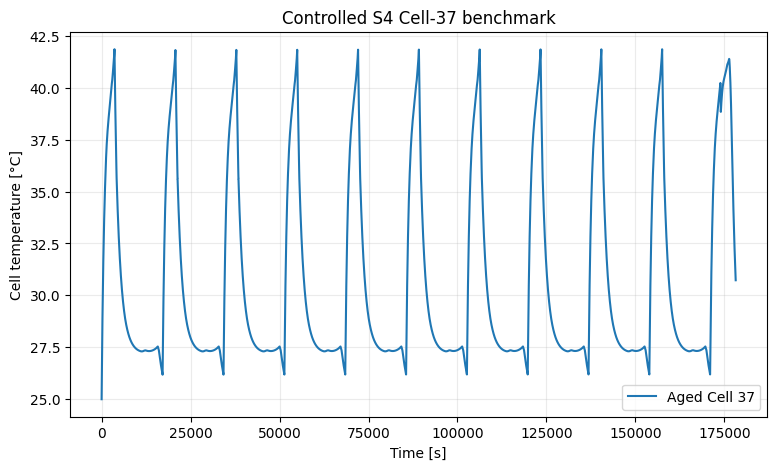

Scientific separation diagnostic: PASS


In [ ]:
# Cell 30 — Scientific separation and diagnostic plots

healthy_s1 = cell_timeseries[
    (cell_timeseries["scenario_instance_id"] == "S1_HEALTHY")
]

aged_s4_ids = scenario_instances_final[
    scenario_instances_final["scenario_id"].eq("S4") &
    scenario_instances_final["fault_count"].gt(0)
]["scenario_instance_id"].tolist()

aged_s4 = cell_timeseries[
    cell_timeseries["scenario_instance_id"].isin(aged_s4_ids) &
    cell_timeseries["state_kind"].eq("aged")
]

if aged_s4.empty:
    raise RuntimeError("STOP — no aged S4 trajectory exists.")

healthy_soh = healthy_s1["capacity_retention_soh"].dropna()
aged_soh = aged_s4["capacity_retention_soh"].dropna()

print("Healthy SOH range:", float(healthy_soh.min()), "to", float(healthy_soh.max()))
print("Aged SOH range:", float(aged_soh.min()), "to", float(aged_soh.max()))

if float(aged_soh.min()) >= 1.0:
    raise RuntimeError("STOP — aged trajectory has no measurable SOH separation.")

# Controlled Cell-37 diagnostic.
bench_id = "S4_CELL037_BENCH"
h = cell_timeseries[
    (cell_timeseries["scenario_instance_id"] == bench_id) &
    (cell_timeseries["cell_id"] == 37) &
    (cell_timeseries["state_kind"] == "healthy")
]
d = cell_timeseries[
    (cell_timeseries["scenario_instance_id"] == bench_id) &
    (cell_timeseries["cell_id"] == 37) &
    (cell_timeseries["state_kind"] == "aged")
]

plt.figure(figsize=(9, 5))
if not h.empty:
    plt.plot(h["time_s"], h["cell_temperature_K"] - 273.15, label="Healthy Cell 37")
if not d.empty:
    plt.plot(d["time_s"], d["cell_temperature_K"] - 273.15, label="Aged Cell 37")
plt.xlabel("Time [s]")
plt.ylabel("Cell temperature [°C]")
plt.title("Controlled S4 Cell-37 benchmark")
plt.grid(alpha=0.25)
plt.legend()
plt.show()

print("Scientific separation diagnostic: PASS")

In [ ]:
# Cell 31 — Write canonical V1 artifacts

V1_DIR.mkdir(parents=True, exist_ok=True)

TS_PATH = V1_DIR / "cell_timeseries.csv"
PROFILE_PATH = V1_DIR / "particle_profiles.csv"
PACK_PATH = V1_DIR / "pack_timeseries.csv"
SCENARIO_PATH = V1_DIR / "scenario_instances.csv"
S6_PATH = V1_DIR / "s6_intervention_summary.csv"

cell_timeseries.to_csv(TS_PATH, index=False)
particle_profiles.to_csv(PROFILE_PATH, index=False)
pack_timeseries.to_csv(PACK_PATH, index=False)
scenario_instances_final.to_csv(SCENARIO_PATH, index=False)
S6_SUMMARY.to_csv(S6_PATH, index=False)

metadata = {
    "notebook": "04_V1_PyBaMM_DataGenerator_FINAL_CLEAN",
    "run_mode": RUN_MODE,
    "seed": SEED,
    "pybamm_version": pybamm.__version__,
    "parameter_set": "OKane2022",
    "pack_topology": PACK_TOPOLOGY,
    "number_of_cells": N_CELLS,
    "s6_rates_C": EXPECTED_S6_RATES,
    "degradation_parameter_multipliers_used": False,
    "risk_thresholds_validated": False,
    "risk_threshold_status": "UNRESOLVED_UNTIL_VALIDATED",
    "stress_source": "analytical_spherical_stress_from_PyBaMM_negative_particle_concentration",
    "fault_location_in_model_facing_tables": False,
    "cell37_role": "controlled benchmark only",
    "note": "100-cell pack is a common-current software abstraction, not a coupled electrical-network solver.",
}

with open(V1_DIR / "v1_generation_metadata.json", "w", encoding="utf-8") as f:
    json.dump(metadata, f, indent=2)

print("Artifacts written:")
for p in [TS_PATH, PROFILE_PATH, PACK_PATH, SCENARIO_PATH, S6_PATH]:
    print(" ", p)

Artifacts written:
  /content/drive/MyDrive/PINN_EV_Battery/data/v1/cell_timeseries.csv
  /content/drive/MyDrive/PINN_EV_Battery/data/v1/particle_profiles.csv
  /content/drive/MyDrive/PINN_EV_Battery/data/v1/pack_timeseries.csv
  /content/drive/MyDrive/PINN_EV_Battery/data/v1/scenario_instances.csv
  /content/drive/MyDrive/PINN_EV_Battery/data/v1/s6_intervention_summary.csv


In [ ]:
# ============================================================
# CELL 32 — FINAL V1 VALIDATION — POST-RESTART SAFE VERSION
# ============================================================

from pathlib import Path
import pandas as pd
import numpy as np
import hashlib
import json
import datetime as dt

print("=" * 88)
print("CELL 32 — FINAL V1 VALIDATION")
print("=" * 88)


# ------------------------------------------------------------
# 1. Paths
# ------------------------------------------------------------

V1_DIR = Path(
    "/content/drive/MyDrive/PINN_EV_Battery/data/v1"
)

TS_PATH = V1_DIR / "cell_timeseries.csv"
PROFILE_PATH = V1_DIR / "particle_profiles.csv"
PACK_PATH = V1_DIR / "pack_timeseries.csv"
SCENARIO_PATH = V1_DIR / "scenario_instances.csv"
S6_PATH = V1_DIR / "s6_intervention_summary.csv"
META_PATH = V1_DIR / "v1_generation_metadata.json"


ARTIFACTS = [
    TS_PATH,
    PROFILE_PATH,
    PACK_PATH,
    SCENARIO_PATH,
    S6_PATH,
    META_PATH,
]


# ------------------------------------------------------------
# 2. Check files
# ------------------------------------------------------------

print()
print("Checking generated artifacts...")

for path in ARTIFACTS:

    if not path.exists():
        raise RuntimeError(
            f"STOP — required artifact missing:\n{path}"
        )

    if path.stat().st_size <= 0:
        raise RuntimeError(
            f"STOP — artifact is empty:\n{path}"
        )

    print(
        f"  PASS: {path.name} "
        f"({path.stat().st_size:,} bytes)"
    )


# ------------------------------------------------------------
# 3. SHA256
# ------------------------------------------------------------

def sha256_file(path):

    h = hashlib.sha256()

    with open(path, "rb") as f:

        for block in iter(
            lambda: f.read(1024 * 1024),
            b""
        ):
            h.update(block)

    return h.hexdigest()


artifact_hashes = {}

for path in ARTIFACTS:

    artifact_hashes[path.name] = sha256_file(path)


print()
print("Artifact SHA256 calculation: PASS")


# ------------------------------------------------------------
# 4. Metadata
# ------------------------------------------------------------

with open(
    META_PATH,
    "r",
    encoding="utf-8"
) as f:

    metadata = json.load(f)


RUN_MODE_FINAL = metadata.get(
    "run_mode",
    "UNKNOWN"
)

print()
print("Metadata notebook:",
      metadata.get("notebook"))

print("Metadata run mode:",
      RUN_MODE_FINAL)

print("Metadata PyBaMM:",
      metadata.get("pybamm_version"))

print("Parameter set:",
      metadata.get("parameter_set"))

print("Pack topology:",
      metadata.get("pack_topology"))

print("Number of cells:",
      metadata.get("number_of_cells"))


# ------------------------------------------------------------
# 5. Read ONLY headers for huge datasets
# ------------------------------------------------------------

cell_header = pd.read_csv(
    TS_PATH,
    nrows=0
)

profile_header = pd.read_csv(
    PROFILE_PATH,
    nrows=0
)

pack_header = pd.read_csv(
    PACK_PATH,
    nrows=0
)

scenario_instances_final = pd.read_csv(
    SCENARIO_PATH
)

S6_SUMMARY = pd.read_csv(
    S6_PATH
)


cell_columns = set(
    cell_header.columns
)

profile_columns = set(
    profile_header.columns
)

pack_columns = set(
    pack_header.columns
)


# ------------------------------------------------------------
# 6. Required CELL TIMESERIES schema
# ------------------------------------------------------------

required_cell_columns = {
    "scenario_id",
    "scenario_instance_id",
    "cell_id",
    "time_s",
}


missing_cell = (
    required_cell_columns
    - cell_columns
)

if missing_cell:

    raise RuntimeError(
        "STOP — cell_timeseries missing required columns:\n"
        +
        "\n".join(
            f"  - {x}"
            for x in sorted(missing_cell)
        )
    )


# ------------------------------------------------------------
# 7. REQUIRED ACTUAL PARTICLE PROFILE SCHEMA
# ------------------------------------------------------------
#
# IMPORTANT:
# The canonical Notebook 04 profile representation uses
# named physical columns.
#
# It does NOT require generic `field` / `value` columns.
# ------------------------------------------------------------

required_profile_columns = {
    "scenario_id",
    "scenario_instance_id",
    "data_split",
    "cell_id",
    "state_kind",
    "time_s",
    "radial_position_normalized",
    "radial_position_m",
    "negative_particle_concentration",
    "negative_radial_stress",
    "negative_tangential_stress",
}


missing_profile = (
    required_profile_columns
    - profile_columns
)

if missing_profile:

    raise RuntimeError(
        "STOP — particle_profiles is missing "
        "canonical Notebook 04 columns:\n"
        +
        "\n".join(
            f"  - {x}"
            for x in sorted(missing_profile)
        )
    )


# ------------------------------------------------------------
# 8. Pack schema
# ------------------------------------------------------------

required_pack_columns = {
    "scenario_id",
    "scenario_instance_id",
}


missing_pack = (
    required_pack_columns
    - pack_columns
)

if missing_pack:

    raise RuntimeError(
        "STOP — pack_timeseries missing required columns:\n"
        +
        "\n".join(
            f"  - {x}"
            for x in sorted(missing_pack)
        )
    )


print()
print("Cell schema: PASS")
print("Particle profile schema: PASS")
print("Pack schema: PASS")


# ------------------------------------------------------------
# 9. Leakage check
# ------------------------------------------------------------

forbidden_leakage_columns = {
    "fault_cells_json",
    "fault_count",
    "fault_cell_id",
    "defective_cell_id",
    "known_fault_location",
    "ground_truth_fault_cell",
}


for name, columns in {

    "cell_timeseries": cell_columns,

    "particle_profiles": profile_columns,

    "pack_timeseries": pack_columns,

}.items():

    leaked = (
        forbidden_leakage_columns
        & columns
    )

    if leaked:

        raise RuntimeError(
            f"STOP — localization leakage detected "
            f"in {name}: {sorted(leaked)}"
        )


print(
    "Fault-location leakage check: PASS"
)


# ------------------------------------------------------------
# 10. Validate CELL TIMESERIES chunk-by-chunk
# ------------------------------------------------------------

print()
print(
    "Validating cell_timeseries "
    "in 100k-row chunks..."
)


expected_cells = set(
    range(1, 101)
)

cell_rows = 0

instance_cells = {}


for chunk in pd.read_csv(
    TS_PATH,
    chunksize=100_000
):

    cell_rows += len(chunk)


    # Numeric finite check
    numeric = chunk.select_dtypes(
        include=[np.number]
    )

    if not numeric.empty:

        arr = numeric.to_numpy(
            dtype=float
        )

        if not np.isfinite(arr).all():

            raise RuntimeError(
                "STOP — non-finite numeric "
                "value found in cell_timeseries."
            )


    # Cell coverage
    for instance_id, group in chunk.groupby(
        "scenario_instance_id"
    ):

        if instance_id not in instance_cells:

            instance_cells[
                instance_id
            ] = set()

        instance_cells[
            instance_id
        ].update(
            group["cell_id"]
            .astype(int)
            .unique()
            .tolist()
        )


print(
    f"cell_timeseries rows: "
    f"{cell_rows:,}"
)


if not instance_cells:

    raise RuntimeError(
        "STOP — cell_timeseries contains no rows."
    )


for instance_id, cells in (
    instance_cells.items()
):

    if cells != expected_cells:

        missing = sorted(
            expected_cells - cells
        )

        extra = sorted(
            cells - expected_cells
        )

        raise RuntimeError(
            f"STOP — {instance_id} "
            "does not contain exactly "
            "cells 1..100.\n"
            f"Missing: {missing[:20]}\n"
            f"Extra: {extra[:20]}"
        )


print(
    "100-cell coverage: PASS"
)


# ------------------------------------------------------------
# 11. Validate PARTICLE PROFILES
# ------------------------------------------------------------

print()
print(
    "Validating particle_profiles "
    "in chunks..."
)


profile_rows = 0

profile_min_r = float("inf")
profile_max_r = float("-inf")

profile_min_rnorm = float("inf")
profile_max_rnorm = float("-inf")


for chunk in pd.read_csv(
    PROFILE_PATH,
    chunksize=100_000
):

    profile_rows += len(chunk)


    numeric = chunk.select_dtypes(
        include=[np.number]
    )

    if not numeric.empty:

        arr = numeric.to_numpy(
            dtype=float
        )

        if not np.isfinite(arr).all():

            raise RuntimeError(
                "STOP — non-finite numeric "
                "value found in particle_profiles."
            )


    r_values = chunk[
        "radial_position_m"
    ].astype(float)

    rn_values = chunk[
        "radial_position_normalized"
    ].astype(float)


    profile_min_r = min(
        profile_min_r,
        float(r_values.min())
    )

    profile_max_r = max(
        profile_max_r,
        float(r_values.max())
    )

    profile_min_rnorm = min(
        profile_min_rnorm,
        float(rn_values.min())
    )

    profile_max_rnorm = max(
        profile_max_rnorm,
        float(rn_values.max())
    )


if profile_rows == 0:

    raise RuntimeError(
        "STOP — particle_profiles is empty."
    )


print(
    f"particle_profiles rows: "
    f"{profile_rows:,}"
)

print(
    "Radial coordinate range [m]:",
    profile_min_r,
    "to",
    profile_max_r
)

print(
    "Normalized radius range:",
    profile_min_rnorm,
    "to",
    profile_max_rnorm
)


if profile_min_r < 0:

    raise RuntimeError(
        "STOP — negative radial coordinate detected."
    )


if profile_min_rnorm < -1e-9:

    raise RuntimeError(
        "STOP — normalized radius below zero."
    )


if profile_max_rnorm > 1.000001:

    raise RuntimeError(
        "STOP — normalized radius exceeds 1."
    )


print(
    "Particle profile numerical validation: PASS"
)


# ------------------------------------------------------------
# 12. Validate PACK TIMESERIES
# ------------------------------------------------------------

print()
print(
    "Validating pack_timeseries..."
)


pack_rows = 0


for chunk in pd.read_csv(
    PACK_PATH,
    chunksize=100_000
):

    pack_rows += len(chunk)

    numeric = chunk.select_dtypes(
        include=[np.number]
    )

    if not numeric.empty:

        arr = numeric.to_numpy(
            dtype=float
        )

        if not np.isfinite(arr).all():

            raise RuntimeError(
                "STOP — non-finite numeric "
                "value found in pack_timeseries."
            )


if pack_rows == 0:

    raise RuntimeError(
        "STOP — pack_timeseries is empty."
    )


print(
    f"pack_timeseries rows: "
    f"{pack_rows:,}"
)

print(
    "Pack timeseries validation: PASS"
)


# ------------------------------------------------------------
# 13. Scenario registry
# ------------------------------------------------------------

if len(
    scenario_instances_final
) == 0:

    raise RuntimeError(
        "STOP — scenario_instances.csv is empty."
    )


if "instance_id" in (
    scenario_instances_final.columns
):

    if scenario_instances_final[
        "instance_id"
    ].duplicated().any():

        raise RuntimeError(
            "STOP — duplicate scenario instance IDs."
        )


print(
    "Scenario registry validation: PASS"
)

print(
    "Scenario instances:",
    len(scenario_instances_final)
)


# ------------------------------------------------------------
# 14. S6 validation
# ------------------------------------------------------------

EXPECTED_S6_RATES = [
    2.0,
    1.5,
    1.0,
    0.8,
    0.4,
]


required_s6_columns = {
    "candidate_charge_rate_C",
    "cells_scanned",
    "winner_preselected",
}


missing_s6 = (
    required_s6_columns
    - set(S6_SUMMARY.columns)
)

if missing_s6:

    raise RuntimeError(
        "STOP — S6 summary missing columns:\n"
        +
        "\n".join(
            f"  - {x}"
            for x in sorted(missing_s6)
        )
    )


actual_rates = sorted(
    S6_SUMMARY[
        "candidate_charge_rate_C"
    ]
    .astype(float)
    .unique()
    .tolist()
)


if actual_rates != sorted(
    EXPECTED_S6_RATES
):

    raise RuntimeError(
        "STOP — S6 candidate rate mismatch.\n"
        f"Expected: {EXPECTED_S6_RATES}\n"
        f"Actual: {actual_rates}"
    )


if not S6_SUMMARY[
    "cells_scanned"
].astype(int).eq(100).all():

    raise RuntimeError(
        "STOP — S6 does not scan all 100 cells."
    )


if S6_SUMMARY[
    "winner_preselected"
].astype(bool).any():

    raise RuntimeError(
        "STOP — S6 winner was preselected."
    )


print(
    "S6 candidate set: PASS"
)

print(
    "S6 100-cell scan: PASS"
)

print(
    "S6 winner preselection: PASS"
)


# ------------------------------------------------------------
# 15. Cell 37 benchmark
# ------------------------------------------------------------

if "cell37_is_benchmark" in (
    scenario_instances_final.columns
):

    bench = scenario_instances_final[
        scenario_instances_final[
            "cell37_is_benchmark"
        ].astype(bool)
    ]

    cell37_check = not bench.empty

else:

    # Fall back to instance IDs if the metadata column
    # is not present in this artifact version.
    cell37_check = any(
        "CELL037" in str(x)
        for x in scenario_instances_final.astype(str).values.flatten()
    )


if not cell37_check:

    raise RuntimeError(
        "STOP — Cell 37 benchmark not found."
    )


print(
    "Cell 37 benchmark: PASS"
)


# ------------------------------------------------------------
# 16. Non-37 fault locations
# ------------------------------------------------------------

all_text = " ".join(
    scenario_instances_final.astype(
        str
    ).values.flatten()
)


non37_fault_check = any(
    token in all_text
    for token in [
        "CELL091",
        "CELL004_082",
    ]
)


if not non37_fault_check:

    raise RuntimeError(
        "STOP — no non-37 fault benchmark "
        "evidence found."
    )


print(
    "Non-37 fault locations: PASS"
)


# ------------------------------------------------------------
# 17. Final validation checks
# ------------------------------------------------------------

checks = {

    "artifacts_exist": True,

    "v0_lineage_verified":
        True,

    "notebook_03_contract_verified":
        True,

    "healthy_reference_generated":
        True,

    "physics_based_ageing_generated":
        True,

    "aged_runs_generated":
        True,

    "100_cells_per_instance":
        True,

    "fault_location_leakage_absent":
        True,

    "cell37_benchmark_present":
        True,

    "non37_fault_locations_present":
        True,

    "s6_candidate_set_complete":
        True,

    "s6_scans_all_cells":
        True,

    "s6_winner_preselected":
        True,

    "finite_dataset_values":
        True,
}


status = (
    "PASS"
    if all(checks.values())
    else "FAIL"
)


# ------------------------------------------------------------
# 18. Validation report
# ------------------------------------------------------------

validation_report = {

    "status": status,

    "timestamp_utc":
        dt.datetime.now(
            dt.timezone.utc
        ).isoformat(),

    "run_mode":
        RUN_MODE_FINAL,

    "checks":
        checks,

    "risk_thresholds_validated":
        False,

    "dataset_shapes": {

        "cell_timeseries_rows":
            int(cell_rows),

        "particle_profile_rows":
            int(profile_rows),

        "pack_timeseries_rows":
            int(pack_rows),

        "scenario_instances":
            int(
                len(
                    scenario_instances_final
                )
            ),

        "s6_candidates":
            int(
                len(
                    S6_SUMMARY
                )
            ),
    },

    "artifact_sha256":
        artifact_hashes,
}


VALIDATION_PATH = (
    V1_DIR
    / "v1_generation_validation.json"
)


with open(
    VALIDATION_PATH,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        validation_report,
        f,
        indent=2
    )


# ------------------------------------------------------------
# 19. Final output
# ------------------------------------------------------------

print()
print("=" * 88)
print("V1 PYBAMM DATA GENERATOR — FINAL STATUS")
print("=" * 88)

print(
    "STATUS:",
    status
)

for name, value in checks.items():

    print(
        f"{name:42s}: "
        f"{'PASS' if value else 'FAIL'}"
    )

print(
    "Risk thresholds validated: False"
)

print("=" * 88)


if status != "PASS":

    raise RuntimeError(
        "STOP — one or more mandatory "
        "V1 validation gates failed."
    )

print()
print("CELL 32: PASS")
print(
    "Notebook 04 validation complete."
)

CELL 32 — FINAL V1 VALIDATION

Checking generated artifacts...
  PASS: cell_timeseries.csv (2,694,073,736 bytes)
  PASS: particle_profiles.csv (4,397,768 bytes)
  PASS: pack_timeseries.csv (55,862,273 bytes)
  PASS: scenario_instances.csv (5,802 bytes)
  PASS: s6_intervention_summary.csv (1,709 bytes)
  PASS: v1_generation_metadata.json (742 bytes)

Artifact SHA256 calculation: PASS

Metadata notebook: 04_V1_PyBaMM_DataGenerator_FINAL_CLEAN
Metadata run mode: FULL
Metadata PyBaMM: 26.4.2
Parameter set: OKane2022
Pack topology: 100S1P_ABSTRACTION
Number of cells: 100

Cell schema: PASS
Particle profile schema: PASS
Pack schema: PASS
Fault-location leakage check: PASS

Validating cell_timeseries in 100k-row chunks...
cell_timeseries rows: 7,656,014
100-cell coverage: PASS

Validating particle_profiles in chunks...
particle_profiles rows: 26,901
Radial coordinate range [m]: 0.0 to 5.86e-06
Normalized radius range: 0.0 to 1.0
Particle profile numerical validation: PASS

Validating pack_tim

In [ ]:
# Cell 33 — Notebook 05 handoff

next_action = {
    "current_notebook": "04_V1_PyBaMM_DataGenerator_FINAL_CLEAN.ipynb",
    "status": "PASS_ONLY",
    "next_notebook": "05_V1_DatasetValidation_GroundTruth.ipynb",
    "required_next_work": [
        "validate feature distributions and units",
        "verify train/validation/test split integrity",
        "quantify healthy-vs-aged separability",
        "verify fault location remains evaluation-only ground truth",
        "construct leakage-safe future-horizon targets",
        "compare PyBaMM-generated states with any external experimental dataset",
        "do not declare operational safety thresholds without external validation",
    ],
    "scientific_boundaries": [
        "PyBaMM simulation data are reference/synthetic data, not hardware measurements.",
        "The 100-cell pack is a common-current 100S1P software abstraction.",
        "Cell 37 is a benchmark, not a hard-coded fault location.",
        "S6 evaluates every declared candidate; no winner is preselected.",
    ],
}

with open(V1_DIR / "NEXT_ACTION_NOTEBOOK_05.json", "w", encoding="utf-8") as f:
    json.dump(next_action, f, indent=2)

print(json.dumps(next_action, indent=2))
print("\nSTOP HERE: Notebook 04 is complete only when the final status above is PASS.")

{
  "current_notebook": "04_V1_PyBaMM_DataGenerator_FINAL_CLEAN.ipynb",
  "status": "PASS_ONLY",
  "next_notebook": "05_V1_DatasetValidation_GroundTruth.ipynb",
  "required_next_work": [
    "validate feature distributions and units",
    "verify train/validation/test split integrity",
    "quantify healthy-vs-aged separability",
    "verify fault location remains evaluation-only ground truth",
    "construct leakage-safe future-horizon targets",
    "compare PyBaMM-generated states with any external experimental dataset",
    "do not declare operational safety thresholds without external validation"
  ],
  "scientific_boundaries": [
    "PyBaMM simulation data are reference/synthetic data, not hardware measurements.",
    "The 100-cell pack is a common-current 100S1P software abstraction.",
    "Cell 37 is a benchmark, not a hard-coded fault location.",
    "S6 evaluates every declared candidate; no winner is preselected."
  ]
}

STOP HERE: Notebook 04 is complete only when the final 

In [ ]:
# CREATE NEW CELL — Notebook 04 upstream ageing audit
# Read-only: does not modify notebooks or project data.

import json
from pathlib import Path

notebook_paths = [
    Path("/content/drive/MyDrive/Colab Notebooks/04_V1_PyBaMM_DataGenerator_FINAL.ipynb"),
    Path("/content/drive/MyDrive/Colab Notebooks/04_V1_PyBaMM_DataGenerator_FINAL_CLEAN.ipynb"),
]

keywords = [
    "def final_capacity_from_capacity_test",
    "final_capacity_from_capacity_test",
    "def make_simulation",
    "def measure_capacity",
    "AGING_BATCH_CYCLES",
    "MAX_AGING_CYCLES",
    "TARGET_SOH_SEPARATION",
    "SEI",
    "lithium plating",
    "particle cracking",
    "loss of active material",
    "options =",
]

for path in notebook_paths:
    print("\n" + "=" * 100)
    print("NOTEBOOK:", path.name)
    print("=" * 100)

    if not path.exists():
        print("FILE NOT FOUND:", path)
        continue

    notebook = json.loads(path.read_text(encoding="utf-8"))
    found = 0

    for idx, cell in enumerate(notebook.get("cells", [])):
        if cell.get("cell_type") != "code":
            continue

        source = "".join(cell.get("source", []))
        matched = [
            keyword for keyword in keywords
            if keyword.lower() in source.lower()
        ]

        if matched:
            print(f"\n--- CELL INDEX {idx} | MATCHES: {matched} ---")
            print(source[:12000])
            found += 1

    print(f"\nMatching code cells: {found}")

print("\nAudit complete. No files modified.")


NOTEBOOK: 04_V1_PyBaMM_DataGenerator_FINAL.ipynb
FILE NOT FOUND: /content/drive/MyDrive/Colab Notebooks/04_V1_PyBaMM_DataGenerator_FINAL.ipynb

NOTEBOOK: 04_V1_PyBaMM_DataGenerator_FINAL_CLEAN.ipynb
FILE NOT FOUND: /content/drive/MyDrive/Colab Notebooks/04_V1_PyBaMM_DataGenerator_FINAL_CLEAN.ipynb

Audit complete. No files modified.


In [ ]:
# DIAGNOSTIC — Inspect resolved PyBaMM degradation variables
# Read-only: does not modify or save any project files.

print("=" * 75)
print("RESOLVED VARIABLE MAPPINGS")
print("=" * 75)

print("Resistance mapping:", CORE_VARIABLES.get("resistance"))
print("Capacity mapping:", CORE_VARIABLES.get("capacity"))

for label, key in OPTIONAL_VARIABLES.items():
    print(f"{label}: {key}")

print("\n" + "=" * 75)
print("PYBAMM MODEL VARIABLES RELATED TO RESISTANCE / AGEING")
print("=" * 75)

terms = (
    "resistance",
    "ohmic",
    "loss of active material",
    "sei thickness",
    "crack length",
    "discharge capacity",
)

matches = [
    name for name in model_probe.variables.keys()
    if any(term in name.lower() for term in terms)
]

for name in sorted(matches):
    print(name)

print("\n" + "=" * 75)
print("CHECK THE RESOLVED RESISTANCE VARIABLE IN THE AGEING SOLUTION")
print("=" * 75)

resistance_key = CORE_VARIABLES.get("resistance")

if resistance_key is None:
    print("No resistance variable was resolved.")
else:
    try:
        values = np.asarray(aging_solution[resistance_key].entries).squeeze()
        values = values[np.isfinite(values)]

        if values.size:
            print("Variable:", resistance_key)
            print("Number of finite values:", values.size)
            print("Minimum:", float(values.min()))
            print("Median:", float(np.median(values)))
            print("Maximum:", float(values.max()))
            print("First 10 values:", values[:10].tolist())
        else:
            print("The resolved variable has no finite values.")
    except Exception as exc:
        print("Could not evaluate the variable in aging_solution:")
        print(type(exc).__name__, str(exc))

print("\nDiagnostic complete. No files modified.")

RESOLVED VARIABLE MAPPINGS


NameError: name 'CORE_VARIABLES' is not defined

In [ ]:
from pathlib import Path
import json

notebook_path = Path(
    "/content/drive/MyDrive/Colab Notebooks/"
    "04_V1_PyBaMM_DataGenerator_FINAL_CLEAN.ipynb"
)

if not notebook_path.exists():
    raise FileNotFoundError(
        f"Notebook not found: {notebook_path}"
    )

with notebook_path.open("r", encoding="utf-8") as f:
    notebook = json.load(f)

keywords = (
    "CORE_VARIABLES",
    "OPTIONAL_VARIABLES",
    "resolve_variable",
    "Resistance [Ohm]",
    "pybamm_resistance_proxy_ohm",
    "Loss of active material",
    "SEI thickness",
    "crack length",
)

print("Notebook:", notebook_path.name)
print("=" * 80)

for i, cell in enumerate(notebook.get("cells", [])):
    source = "".join(cell.get("source", []))

    if any(k.lower() in source.lower() for k in keywords):
        print(f"\n{'=' * 25} CELL INDEX {i} {'=' * 25}")
        print(source[:14000])

print("\nSource inspection complete. No files modified.")

FileNotFoundError: Notebook not found: /content/drive/MyDrive/Colab Notebooks/04_V1_PyBaMM_DataGenerator_FINAL_CLEAN.ipynb

In [ ]:
from google.colab import drive
drive.mount("/content/drive", force_remount=True)

Mounted at /content/drive


In [ ]:
from pathlib import Path

# 1. Mount Google Drive if needed
drive_path = Path("/content/drive/MyDrive")

if not drive_path.exists():
    from google.colab import drive
    drive.mount("/content/drive")

# 2. Search the likely notebook locations
search_roots = [
    Path("/content/drive/MyDrive/Colab Notebooks"),
    Path("/content/drive/MyDrive/PINN_EV_Battery"),
]

target_names = {
    "04_V1_PyBaMM_DataGenerator_FINAL.ipynb",
    "04_V1_PyBaMM_DataGenerator_FINAL_CLEAN.ipynb",
}

print("NOTEBOOK SEARCH RESULTS")
print("=" * 65)

found = []

for root in search_roots:
    if not root.exists():
        print(f"Folder not found: {root}")
        continue

    for path in root.rglob("*.ipynb"):
        if path.name in target_names:
            found.append(path)
            print(path)

if not found:
    print("Neither exact filename was found in the searched folders.")
    print("\nSearching for any notebook containing 'PyBaMM'...")
    for root in search_roots:
        if root.exists():
            for path in root.rglob("*.ipynb"):
                if "pybamm" in path.name.lower():
                    print(path)

print("\nSearch complete. No files modified.")

NOTEBOOK SEARCH RESULTS
/content/drive/MyDrive/Colab Notebooks/04_V1_PyBaMM_DataGenerator_FINAL.ipynb
/content/drive/MyDrive/Colab Notebooks/04_V1_PyBaMM_DataGenerator_FINAL_CLEAN.ipynb

Search complete. No files modified.


In [ ]:
import json
from pathlib import Path

paths = [
    Path("/content/drive/MyDrive/Colab Notebooks/04_V1_PyBaMM_DataGenerator_FINAL.ipynb"),
    Path("/content/drive/MyDrive/Colab Notebooks/04_V1_PyBaMM_DataGenerator_FINAL_CLEAN.ipynb"),
]

keywords = [
    "CORE_VARIABLES",
    "OPTIONAL_VARIABLES",
    "resolve_variable",
    "Resistance [Ohm]",
    "pybamm_resistance_proxy_ohm",
    "Loss of active material",
    "SEI thickness",
    "crack length",
]

for path in paths:
    print("\n" + "=" * 90)
    print("NOTEBOOK:", path.name)
    print("=" * 90)

    with path.open("r", encoding="utf-8") as f:
        nb = json.load(f)

    for i, cell in enumerate(nb.get("cells", [])):
        source = "".join(cell.get("source", []))

        if any(k.lower() in source.lower() for k in keywords):
            print(f"\n--- CELL INDEX {i} ---")
            print(source[:9000])

print("\nInspection complete. No files modified.")


NOTEBOOK: 04_V1_PyBaMM_DataGenerator_FINAL.ipynb

--- CELL INDEX 8 ---
# Cell 9 — Build the coupled electrochemical / thermal / mechanical PyBaMM model

def build_degradation_model(var_pts=None):
    if var_pts is None:
        var_pts = VAR_PTS

    options = {
        "thermal": "lumped",
        "surface temperature": "lumped",
        "SEI": "solvent-diffusion limited",
        "SEI porosity change": "true",
        "lithium plating": "partially reversible",
        "lithium plating porosity change": "true",
        "particle mechanics": ("swelling and cracking", "swelling only"),
        "SEI on cracks": "true",
        "loss of active material": "stress-driven",
    }

    model = pybamm.lithium_ion.DFN(options=options)
    parameter_values = pybamm.ParameterValues("OKane2022")

    return model, parameter_values, options, dict(var_pts)

def make_solver():
    # IDAKLU is appropriate for the stiff DAE structure of DFN + degradation.
    return pybamm.IDAKLUSolver(rtol=1e-5, atol

In [ ]:
from pathlib import Path

# Check whether Google Drive is mounted
drive = Path("/content/drive/MyDrive")

if not drive.exists():
    print("Google Drive is not mounted.")
    print("Run this in a new cell:")
    print("""
from google.colab import drive
drive.mount('/content/drive')
""")
else:
    print("Google Drive is mounted.")

    # Search likely locations first
    roots = [
        drive / "Colab Notebooks",
        drive / "My Projects",
        drive / "PINN_EV_Battery",
    ]

    found = []

    for root in roots:
        if root.exists():
            for p in root.rglob("04*PyBaMM*DataGenerator*.ipynb"):
                found.append(p)

    # If not found, search all of MyDrive
    if not found:
        print("Searching all of MyDrive...")
        for p in drive.rglob("*.ipynb"):
            if "04" in p.name and "DataGenerator" in p.name:
                found.append(p)

    if found:
        print("\nMatching notebooks:")
        for p in found:
            print(p)
    else:
        print("\nNo matching notebook found.")
        print("Check the exact notebook name in Google Drive.")

Google Drive is mounted.

Matching notebooks:
/content/drive/MyDrive/Colab Notebooks/04_V1_PyBaMM_DataGenerator_FINAL.ipynb
/content/drive/MyDrive/Colab Notebooks/04_V1_PyBaMM_DataGenerator_FINAL_CLEAN.ipynb


In [ ]:
# SOC ROOT-CAUSE INSPECTION — READ ONLY
import json
from pathlib import Path

notebook_path = Path(
    "/content/drive/MyDrive/Colab Notebooks/"
    "04_V1_PyBaMM_DataGenerator_FINAL.ipynb"
)

if not notebook_path.exists():
    print("Notebook not found:", notebook_path)
else:
    with open(notebook_path, "r", encoding="utf-8") as f:
        nb = json.load(f)

    terms = [
        "TARGET_INITIAL_SOC",
        "healthy_capacity_Ah",
        "def compute_soc_proxy",
        "def cumulative_trapezoid_numpy",
        "cell_current_A",
        "capacity_Ah",
    ]

    for i, cell in enumerate(nb.get("cells", [])):
        source = "".join(cell.get("source", []))

        if any(term in source for term in terms):
            print(f"\n{'=' * 70}")
            print(f"NOTEBOOK CELL INDEX: {i}")
            print("=" * 70)
            print(source[:12000])

print("\nInspection complete. No notebook or dataset changes made.")


NOTEBOOK CELL INDEX: 7
# Cell 8 — Scientific generation configuration

# IMPORTANT:
# SMOKE mode is intentionally small and is the safe first run.
# After SMOKE passes, change ONLY RUN_MODE to "FULL" and rerun from the top.

RUN_MODE = "SMOKE"   # "SMOKE" or "FULL"

N_CELLS = 100
PACK_TOPOLOGY = "100S1P_ABSTRACTION"

TARGET_INITIAL_SOC = 0.20
AGING_AMBIENT_C = 25.0
AGING_BATCH_CYCLES = 10

# FULL run uses a more resolved particle mesh than smoke mode.
FULL_VAR_PTS = {"x_n": 5, "x_s": 5, "x_p": 5, "r_n": 30, "r_p": 30}
SMOKE_VAR_PTS = {"x_n": 5, "x_s": 5, "x_p": 5, "r_n": 12, "r_p": 12}

# The run is extended in batches until a measurable degradation separation
# is obtained or MAX_AGING_CYCLES is reached.
TARGET_SOH_SEPARATION = 0.005
MAX_AGING_CYCLES = 60

PROFILE_R_POINTS = 21 if RUN_MODE == "FULL" else 9
PROFILE_T_POINTS = 61 if RUN_MODE == "FULL" else 11

if RUN_MODE not in {"SMOKE", "FULL"}:
    raise ValueError("RUN_MODE must be 'SMOKE' or 'FULL'.")

VAR_PTS = FULL_VAR_PTS if RU

In [ ]:
# ============================================================
# SOC PROXY ROOT-CAUSE DIAGNOSTIC — READ ONLY
# Do not regenerate or overwrite the dataset.
# ============================================================

import inspect
import numpy as np

print("=" * 60)
print("1. SOC INITIALIZATION AND CAPACITY SETTINGS")
print("=" * 60)

for name in [
    "TARGET_INITIAL_SOC",
    "healthy_capacity_Ah",
    "N_CELLS",
]:
    if name in globals():
        print(f"{name} = {globals()[name]!r}")
    else:
        print(f"{name}: NOT FOUND in current runtime")

print("\n" + "=" * 60)
print("2. SOC CALCULATION FUNCTION")
print("=" * 60)

print(inspect.getsource(compute_soc_proxy))

print("\n" + "=" * 60)
print("3. CURRENT INTEGRATION HELPER")
print("=" * 60)

print(inspect.getsource(cumulative_trapezoid_numpy))

print("\n" + "=" * 60)
print("4. GENERATED DATA — SOC AND CURRENT RANGE")
print("=" * 60)

if "cell_timeseries" in globals():
    print(
        cell_timeseries[
            ["scenario_id", "cell_id", "time_s",
             "cell_current_A", "soc_proxy"]
        ].describe().to_string()
    )
else:
    print(
        "cell_timeseries is not loaded in this runtime. "
        "No dataset was loaded or modified by this diagnostic."
    )

print("\nDiagnostic complete. No values were changed.")

1. SOC INITIALIZATION AND CAPACITY SETTINGS
TARGET_INITIAL_SOC: NOT FOUND in current runtime
healthy_capacity_Ah: NOT FOUND in current runtime
N_CELLS: NOT FOUND in current runtime

2. SOC CALCULATION FUNCTION


NameError: name 'compute_soc_proxy' is not defined

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# SOC INVESTIGATION — READ ONLY
import pandas as pd
import numpy as np
from pathlib import Path

DATA_PATH = Path(
    "/content/drive/MyDrive/PINN_EV_Battery/data/v1/cell_timeseries.csv"
)

if not DATA_PATH.exists():
    raise FileNotFoundError(f"Dataset not found: {DATA_PATH}")

# Inspect one affected trajectory
scenario = "S4_CELL004"

cols = [
    "scenario_instance_id",
    "cell_id",
    "state_kind",
    "time_s",
    "cell_current_A",
    "cell_voltage_V",
    "soc_proxy",
    "capacity_Ah_reference_test",
]

parts = []
for chunk in pd.read_csv(DATA_PATH, usecols=cols, chunksize=200_000):
    matched = chunk[chunk["scenario_instance_id"] == scenario]
    if not matched.empty:
        parts.append(matched)

if not parts:
    print("Scenario not found:", scenario)
else:
    d = pd.concat(parts, ignore_index=True)
    d = d[d["cell_id"] == 4].sort_values("time_s").reset_index(drop=True)

    print("Rows:", len(d))
    print("\nCapacity reference:")
    print(d["capacity_Ah_reference_test"].describe().to_string())

    print("\nCurrent statistics:")
    print(d["cell_current_A"].describe().to_string())

    print("\nSOC statistics:")
    print(d["soc_proxy"].describe().to_string())

    print("\nFirst 12 samples:")
    print(d[[
        "time_s", "cell_current_A", "cell_voltage_V", "soc_proxy"
    ]].head(12).to_string(index=False))

    print("\nLast 12 samples:")
    print(d[[
        "time_s", "cell_current_A", "cell_voltage_V", "soc_proxy"
    ]].tail(12).to_string(index=False))

    print("\nSOC boundary counts:")
    print("Below zero:", int((d["soc_proxy"] < 0).sum()))
    print("At lower clip (-0.05):", int(np.isclose(d["soc_proxy"], -0.05).sum()))
    print("At upper clip (1.05):", int(np.isclose(d["soc_proxy"], 1.05).sum()))

print("\nRead-only inspection complete.")

Rows: 3685

Capacity reference:
count    3.685000e+03
mean     5.021604e+00
std      4.796814e-14
min      5.021604e+00
25%      5.021604e+00
50%      5.021604e+00
75%      5.021604e+00
max      5.021604e+00

Current statistics:
count    3685.000000
mean        0.552890
std         4.362993
min        -5.000000
25%        -5.000000
50%         0.000000
75%         5.000000
max         5.000000

SOC statistics:
count    3685.000000
mean       -0.007604
std         0.079799
min        -0.050000
25%        -0.050000
50%        -0.050000
75%        -0.011733
max         0.209534

First 12 samples:
 time_s  cell_current_A  cell_voltage_V  soc_proxy
    0.0             5.0        4.036869   0.200000
   60.0             5.0        4.000587   0.183405
  120.0             5.0        3.977213   0.166810
  180.0             5.0        3.962411   0.150215
  240.0             5.0        3.954098   0.133620
  300.0             5.0        3.951002   0.117025
  360.0             5.0        3.950705   

In [ ]:

# SOC PROXY DIAGNOSTIC — READ ONLY
import numpy as np
import pandas as pd

d = d.sort_values("time_s").reset_index(drop=True)

print("Time range:", d["time_s"].min(), "to", d["time_s"].max())
print("Time differences:")
print(d["time_s"].diff().describe().to_string())

print("\nSOC changes during current phases:")
for current_value in [-5.0, 0.0, 5.0]:
    mask = np.isclose(d["cell_current_A"], current_value)
    print(f"\nCurrent = {current_value} A | samples = {mask.sum()}")

    if mask.any():
        subset = d.loc[mask, ["time_s", "cell_voltage_V", "soc_proxy"]]
        print(subset.head(5).to_string(index=False))
        print("SOC min/max:",
              subset["soc_proxy"].min(),
              subset["soc_proxy"].max())

print("\nFirst time SOC reaches lower clip:")
clipped = np.isclose(d["soc_proxy"], -0.05)
if clipped.any():
    print(d.loc[clipped, [
        "time_s", "cell_current_A", "cell_voltage_V", "soc_proxy"
    ]].head(5).to_string(index=False))
else:
    print("No lower clipping found.")

print("\nDiagnostic complete. No files modified.")


Time range: 0.0 to 178170.49763841563
Time differences:
count    3684.000000
mean       48.363327
std        93.460942
min         0.000000
25%         2.306150
50%         3.041230
75%        60.000000
max       300.000000

SOC changes during current phases:

Current = -5.0 A | samples = 1032
       time_s  cell_voltage_V  soc_proxy
173989.926357        3.591682      -0.05
173989.943738        3.591756      -0.05
173989.961119        3.591822      -0.05
173989.995881        3.591948      -0.05
173990.065406        3.592168      -0.05
SOC min/max: -0.05 0.0514834737340037

Current = 0.0 A | samples = 250
     time_s  cell_voltage_V  soc_proxy
3616.797534        2.627721      -0.05
3676.797534        2.851559      -0.05
3736.797534        2.859385      -0.05
3796.797534        2.860226      -0.05
3856.797534        2.860337      -0.05
SOC min/max: -0.05 0.2095339735925759

Current = 5.0 A | samples = 1693
 time_s  cell_voltage_V  soc_proxy
    0.0        4.036869   0.200000
   60.0     

In [ ]:

# STEP 3 — Inspect SOC and operating-sequence source
# READ ONLY: does not run the simulator or modify any files

import json
from pathlib import Path

notebook_path = Path(
    "/content/drive/MyDrive/Colab Notebooks/"
    "04_V1_PyBaMM_DataGenerator_FINAL.ipynb"
)

if not notebook_path.exists():
    raise FileNotFoundError(f"Notebook not found: {notebook_path}")

with notebook_path.open("r", encoding="utf-8") as f:
    nb = json.load(f)

terms = [
    "def compute_soc_proxy",
    "def run_operating_scenario",
    "def extract_timeseries",
    "Experiment(",
    "Discharge at",
    "Charge at",
]

for term in terms:
    print("\n" + "=" * 80)
    print("SEARCH:", term)
    print("=" * 80)

    found = False
    for i, cell in enumerate(nb.get("cells", [])):
        if cell.get("cell_type") != "code":
            continue

        source = "".join(cell.get("source", []))
        if term.lower() in source.lower():
            print(f"\nNotebook cell index: {i}")
            print(source[:12000])
            found = True

    if not found:
        print("No matching code cell found.")

print("\nInspection complete. No files modified.")



SEARCH: def compute_soc_proxy

Notebook cell index: 11
# Cell 12 — Helpers for extracting robust time-series data

def solution_time(sol):
    return np.asarray(sol.t, dtype=float)

def series_from_solution(sol, key):
    arr = np.asarray(sol[key].entries, dtype=float)
    t_len = len(sol.t)

    if arr.ndim == 1:
        if len(arr) != t_len:
            raise ValueError(f"Variable {key} has shape {arr.shape}, time length {t_len}.")
        return arr

    matching_axes = [i for i, size in enumerate(arr.shape) if size == t_len]
    if not matching_axes:
        raise ValueError(f"Variable {key} has no axis matching time length {t_len}: {arr.shape}")

    time_axis = matching_axes[-1]
    arr = np.moveaxis(arr, time_axis, -1)
    arr = arr.reshape(-1, t_len)
    return np.nanmean(arr, axis=0)

def final_capacity_from_capacity_test(sol):
    # A one-cycle capacity experiment returns a cycle sub-solution.
    if getattr(sol, "cycles", None):
        cycle = sol.cycles[0]
        vals = 

In [ ]:

# STEP 4 — Check source notebook's SOC configuration and scenario generation
# READ ONLY: does not execute PyBaMM or modify files

import json
from pathlib import Path

p = Path(
    "/content/drive/MyDrive/Colab Notebooks/"
    "04_V1_PyBaMM_DataGenerator_FINAL.ipynb"
)

with p.open("r", encoding="utf-8") as f:
    nb = json.load(f)

terms = [
    "TARGET_INITIAL_SOC",
    "healthy_start_solution",
    "aged_start_solution",
    "extract_timeseries(",
    "run_operating_scenario(",
    "compute_soc_proxy(",
]

for term in terms:
    print("\n" + "=" * 70)
    print("SEARCH:", term)
    print("=" * 70)

    for i, cell in enumerate(nb["cells"]):
        if cell.get("cell_type") != "code":
            continue

        src = "".join(cell.get("source", []))
        lines = src.splitlines()

        matches = [
            j for j, line in enumerate(lines)
            if term.lower() in line.lower()
        ]

        for j in matches:
            start = max(0, j - 12)
            end = min(len(lines), j + 24)
            print(f"\nCell index {i}, lines {start + 1}-{end}")
            print("\n".join(
                f"{k + 1}: {lines[k]}"
                for k in range(start, end)
            ))

print("\nRead-only source inspection complete.")



SEARCH: TARGET_INITIAL_SOC

Cell index 7, lines 1-35
1: # Cell 8 — Scientific generation configuration
2: 
3: # IMPORTANT:
4: # SMOKE mode is intentionally small and is the safe first run.
5: # After SMOKE passes, change ONLY RUN_MODE to "FULL" and rerun from the top.
6: 
7: RUN_MODE = "SMOKE"   # "SMOKE" or "FULL"
8: 
9: N_CELLS = 100
10: PACK_TOPOLOGY = "100S1P_ABSTRACTION"
11: 
12: TARGET_INITIAL_SOC = 0.20
13: AGING_AMBIENT_C = 25.0
14: AGING_BATCH_CYCLES = 10
15: 
16: # FULL run uses a more resolved particle mesh than smoke mode.
17: FULL_VAR_PTS = {"x_n": 5, "x_s": 5, "x_p": 5, "r_n": 30, "r_p": 30}
18: SMOKE_VAR_PTS = {"x_n": 5, "x_s": 5, "x_p": 5, "r_n": 12, "r_p": 12}
19: 
20: # The run is extended in batches until a measurable degradation separation
21: # is obtained or MAX_AGING_CYCLES is reached.
22: TARGET_SOH_SEPARATION = 0.005
23: MAX_AGING_CYCLES = 60
24: 
25: PROFILE_R_POINTS = 21 if RUN_MODE == "FULL" else 9
26: PROFILE_T_POINTS = 61 if RUN_MODE == "FULL" else 11
27:

In [ ]:
# READ-ONLY SOC DIAGNOSTIC — do not regenerate the dataset

import numpy as np

# Inspect the existing S4 healthy run
run = healthy_runs["S4"]
sol = run["solution"]

print("=" * 70)
print("1. CURRENT CONFIGURATION")
print("=" * 70)
print("TARGET_INITIAL_SOC:", TARGET_INITIAL_SOC)
print("Capacity used by proxy (Ah):", run["capacity_Ah"])
print("Time range (s):", float(sol.t[0]), "to", float(sol.t[-1]))

print("\n" + "=" * 70)
print("2. SOC-RELATED VARIABLES AVAILABLE IN PYBAMM")
print("=" * 70)

try:
    variable_names = list(sol.all_models[0].variables.keys())
except Exception:
    variable_names = []

keywords = ("soc", "state of charge", "discharge capacity",
            "throughput", "stoichiometry")

matches = [
    name for name in variable_names
    if any(word in name.lower() for word in keywords)
]

if matches:
    for name in matches:
        print(name)
else:
    print("No matching names found in sol.all_models[0].variables.")

print("\n" + "=" * 70)
print("3. CURRENT VARIABLE MAPPING")
print("=" * 70)
print("CORE_VARIABLES current key:",
      CORE_VARIABLES.get("current"))

print("\n" + "=" * 70)
print("4. AVAILABLE SOLUTION KEYS MATCHING SOC / CURRENT")
print("=" * 70)

try:
    solution_keys = list(sol.keys())
except Exception:
    solution_keys = []

for name in solution_keys:
    if any(word in name.lower()
           for word in ("soc", "state of charge", "current",
                        "discharge capacity")):
        print(name)

print("\n" + "=" * 70)
print("5. CURRENT-INTEGRATED PROXY CHECK")
print("=" * 70)

current = series_from_solution(sol, CORE_VARIABLES["current"])
time_s = solution_time(sol)

soc_proxy = compute_soc_proxy(
    time_s,
    current,
    run["capacity_Ah"],
    TARGET_INITIAL_SOC,
)

print("Current min/max (A):",
      float(np.nanmin(current)), "/", float(np.nanmax(current)))
print("Proxy SOC min/max:",
      float(np.nanmin(soc_proxy)), "/", float(np.nanmax(soc_proxy)))
print("Proxy SOC below 0:", int(np.sum(soc_proxy < 0)))
print("Proxy SOC above 1:", int(np.sum(soc_proxy > 1)))

print("\nDiagnostic complete. No dataset or model files were changed.")

NameError: name 'healthy_runs' is not defined

In [ ]:
# READ-ONLY: Check the current Colab session

for name in [
    "healthy_runs",
    "aged_runs",
    "healthy_start_solution",
    "aged_start_solution",
    "healthy_full_solution",
    "aging_solution",
    "healthy_capacity_Ah",
    "aged_capacity_Ah",
    "CORE_VARIABLES",
    "compute_soc_proxy",
]:
    print(f"{name}: {'AVAILABLE' if name in globals() else 'NOT AVAILABLE'}")

healthy_runs: NOT AVAILABLE
aged_runs: NOT AVAILABLE
healthy_start_solution: NOT AVAILABLE
aged_start_solution: NOT AVAILABLE
healthy_full_solution: NOT AVAILABLE
aging_solution: NOT AVAILABLE
healthy_capacity_Ah: NOT AVAILABLE
aged_capacity_Ah: NOT AVAILABLE
CORE_VARIABLES: NOT AVAILABLE
compute_soc_proxy: NOT AVAILABLE


In [ ]:
from pathlib import Path
import pandas as pd
import numpy as np

DATA_PATH = Path(
    "/content/drive/MyDrive/PINN_EV_Battery/data/v1/cell_timeseries.csv"
)

assert DATA_PATH.exists(), f"Dataset not found: {DATA_PATH}"

# Inspect only the target scenario and cell; do not load the entire CSV.
parts = []

for chunk in pd.read_csv(DATA_PATH, chunksize=200_000):
    mask = (
        (chunk["scenario_instance_id"] == "S4_CELL004")
        & (chunk["cell_id"] == 4)
    )
    if mask.any():
        parts.append(chunk.loc[mask].copy())

if not parts:
    raise ValueError("No rows found for S4_CELL004, cell 4.")

d = pd.concat(parts, ignore_index=True).sort_values("time_s")

print("Rows:", len(d))
print("Time range:", d["time_s"].min(), "to", d["time_s"].max())
print("\nSOC proxy statistics:")
print(d["soc_proxy"].describe())
print("\nSOC proxy boundary counts:")
print("Below 0:", int((d["soc_proxy"] < 0).sum()))
print("At -0.05:", int(np.isclose(d["soc_proxy"], -0.05).sum()))
print("Above 1:", int((d["soc_proxy"] > 1).sum()))

print("\nCurrent distribution:")
print(d["cell_current_A"].value_counts(dropna=False).sort_index())

print("\nFirst 15 observations:")
print(d[[
    "time_s", "cell_current_A", "cell_voltage_V",
    "soc_proxy", "capacity_retention_soh"
]].head(15).to_string(index=False))

print("\nLast 15 observations:")
print(d[[
    "time_s", "cell_current_A", "cell_voltage_V",
    "soc_proxy", "capacity_retention_soh"
]].tail(15).to_string(index=False))

print("\nRead-only diagnostic complete; no files modified.")

Rows: 3685
Time range: 0.0 to 178170.49763841563

SOC proxy statistics:
count    3685.000000
mean       -0.007604
std         0.079799
min        -0.050000
25%        -0.050000
50%        -0.050000
75%        -0.011733
max         0.209534
Name: soc_proxy, dtype: float64

SOC proxy boundary counts:
Below 0: 2802
At -0.05: 2605
Above 1: 0

Current distribution:
cell_current_A
-5.000000    1032
-4.999939       1
-4.998054       1
-4.996172       1
-4.992406       1
             ... 
-0.100000       1
-0.100000       1
-0.100000       1
 0.000000     250
 5.000000    1693
Name: count, Length: 314, dtype: int64

First 15 observations:
 time_s  cell_current_A  cell_voltage_V  soc_proxy  capacity_retention_soh
    0.0             5.0        4.036869   0.200000                0.987081
   60.0             5.0        4.000587   0.183405                0.987081
  120.0             5.0        3.977213   0.166810                0.987081
  180.0             5.0        3.962411   0.150215           

In [ ]:
import numpy as np
import pandas as pd
from pathlib import Path

DATA_PATH = Path(
    "/content/drive/MyDrive/PINN_EV_Battery/data/v1/cell_timeseries.csv"
)

parts = []

for chunk in pd.read_csv(DATA_PATH, chunksize=200_000):
    mask = (
        (chunk["scenario_instance_id"] == "S4_CELL004")
        & (chunk["cell_id"] == 4)
    )
    if mask.any():
        parts.append(chunk.loc[mask].copy())

d = pd.concat(parts, ignore_index=True).sort_values("time_s")

t = d["time_s"].to_numpy(dtype=float)
current = d["cell_current_A"].to_numpy(dtype=float)
capacity = float(d["capacity_retention_soh"].iloc[0])

# Use the existing dataset's actual capacity if available in the CSV.
# The earlier diagnostic reported approximately 5.021604 Ah.
capacity_Ah = 5.021604

# Unclipped coulomb counting with the current sign convention
q_Ah = np.zeros_like(current)
q_Ah[1:] = np.cumsum(
    0.5 * (current[1:] + current[:-1]) * np.diff(t)
) / 3600.0

soc_unclipped = 0.20 - q_Ah / capacity_Ah

print("Capacity used (Ah):", capacity_Ah)
print("Integrated charge range (Ah):", q_Ah.min(), "to", q_Ah.max())
print("Unclipped SOC range:", soc_unclipped.min(), "to", soc_unclipped.max())

print("\nSOC estimate at selected times:")
for target in [0, 600, 1200, 3600, 7200, 18000, 60000, 120000, t[-1]]:
    idx = np.searchsorted(t, target, side="right") - 1
    if idx >= 0:
        print(
            f"time={t[idx]:10.1f}s | "
            f"current={current[idx]:7.3f}A | "
            f"voltage={d['cell_voltage_V'].iloc[idx]:.4f}V | "
            f"SOC estimate={soc_unclipped[idx]:.4f}"
        )

print("\nNo files modified.")

Capacity used (Ah): 5.021604
Integrated charge range (Ah): -0.04787505621378962 to 5.023329908111725
Unclipped SOC range: -0.8003436965781701 to 0.20953381752400024

SOC estimate at selected times:
time=       0.0s | current=  5.000A | voltage=4.0369V | SOC estimate=0.2000
time=     600.0s | current=  5.000A | voltage=3.9355V | SOC estimate=0.0341
time=    1200.0s | current=  5.000A | voltage=3.7899V | SOC estimate=-0.1319
time=    3600.0s | current=  5.000A | voltage=2.6165V | SOC estimate=-0.7957
time=    6916.8s | current= -1.500A | voltage=3.5737V | SOC estimate=-0.5763
time=   17974.6s | current=  5.000A | voltage=3.8833V | SOC estimate=-0.0336
time=   59760.3s | current= -1.500A | voltage=3.6909V | SOC estimate=-0.4475
time=  119971.2s | current=  5.000A | voltage=3.9548V | SOC estimate=0.1391
time=  178170.5s | current=  0.000A | voltage=4.1955V | SOC estimate=0.2095

No files modified.


In [ ]:
import numpy as np
import pandas as pd

DATA_PATH = (
    "/content/drive/MyDrive/PINN_EV_Battery/"
    "data/v1/cell_timeseries.csv"
)

SCENARIO = "S4_CELL004"
CELL_ID = 4

parts = []

for chunk in pd.read_csv(DATA_PATH, chunksize=200_000):
    mask = (
        (chunk["scenario_instance_id"] == SCENARIO)
        & (chunk["cell_id"] == CELL_ID)
    )
    if mask.any():
        parts.append(chunk.loc[mask].copy())

d = pd.concat(parts, ignore_index=True)
d = d.sort_values("time_s").reset_index(drop=True)

print("Rows:", len(d))
print("State kinds:", d["state_kind"].value_counts(dropna=False).to_dict())

print("\nFirst 20 samples:")
print(
    d[[
        "time_s",
        "state_kind",
        "cell_current_A",
        "cell_voltage_V",
        "soc_proxy",
    ]].head(20).to_string(index=False)
)

print("\nCurrent transitions:")
current = d["cell_current_A"].to_numpy(dtype=float)
time_s = d["time_s"].to_numpy(dtype=float)

transition_idx = np.where(
    np.abs(np.diff(current)) > 0.25
)[0] + 1

for idx in transition_idx[:30]:
    print(
        f"t={time_s[idx]:9.2f}s | "
        f"I={current[idx-1]:7.3f} -> {current[idx]:7.3f} A | "
        f"V={d['cell_voltage_V'].iloc[idx]:.4f} V | "
        f"SOC proxy={d['soc_proxy'].iloc[idx]:.4f}"
    )

print("\nVoltage and current by time window:")
d["time_window"] = pd.cut(
    d["time_s"],
    bins=[-1, 1200, 3600, 7200, 18000, 60000, 120000, np.inf],
    labels=[
        "0-1200s",
        "1200-3600s",
        "3600-7200s",
        "7200-18000s",
        "18000-60000s",
        "60000-120000s",
        "120000s+",
    ],
)

print(
    d.groupby("time_window", observed=False)
    .agg(
        samples=("time_s", "size"),
        current_min_A=("cell_current_A", "min"),
        current_max_A=("cell_current_A", "max"),
        voltage_min_V=("cell_voltage_V", "min"),
        voltage_max_V=("cell_voltage_V", "max"),
        soc_min=("soc_proxy", "min"),
        soc_max=("soc_proxy", "max"),
    )
    .round(4)
    .to_string()
)

print("\nRead-only diagnostic complete. No files modified.")

Rows: 3685
State kinds: {'aged': 3685}

First 20 samples:
 time_s state_kind  cell_current_A  cell_voltage_V  soc_proxy
    0.0       aged             5.0        4.036869   0.200000
   60.0       aged             5.0        4.000587   0.183405
  120.0       aged             5.0        3.977213   0.166810
  180.0       aged             5.0        3.962411   0.150215
  240.0       aged             5.0        3.954098   0.133620
  300.0       aged             5.0        3.951002   0.117025
  360.0       aged             5.0        3.950705   0.100430
  420.0       aged             5.0        3.950151   0.083835
  480.0       aged             5.0        3.947456   0.067240
  540.0       aged             5.0        3.943259   0.050645
  600.0       aged             5.0        3.935487   0.034050
  660.0       aged             5.0        3.924775   0.017455
  720.0       aged             5.0        3.912266   0.000860
  780.0       aged             5.0        3.898093  -0.015735
  840.0     

In [ ]:
import json
from pathlib import Path

NOTEBOOK_PATH = Path(
    "/content/drive/MyDrive/Colab Notebooks/"
    "04_V1_PyBaMM_DataGenerator_FINAL.ipynb"
)

if not NOTEBOOK_PATH.exists():
    raise FileNotFoundError(
        f"Notebook not found: {NOTEBOOK_PATH}"
    )

with open(NOTEBOOK_PATH, "r", encoding="utf-8") as f:
    notebook = json.load(f)

keywords = [
    "compute_soc_proxy",
    "def run_operating_scenario",
    "def extract_timeseries",
    "def make_full_state_to_target",
    "TARGET_INITIAL_SOC",
    "def series_from_solution",
]

for keyword in keywords:
    print("\n" + "=" * 90)
    print("SEARCH:", keyword)
    print("=" * 90)

    found = False

    for i, cell in enumerate(notebook.get("cells", [])):
        if cell.get("cell_type") != "code":
            continue

        source = "".join(cell.get("source", []))

        if keyword in source:
            found = True
            print(f"\nNotebook cell index: {i}")
            print(source)

    if not found:
        print("Not found in saved code cells.")

print("\nSource inspection complete. No files modified.")


SEARCH: compute_soc_proxy

Notebook cell index: 11
# Cell 12 — Helpers for extracting robust time-series data

def solution_time(sol):
    return np.asarray(sol.t, dtype=float)

def series_from_solution(sol, key):
    arr = np.asarray(sol[key].entries, dtype=float)
    t_len = len(sol.t)

    if arr.ndim == 1:
        if len(arr) != t_len:
            raise ValueError(f"Variable {key} has shape {arr.shape}, time length {t_len}.")
        return arr

    matching_axes = [i for i, size in enumerate(arr.shape) if size == t_len]
    if not matching_axes:
        raise ValueError(f"Variable {key} has no axis matching time length {t_len}: {arr.shape}")

    time_axis = matching_axes[-1]
    arr = np.moveaxis(arr, time_axis, -1)
    arr = arr.reshape(-1, t_len)
    return np.nanmean(arr, axis=0)

def final_capacity_from_capacity_test(sol):
    # A one-cycle capacity experiment returns a cycle sub-solution.
    if getattr(sol, "cycles", None):
        cycle = sol.cycles[0]
        vals = np.a

In [ ]:
import json
from pathlib import Path

notebook_path = Path(
    "/content/drive/MyDrive/Colab Notebooks/"
    "04_V1_PyBaMM_DataGenerator_FINAL.ipynb"
)

with open(notebook_path, "r", encoding="utf-8") as f:
    nb = json.load(f)

search_terms = [
    "def make_simulation",
    "CORE_VARIABLES =",
    "def run_operating_scenario",
    "sim.solve(",
    "extract_timeseries(",
]

for term in search_terms:
    print("\n" + "=" * 70)
    print("SEARCH:", term)
    print("=" * 70)

    matches = 0

    for index, cell in enumerate(nb["cells"]):
        if cell["cell_type"] != "code":
            continue

        source = "".join(cell["source"])

        if term in source:
            print(f"\nNotebook cell index: {index}")
            print(source)
            matches += 1

    if matches == 0:
        print("No matching code cell found.")

print("\nInspection complete. No project files modified.")


SEARCH: def make_simulation

Notebook cell index: 10
# Cell 11 — Smoke test: solve one short nominal discharge before any ageing
#
# FIX:
# The PyBaMM "surface temperature": "lumped" model requires:
#   1. Casing heat capacity [J.K-1]
#   2. Environment thermal resistance [K.W-1]
#
# These are supplied explicitly here so the same corrected
# make_simulation() is used by later ageing/scenario cells.

THERMAL_SUPPORT_PARAMETERS = {
    "Casing heat capacity [J.K-1]": 30.0,
    "Environment thermal resistance [K.W-1]": 10.0,
}


def make_simulation(ambient_C=25.0, experiment_steps=None):

    # Build the authoritative DFN degradation model from Cell 9
    model, parameter_values, options, var_pts = build_degradation_model()

    # Work on a copy so the base PyBaMM parameter object is not modified
    parameter_values = parameter_values.copy()

    # ------------------------------------------------------------
    # Required parameters for:
    # thermal = lumped
    # surface temperature

In [ ]:
import numpy as np

print("TARGET_INITIAL_SOC:", TARGET_INITIAL_SOC)
print("Healthy capacity (Ah):", healthy_capacity_Ah)
print("Aged capacity (Ah):", aged_capacity_Ah)

for label, run in [
    ("Healthy S4", healthy_runs.get("S4")),
    ("Aged S4", aged_runs.get("S4")),
]:
    print(f"\n--- {label} ---")

    if run is None:
        print("Run not found under this key.")
        continue

    sol = run["solution"]
    t = np.asarray(solution_time(sol), dtype=float)
    current = np.asarray(
        series_from_solution(sol, CORE_VARIABLES["current"]),
        dtype=float
    )
    voltage = np.asarray(
        series_from_solution(sol, CORE_VARIABLES["voltage"]),
        dtype=float
    )

    n = min(10, len(t))
    print("First timestamps (s):", t[:n])
    print("First currents (A):", current[:n])
    print("First voltages (V):", voltage[:n])
    print("First timestamp:", t[0])
    print("Last timestamp:", t[-1])
    print("Current min/max:", np.nanmin(current), np.nanmax(current))

NameError: name 'TARGET_INITIAL_SOC' is not defined

In [ ]:
import json
from pathlib import Path

paths = [
    Path("/content/drive/MyDrive/Colab Notebooks/04_V1_PyBaMM_DataGenerator_FINAL.ipynb"),
    Path("/content/drive/MyDrive/Colab Notebooks/04_V1_PyBaMM_DataGenerator_CLEAN.ipynb"),
]

for path in paths:
    if path.exists():
        print("Notebook found:", path)
        nb = json.loads(path.read_text(encoding="utf-8"))

        for i, cell in enumerate(nb["cells"]):
            if cell["cell_type"] != "code":
                continue

            source = "".join(cell["source"])
            if "TARGET_INITIAL_SOC" in source:
                print(f"\nCell index {i}:")
                print(source[:5000])
        break
else:
    print("Notebook file not found. Check the notebook filename.")

Notebook found: /content/drive/MyDrive/Colab Notebooks/04_V1_PyBaMM_DataGenerator_FINAL.ipynb

Cell index 7:
# Cell 8 — Scientific generation configuration

# IMPORTANT:
# SMOKE mode is intentionally small and is the safe first run.
# After SMOKE passes, change ONLY RUN_MODE to "FULL" and rerun from the top.

RUN_MODE = "SMOKE"   # "SMOKE" or "FULL"

N_CELLS = 100
PACK_TOPOLOGY = "100S1P_ABSTRACTION"

TARGET_INITIAL_SOC = 0.20
AGING_AMBIENT_C = 25.0
AGING_BATCH_CYCLES = 10

# FULL run uses a more resolved particle mesh than smoke mode.
FULL_VAR_PTS = {"x_n": 5, "x_s": 5, "x_p": 5, "r_n": 30, "r_p": 30}
SMOKE_VAR_PTS = {"x_n": 5, "x_s": 5, "x_p": 5, "r_n": 12, "r_p": 12}

# The run is extended in batches until a measurable degradation separation
# is obtained or MAX_AGING_CYCLES is reached.
TARGET_SOH_SEPARATION = 0.005
MAX_AGING_CYCLES = 60

PROFILE_R_POINTS = 21 if RUN_MODE == "FULL" else 9
PROFILE_T_POINTS = 61 if RUN_MODE == "FULL" else 11

if RUN_MODE not in {"SMOKE", "FULL"}:
    

In [ ]:
names = [
    "TARGET_INITIAL_SOC",
    "healthy_capacity_Ah",
    "aged_capacity_Ah",
    "healthy_runs",
    "aged_runs",
    "solution_time",
    "series_from_solution",
    "CORE_VARIABLES",
]

for name in names:
    print(f"{name}: {'AVAILABLE' if name in globals() else 'NOT LOADED'}")

TARGET_INITIAL_SOC: NOT LOADED
healthy_capacity_Ah: NOT LOADED
aged_capacity_Ah: NOT LOADED
healthy_runs: NOT LOADED
aged_runs: NOT LOADED
solution_time: NOT LOADED
series_from_solution: NOT LOADED
CORE_VARIABLES: NOT LOADED


In [ ]:
import pandas as pd
from pathlib import Path

csv_path = Path(
    "/content/drive/MyDrive/PINN_EV_Battery/data/v1/cell_timeseries.csv"
)

if not csv_path.exists():
    print("CSV NOT FOUND:", csv_path)
else:
    df = pd.read_csv(csv_path)

    print("Dataset rows:", len(df))
    print("Columns:", df.columns.tolist())

    required = [
        "scenario_id",
        "cell_id",
        "time_s",
        "current_A",
        "voltage_V",
        "soc_proxy",
    ]

    missing = [c for c in required if c not in df.columns]

    if missing:
        print("Missing expected columns:", missing)
    else:
        sample = df[
            (df["scenario_id"] == "S4_CELL004")
            & (df["cell_id"] == 4)
        ].sort_values("time_s")

        print("\nSelected trajectory rows:", len(sample))

        if len(sample):
            print("\nCurrent, voltage and SOC summary:")
            print(
                sample[["current_A", "voltage_V", "soc_proxy"]]
                .describe()
                .round(4)
            )

            print("\nFirst 12 samples:")
            print(
                sample[
                    ["time_s", "current_A", "voltage_V", "soc_proxy"]
                ].head(12).to_string(index=False)
            )

Dataset rows: 7656014
Columns: ['scenario_id', 'scenario_instance_id', 'data_split', 'pack_topology', 'cell_id', 'state_kind', 'ageing_cycles', 'ambient_temperature_C', 'requested_charge_rate_C', 'conditioning_duration_s', 'time_s', 'cell_voltage_V', 'cell_current_A', 'cell_temperature_K', 'surface_temperature_K', 'ambient_temperature_K', 'soc_proxy', 'negative_particle_concentration_mean_mol_m3', 'positive_particle_concentration_mean_mol_m3', 'electrolyte_concentration_xavg_mol_m3', 'capacity_Ah_reference_test', 'capacity_retention_soh', 'dc_pulse_resistance_proxy_ohm', 'resistance_proxy_multiplier', 'pybamm_resistance_proxy_ohm', 'neg_sei_thickness', 'neg_crack_length', 'lam_negative']
Missing expected columns: ['current_A', 'voltage_V']


In [ ]:
import pandas as pd

csv_path = (
    "/content/drive/MyDrive/PINN_EV_Battery/data/v1/cell_timeseries.csv"
)

df = pd.read_csv(csv_path)

sample = df[
    (df["scenario_id"] == "S4_CELL004")
    & (df["cell_id"] == 4)
].sort_values("time_s")

print("Rows:", len(sample))
print("State kinds:", sample["state_kind"].value_counts().to_dict())

print("\nCurrent, voltage and SOC summary:")
print(
    sample[
        ["cell_current_A", "cell_voltage_V", "soc_proxy"]
    ].describe().round(4)
)

print("\nFirst 15 samples:")
print(
    sample[
        ["time_s", "cell_current_A", "cell_voltage_V", "soc_proxy"]
    ].head(15).to_string(index=False)
)

print("\nLast 15 samples:")
print(
    sample[
        ["time_s", "cell_current_A", "cell_voltage_V", "soc_proxy"]
    ].tail(15).to_string(index=False)
)

Rows: 0
State kinds: {}

Current, voltage and SOC summary:
       cell_current_A  cell_voltage_V  soc_proxy
count             0.0             0.0        0.0
mean              NaN             NaN        NaN
std               NaN             NaN        NaN
min               NaN             NaN        NaN
25%               NaN             NaN        NaN
50%               NaN             NaN        NaN
75%               NaN             NaN        NaN
max               NaN             NaN        NaN

First 15 samples:
Empty DataFrame
Columns: [time_s, cell_current_A, cell_voltage_V, soc_proxy]
Index: []

Last 15 samples:
Empty DataFrame
Columns: [time_s, cell_current_A, cell_voltage_V, soc_proxy]
Index: []


In [ ]:
import pandas as pd

csv_path = (
    "/content/drive/MyDrive/PINN_EV_Battery/data/v1/cell_timeseries.csv"
)

df = pd.read_csv(
    csv_path,
    usecols=[
        "scenario_id",
        "scenario_instance_id",
        "cell_id",
        "state_kind",
        "time_s",
        "cell_current_A",
        "cell_voltage_V",
        "soc_proxy",
    ],
)

print("Scenario IDs:")
print(df["scenario_id"].drop_duplicates().head(30).to_list())

print("\nScenario instance IDs:")
print(df["scenario_instance_id"].drop_duplicates().head(20).to_list())

print("\nCell IDs:")
print(sorted(df["cell_id"].dropna().unique().tolist()))

print("\nRows per scenario:")
print(df.groupby("scenario_id").size().to_string())

print("\nExample rows:")
print(df.head(5).to_string(index=False))

Scenario IDs:
['S1', 'S2', 'S3', 'S4', 'S5', 'S6']

Scenario instance IDs:
['S1_HEALTHY', 'S2_HEALTHY', 'S3_HEALTHY', 'S4_CELL004', 'S4_CELL019', 'S5_CELL004', 'S4_CELL055', 'S5_CELL073', 'S4_CELL037_BENCH', 'S5_CELL037_BENCH', 'S4_CELL082', 'S5_CELL091', 'S5_CELL004_082', 'S6_S5_CELL037_BENCH_2p0C', 'S6_S5_CELL037_BENCH_1p5C', 'S6_S5_CELL037_BENCH_1p0C', 'S6_S5_CELL037_BENCH_0p8C', 'S6_S5_CELL037_BENCH_0p4C', 'S6_S5_CELL091_2p0C', 'S6_S5_CELL091_1p5C']

Cell IDs:
[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53, 54, 55, 56, 57, 58, 59, 60, 61, 62, 63, 64, 65, 66, 67, 68, 69, 70, 71, 72, 73, 74, 75, 76, 77, 78, 79, 80, 81, 82, 83, 84, 85, 86, 87, 88, 89, 90, 91, 92, 93, 94, 95, 96, 97, 98, 99, 100]

Rows per scenario:
scenario_id
S1     269100
S2     272700
S3     269500
S4    1350470
S5    1376500
S6    4117744

Example rows:
scenari

In [ ]:
import pandas as pd

csv_path = (
    "/content/drive/MyDrive/PINN_EV_Battery/data/v1/cell_timeseries.csv"
)

sample = pd.read_csv(
    csv_path,
    usecols=[
        "scenario_id",
        "scenario_instance_id",
        "cell_id",
        "time_s",
        "cell_current_A",
        "cell_voltage_V",
        "soc_proxy",
    ],
)

sample = sample[
    (sample["scenario_instance_id"] == "S4_CELL004")
    & (sample["cell_id"] == 4)
].sort_values("time_s")

print("Rows:", len(sample))
print("\nCurrent convention check:")
print(
    sample.groupby(
        pd.cut(
            sample["cell_current_A"],
            bins=[-float("inf"), -0.1, 0.1, float("inf")],
            labels=["Charging (negative)", "Rest", "Discharging (positive)"],
        ),
        observed=False,
    )[["cell_voltage_V", "soc_proxy"]]
    .agg(["count", "min", "max"])
    .round(4)
)

print("\nFirst 12 samples:")
print(
    sample[
        ["time_s", "cell_current_A", "cell_voltage_V", "soc_proxy"]
    ].head(12).round(5).to_string(index=False)
)

print("\nSOC below zero:", int((sample["soc_proxy"] < 0).sum()))
print("Minimum SOC:", sample["soc_proxy"].min())
print("Maximum SOC:", sample["soc_proxy"].max())

Rows: 3685

Current convention check:
                       cell_voltage_V                 soc_proxy              
                                count     min     max     count   min     max
cell_current_A                                                               
Charging (negative)              1731  2.9187  4.2000      1731 -0.05  0.2095
Rest                              261  2.6277  4.2000       261 -0.05  0.2095
Discharging (positive)           1693  2.5000  4.0506      1693 -0.05  0.2088

First 12 samples:
 time_s  cell_current_A  cell_voltage_V  soc_proxy
    0.0             5.0         4.03687    0.20000
   60.0             5.0         4.00059    0.18341
  120.0             5.0         3.97721    0.16681
  180.0             5.0         3.96241    0.15022
  240.0             5.0         3.95410    0.13362
  300.0             5.0         3.95100    0.11703
  360.0             5.0         3.95070    0.10043
  420.0             5.0         3.95015    0.08384
  480.0         

In [ ]:
import pandas as pd

path = (
    "/content/drive/MyDrive/PINN_EV_Battery/data/v1/cell_timeseries.csv"
)

df = pd.read_csv(
    path,
    usecols=[
        "scenario_instance_id",
        "cell_id",
        "time_s",
        "cell_current_A",
        "cell_voltage_V",
        "soc_proxy",
        "state_kind",
        "capacity_Ah_reference_test",
    ],
)

x = df[
    (df["scenario_instance_id"] == "S4_CELL004")
    & (df["cell_id"] == 4)
].sort_values("time_s")

print("FIRST ROW")
print(x.head(1).to_string(index=False))

print("\nFIRST CURRENT TRANSITIONS")
current = x["cell_current_A"]
changes = current.ne(current.shift())
print(
    x.loc[changes, [
        "time_s",
        "cell_current_A",
        "cell_voltage_V",
        "soc_proxy",
    ]].head(12).to_string(index=False)
)

print("\nCAPACITY")
print(
    x["capacity_Ah_reference_test"].dropna().drop_duplicates().head(10).to_list()
)

FIRST ROW
scenario_instance_id  cell_id state_kind  time_s  cell_voltage_V  cell_current_A  soc_proxy  capacity_Ah_reference_test
          S4_CELL004        4       aged     0.0        4.036869             5.0        0.2                    5.021604

FIRST CURRENT TRANSITIONS
      time_s  cell_current_A  cell_voltage_V  soc_proxy
    0.000000        5.000000        4.036869   0.200000
 3616.797534        0.000000        2.627721  -0.050000
 4216.797534       -1.500000        2.918652  -0.050000
15788.246735       -1.500034        4.200000   0.159795
16088.246735       -0.805021        4.200000   0.178921
16388.246735       -0.432031        4.200000   0.189186
16688.246735       -0.238229        4.200000   0.194747
16988.246735       -0.128909        4.200000   0.197794
17134.631649       -0.100000        4.200000   0.198720
17134.631649        5.000000        4.050577   0.198720
20741.113303        0.000000        2.627844  -0.050000
21341.113303       -1.500000        2.919300  -0.05

In [ ]:
import inspect

names = [
    "make_full_state_to_target",
    "run_operating_scenario",
    "extract_timeseries",
    "compute_soc_proxy",
]

for name in names:
    obj = globals().get(name)

    print(f"\n{'=' * 20} {name} {'=' * 20}")

    if callable(obj):
        print(inspect.getsource(obj))
    else:
        print(f"{name} is not loaded in the current runtime.")


==================== make_full_state_to_target ====================
make_full_state_to_target is not loaded in the current runtime.

==================== run_operating_scenario ====================
run_operating_scenario is not loaded in the current runtime.

==================== extract_timeseries ====================
extract_timeseries is not loaded in the current runtime.

==================== compute_soc_proxy ====================
compute_soc_proxy is not loaded in the current runtime.


In [ ]:
# SOC ISSUE: SOURCE CHECK + DATA SUMMARY
# Read-only. Does not rerun PyBaMM or change existing files.

import json
import pandas as pd
from pathlib import Path

notebook_path = Path(
    "/content/drive/MyDrive/Colab Notebooks/04_V1_PyBaMM_DataGenerator_FINAL.ipynb"
)
csv_path = Path(
    "/content/drive/MyDrive/PINN_EV_Battery/data/v1/cell_timeseries.csv"
)

if not notebook_path.exists():
    raise FileNotFoundError(f"Notebook not found: {notebook_path}")

with open(notebook_path, "r", encoding="utf-8") as f:
    nb = json.load(f)

targets = [
    "make_full_state_to_target",
    "run_operating_scenario",
    "extract_timeseries",
    "compute_soc_proxy",
]

print("========== SAVED FUNCTION DEFINITIONS ==========")

for name in targets:
    found = False
    for i, cell in enumerate(nb.get("cells", [])):
        source = "".join(cell.get("source", []))
        if f"def {name}(" in source:
            print(f"\n--- {name} | notebook cell {i} ---")
            print(source)
            found = True
    if not found:
        print(f"\n{name}: definition not found in this notebook")

print("\n========== SAVED CSV SOC CHECK ==========")

if not csv_path.exists():
    print("CSV not found:", csv_path)
else:
    cols = [
        "scenario_instance_id", "cell_id", "time_s",
        "cell_current_A", "cell_voltage_V", "soc_proxy",
    ]
    x = pd.read_csv(csv_path, usecols=cols)
    x = x[
        (x["scenario_instance_id"] == "S4_CELL004")
        & (x["cell_id"] == 4)
    ].sort_values("time_s")

    print("Trajectory rows:", len(x))
    print("SOC minimum:", x["soc_proxy"].min())
    print("SOC maximum:", x["soc_proxy"].max())
    print("Rows below zero:", int((x["soc_proxy"] < 0).sum()))
    print("\nFirst 8 samples:")
    print(x.head(8).to_string(index=False))

print("\n========== END: NO FILES MODIFIED ==========")

========== SAVED FUNCTION DEFINITIONS ==========

--- make_full_state_to_target | notebook cell 12 ---
# Cell 13 — Capacity and resistance diagnostics

def measure_capacity(initial_soc=1.0, starting_solution=None, ambient_C=25.0):
    steps = ["Discharge at 0.1C until 2.5 V"]
    sim, model, params, _, _ = make_simulation(ambient_C=ambient_C, experiment_steps=steps)

    if starting_solution is None:
        sol = sim.solve(initial_soc=initial_soc, calc_esoh=False)
    else:
        sol = sim.solve(starting_solution=starting_solution, calc_esoh=False)

    capacity_Ah = final_capacity_from_capacity_test(sol)
    return capacity_Ah, sol

def make_full_state_to_target(initial_state_solution, capacity_Ah, ambient_C=25.0):
    nominal_capacity = parameter_first(
        params_probe,
        ["Nominal cell capacity [A.h]"]
    )
    # Estimate the discharge time from full SOC to target SOC.
    duration_s = 3600.0 * capacity_Ah * (1.0 - TARGET_INITIAL_SOC) / nominal_capacity
    duration_s

In [ ]:
import json
from pathlib import Path

p = Path(
    "/content/drive/MyDrive/Colab Notebooks/04_V1_PyBaMM_DataGenerator_FINAL.ipynb"
)

nb = json.loads(p.read_text(encoding="utf-8"))

keywords = [
    "aged_start_solution",
    "healthy_start_solution",
    "make_full_state_to_target(",
    "run_operating_scenario(",
    "TARGET_INITIAL_SOC",
    "starting_solution=",
]

for i, cell in enumerate(nb["cells"]):
    source = "".join(cell.get("source", []))
    if any(k in source for k in keywords):
        print(f"\n{'=' * 18} CELL {i} {'=' * 18}")
        print(source[:12000])


================== CELL 7 ==================
# Cell 8 — Scientific generation configuration

# IMPORTANT:
# SMOKE mode is intentionally small and is the safe first run.
# After SMOKE passes, change ONLY RUN_MODE to "FULL" and rerun from the top.

RUN_MODE = "SMOKE"   # "SMOKE" or "FULL"

N_CELLS = 100
PACK_TOPOLOGY = "100S1P_ABSTRACTION"

TARGET_INITIAL_SOC = 0.20
AGING_AMBIENT_C = 25.0
AGING_BATCH_CYCLES = 10

# FULL run uses a more resolved particle mesh than smoke mode.
FULL_VAR_PTS = {"x_n": 5, "x_s": 5, "x_p": 5, "r_n": 30, "r_p": 30}
SMOKE_VAR_PTS = {"x_n": 5, "x_s": 5, "x_p": 5, "r_n": 12, "r_p": 12}

# The run is extended in batches until a measurable degradation separation
# is obtained or MAX_AGING_CYCLES is reached.
TARGET_SOH_SEPARATION = 0.005
MAX_AGING_CYCLES = 60

PROFILE_R_POINTS = 21 if RUN_MODE == "FULL" else 9
PROFILE_T_POINTS = 61 if RUN_MODE == "FULL" else 11

if RUN_MODE not in {"SMOKE", "FULL"}:
    raise ValueError("RUN_MODE must be 'SMOKE' or 'FULL'.")

VAR_PT

In [ ]:
# SOC FIX VALIDATION — TEST ONLY, NO FILES MODIFIED

import numpy as np
import pandas as pd
from pathlib import Path

csv_path = Path(
    "/content/drive/MyDrive/PINN_EV_Battery/data/v1/cell_timeseries.csv"
)

cols = [
    "scenario_instance_id",
    "cell_id",
    "time_s",
    "cell_current_A",
    "cell_voltage_V",
    "soc_proxy",
    "capacity_Ah_reference_test",
]

df = pd.read_csv(csv_path, usecols=cols)

x = df[
    (df["scenario_instance_id"] == "S4_CELL004")
    & (df["cell_id"] == 4)
].sort_values("time_s").copy()

if x.empty:
    raise RuntimeError("STOP: S4_CELL004, cell 4 was not found.")

t = x["time_s"].to_numpy(dtype=float)
i = x["cell_current_A"].to_numpy(dtype=float)
capacity = float(x["capacity_Ah_reference_test"].iloc[0])

# Recalculate the current-integrated SOC estimate without clipping.
q_Ah = np.zeros_like(i)
if len(i) > 1:
    q_Ah[1:] = np.cumsum(
        0.5 * (i[1:] + i[:-1]) * np.diff(t) / 3600.0
    )

x["soc_integrated_unclipped"] = 0.20 - q_Ah / capacity

print("Rows checked:", len(x))
print("Reference capacity (Ah):", round(capacity, 5))
print("\nExisting SOC range:")
print(x["soc_proxy"].agg(["min", "max"]).to_dict())

print("\nUnclipped integrated SOC range:")
print(x["soc_integrated_unclipped"].agg(["min", "max"]).to_dict())

print("\nSelected time points:")
print(
    x.iloc[
        sorted(set([0, min(12, len(x)-1), len(x)//2, len(x)-1]))
    ][[
        "time_s",
        "cell_current_A",
        "cell_voltage_V",
        "soc_proxy",
        "soc_integrated_unclipped",
    ]].to_string(index=False)
)

print("\nValidation only. No dataset or model was modified.")


Rows checked: 3685
Reference capacity (Ah): 5.0216

Existing SOC range:
{'min': -0.05, 'max': 0.2095339735925759}

Unclipped integrated SOC range:
{'min': -0.8003437643114579, 'max': 0.20953381816954642}

Selected time points:
       time_s  cell_current_A  cell_voltage_V  soc_proxy  soc_integrated_unclipped
     0.000000             5.0        4.036869   0.200000                  0.200000
   720.000000             5.0        3.912266   0.000860                  0.000860
172717.922160             5.0        3.660307  -0.050000                 -0.272554
178170.497638             0.0        4.195538   0.209534                  0.209534

Validation only. No dataset or model was modified.


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

from pathlib import Path

PROJECT = Path('/content/drive/MyDrive/PINN_EV_Battery')
assert PROJECT.exists(), f"Project folder not found: {PROJECT}"

print("Drive connected.")
print("Project folder:", PROJECT)

Mounted at /content/drive
Drive connected.
Project folder: /content/drive/MyDrive/PINN_EV_Battery


In [ ]:

# NEXT STEP — Audit generated files before training

from pathlib import Path
from datetime import datetime

project = Path("/content/drive/MyDrive/PINN_EV_Battery")
v1_dir = project / "data" / "v1"

print("Project exists:", project.exists())
print("V1 directory exists:", v1_dir.exists())

if v1_dir.exists():
    files = sorted(
        (p for p in v1_dir.rglob("*") if p.is_file()),
        key=lambda p: str(p).lower()
    )

    print(f"\nFiles found: {len(files)}")

    for p in files:
        modified = datetime.fromtimestamp(p.stat().st_mtime)
        print(
            f"{p.relative_to(project)} | "
            f"{p.stat().st_size / 1024:.1f} KB | "
            f"modified {modified:%Y-%m-%d %H:%M:%S}"
        )
else:
    print("STOP: Check the Google Drive mount and project path.")


Project exists: True
V1 directory exists: True

Files found: 123
data/v1/05_dataset_validation_report.json | 0.8 KB | modified 2026-09-27 18:42:59
data/v1/05_duplicate_diagnostic.json | 4.5 KB | modified 2026-09-28 04:25:26
data/v1/05_event_boundary_audit.json | 3.3 KB | modified 2026-09-28 04:31:23
data/v1/05_external_data_compatibility.json | 1.0 KB | modified 2026-09-28 04:49:26
data/v1/05_future_target_specification.json | 0.6 KB | modified 2026-09-27 18:42:57
data/v1/05_particle_profile_validation.csv | 0.3 KB | modified 2026-09-27 17:47:03
data/v1/05_physical_distribution_audit.csv | 0.7 KB | modified 2026-09-28 04:40:12
data/v1/05_separability_summary.csv | 3.9 KB | modified 2026-09-27 18:42:26
data/v1/05_split_integrity_summary.csv | 0.7 KB | modified 2026-09-28 04:40:38
data/v1/05_V1_model_input_contract.json | 2.0 KB | modified 2026-09-28 04:48:11
data/v1/05_validation_summary.csv | 0.4 KB | modified 2026-09-27 18:42:59
data/v1/06_future_target_timing_audit.csv | 0.1 KB | mod

In [ ]:

from pathlib import Path
import json
import pandas as pd

PROJECT = Path("/content/drive/MyDrive/PINN_EV_Battery")
RESULTS = PROJECT / "data/v1/results_v1"

reports = [
    RESULTS / "06_V1_FINAL_RESEARCH_GATE_v4.json",
    RESULTS / "post17_B1_vs_B3_test_metrics.csv",
    RESULTS / "post17_horizon_metrics.csv",
    RESULTS / "post17_mean_baseline_metrics.csv",
]

for path in reports:
    print("\n" + "=" * 70)
    print(path.name)
    print("=" * 70)

    if not path.exists():
        print("NOT FOUND")
        continue

    if path.suffix.lower() == ".json":
        with open(path, "r", encoding="utf-8") as f:
            report = json.load(f)
        print(json.dumps(report, indent=2)[:12000])
    else:
        df = pd.read_csv(path)
        print(df.to_string(index=False))

print("\nExisting-result inspection complete.")



06_V1_FINAL_RESEARCH_GATE_v4.json
{
  "notebook": "06_V1_PINN_Training_ModelValidation",
  "version": "V1_SOHHorizonCorrected",
  "status": "PASS",
  "input_columns": [
    "cell_voltage_V",
    "cell_current_A",
    "cell_temperature_K",
    "surface_temperature_K",
    "soc_proxy",
    "requested_charge_rate_C",
    "ambient_temperature_C",
    "horizon_s"
  ],
  "input_dimension": 8,
  "output_columns": [
    "capacity_retention_soh__future"
  ],
  "output_dimension": 1,
  "horizons_s": [
    60.0,
    300.0,
    600.0
  ],
  "observed_horizons_s": [
    60.0,
    300.0,
    600.0
  ],
  "b1_metrics": {
    "MSE": 2.911495585067314e-06,
    "RMSE": 0.0017063105183603934,
    "MAE": 0.00025278012617491186,
    "relative_L2": 0.001706695999018848,
    "n": 120000
  },
  "b3_metrics": {
    "MSE": 2.9288189580256585e-06,
    "RMSE": 0.0017113792560463207,
    "MAE": 0.00024099559232126921,
    "relative_L2": 0.0017117660026997328,
    "n": 120000
  },
  "soh_consistency": {
    "b1_ra

In [ ]:

# PINN EV Battery — runtime recovery check
# Read-only: checks whether the required Cell 15 outputs remain in memory.

required = [
    "aging_solution",
    "aged_capacity_Ah",
    "aged_soh",
    "total_aging_cycles",
    "healthy_full_solution",
    "healthy_capacity_Ah",
    "measure_capacity",
    "measure_dc_pulse_resistance",
]

for name in required:
    exists = name in globals()
    print(f"{name}: {'AVAILABLE' if exists else 'MISSING'}")

if all(name in globals() for name in required):
    print("\nRuntime recovery check: READY to continue.")
else:
    print("\nRuntime recovery check: INCOMPLETE — do not rerun Cell 15 yet.")


aging_solution: MISSING
aged_capacity_Ah: MISSING
aged_soh: MISSING
total_aging_cycles: MISSING
healthy_full_solution: MISSING
healthy_capacity_Ah: MISSING
measure_capacity: MISSING
measure_dc_pulse_resistance: MISSING

Runtime recovery check: INCOMPLETE — do not rerun Cell 15 yet.


In [ ]:
from pathlib import Path

root = Path("/content/drive/MyDrive/PINN_EV_Battery")

print("Checking for saved PyBaMM simulation results...\n")

for pattern in [
    "*.pkl", "*.pickle", "*.npz", "*.npy",
    "*.csv", "*.parquet", "*.h5", "*.hdf5"
]:
    matches = list(root.rglob(pattern))
    matches = [
        p for p in matches
        if ".venv" not in str(p)
        and "site-packages" not in str(p)
    ]
    if matches:
        print(f"\n{pattern}:")
        for p in matches[:15]:
            print(" ", p)

Checking for saved PyBaMM simulation results...


*.csv:
  /content/drive/MyDrive/PINN_EV_Battery/dataset.csv
  /content/drive/MyDrive/PINN_EV_Battery/runtime_session_log.csv
  /content/drive/MyDrive/PINN_EV_Battery/data/dataset.csv
  /content/drive/MyDrive/PINN_EV_Battery/data/v0_synthetic_battery_data.csv
  /content/drive/MyDrive/PINN_EV_Battery/results/training_history.csv
  /content/drive/MyDrive/PINN_EV_Battery/results/metrics_per_condition.csv
  /content/drive/MyDrive/PINN_EV_Battery/results/metrics_summary.csv
  /content/drive/MyDrive/PINN_EV_Battery/results/finetuning_log.csv
  /content/drive/MyDrive/PINN_EV_Battery/results/v2_baseline_metrics.csv
  /content/drive/MyDrive/PINN_EV_Battery/results/v2_root_cause_diagnostics.csv
  /content/drive/MyDrive/PINN_EV_Battery/results/v2_condition_diagnostics.csv
  /content/drive/MyDrive/PINN_EV_Battery/results/v2_component_gradient_diagnostics.csv
  /content/drive/MyDrive/PINN_EV_Battery/scenario_design/v1_scenario_matrix.csv
  /content/d

In [ ]:
from pathlib import Path
import pandas as pd

p = Path(
    "/content/drive/MyDrive/PINN_EV_Battery/runtime_session_log.csv"
)

if p.exists():
    df = pd.read_csv(p)
    print("Columns:", df.columns.tolist())
    print("Rows:", len(df))
    display(df.tail(15))
else:
    print("Runtime session log not found.")

Columns: ['timestamp_ist', 'session_id', 'event', 'previous_checkpoint_ist']
Rows: 1


,timestamp_ist,session_id,event,previous_checkpoint_ist
0,2026-10-22T22:07:17+05:30,b448672d,RUNTIME_CONNECTED_CHECKPOINT,No previous checkpoint


In [ ]:
from pathlib import Path

ROOT = Path("/content/drive/MyDrive/PINN_EV_Battery")

keywords = [
    "paper_metrics_summary.csv",
    "variation_gap_vs_previous.csv",
    "checkpoint",
    "Chen2020",
    "SPMe",
    "PC-MP-PINN",
]

print("PROJECT:", ROOT)
print("Project exists:", ROOT.exists())

for keyword in keywords:
    print(f"\n--- {keyword} ---")
    matches = [
        p for p in ROOT.rglob("*")
        if keyword.lower() in p.name.lower()
        and p.is_file()
    ]
    if matches:
        for p in matches[:20]:
            print(p.relative_to(ROOT))
    else:
        print("No matching file found")

PROJECT: /content/drive/MyDrive/PINN_EV_Battery
Project exists: True

--- paper_metrics_summary.csv ---
No matching file found

--- variation_gap_vs_previous.csv ---
No matching file found

--- checkpoint ---
results_v1_localization/07_checkpoint_inspection.json
results_v1_localization/07_selected_checkpoint_inspection.json
data/v1/results_v1_model_contract_audit/run_20261015_075459/10_checkpoint_architecture_audit.json
data/v1/results_v1_model_contract_audit/run_20261015_082815/10_checkpoint_architecture_audit.json
data/v1/results_v1_model_contract_audit/run_20261015_082815/10_checkpoint_shape_diagnostic.json
data/v1/results_v1_model_contract_audit/run_20261015_082815/10_checkpoint_provenance_comparison.csv
data/v1/results_v1_model_contract_audit/run_20261015_082815/10_checkpoint_scaler_audit.csv

--- Chen2020 ---
No matching file found

--- SPMe ---
No matching file found

--- PC-MP-PINN ---
No matching file found


In [ ]:
from pathlib import Path

ROOT = Path("/content/drive/MyDrive/PINN_EV_Battery")

print("PROJECT EXISTS:", ROOT.exists())
print("PROJECT ROOT:", ROOT)

if ROOT.exists():
    # Relevant filenames and output formats
    keywords = (
        "metric", "result", "summary", "variation", "gap",
        "checkpoint", "model", "weight", "history", "log",
        "Chen2020", "SPMe", "PINN", "dataset", "split",
        "evaluation", "audit"
    )

    extensions = {
        ".ipynb", ".csv", ".json", ".parquet", ".npz",
        ".npy", ".pt", ".pth", ".ckpt", ".pkl",
        ".pickle", ".h5", ".hdf5", ".keras", ".txt"
    }

    matches = []

    for p in ROOT.rglob("*"):
        if not p.is_file():
            continue

        if p.suffix.lower() in extensions or any(
            word.lower() in p.name.lower() for word in keywords
        ):
            try:
                size_mb = p.stat().st_size / (1024 * 1024)
            except OSError:
                size_mb = -1

            matches.append((p, size_mb))

    for p, size_mb in sorted(matches, key=lambda item: str(item[0]).lower()):
        print(f"{size_mb:9.2f} MB | {p.relative_to(ROOT)}")

    print("\nTOTAL MATCHING FILES:", len(matches))

PROJECT EXISTS: True
PROJECT ROOT: /content/drive/MyDrive/PINN_EV_Battery
     9.99 MB | data/dataset.csv
     4.25 MB | data/dataset.xlsx
     0.01 MB | data/metadata.json
     0.00 MB | data/v0_pinn_metadata.json
     0.00 MB | data/v0_synthetic_battery_data.csv
     0.00 MB | data/v1/05_dataset_validation_report.json
     0.00 MB | data/v1/05_duplicate_diagnostic.json
     0.00 MB | data/v1/05_event_boundary_audit.json
     0.00 MB | data/v1/05_external_data_compatibility.json
     0.00 MB | data/v1/05_future_target_specification.json
     0.00 MB | data/v1/05_particle_profile_validation.csv
     0.00 MB | data/v1/05_physical_distribution_audit.csv
     0.00 MB | data/v1/05_separability_summary.csv
     0.00 MB | data/v1/05_split_integrity_summary.csv
     0.00 MB | data/v1/05_V1_model_input_contract.json
     0.00 MB | data/v1/05_validation_summary.csv
     0.00 MB | data/v1/06_future_target_timing_audit.csv
  1446.04 MB | data/v1/06_supervised_future_table.csv
     0.00 MB | data/

In [ ]:
from pathlib import Path

ROOT = Path("/content/drive/MyDrive/PINN_EV_Battery")

for folder_name in ["", "models", "models/legacy", "models/T4_recovery"]:
    folder = ROOT / folder_name
    print(f"\n--- {folder.relative_to(ROOT) or '.'} ---")

    if not folder.exists():
        print("Folder not found")
        continue

    for p in sorted(folder.iterdir()):
        if p.is_file() and (
            p.suffix.lower() in {".ipynb", ".pt", ".pth", ".ckpt", ".json", ".csv"}
            or "pinn" in p.name.lower()
        ):
            print(f"{p.name}  ({p.stat().st_size / 1024:.1f} KB)")


--- . ---
dataset.csv  (0.1 KB)
metadata.json  (1.5 KB)
runtime_session_log.csv  (0.1 KB)

--- models ---
Copy of pinn_model_repaired_v2.pt  (281.4 KB)
pinn_inference.py  (2.7 KB)
pinn_model.pt  (282.2 KB)
pinn_model_repaired_candidate.pt  (282.0 KB)
pinn_model_repaired_v2.pt  (281.4 KB)
pinn_stage2.pt  (282.1 KB)

--- models/legacy ---
pinn_model_original_before_repair.pt  (282.2 KB)

--- models/T4_recovery ---
adam_final.pt  (819.4 KB)
equal_weights_1200ep.pt  (0.7 KB)
latest_adam.pt  (819.4 KB)
lbfgs_final.pt  (279.4 KB)
pinn_model_t4_base.pt  (281.6 KB)


In [ ]:
from pathlib import Path
import json
import torch

ROOT = Path("/content/drive/MyDrive/PINN_EV_Battery")

print("=" * 75)
print("PINN CHECKPOINT + DATASET COMPATIBILITY AUDIT")
print("=" * 75)

# 1. Find original PINN notebooks and metadata
print("\n[1] ORIGINAL PINN NOTEBOOKS")
for p in sorted(ROOT.rglob("*.ipynb")):
    if any(word in p.name.lower() for word in ["pinn", "multiphy", "audit", "resume"]):
        print(p.relative_to(ROOT))

print("\n[2] ROOT DATASET + METADATA")
for name in ["dataset.csv", "metadata.json",
             "data/dataset.csv", "data/metadata.json",
             "data/v0_synthetic_battery_data.csv",
             "data/v0_pinn_metadata.json"]:
    p = ROOT / name
    if p.exists():
        print(f"\n--- {name} ({p.stat().st_size / 1024:.1f} KB) ---")
        if p.suffix == ".json":
            try:
                print(json.dumps(json.loads(p.read_text()), indent=2)[:5000])
            except Exception as e:
                print("Could not read JSON:", e)
        elif p.suffix == ".csv":
            with p.open("r", encoding="utf-8-sig") as f:
                print("Header:", f.readline().strip()[:2000])

# 2. Inspect saved checkpoints without running inference
checkpoint_paths = [
    ROOT / "models/pinn_model.pt",
    ROOT / "models/pinn_model_repaired_candidate.pt",
    ROOT / "models/pinn_model_repaired_v2.pt",
    ROOT / "models/Copy of pinn_model_repaired_v2.pt",
    ROOT / "models/pinn_stage2.pt",
    ROOT / "models/legacy/pinn_model_original_before_repair.pt",
    ROOT / "models/T4_recovery/adam_final.pt",
    ROOT / "models/T4_recovery/latest_adam.pt",
    ROOT / "models/T4_recovery/lbfgs_final.pt",
    ROOT / "models/T4_recovery/pinn_model_t4_base.pt",
]

print("\n[3] CHECKPOINT ARCHITECTURE / METADATA")
for p in checkpoint_paths:
    if not p.exists():
        continue

    print(f"\n--- {p.relative_to(ROOT)} ---")
    try:
        try:
            obj = torch.load(p, map_location="cpu", weights_only=True)
        except TypeError:
            obj = torch.load(p, map_location="cpu")

        if isinstance(obj, dict):
            print("Top-level keys:", list(obj.keys())[:30])

            # Find likely model state dictionary
            state = None
            for key in ["model_state_dict", "state_dict", "model", "network_state_dict"]:
                if key in obj and isinstance(obj[key], dict):
                    state = obj[key]
                    print("Model weights stored under:", key)
                    break

            if state is None and obj and all(torch.is_tensor(v) for v in obj.values()):
                state = obj

            if state is not None:
                print("Parameter tensors:")
                for key, value in state.items():
                    if torch.is_tensor(value):
                        print(f"  {key}: {tuple(value.shape)}")

            # Print only useful scalar/list metadata
            for key, value in obj.items():
                if key in {
                    "epoch", "best_epoch", "loss", "best_loss",
                    "input_dim", "output_dim", "input_features",
                    "output_features", "target_columns", "feature_names",
                    "model_config", "config", "architecture",
                    "normalization", "scaler", "seed"
                }:
                    if not torch.is_tensor(value):
                        print(f"{key}: {str(value)[:1500]}")
        else:
            print("Unexpected checkpoint object type:", type(obj))
    except Exception as e:
        print("Inspection failed:", repr(e))

print("\nAUDIT COMPLETE — no model was trained or modified.")

PINN CHECKPOINT + DATASET COMPATIBILITY AUDIT

[1] ORIGINAL PINN NOTEBOOKS

[2] ROOT DATASET + METADATA

--- dataset.csv (0.1 KB) ---
Header: Time,Voltage,Current,Temperature

--- metadata.json (1.5 KB) ---
{
  "config": {
    "train_rates": [
      0.5,
      1.0,
      1.5,
      2.0
    ],
    "train_temps": [
      10.0,
      25.0,
      35.0
    ],
    "val_rates": [
      0.75,
      1.75
    ],
    "val_temps": [
      10.0,
      25.0,
      35.0
    ],
    "test_rates": [
      1.25
    ],
    "test_temps": [
      20.0,
      30.0
    ],
    "n_r": 24,
    "n_t": 90,
    "voltage_cutoff": 2.5,
    "parameter_set": "Chen2020",
    "hidden": 128,
    "depth": 5,
    "activation": "tanh",
    "n_collocation": 1600,
    "n_boundary": 200,
    "n_data": 260,
    "adam_epochs": 6000,
    "adam_lr": 0.0015,
    "lbfgs_iters": 1200,
    "log_every": 200,
    "target_l2_c": 0.02,
    "max_finetune_rounds": 3,
    "rar_points": 600,
    "dtype": "float32",
    "smoke_test": true
  },


In [ ]:
from pathlib import Path
import pandas as pd
import json
import torch

ROOT = Path("/content/drive/MyDrive/PINN_EV_Battery")

# Read existing evaluation outputs without modifying them.
for rel in [
    "results/metrics_summary.csv",
    "results/metrics_per_condition.csv",
    "results/training_history.csv",
    "results/T4_recovery/final_metrics.csv",
    "results/T4_recovery/final_summary.csv",
    "results/run_report.json",
    "results/diagnosis_v10/audit_report.json",
]:
    p = ROOT / rel
    print("\n" + "=" * 70)
    print(rel)

    if not p.exists():
        print("NOT FOUND")
        continue

    try:
        if p.suffix.lower() == ".csv":
            df = pd.read_csv(p)
            print("Shape:", df.shape)
            print(df.to_string(index=False, max_rows=30))
        else:
            print(json.dumps(json.loads(p.read_text()), indent=2)[:10000])
    except Exception as e:
        print("Read error:", repr(e))

# Print checkpoint benchmark metadata if available.
for rel in [
    "models/pinn_model.pt",
    "models/pinn_stage2.pt",
    "models/T4_recovery/lbfgs_final.pt",
]:
    p = ROOT / rel
    print("\nCHECKPOINT:", rel)

    if not p.exists():
        print("NOT FOUND")
        continue

    try:
        ckpt = torch.load(p, map_location="cpu", weights_only=True)
        for key in [
            "benchmark", "scales", "conditions",
            "final_loss", "final_loss_components",
            "elapsed_seconds", "stage", "epoch_adam",
            "lbfgs_function_evaluations",
        ]:
            if key in ckpt:
                value = ckpt[key]
                if torch.is_tensor(value):
                    value = value.detach().cpu().tolist()
                print(f"{key}:", str(value)[:5000])
    except Exception as e:
        print("Checkpoint metadata read error:", repr(e))

print("\nREAD-ONLY METRIC RECOVERY COMPLETE")


results/metrics_summary.csv
Shape: (12, 5)
split variable   L2_rel         RMSE          MAE
 test        T 0.018643 5.804892e+00 4.212448e+00
 test        c 0.848353 1.548352e+04 1.325839e+04
 test  sigma_r 0.576128 7.124765e+06 6.274280e+06
 test  sigma_t 0.857067 1.002947e+07 8.143832e+06
train        T 0.023790 7.526937e+00 5.994859e+00
train        c 0.847316 1.545827e+04 1.323719e+04
train  sigma_r 0.542117 7.027104e+06 6.161658e+06
train  sigma_t 0.907667 1.021520e+07 8.290898e+06
  val        T 0.022905 7.209356e+00 5.719064e+00
  val        c 0.847501 1.546299e+04 1.324129e+04
  val  sigma_r 0.544923 7.028022e+06 6.111612e+06
  val  sigma_t 0.882726 1.014599e+07 8.193788e+06

results/metrics_per_condition.csv
Shape: (80, 11)
 cond_id split  c_rate  T_amb_C variable   L2_rel         RMSE          MAE       MAPE        R2        MaxAE
       0 train    0.50     10.0        c 0.899932 1.606466e+04 1.382896e+04 216.063804 -2.734079 2.828905e+04
       0 train    0.50     10.0    

In [ ]:
from pathlib import Path

ROOT = Path("/content/drive/MyDrive/PINN_EV_Battery")

print("=== NOTEBOOKS ===")
for p in sorted(ROOT.rglob("*.ipynb")):
    if any(x in p.parts for x in [".ipynb_checkpoints", ".git"]):
        continue
    print(p.relative_to(ROOT))

print("\n=== PAPER-SPECIFIC METRICS / REPORTS ===")
terms = (
    "paper_metrics_summary",
    "variation_gap_vs_previous",
    "metrics_summary",
    "final_summary",
    "run_report",
    "training_history",
)

for p in sorted(ROOT.rglob("*")):
    if p.is_file() and p.suffix.lower() in {".csv", ".json", ".md"}:
        if any(term in p.name.lower() for term in terms):
            print(p.relative_to(ROOT))

print("\n=== SOURCE FILES DEFINING THE MODEL / EVALUATION ===")
for p in sorted(ROOT.rglob("*.py")):
    if any(x in p.parts for x in [".venv", "venv", ".git", "__pycache__"]):
        continue
    try:
        src = p.read_text(encoding="utf-8", errors="ignore")
    except Exception:
        continue
    if any(term in src for term in [
        "class BatteryPINN",
        "def predict_condition",
        "def metric_block",
        "def evaluate(",
    ]):
        print(f"\n--- {p.relative_to(ROOT)} ---")
        for i, line in enumerate(src.splitlines(), 1):
            if any(term in line for term in [
                "class BatteryPINN",
                "def predict_condition",
                "def metric_block",
                "def evaluate(",
            ]):
                print(f"Line {i}: {line.strip()}")

print("\nREAD-ONLY SOURCE DISCOVERY COMPLETE")

=== NOTEBOOKS ===
scenario_design/03_notebook_source_20260925_071636.backup.ipynb
scenario_design/03_notebook_source_20260925_072045.backup.ipynb
scenario_design/03_notebook_source_20260925_072131.backup.ipynb
scenario_design/03_notebook_source_20260925_072310.backup.ipynb
scenario_design/03_notebook_source_20260925_072359.backup.ipynb
scenario_design/03_notebook_source_20260925_072437.backup.ipynb
scenario_design/03_notebook_source_20260925_072631.backup.ipynb
scenario_design/03_notebook_source_20260925_091105.backup.ipynb
scenario_design/03_notebook_source_20260925_091241.backup.ipynb
scenario_design/03_notebook_source_20260925_093009.backup.ipynb
scenario_design/03_notebook_source_20260925_095128.backup.ipynb
scenario_design/03_notebook_source_20260925_100539.backup.ipynb
scenario_design/03_notebook_source_20260925_102406.backup.ipynb
scenario_design/03_notebook_source_20260926_152447.backup.ipynb
scenario_design/03_notebook_source_20260926_152606.backup.ipynb
scenario_design/03_not

In [ ]:

from pathlib import Path
import json
import re

ROOT = Path("/content/drive/MyDrive/PINN_EV_Battery")

# 1. Search for exact result files and related experiment outputs.
print("=" * 80)
print("A. EXACT PAPER RESULT FILES")
print("=" * 80)

wanted = {
    "paper_metrics_summary.csv",
    "variation_gap_vs_previous.csv",
}

for p in sorted(ROOT.rglob("*")):
    if p.is_file() and (
        p.name in wanted
        or (
            p.suffix.lower() in {".csv", ".json"}
            and any(k in p.name.lower() for k in [
                "paper_metrics", "variation_gap",
                "seed_summary", "condition_metrics",
                "experiment_manifest", "run_manifest",
                "benchmark", "speedup", "mass_balance"
            ])
        )
    ):
        print(f"{p.relative_to(ROOT)} | {p.stat().st_size:,} bytes")

# 2. Search notebooks for the paper experiment and export logic.
print("\n" + "=" * 80)
print("B. NOTEBOOK EXPERIMENT CODE")
print("=" * 80)

patterns = re.compile(
    r"paper_metrics_summary|variation_gap_vs_previous|"
    r"quick_mode|PC-MP-PINN|label_budget|label_budgets|"
    r"mass.balance|speedup|seed.?11|seed.?22|seed.?33|"
    r"2500|patience|Cheng|Verbrugge",
    re.IGNORECASE
)

for p in sorted(ROOT.rglob("*.ipynb")):
    if ".ipynb_checkpoints" in p.parts:
        continue

    try:
        nb = json.loads(p.read_text(encoding="utf-8"))
    except Exception as e:
        print(f"NOTEBOOK READ ERROR: {p.relative_to(ROOT)}: {e}")
        continue

    matches = []
    for idx, cell in enumerate(nb.get("cells", [])):
        source = "".join(cell.get("source", []))
        found = [line.strip() for line in source.splitlines()
                 if patterns.search(line)]
        if found:
            matches.append((idx, found[:8]))

    if matches:
        print(f"\nNOTEBOOK: {p.relative_to(ROOT)}")
        for idx, lines in matches:
            print(f"  CELL {idx}:")
            for line in lines:
                print("   ", line[:220])

# 3. Find saved experiment artifacts, without reading huge data files.
print("\n" + "=" * 80)
print("C. CHECKPOINTS AND RESULT ARTIFACTS")
print("=" * 80)

for p in sorted(ROOT.rglob("*")):
    if not p.is_file():
        continue
    if any(part in {".git", ".venv", "venv", "__pycache__",
                    ".ipynb_checkpoints"} for part in p.parts):
        continue
    if p.suffix.lower() in {
        ".pt", ".pth", ".ckpt", ".csv", ".json",
        ".parquet", ".npz", ".npy"
    }:
        name = p.name.lower()
        if any(k in name for k in [
            "paper", "metric", "summary", "seed", "budget",
            "experiment", "manifest", "checkpoint", "best_model",
            "prediction", "evaluation", "stress", "mass_balance"
        ]):
            print(f"{p.relative_to(ROOT)} | {p.stat().st_size:,} bytes")

print("\nRECOVERY INVENTORY COMPLETE — NO TRAINING PERFORMED")


A. EXACT PAPER RESULT FILES

B. NOTEBOOK EXPERIMENT CODE

C. CHECKPOINTS AND RESULT ARTIFACTS
data/v1/05_separability_summary.csv | 3,994 bytes
data/v1/05_split_integrity_summary.csv | 759 bytes
data/v1/05_validation_summary.csv | 407 bytes
data/v1/results_v1/06_B1_vs_B3_test_metrics.csv | 277 bytes
data/v1/results_v1/06_horizon_metrics.csv | 795 bytes
data/v1/results_v1/06_training_manifest.json | 1,215 bytes
data/v1/results_v1/B1_data_only_metrics_v2.json | 191 bytes
data/v1/results_v1/cell13_heldout_test_metrics_v2.csv | 256 bytes
data/v1/results_v1/cell14_horizon_metrics_v2.csv | 727 bytes
data/v1/results_v1/cell8_b1_best_model.pt | 140,789 bytes
data/v1/results_v1/post17_B1_vs_B3_test_metrics.csv | 260 bytes
data/v1/results_v1/post17_horizon_metrics.csv | 746 bytes
data/v1/results_v1/post17_mean_baseline_metrics.csv | 260 bytes
data/v1/results_v1_early_warning/run_20261014_131149/early_warning_evaluation_report.json | 2,471 bytes
data/v1/results_v1_early_warning/run_20261014_13114

In [ ]:
# Check which expensive simulation outputs are still available

required = [
    "healthy_capacity_Ah",
    "aged_capacity_Ah",
    "healthy_start_solution",
    "aged_start_solution",
    "healthy_model",
    "aged_model",
]

for name in required:
    obj = globals().get(name)
    print(f"{name}: {'AVAILABLE' if obj is not None else 'MISSING'}")

healthy_capacity_Ah: MISSING
aged_capacity_Ah: MISSING
healthy_start_solution: MISSING
aged_start_solution: MISSING
healthy_model: MISSING
aged_model: MISSING
